In [1]:
import pandas as pd
import numpy as np
import cv2 as cv
import matplotlib.pyplot as plt
from skimage.feature import canny
from skimage import data,morphology
from skimage.color import rgb2gray
import scipy.ndimage as nd
from skimage.segmentation import watershed
from skimage.filters import sobel
from skimage.segmentation import random_walker
from skimage.draw import *
from skimage.measure import label, regionprops, regionprops_table
from skimage.transform import rotate
import math

In [2]:
DATA_PATH = "data"  # Roboflow export: train/, valid/ and test/ splits

In [3]:
df = pd.read_csv(DATA_PATH + "/train/_annotations.csv")
df.head()

,filename,width,height,class,xmin,ymin,xmax,ymax
0,WIN_20220701_16_45_17_Pro_jpg.rf.fa65b2a24f82b...,256,144,Good Cap,68,29,182,116
1,WIN_20220705_14_04_24_Pro_jpg.rf.faea802c9d8f2...,256,144,No Cap,69,46,185,127
2,WIN_20220705_15_42_30_Pro_jpg.rf.fda6187c2a53b...,256,144,No Cap,66,49,182,130
3,WIN_20220701_17_02_30_Pro_jpg.rf.fe70865b1c6e0...,256,144,Good Cap,70,36,180,121
4,WIN_20220704_16_39_27_Pro_jpg.rf.fe8c5916d7fdd...,256,144,No Cap,65,47,175,119


In [4]:
df[df['class'] == 'Loose Cap']

,filename,width,height,class,xmin,ymin,xmax,ymax
7,WIN_20220701_15_00_19_Pro_jpg.rf.ffe6ba0eb6d48...,256,144,Loose Cap,73,77,187,123
9,WIN_20220704_15_06_20_Pro_jpg.rf.fdf3e7fd5bc85...,256,144,Loose Cap,72,82,182,125
12,WIN_20220701_15_54_49_Pro_jpg.rf.010c591e2ace3...,256,144,Loose Cap,69,73,187,116
17,WIN_20220704_15_27_14_Pro_jpg.rf.0471dd6faaa59...,256,144,Loose Cap,72,80,183,127
38,WIN_20220701_15_51_12_Pro_jpg.rf.11d183fe5ba41...,256,144,Loose Cap,71,70,184,121
...,...,...,...,...,...,...,...,...
391,WIN_20220701_14_58_52_Pro_jpg.rf.dd92477863bc1...,256,144,Loose Cap,69,87,183,129
402,WIN_20220704_15_21_36_Pro_jpg.rf.ebfd7d13b460b...,256,144,Loose Cap,75,85,181,129
406,WIN_20220701_15_00_11_Pro_jpg.rf.e98f2efabb195...,256,144,Loose Cap,72,79,186,122
416,WIN_20220701_15_20_37_Pro_jpg.rf.f819af1273f87...,256,144,Loose Cap,70,70,182,118


In [5]:
gc_df = df[df['class'] == 'Good Cap']
bc_df = df[df['class'] == 'Broken Cap']
lc_df = df[df['class'] == 'Loose Cap']
br_df = df[df['class'] == 'Broken Ring']
nc_df = df[df['class'] == 'No Cap']

In [6]:
gc_df = gc_df.reset_index()
bc_df = bc_df.reset_index()
lc_df = lc_df.reset_index()
br_df = br_df.reset_index()
nc_df = nc_df.reset_index()


In [7]:
gc_df

,index,filename,width,height,class,xmin,ymin,xmax,ymax
0,0,WIN_20220701_16_45_17_Pro_jpg.rf.fa65b2a24f82b...,256,144,Good Cap,68,29,182,116
1,3,WIN_20220701_17_02_30_Pro_jpg.rf.fe70865b1c6e0...,256,144,Good Cap,70,36,180,121
2,5,WIN_20220701_16_56_49_Pro_jpg.rf.fff8aa0deb981...,256,144,Good Cap,69,31,184,120
3,10,WIN_20220704_15_49_52_Pro_jpg.rf.00f16d389c182...,256,144,Good Cap,69,37,183,121
4,11,WIN_20220701_16_10_19_Pro_jpg.rf.00ba02461ee9d...,256,144,Good Cap,72,35,183,113
...,...,...,...,...,...,...,...,...,...
147,415,WIN_20220704_16_04_26_Pro_jpg.rf.f9ac132d09db8...,256,144,Good Cap,69,36,183,118
148,417,WIN_20220701_17_02_36_Pro_jpg.rf.f4fcf1c985d17...,256,144,Good Cap,68,37,183,124
149,418,WIN_20220704_15_49_40_Pro_jpg.rf.f594b8c4e082b...,256,144,Good Cap,67,35,182,122
150,419,WIN_20220701_16_57_42_Pro_jpg.rf.e926160b16311...,256,144,Good Cap,63,30,181,118


In [8]:
test_df = pd.read_csv(DATA_PATH + "/test/_annotations.csv")
test_df.head()

,filename,width,height,class,xmin,ymin,xmax,ymax
0,WIN_20220704_16_52_26_Pro_jpg.rf.06d8f2e4a1aa7...,256,144,No Cap,77,48,180,120
1,WIN_20220701_16_53_31_Pro_jpg.rf.0af04d431fe81...,256,144,Good Cap,67,32,181,119
2,WIN_20220701_14_56_33_Pro_jpg.rf.1a60c92b2aaa8...,256,144,Broken Cap,70,41,189,133
3,WIN_20220704_16_14_44_Pro_jpg.rf.0dde4e8fcc298...,256,144,Good Cap,74,38,182,119
4,WIN_20220704_16_20_43_Pro_jpg.rf.0532c872aee33...,256,144,Broken Ring,75,83,179,113


In [9]:
valid_df = pd.read_csv(DATA_PATH + "/valid/_annotations.csv")
valid_df.head()

,filename,width,height,class,xmin,ymin,xmax,ymax
0,WIN_20220701_17_12_59_Pro_jpg.rf.04465706418bd...,256,144,Good Cap,69,34,190,119
1,WIN_20220705_13_59_36_Pro_jpg.rf.064a9da670e00...,256,144,No Cap,71,44,184,125
2,WIN_20220701_16_11_28_Pro_jpg.rf.0e35ae6edad07...,256,144,Good Cap,73,33,184,115
3,WIN_20220704_15_34_15_Pro_jpg.rf.03c9d38be0940...,256,144,Broken Ring,79,89,158,117
4,WIN_20220704_15_19_23_Pro_jpg.rf.0cf3d53e5a78b...,256,144,Broken Ring,75,84,177,112


In [10]:
lc_df.head(19)

,index,filename,width,height,class,xmin,ymin,xmax,ymax
0,7,WIN_20220701_15_00_19_Pro_jpg.rf.ffe6ba0eb6d48...,256,144,Loose Cap,73,77,187,123
1,9,WIN_20220704_15_06_20_Pro_jpg.rf.fdf3e7fd5bc85...,256,144,Loose Cap,72,82,182,125
2,12,WIN_20220701_15_54_49_Pro_jpg.rf.010c591e2ace3...,256,144,Loose Cap,69,73,187,116
3,17,WIN_20220704_15_27_14_Pro_jpg.rf.0471dd6faaa59...,256,144,Loose Cap,72,80,183,127
4,38,WIN_20220701_15_51_12_Pro_jpg.rf.11d183fe5ba41...,256,144,Loose Cap,71,70,184,121
5,43,WIN_20220704_14_49_21_Pro_jpg.rf.1060024e591a5...,256,144,Loose Cap,78,63,181,125
6,51,WIN_20220701_15_43_23_Pro_jpg.rf.15ed8c0df76cf...,256,144,Loose Cap,81,69,201,116
7,60,WIN_20220704_15_33_26_Pro_jpg.rf.205aab2e64566...,256,144,Loose Cap,75,87,180,126
8,66,WIN_20220701_15_20_31_Pro_jpg.rf.1c80322a70dce...,256,144,Loose Cap,69,72,191,118
9,67,WIN_20220704_14_47_46_Pro_jpg.rf.1efa102e1b414...,256,144,Loose Cap,73,77,180,126


## Functions

In [11]:
def image_show(image, nrows=1, ncols=1, cmap='gray'):
    fig, ax = plt.subplots(nrows=nrows, ncols=ncols, figsize=(14, 14))
    ax.imshow(image, cmap='gray')
    ax.axis('off')
    return fig, ax

def improve_contrast(image, gamma=1.0):
    # Apply gamma correction
    corrected_image = np.power(image / 255.0, gamma) * 255.0
    return corrected_image.astype(np.uint8)

def crack_detection(image): 
    # Apply Canny edge detection
    edges = cv.Canny(image, 100, 200)

    # Count the number of edges
    count = cv.countNonZero(edges)

    # Create a copy of the original image to draw edges on
    image_with_edges = image.copy()

    # Draw the edges on the image
    image_with_edges[edges > 0] = [0, 0, 255]
    
    # show the image for edge detection
    # image_show(image_with_edges)

    return count, image_with_edges

def calculate_vertical_distance(point1, point2):
    _, y1 = point1
    _, y2 = point2
    vertical_distance = abs(y2 - y1)
    return vertical_distance

def lc_dection(image):
    bottlecap_bl = ()
    bottlecap_br = ()
    bottomarea_bl = ()
    bottomarea_br = ()
    distance1 = 0
    distance2 = 0
    
    bottlecap_img = improve_contrast(image, gamma=0.8)
    
    bottlecap_hsv = cv.cvtColor(bottlecap_img, cv.COLOR_BGR2HSV)
    
    cap_lower_bound = np.array([0, 0, 145])
    cap_upper_bound = np.array([0, 0, 255])
    
    bottlecap_mask = cv.inRange(bottlecap_hsv, cap_lower_bound, cap_upper_bound)
    
    # Perform erosion to make the cap and ring more distinct with each other
    kernel = np.ones((3,3),np.uint8)
    bottlecap_np = np.asarray(bottlecap_mask,np.uint8)
    bottlecap_erosion = cv.erode(bottlecap_np,kernel,iterations = 2)
    
    label_img = label(bottlecap_erosion)
    fig, ax = image_show(bottlecap_erosion)
    s = regionprops(label_img)
    
    for props in s:
        y0, x0 = props.centroid
        if props.area < 1000:
            continue
            
        minr, minc, maxr, maxc = props.bbox

        # Calculate the bottom-left (BL) and bottom-right (BR) coordinates
        bl_coordinate = (minc, maxr)
        br_coordinate = (maxc, maxr)
        
        ax.plot(bl_coordinate[0], bl_coordinate[1], 'ro', markersize=5)
        ax.plot(br_coordinate[0], br_coordinate[1], 'ro', markersize=5)
        
        bottlecap_bl = bl_coordinate
        bottlecap_br = br_coordinate
        
        
    img = improve_contrast(image)
    bottomarea_hsv = cv.cvtColor(img, cv.COLOR_BGR2HSV)
    
    cap_lower_bound = np.array([0, 0, 67])
    cap_upper_bound = np.array([0, 0, 112])
    
    bottomarea_mask = cv.inRange(bottomarea_hsv, cap_lower_bound, cap_upper_bound)
    
    # Perform erosion to make the cap and ring more distinct with each other
    kernel = np.ones((7,7),np.uint8)
    bottomarea_np = np.asarray(bottomarea_mask,np.uint8)
    
    bottomarea_closing = cv.morphologyEx(bottomarea_np, cv.MORPH_CLOSE, kernel)
    
    label_img2 = label(bottomarea_closing)
    fig2, ax2 = image_show(bottomarea_closing)
    s2 = regionprops(label_img2)
    
    for props in s2:     
        y0, x0 = props.centroid
        if props.area < 1000:
            continue

        minr, minc, maxr, maxc = props.bbox

        # Calculate the coordinates for points that touch the left or right side
        left_side_coordinate = (minc, minr + (maxr - minr) // 2)  # Touching the left side
        right_side_coordinate = (maxc, minr + (maxr - minr) // 2)  # Touching the right side
        
        ax2.plot(left_side_coordinate[0], left_side_coordinate[1], 'bo', markersize=5)
        ax2.plot(right_side_coordinate[0], right_side_coordinate[1], 'bo', markersize=5)

        bottomarea_bl = left_side_coordinate
        bottomarea_br = right_side_coordinate

    if bottlecap_bl and bottlecap_br and bottomarea_bl and bottomarea_br:
        distance1 = calculate_vertical_distance(bottlecap_bl, bottomarea_bl)
        distance2 = calculate_vertical_distance(bottlecap_br, bottomarea_br)
    
    if distance1 > 20 or distance2 > 20:
        return True
    
    return False

def bottlecap_detection(image):
    lc_flag = lc_dection(image)
    image = improve_contrast(image, gamma=0.8)
    
    bottlecap_hsv = cv.cvtColor(image, cv.COLOR_BGR2HSV)
    
    cap_lower_bound = np.array([0, 0, 145])
    cap_upper_bound = np.array([0, 0, 255])
    
    bottlecap_mask = cv.inRange(bottlecap_hsv, cap_lower_bound, cap_upper_bound)
    
    # Perform erosion to make the cap and ring more distinct with each other
    kernel = np.ones((3,3),np.uint8)
    bottlecap_np = np.asarray(bottlecap_mask,np.uint8)
    bottlecap_erosion = cv.erode(bottlecap_np,kernel,iterations = 5)
    
    label_img = label(bottlecap_erosion)
    s = regionprops(label_img)
    
    no_cap_flag = False
    fig, ax = image_show(bottlecap_erosion)
    abnormal_cap_pos = True
    
    count = 0
    
    for props in s:
        y0, x0 = props.centroid
        orientation = props.orientation
        if props.area < 1000:
            continue
        
        count+=1
        if (orientation >= -1.6 and orientation <= -1.5) or (orientation >= 1.5 and orientation <= 1.6):
            abnormal_cap_pos = False
        x1 = x0 + math.cos(orientation) * 0.5 * props.axis_minor_length
        y1 = y0 - math.sin(orientation) * 0.5 * props.axis_minor_length
        x2 = x0 - math.sin(orientation) * 0.5 * props.axis_major_length
        y2 = y0 - math.cos(orientation) * 0.5 * props.axis_major_length
        
        ax.plot((x0, x1), (y0, y1), '-r', linewidth=2.5)
        ax.plot((x0, x2), (y0, y2), '-r', linewidth=2.5)
        ax.plot(x0, y0, '.g', markersize=15)

        minr, minc, maxr, maxc = props.bbox
        bx = (minc, maxc, maxc, minc, minc)
        by = (minr, minr, maxr, maxr, minr)
        ax.plot(bx, by, '-b', linewidth=2.5)
    
    if count == 0:
        no_cap_flag = True
    
    temp_img = image.copy()
    img_gray = rgb2gray(image)

    bottlecap_edge = canny(img_gray, 1)
    
    # Perform erosion to make the cap and ring more distinct with each other
    kernel = np.ones((3,3),np.uint8)
    bottlecap_np = np.asarray(bottlecap_edge,np.uint8)
    bottlecap_dilation = cv.dilate(bottlecap_np,kernel,iterations = 1)
    
    contours_bottle, hierarchy = cv.findContours(bottlecap_dilation,
	cv.RETR_EXTERNAL, cv.CHAIN_APPROX_NONE)

    for cnt in contours_bottle:
        contour_area = cv.contourArea(cnt)
        if contour_area > 1000:
            x, y, w, h = cv.boundingRect(cnt)
            cv.rectangle(temp_img, (x, y), (x + w, y + h), (0, 255, 0), 2)
            cv.putText(temp_img, 'Bottle', (x-50, y+40), cv.FONT_HERSHEY_SIMPLEX, 0.5, (0, 255, 0), 2)
    
    # find contours in the good cap mask
    contours_bottlecap, _ = cv.findContours(bottlecap_mask, cv.RETR_TREE, cv.CHAIN_APPROX_SIMPLE)
     
    # Draw detected contour in input image
    # contour_gc_img = cv.drawContours(temp_img, contours_gc, -1, (255, 0, 255), 2)
    result = ''
    # loop through the contours and draw a rectangle around them
    for cnt in contours_bottlecap:
        contour_area = cv.contourArea(cnt)
        if contour_area > 1000 and no_cap_flag == False and abnormal_cap_pos == False:
            x, y, w, h = cv.boundingRect(cnt)
            roi = image[y+10:y+h-5, x+4:x+w-4]
            crk_count, crk_img = crack_detection(roi)
            cracked = True if crk_count > 0 else False
            if cracked:
                cv.rectangle(temp_img, (x, y), (x + w, y + h), (255, 0, 0), 2)
                cv.putText(temp_img, 'Broken Cap or Ring', (x+10, y-10), cv.FONT_HERSHEY_SIMPLEX, 0.5, (255, 0, 0), 2)
                result = 'Broken Cap or Ring'
            else:
                cv.rectangle(temp_img, (x, y), (x + w, y + h), (0, 0, 255), 2)
                cv.putText(temp_img, 'Good Bottle Cap', (x+10, y-10), cv.FONT_HERSHEY_SIMPLEX, 0.5, (0, 0, 255), 2)
                result = 'Good Cap'
            
            
        elif no_cap_flag == True:
            x, y, w, h = cv.boundingRect(cnt)
            cv.putText(temp_img, 'No Cap', (x+50, y-10), cv.FONT_HERSHEY_SIMPLEX, 0.5, (255, 0, 0), 2)
            result = 'No Cap'
            break
        
        elif abnormal_cap_pos == True:
            x, y, w, h = cv.boundingRect(cnt)
            cv.putText(temp_img, 'Abnormal Cap Position', (x-60, y-10), cv.FONT_HERSHEY_SIMPLEX, 0.5, (255, 0, 0), 2)
            result = 'Abnormal Cap Position'
            break
            
        elif lc_flag == True:
            x, y, w, h = cv.boundingRect(cnt)
            cv.putText(temp_img, 'Possible Loose Cap', (x-60, y-10), cv.FONT_HERSHEY_SIMPLEX, 0.5, (255, 0, 0), 2)
            result = 'Loose Cap'
            break
    
    return temp_img, result

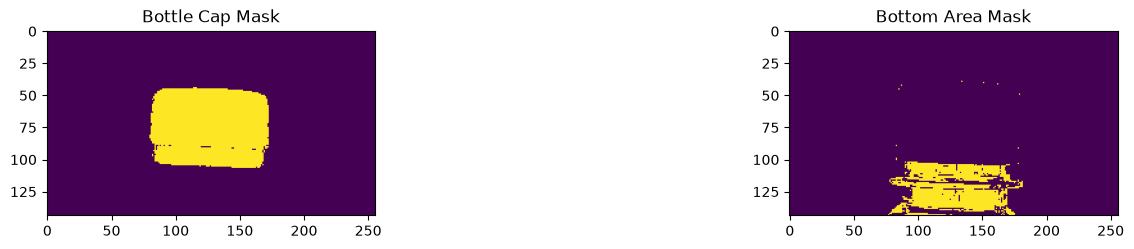

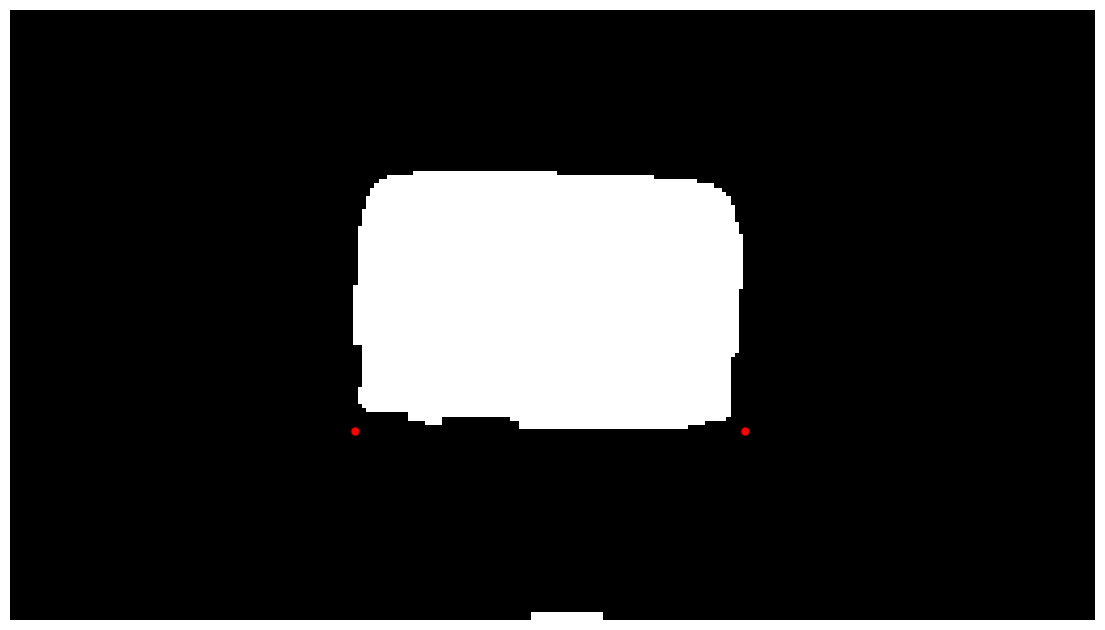

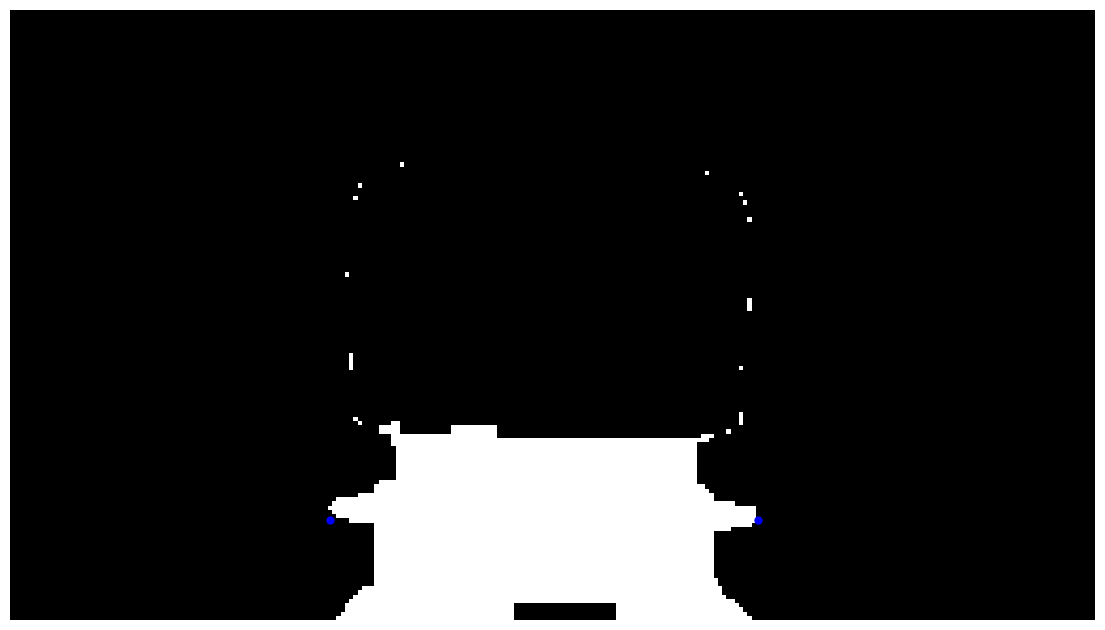

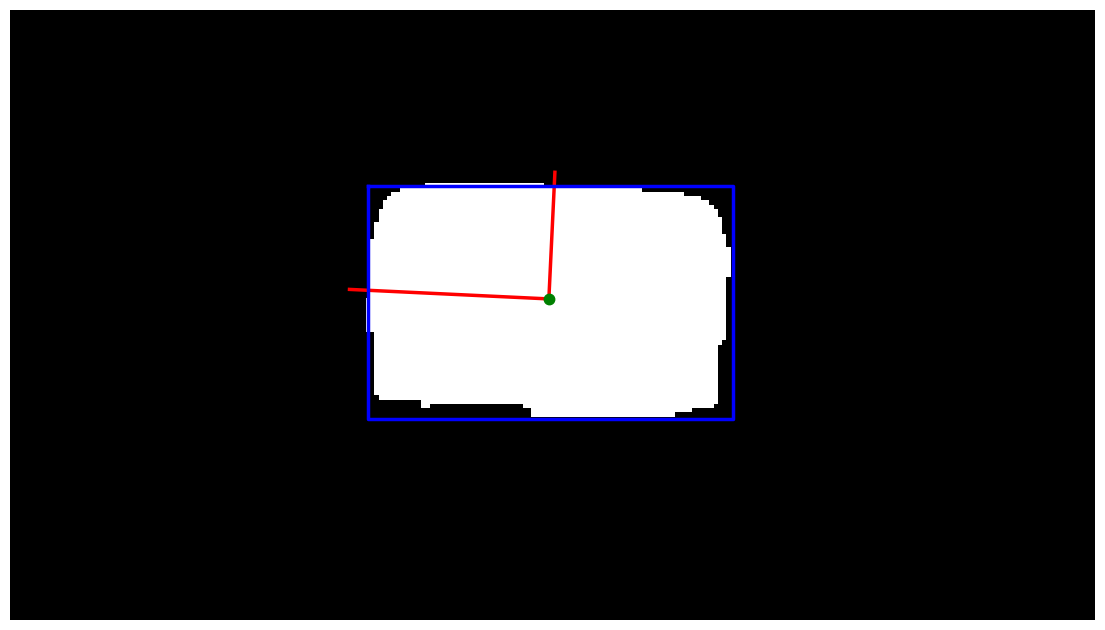

In [12]:
image = cv.imread(DATA_PATH + "/train/" + gc_df['filename'][12])
#image = improve_contrast(image, gamma=0.8)
    
bottlecap_hsv = cv.cvtColor(image, cv.COLOR_BGR2HSV)

cap_lower_bound = np.array([0, 0, 145])
cap_upper_bound = np.array([0, 0, 255])

bottlecap_mask = cv.inRange(bottlecap_hsv, cap_lower_bound, cap_upper_bound)

# Perform erosion to make the cap and ring more distinct with each other
kernel = np.ones((3,3),np.uint8)
bottlecap_np = np.asarray(bottlecap_mask,np.uint8)
bottlecap_erosion = cv.erode(bottlecap_np,kernel,iterations = 5)


img = cv.imread(DATA_PATH + "/train/" + lc_df['filename'][19])
#img = improve_contrast(img)
bottomarea_hsv = cv.cvtColor(img, cv.COLOR_BGR2HSV)

cap_lower_bound = np.array([0, 0, 67])
cap_upper_bound = np.array([0, 0, 112])

bottomarea_mask = cv.inRange(bottomarea_hsv, cap_lower_bound, cap_upper_bound)

# Perform erosion to make the cap and ring more distinct with each other
kernel = np.ones((7,7),np.uint8)
bottomarea_np = np.asarray(bottomarea_mask,np.uint8)

bottomarea_closing = cv.morphologyEx(bottomarea_np, cv.MORPH_CLOSE, kernel)

# Set the figure size to make the images larger
plt.figure(figsize=(15, 18))

# Good Cap
plt.subplot(8, 2, 1)
plt.imshow(bottlecap_mask)
plt.title('Bottle Cap Mask')

plt.subplot(8, 2, 2)
plt.imshow(bottomarea_mask)
plt.title('Bottom Area Mask')

plt.tight_layout()  # Optional, for better spacing
plt.show()

sample_test_lc = cv.imread(DATA_PATH + "/train/" + lc_df['filename'][9])
detected_lc_image, result = bottlecap_detection(sample_test_lc)

In [13]:
sample_test_bc = cv.imread(DATA_PATH + "/train/" + bc_df['filename'][0])
sample_test_lc = cv.imread(DATA_PATH + "/train/" + lc_df['filename'][7])

#image_show(sample_test_bc)
#image_show(sample_test_lc)
print(lc_df['filename'][7])

WIN_20220704_15_33_26_Pro_jpg.rf.205aab2e645669115de2b8aa41b6df0d.jpg


C:\Users\User\AppData\Local\Temp\ipykernel_21000\1986089268.py:2: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  fig, ax = plt.subplots(nrows=nrows, ncols=ncols, figsize=(14, 14))


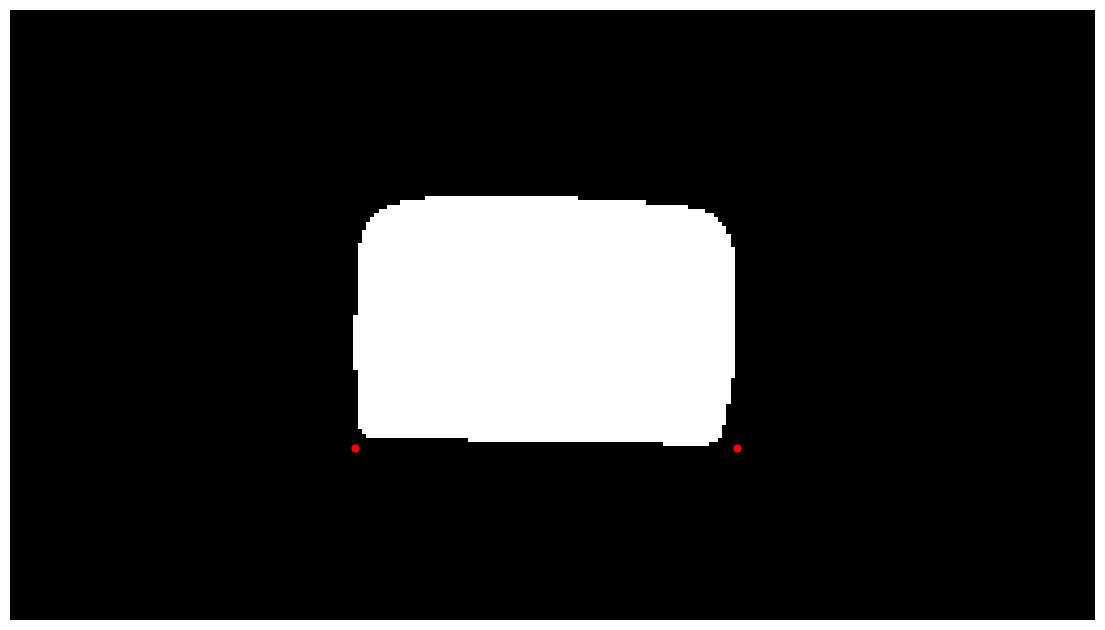

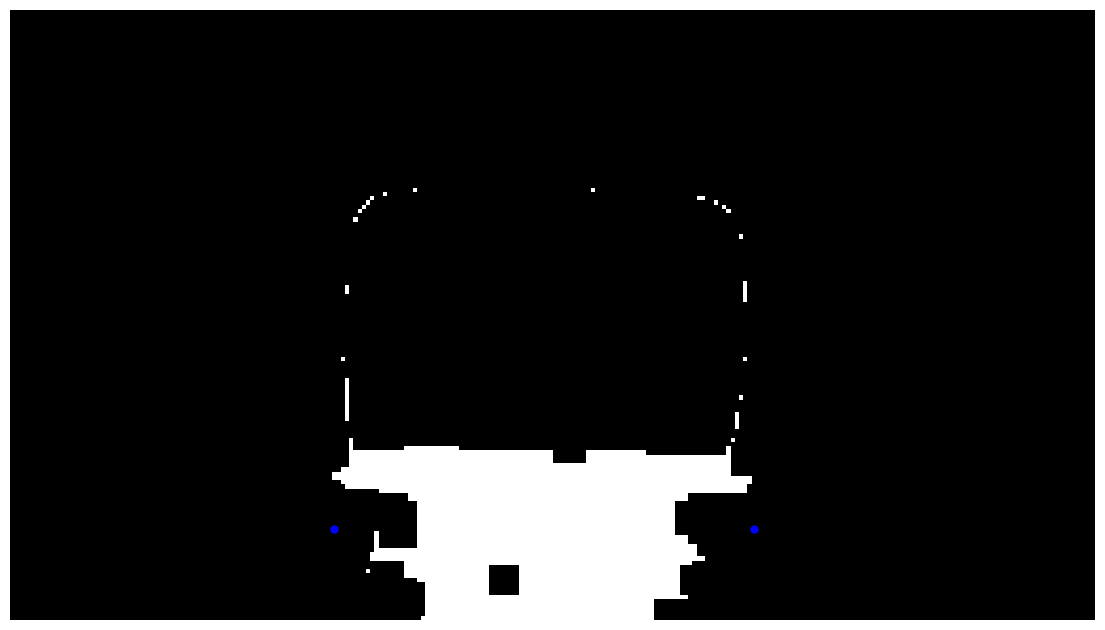

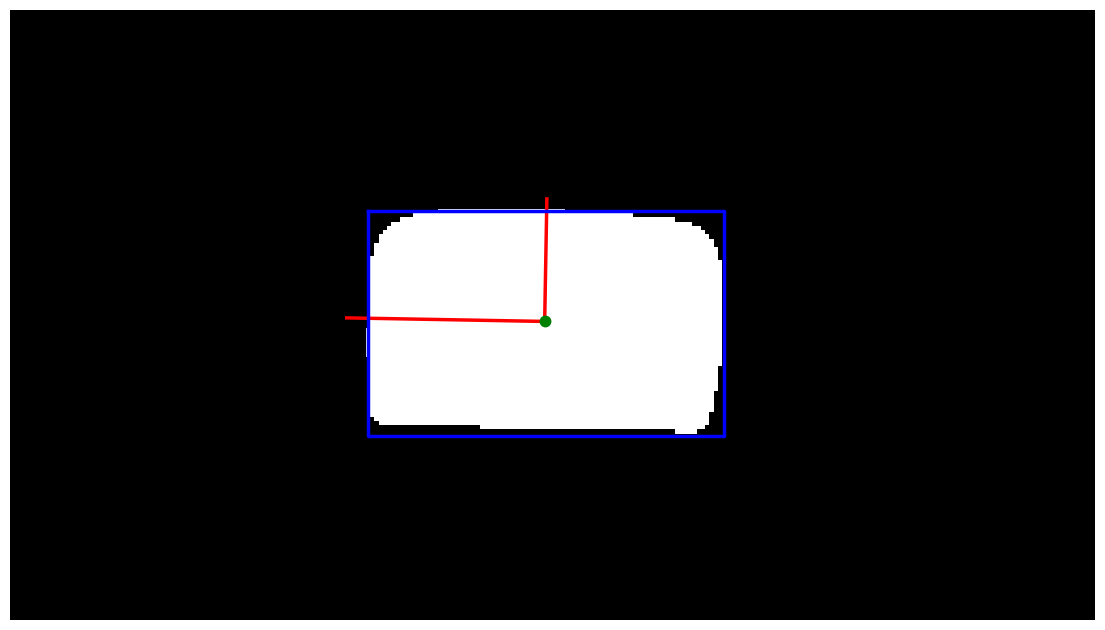

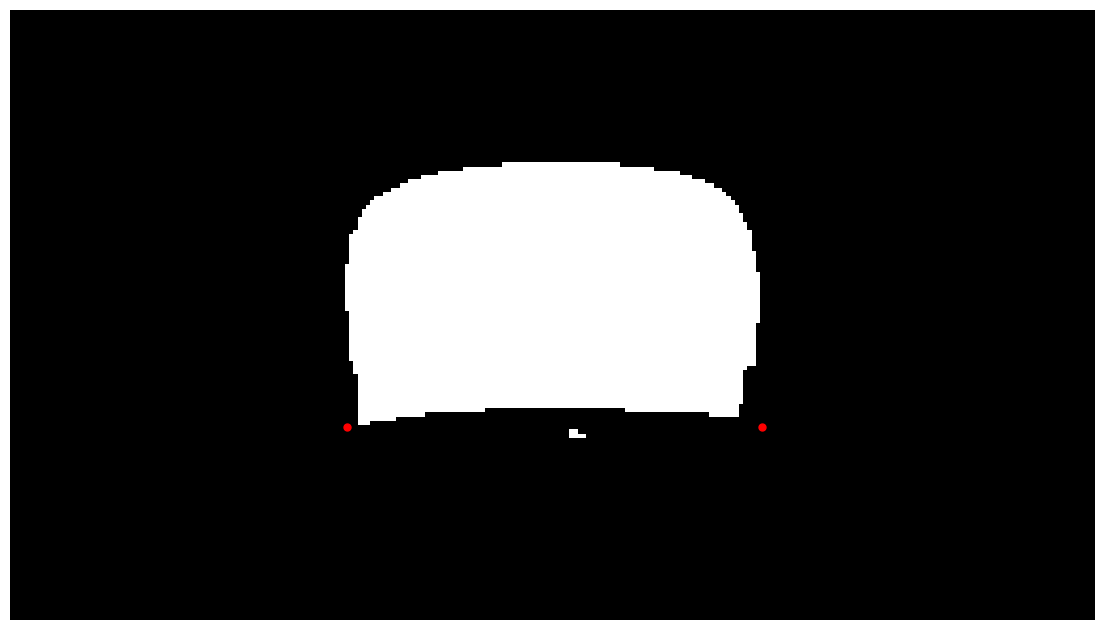

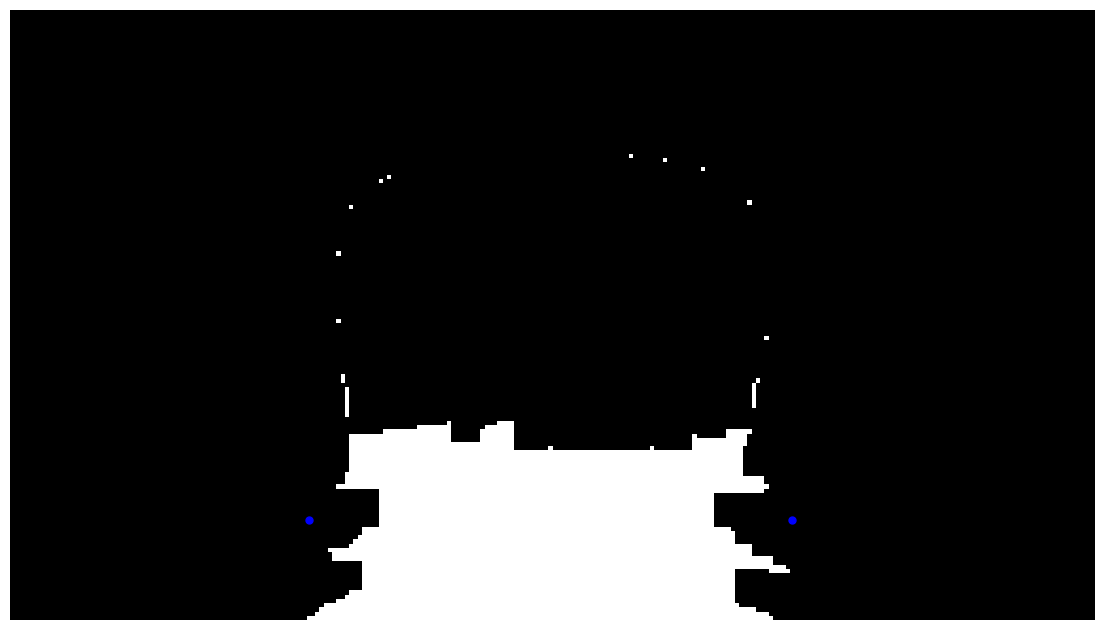

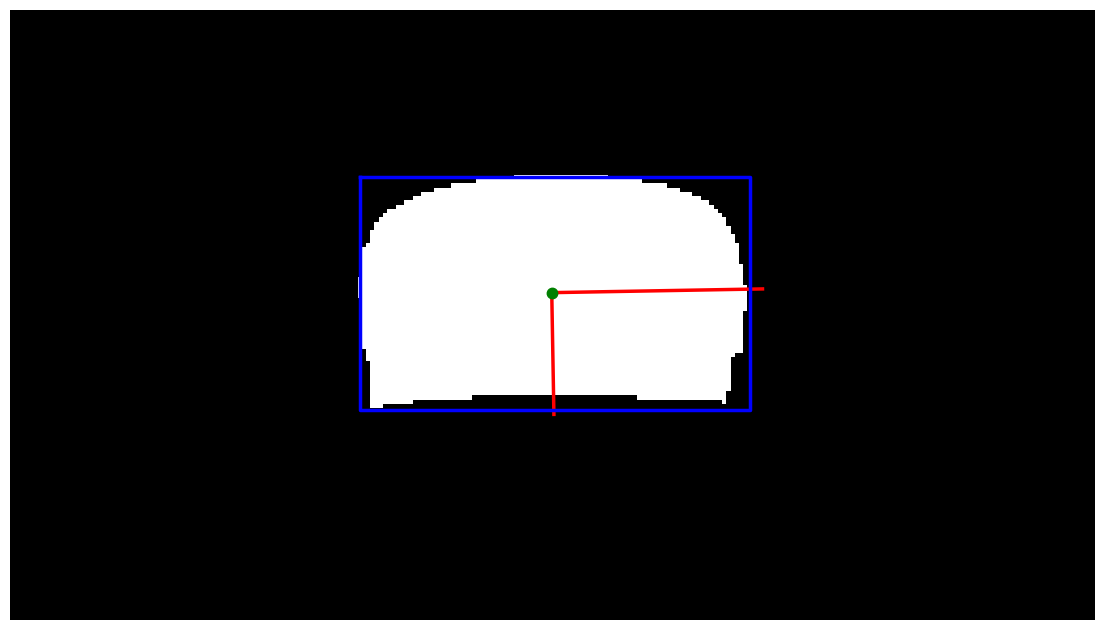

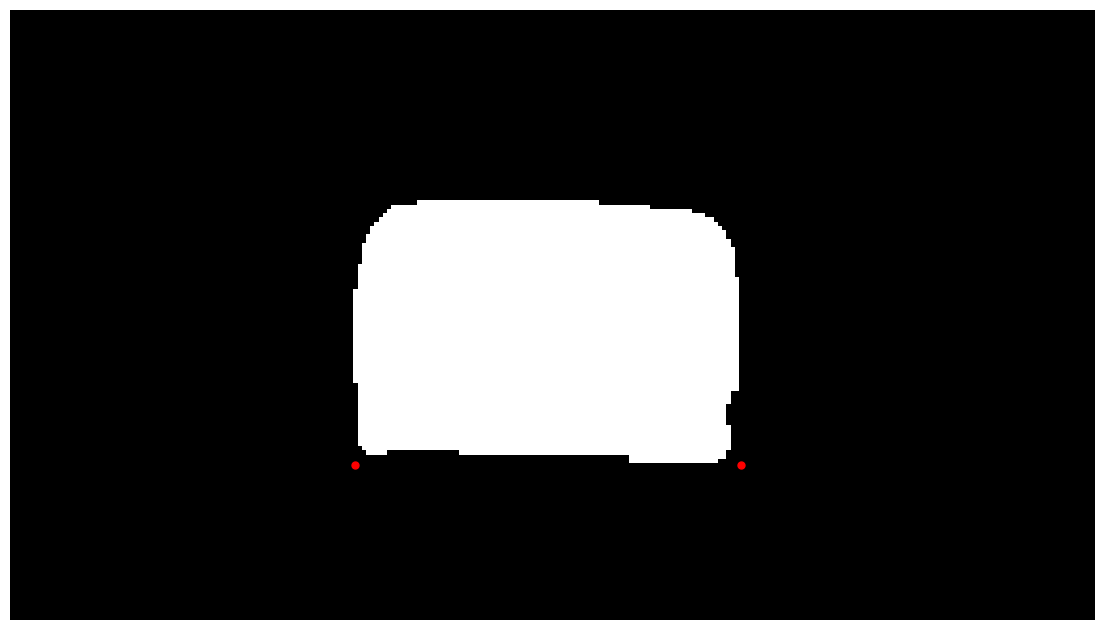

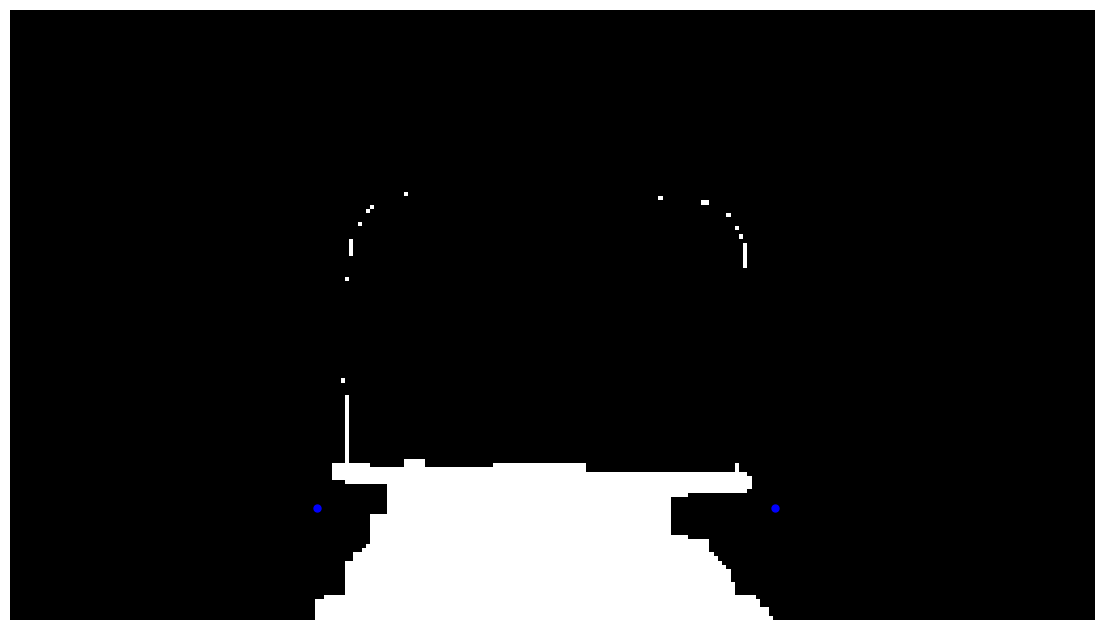

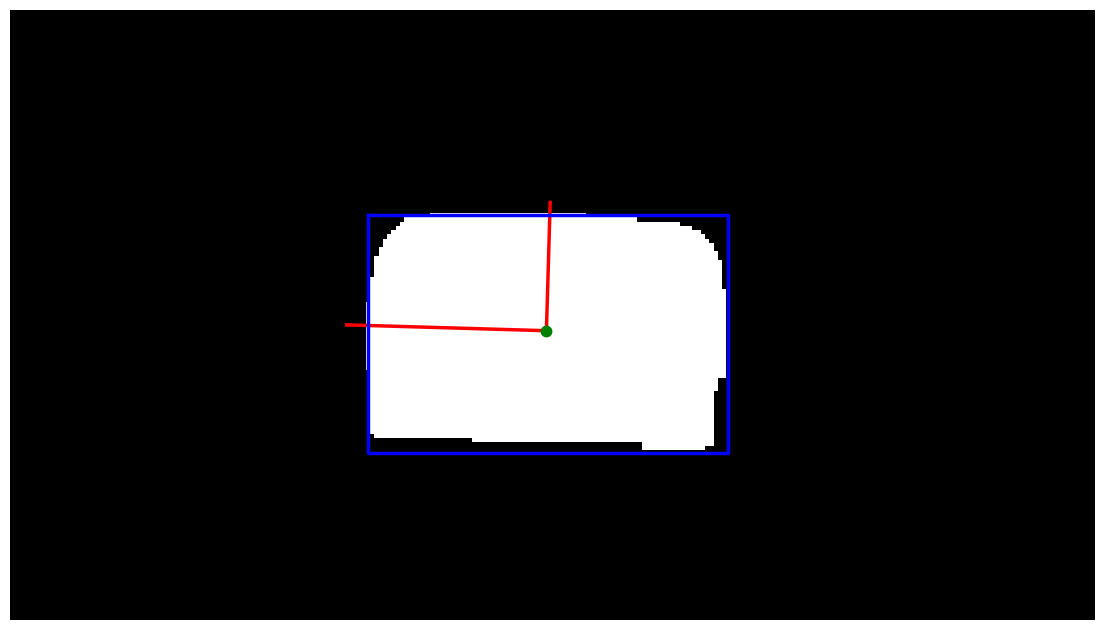

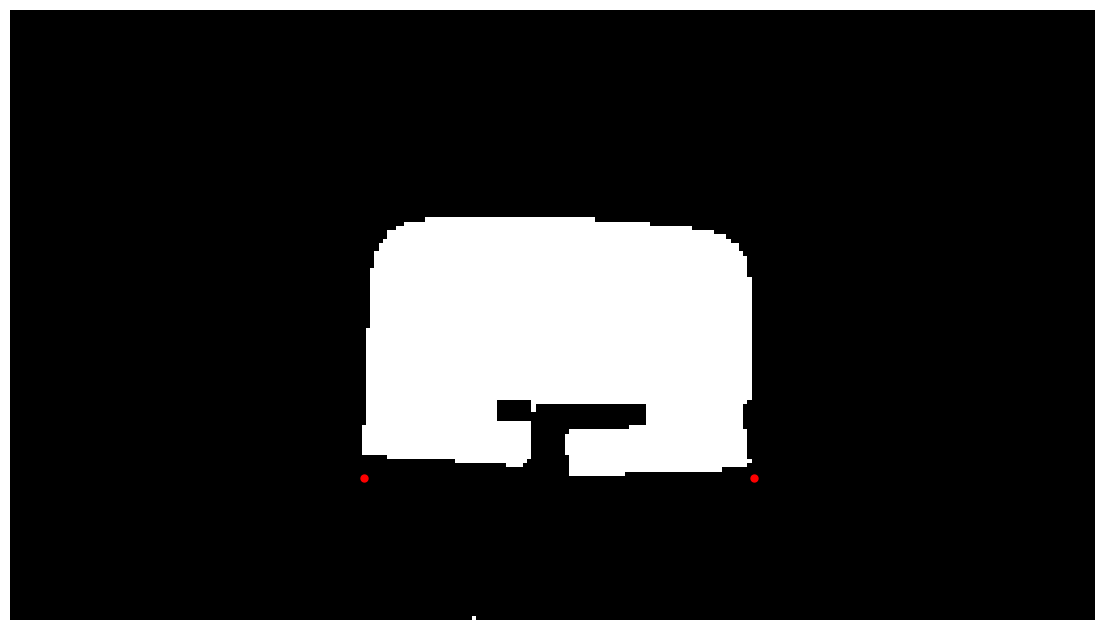

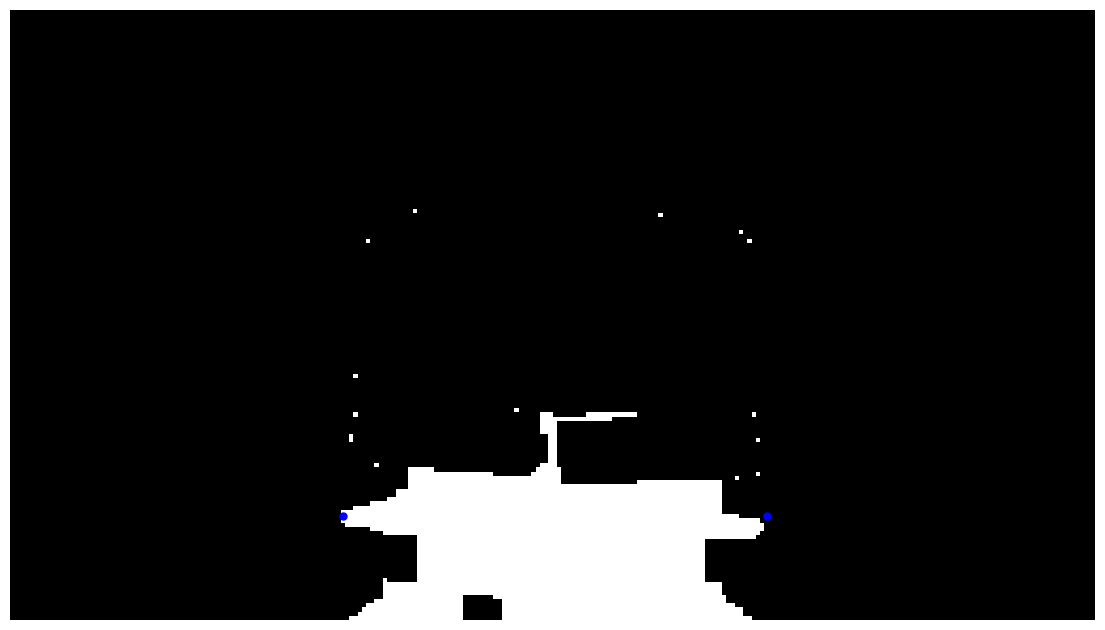

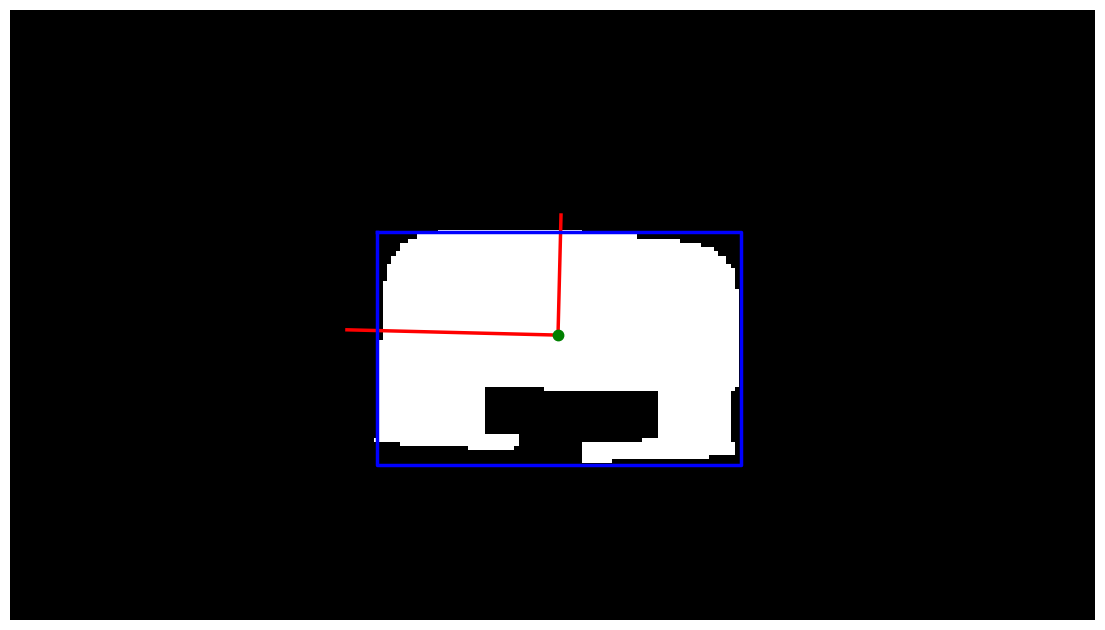

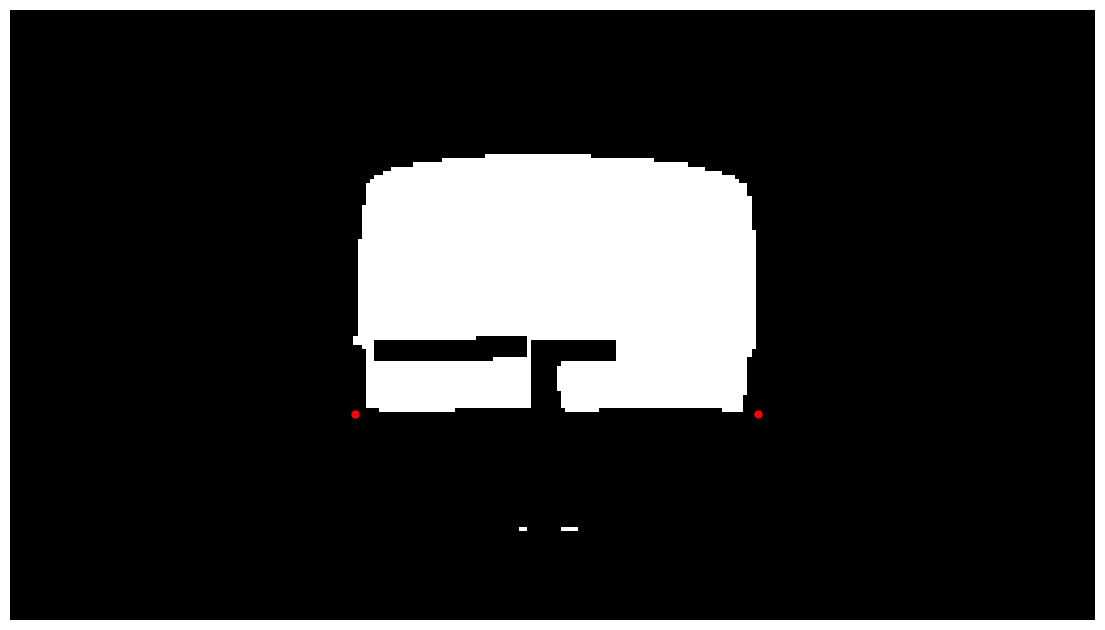

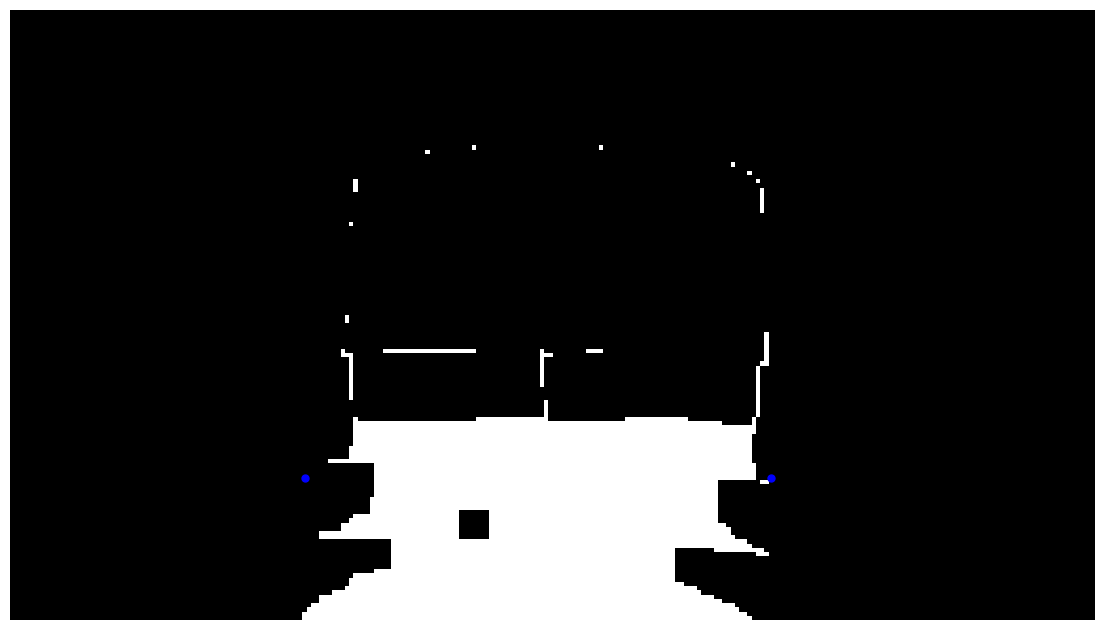

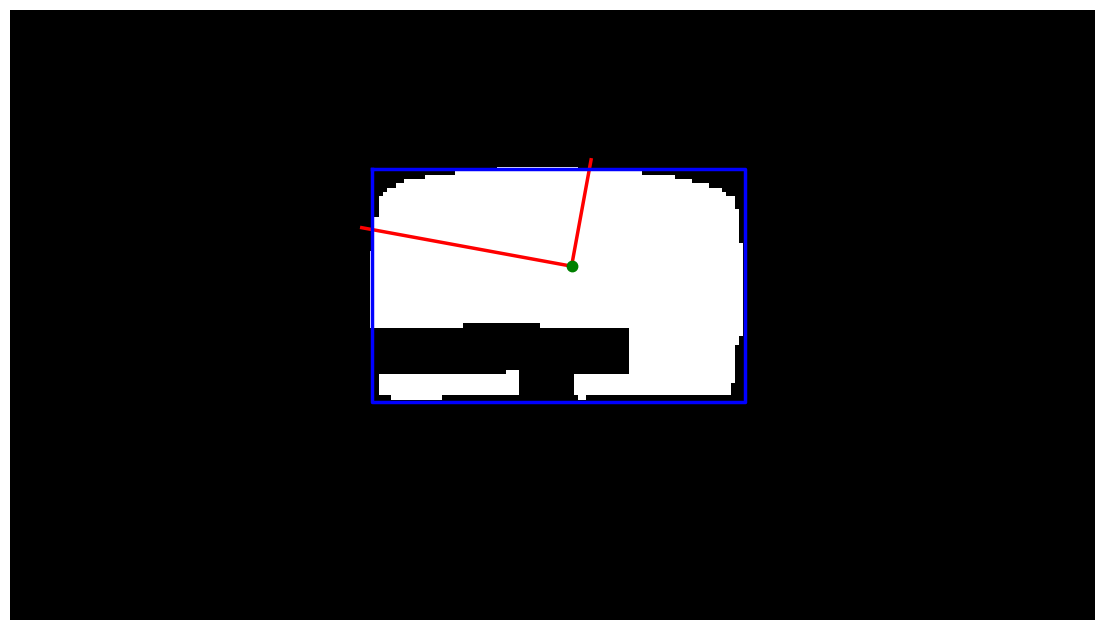

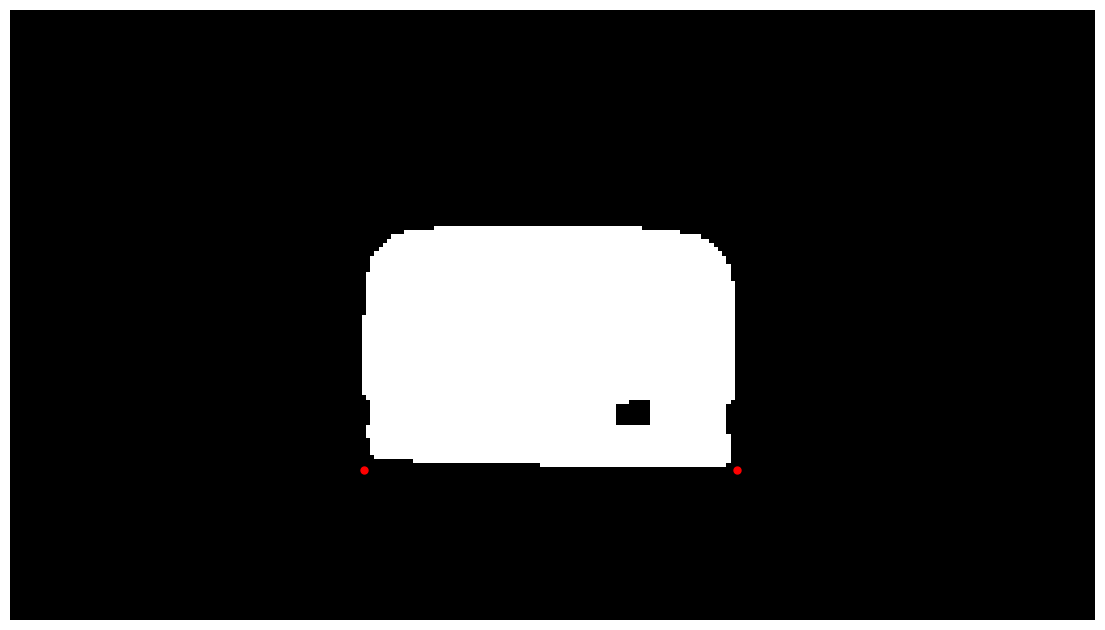

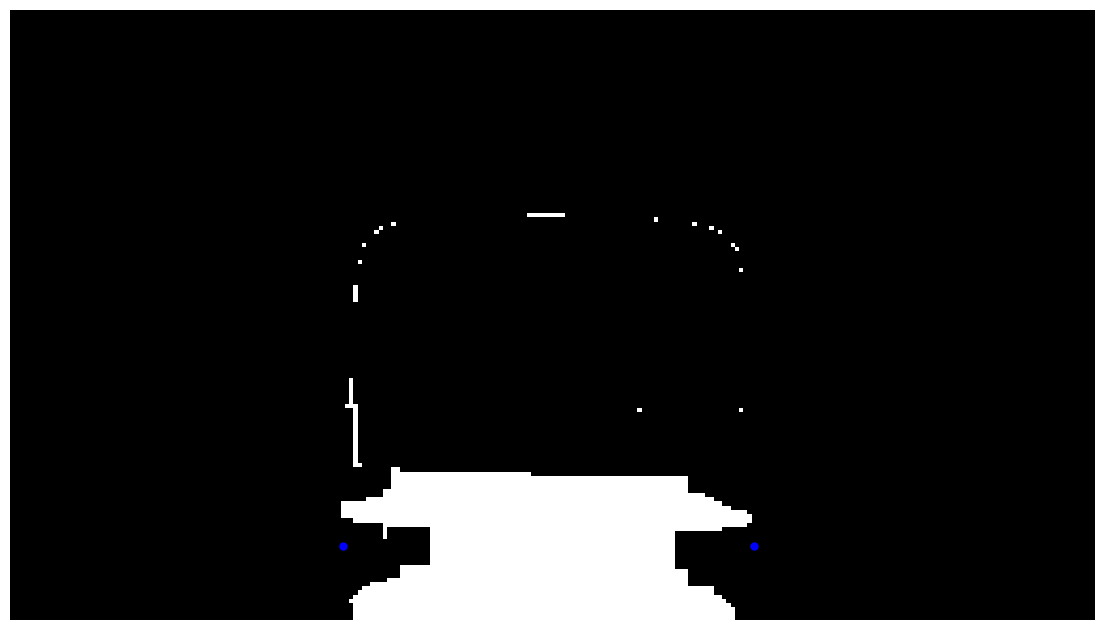

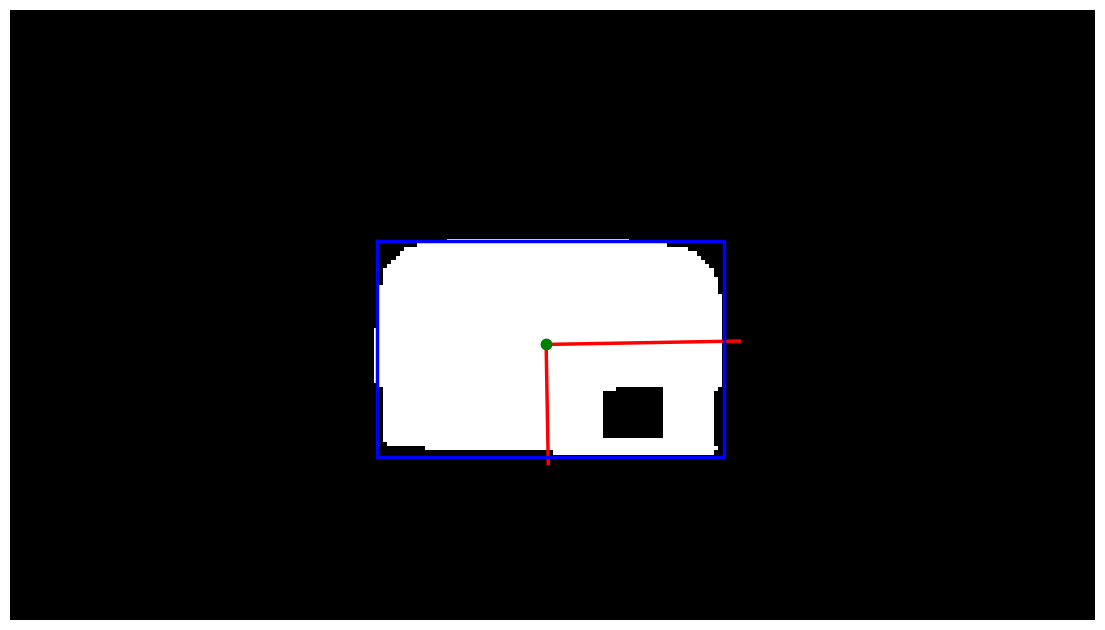

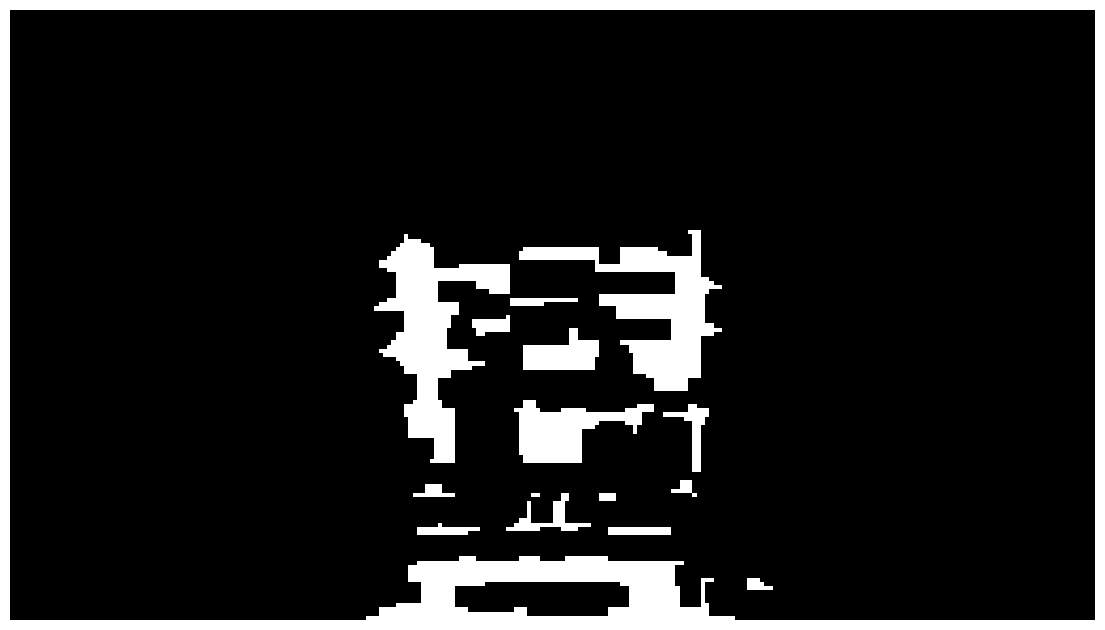

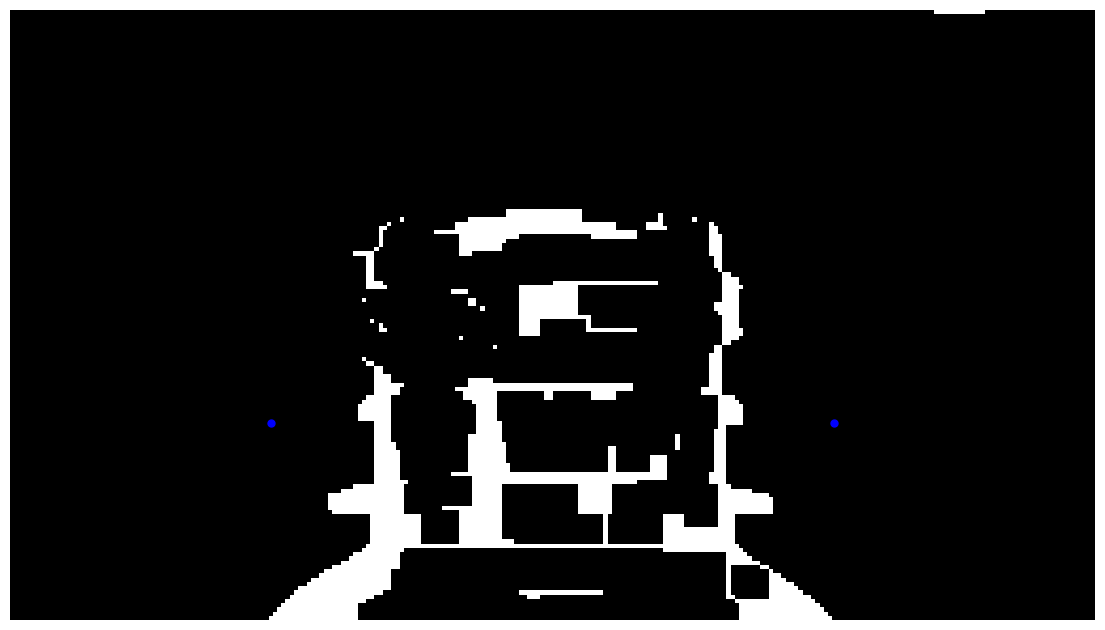

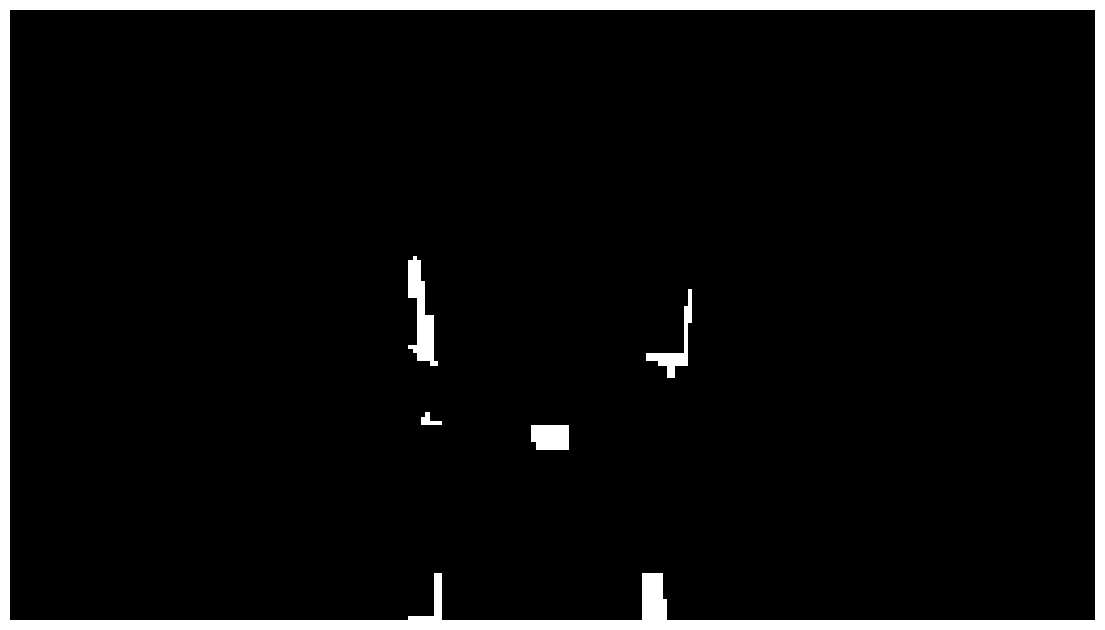

In [14]:
sample_test_gc = cv.imread(DATA_PATH + "/train/" + gc_df['filename'][7])
sample_test_bc = cv.imread(DATA_PATH + "/train/" + bc_df['filename'][16])
sample_test_bc2 = cv.imread(DATA_PATH + "/train/" + bc_df['filename'][19])
sample_test_br = cv.imread(DATA_PATH + "/train/" + br_df['filename'][24])
sample_test_br2 = cv.imread(DATA_PATH + "/train/" + br_df['filename'][9])
sample_test_lc = cv.imread(DATA_PATH + "/train/" + lc_df['filename'][7])
sample_test_nc = cv.imread(DATA_PATH + "/train/" + nc_df['filename'][4])

detected_gc_image, result = bottlecap_detection(sample_test_gc)
detected_bc_image, result = bottlecap_detection(sample_test_bc)
detected_bc2_image, result = bottlecap_detection(sample_test_bc2)
detected_br_image, result = bottlecap_detection(sample_test_br)
detected_br2_image, result = bottlecap_detection(sample_test_br2)
detected_lc_image, result = bottlecap_detection(sample_test_lc)
detected_nc_image, result = bottlecap_detection(sample_test_nc)


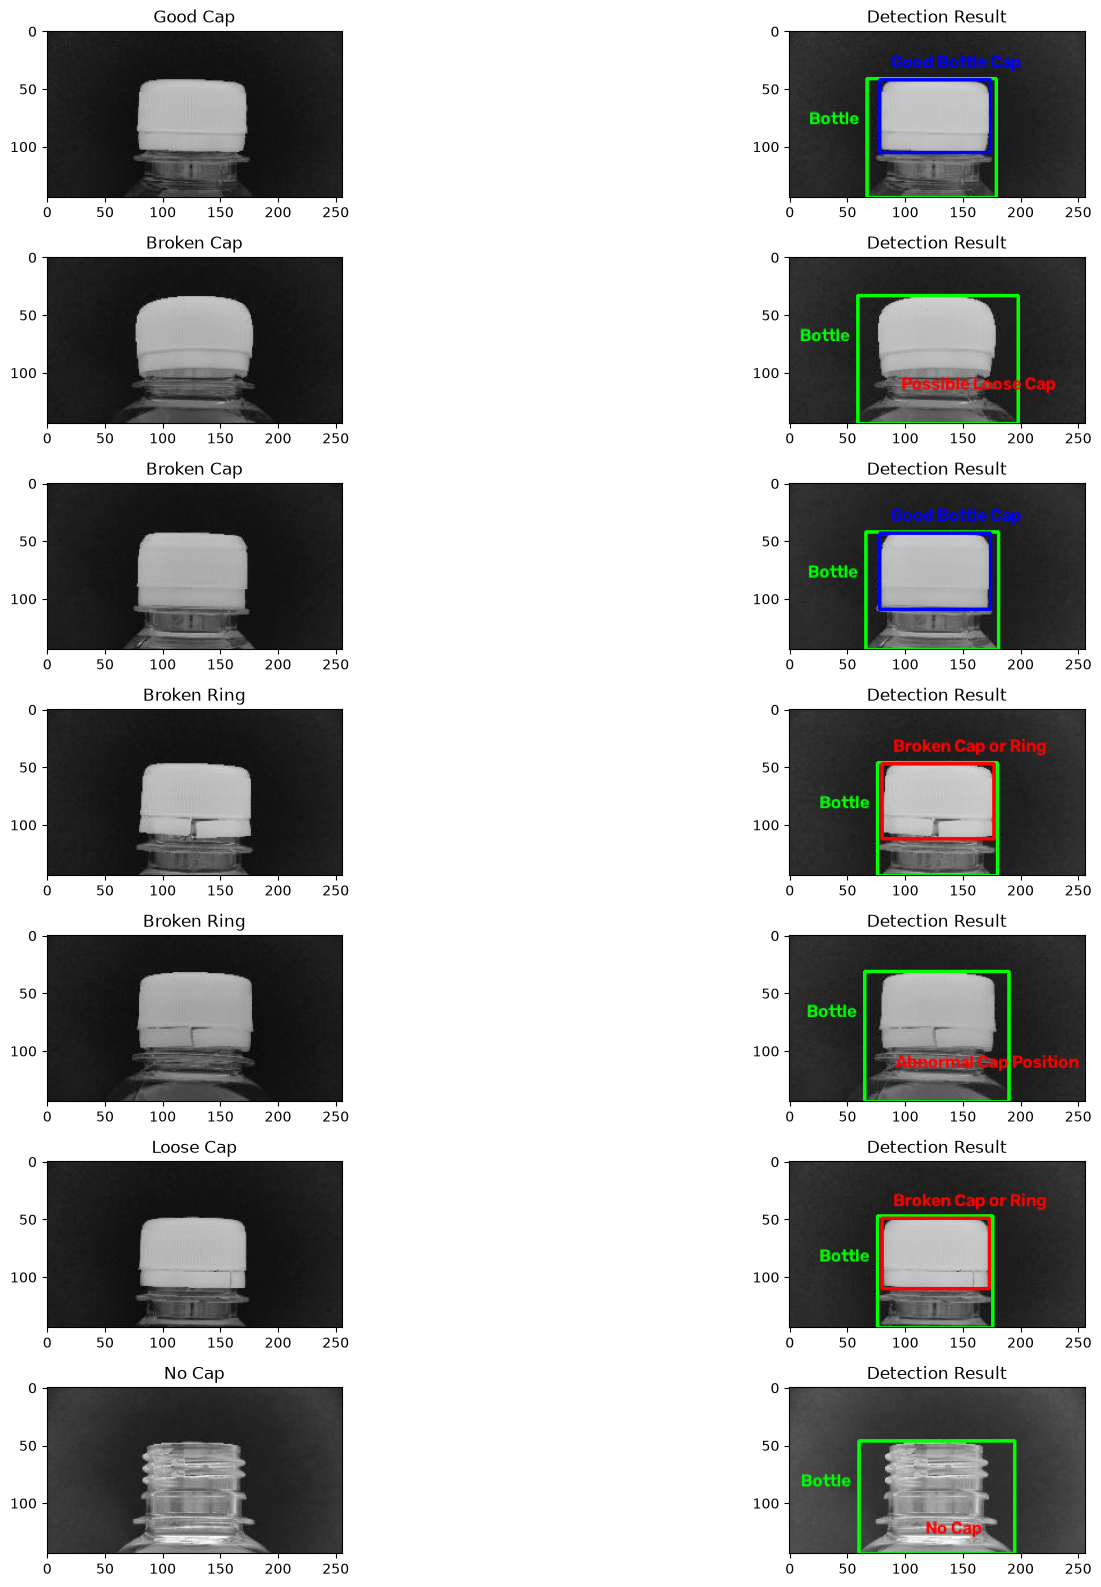

In [15]:
# Set the figure size to make the images larger
plt.figure(figsize=(15, 18))

# Good Cap
plt.subplot(8, 2, 1)
plt.imshow(sample_test_gc)
plt.title('Good Cap')

plt.subplot(8, 2, 2)
plt.imshow(detected_gc_image)
plt.title('Detection Result')

# Broken Cap
plt.subplot(8, 2, 3)
plt.imshow(sample_test_bc)
plt.title('Broken Cap')

plt.subplot(8, 2, 4)
plt.imshow(detected_bc_image)
plt.title('Detection Result')

# Another Broken Cap
plt.subplot(8, 2, 5)
plt.imshow(sample_test_bc2)
plt.title('Broken Cap')

plt.subplot(8, 2, 6)
plt.imshow(detected_bc2_image)
plt.title('Detection Result')

# Broken Ring
plt.subplot(8, 2, 7)
plt.imshow(sample_test_br)
plt.title('Broken Ring')

plt.subplot(8, 2, 8)
plt.imshow(detected_br_image)
plt.title('Detection Result')

# Another Broken Ring
plt.subplot(8, 2, 9)
plt.imshow(sample_test_br2)
plt.title('Broken Ring')

plt.subplot(8, 2, 10)
plt.imshow(detected_br2_image)
plt.title('Detection Result')

# Another Broken Ring
plt.subplot(8, 2, 11)
plt.imshow(sample_test_lc)
plt.title('Loose Cap')

plt.subplot(8, 2, 12)
plt.imshow(detected_lc_image)
plt.title('Detection Result')

# No Cap
plt.subplot(8, 2, 13)
plt.imshow(sample_test_nc)
plt.title('No Cap')

plt.subplot(8, 2, 14)
plt.imshow(detected_nc_image)
plt.title('Detection Result')

plt.tight_layout()  # Optional, for better spacing
plt.show()

(<Figure size 1400x1400 with 1 Axes>, <Axes: >)

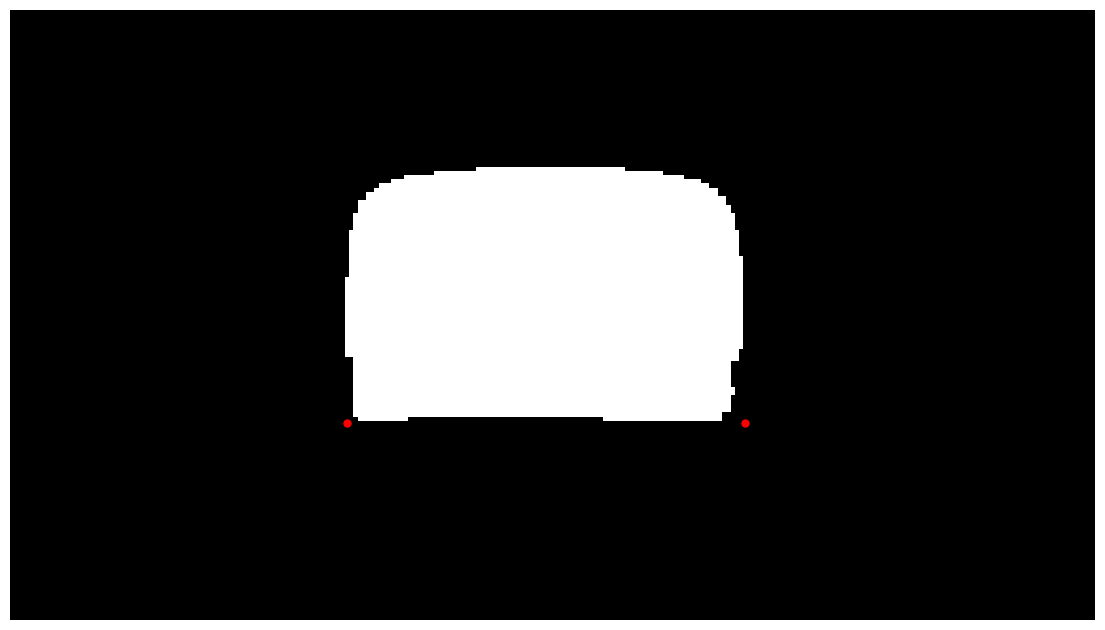

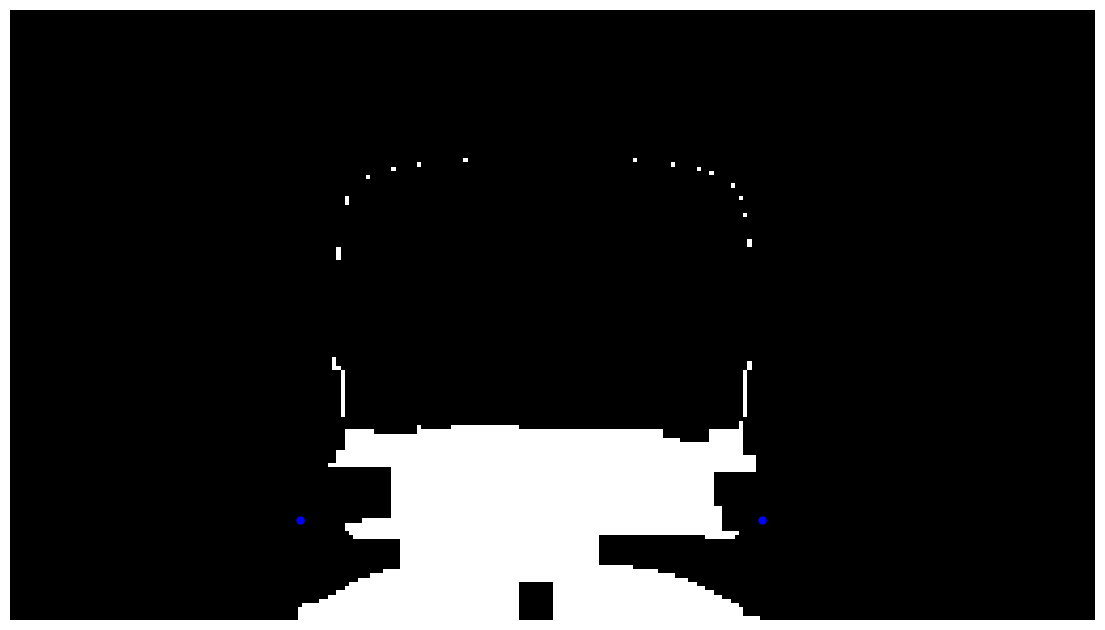

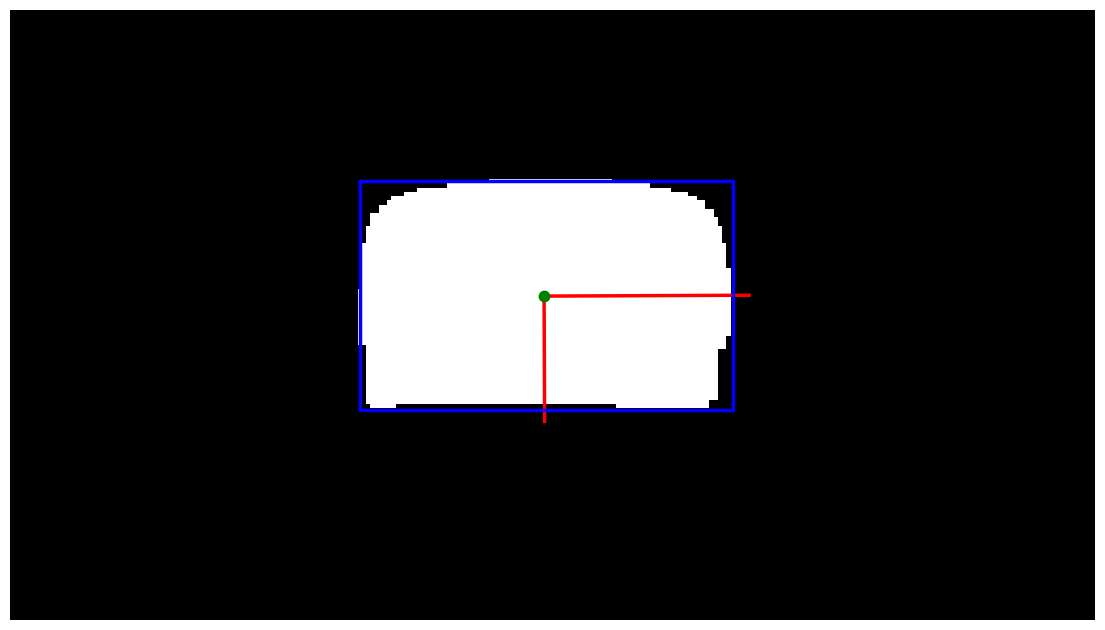

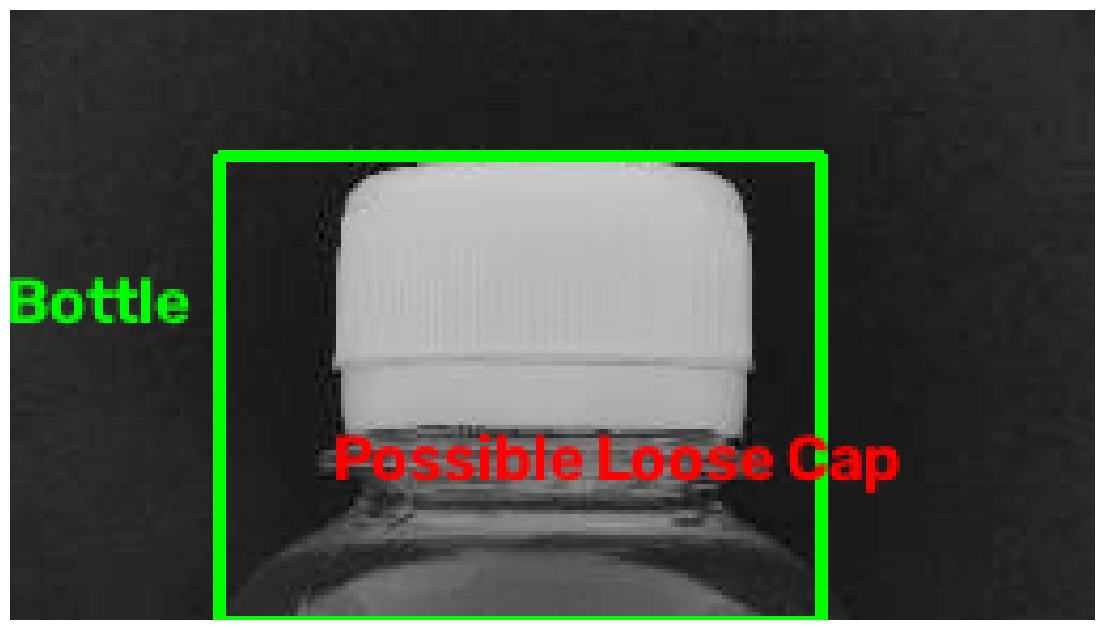

In [16]:
img = cv.imread(DATA_PATH + "/valid/" + valid_df['filename'][41])
detected_image, result = bottlecap_detection(img)
image_show(detected_image)

In [17]:
label_dict = {  'Good Cap': 0,
                'No Cap': 1,
                'Loose Cap': 2,
                'Broken Cap': 3,
                'Broken Ring': 3,
                'Broken Cap or Ring': 3,
                'Abnormal Cap Position': 3}

In [18]:
predictions = np.empty(test_df.shape[0], dtype = int)
trues = np.empty(test_df.shape[0], dtype = int)

Row:  0  Actual:  1  Predicted:  1
Row:  1  Actual:  0  Predicted:  2
Row:  2  Actual:  3  Predicted:  3
Row:  3  Actual:  0  Predicted:  0
Row:  4  Actual:  3  Predicted:  3
Row:  5  Actual:  1  Predicted:  1
Row:  6  Actual:  0  Predicted:  0
Row:  7  Actual:  3  Predicted:  3
Row:  8  Actual:  3  Predicted:  3
Row:  9  Actual:  2  Predicted:  3
Row:  10  Actual:  3  Predicted:  3


C:\Users\User\AppData\Local\Temp\ipykernel_21000\1986089268.py:2: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  fig, ax = plt.subplots(nrows=nrows, ncols=ncols, figsize=(14, 14))


Row:  11  Actual:  2  Predicted:  2
Row:  12  Actual:  3  Predicted:  3
Row:  13  Actual:  2  Predicted:  2
Row:  14  Actual:  0  Predicted:  0
Row:  15  Actual:  2  Predicted:  3
Row:  16  Actual:  2  Predicted:  3
Row:  17  Actual:  2  Predicted:  3
Row:  18  Actual:  2  Predicted:  2
Row:  19  Actual:  2  Predicted:  0
Row:  20  Actual:  2  Predicted:  3
Row:  21  Actual:  3  Predicted:  3


Row:  22  Actual:  1  Predicted:  1
Row:  23  Actual:  1  Predicted:  1
Row:  24  Actual:  2  Predicted:  2
Row:  25  Actual:  3  Predicted:  2
Row:  26  Actual:  0  Predicted:  0
Row:  27  Actual:  0  Predicted:  0
Row:  28  Actual:  3  Predicted:  2


Row:  29  Actual:  1  Predicted:  1
Row:  30  Actual:  3  Predicted:  0
Row:  31  Actual:  2  Predicted:  2
Row:  32  Actual:  0  Predicted:  0
Row:  33  Actual:  1  Predicted:  1
Row:  34  Actual:  2  Predicted:  2
Row:  35  Actual:  3  Predicted:  3
Row:  36  Actual:  1  Predicted:  1
Row:  37  Actual:  2  Predicted:  2
Row:  38  Actual:  3  Predicted:  3
Row:  39  Actual:  2  Predicted:  2
Row:  40  Actual:  2  Predicted:  0


Row:  41  Actual:  0  Predicted:  0
Row:  42  Actual:  0  Predicted:  3
Row:  43  Actual:  3  Predicted:  3
Row:  44  Actual:  3  Predicted:  2
Row:  45  Actual:  2  Predicted:  3
Row:  46  Actual:  0  Predicted:  0
Row:  47  Actual:  1  Predicted:  1
Row:  48  Actual:  2  Predicted:  3
Row:  49  Actual:  3  Predicted:  3
Row:  50  Actual:  0  Predicted:  0
Row:  51  Actual:  0  Predicted:  0


... (4 outputs left out)

Row:  94  Actual:  0  Predicted:  0
Row:  95  Actual:  2  Predicted:  2
Row:  96  Actual:  2  Predicted:  3
Row:  97  Actual:  3  Predicted:  3
Row:  98  Actual:  3  Predicted:  3
Row:  99  Actual:  2  Predicted:  2
Row:  100  Actual:  3  Predicted:  3
Row:  101  Actual:  2  Predicted:  3
Row:  102  Actual:  2  Predicted:  2
Row:  103  Actual:  2  Predicted:  2


Row:  104  Actual:  3  Predicted:  2
Row:  105  Actual:  2  Predicted:  3
Row:  106  Actual:  3  Predicted:  3
Row:  107  Actual:  3  Predicted:  3
Row:  108  Actual:  3  Predicted:  3
Row:  109  Actual:  3  Predicted:  2
Row:  110  Actual:  3  Predicted:  3
Row:  111  Actual:  2  Predicted:  2
Row:  112  Actual:  1  Predicted:  1
Row:  113  Actual:  2  Predicted:  0
Row:  114  Actual:  0  Predicted:  2
Row:  115  Actual:  0  Predicted:  0


Row:  116  Actual:  2  Predicted:  2
Row:  117  Actual:  2  Predicted:  2
Row:  118  Actual:  2  Predicted:  2


Row:  119  Actual:  1  Predicted:  1
Row:  120  Actual:  0  Predicted:  2
Row:  121  Actual:  3  Predicted:  3
Row:  122  Actual:  2  Predicted:  3
Row:  123  Actual:  0  Predicted:  0


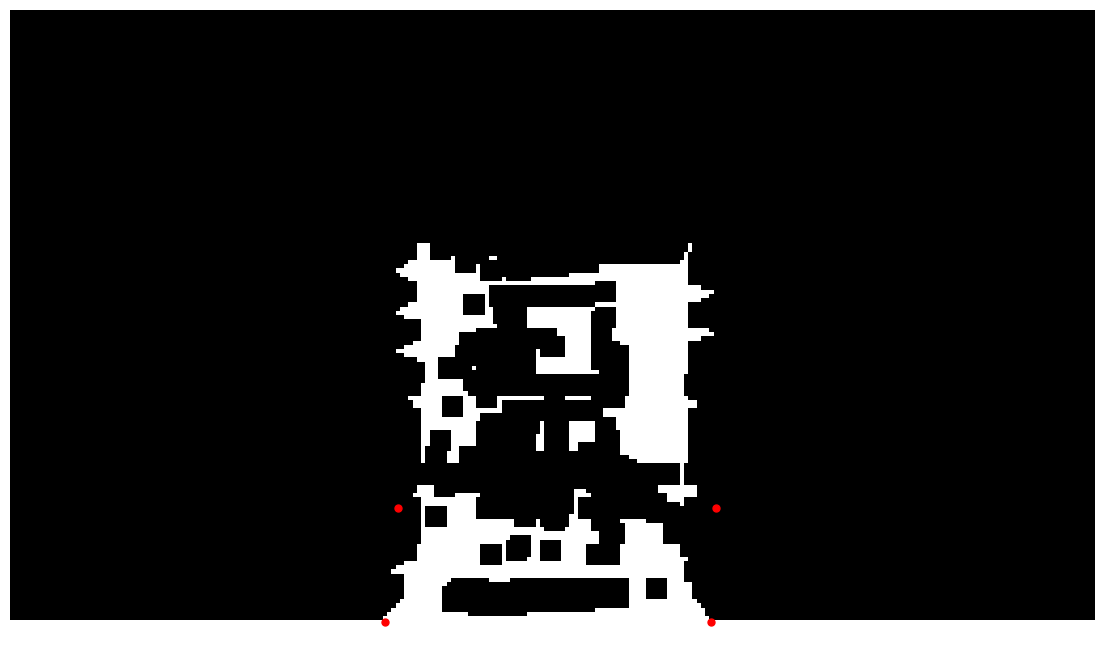

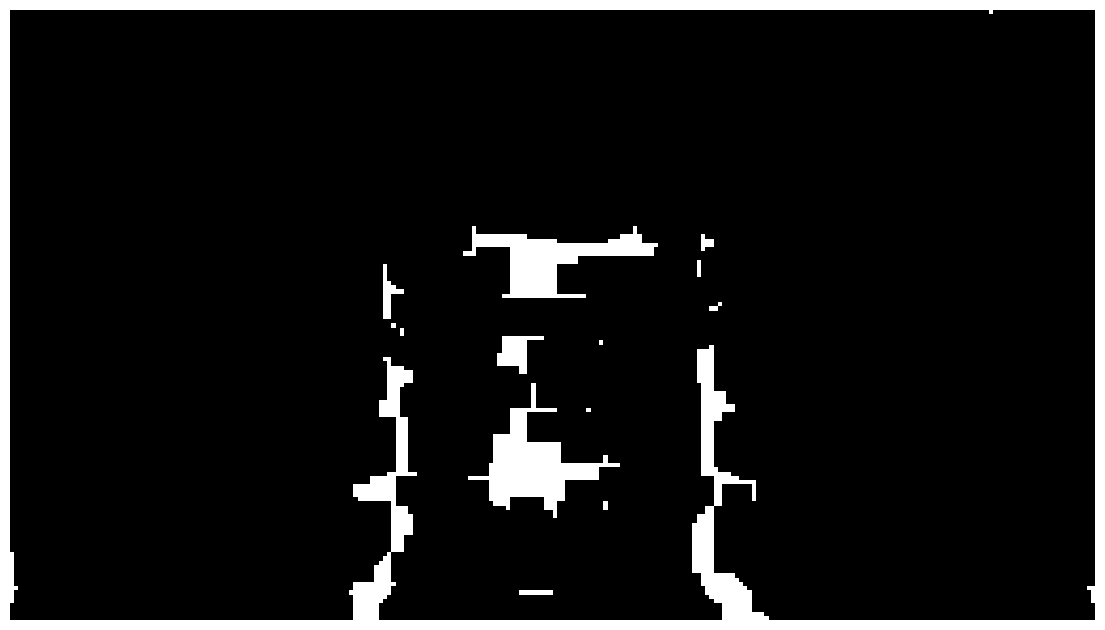

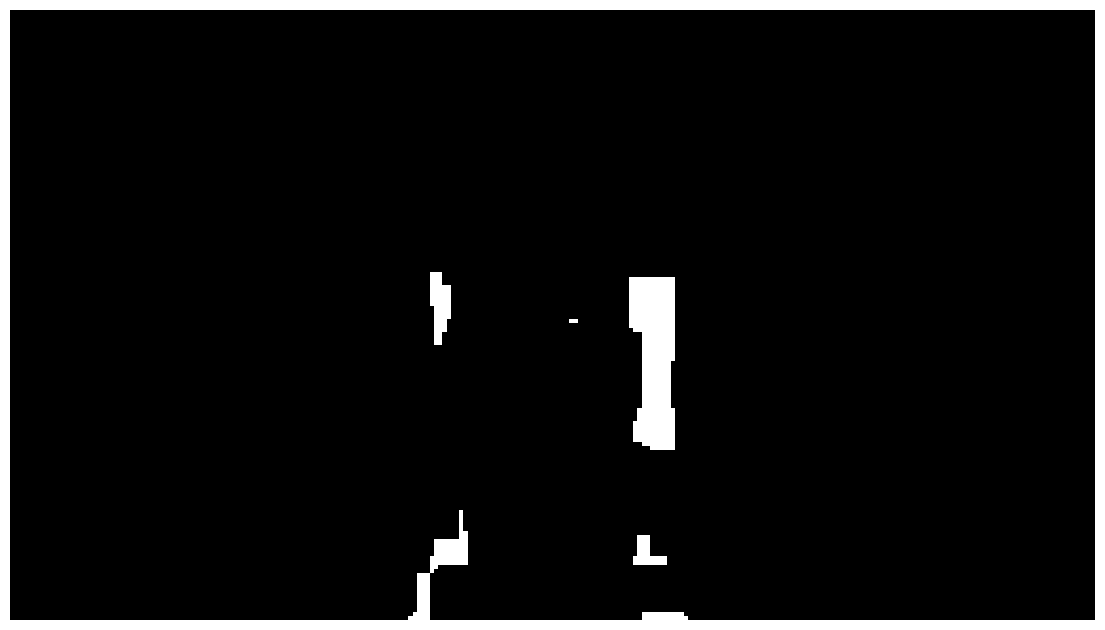

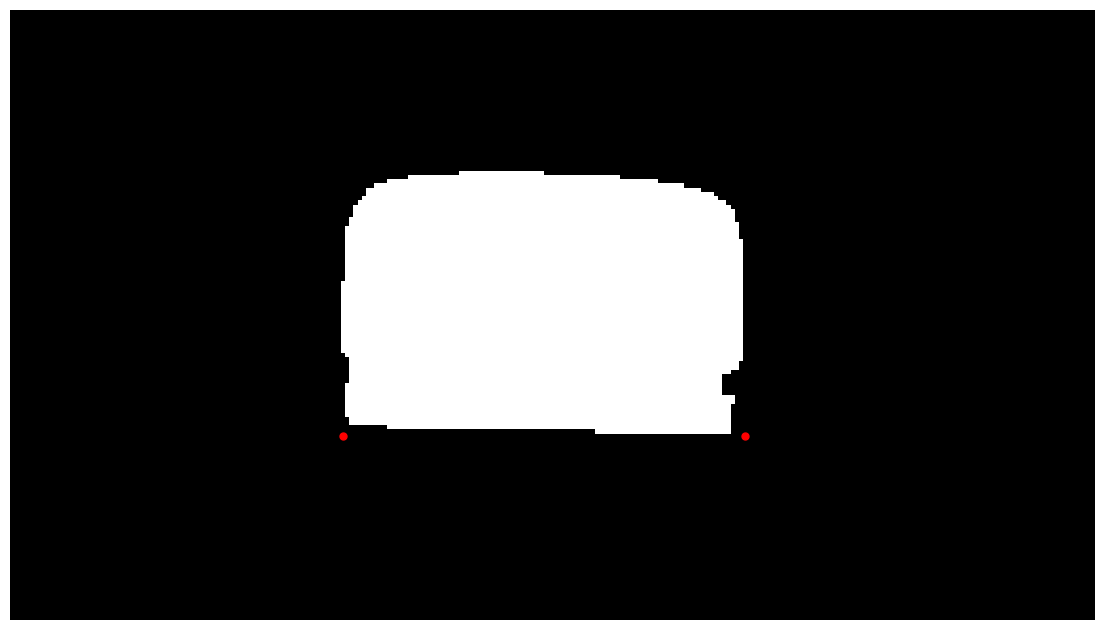

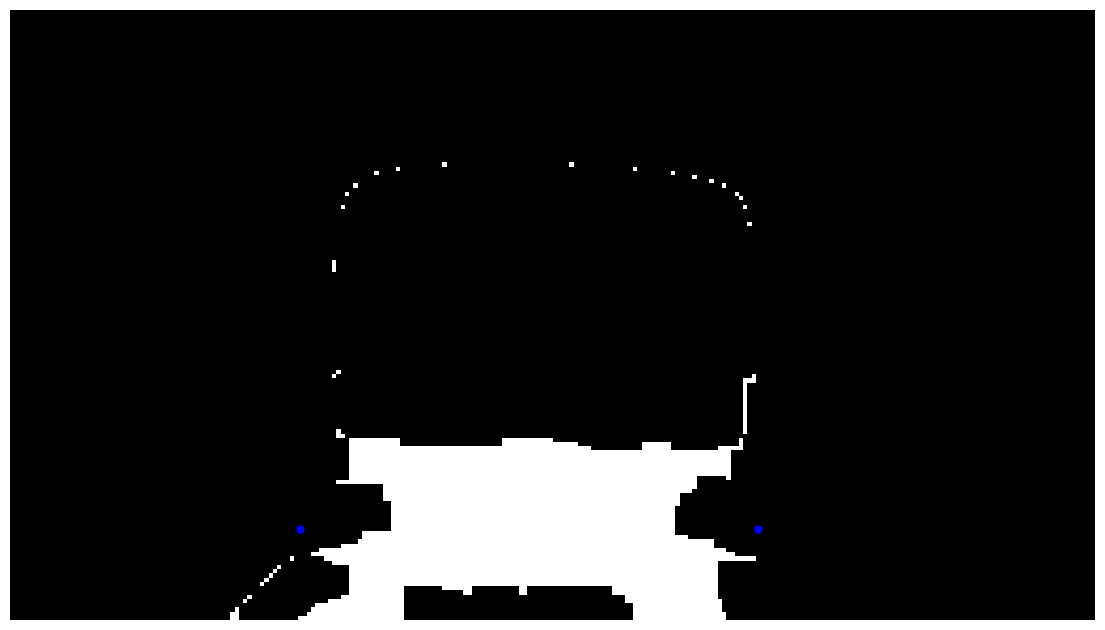

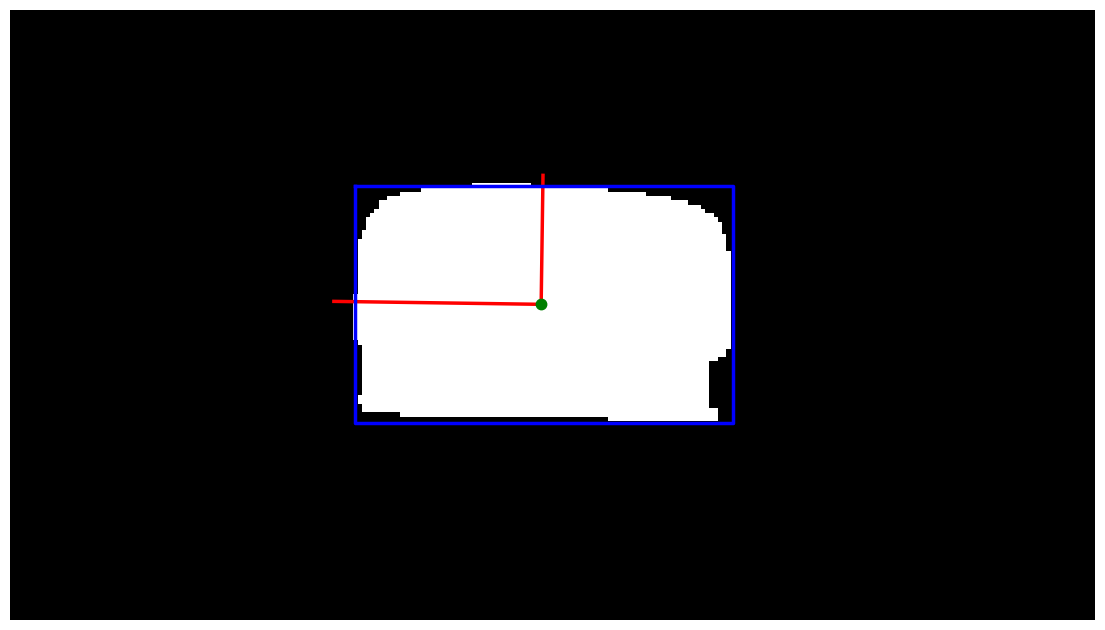

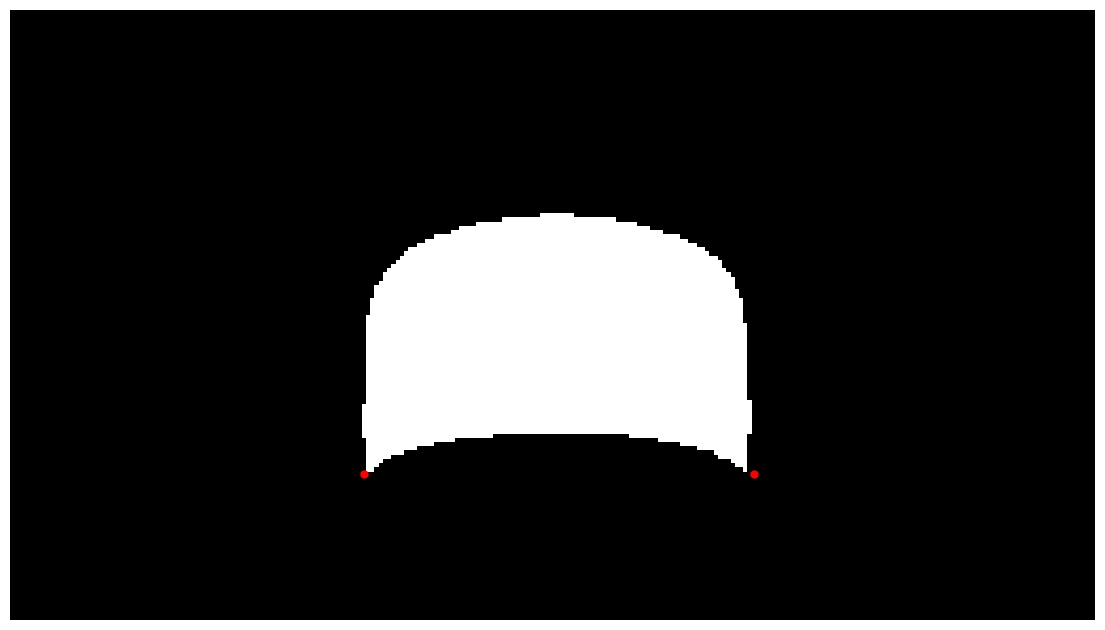

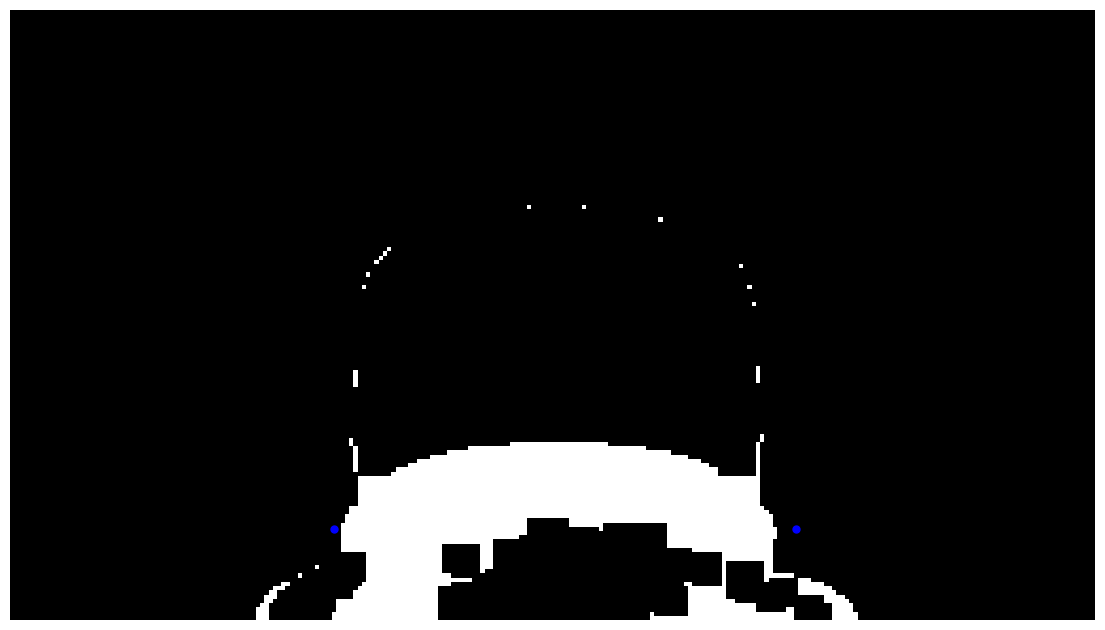

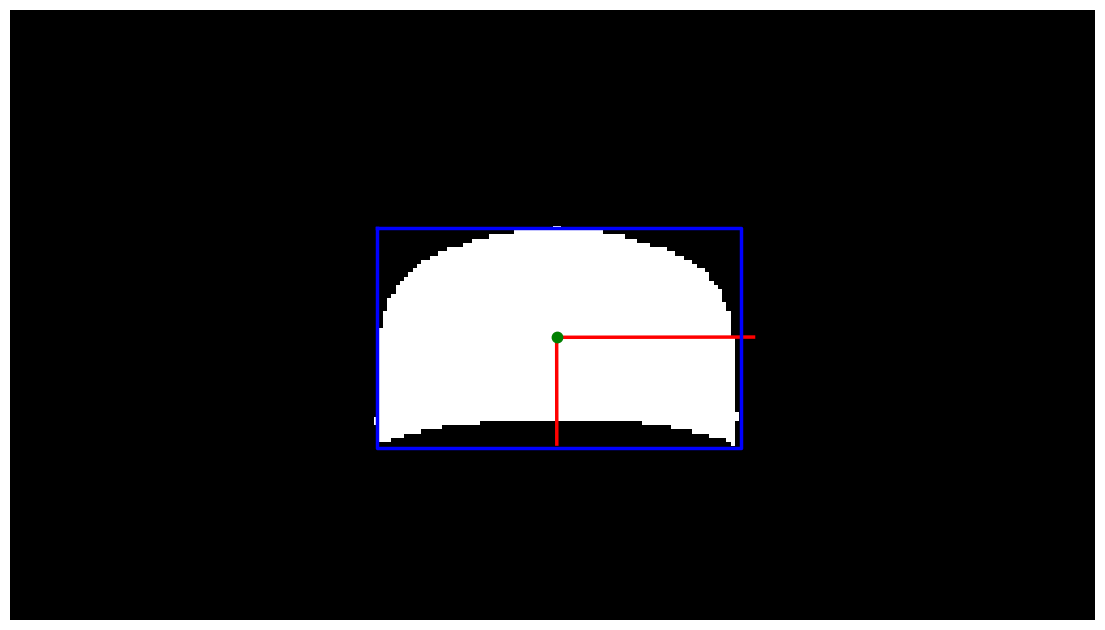

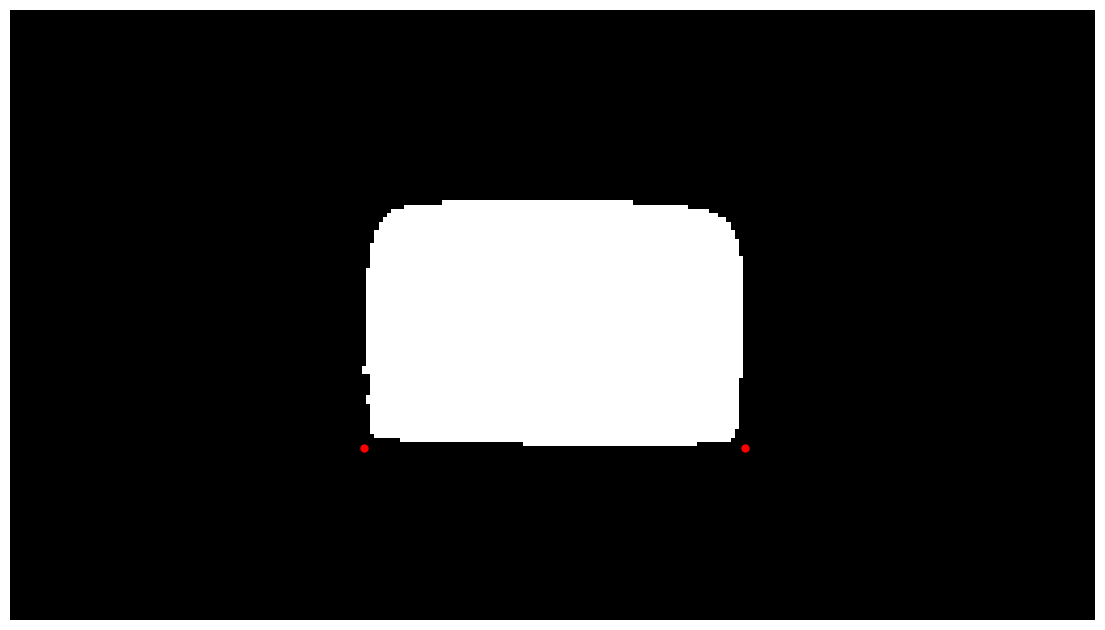

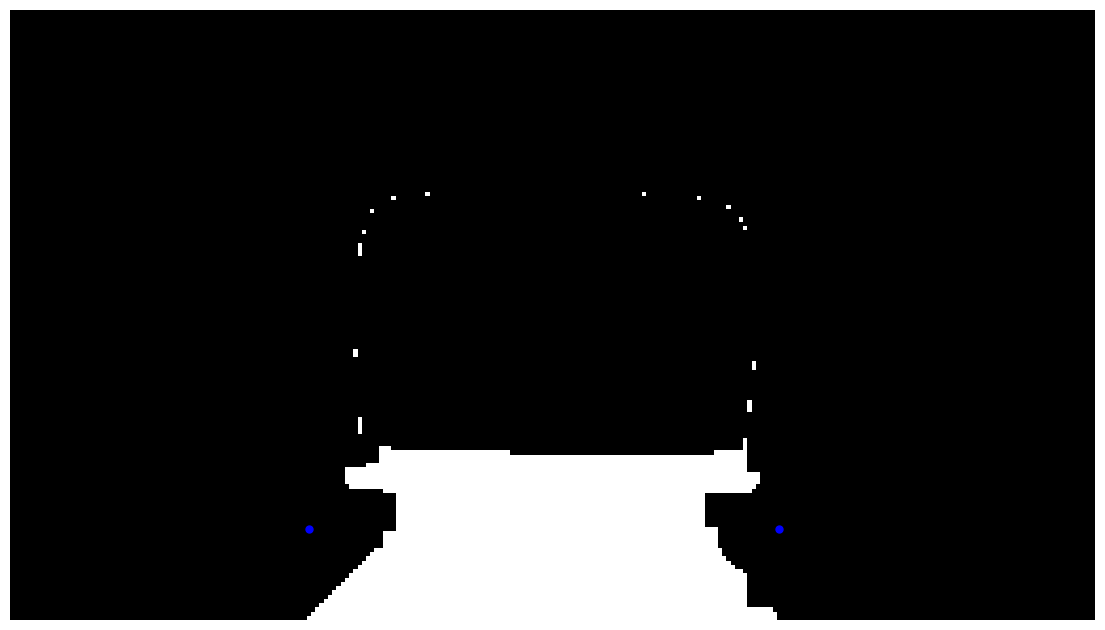

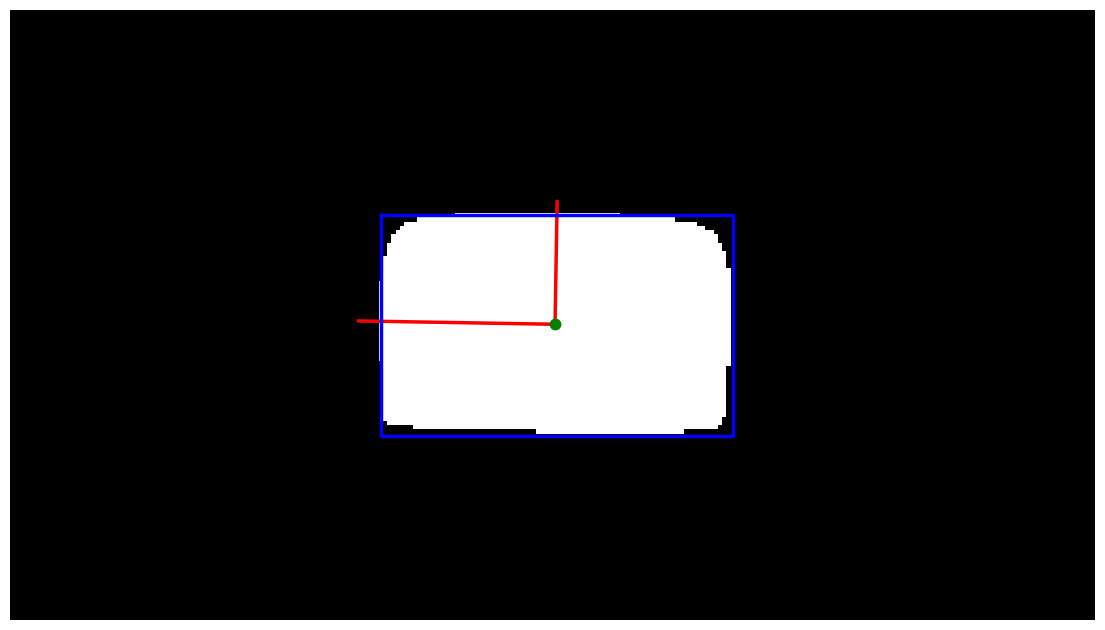

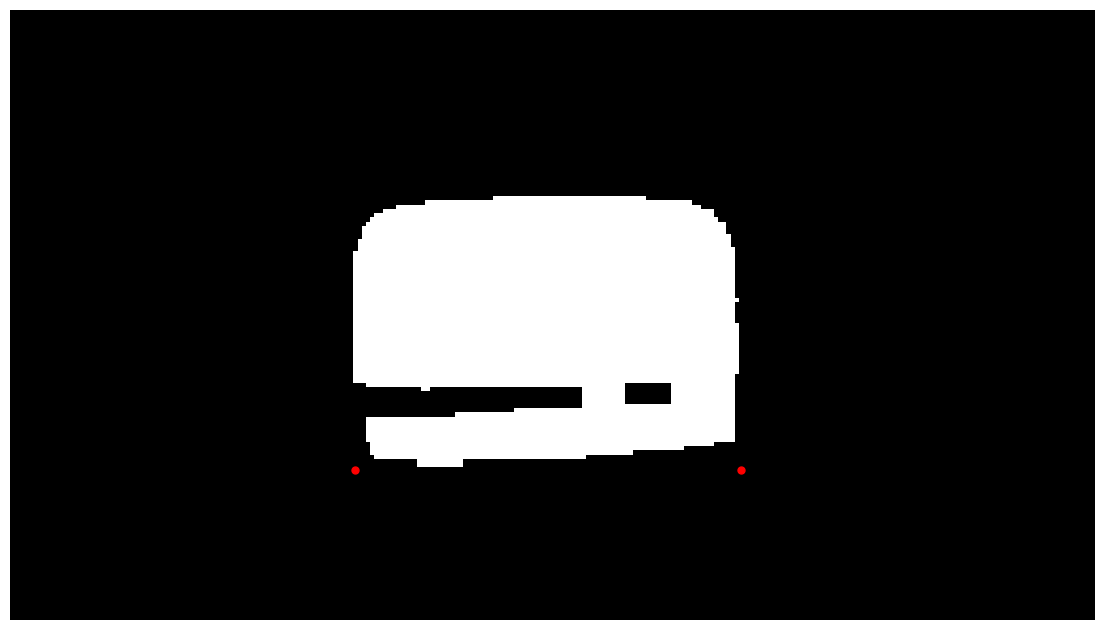

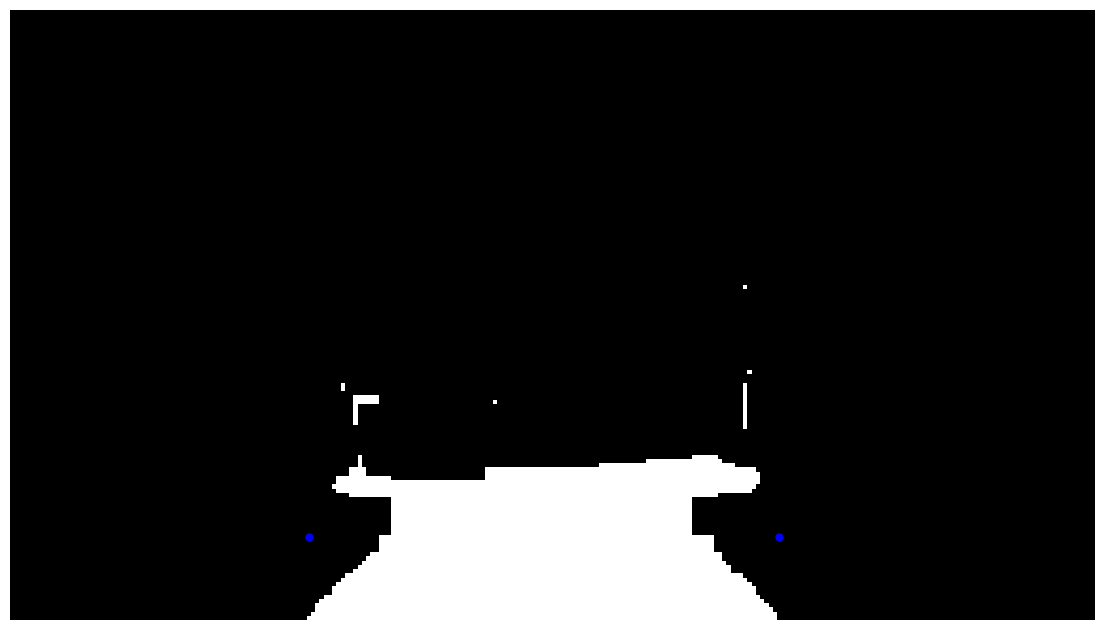

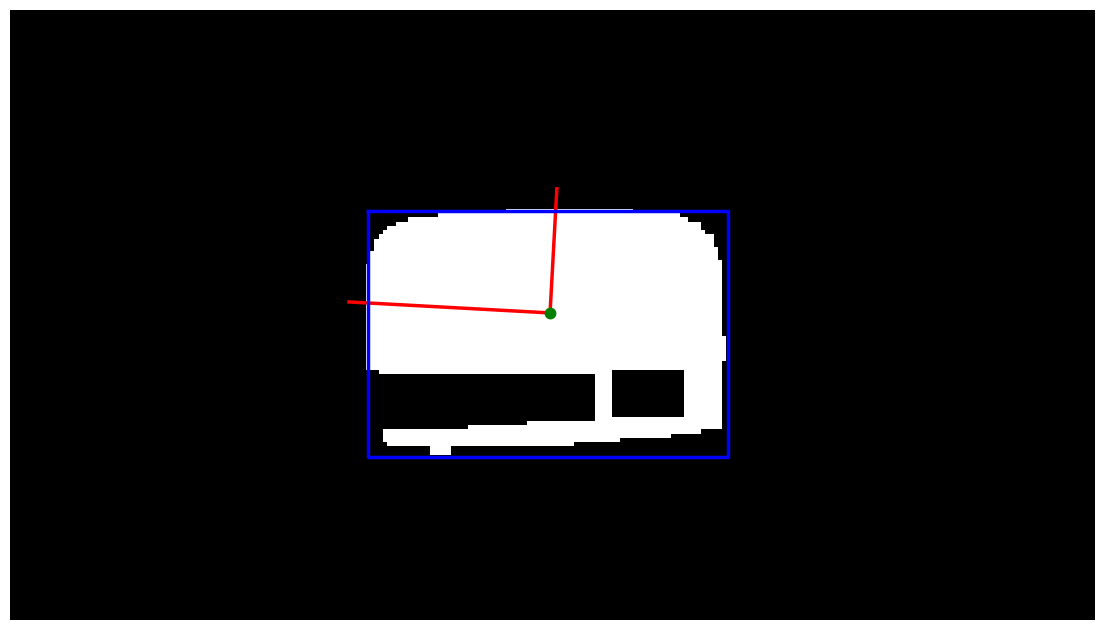

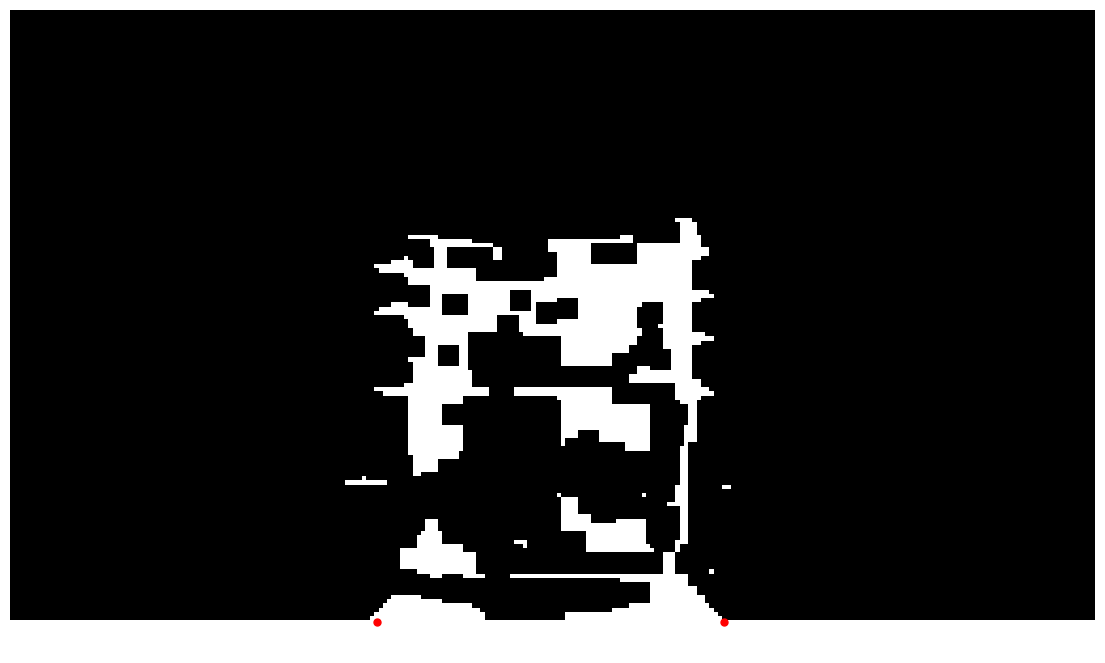

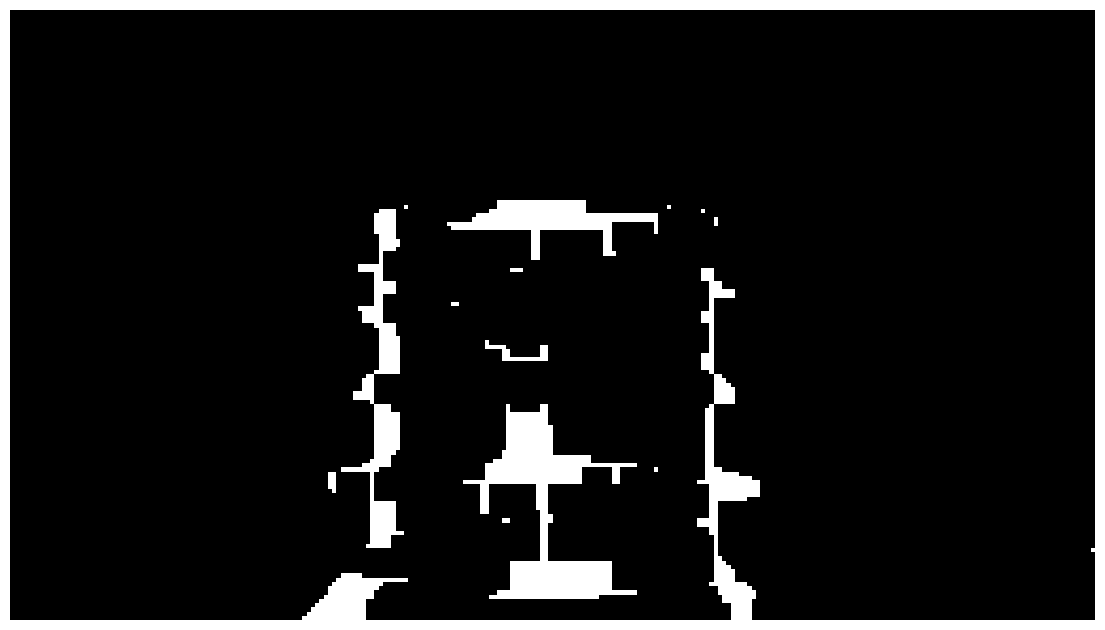

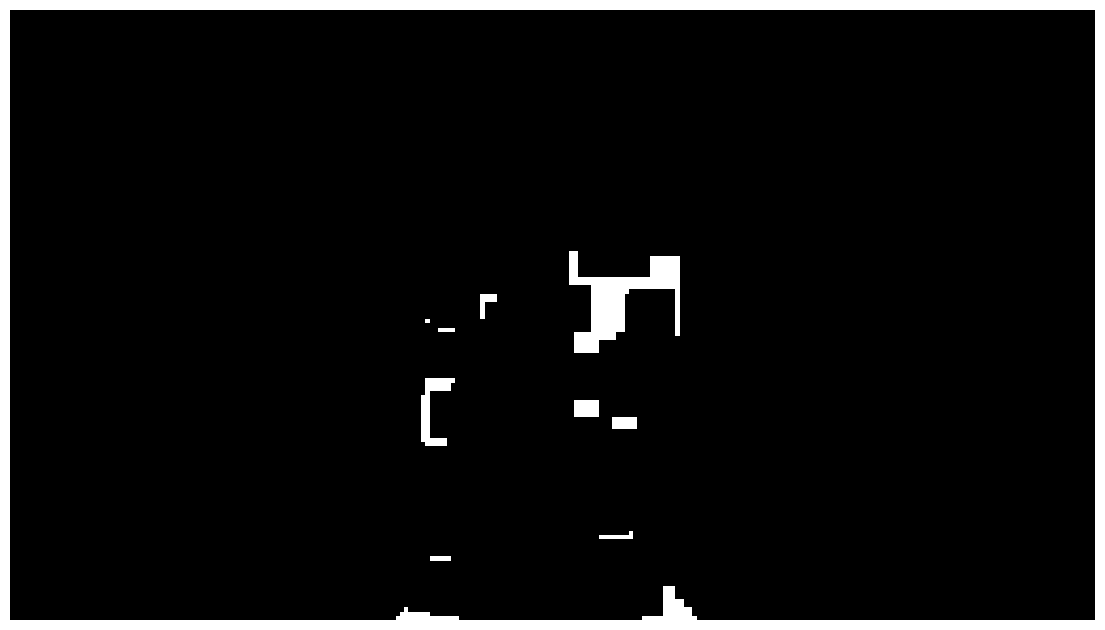

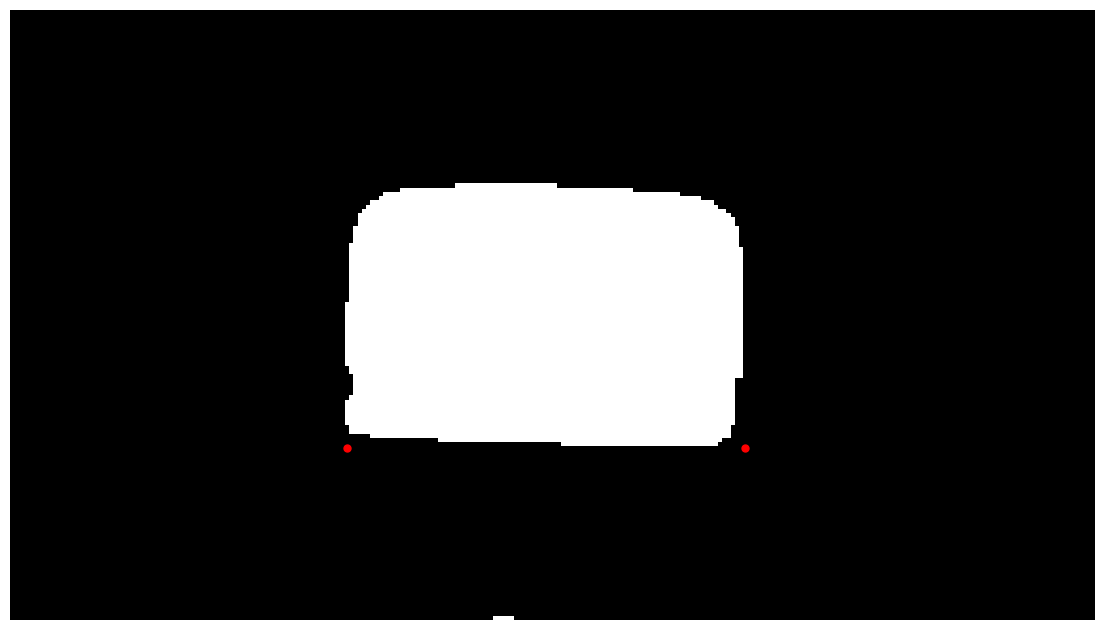

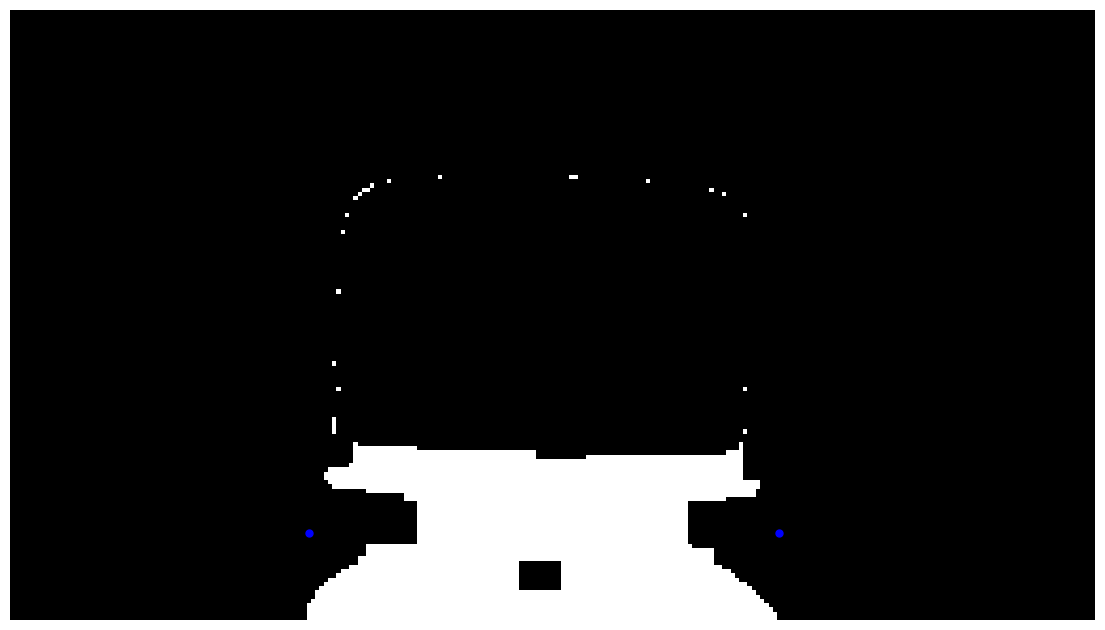

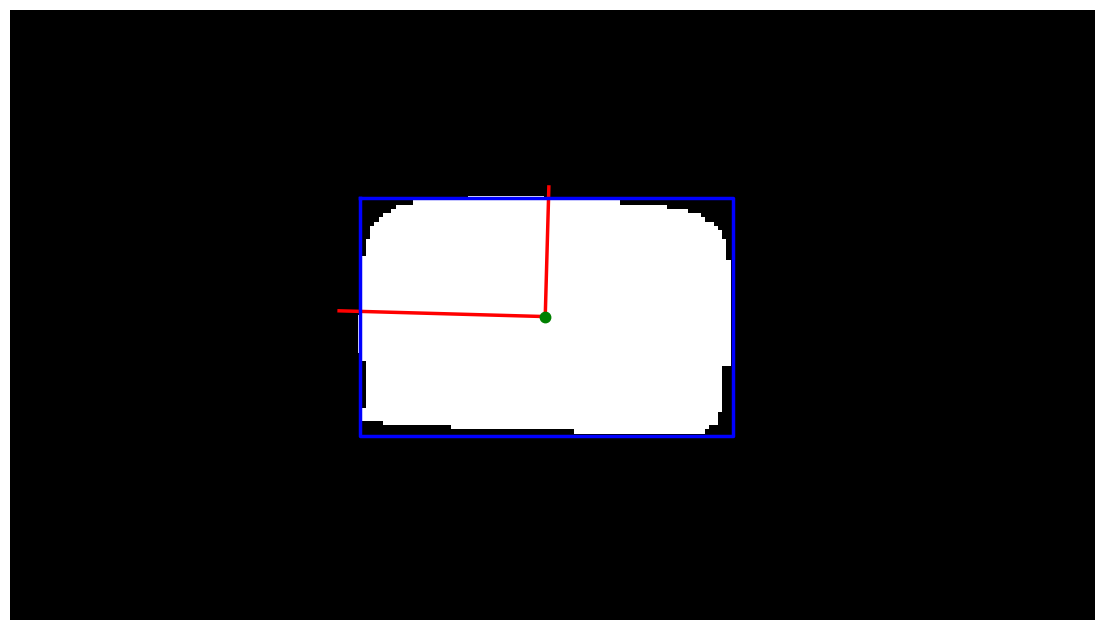

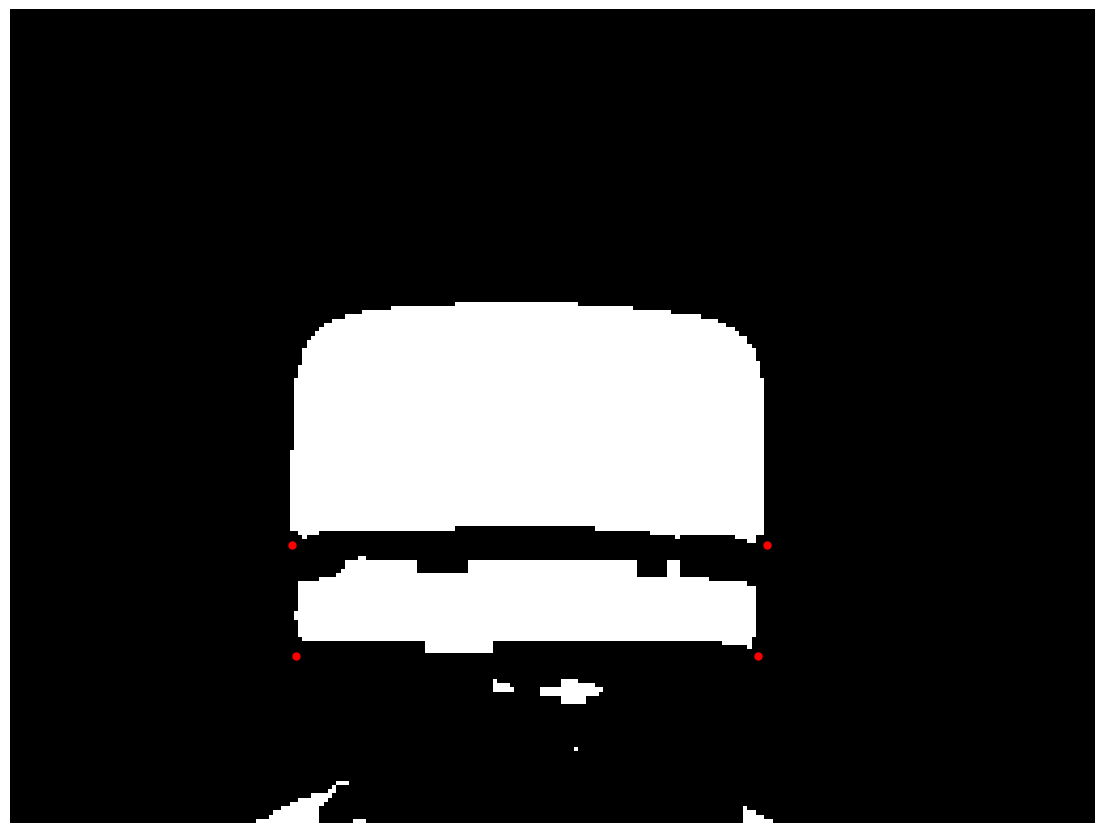

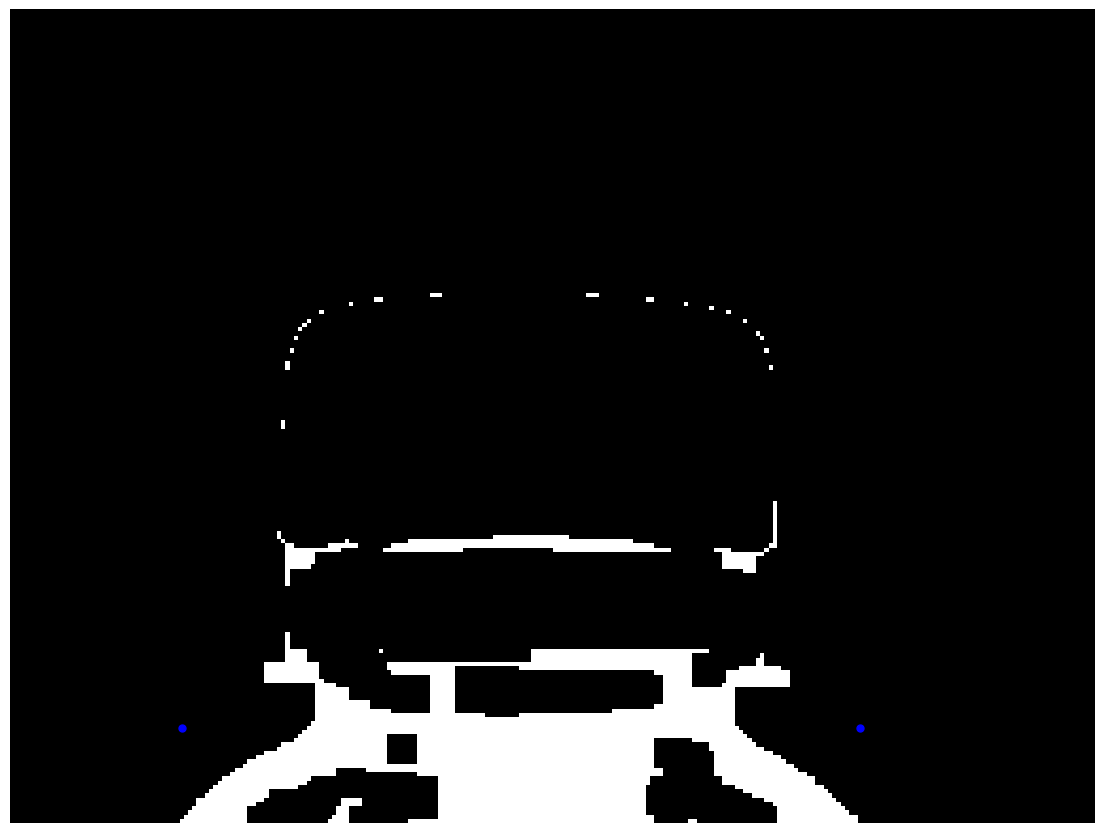

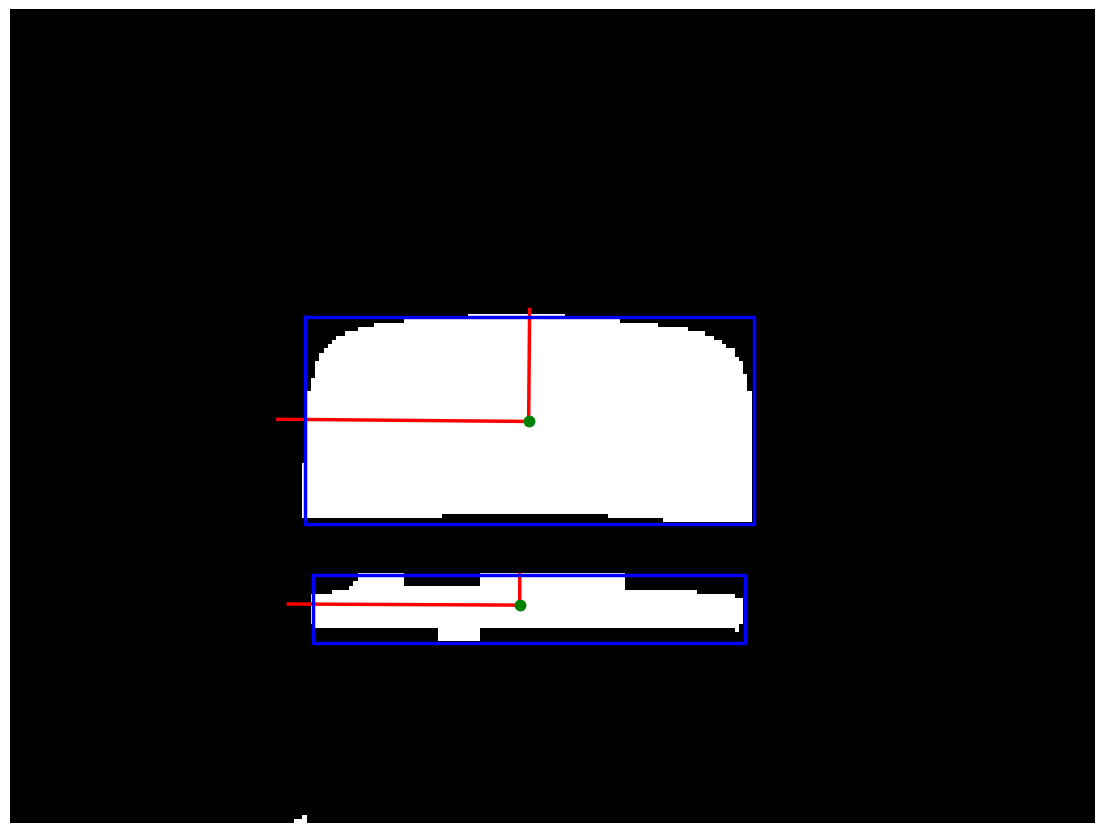

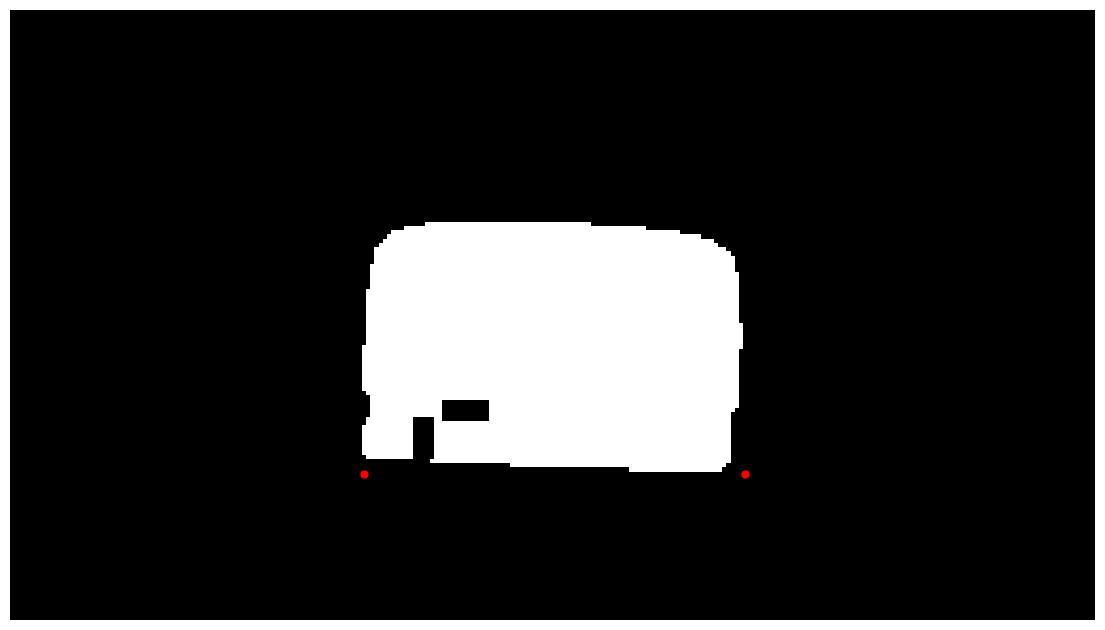

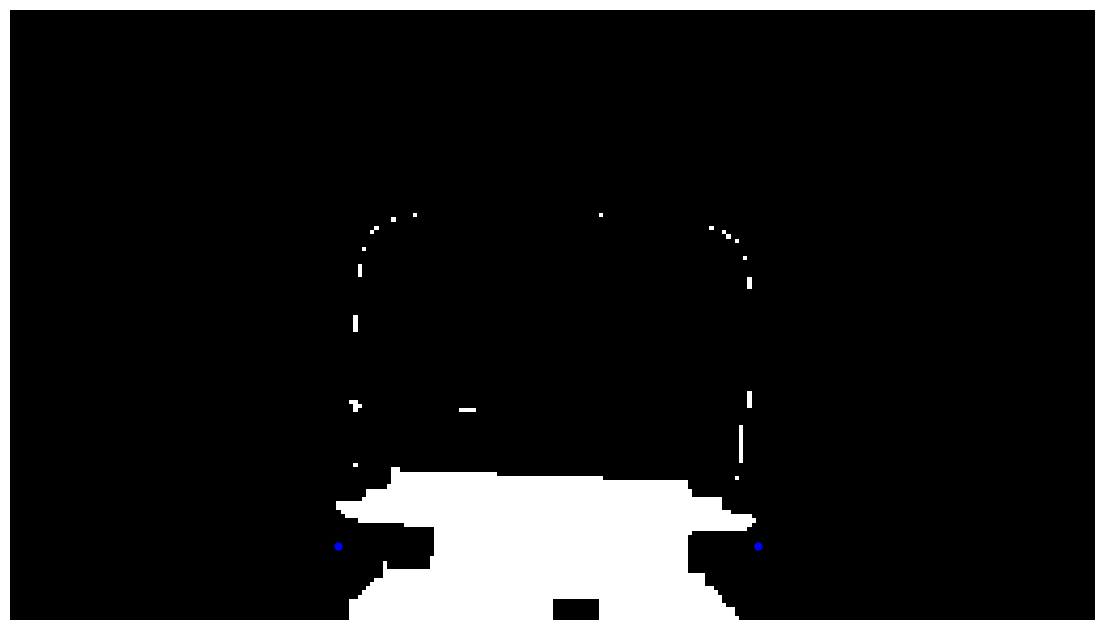

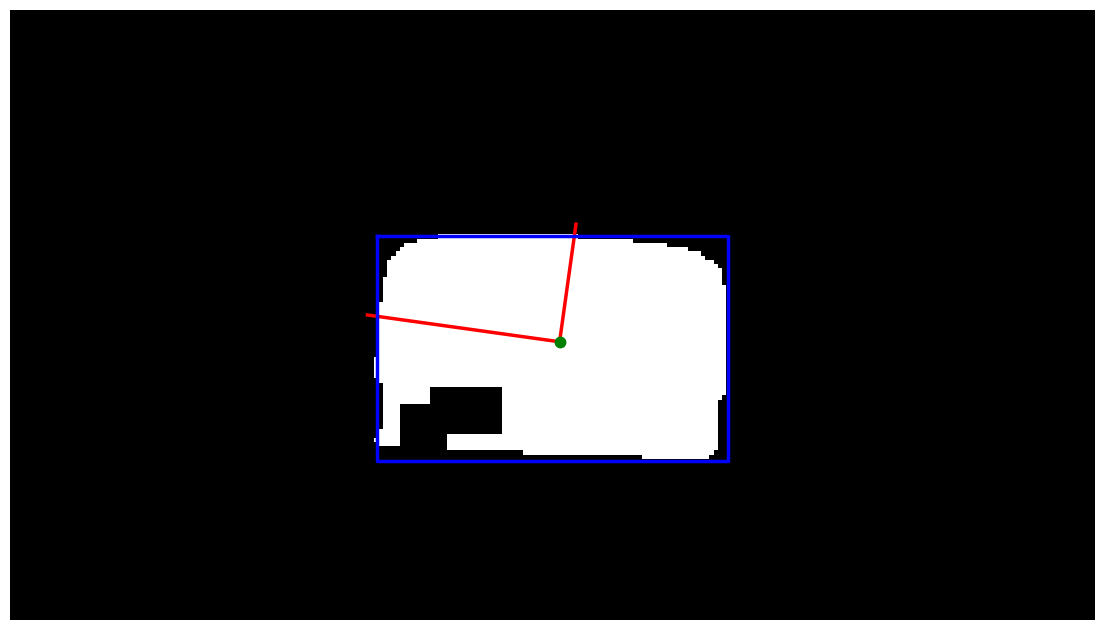

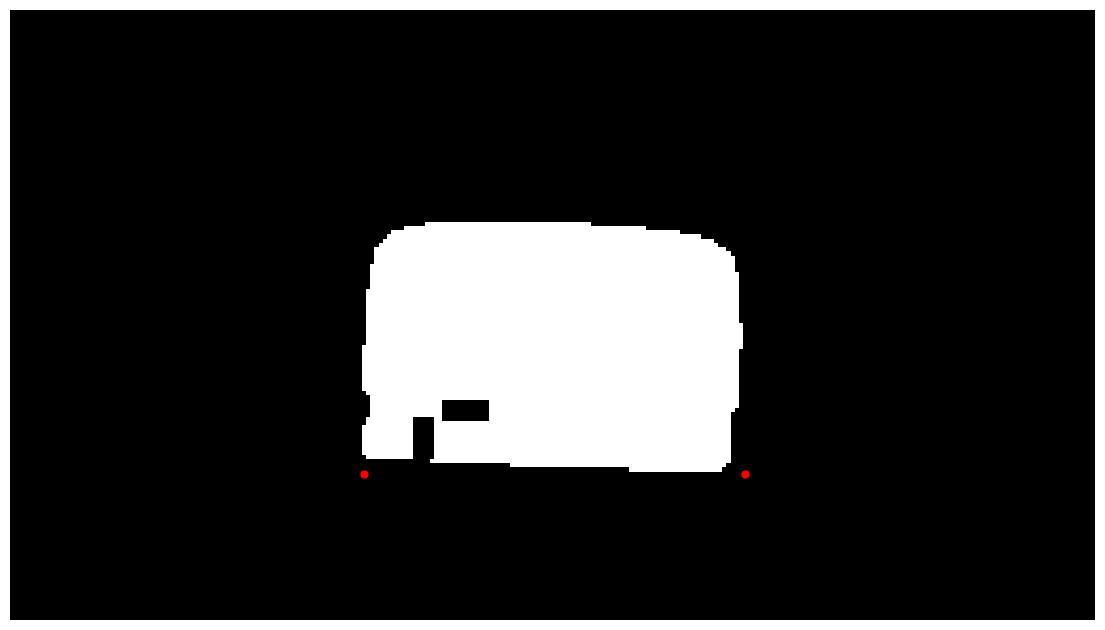

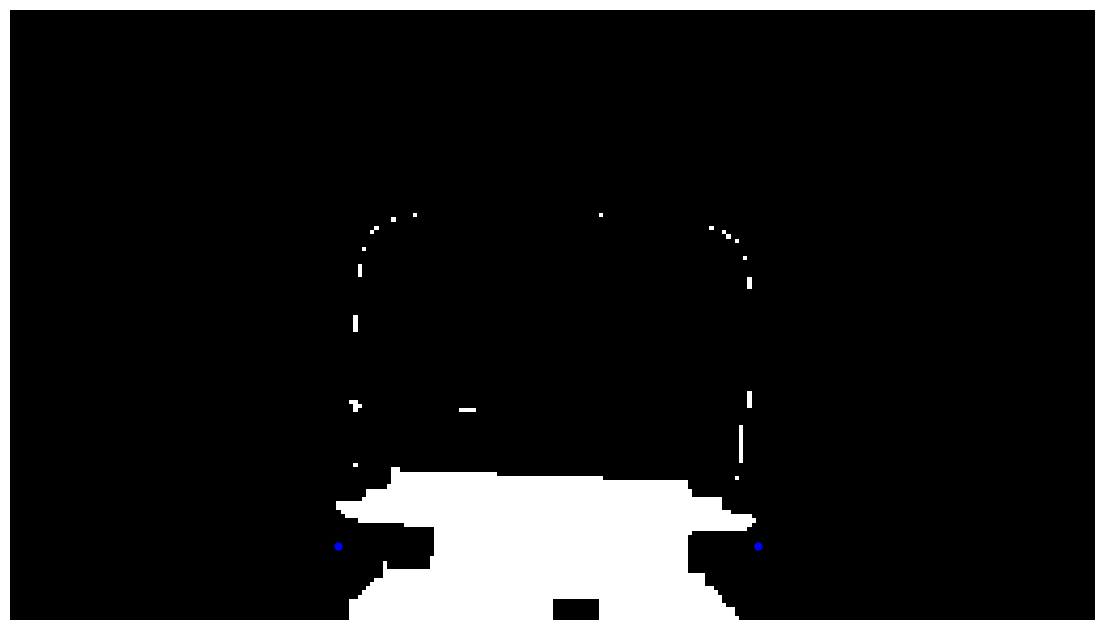

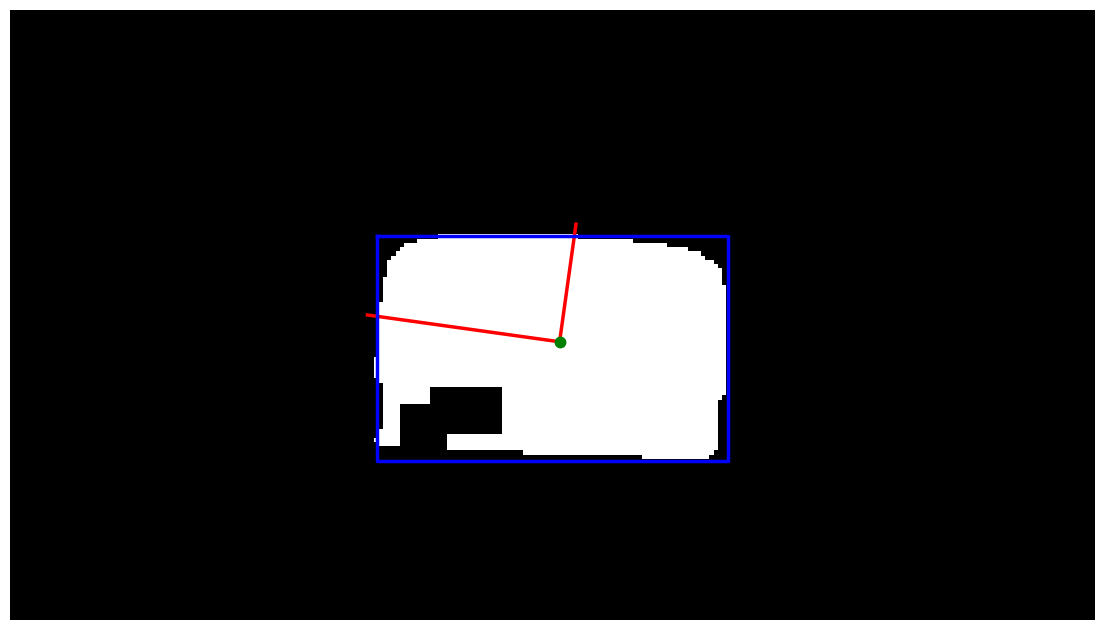

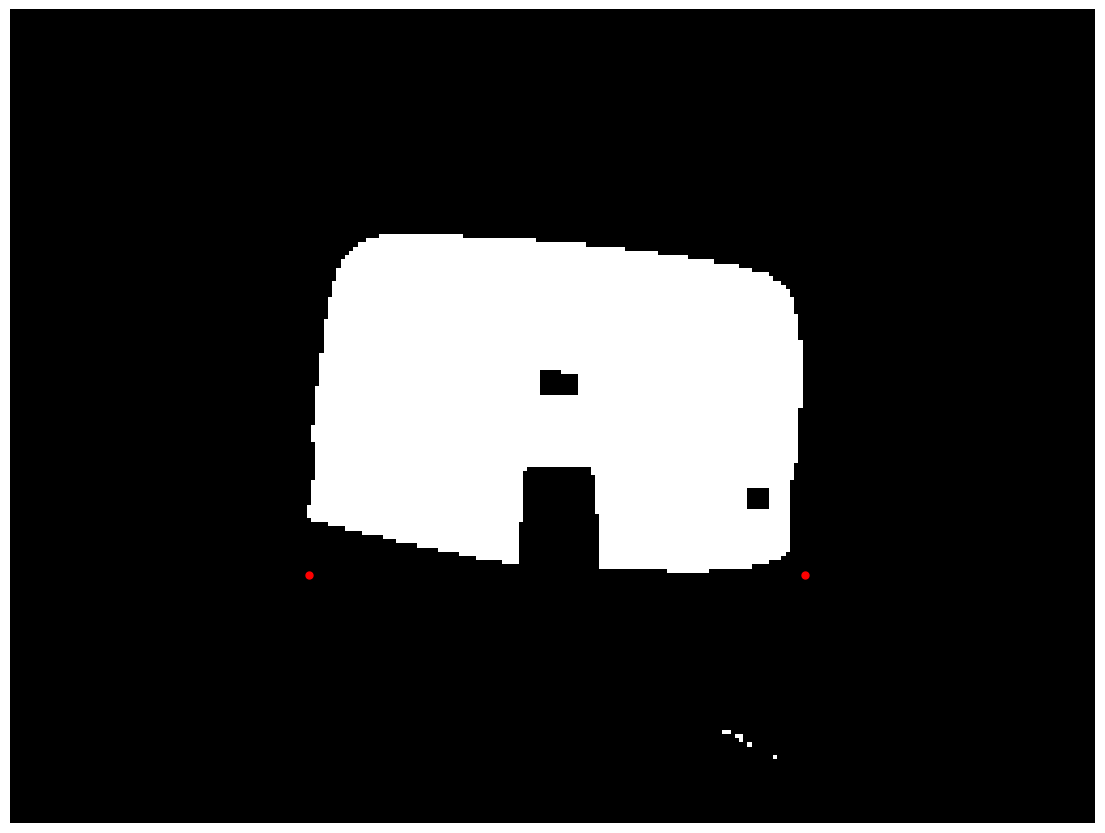

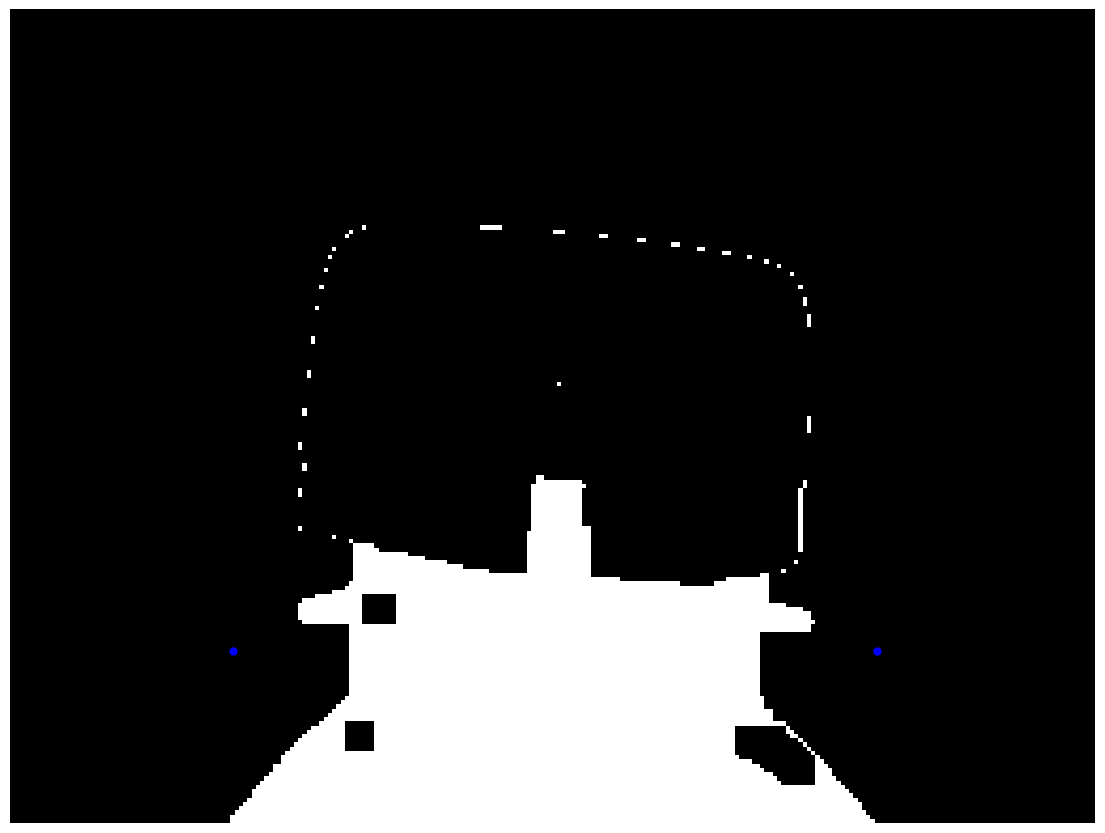

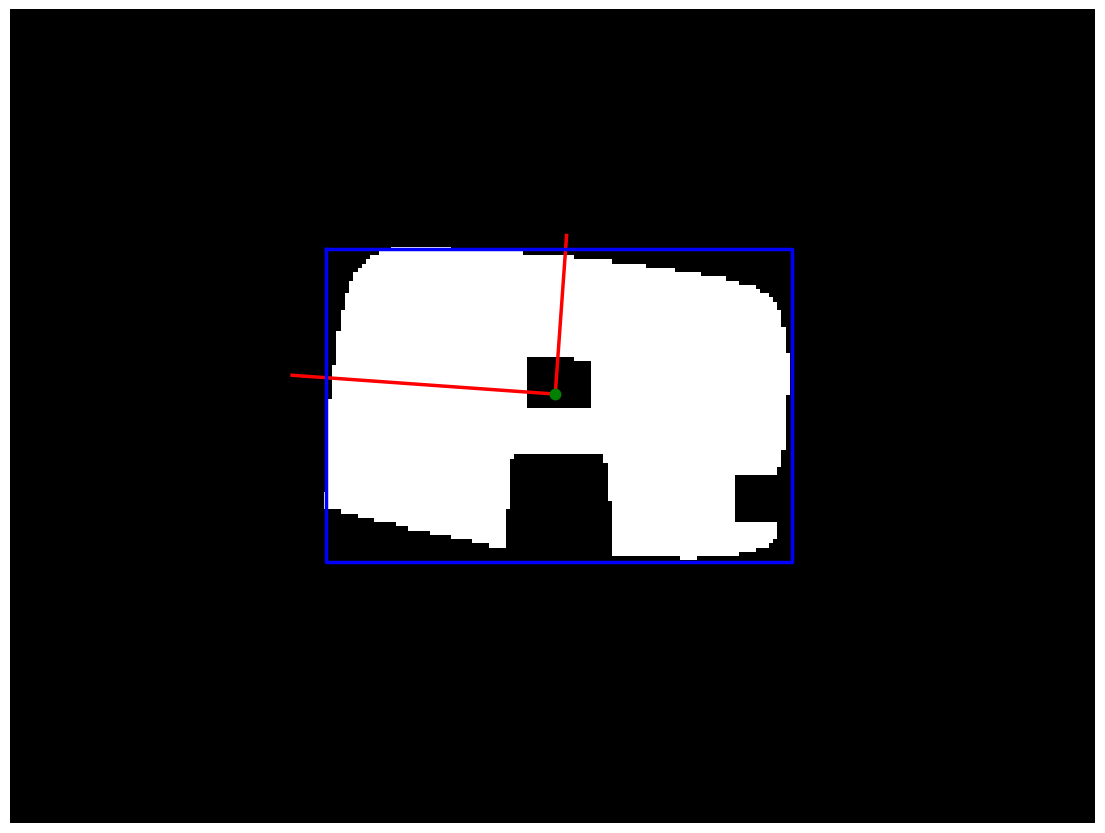

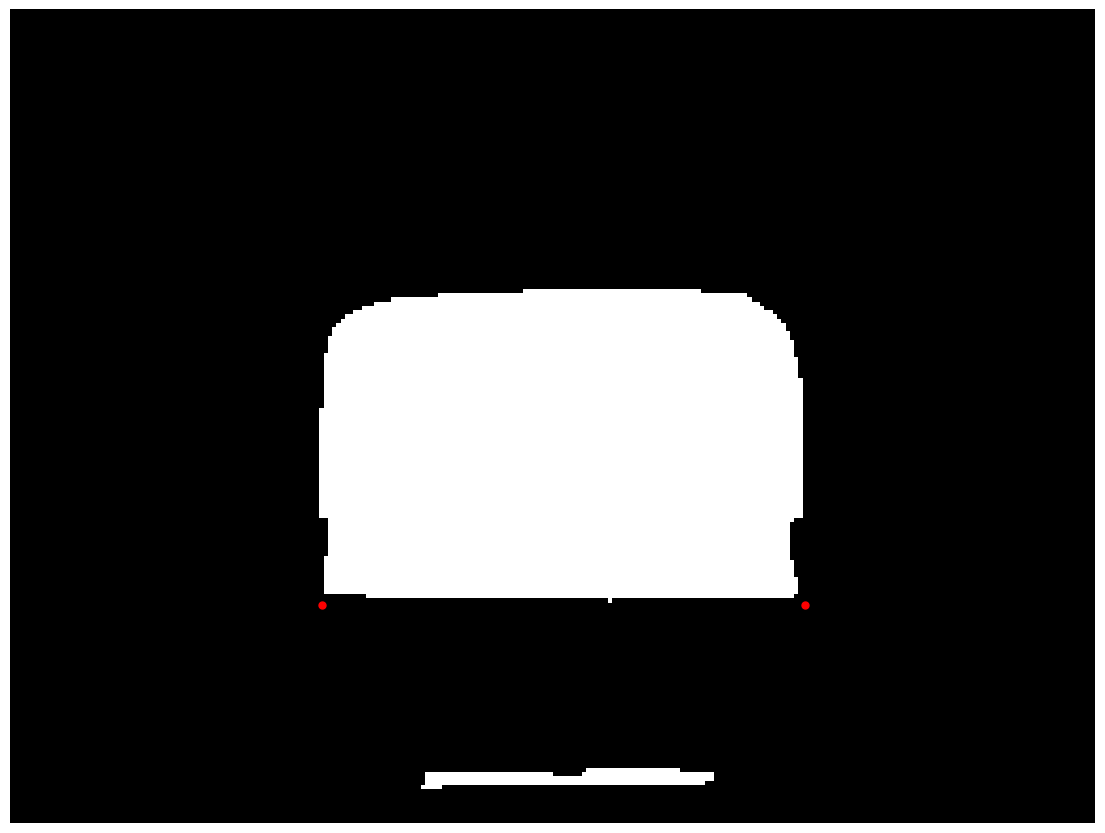

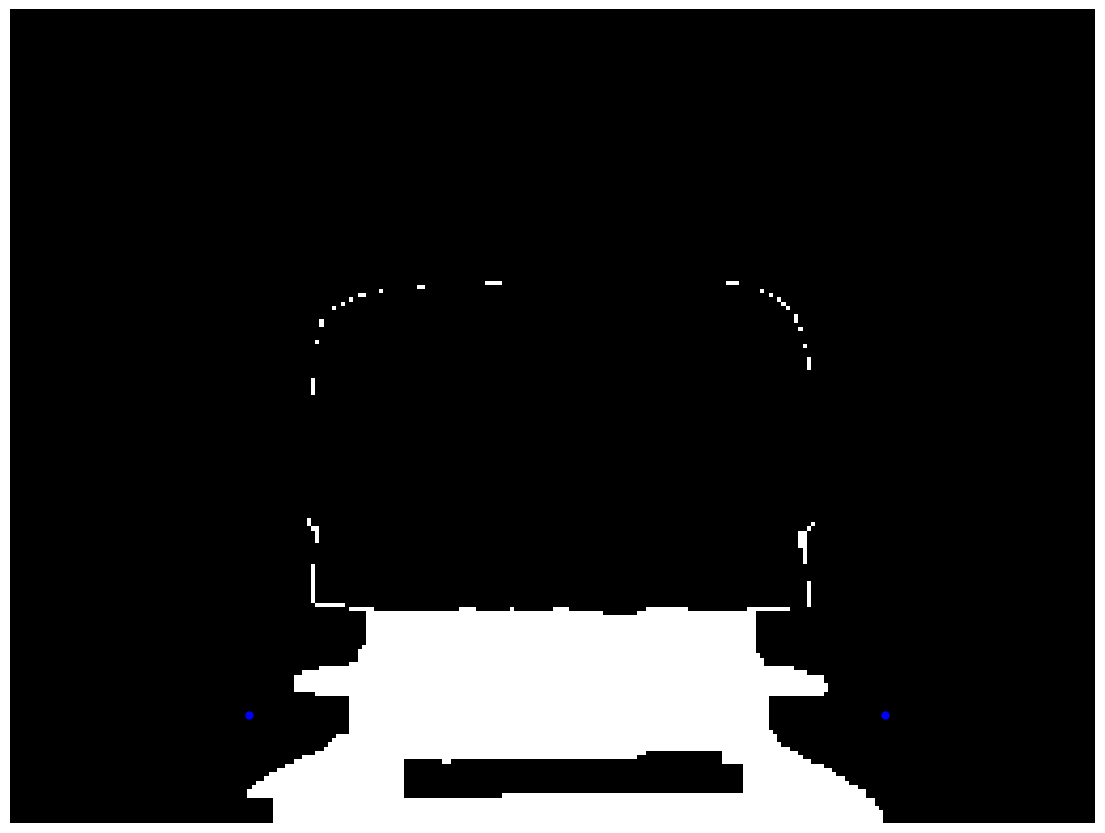

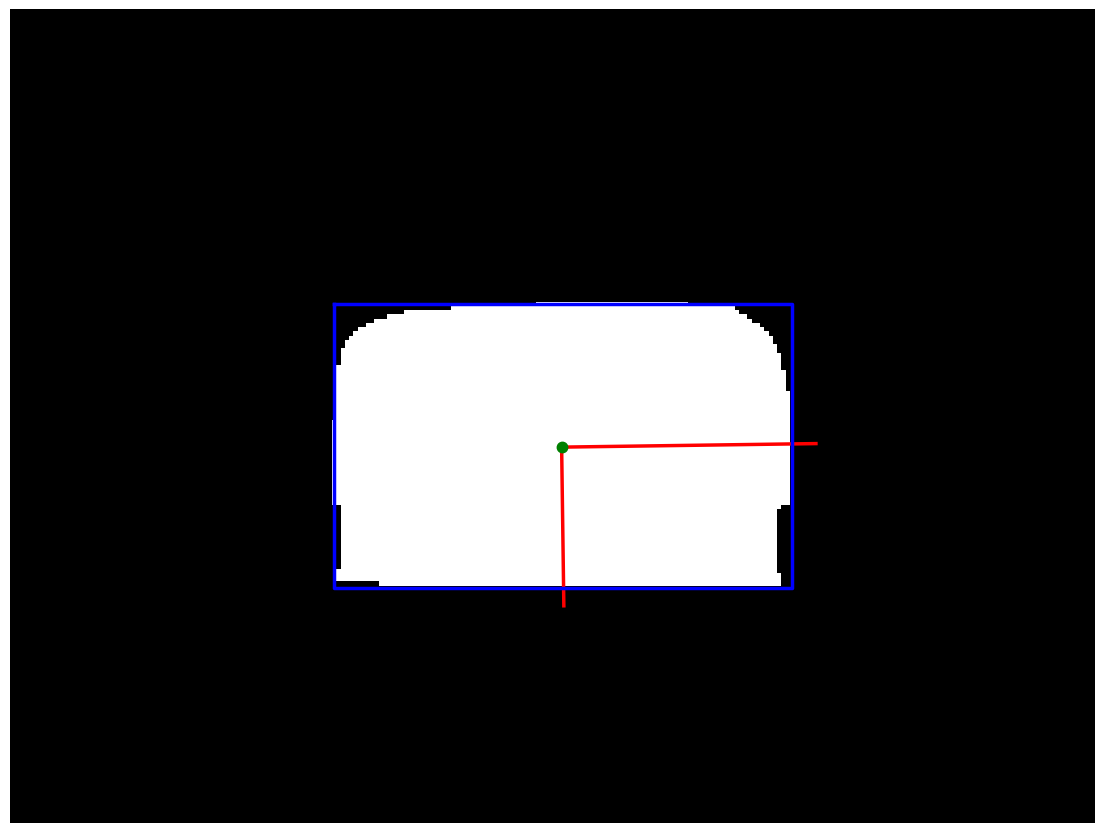

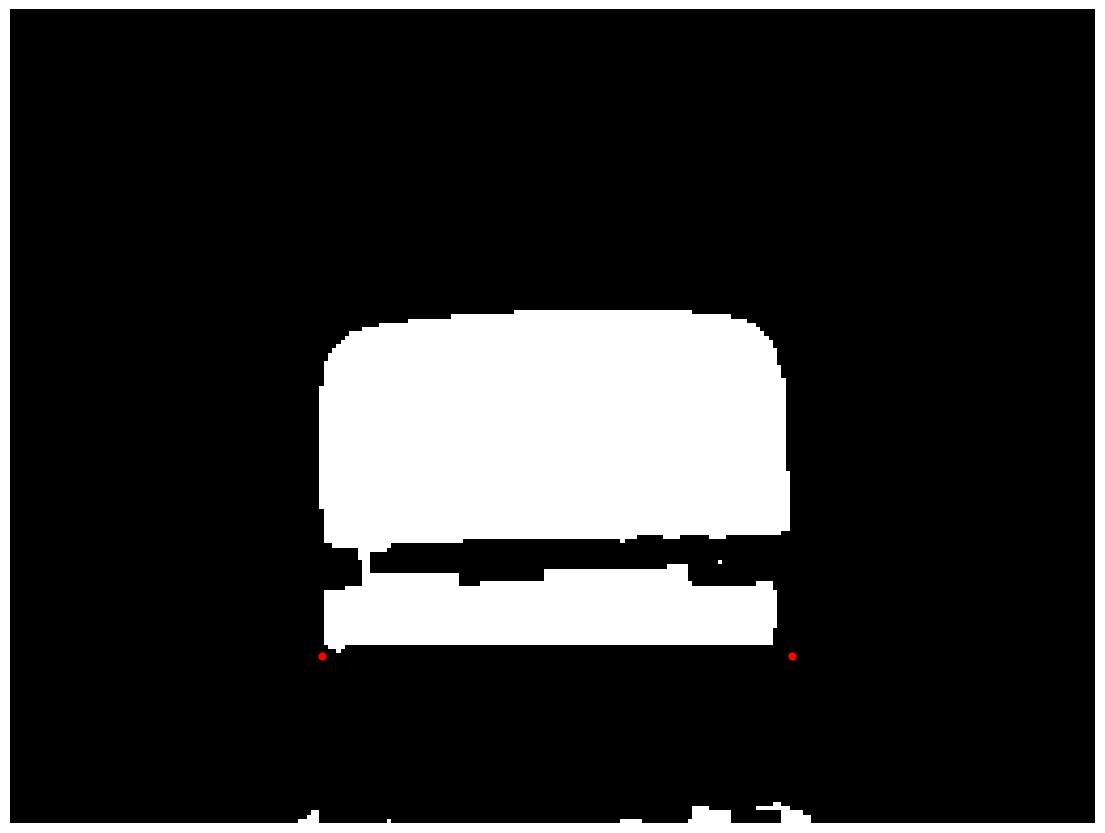

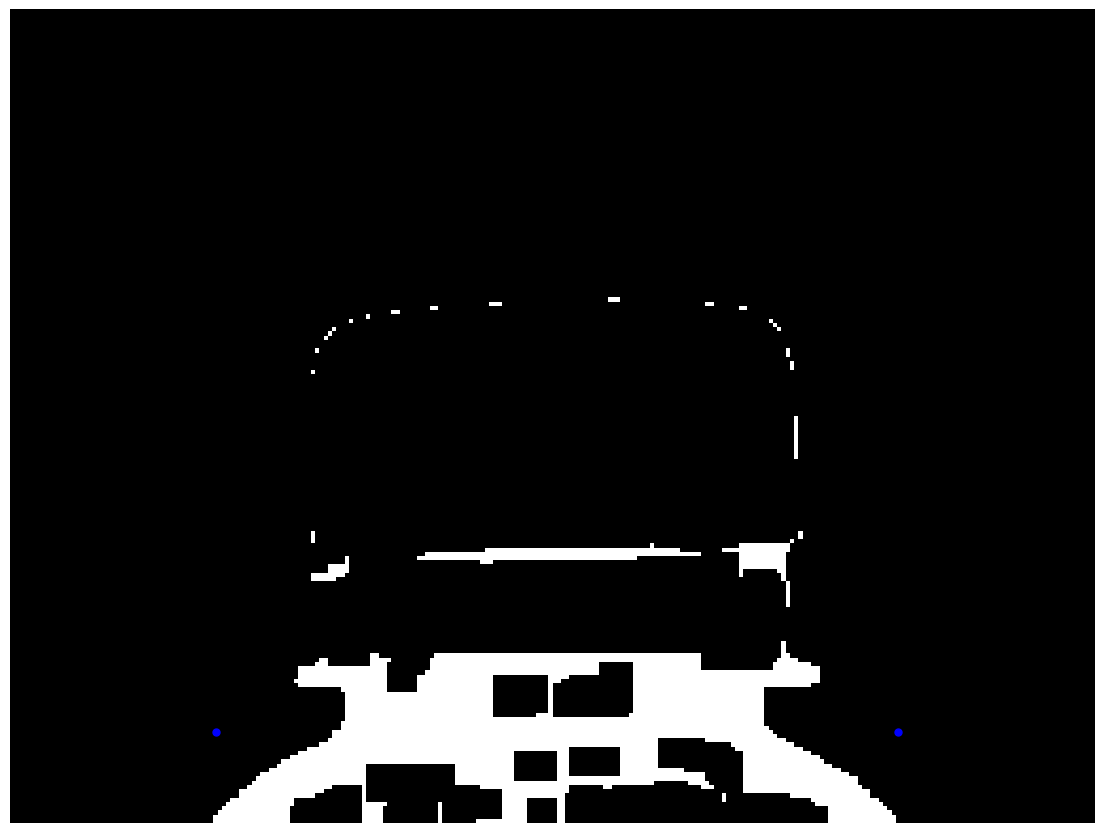

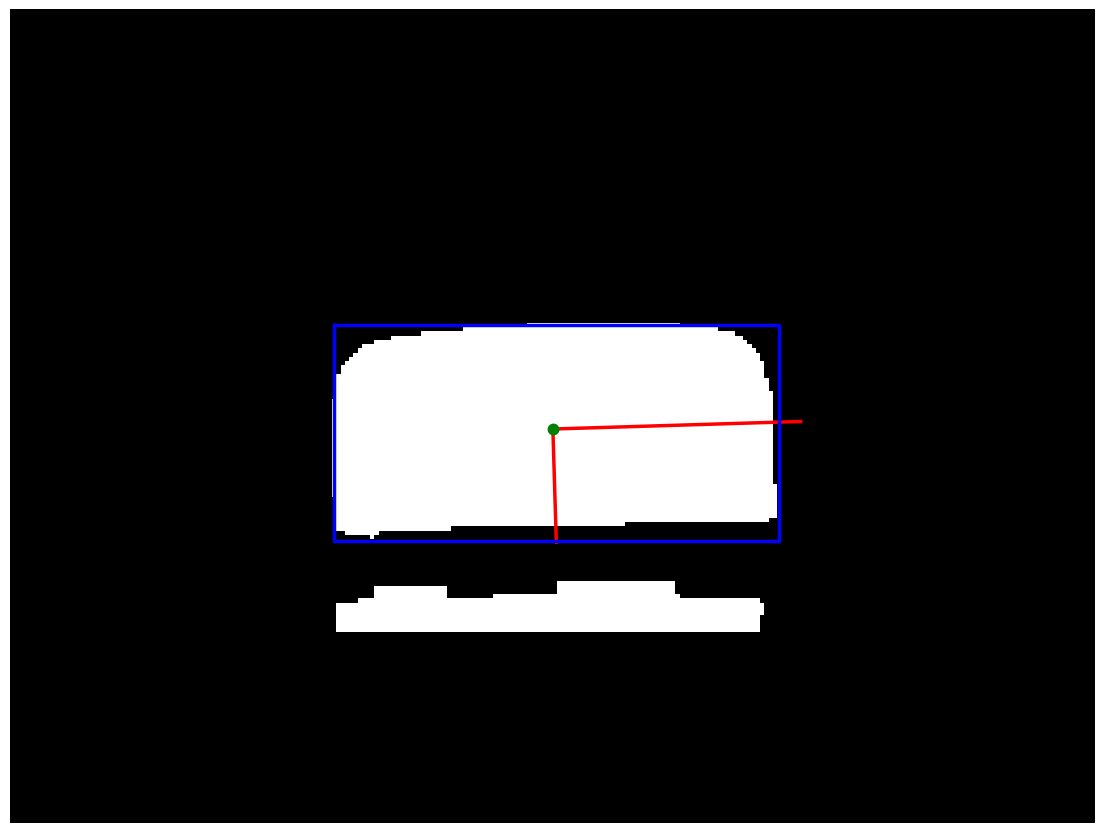

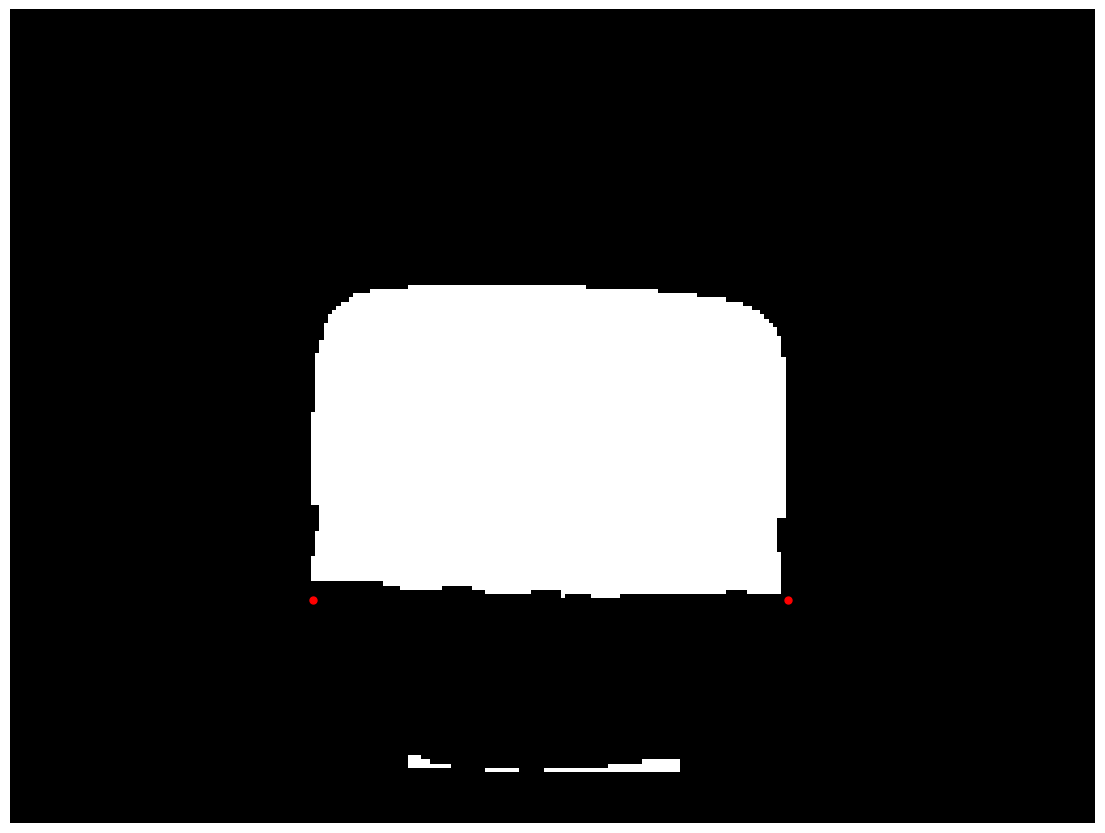

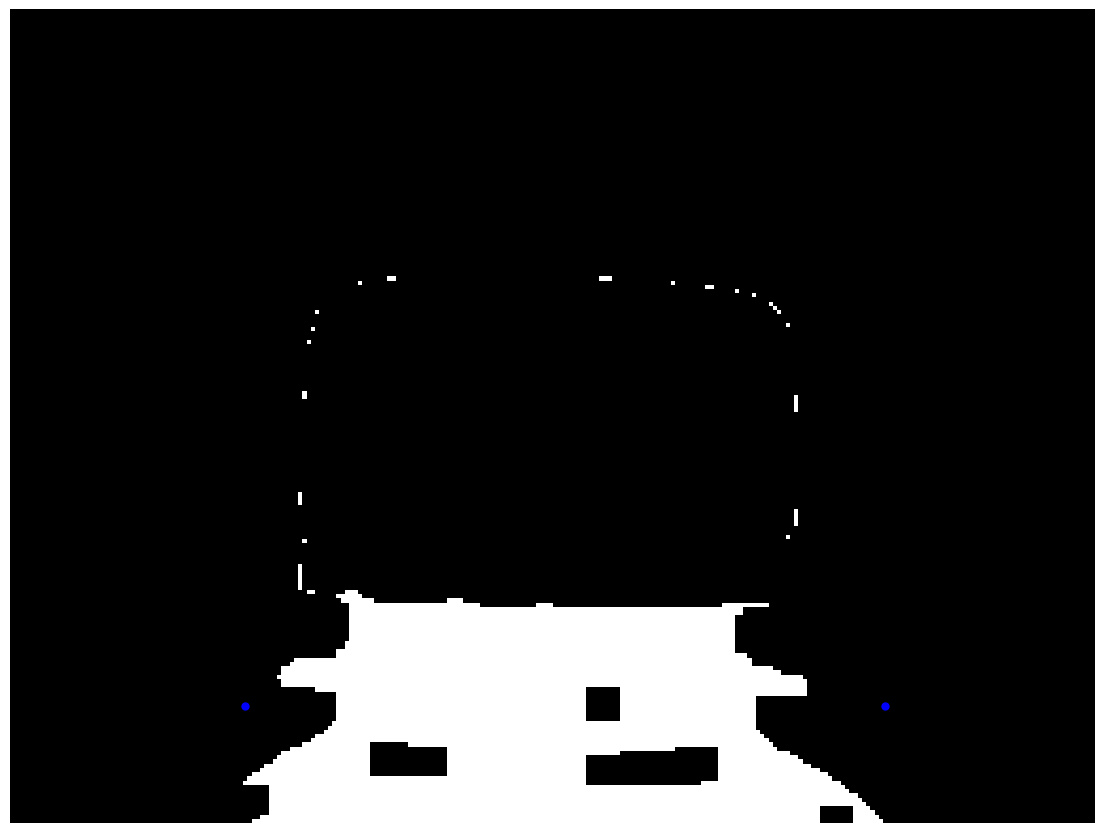

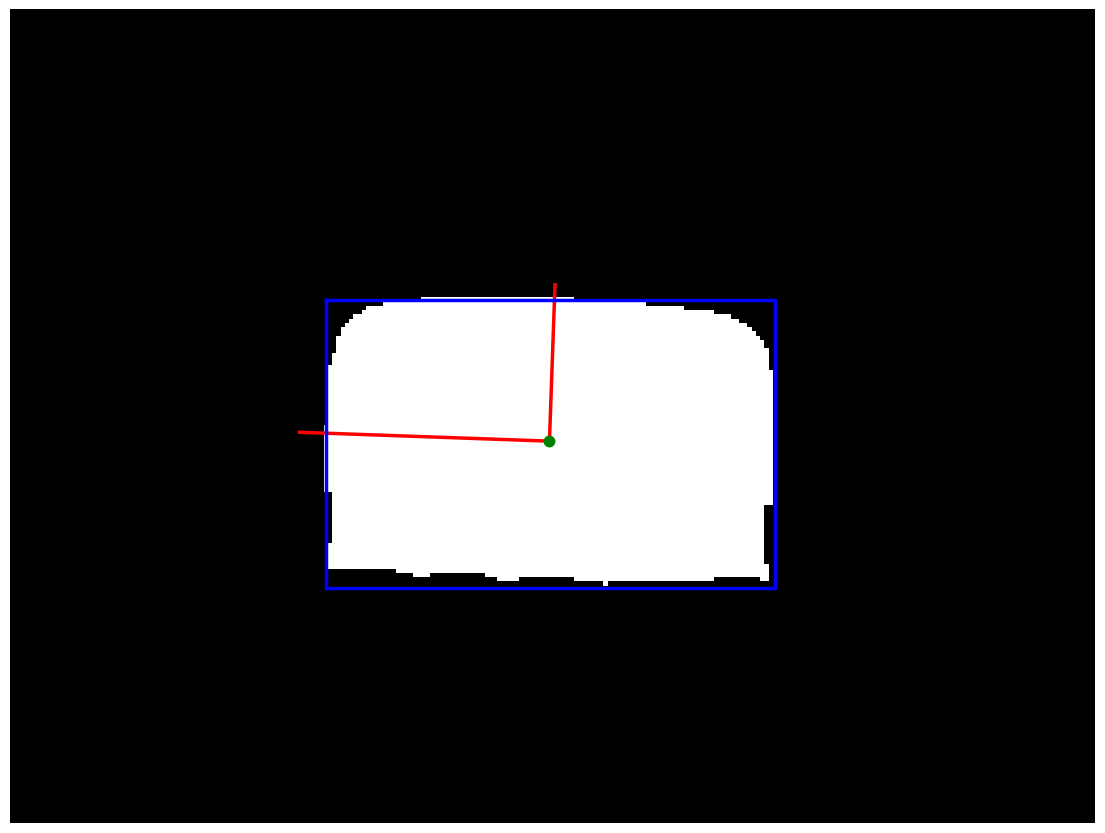

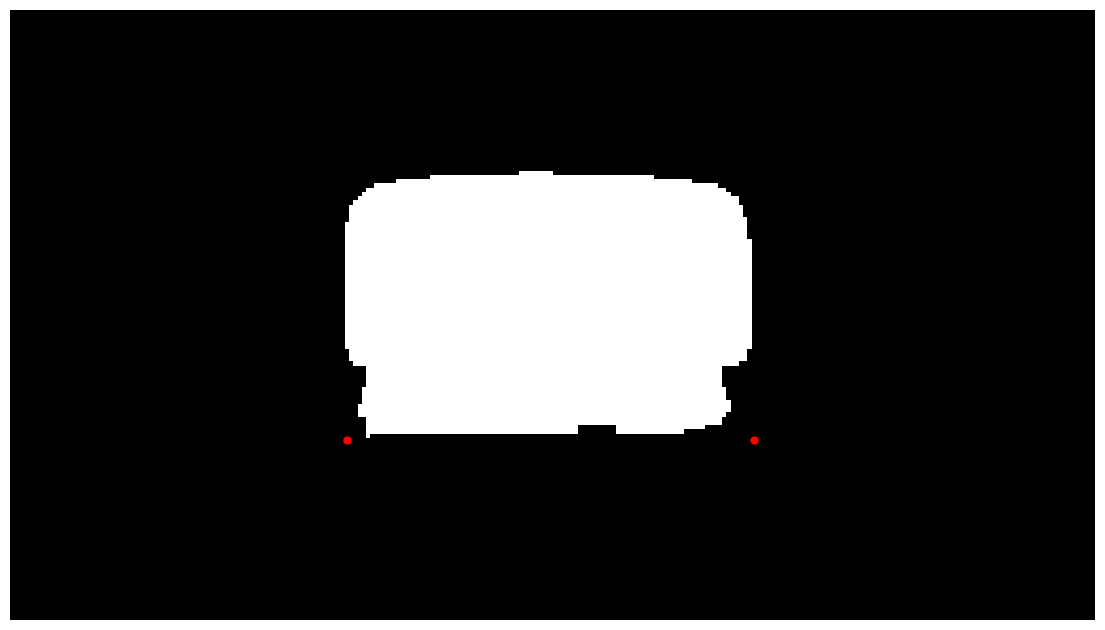

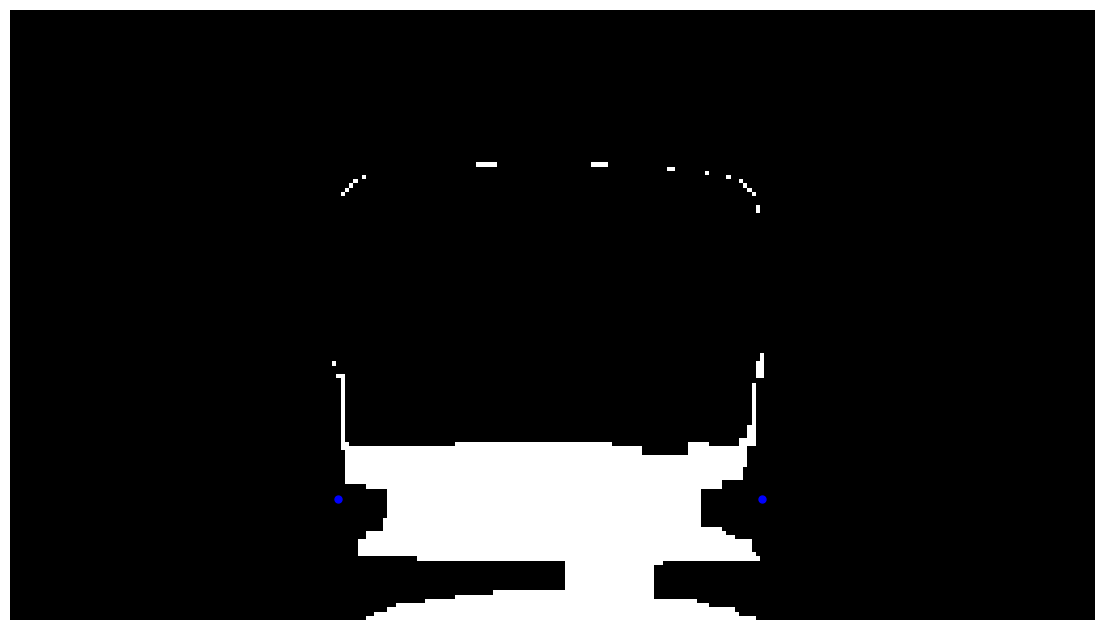

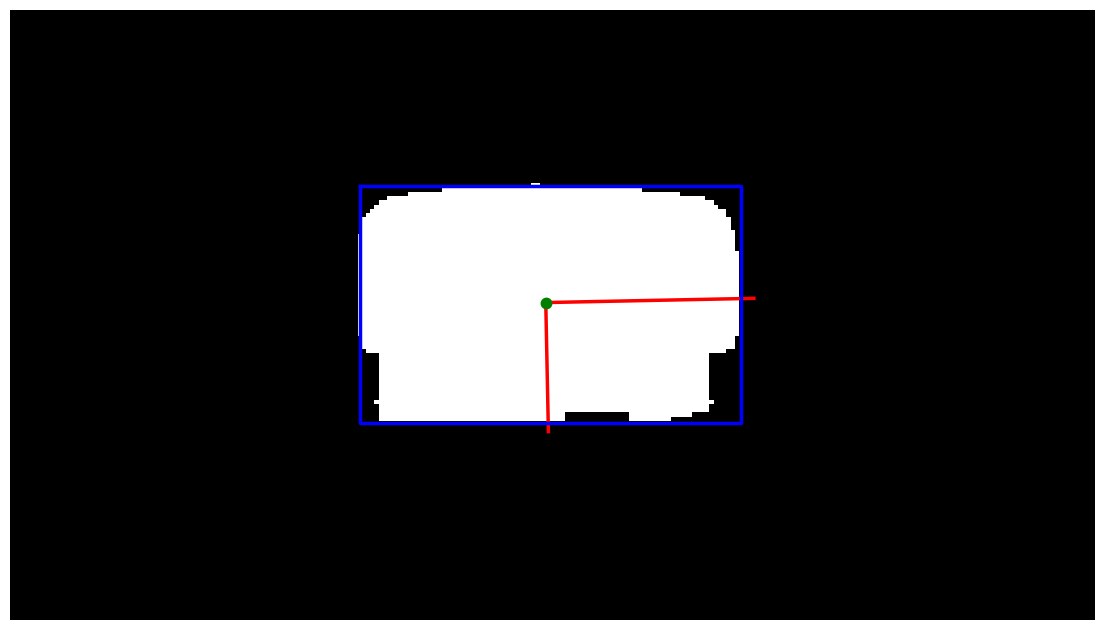

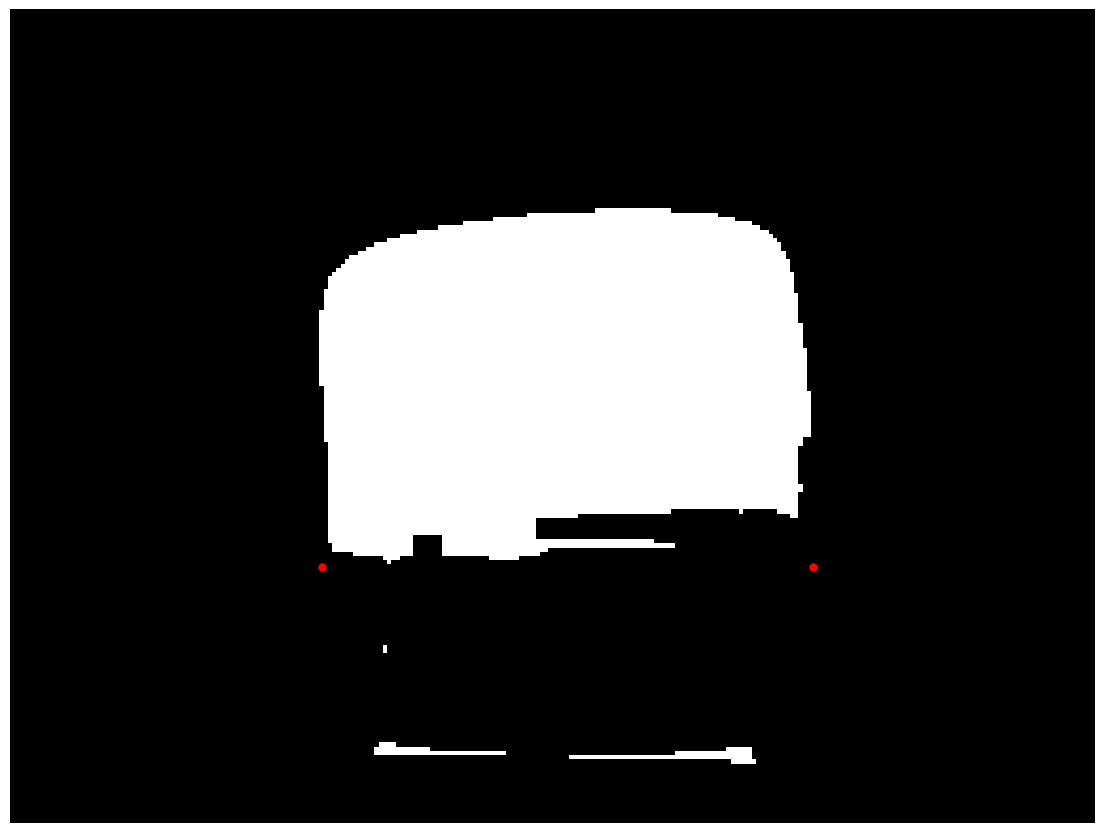

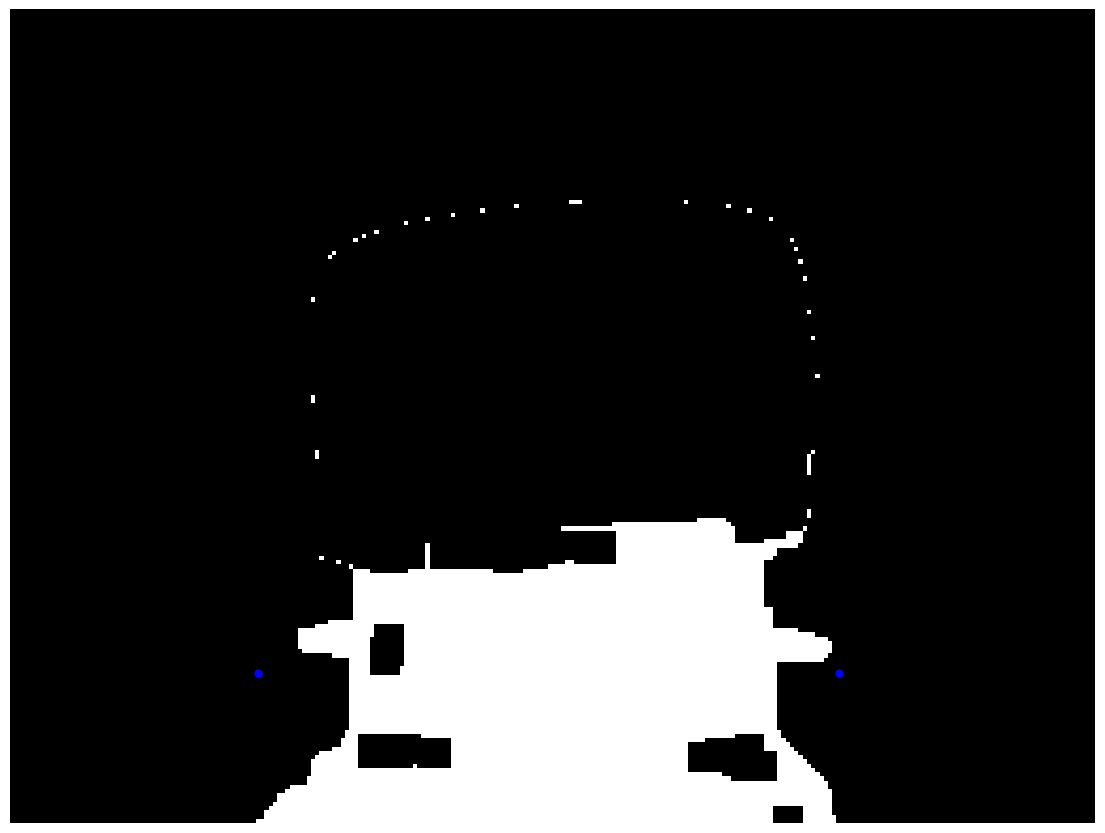

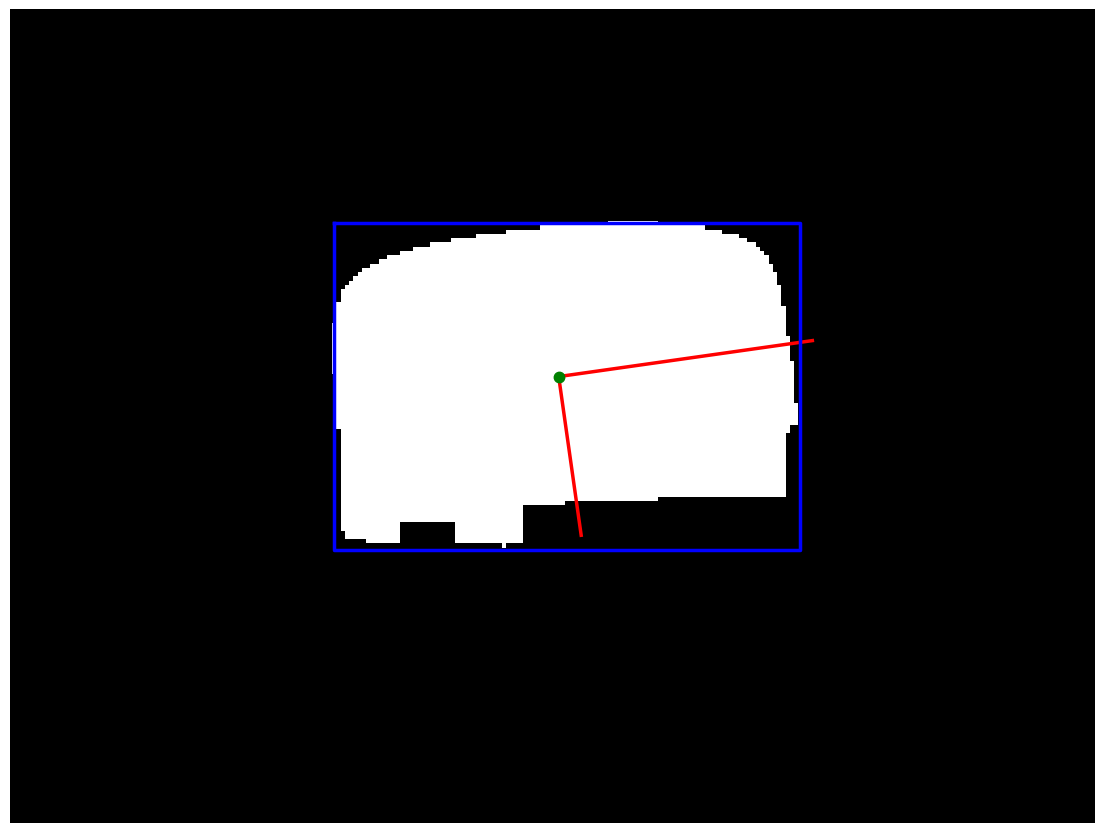

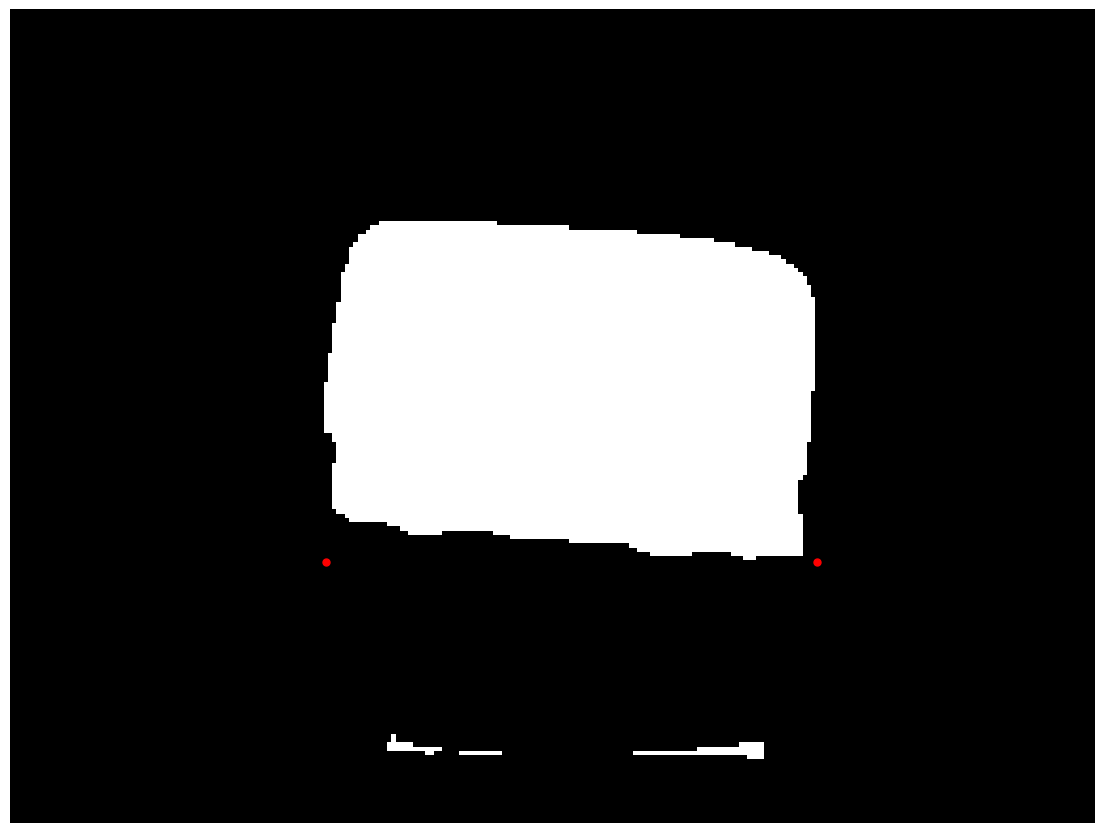

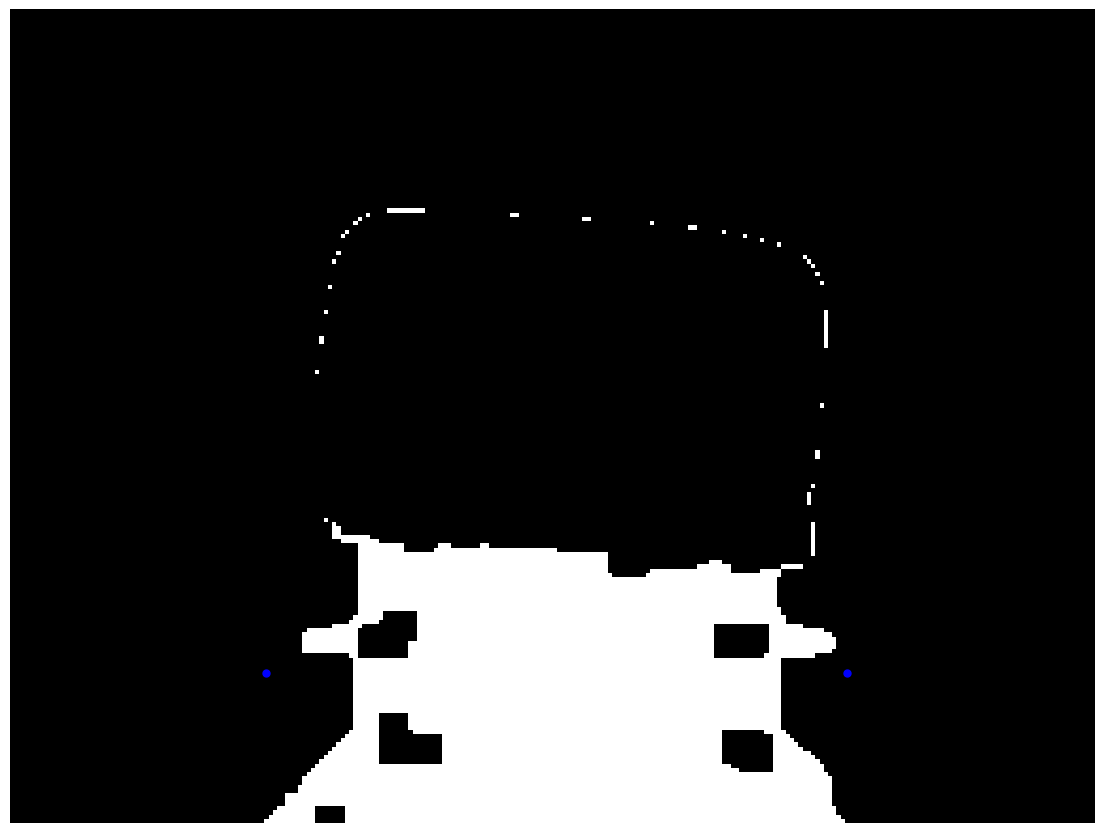

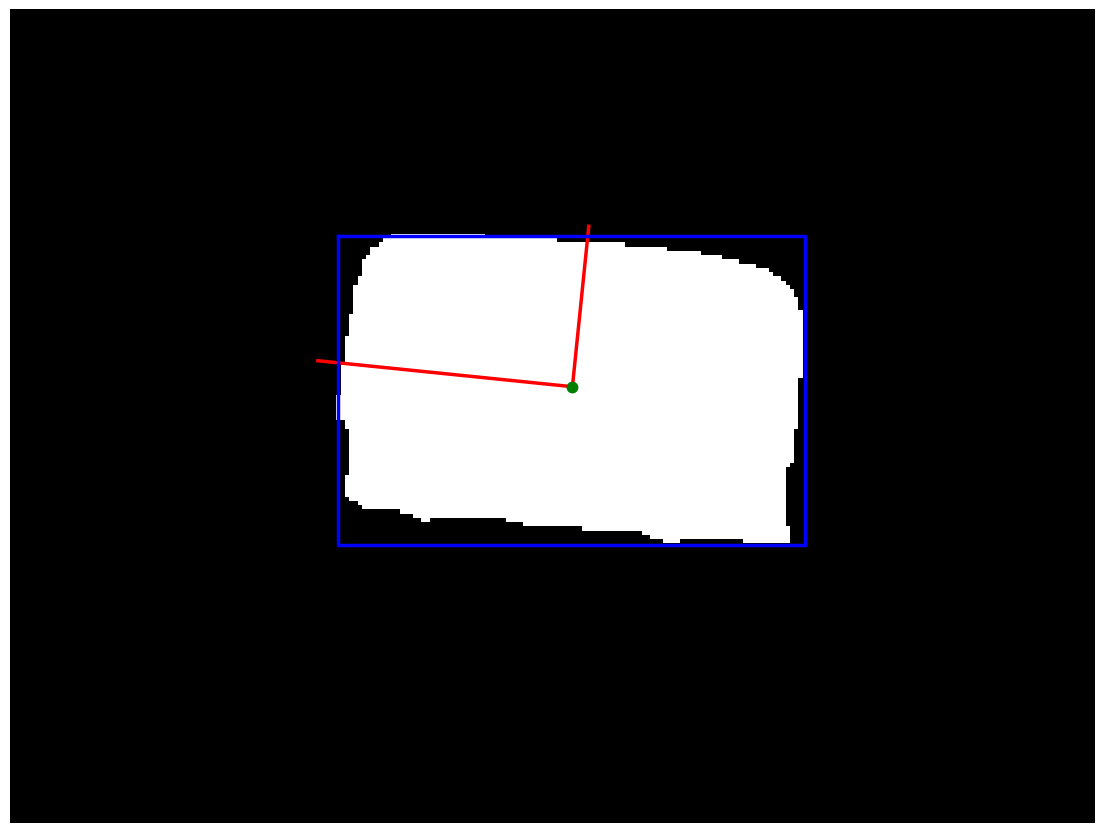

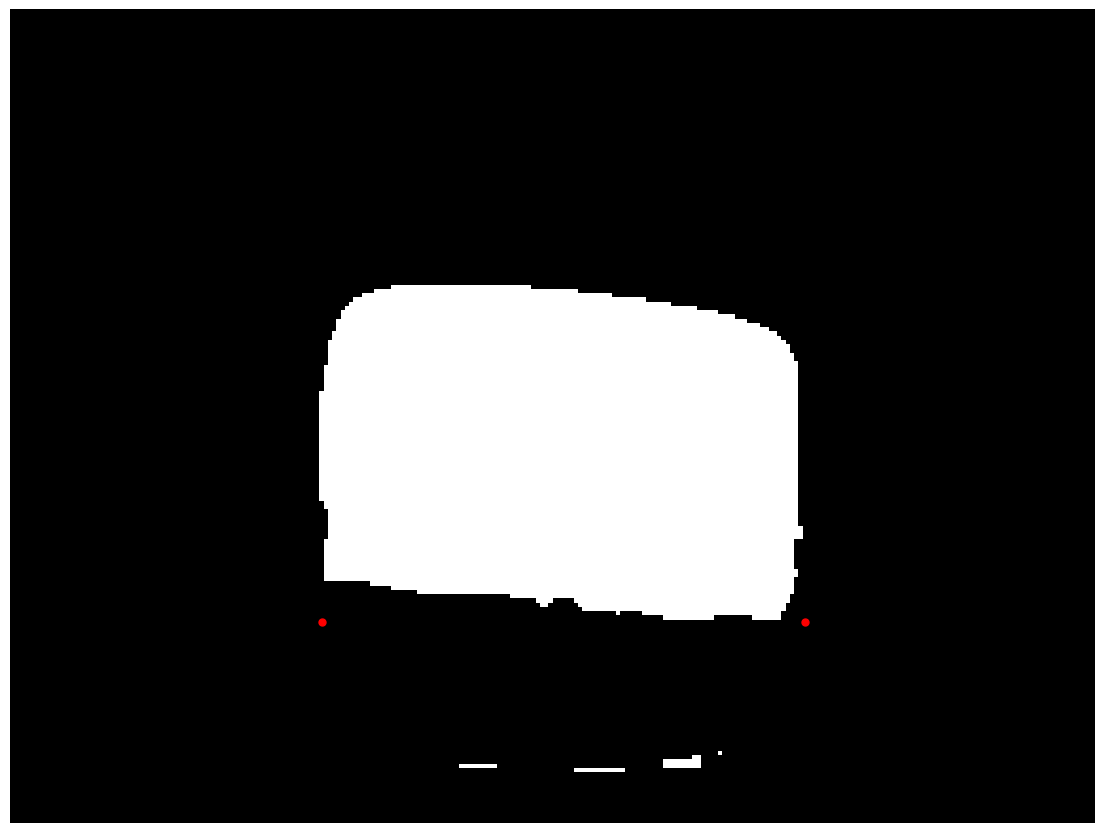

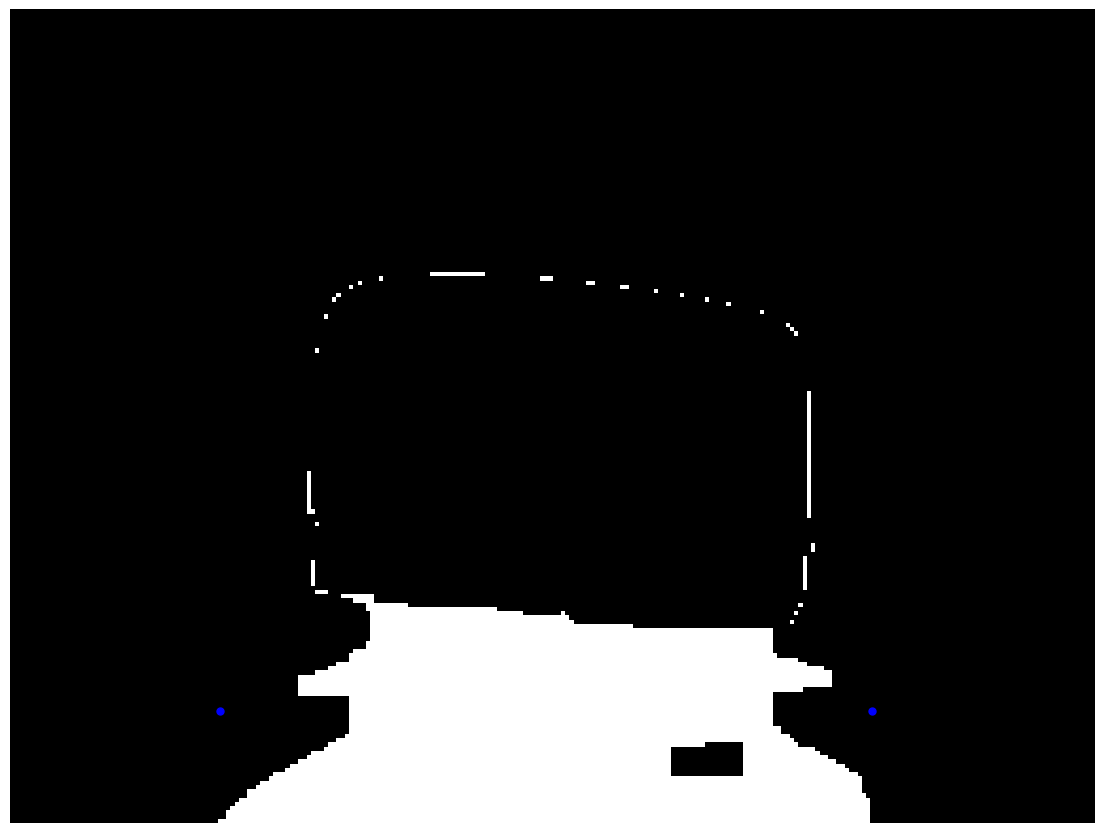

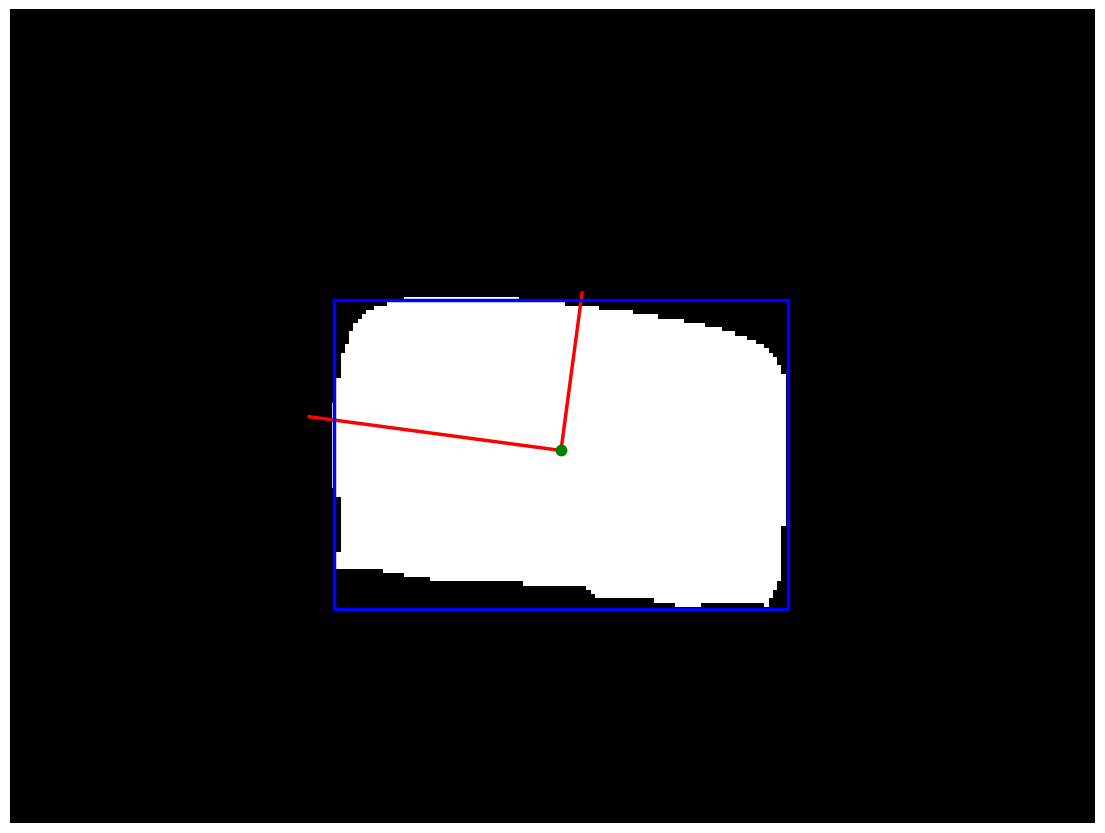

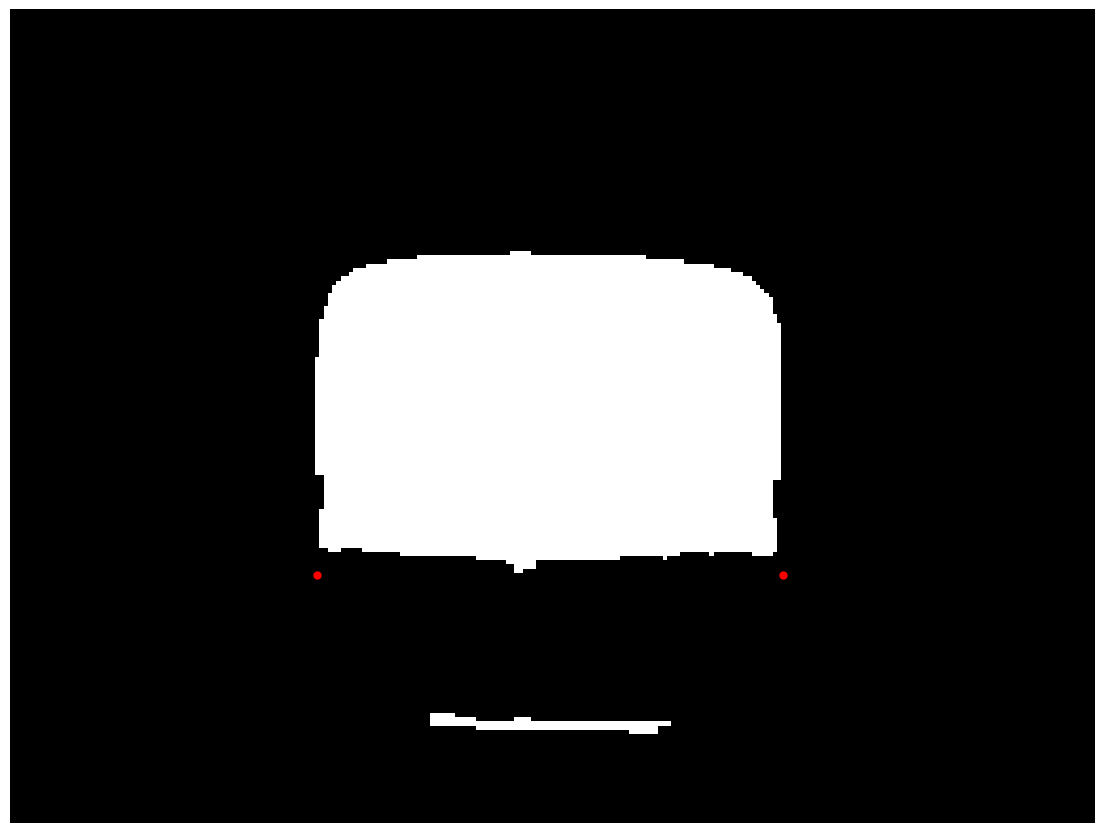

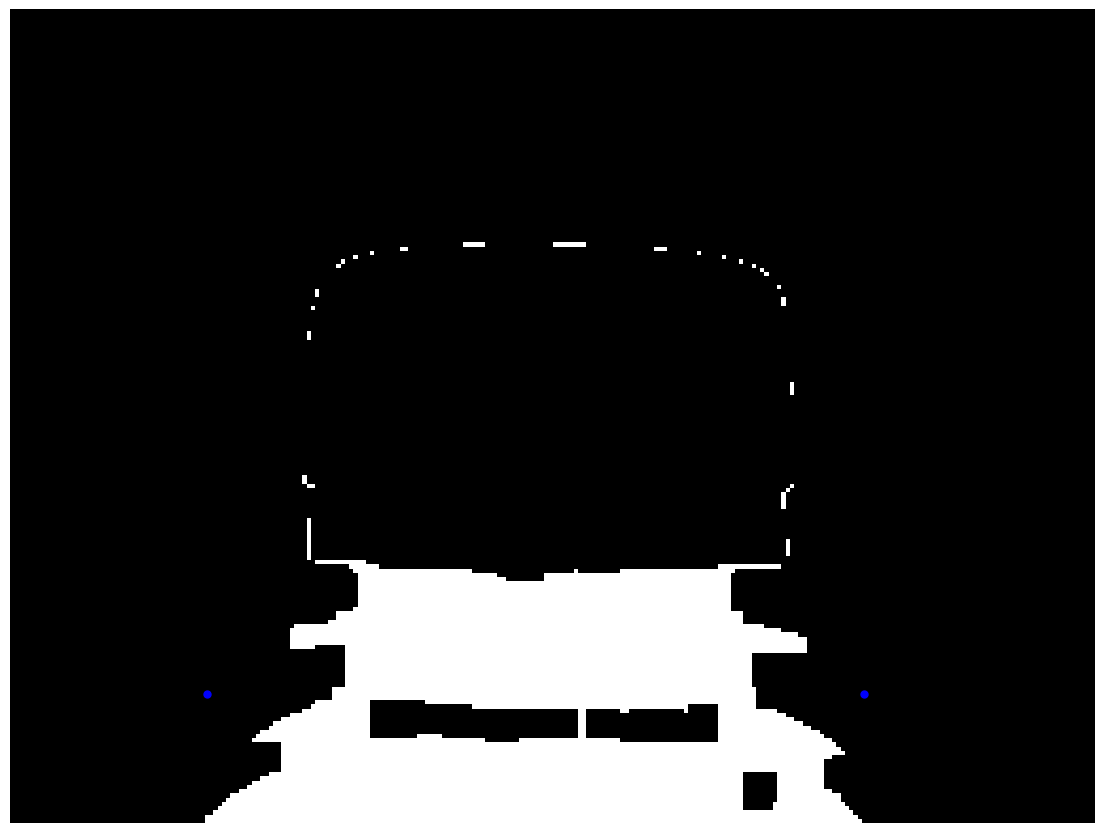

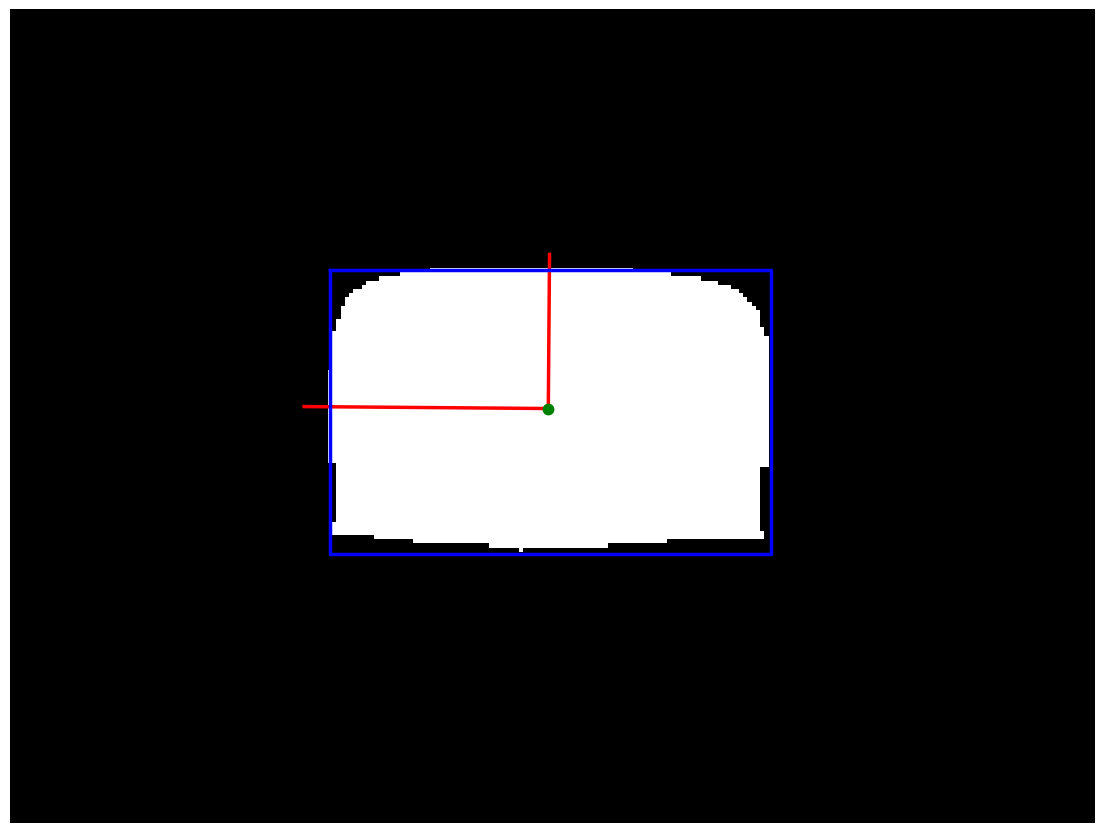

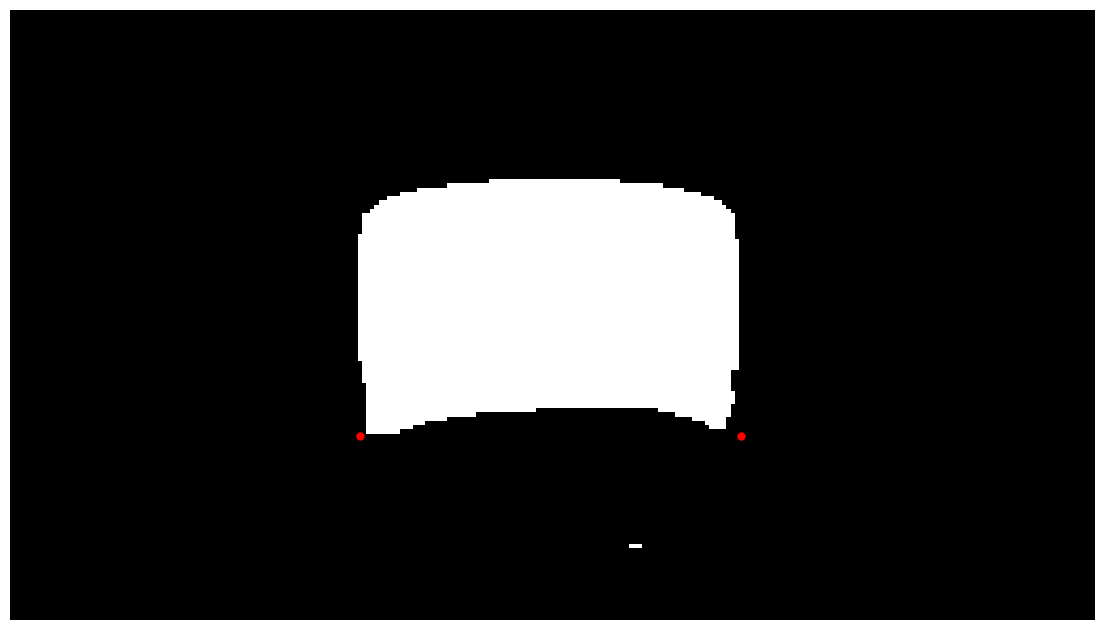

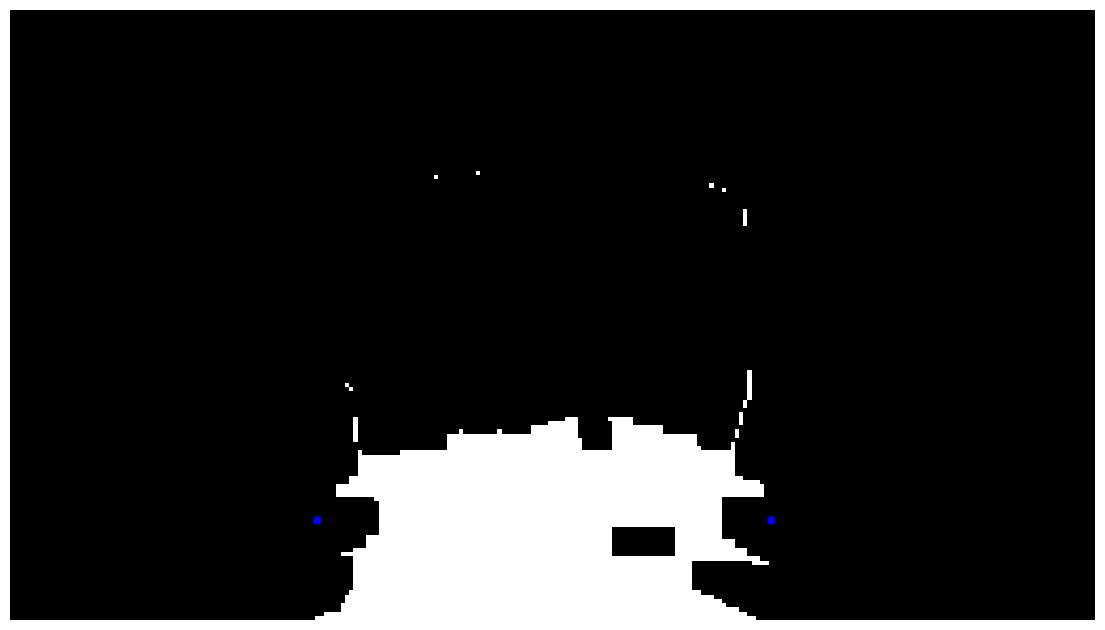

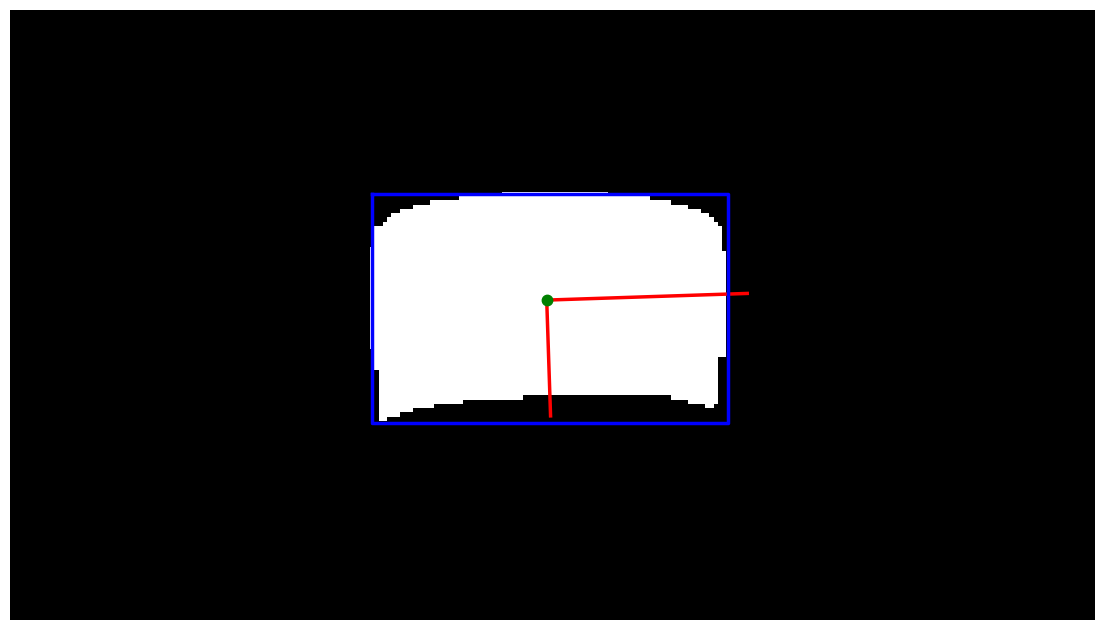

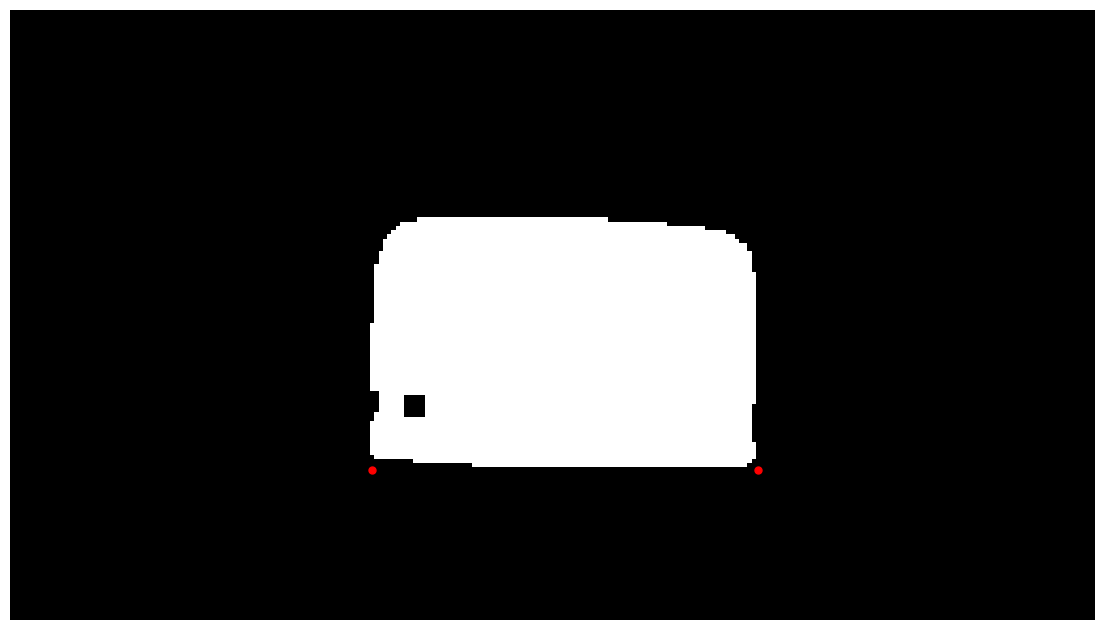

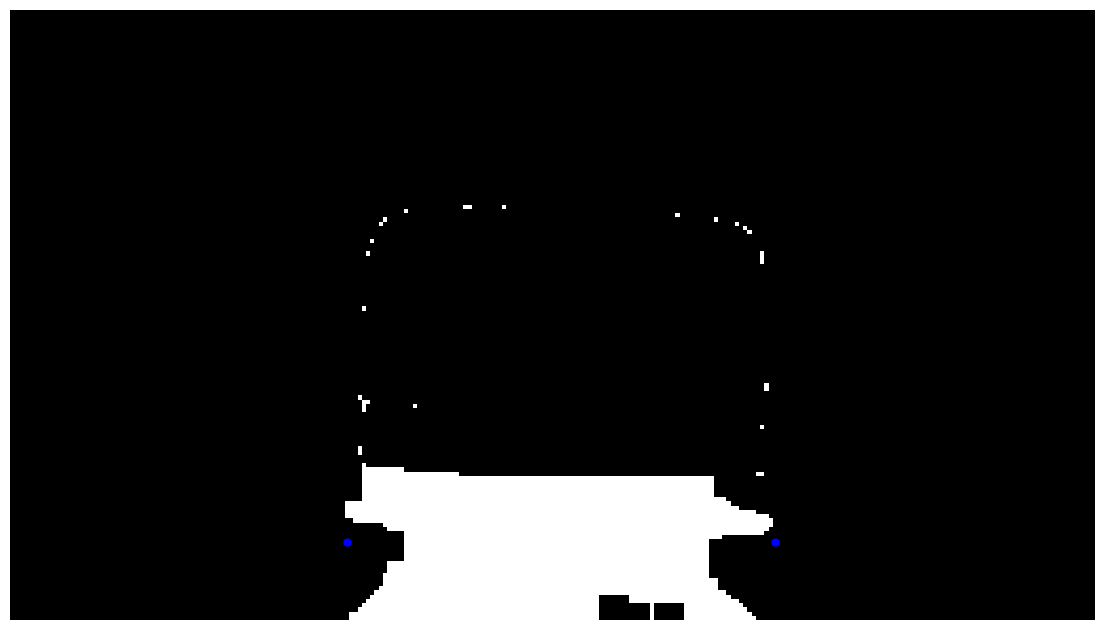

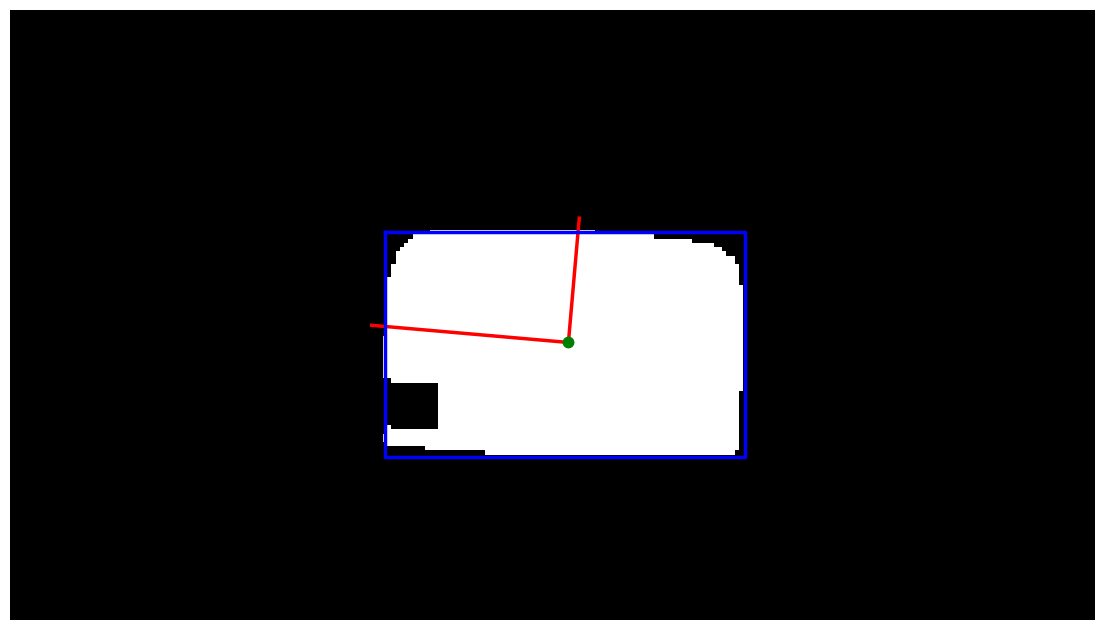

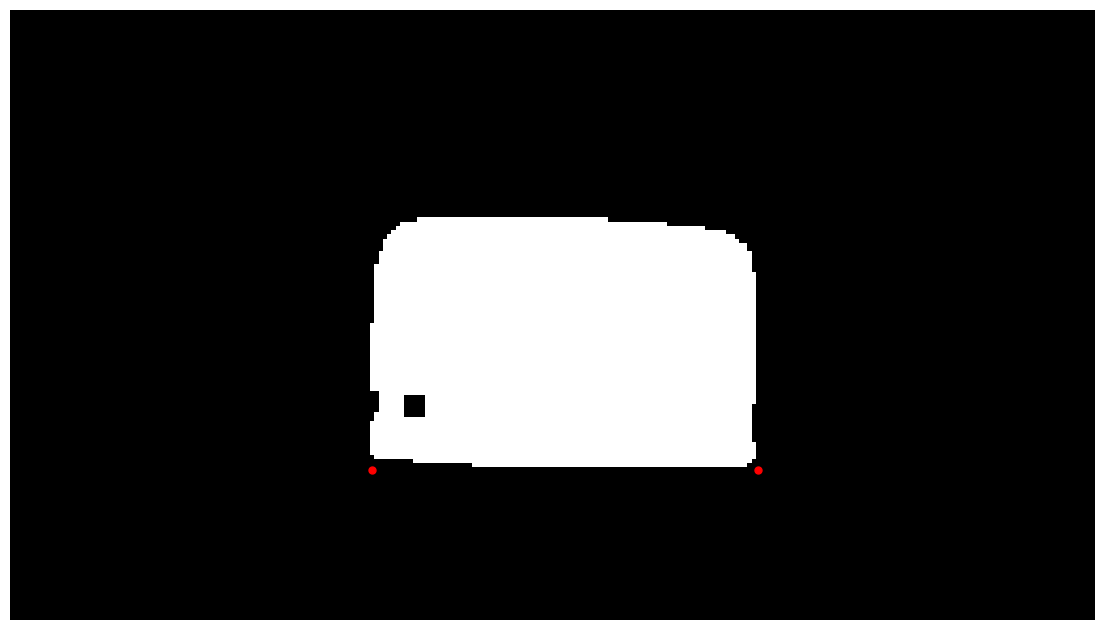

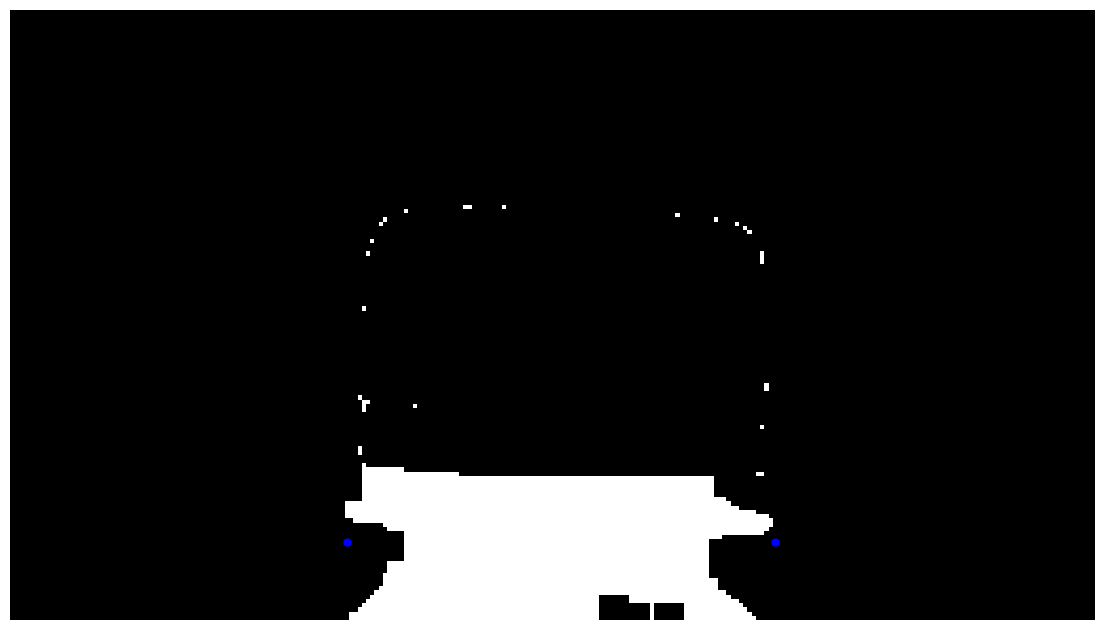

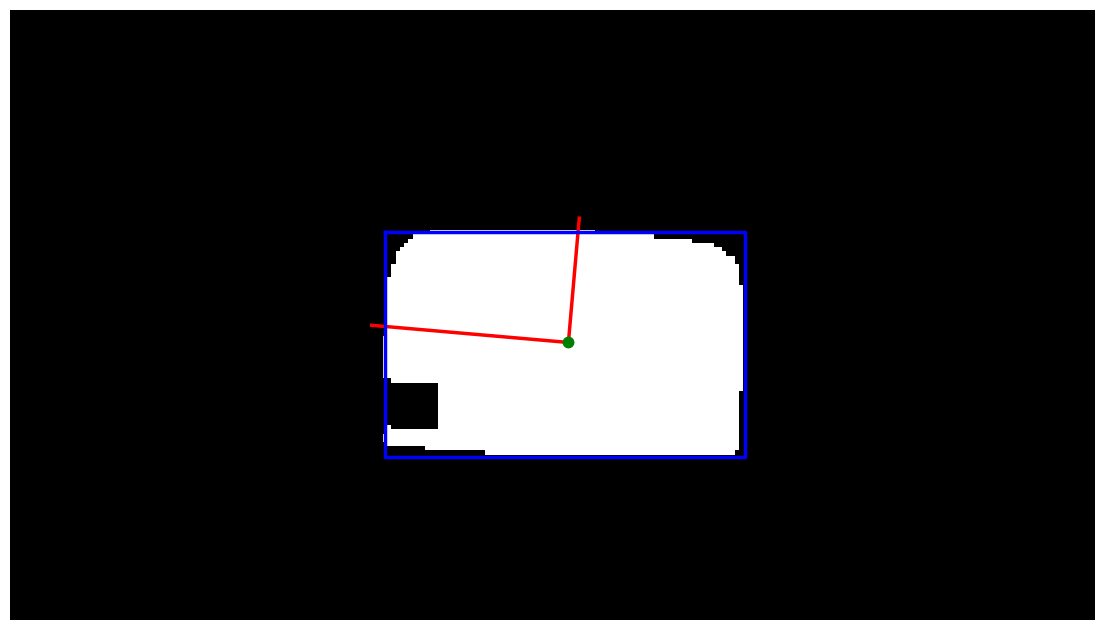

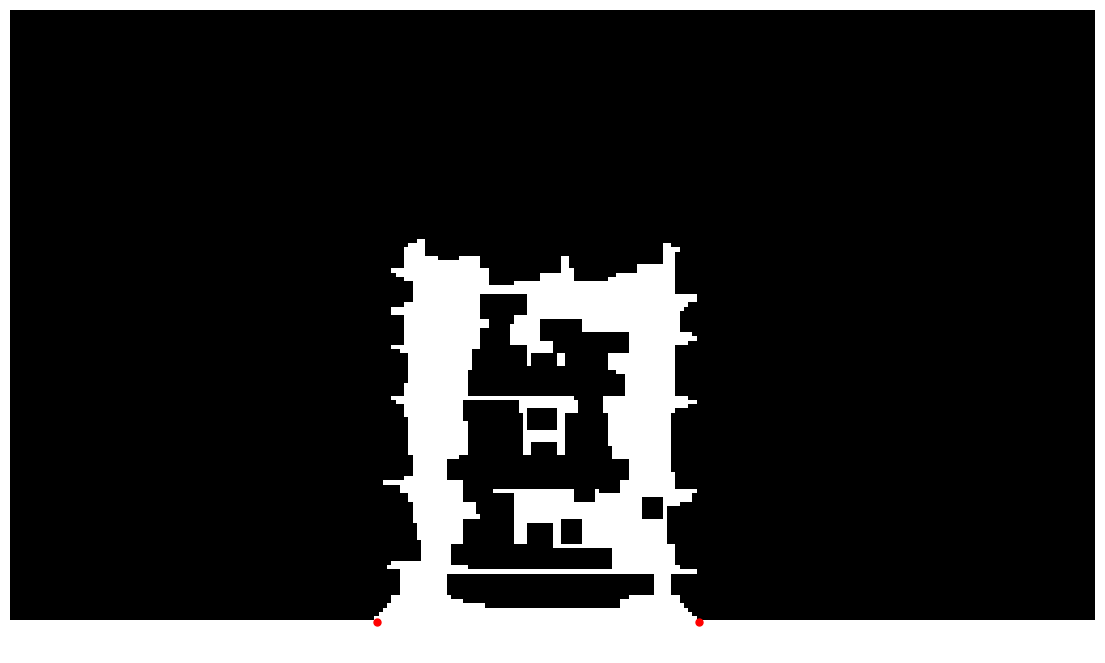

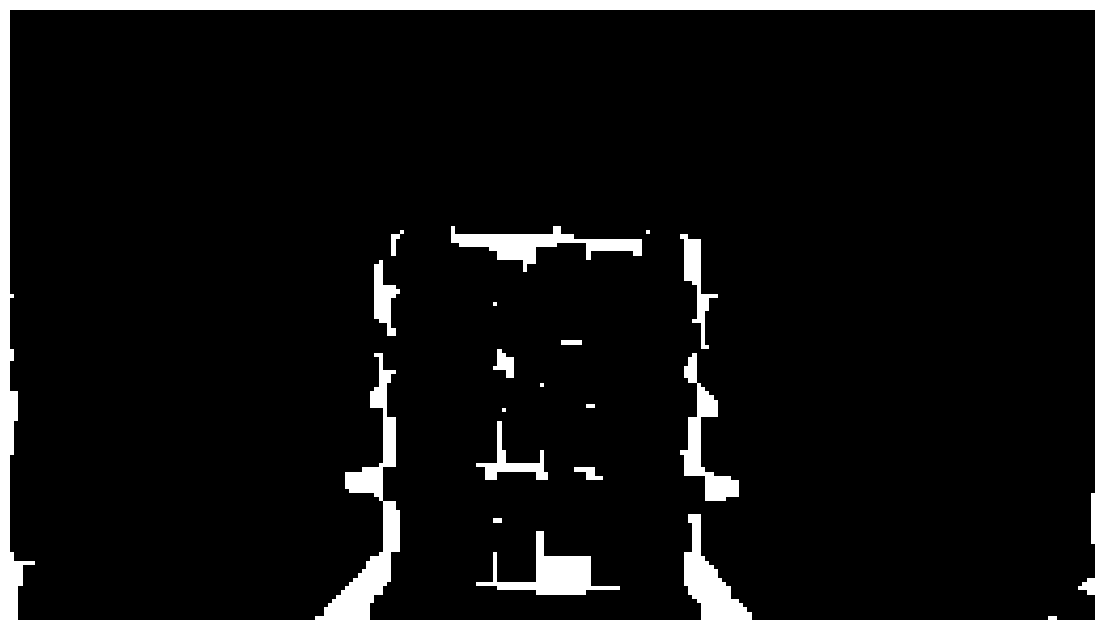

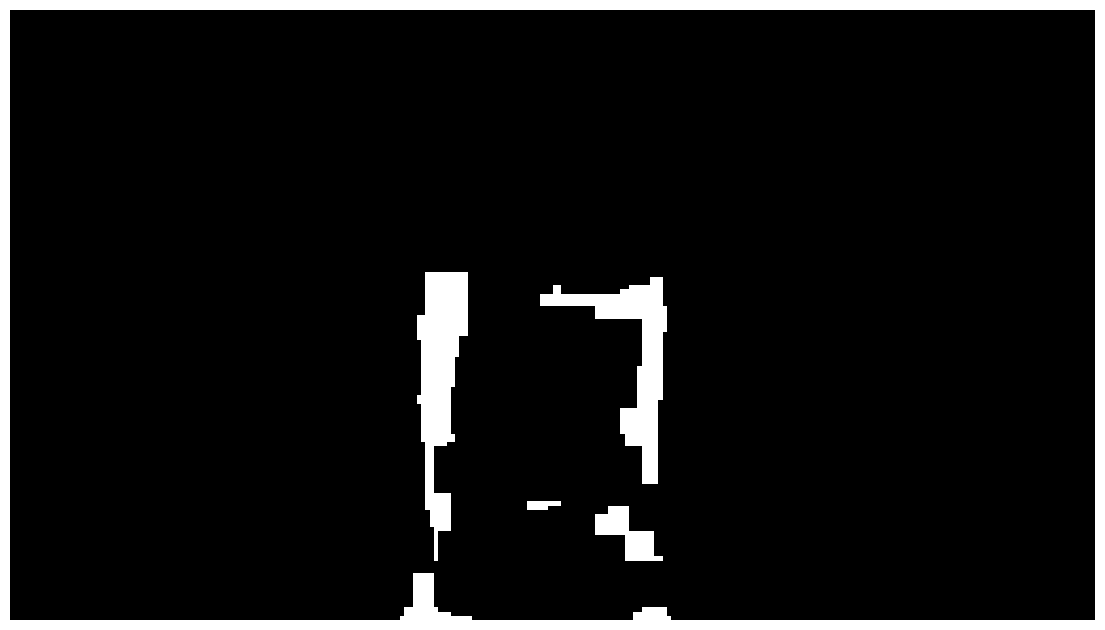

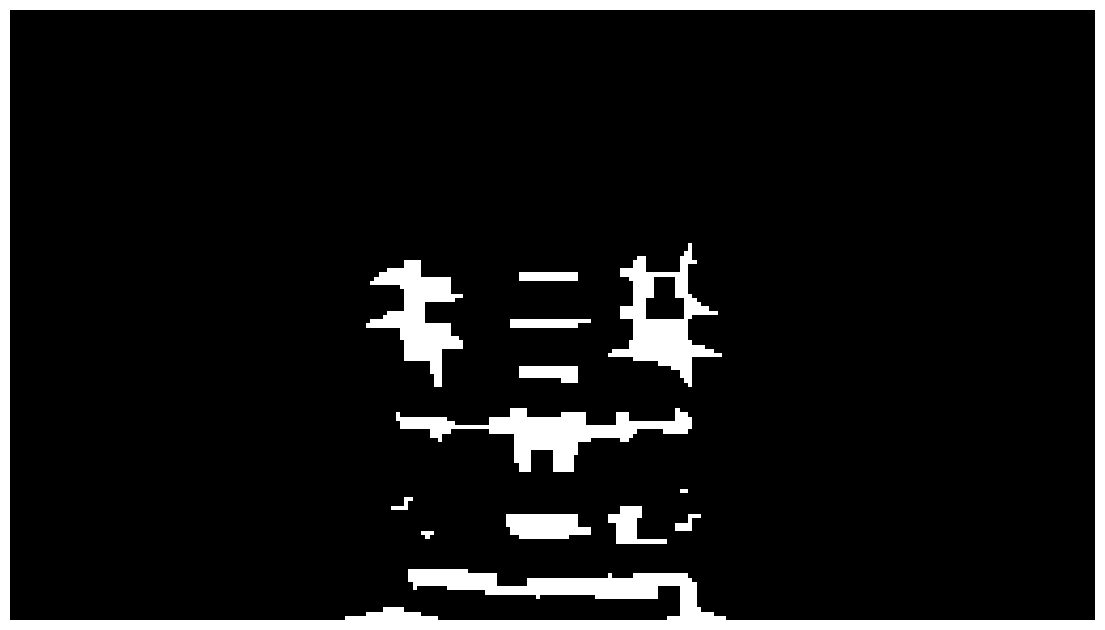

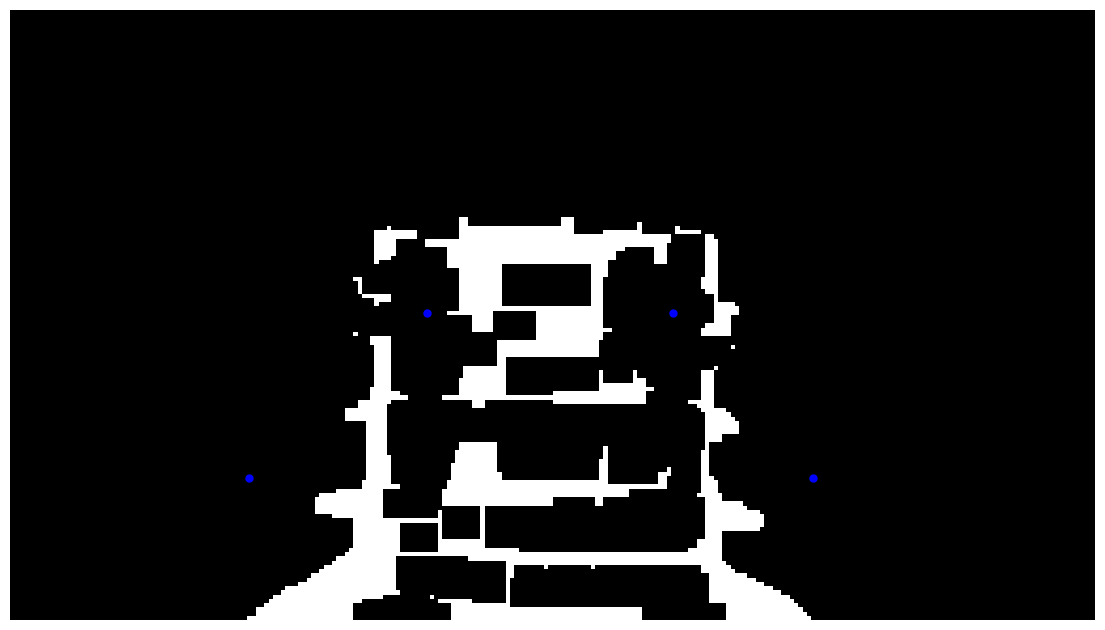

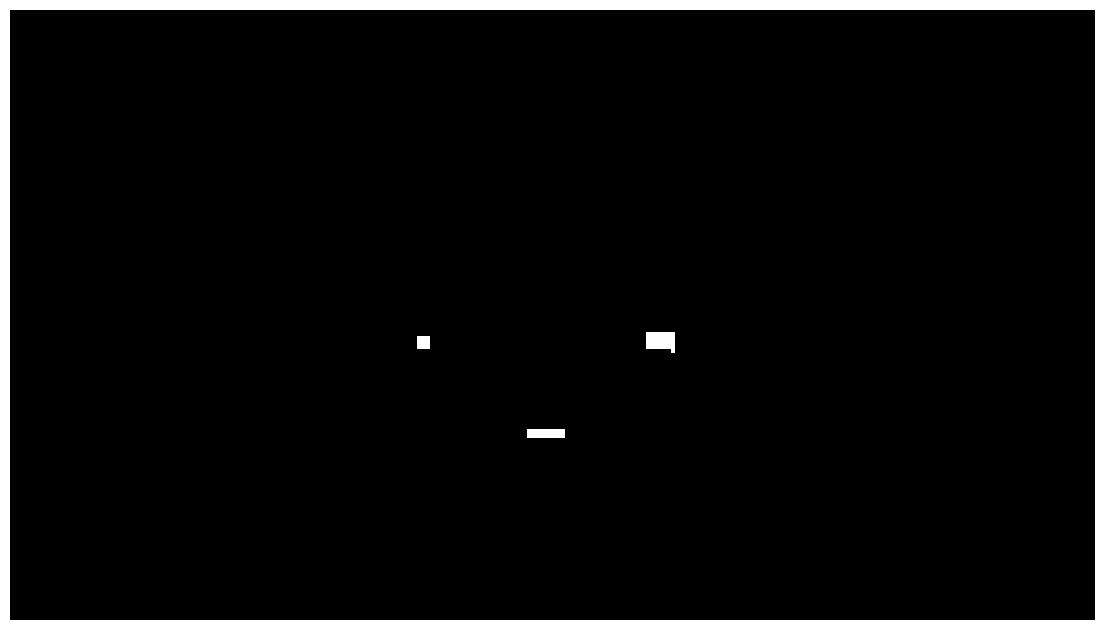

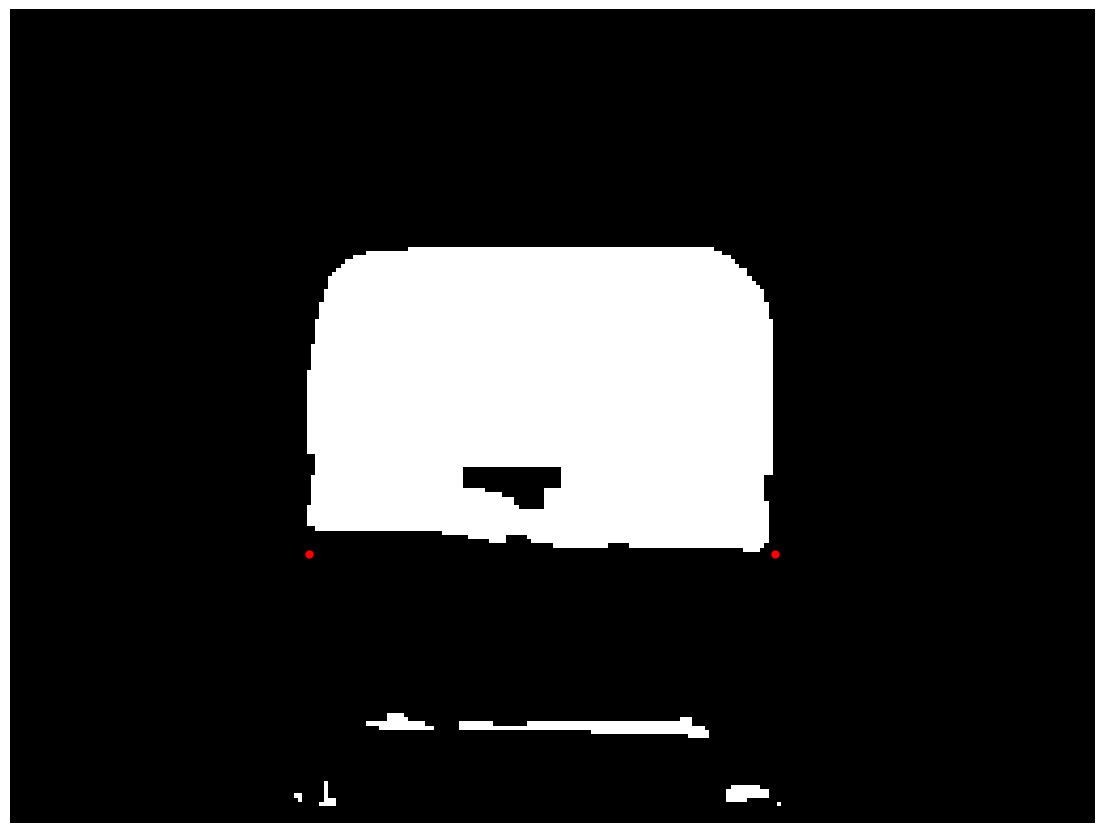

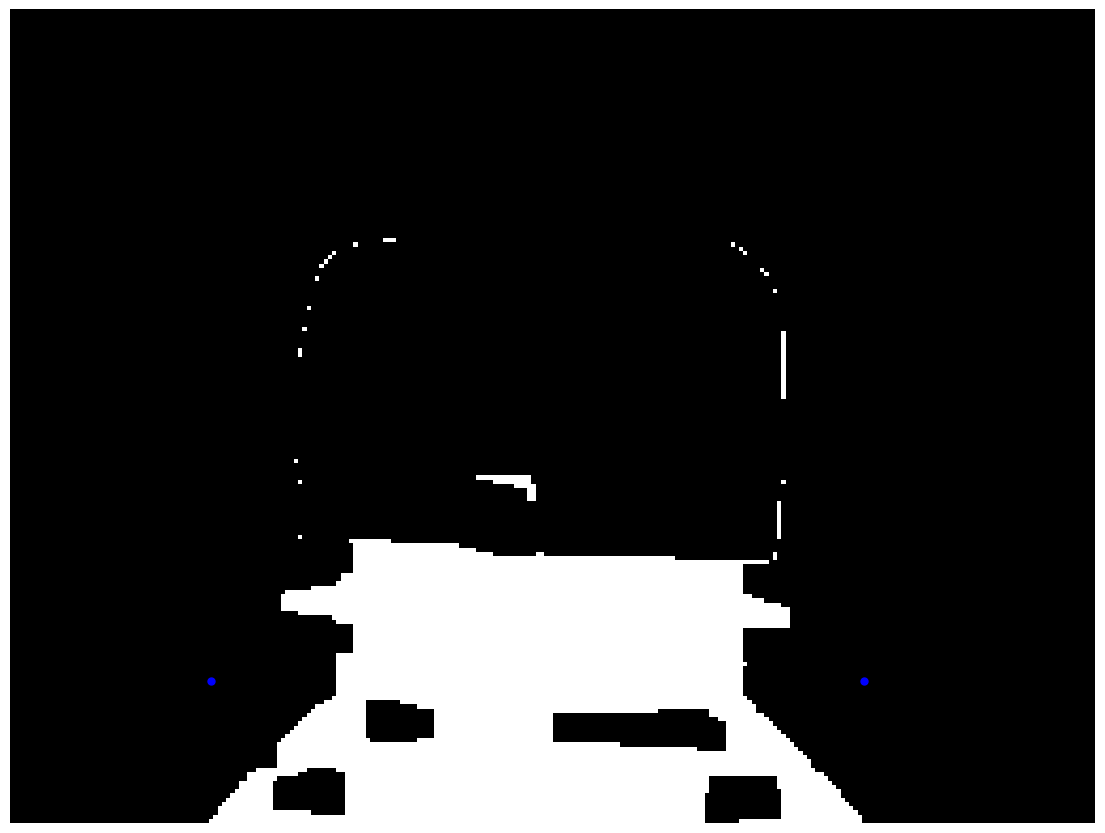

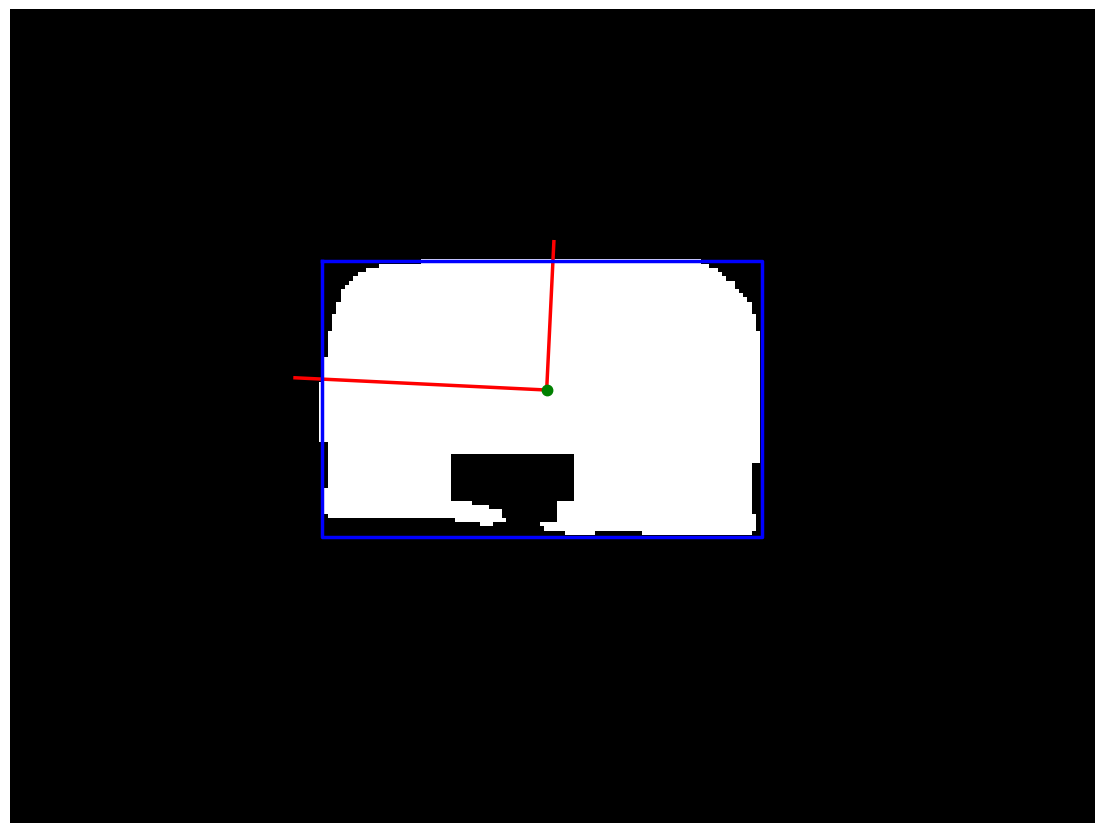

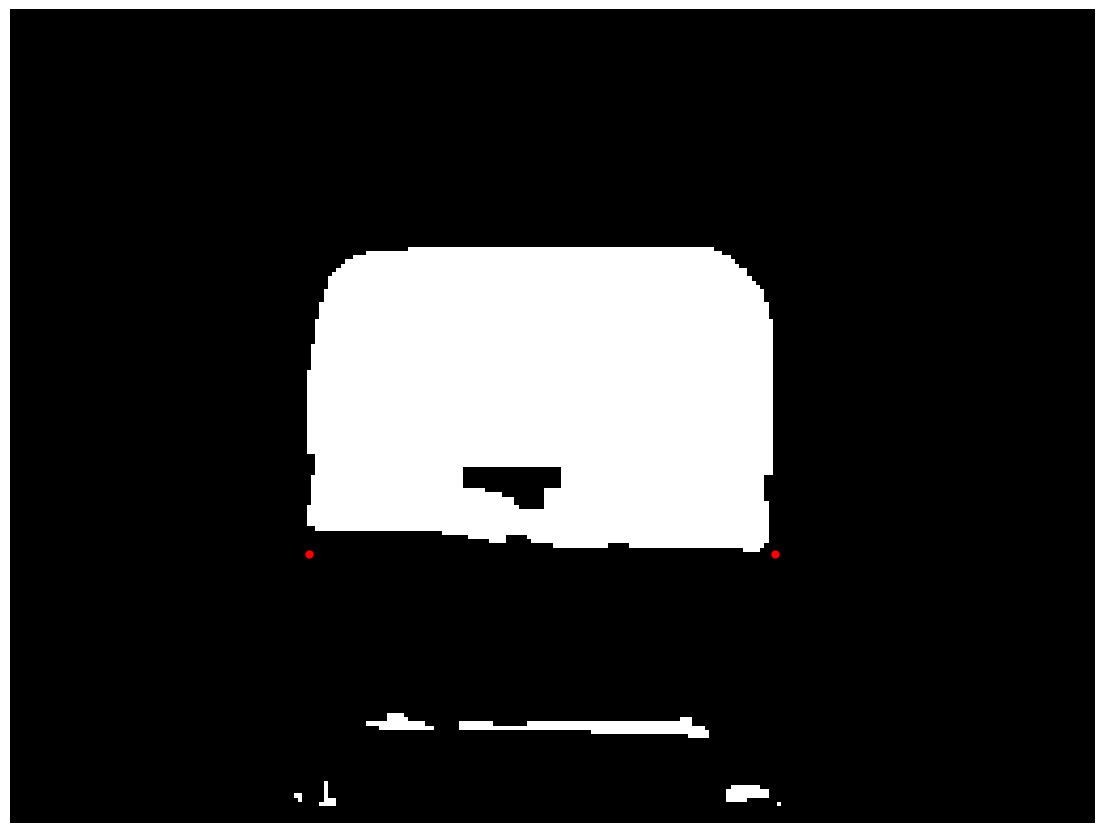

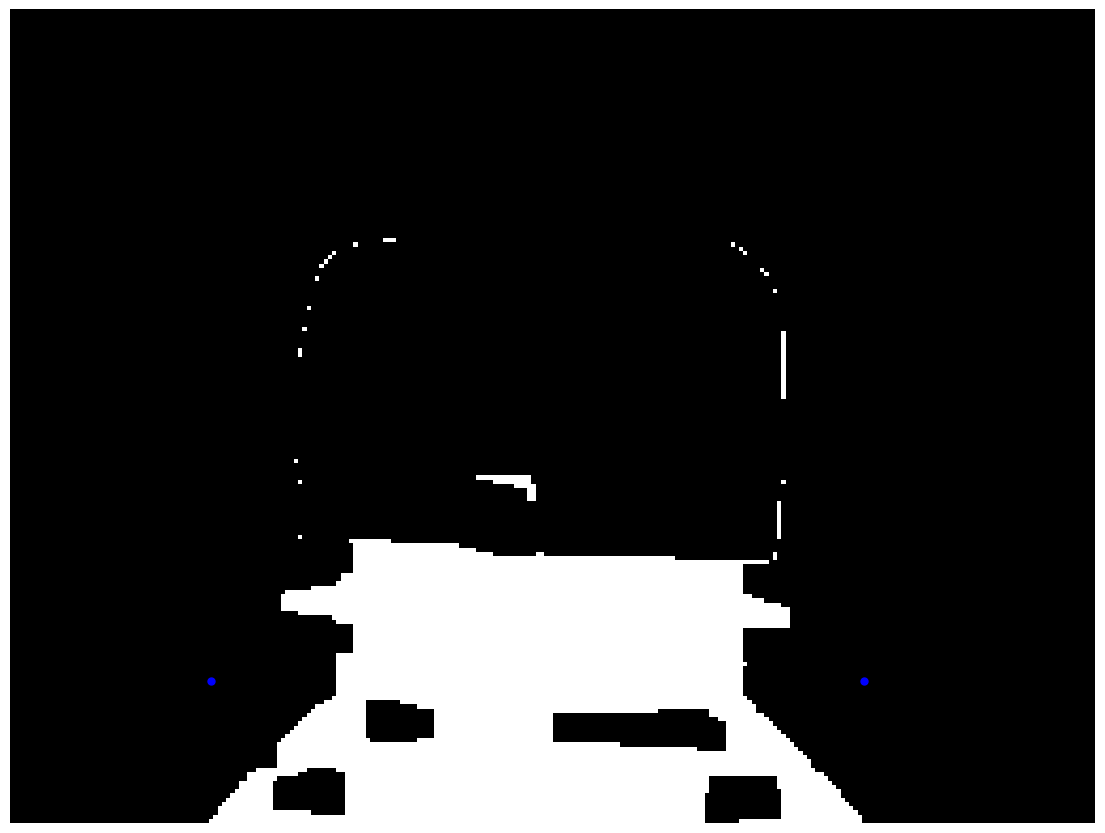

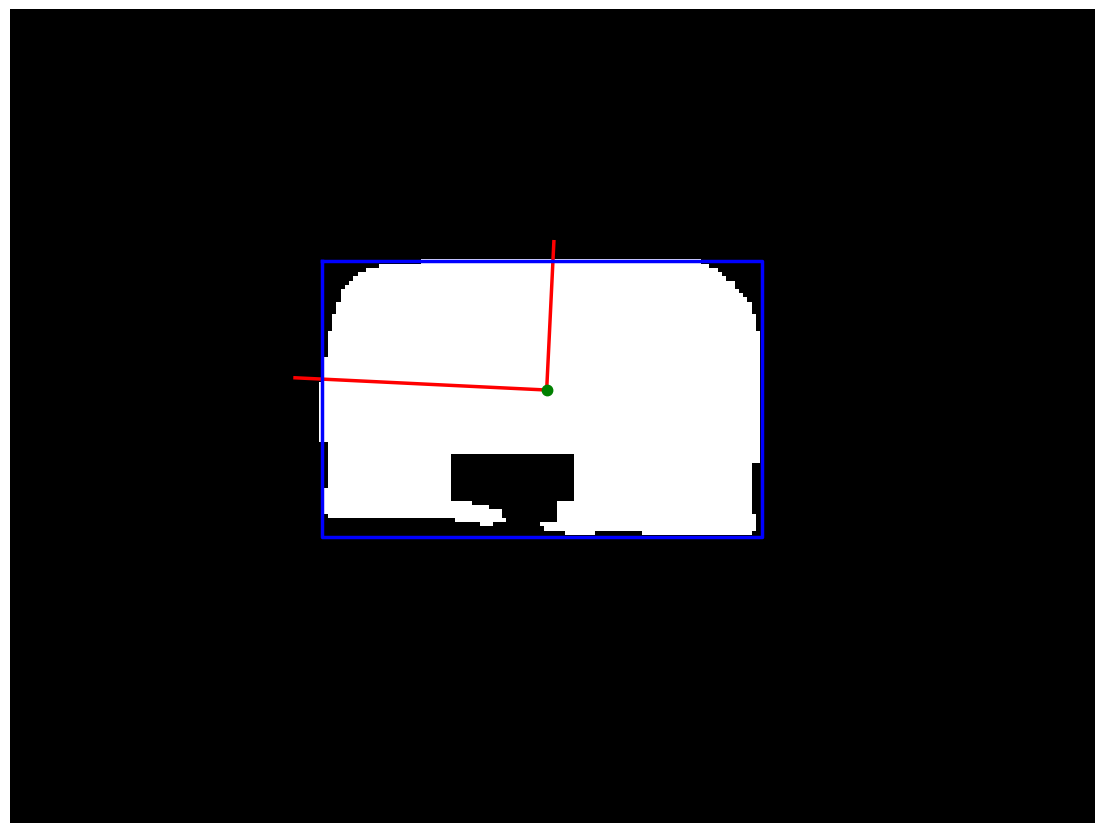

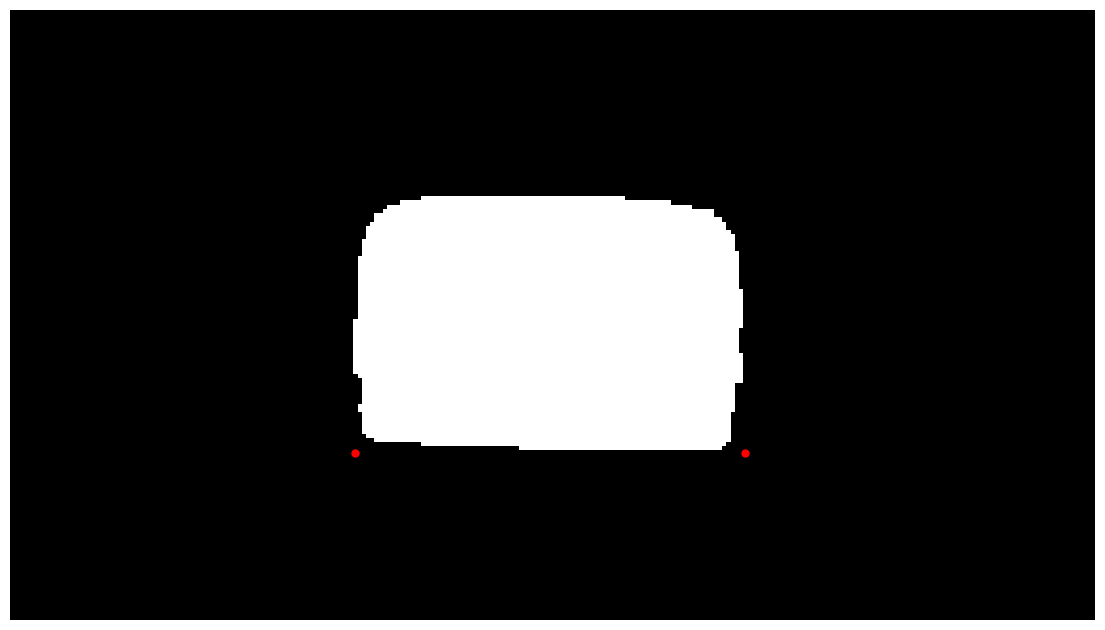

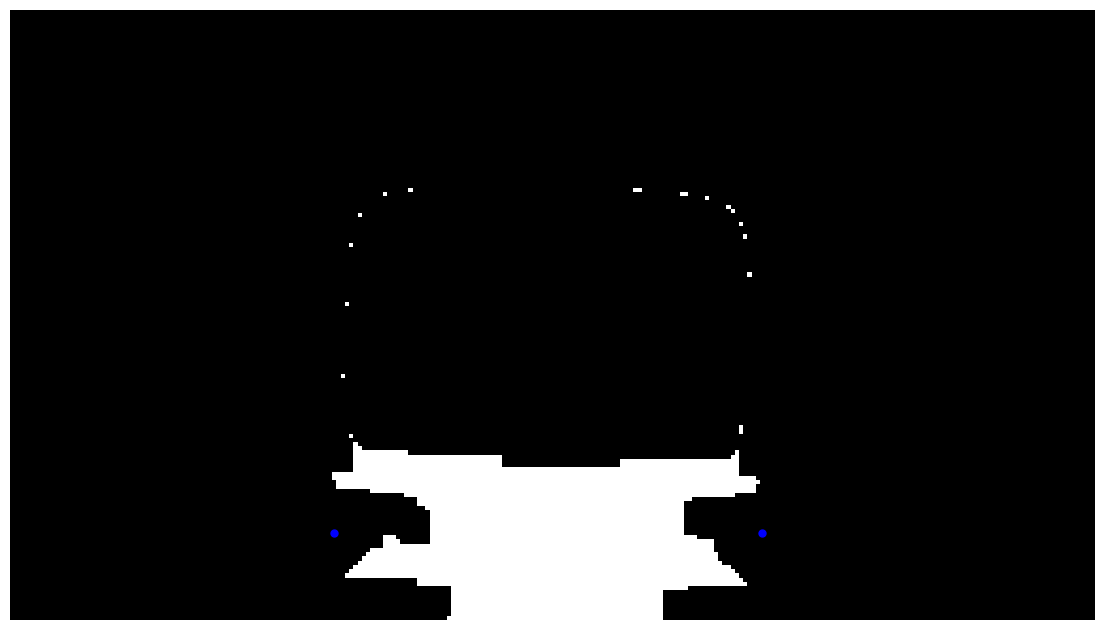

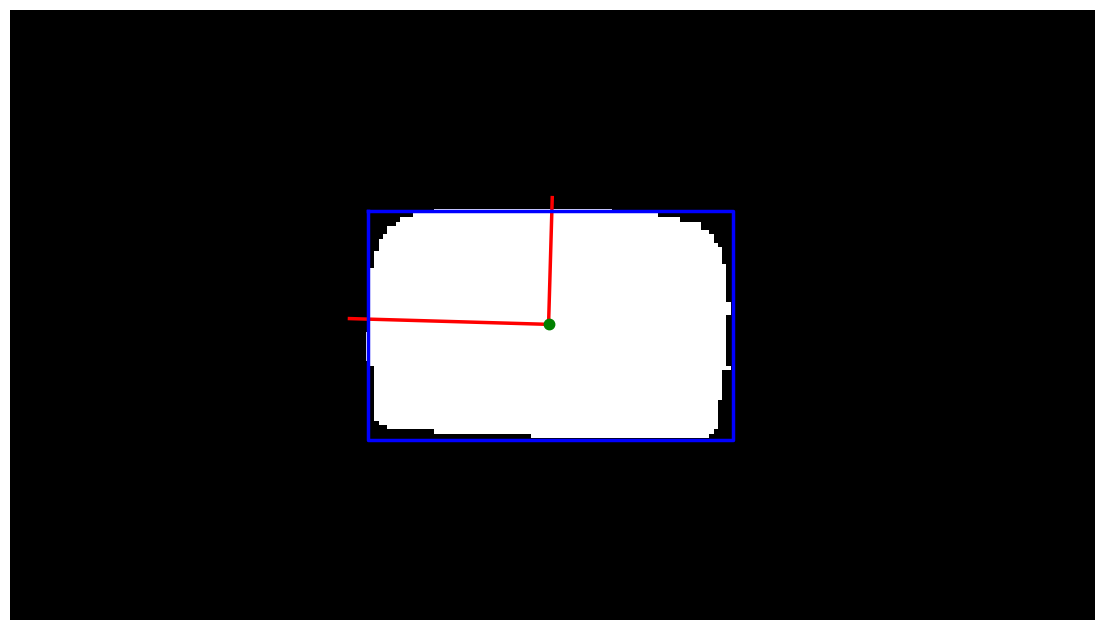

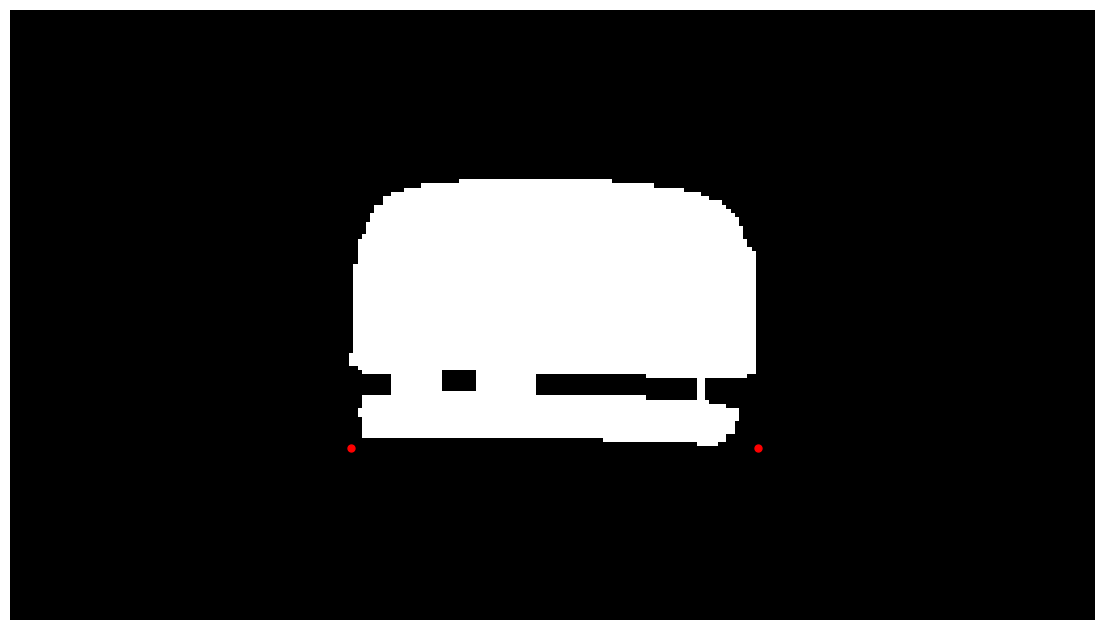

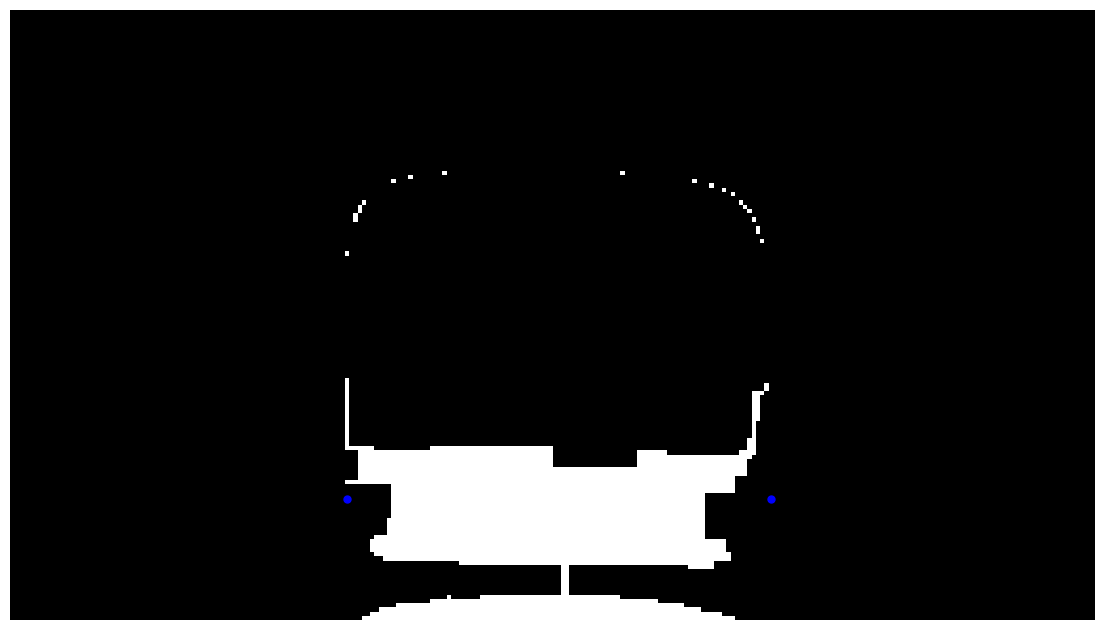

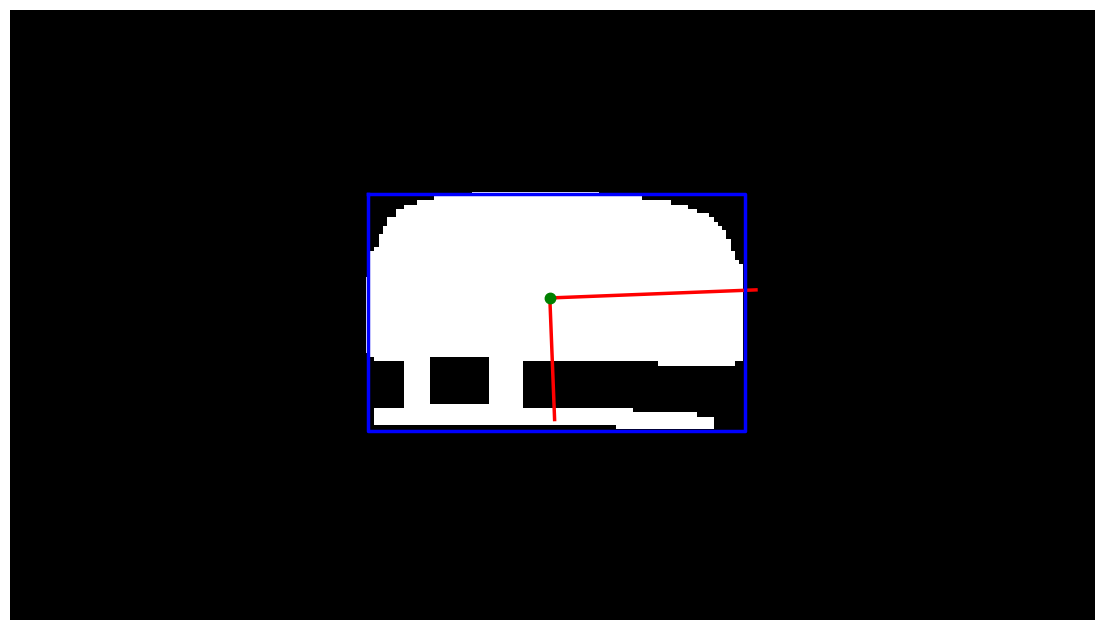

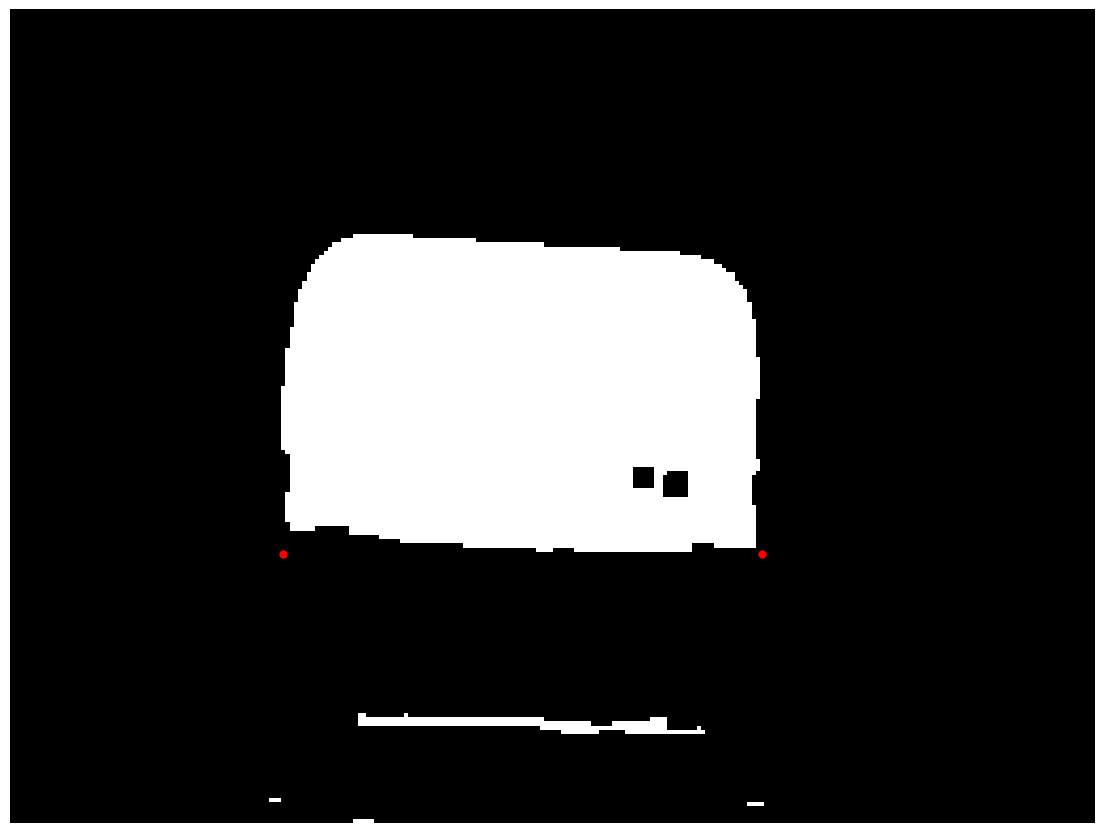

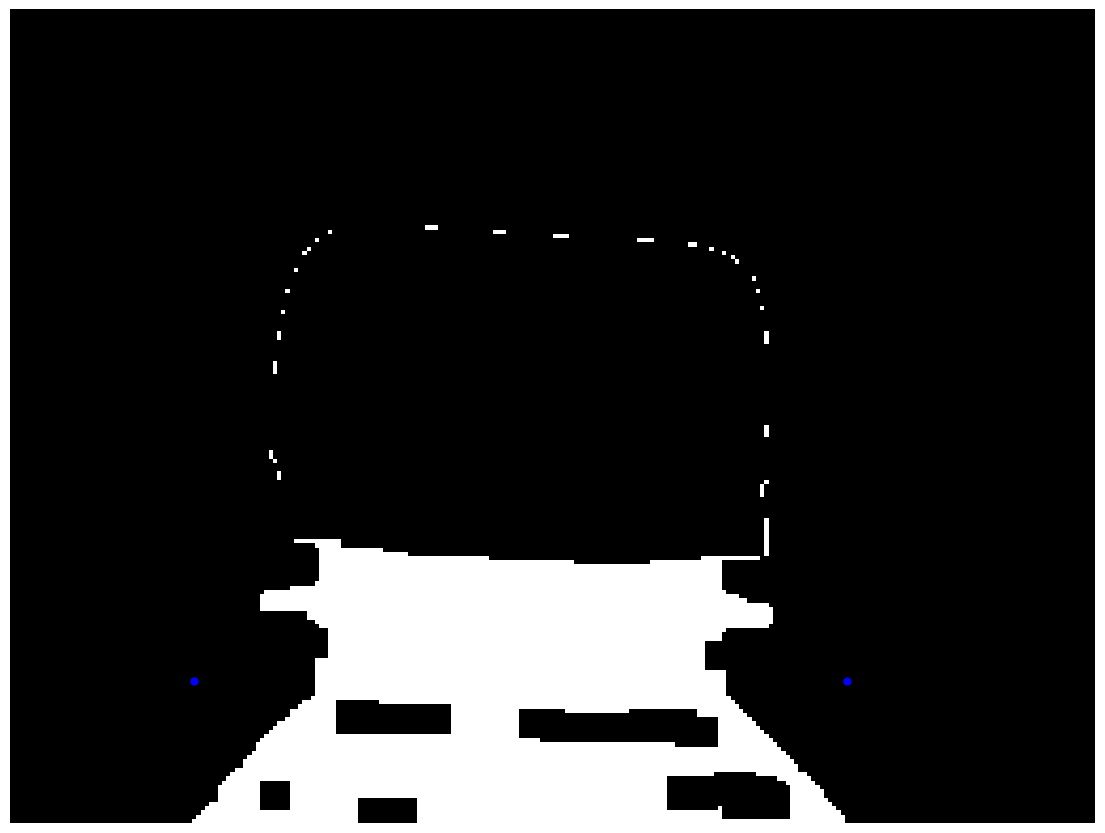

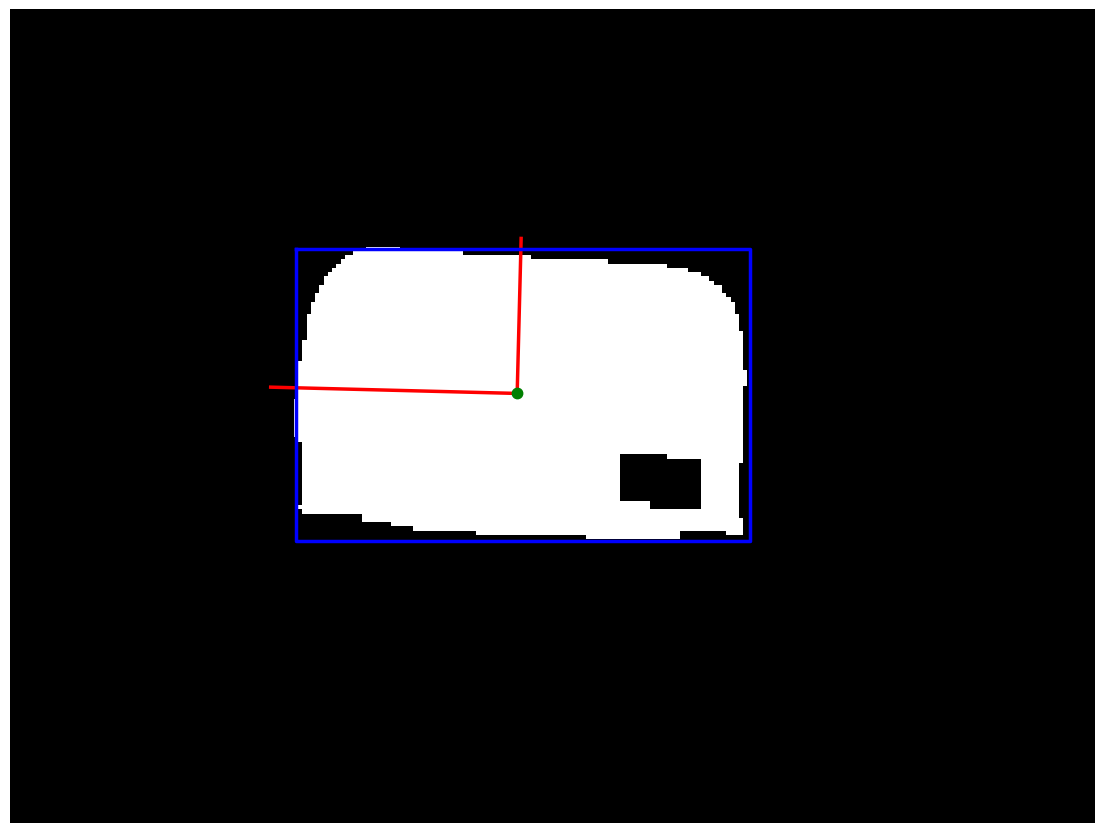

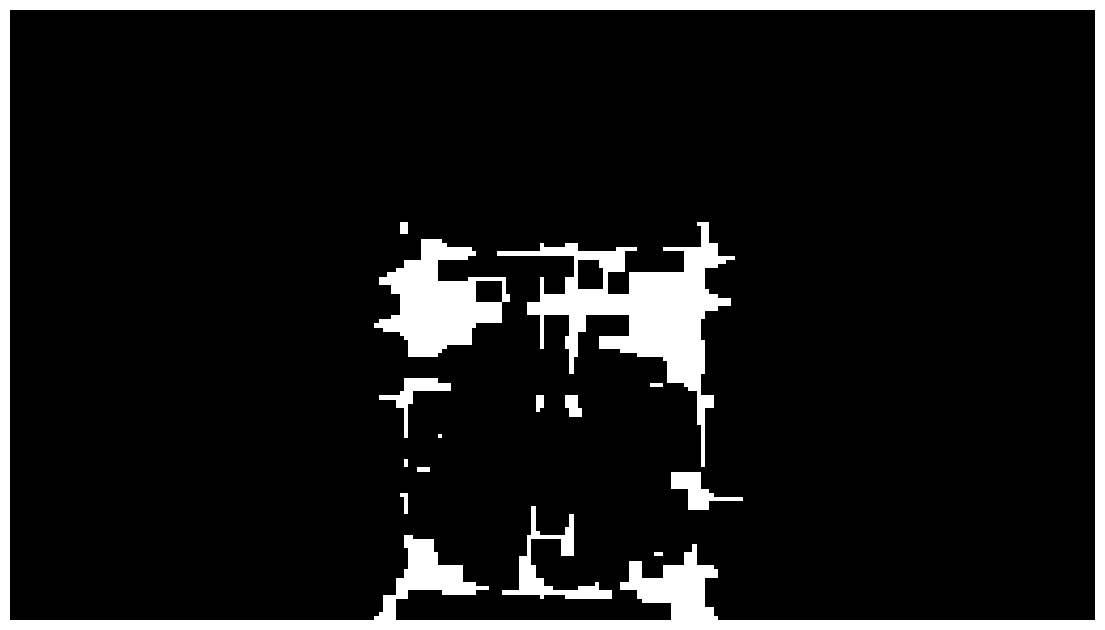

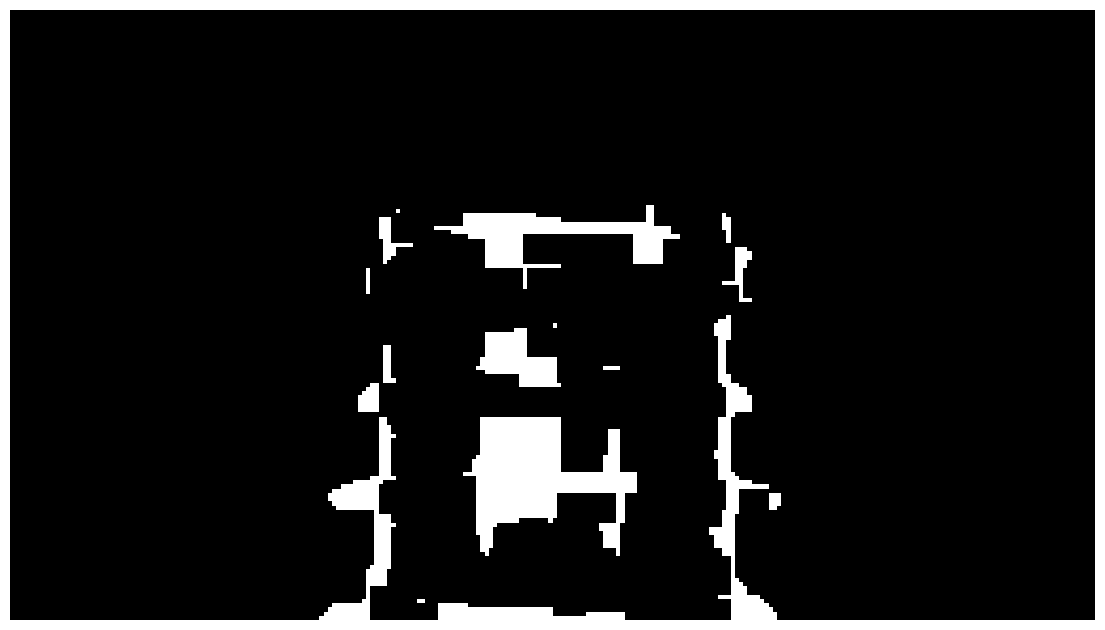

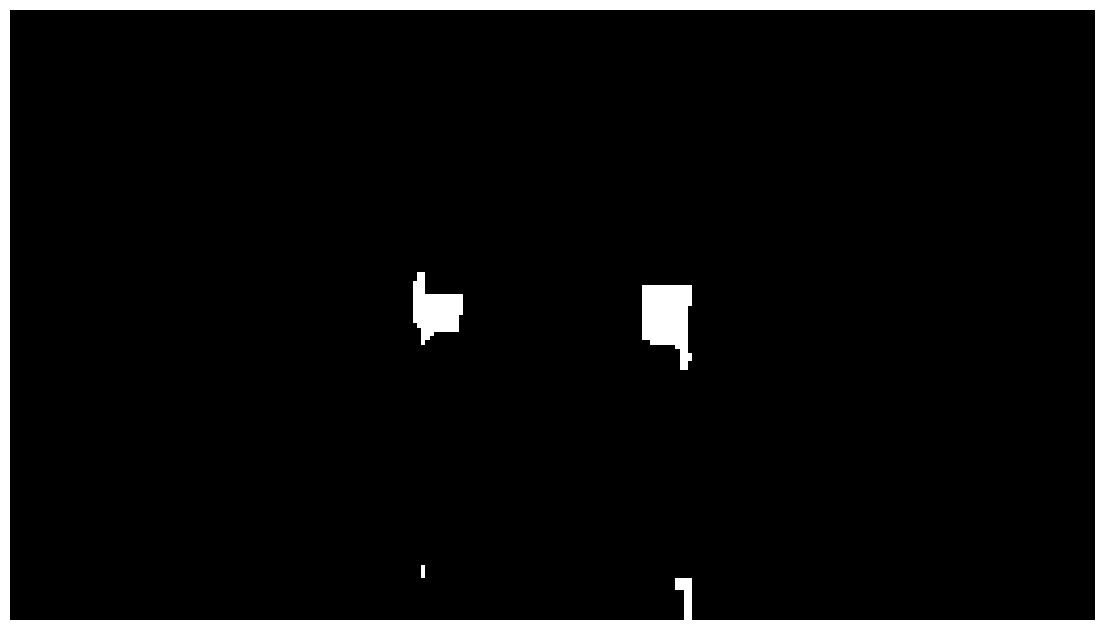

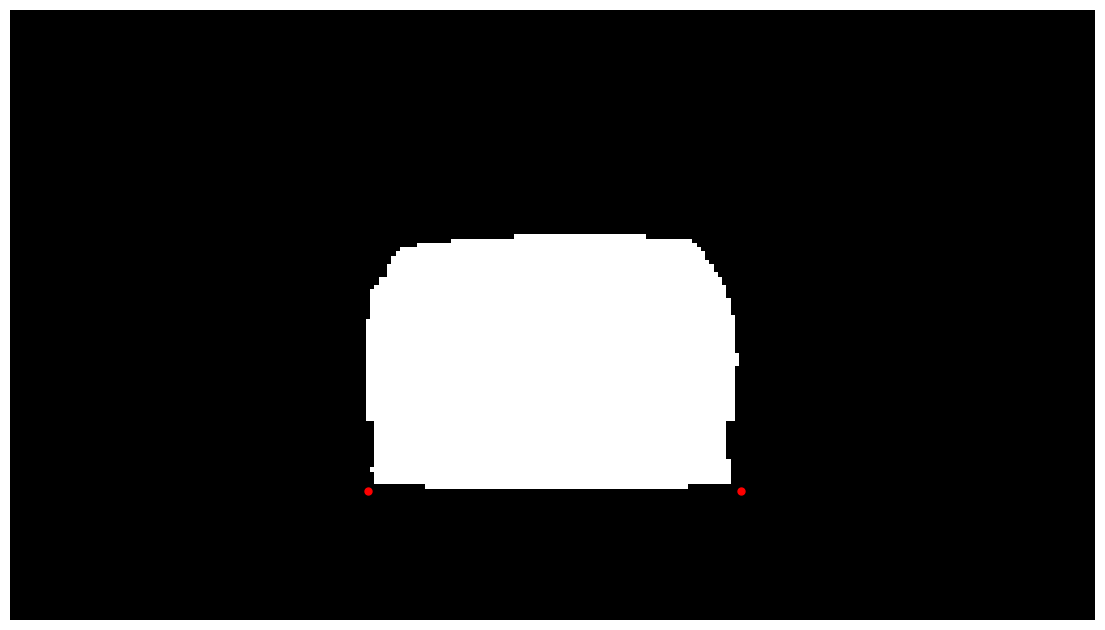

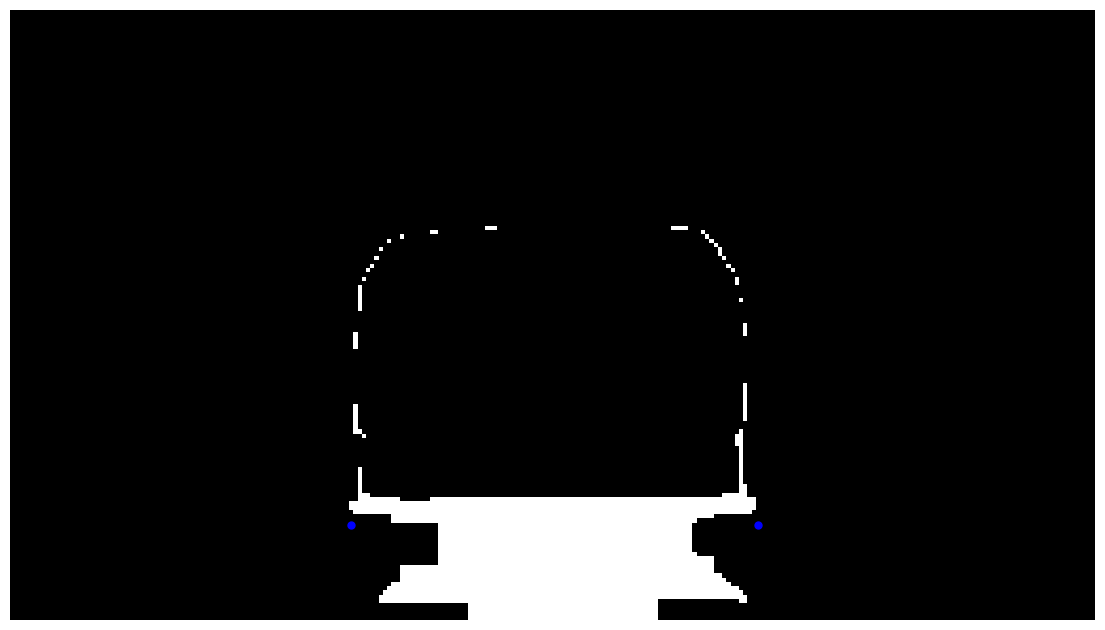

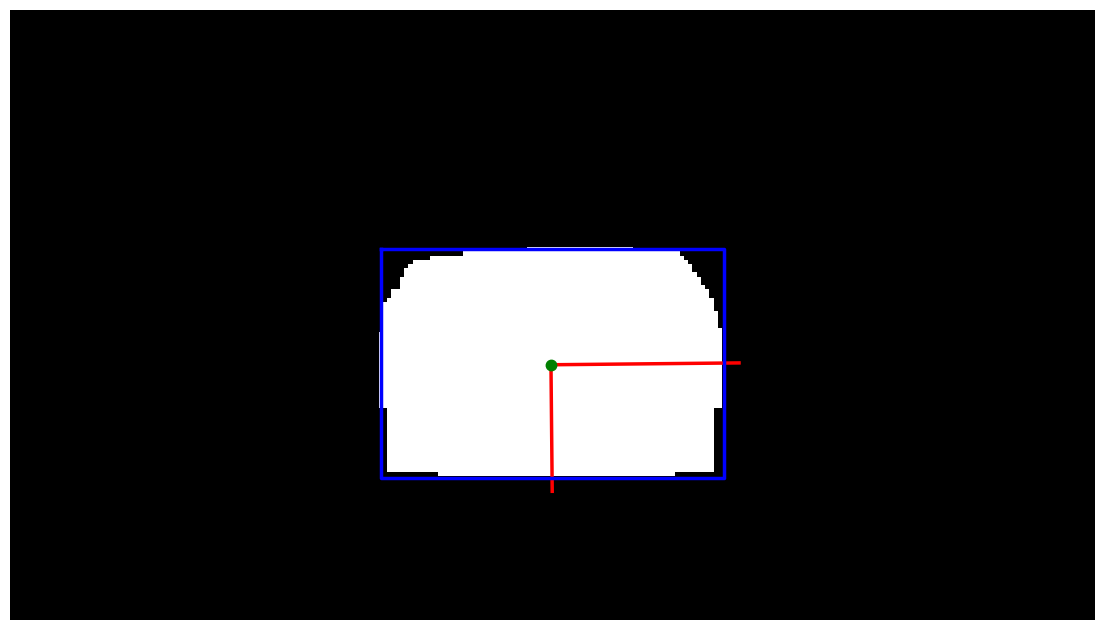

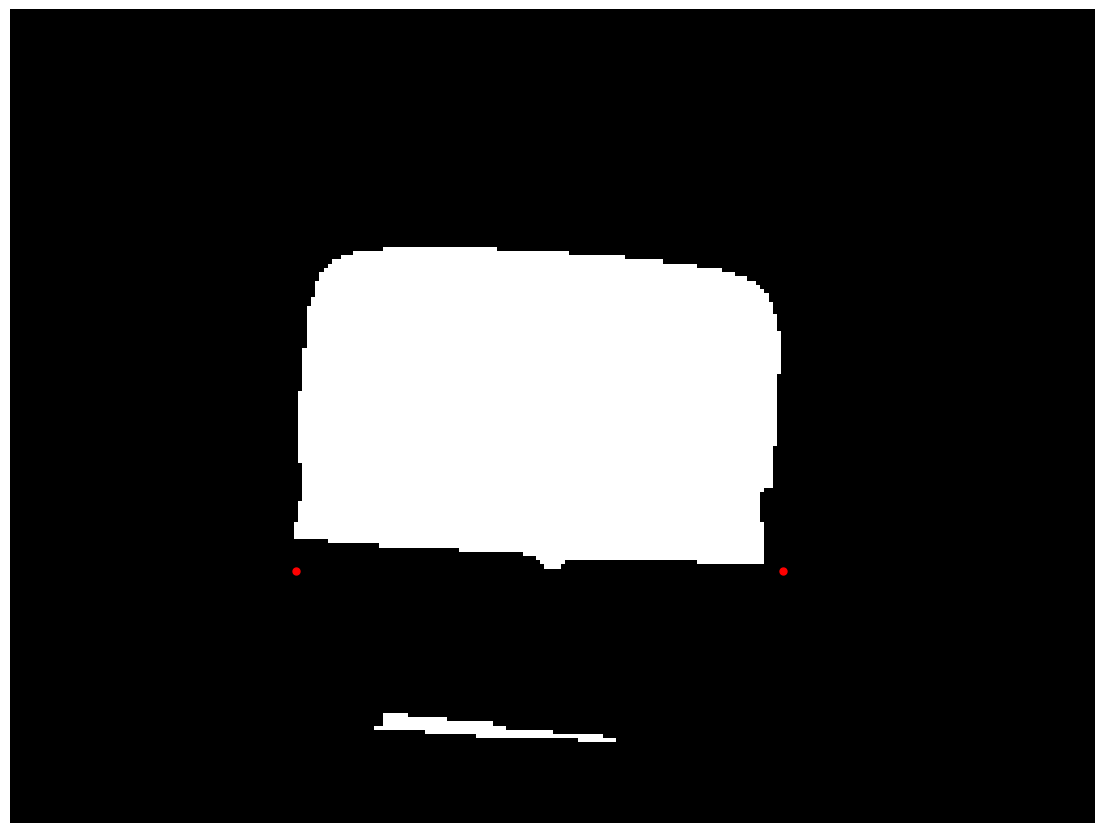

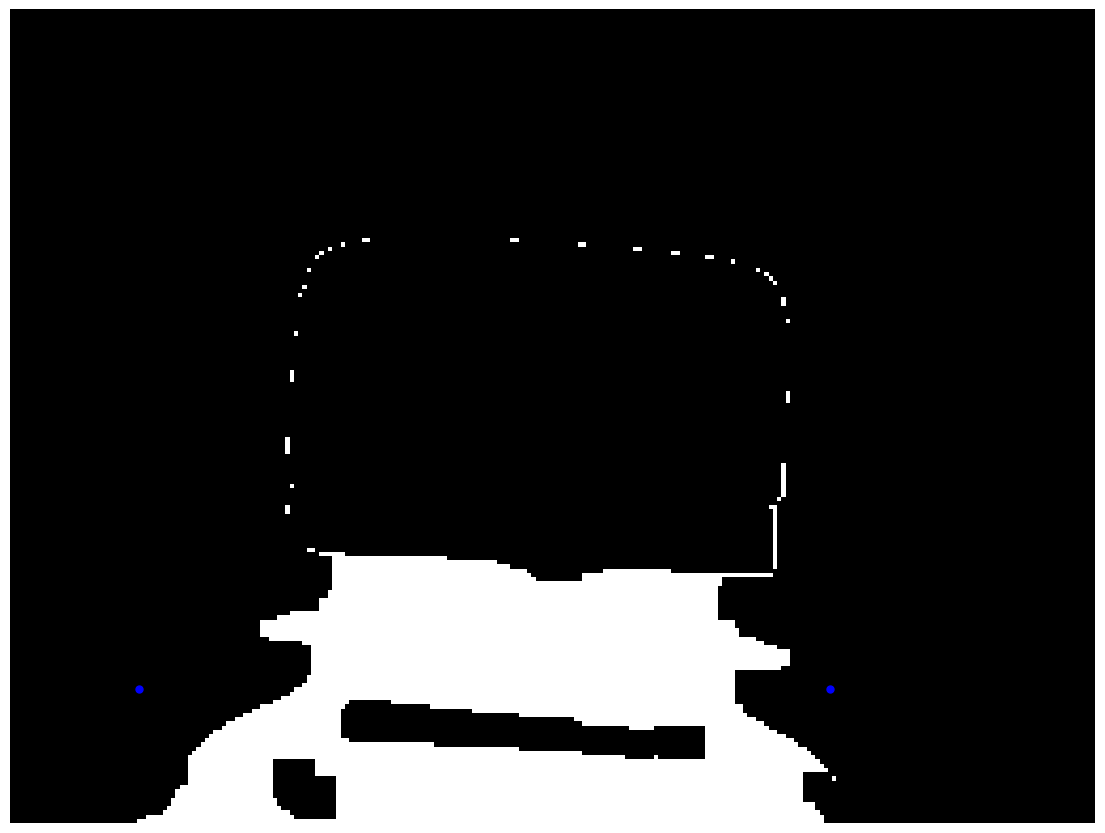

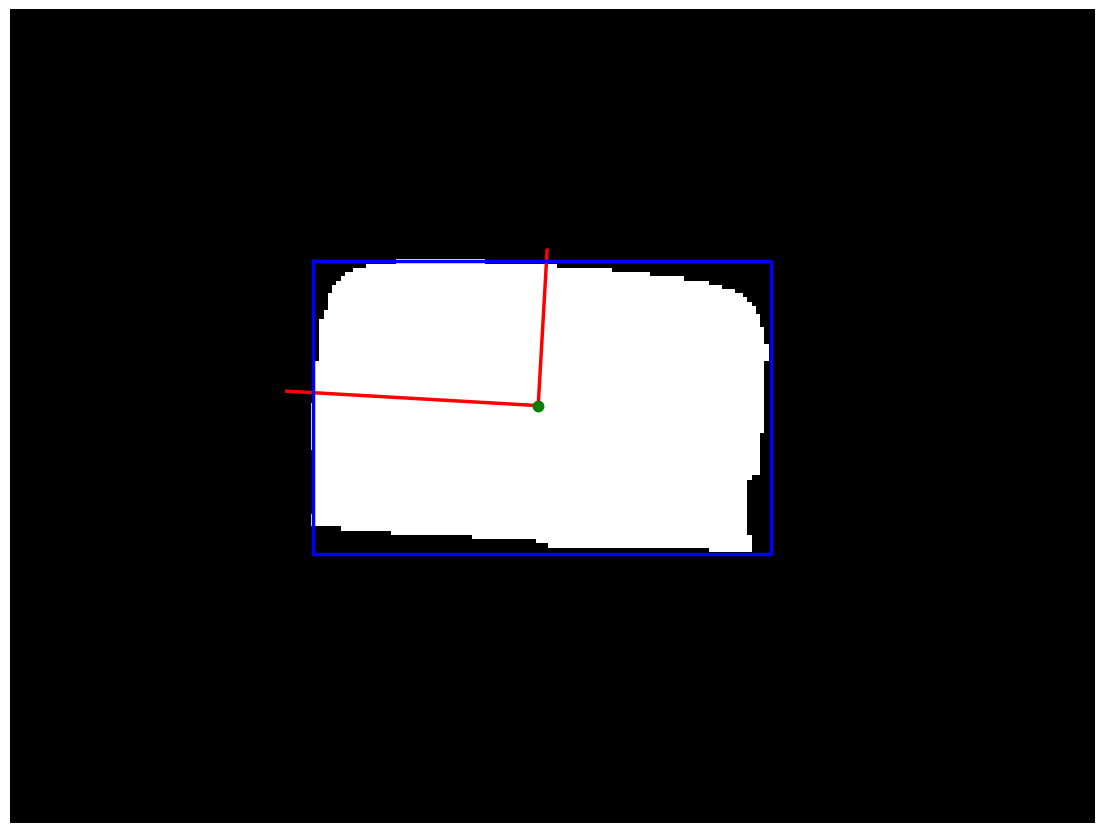

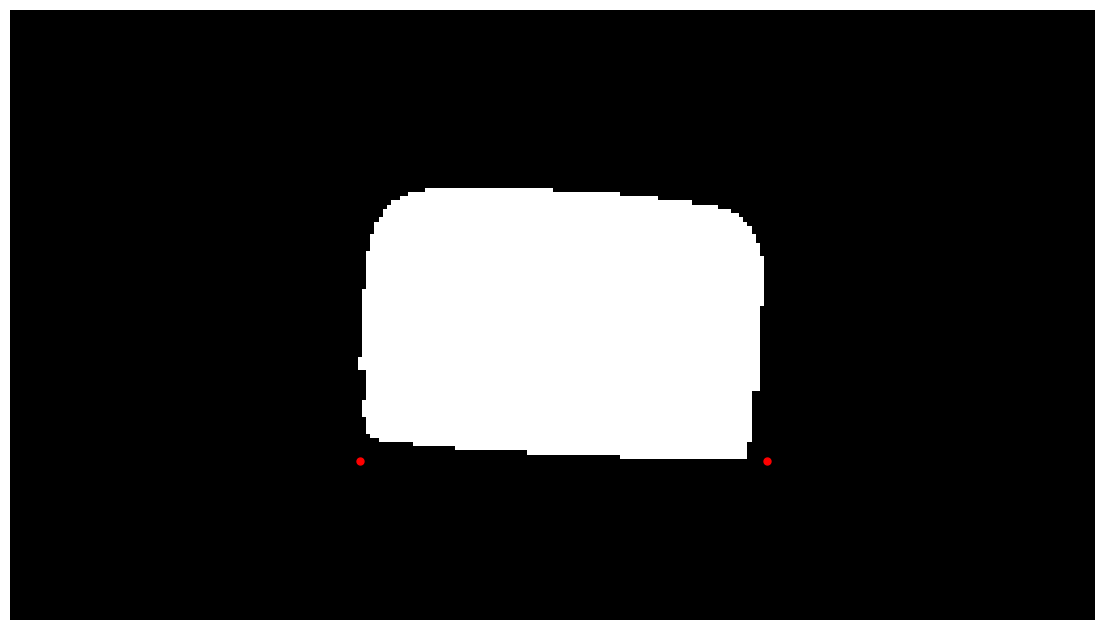

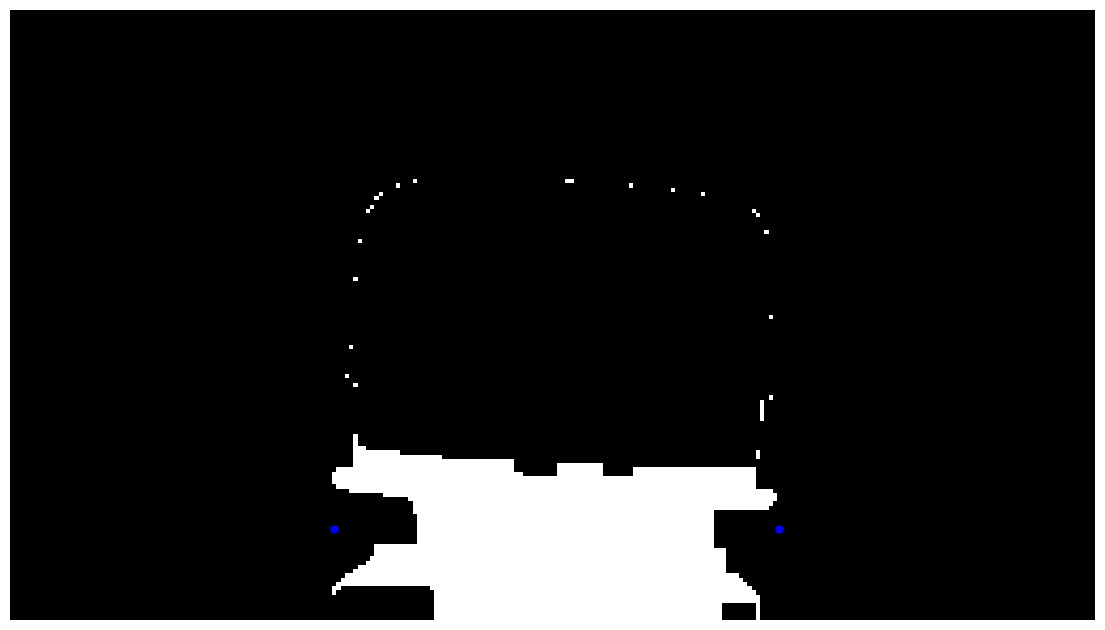

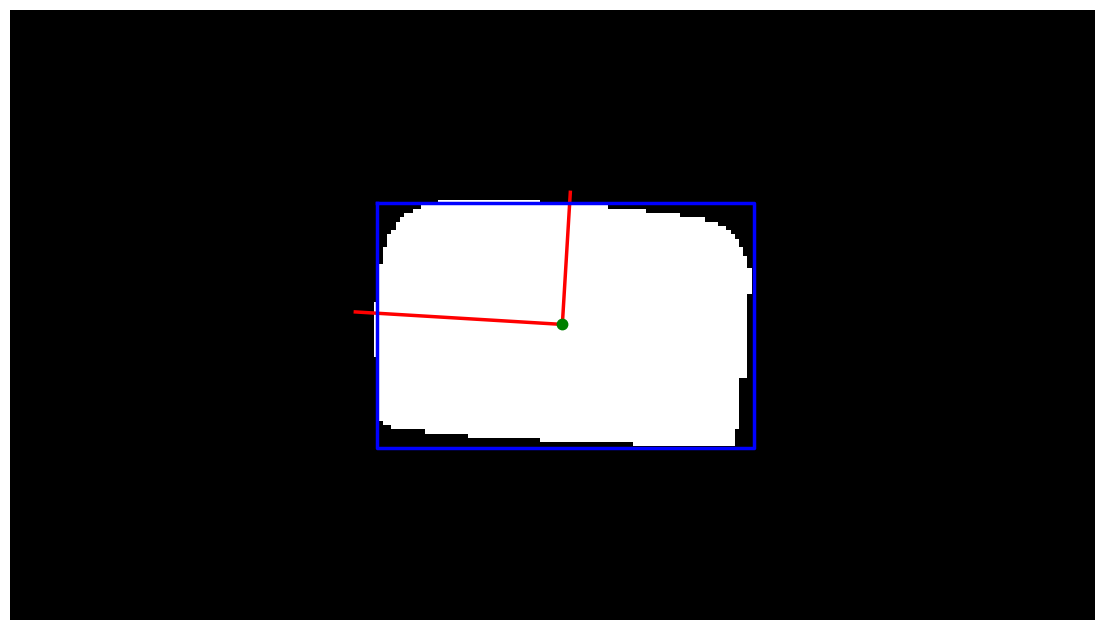

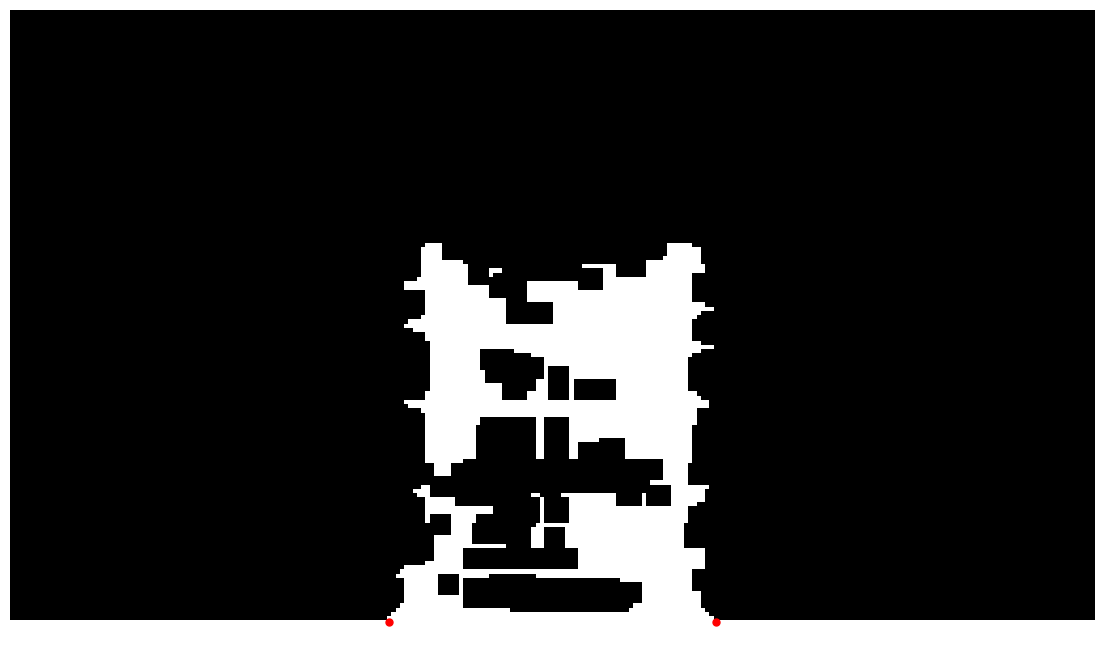

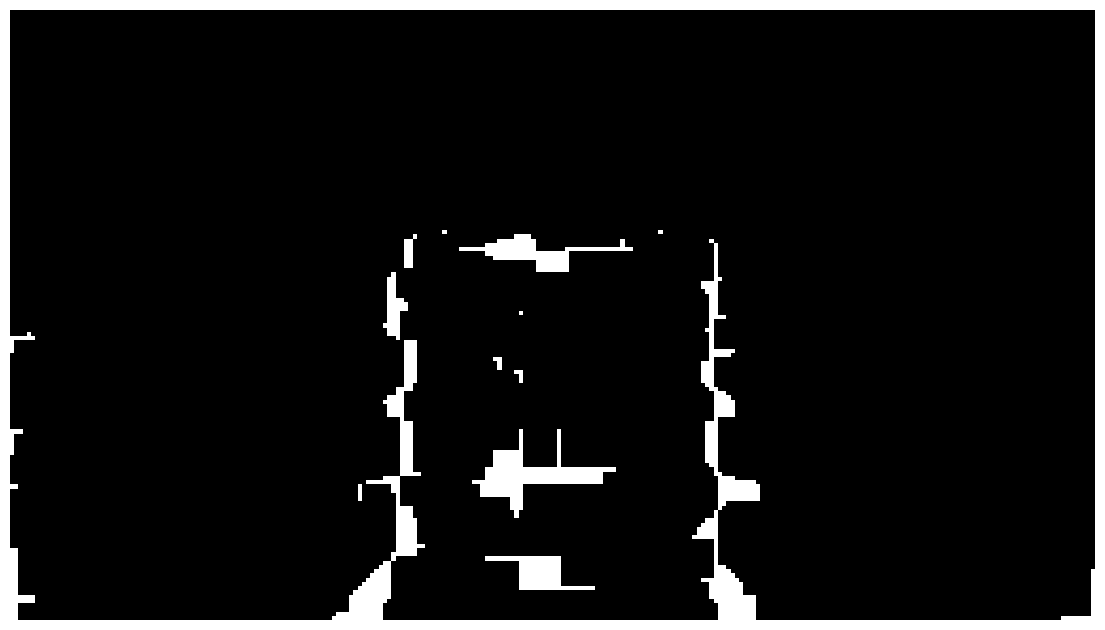

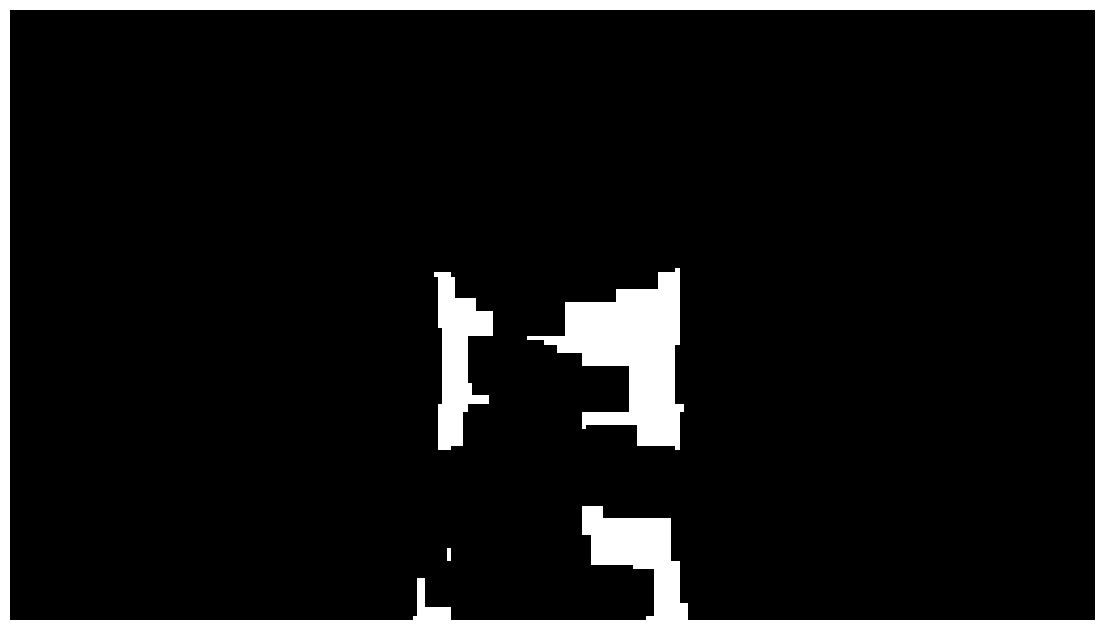

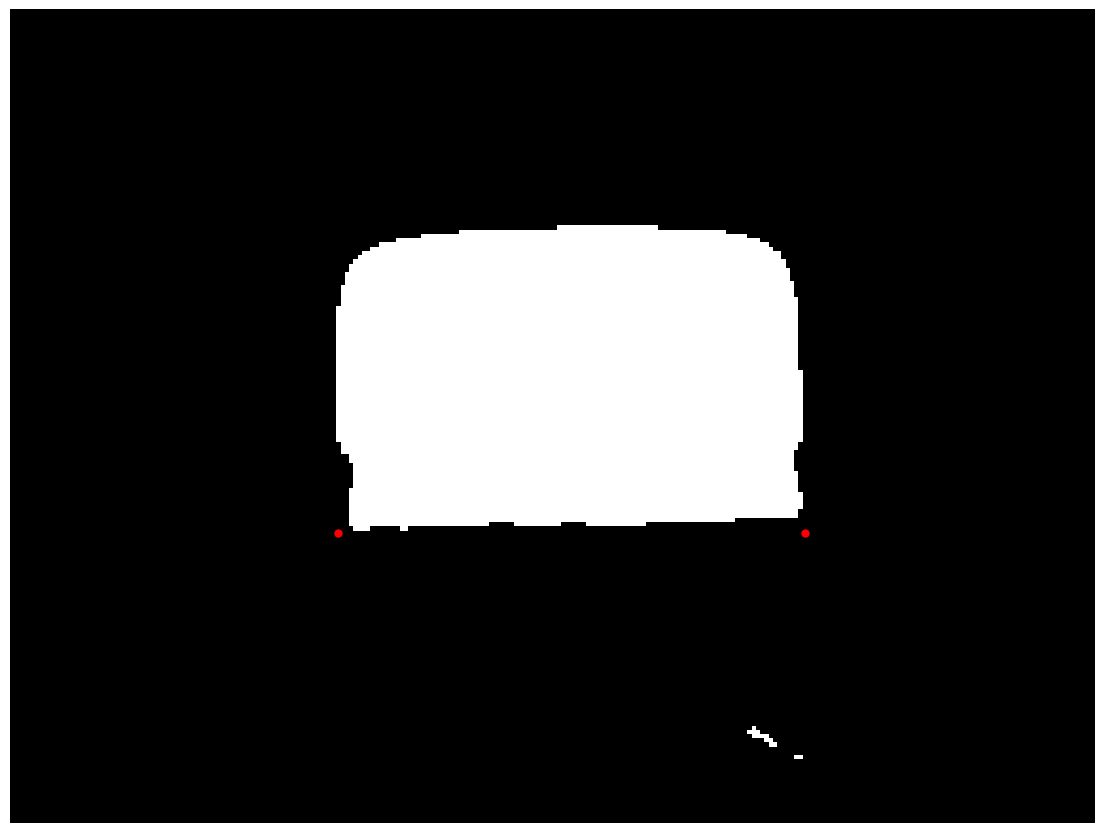

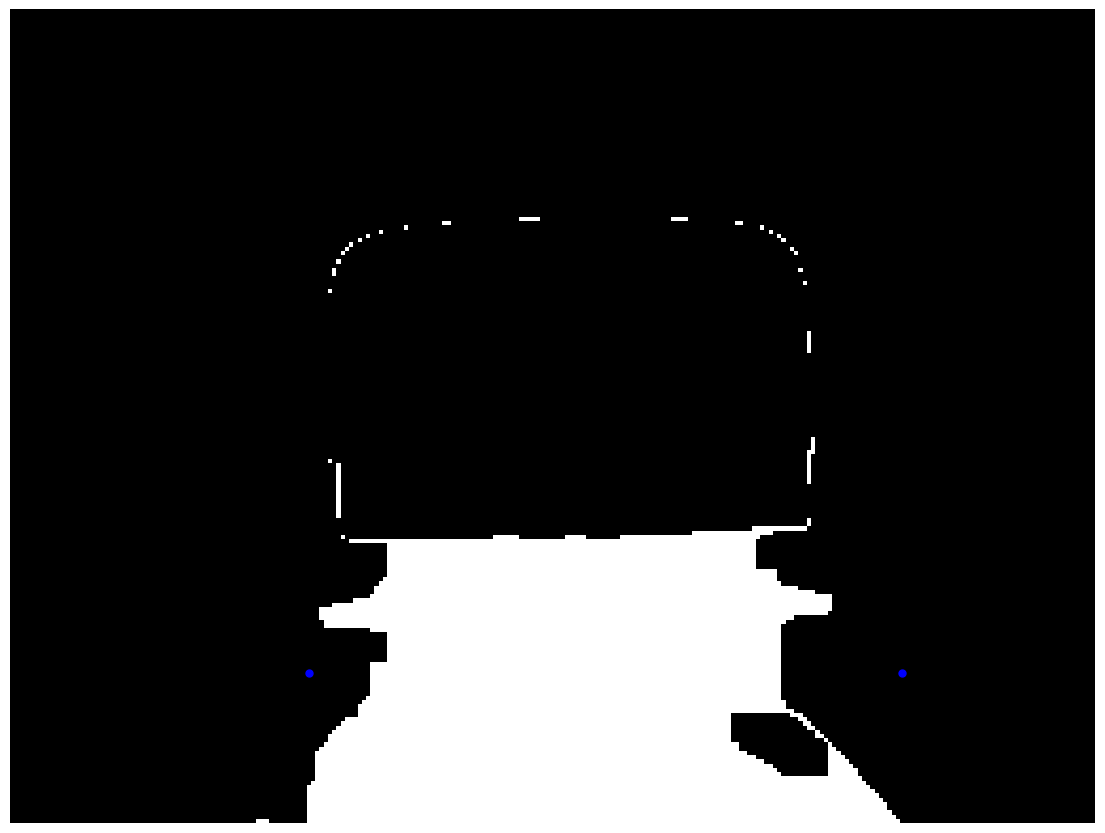

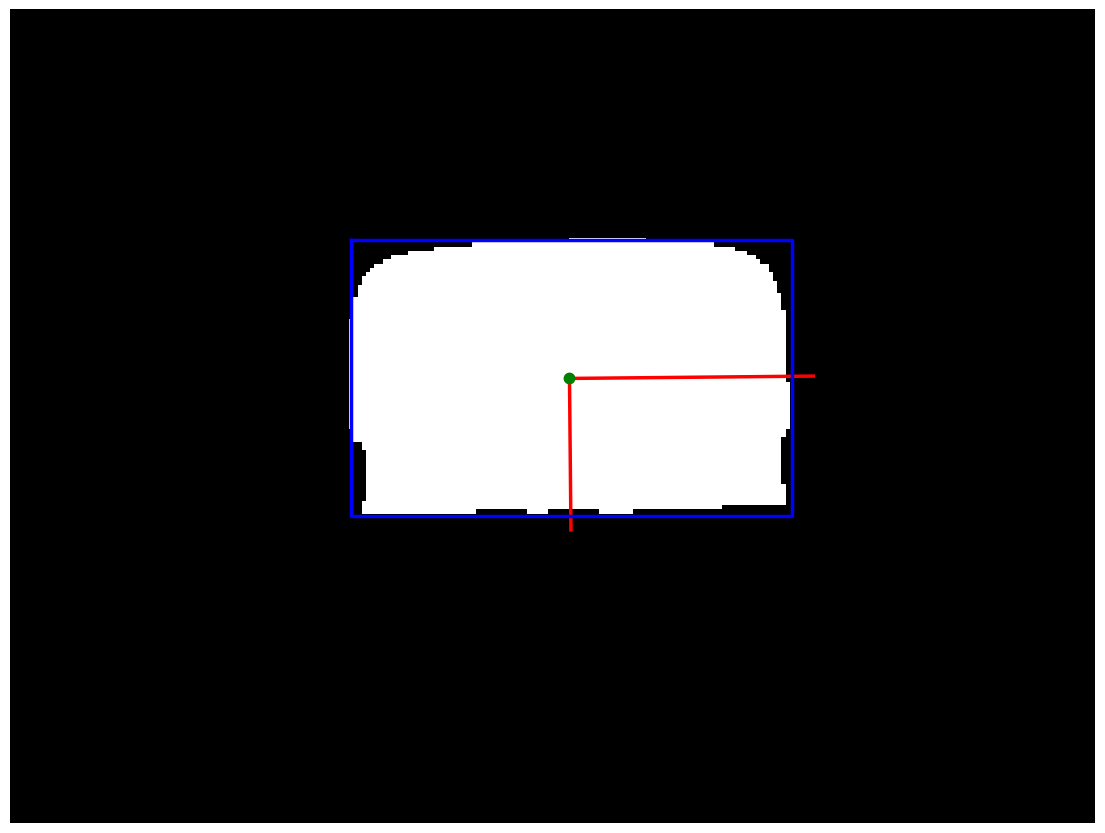

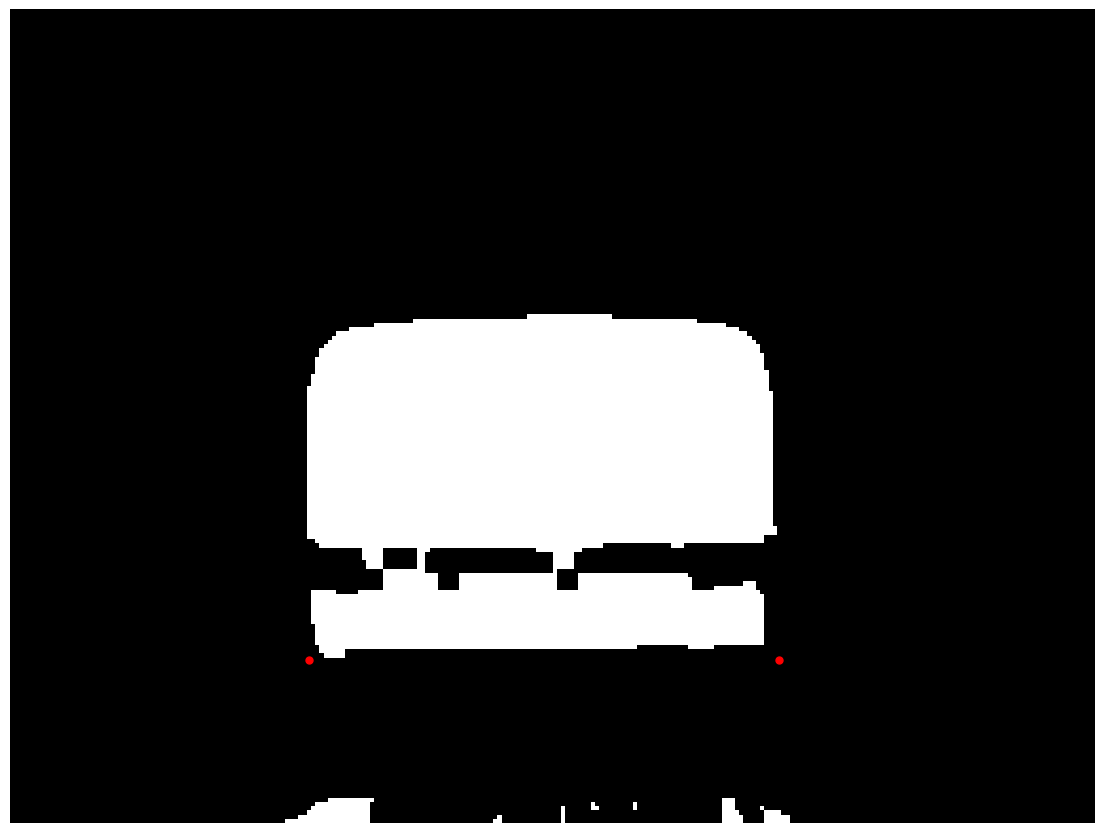

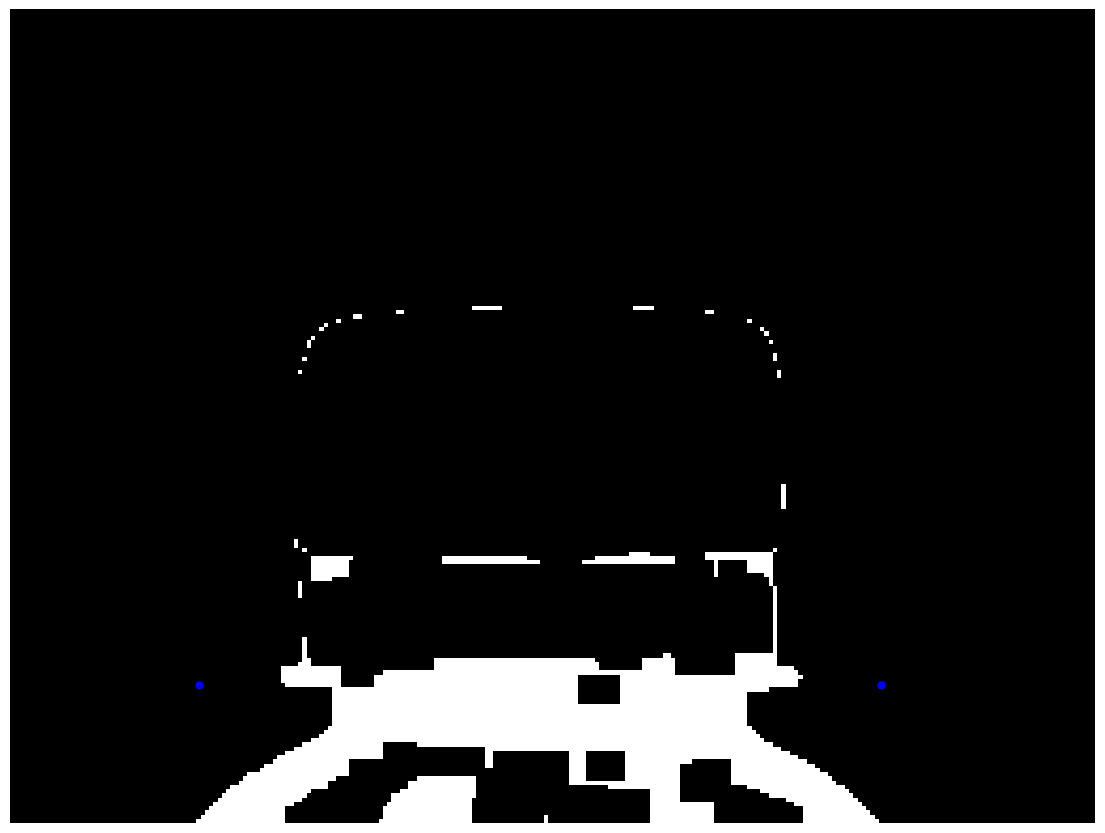

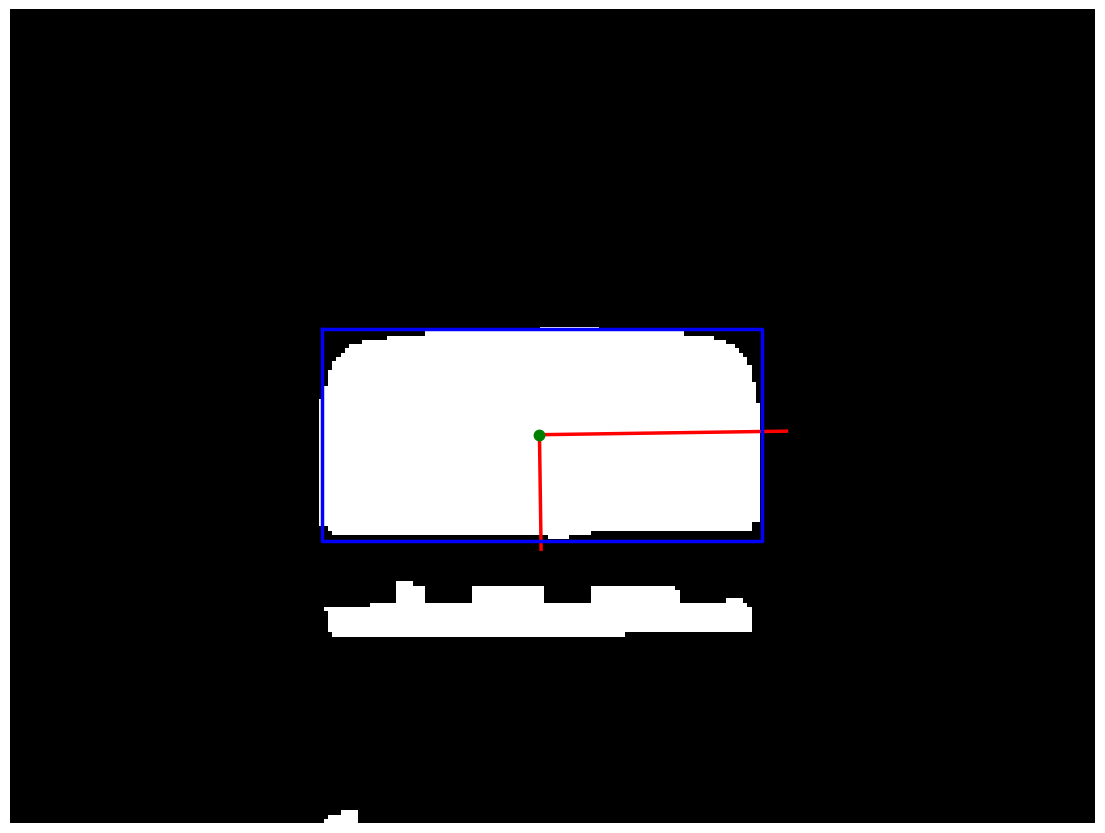

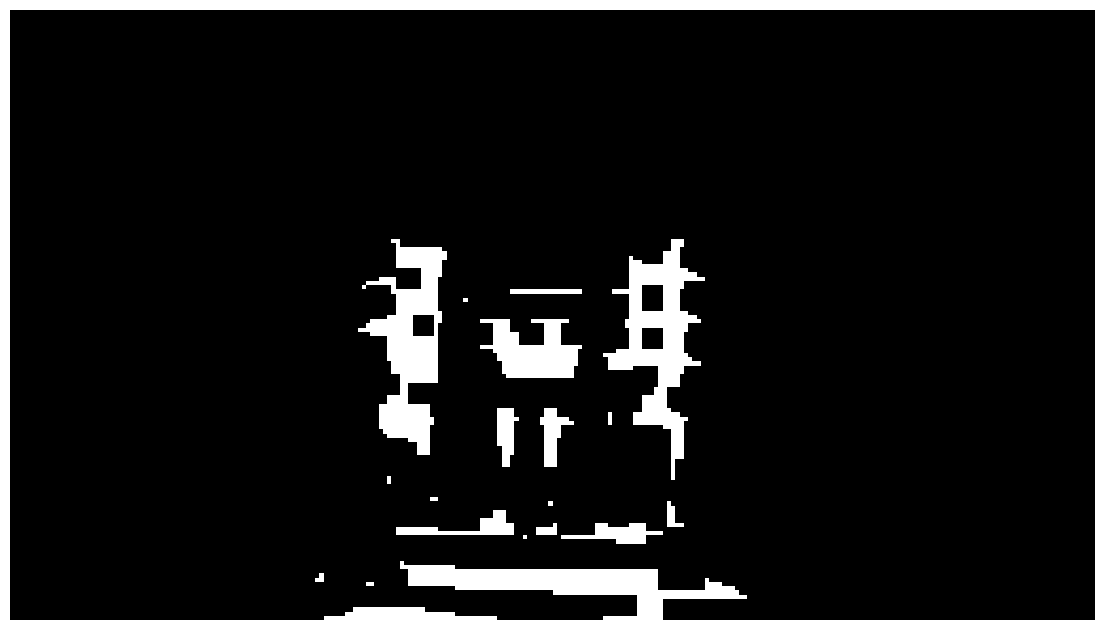

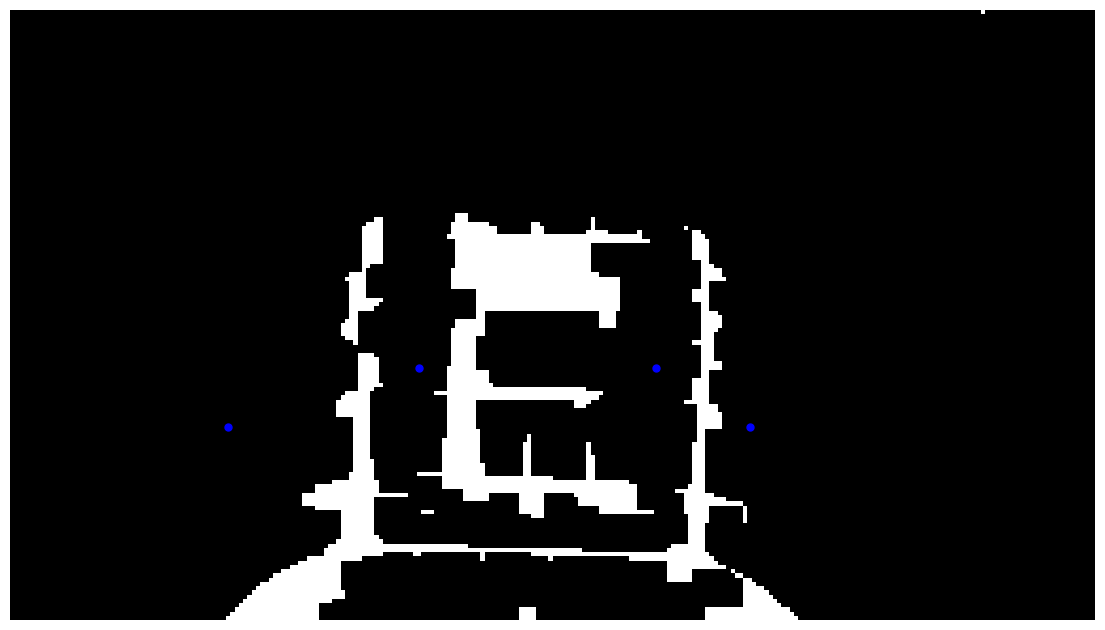

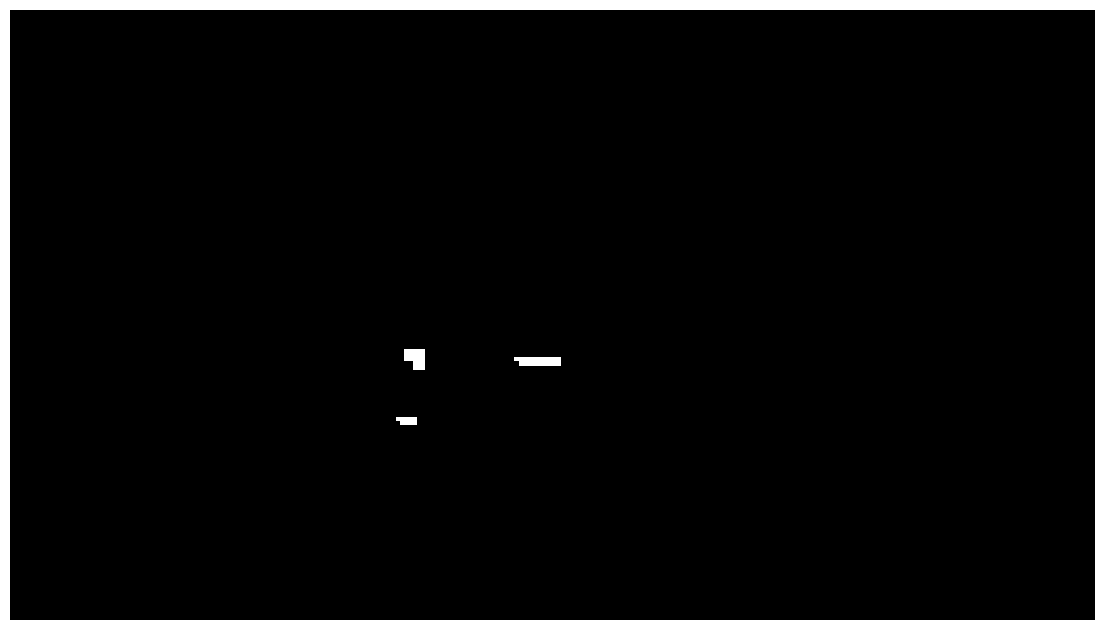

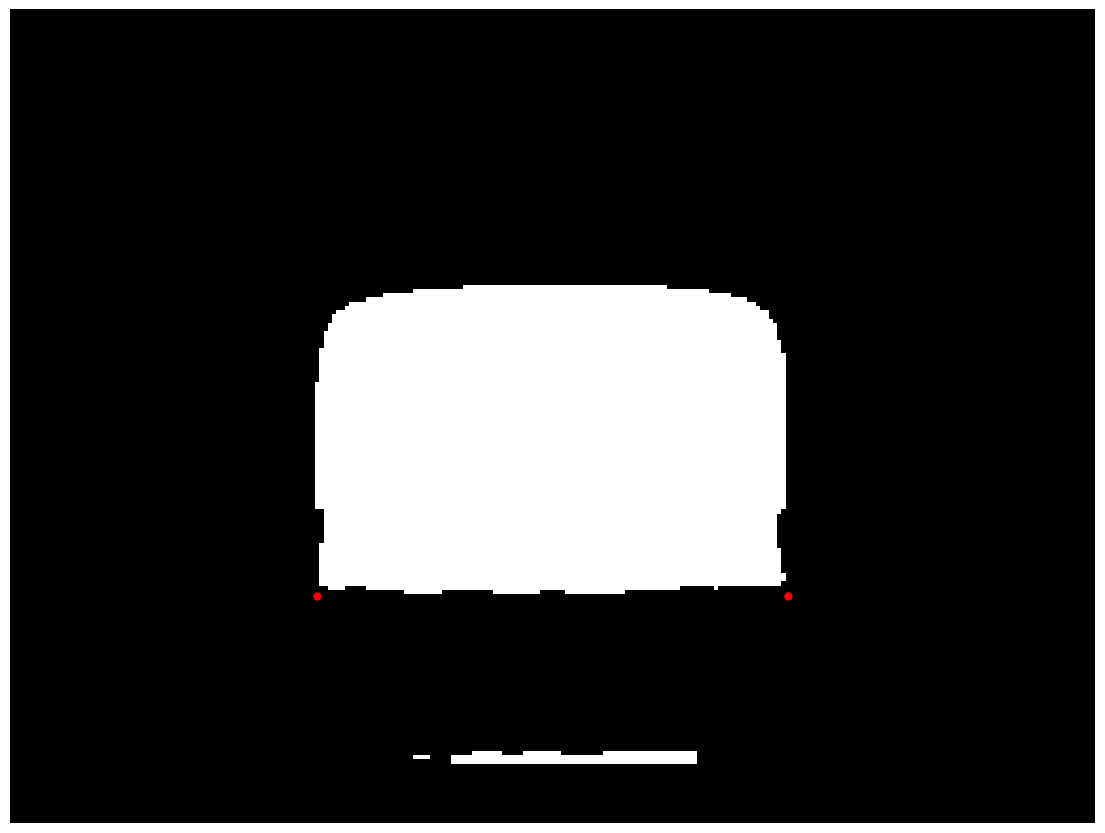

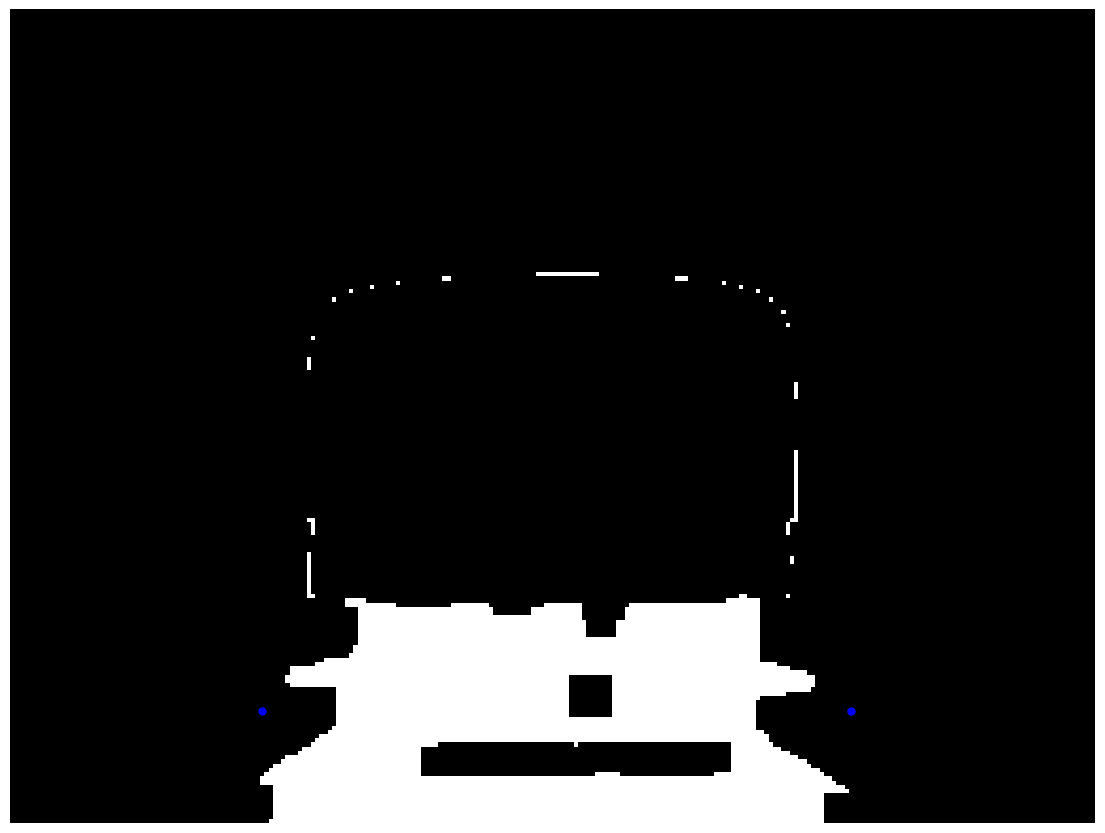

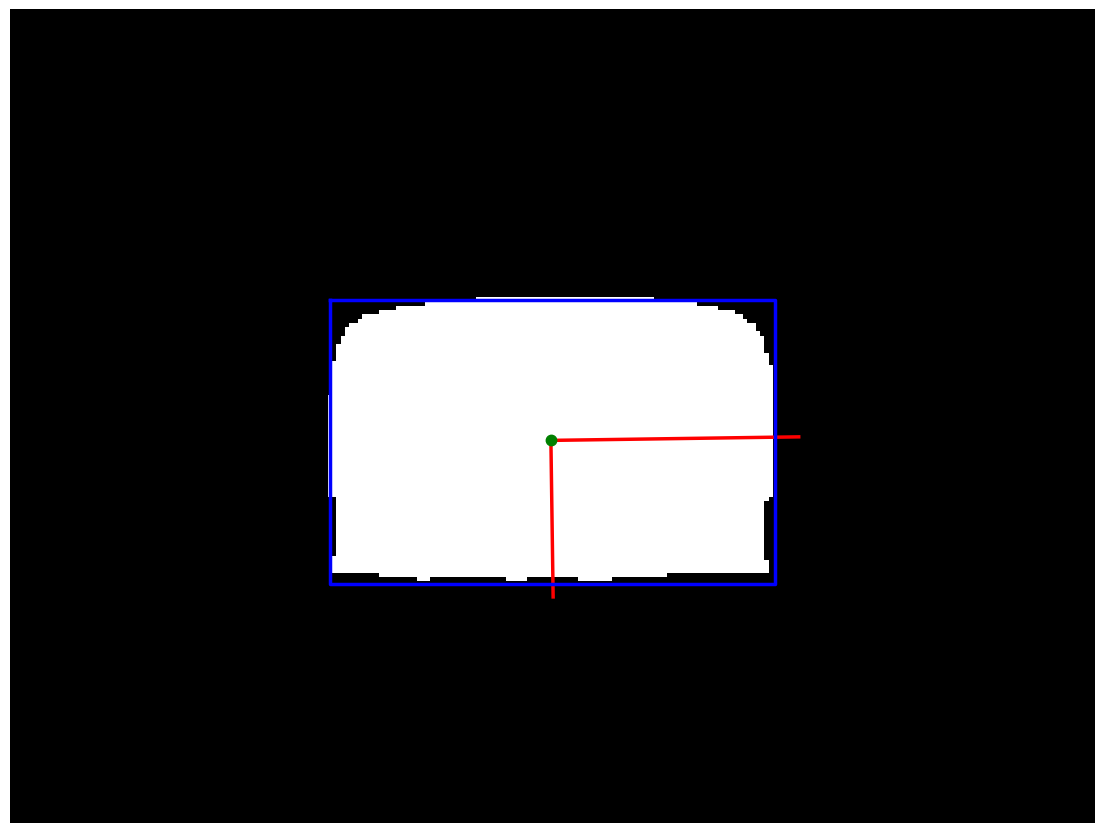

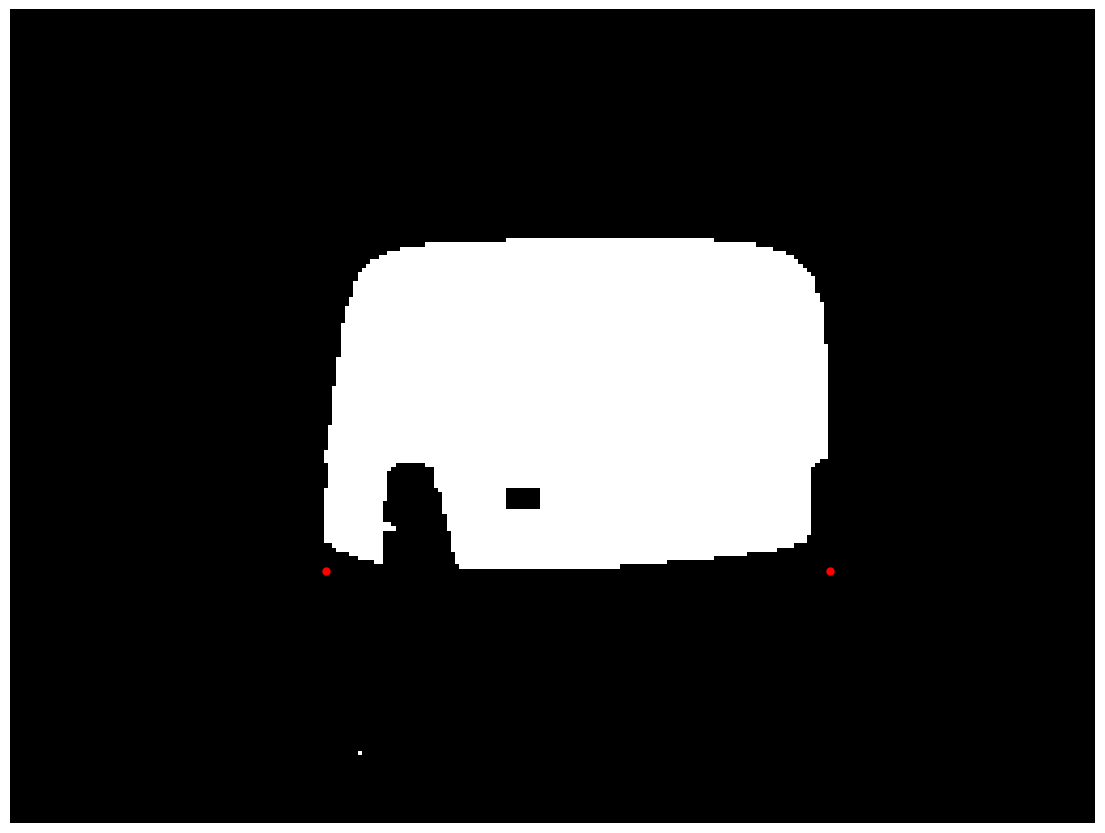

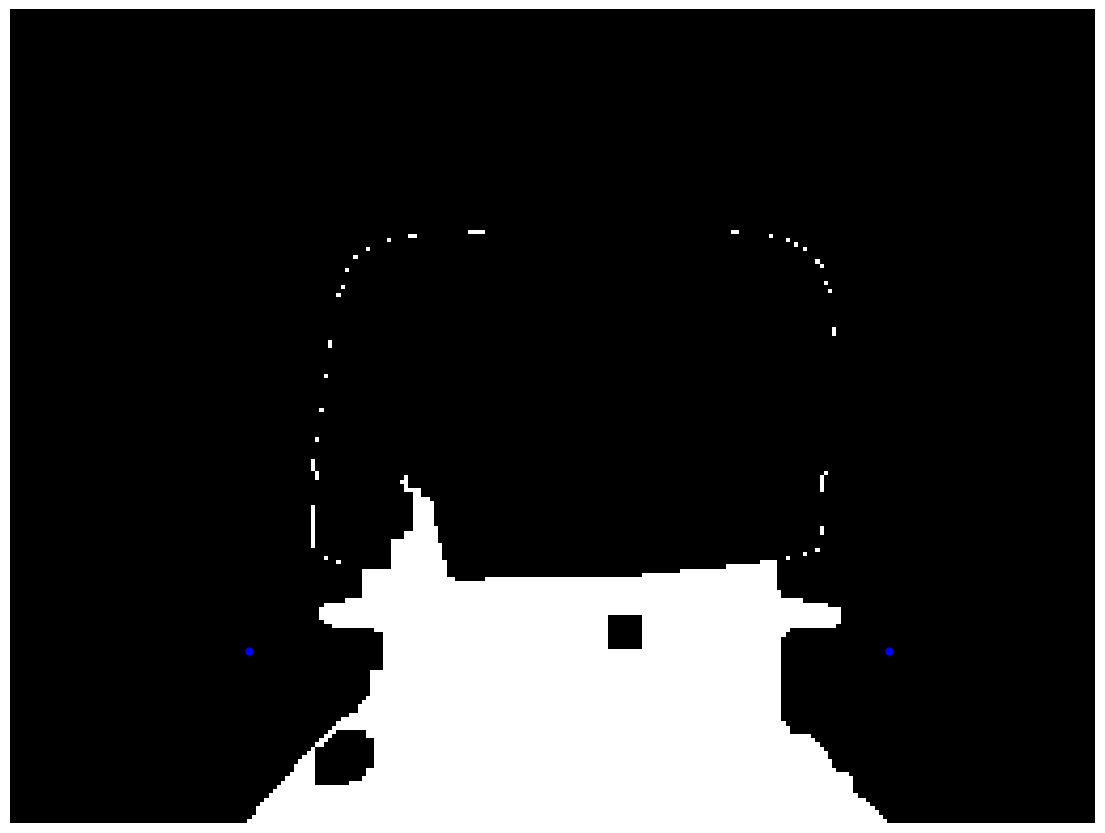

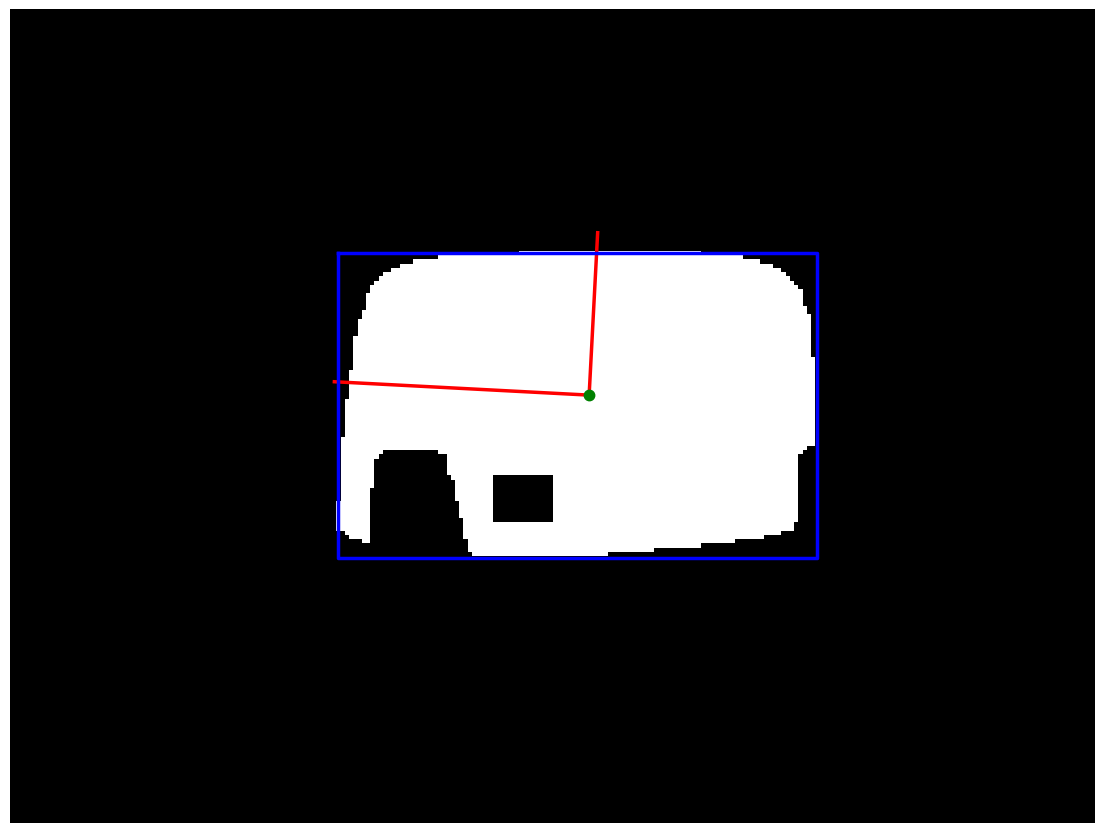

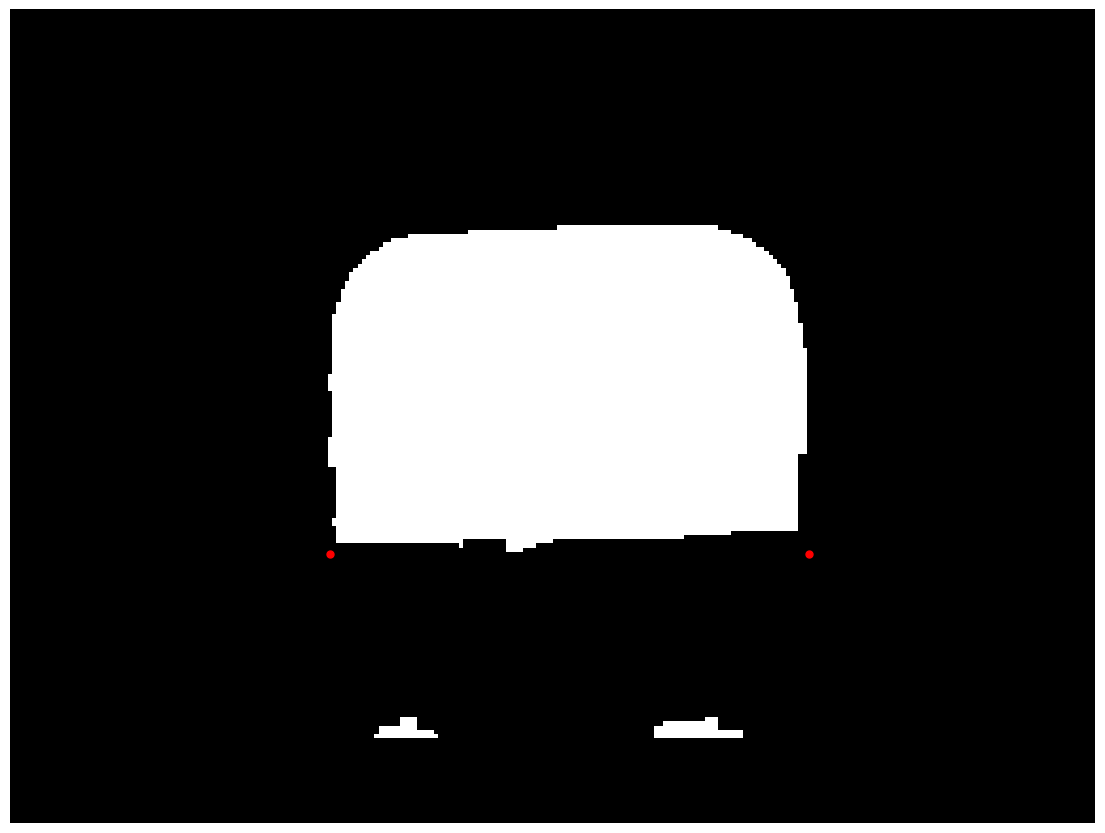

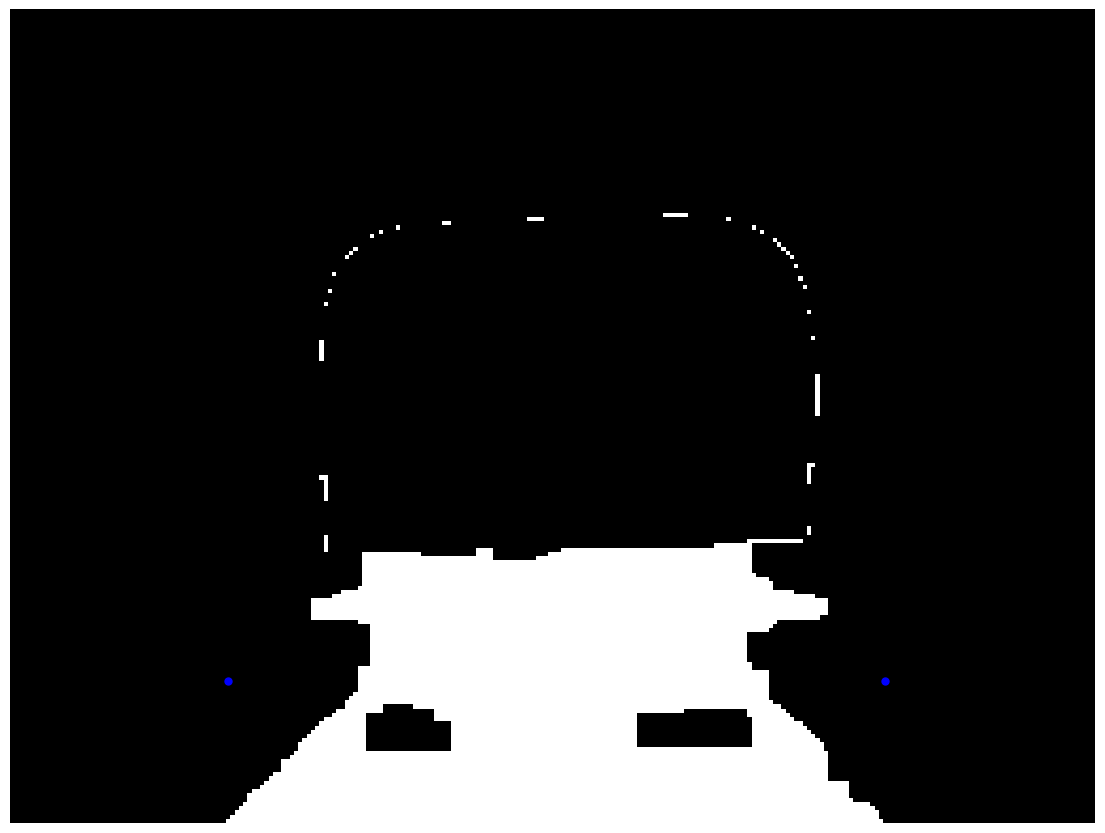

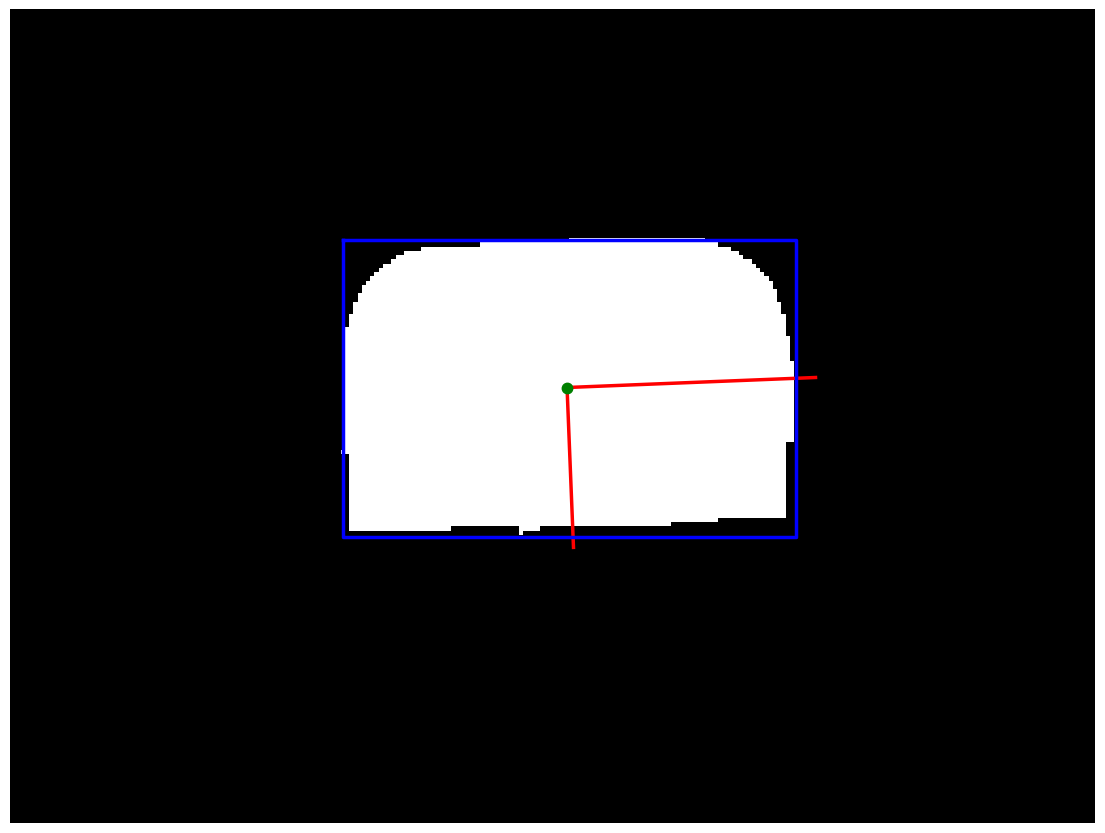

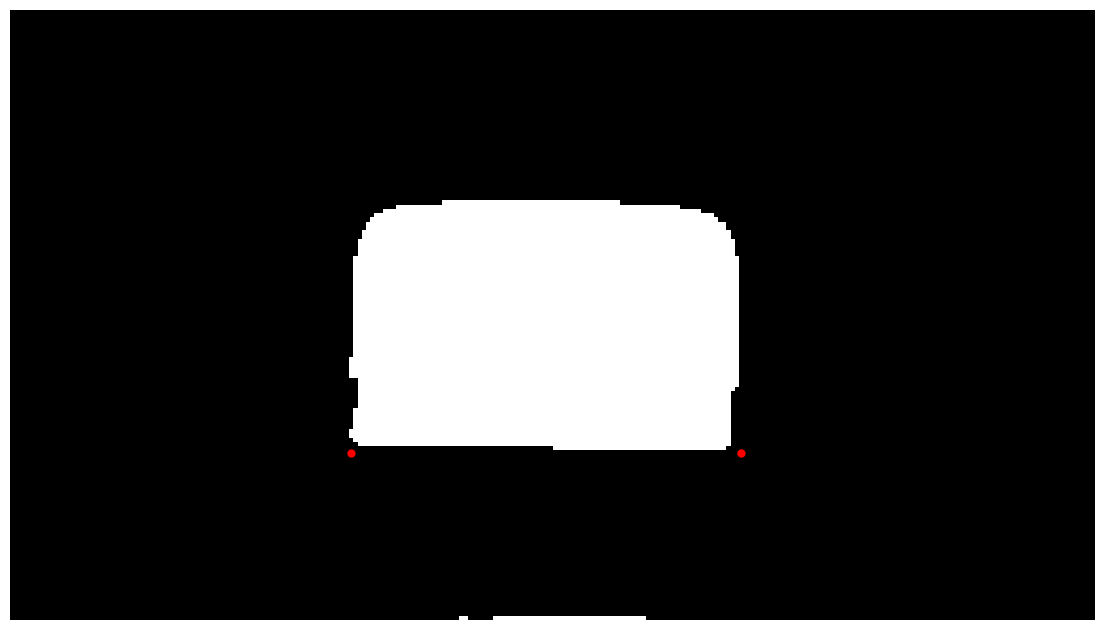

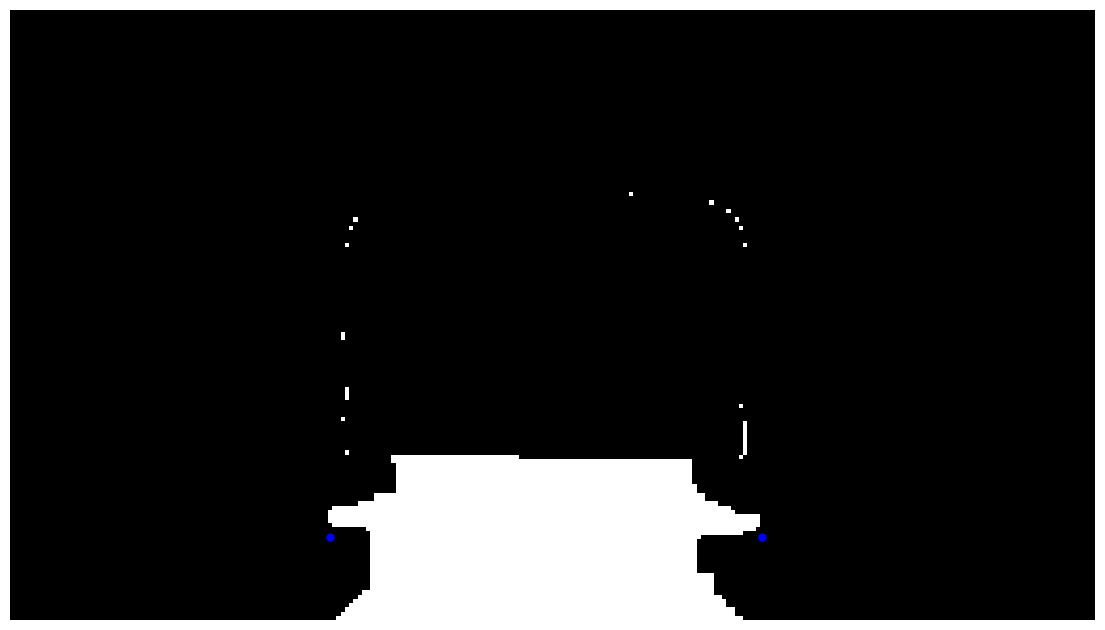

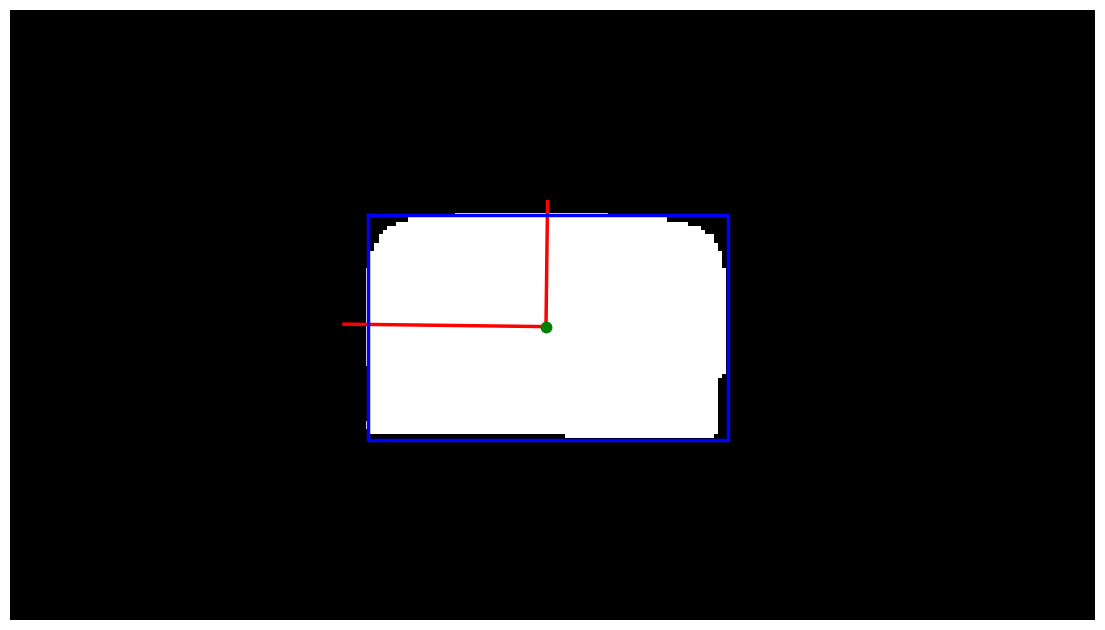

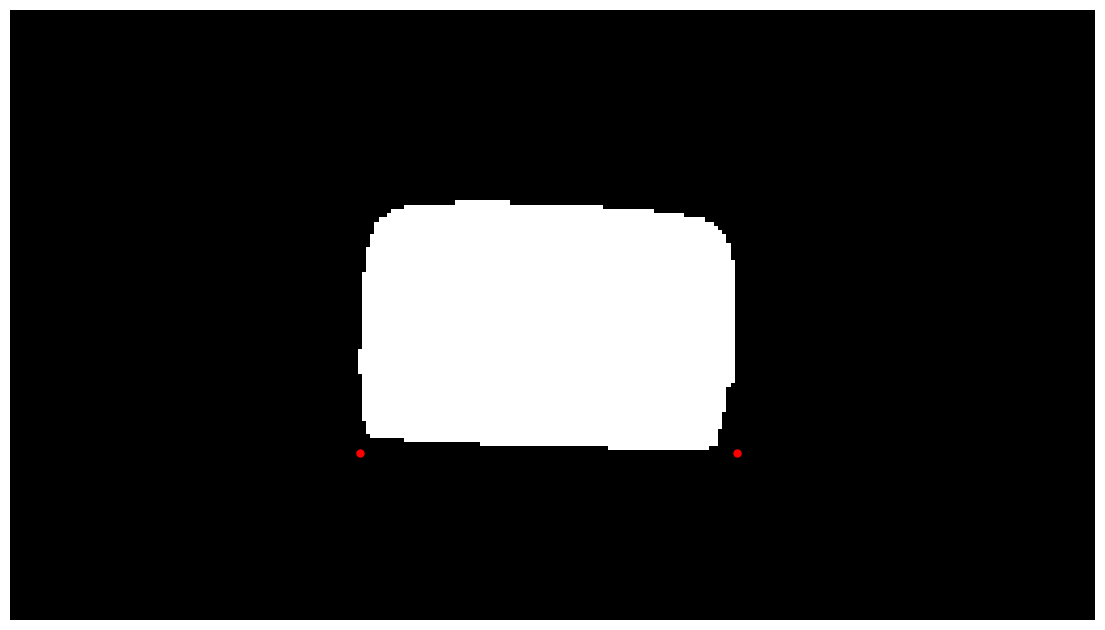

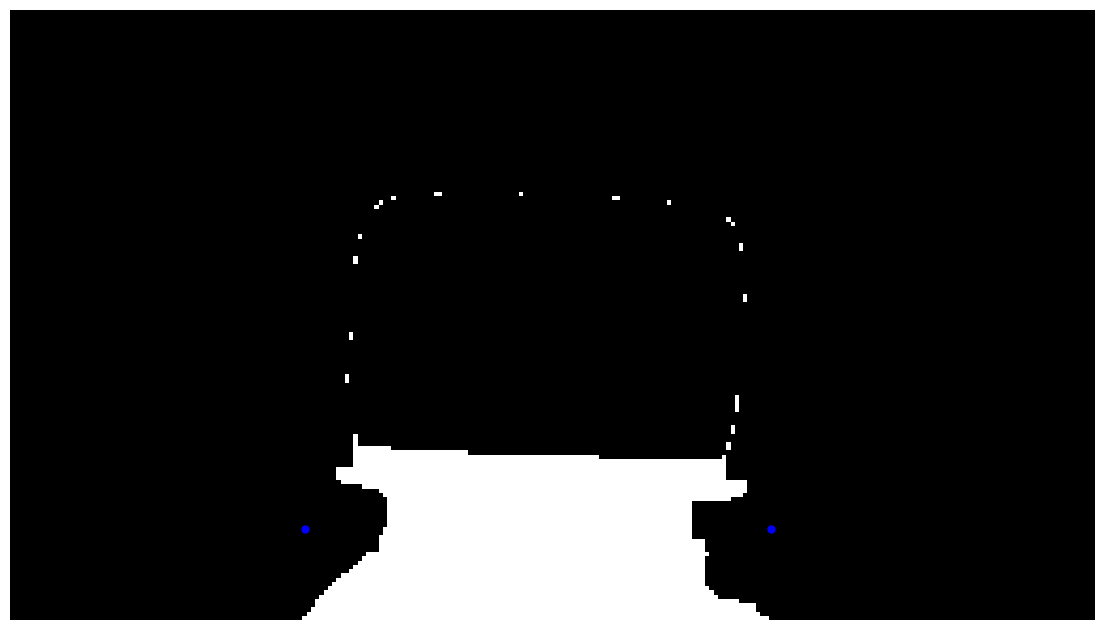

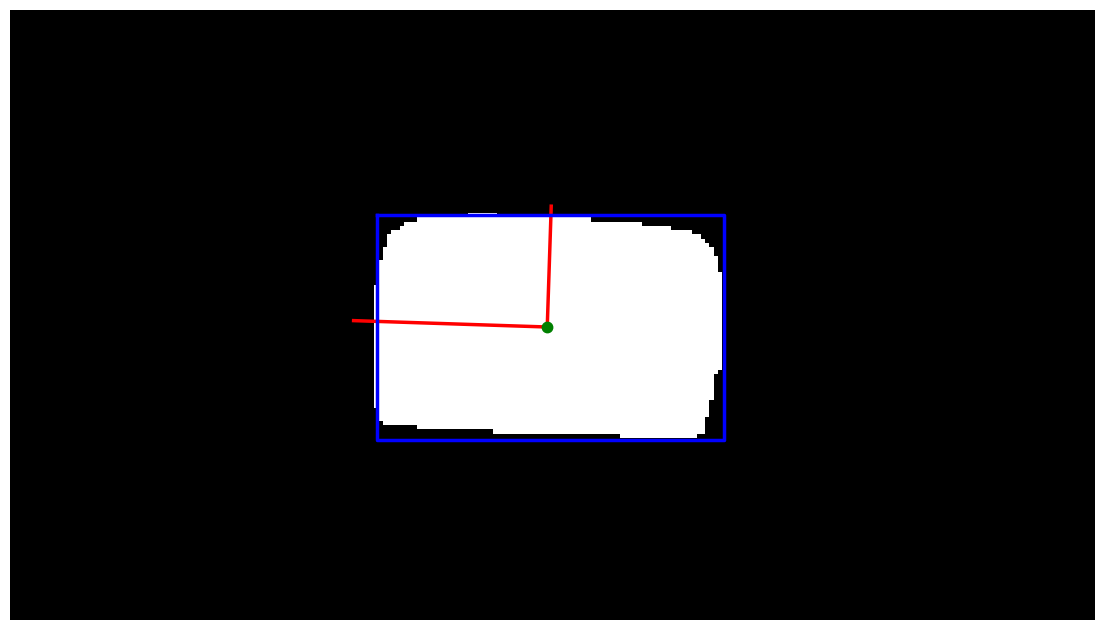

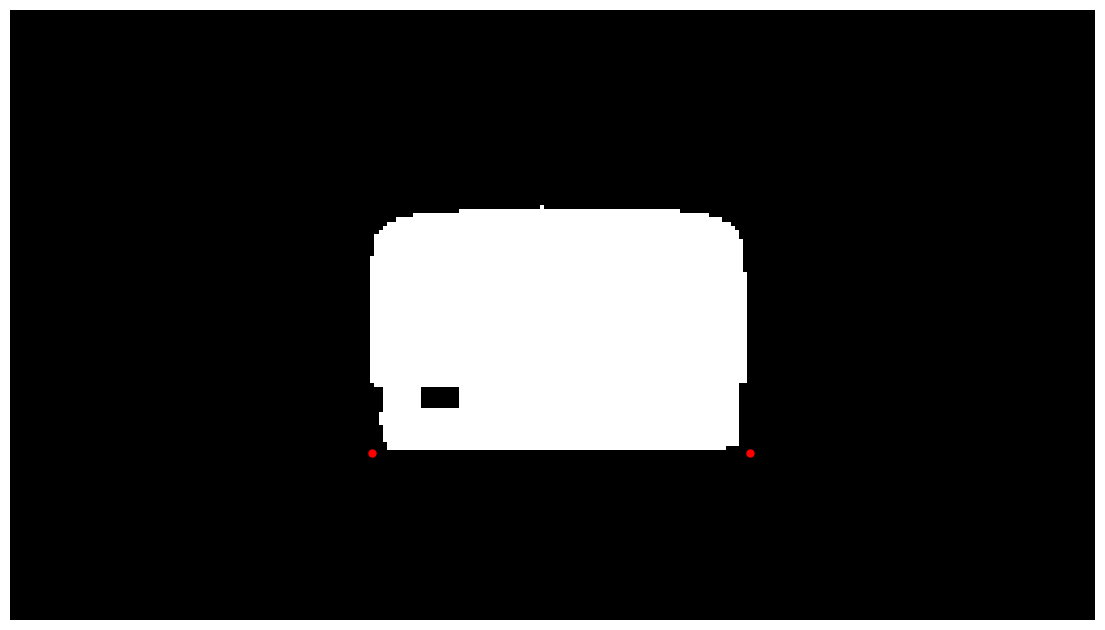

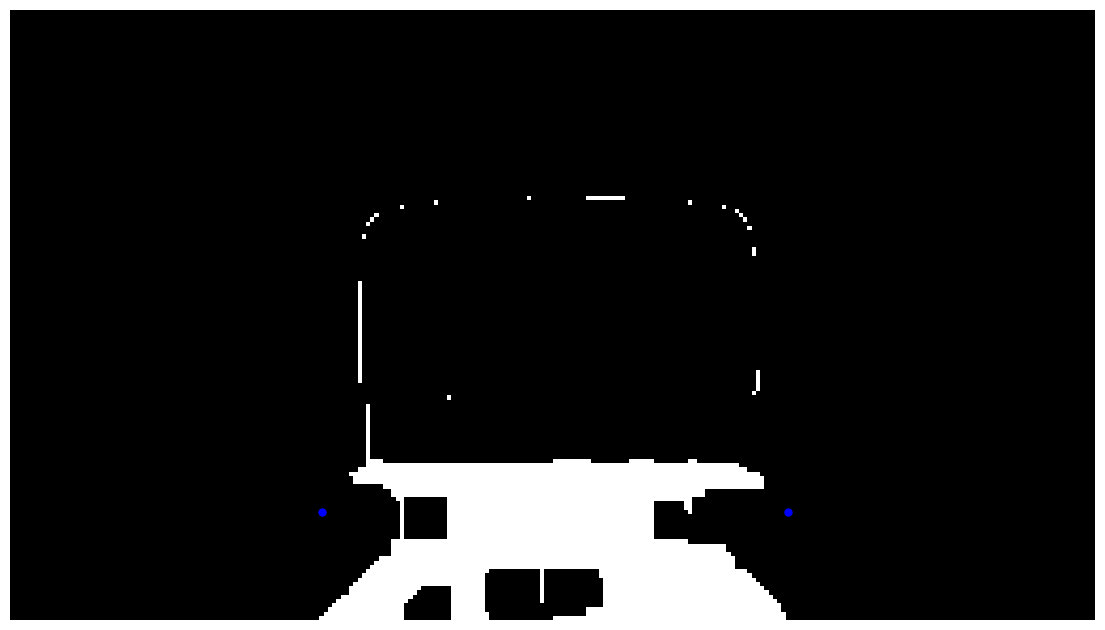

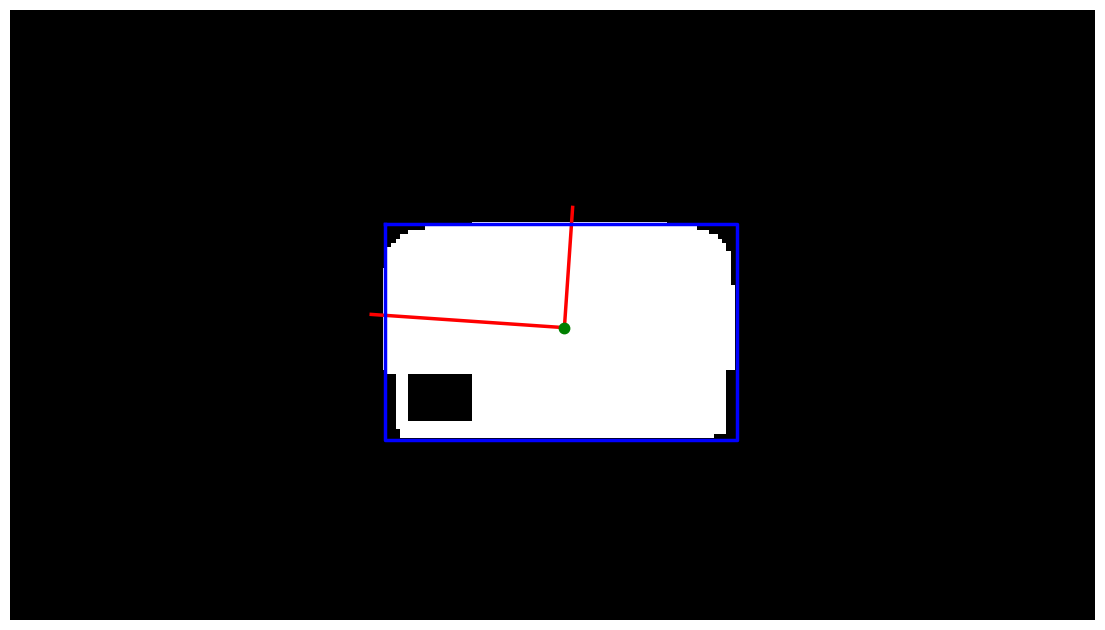

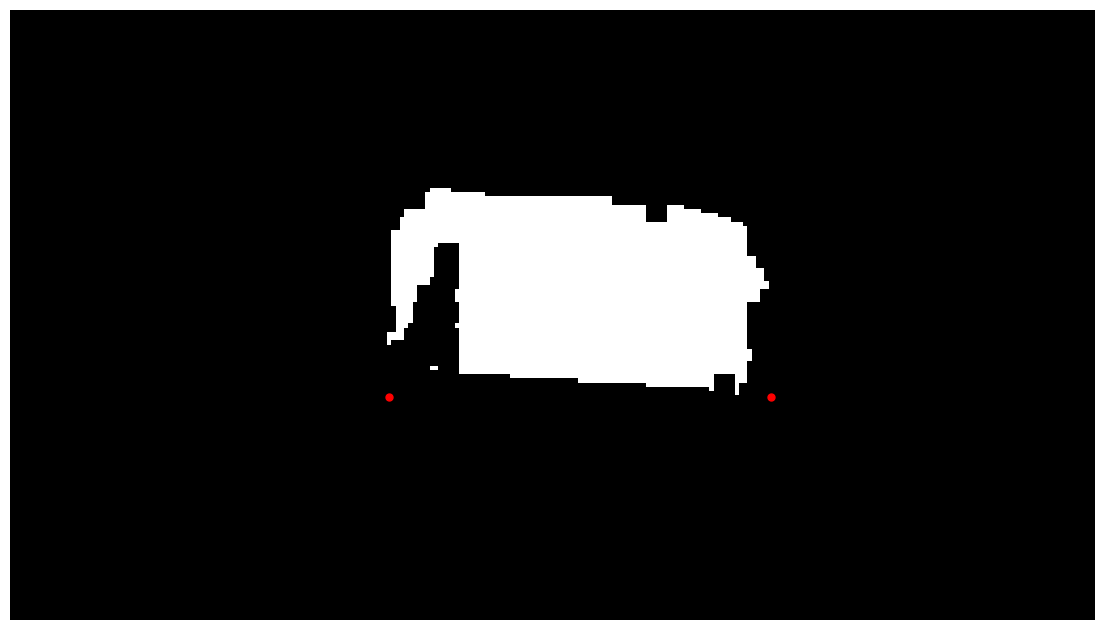

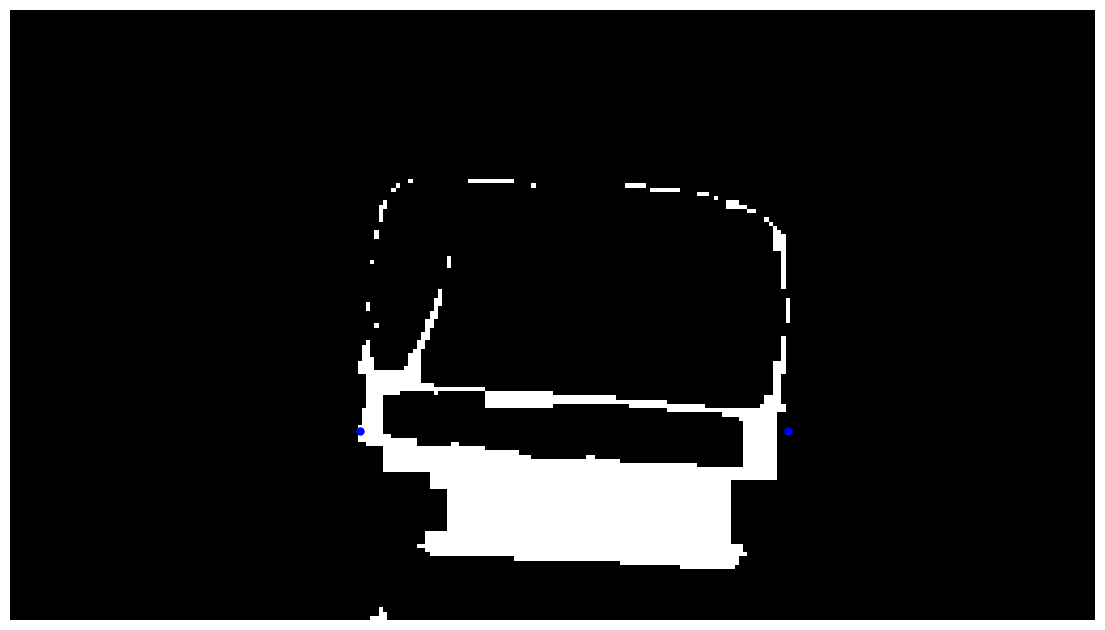

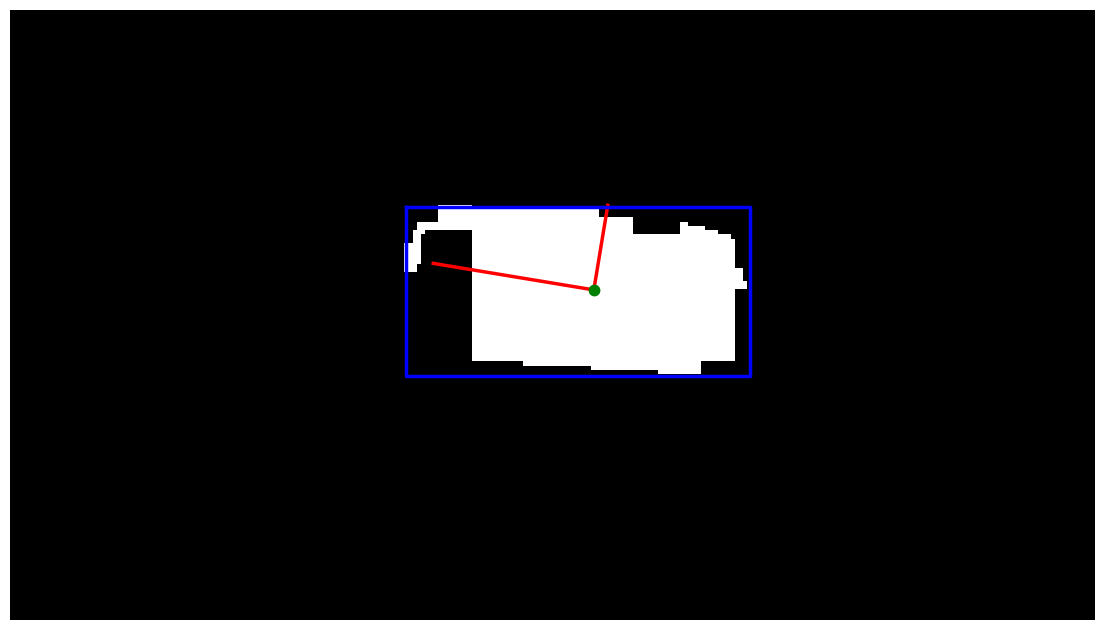

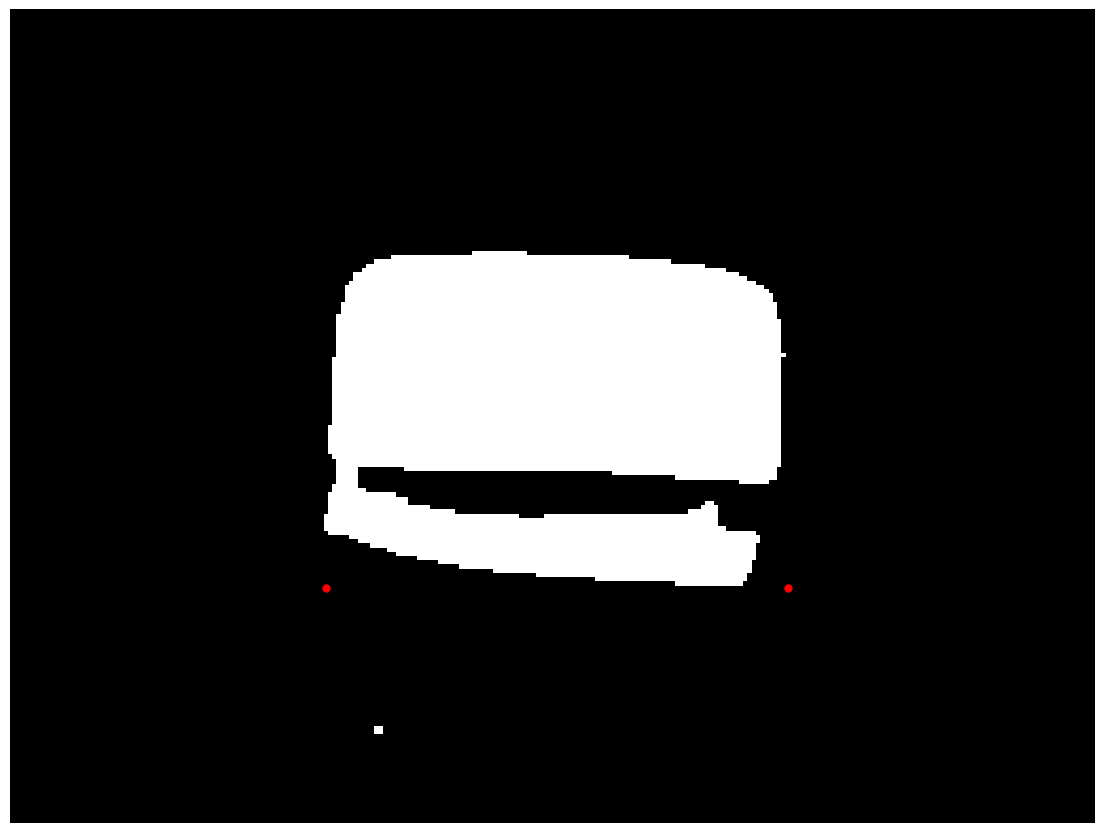

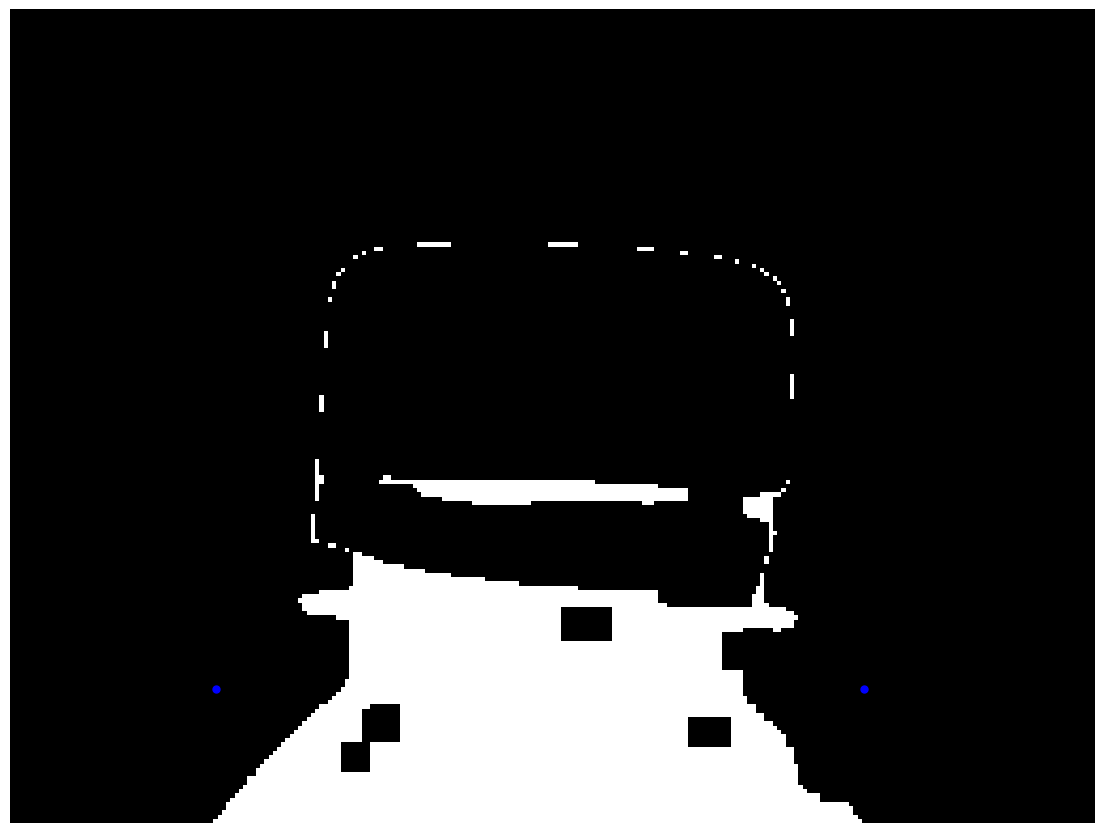

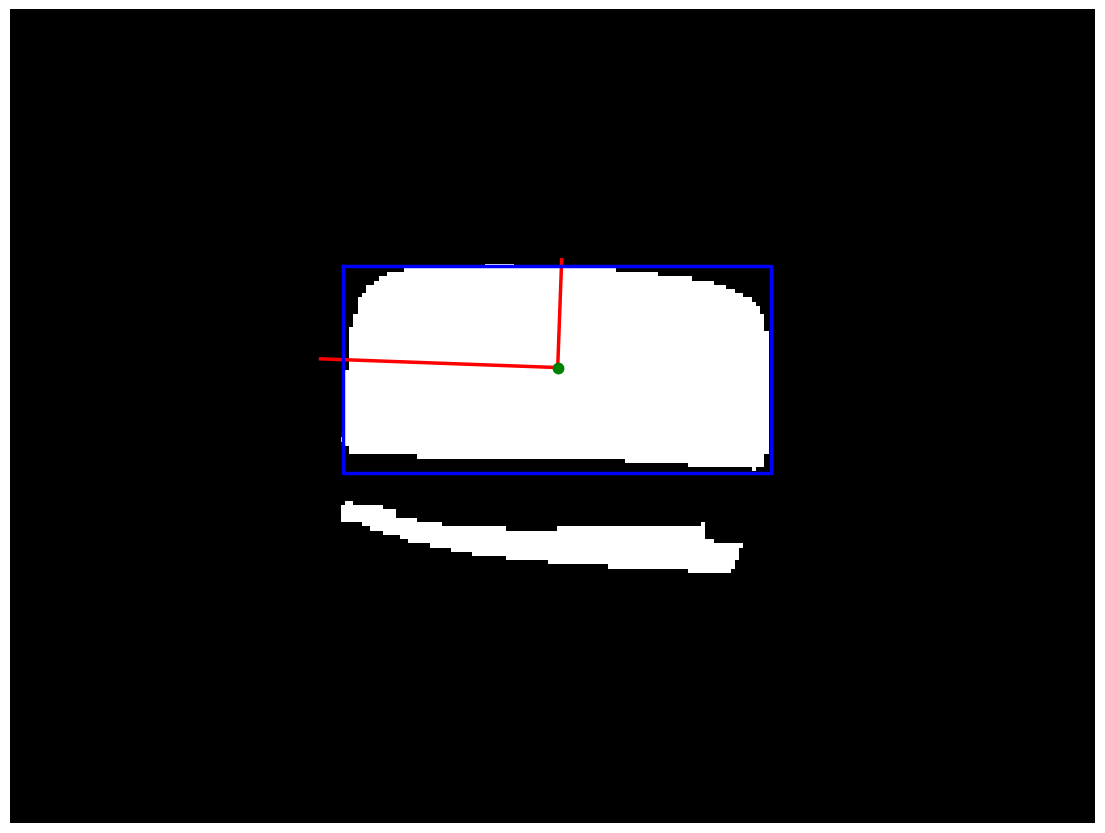

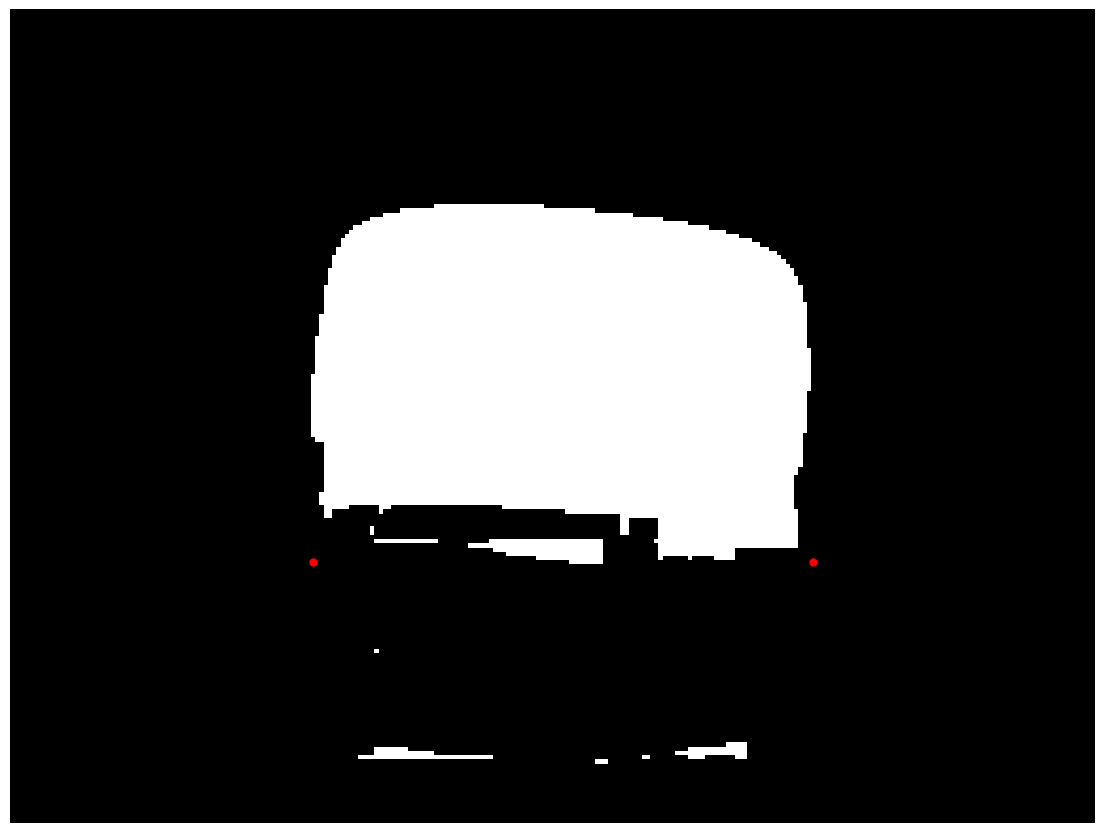

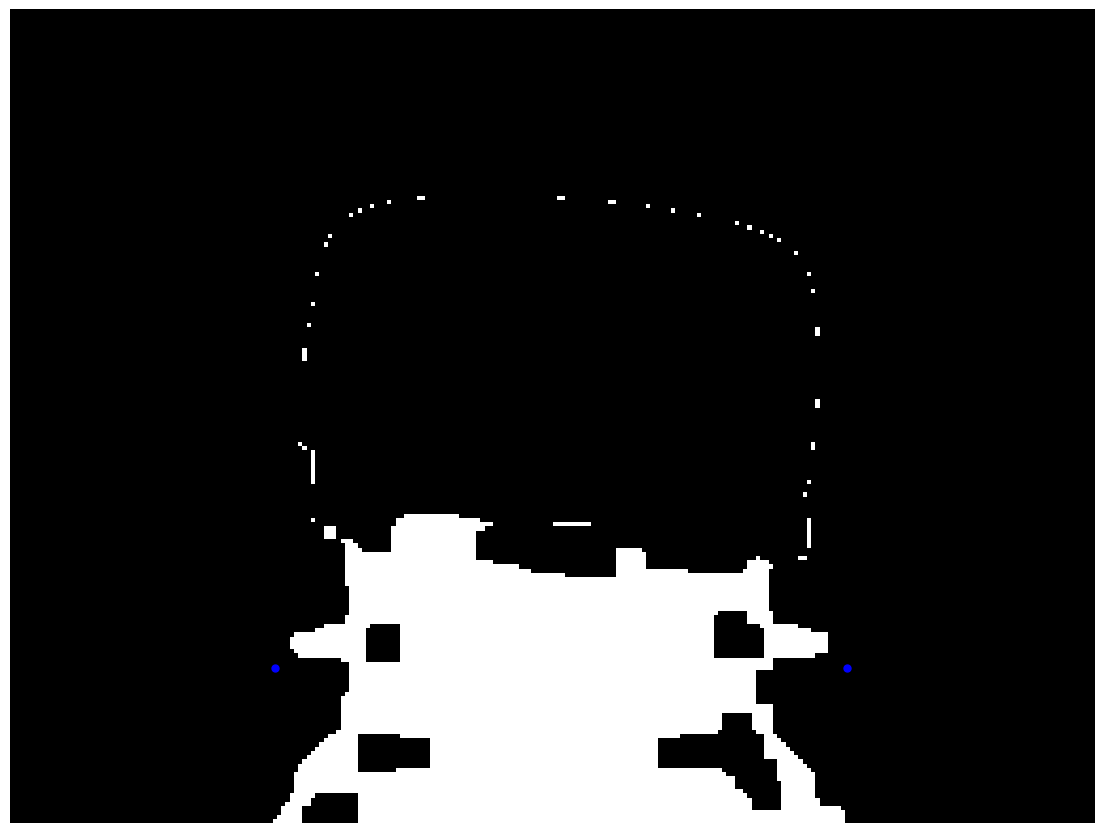

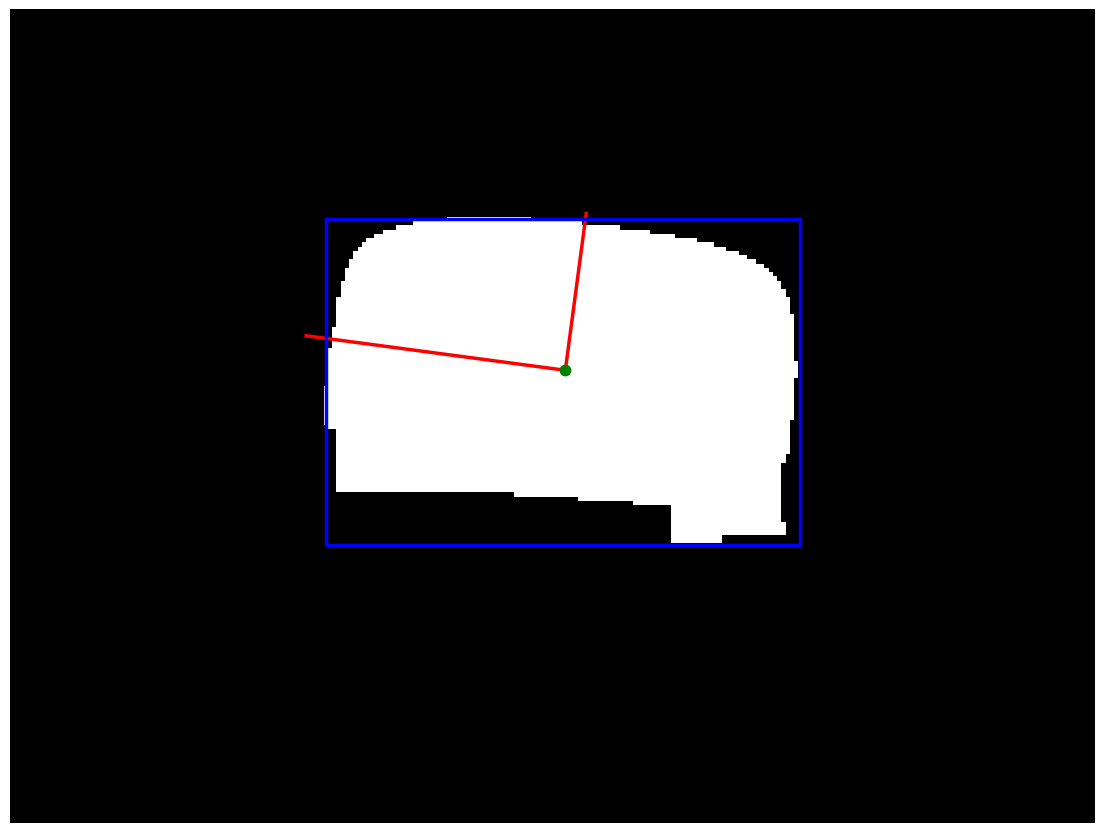

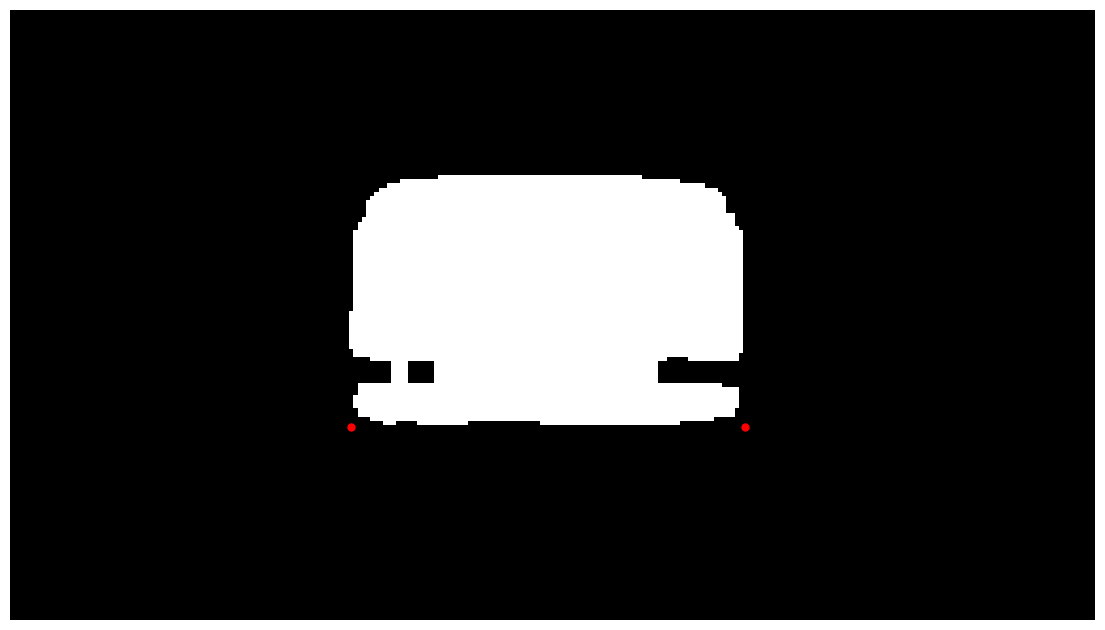

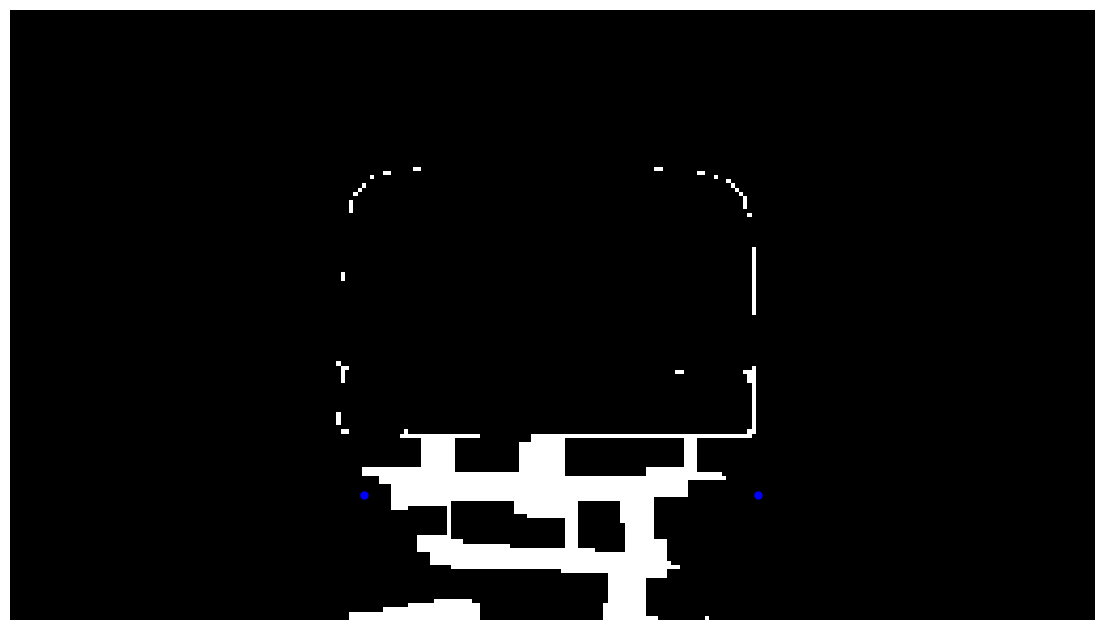

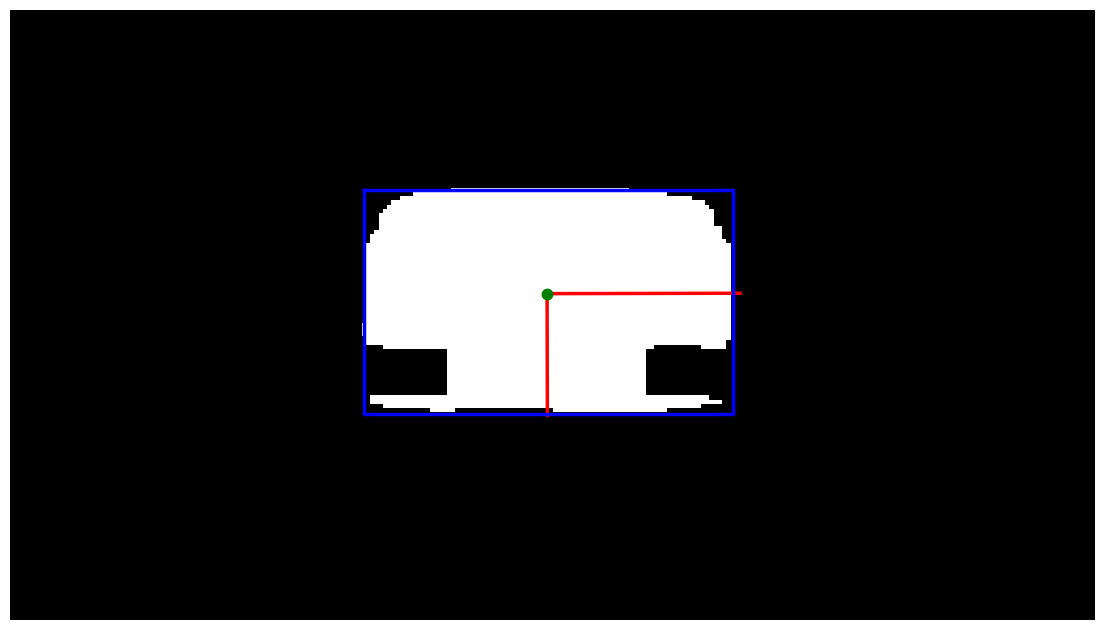

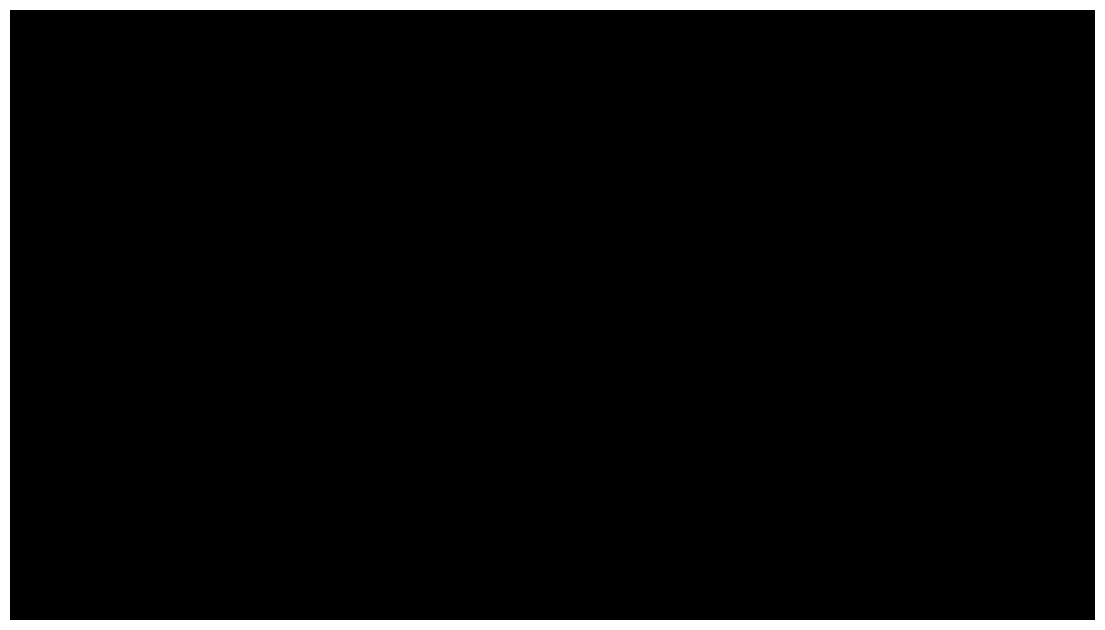

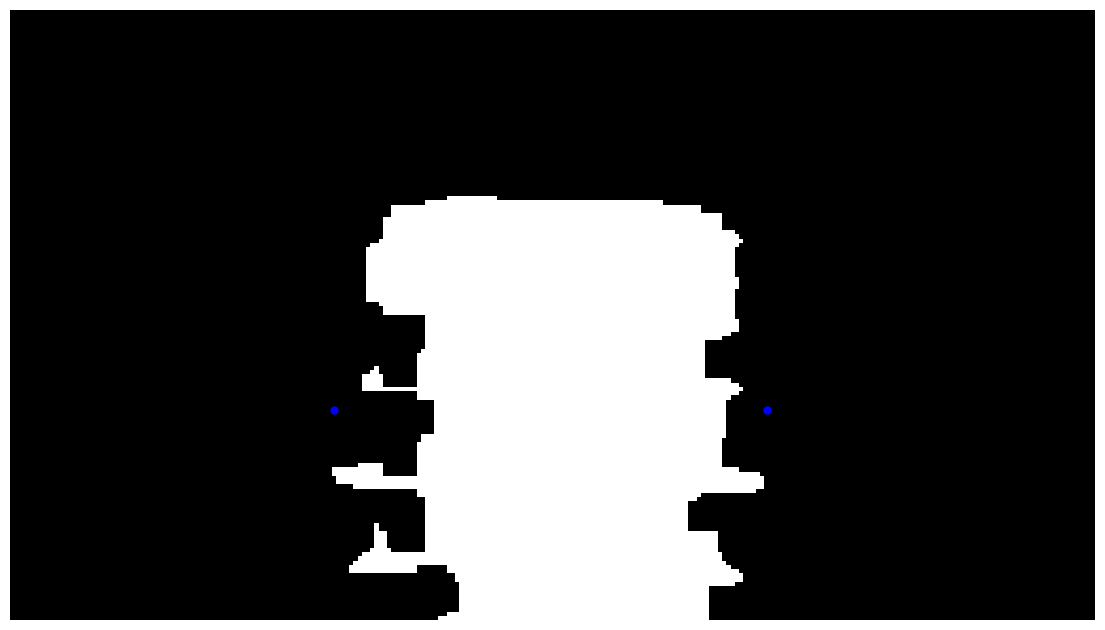

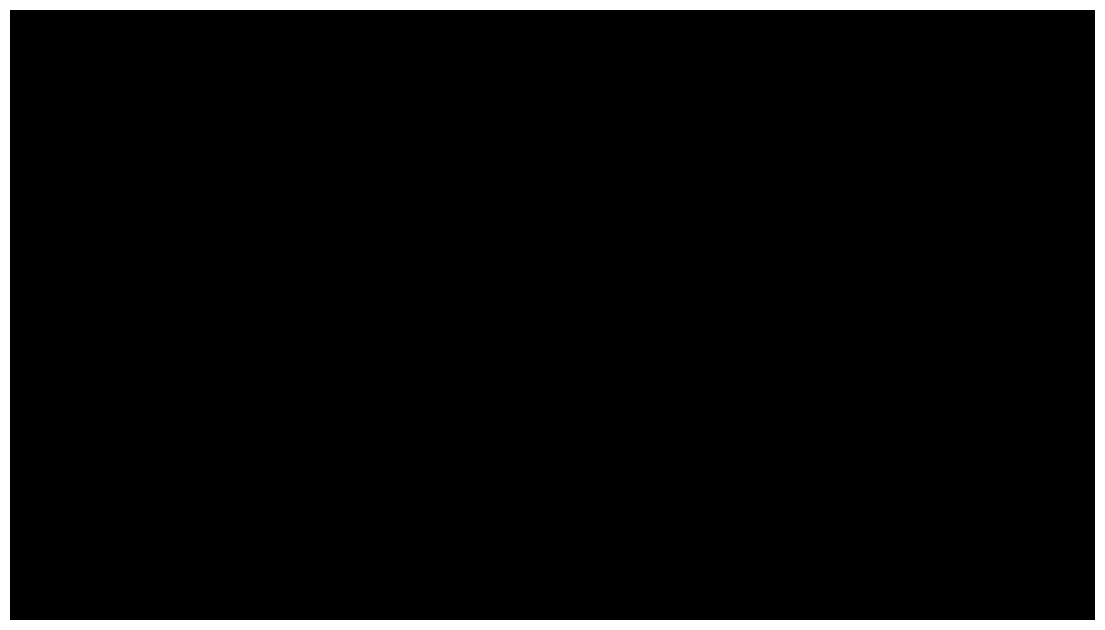

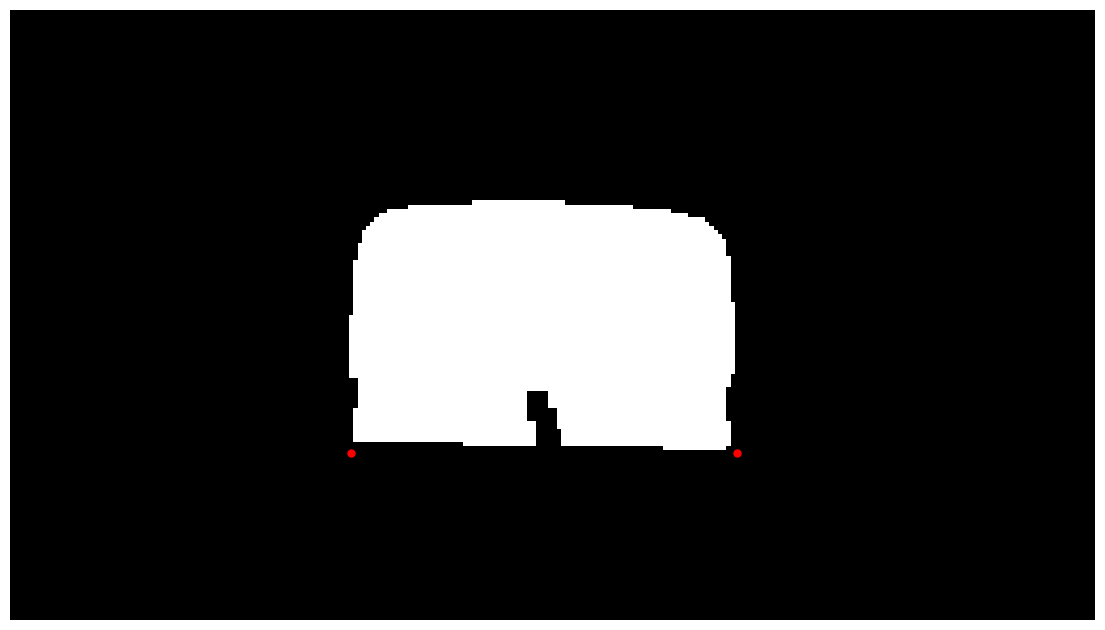

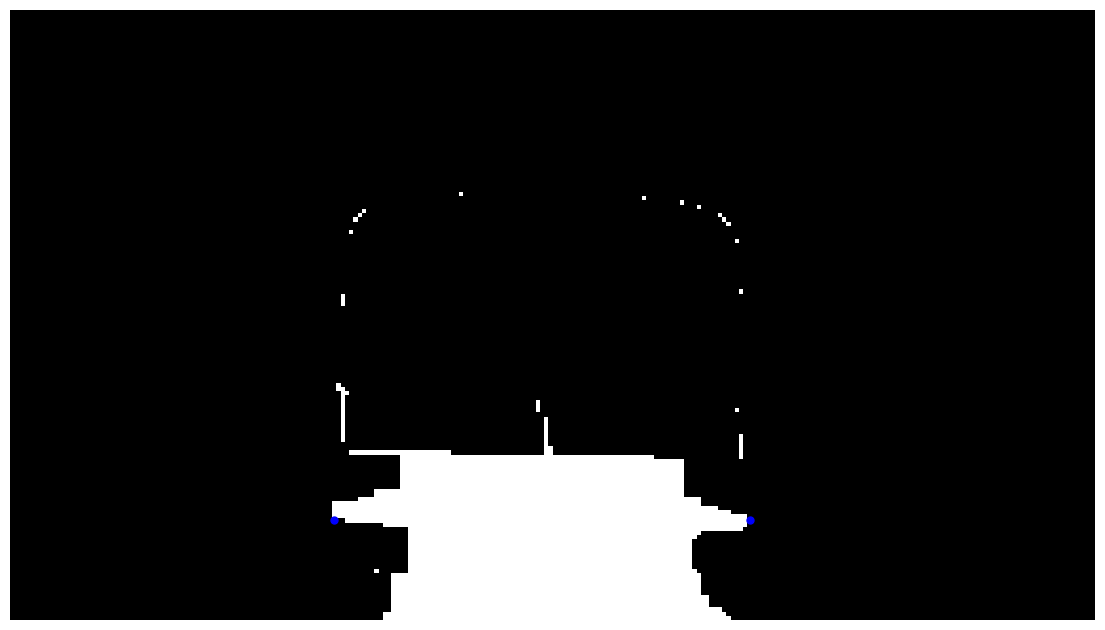

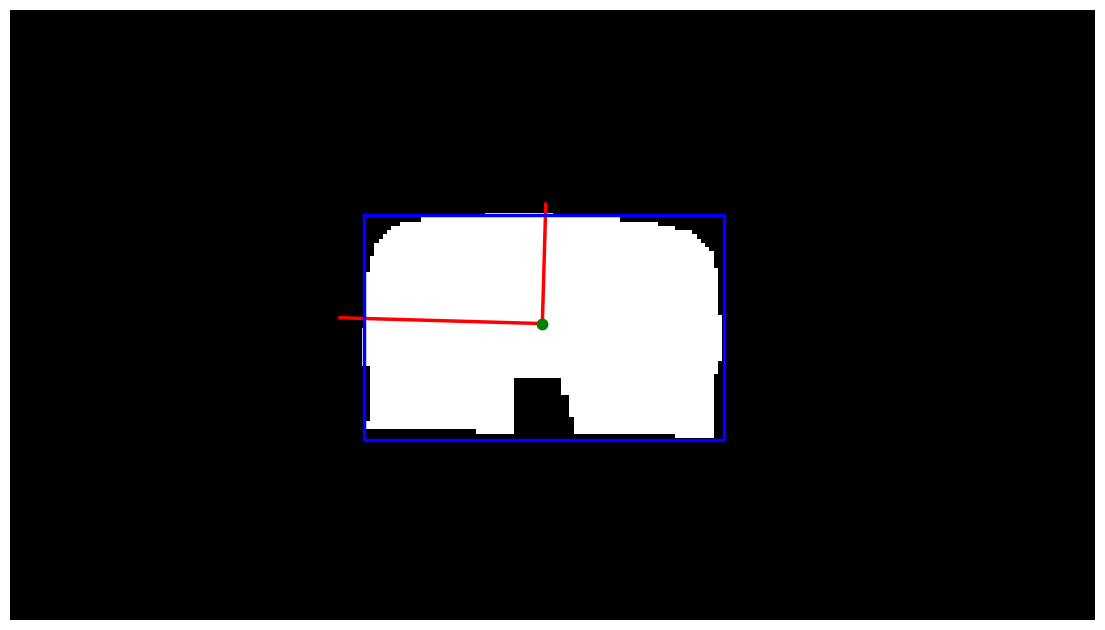

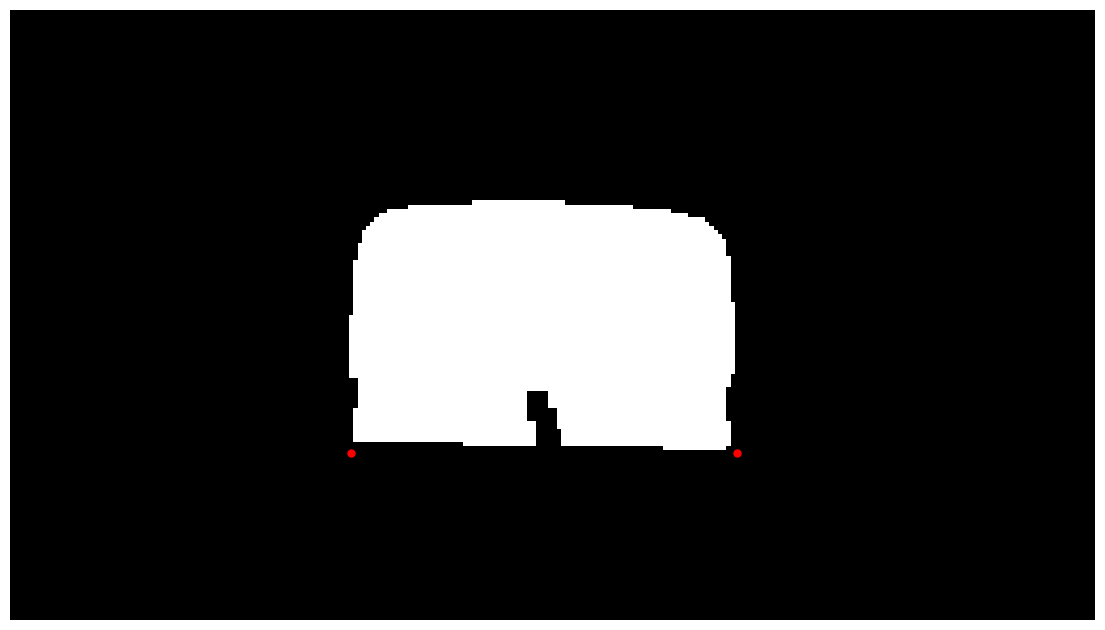

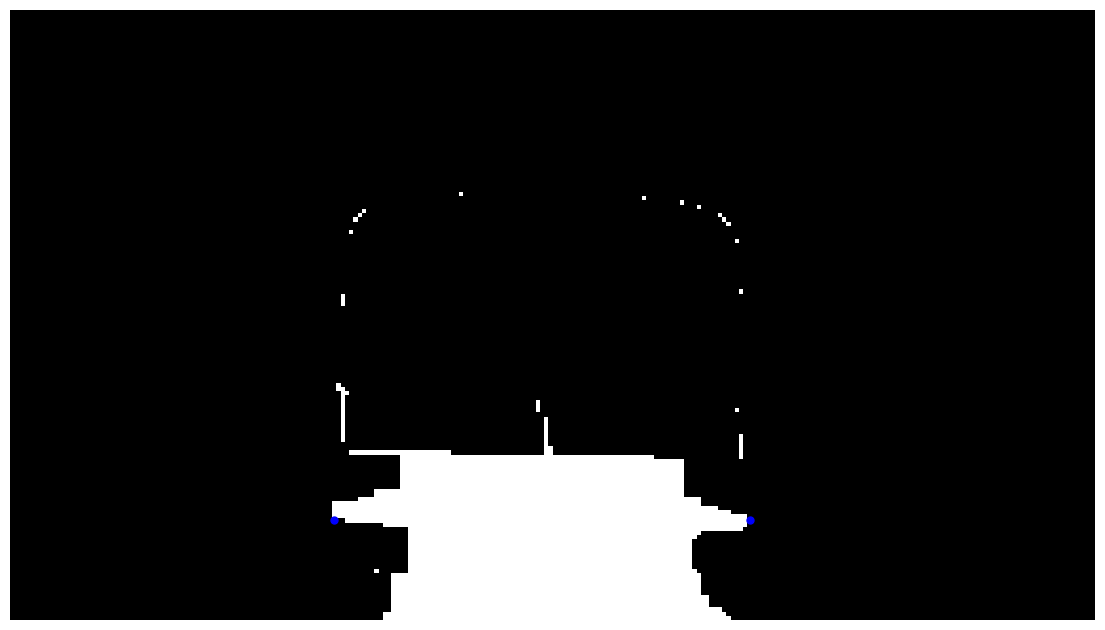

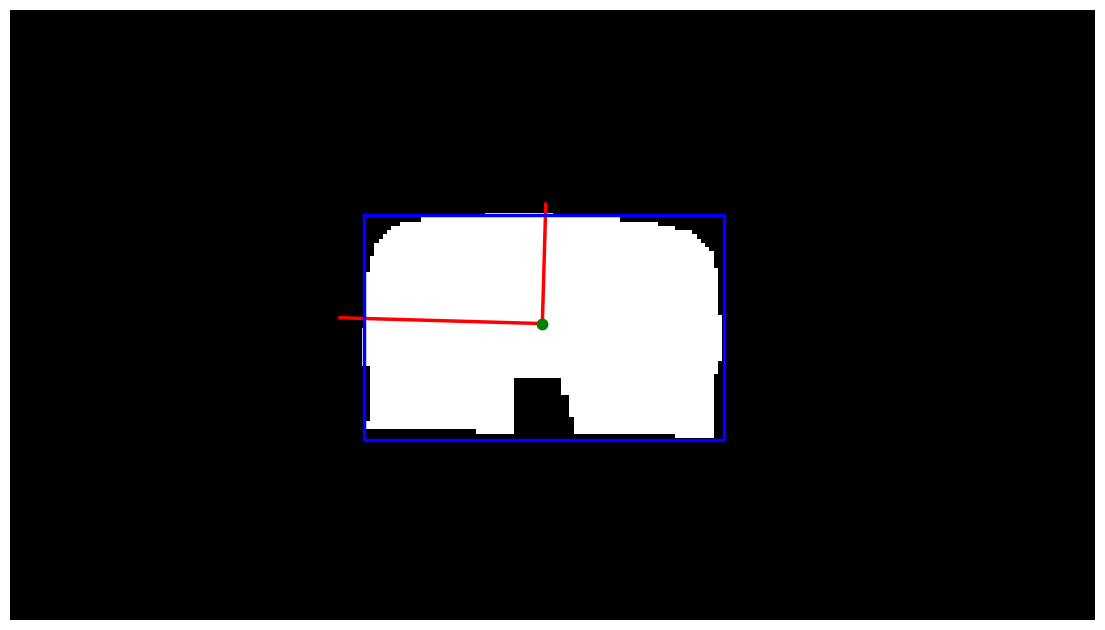

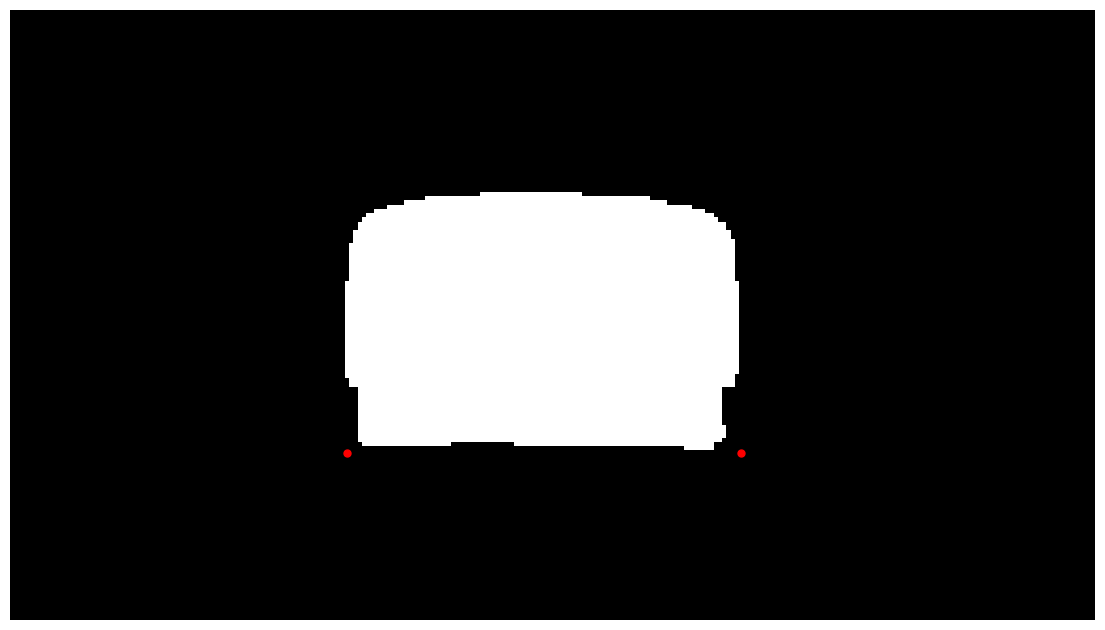

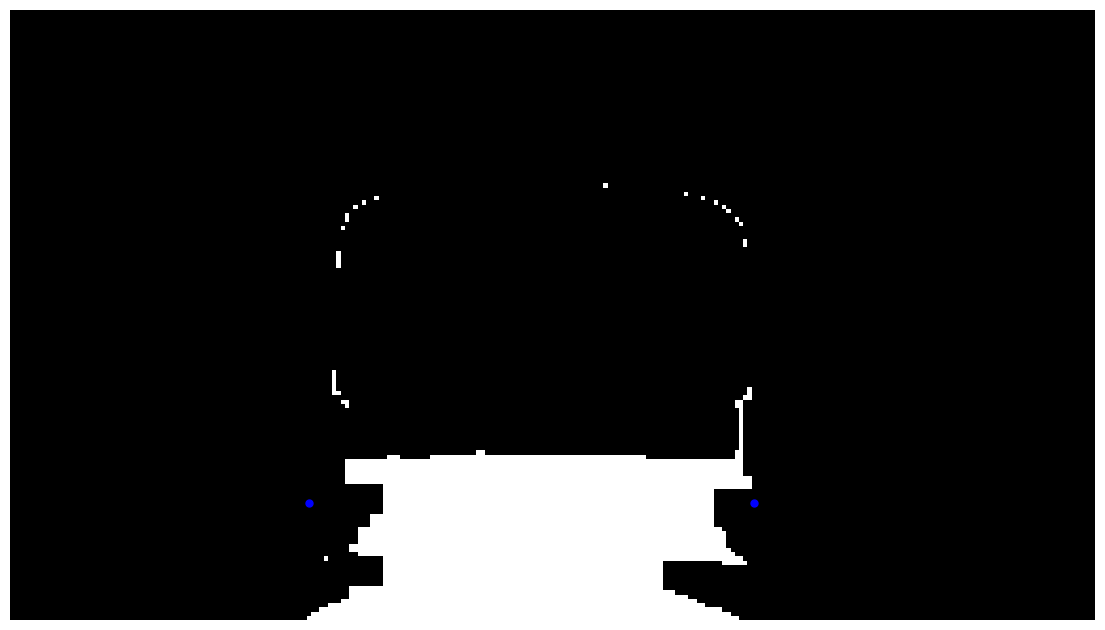

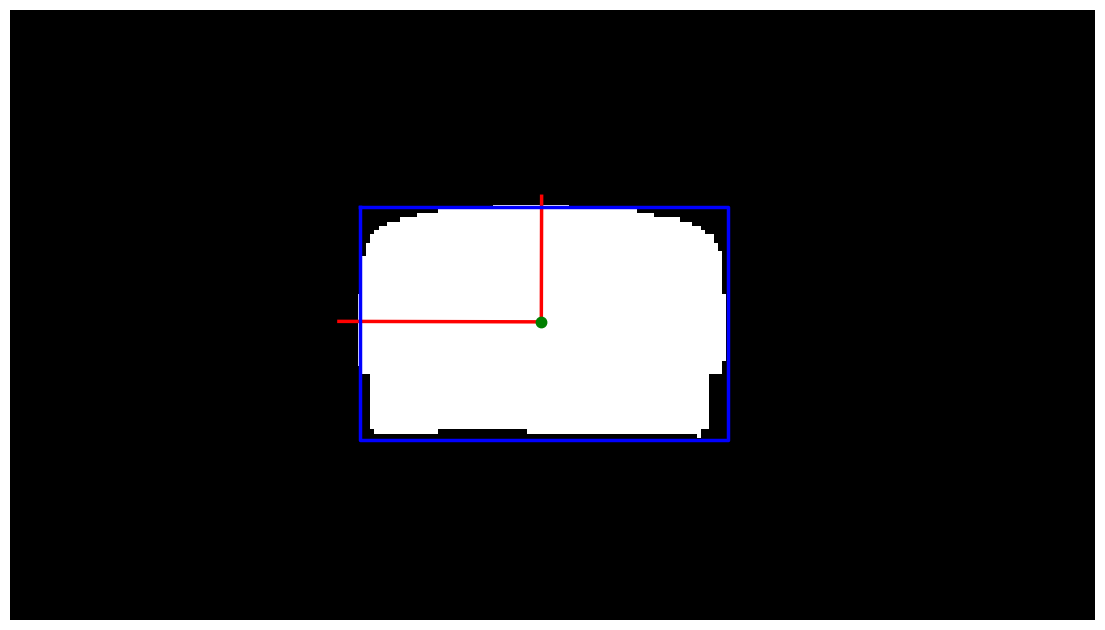

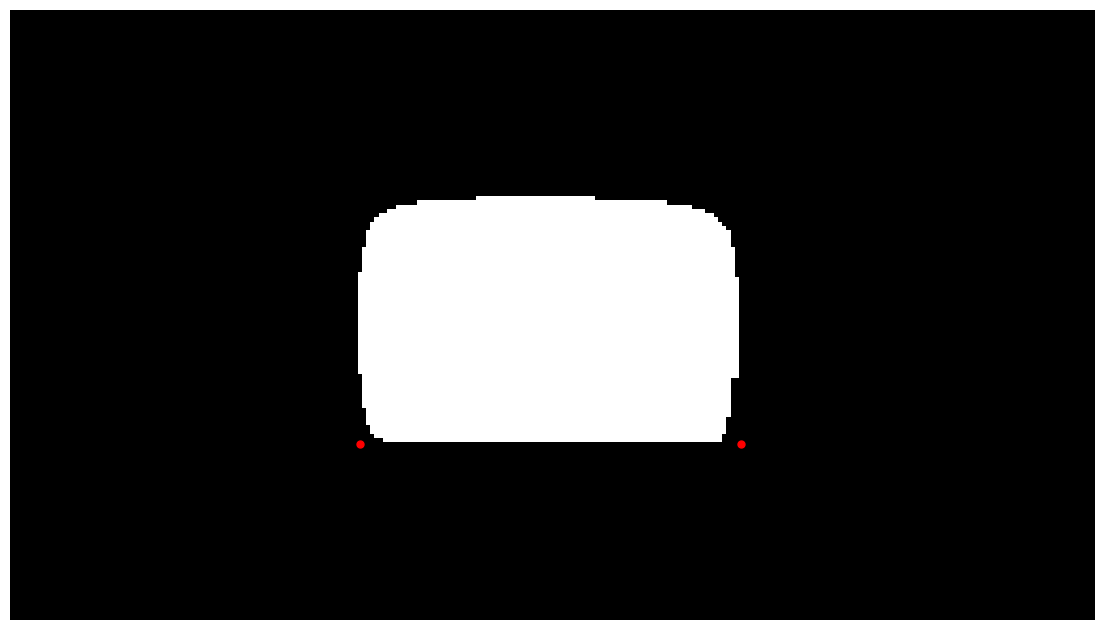

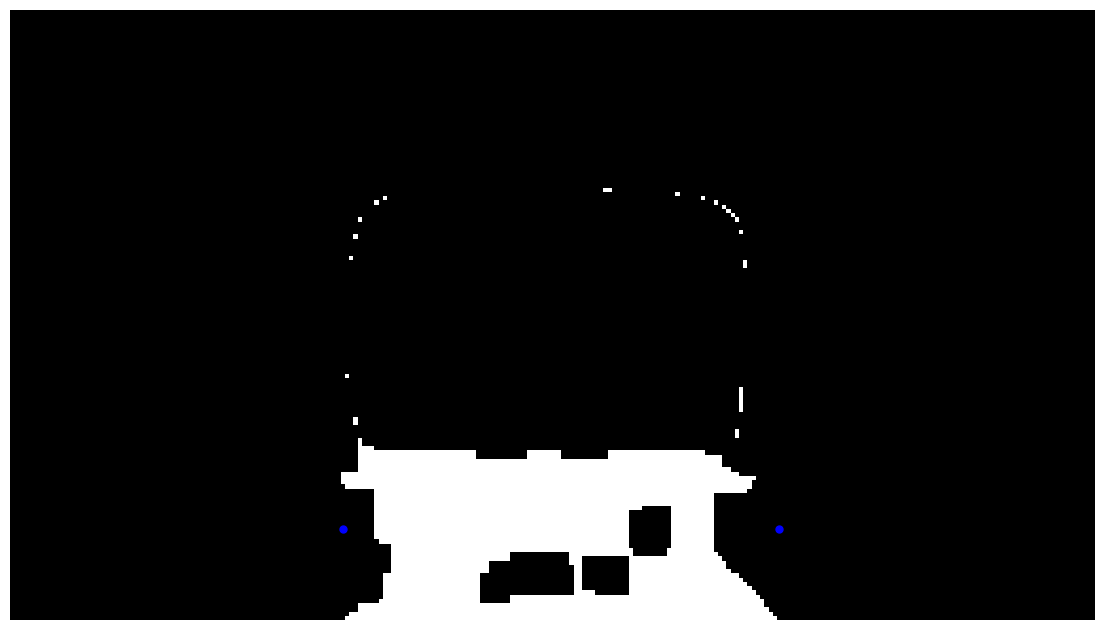

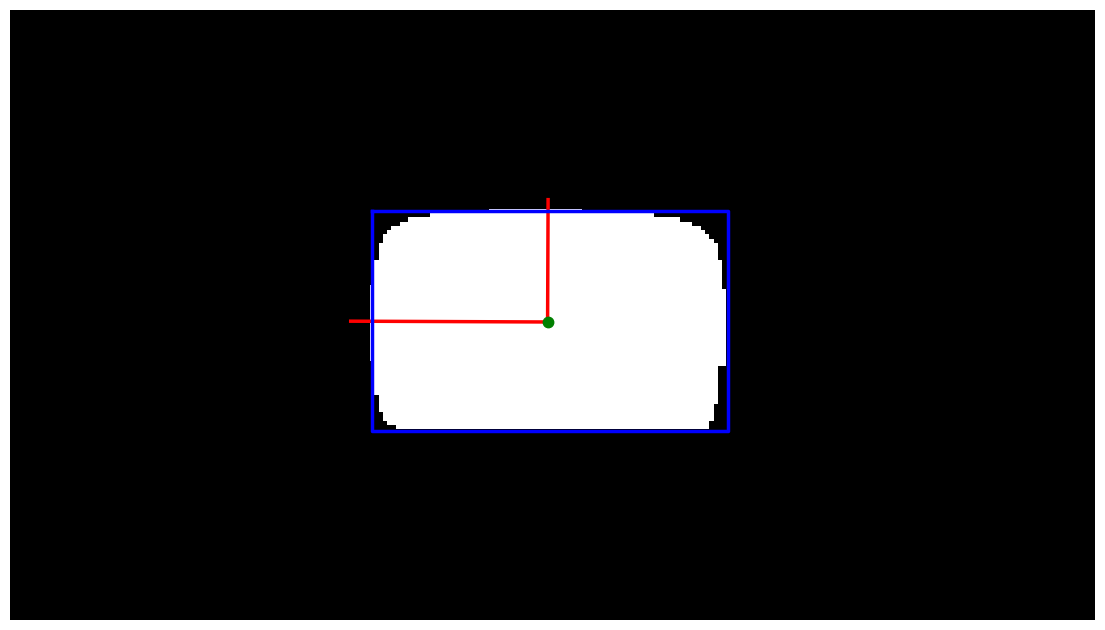

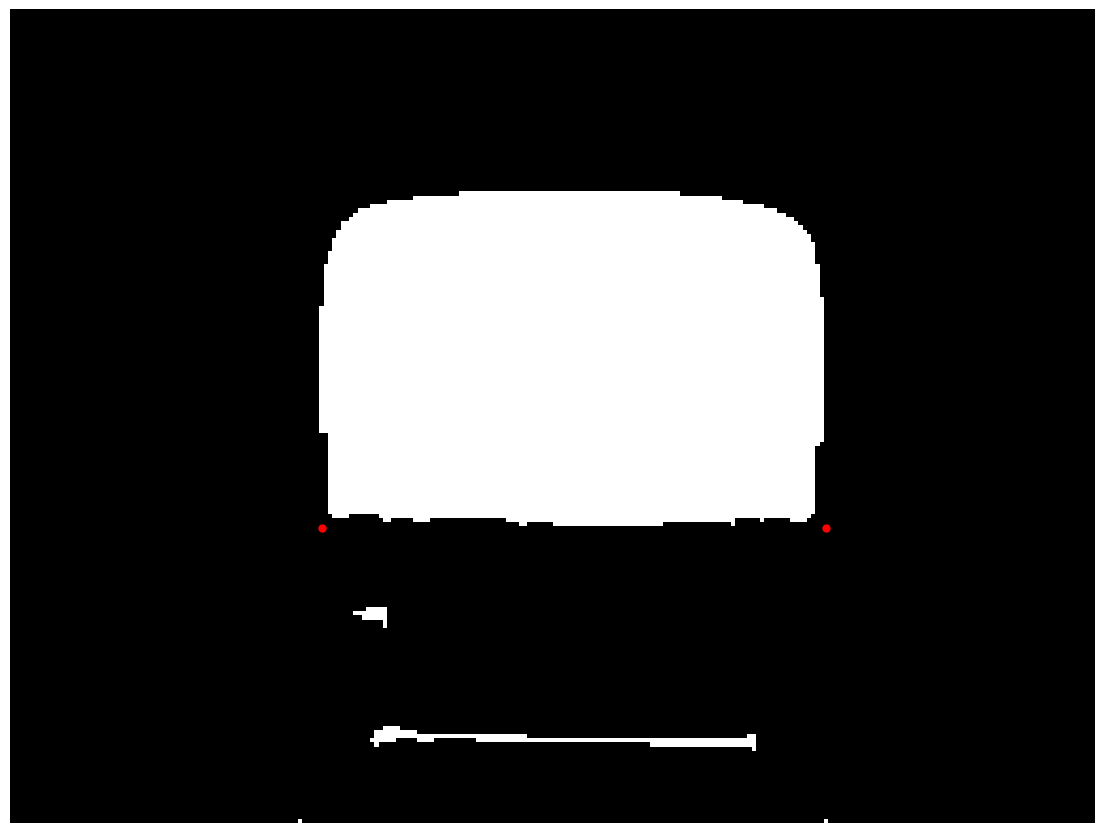

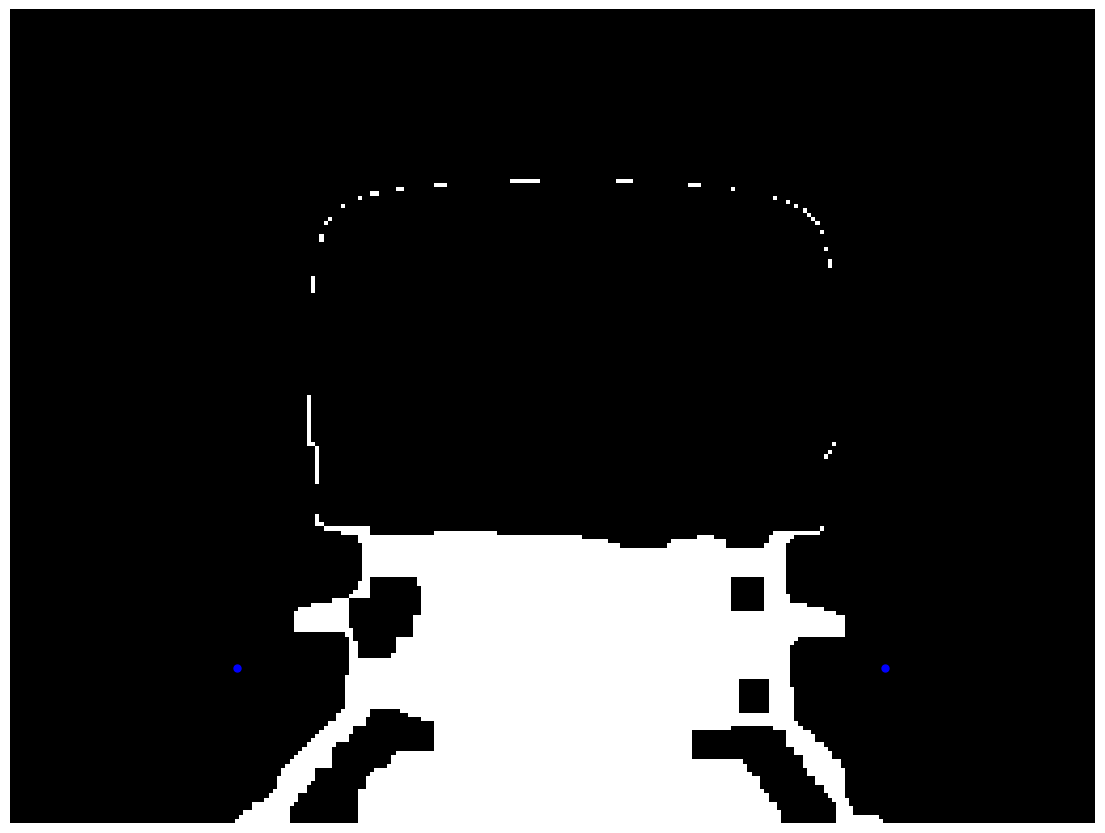

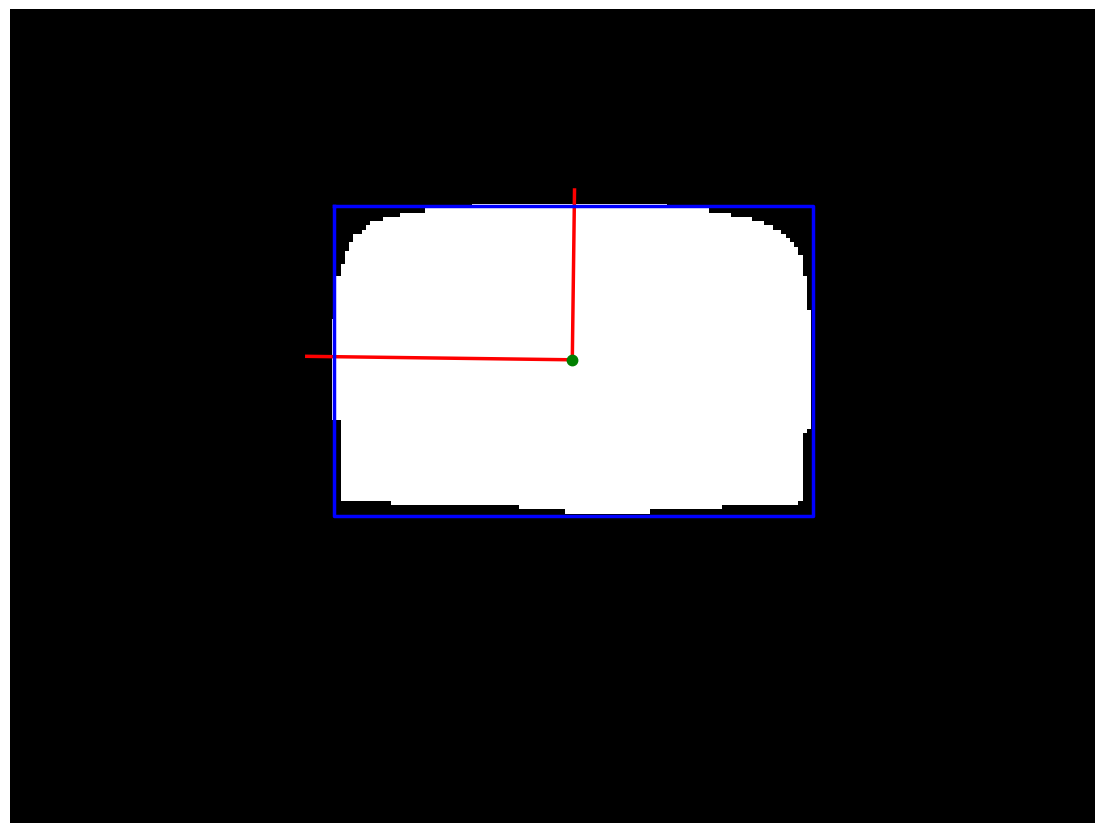

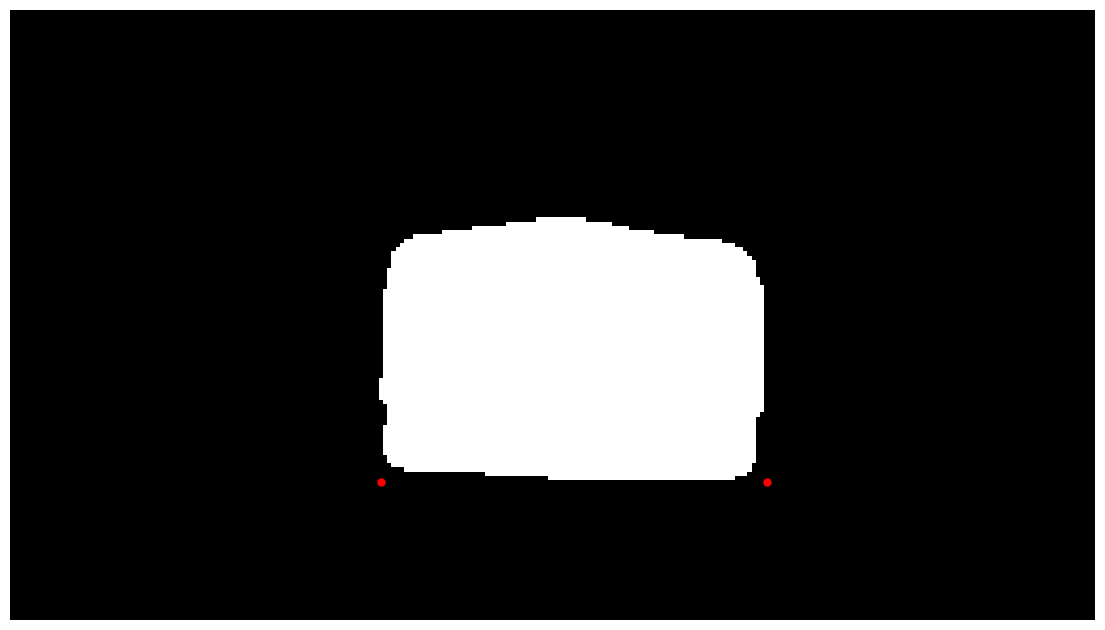

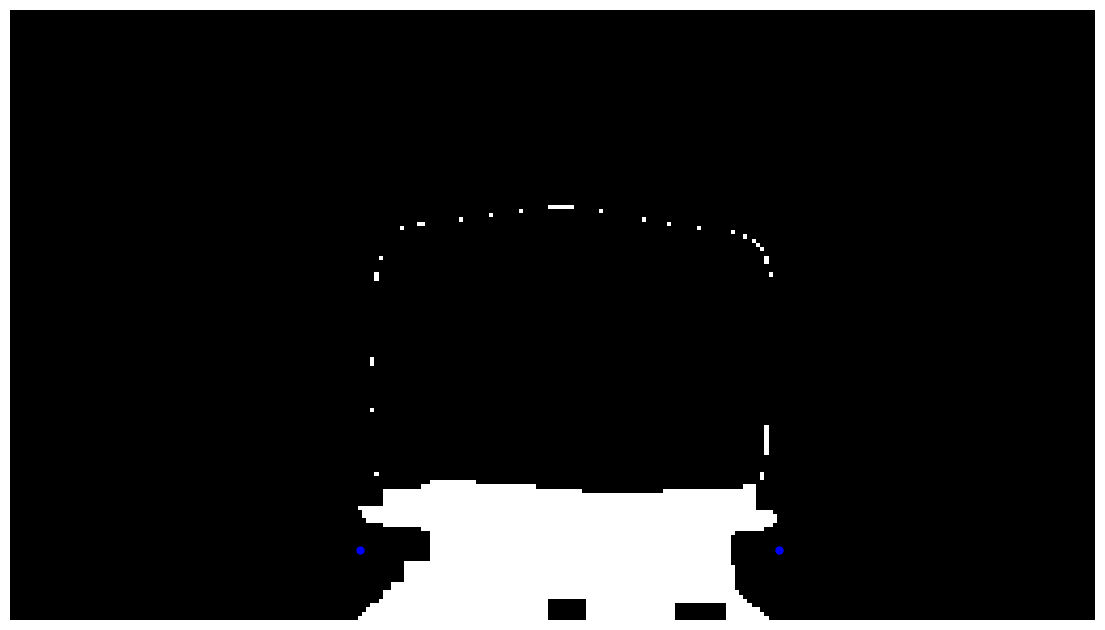

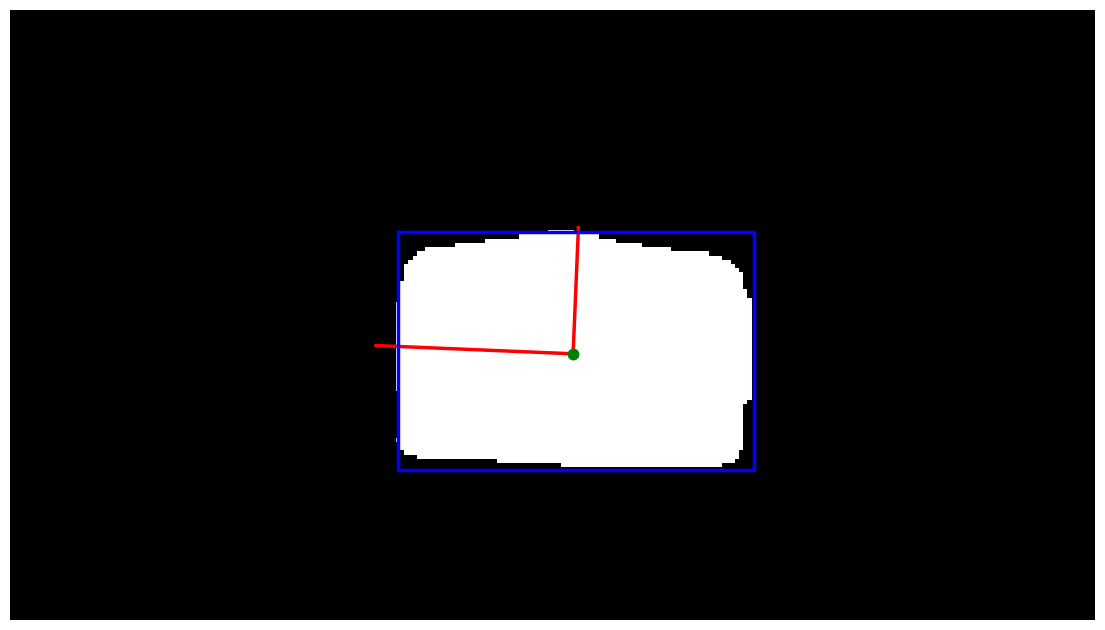

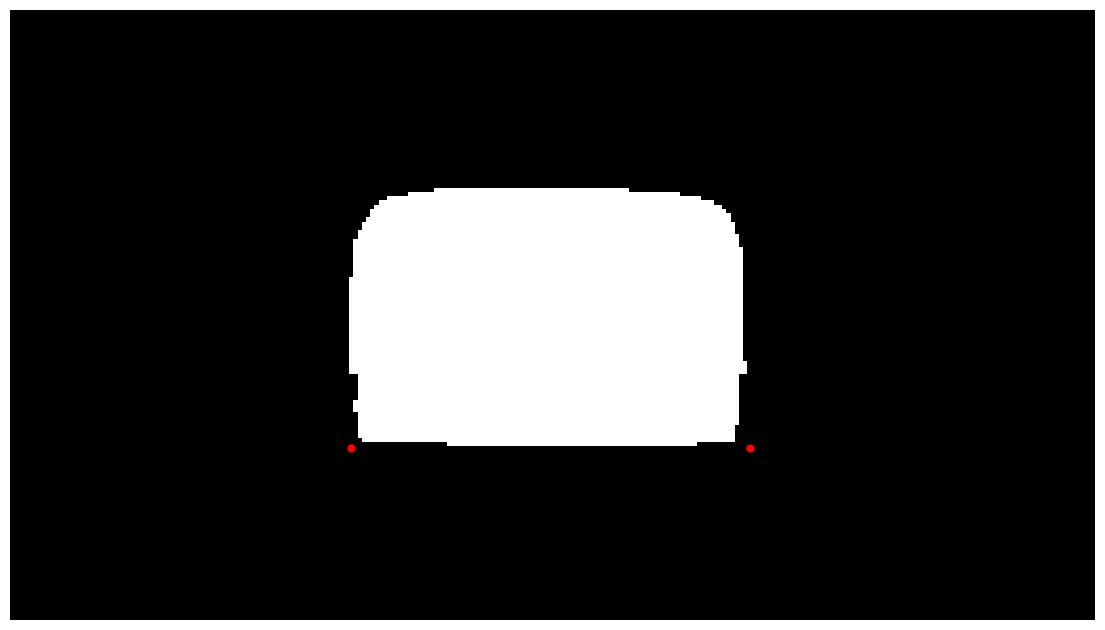

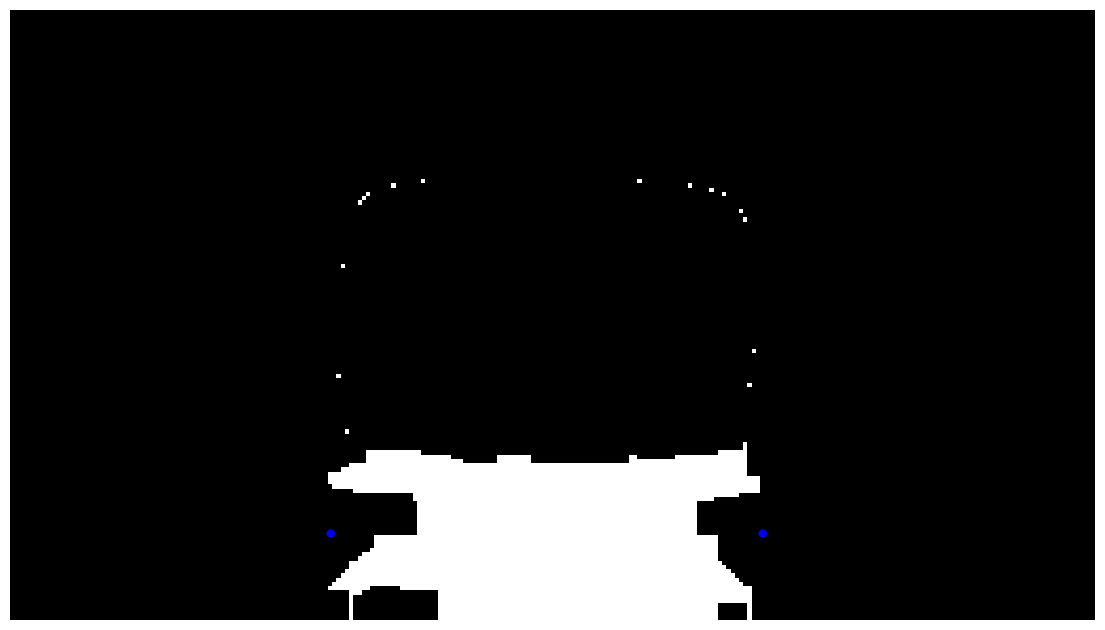

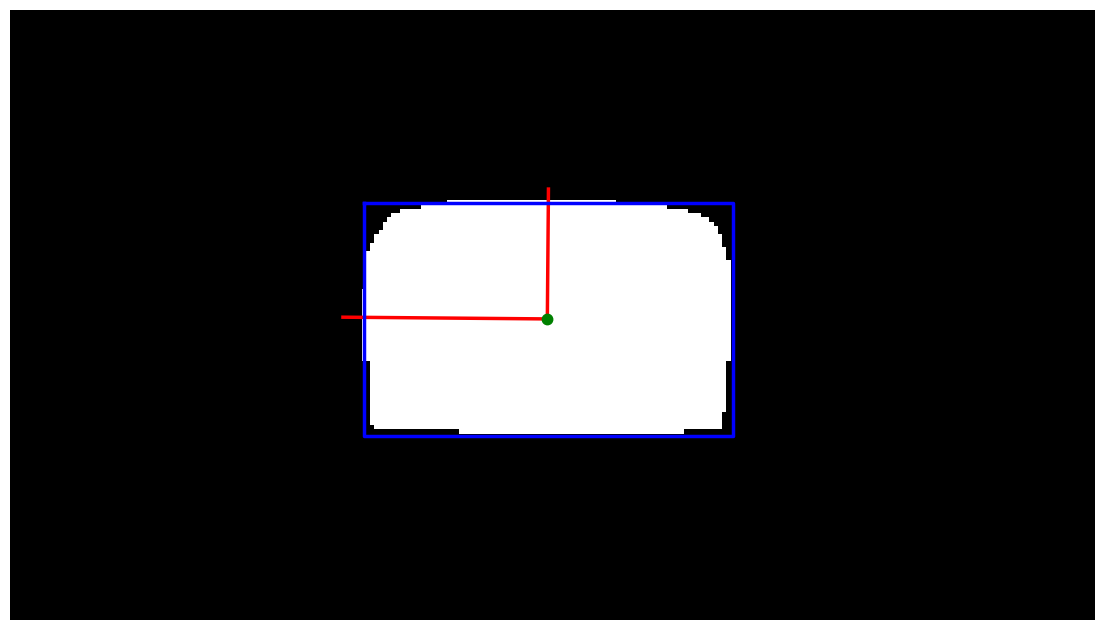

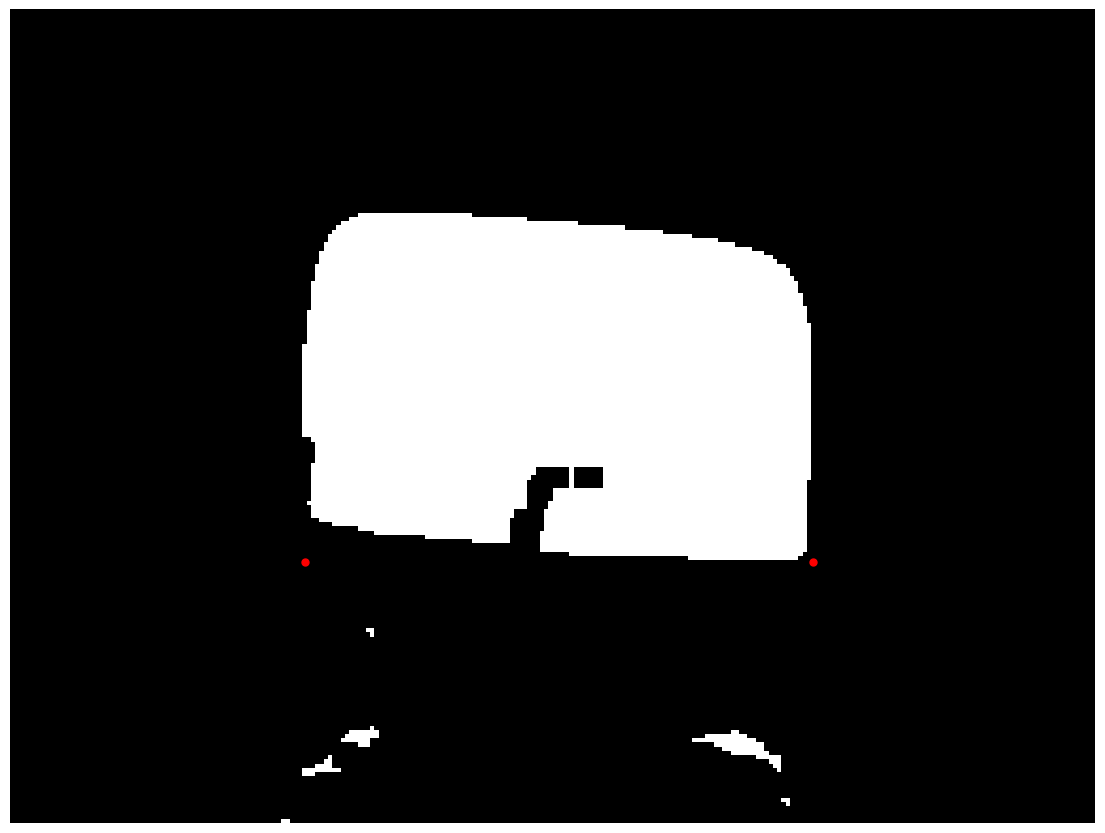

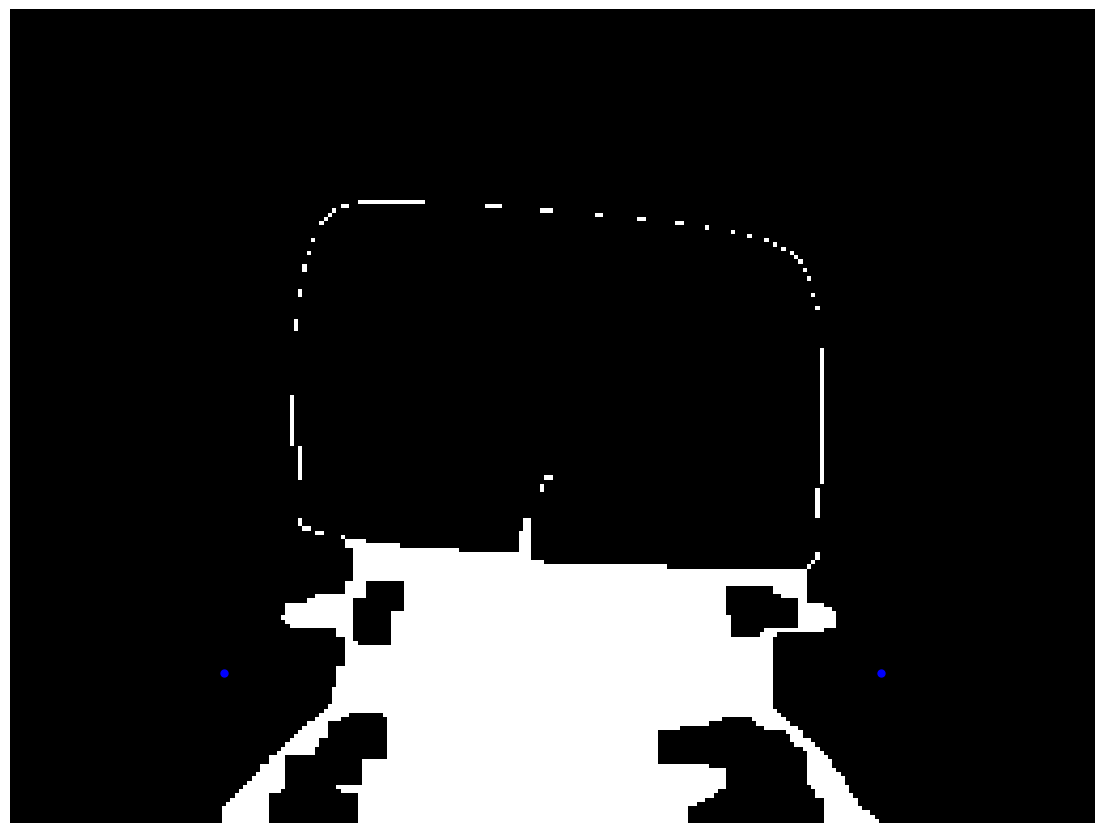

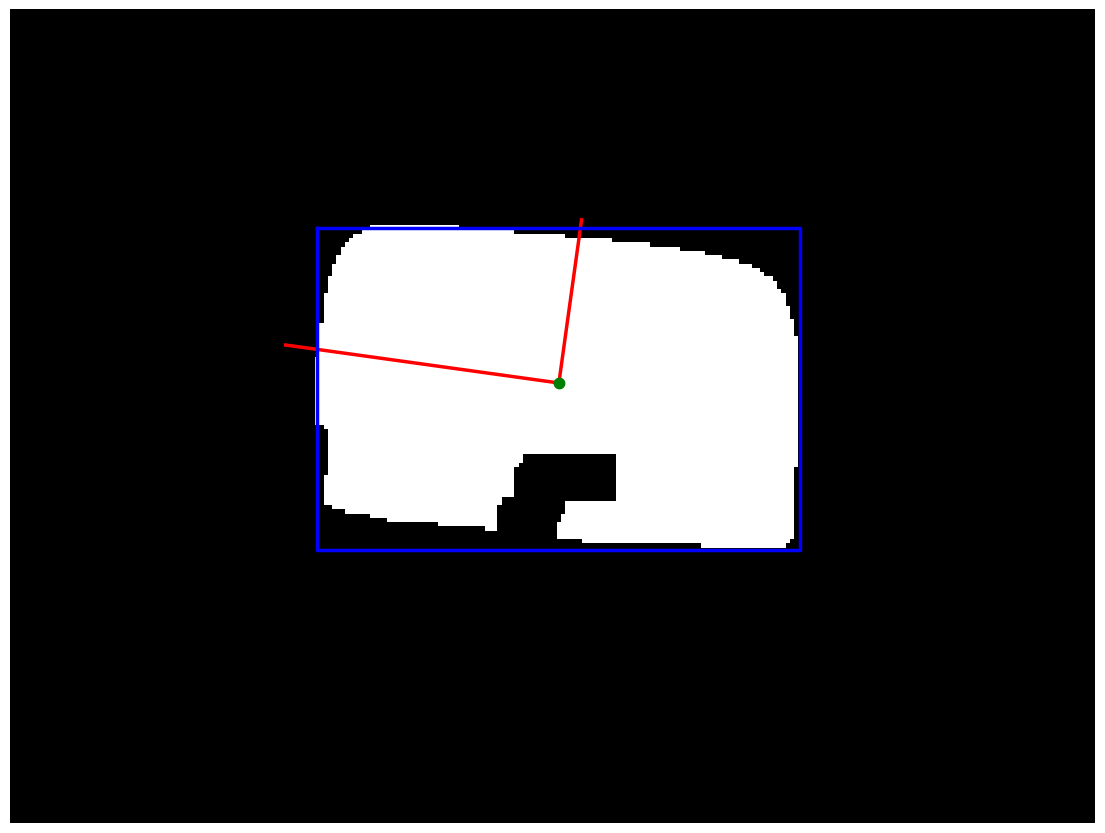

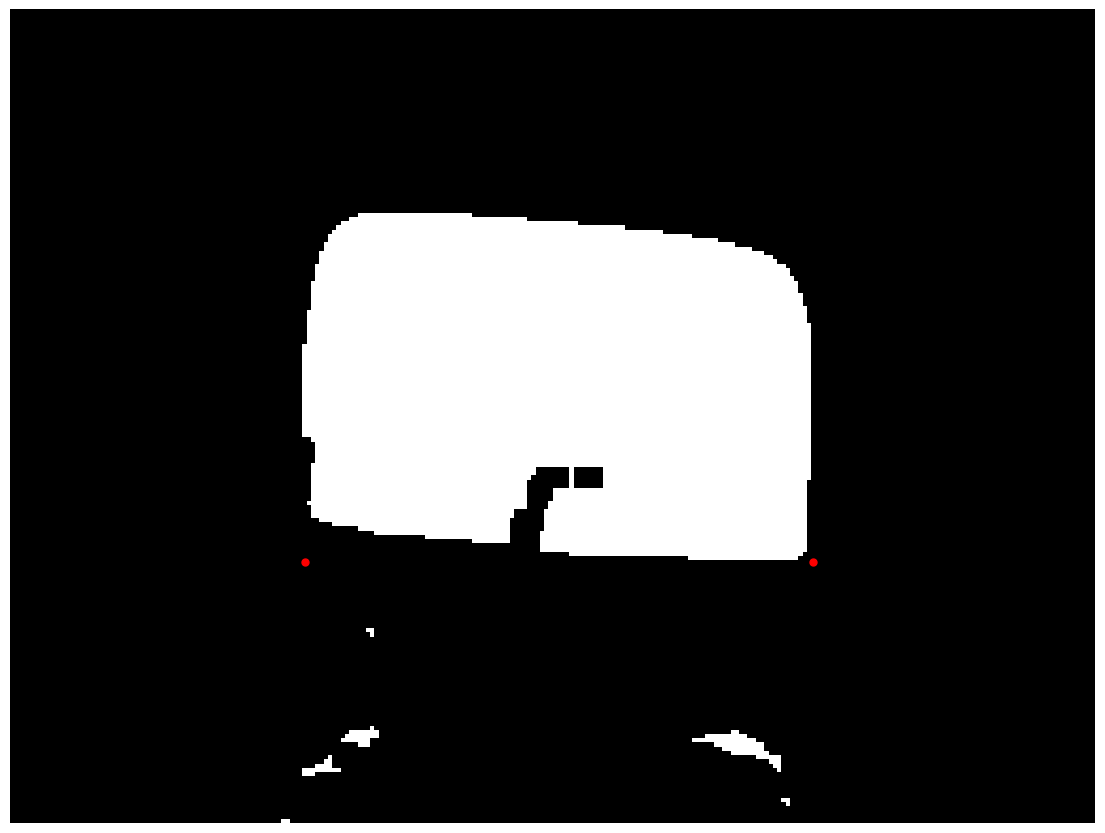

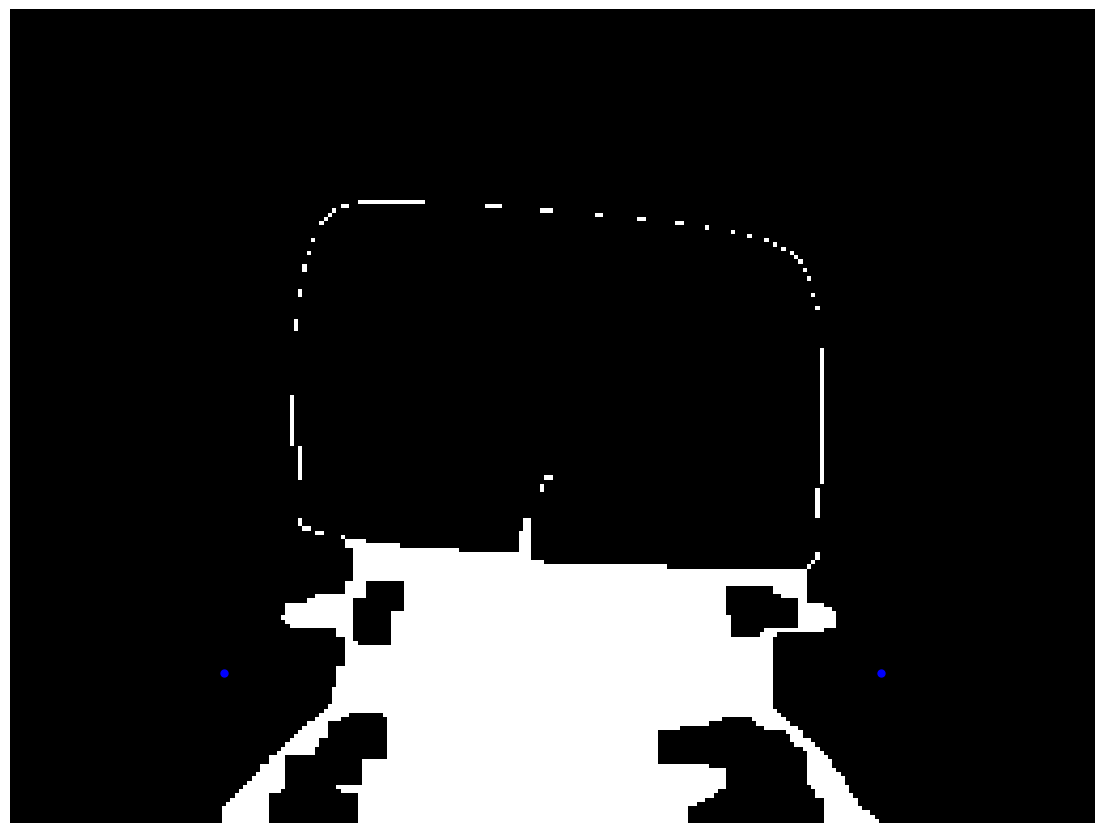

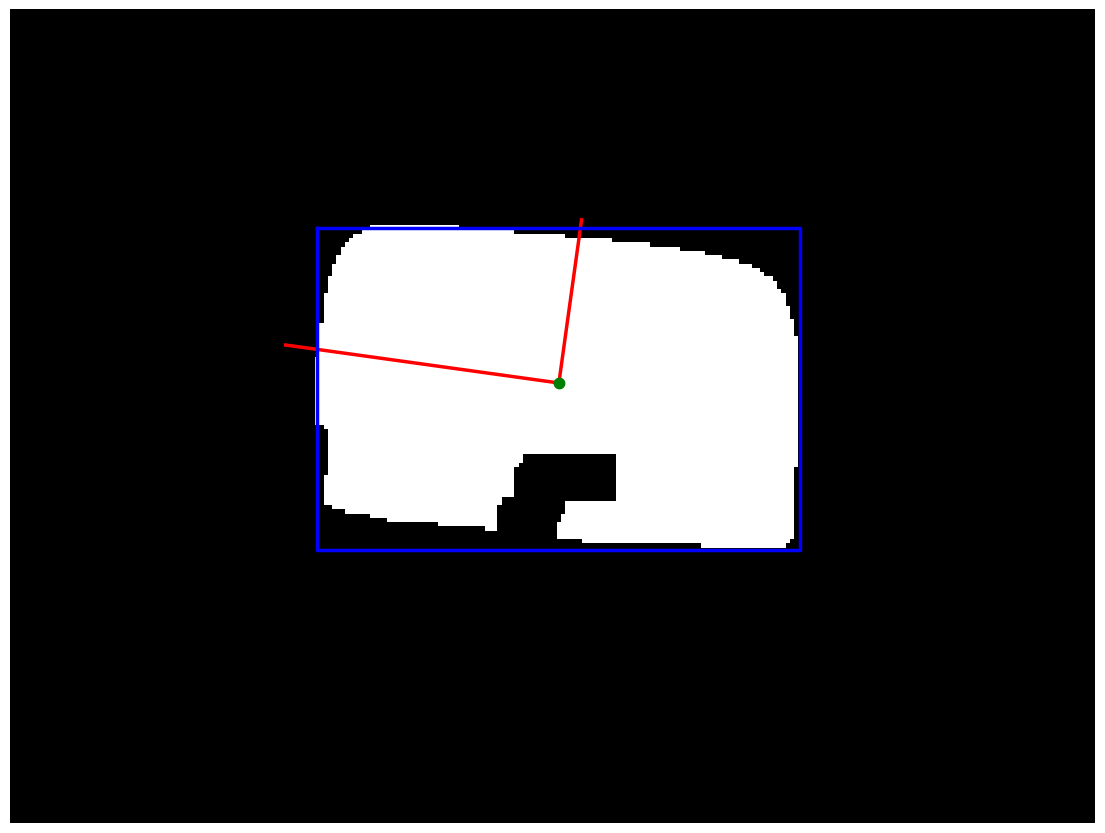

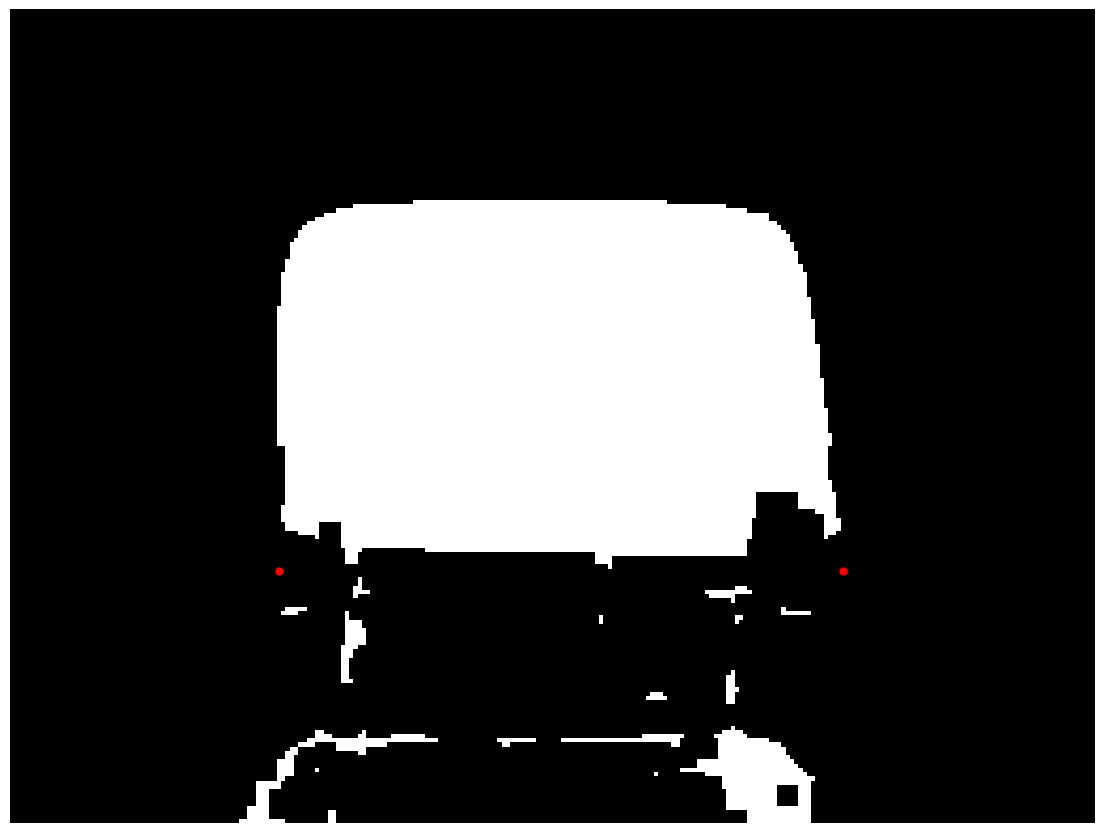

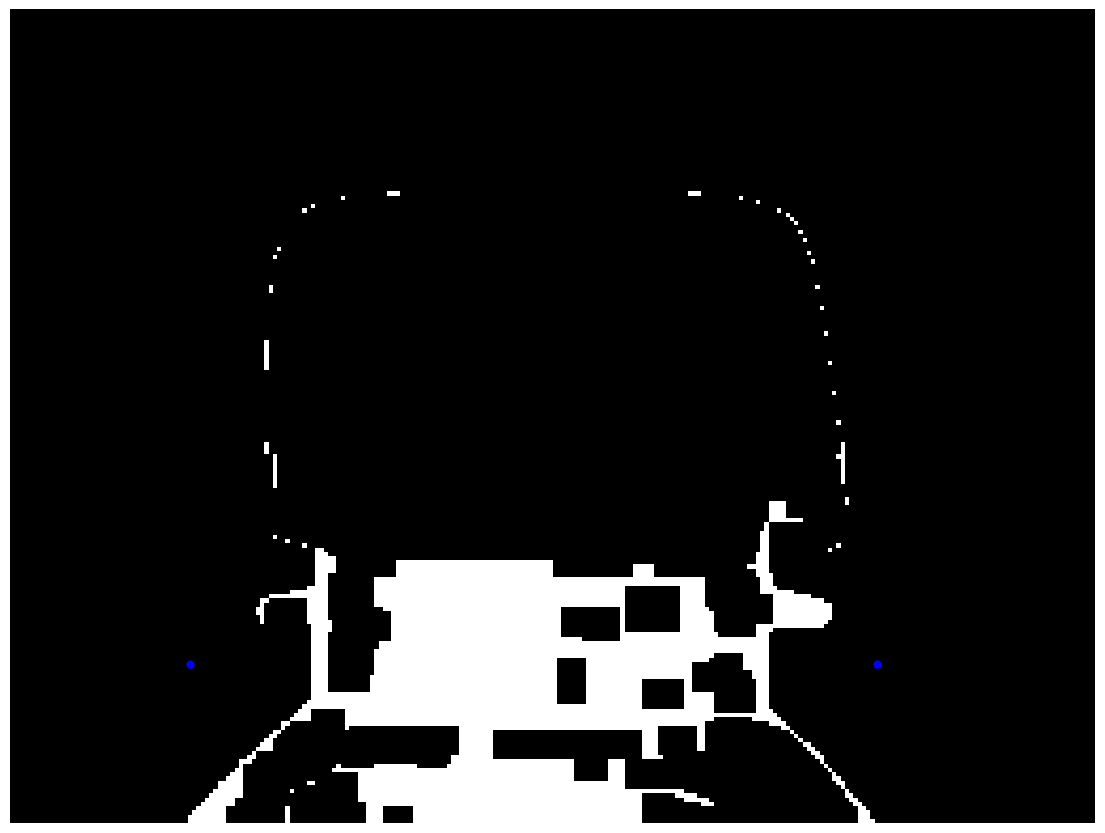

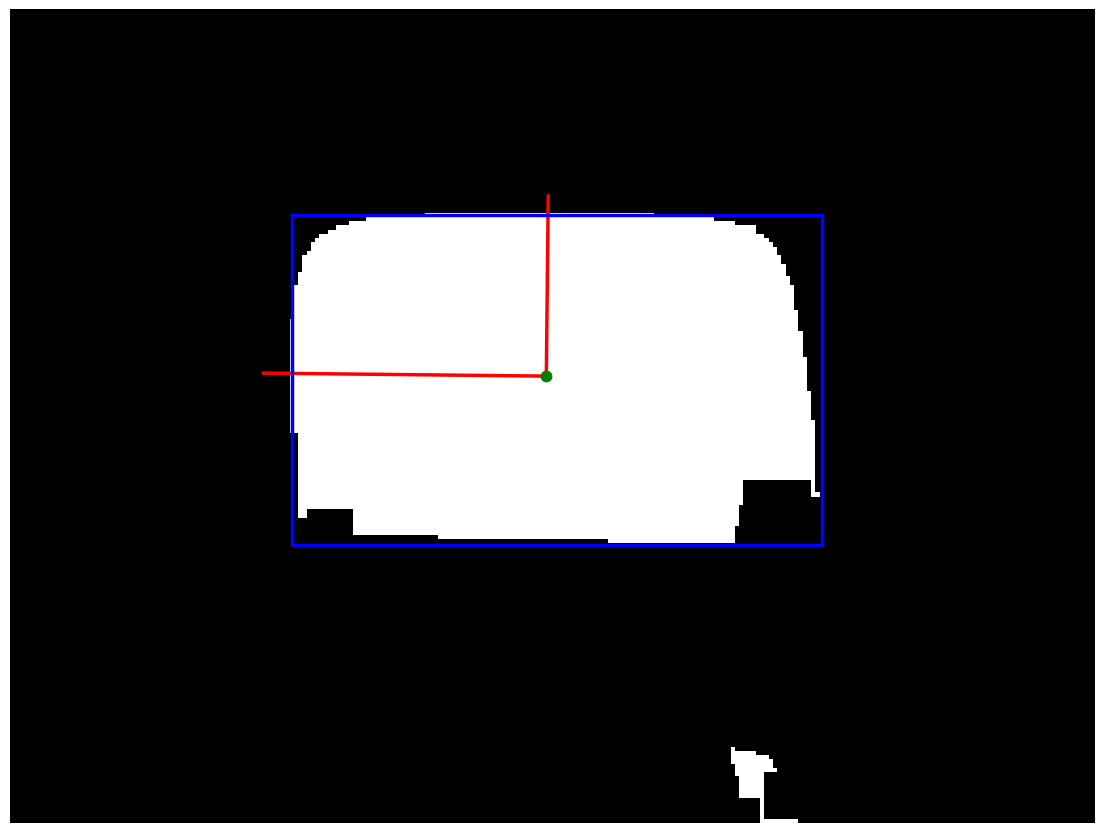

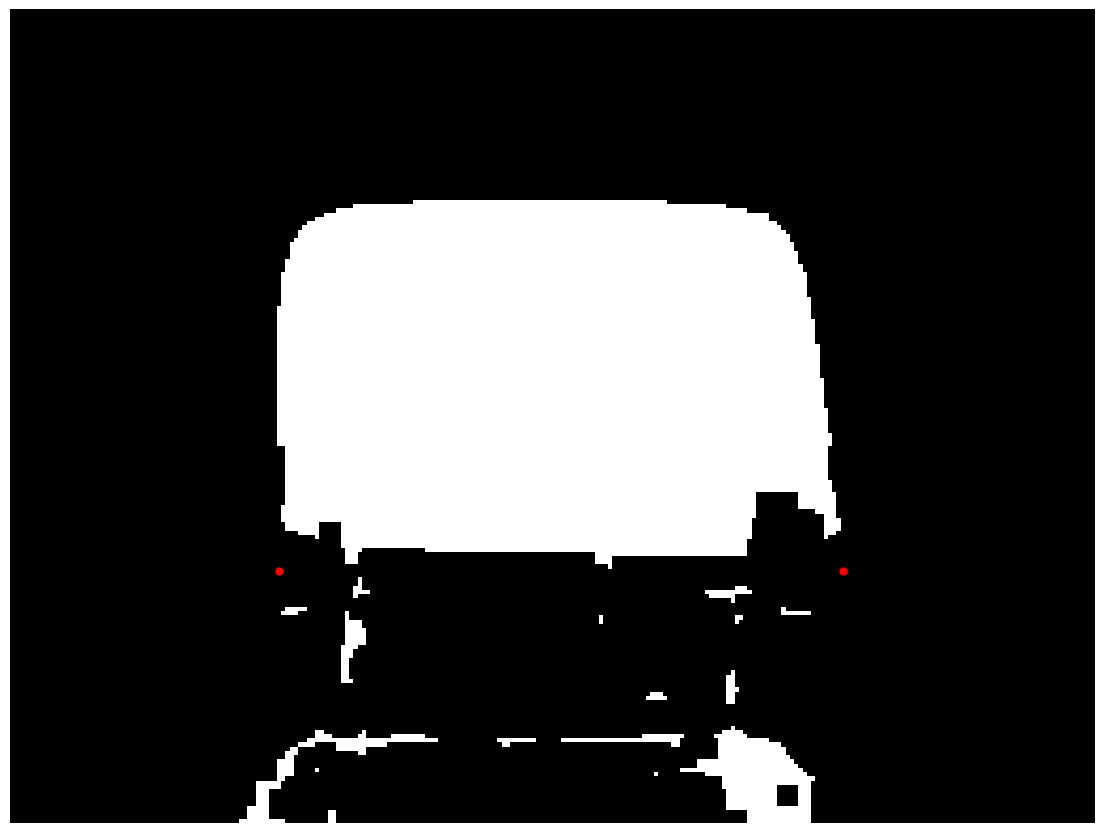

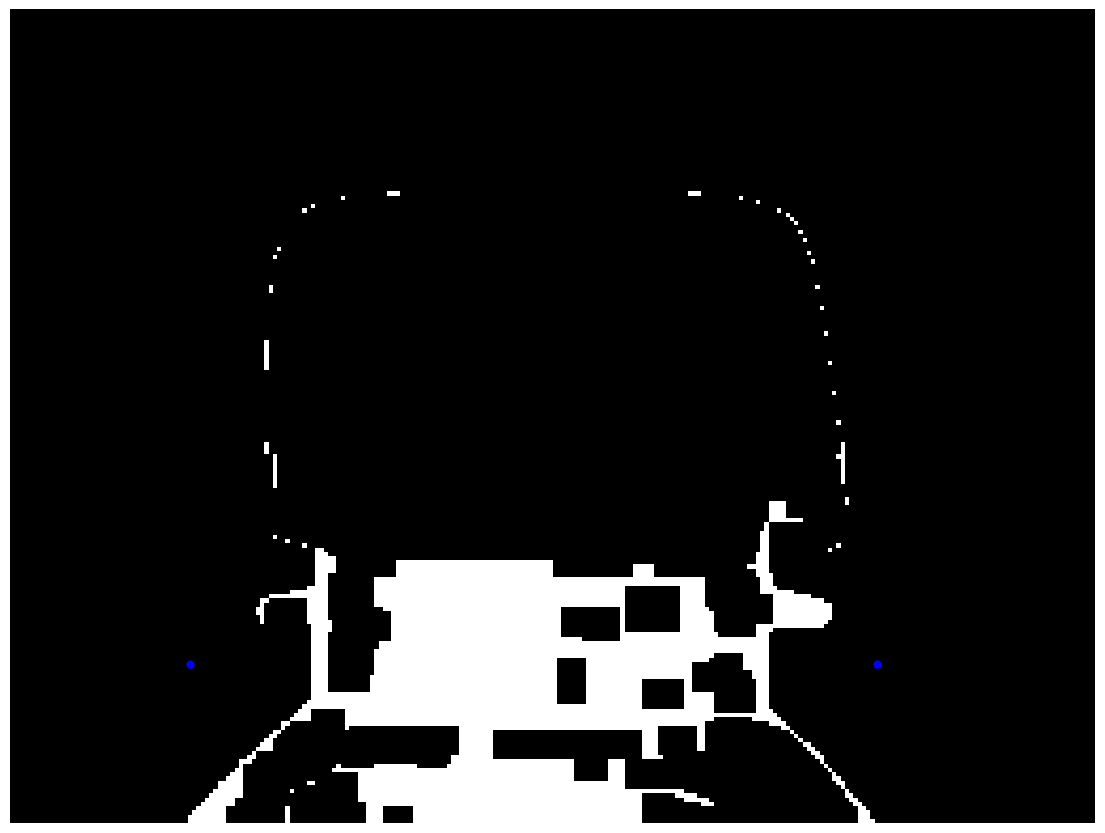

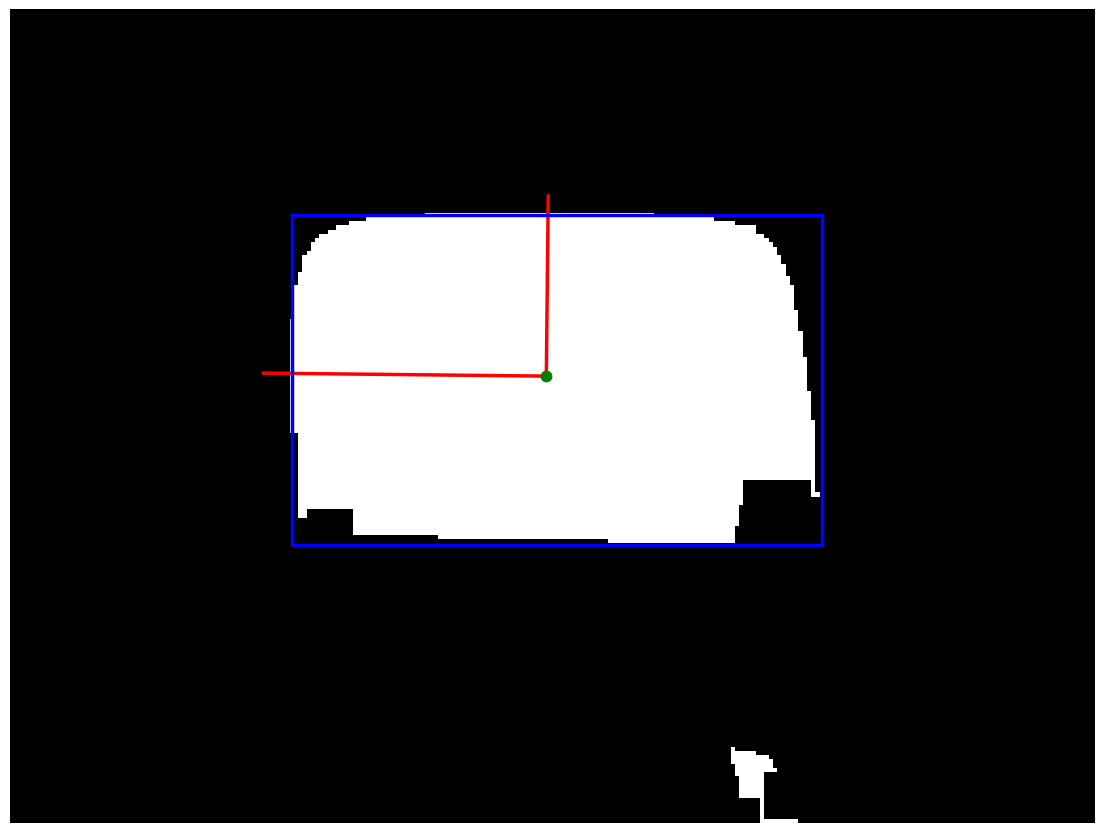

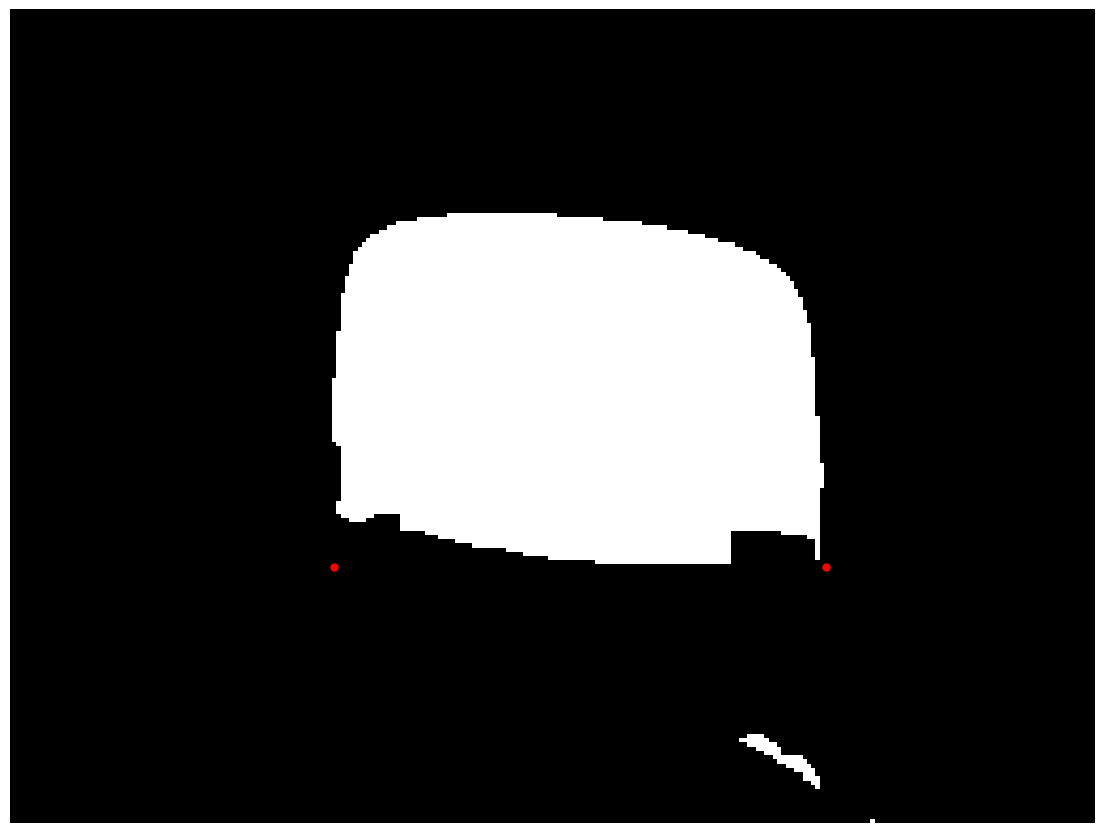

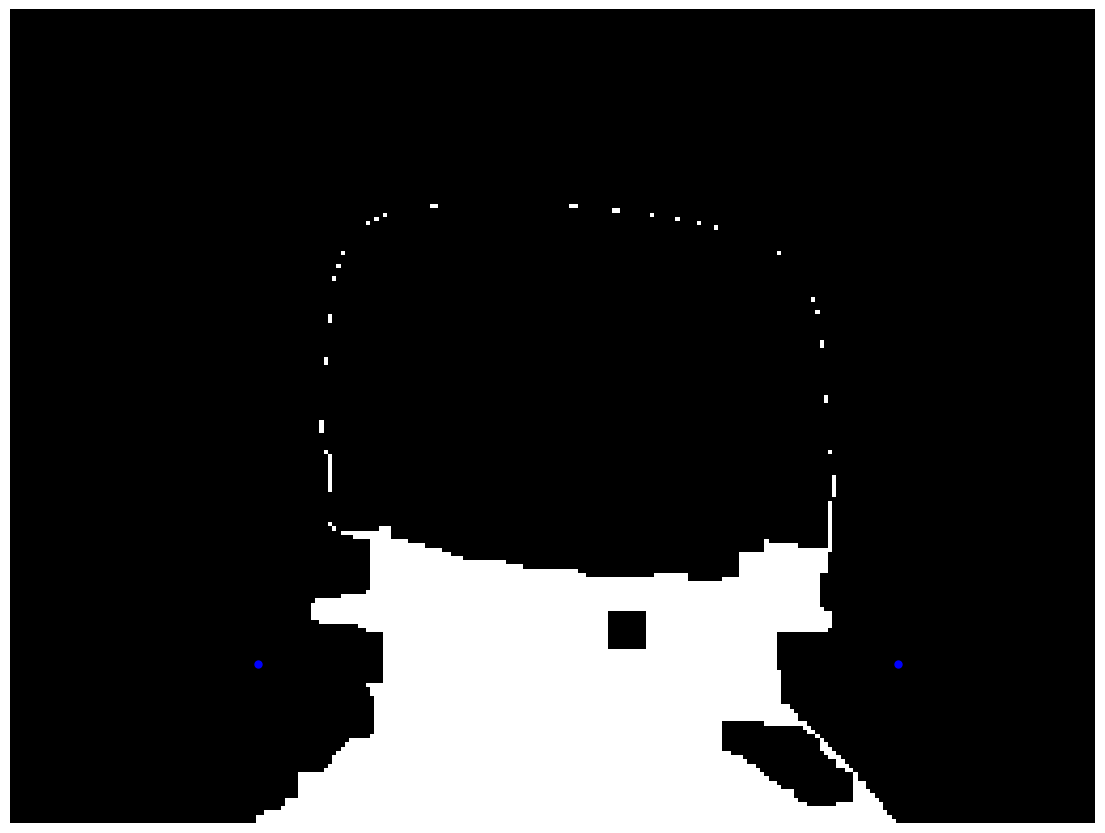

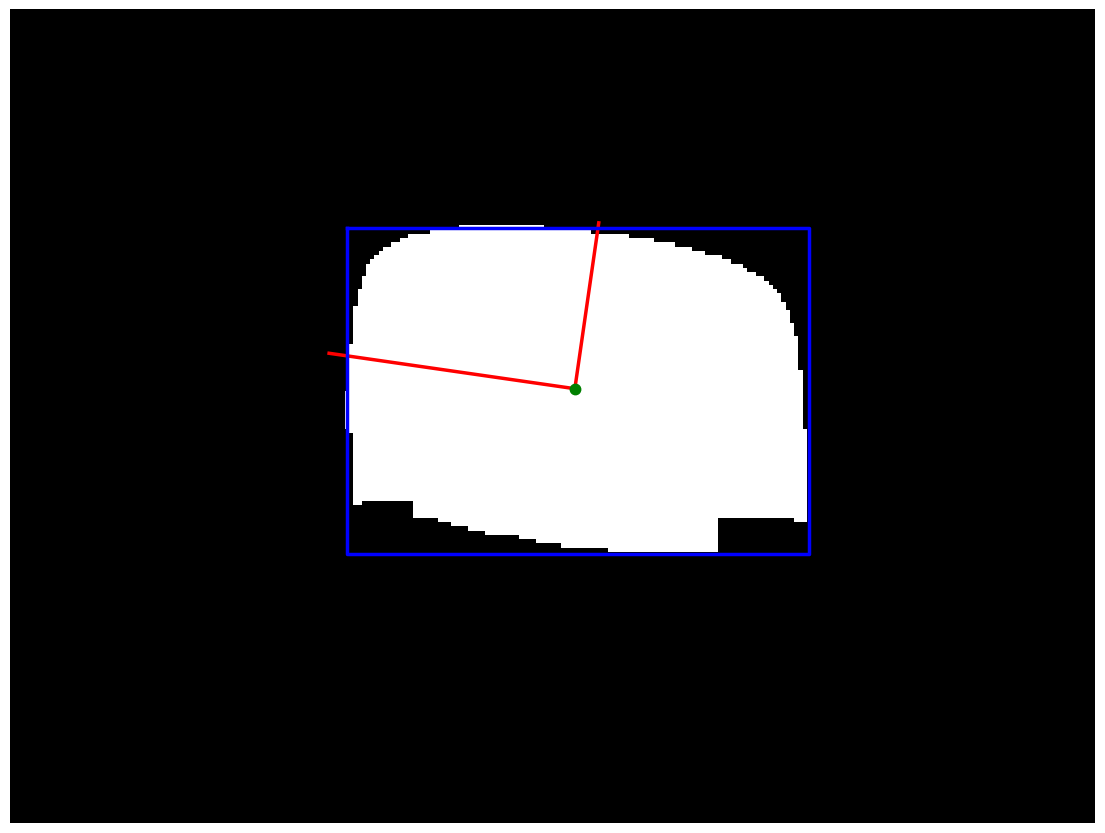

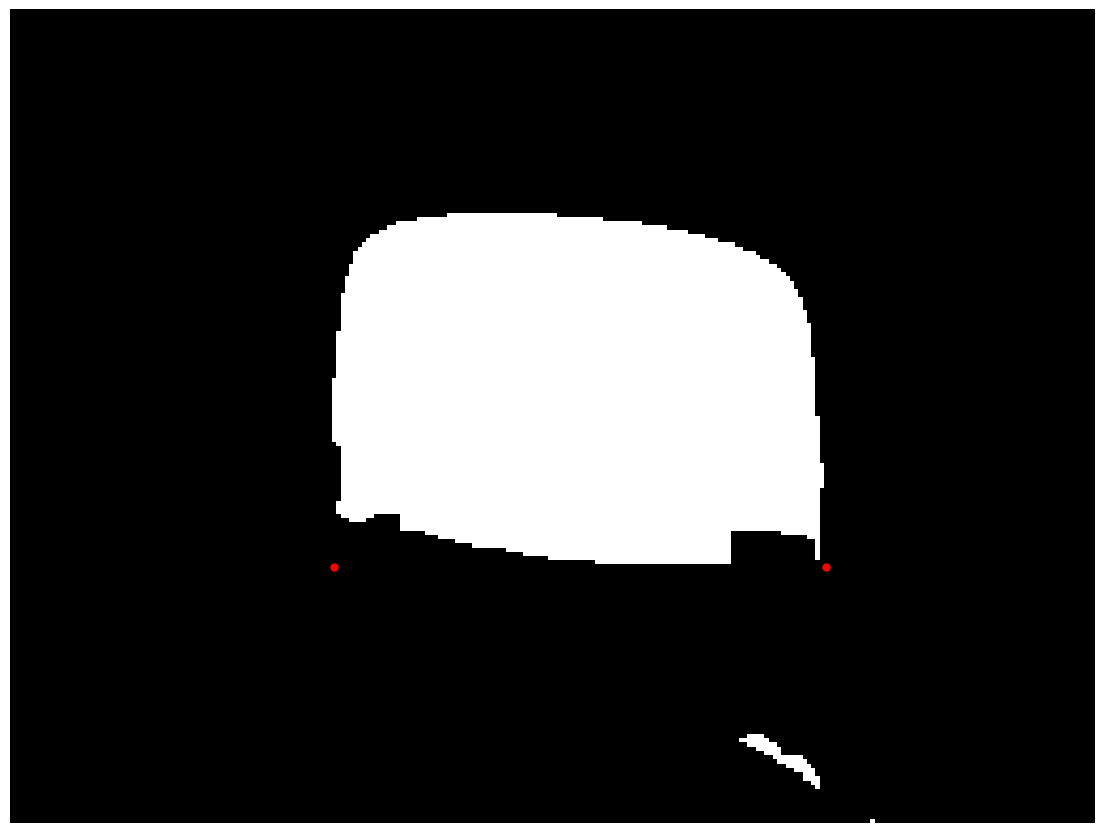

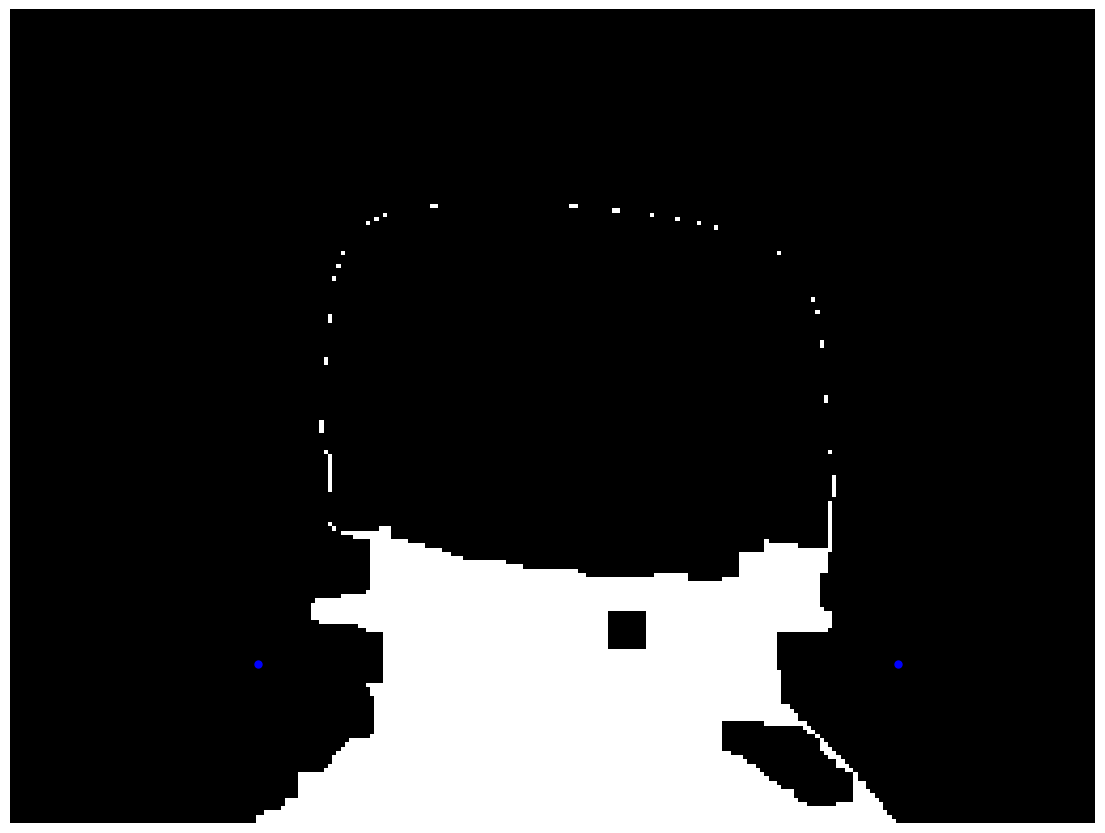

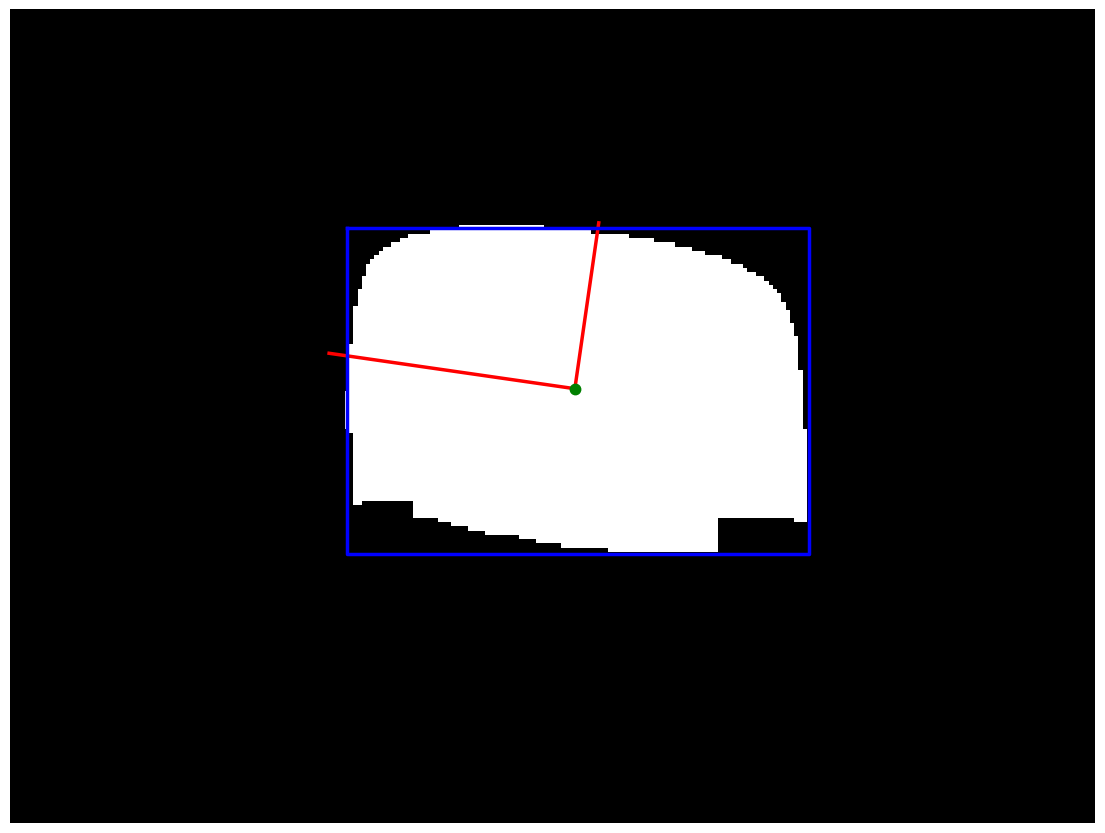

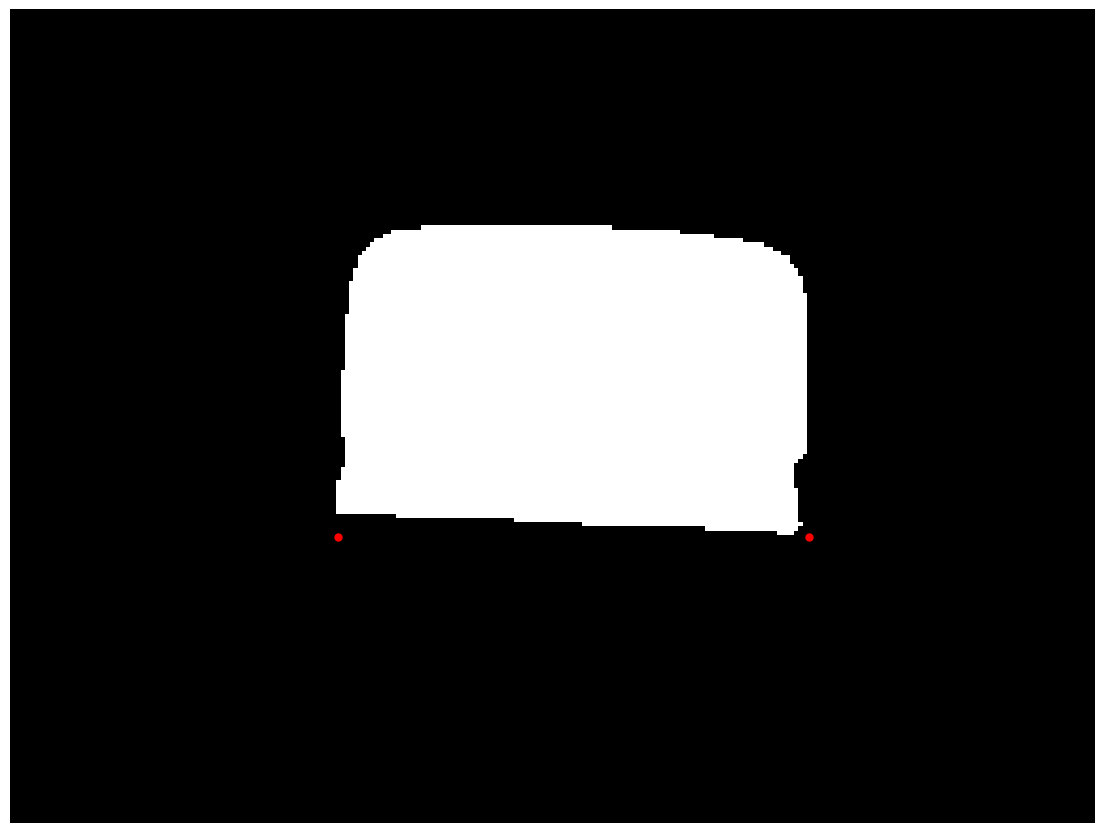

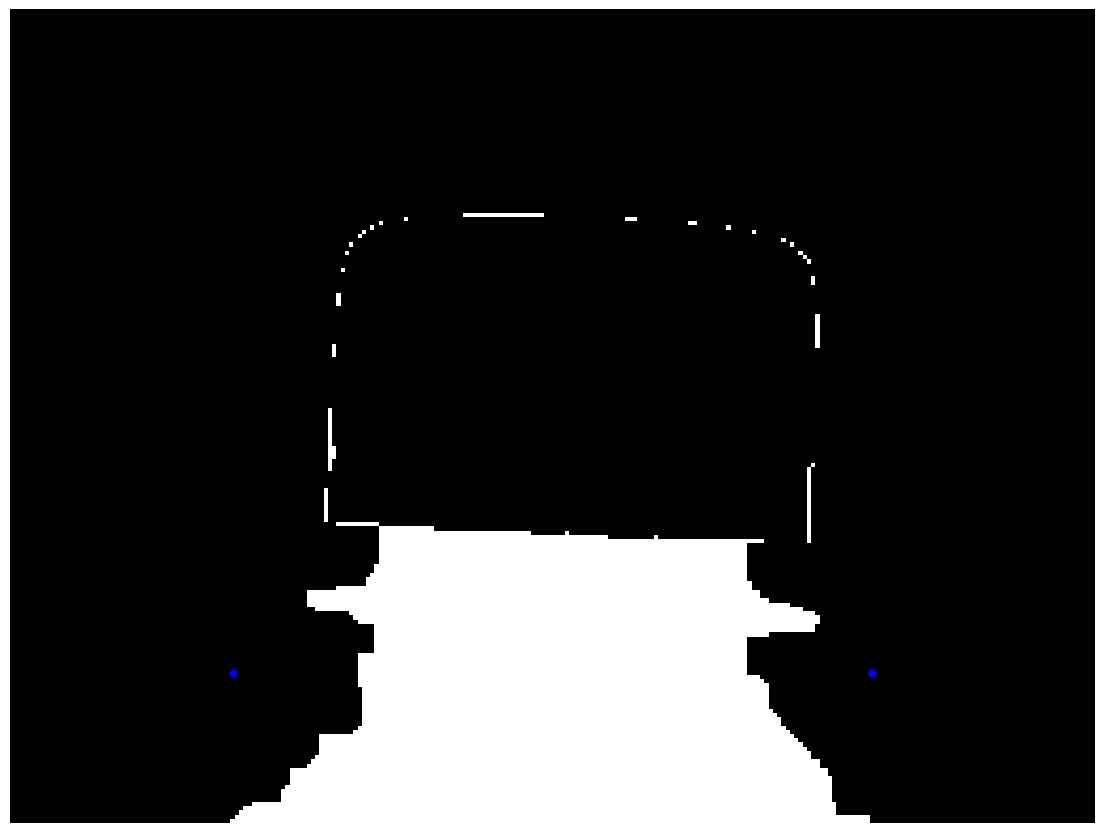

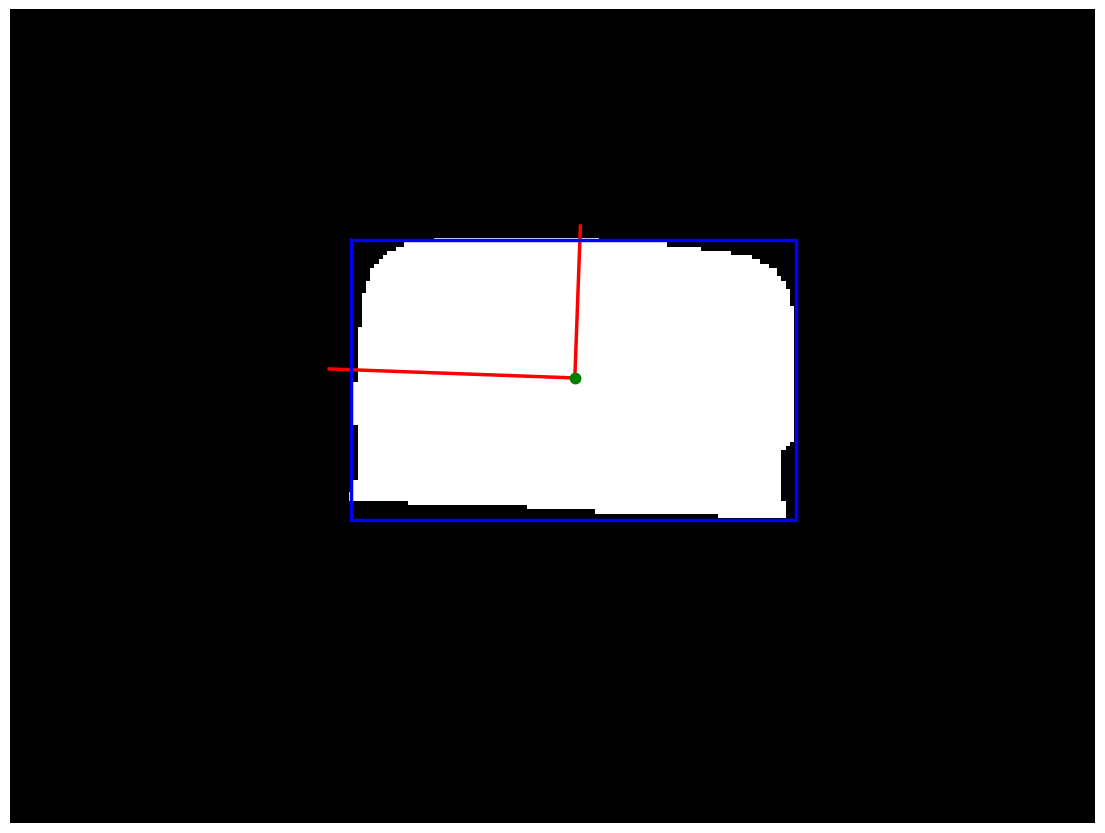

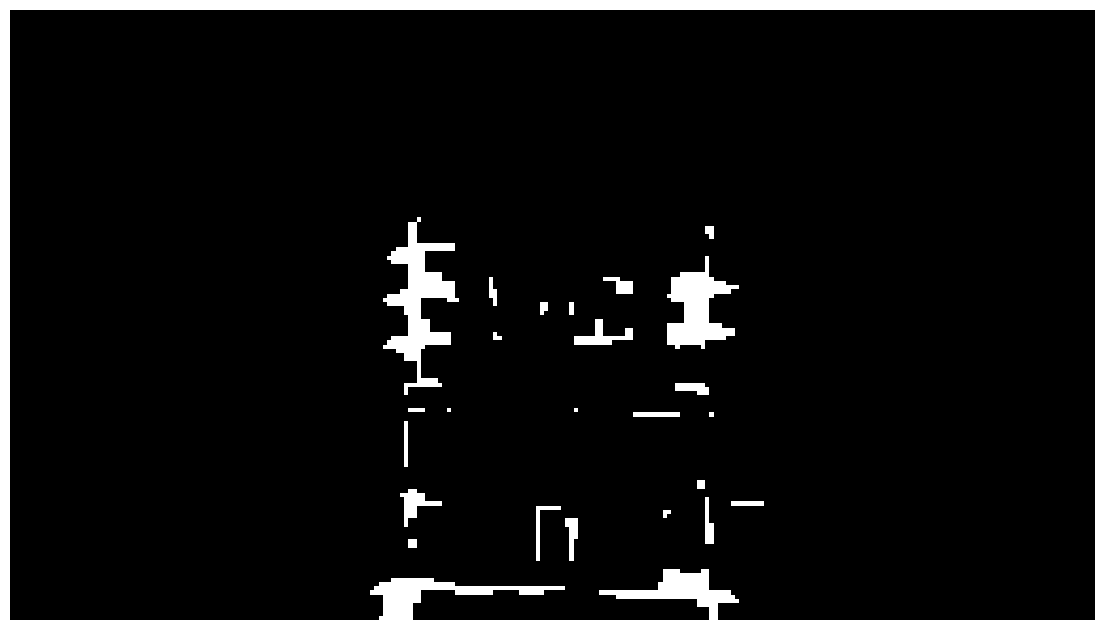

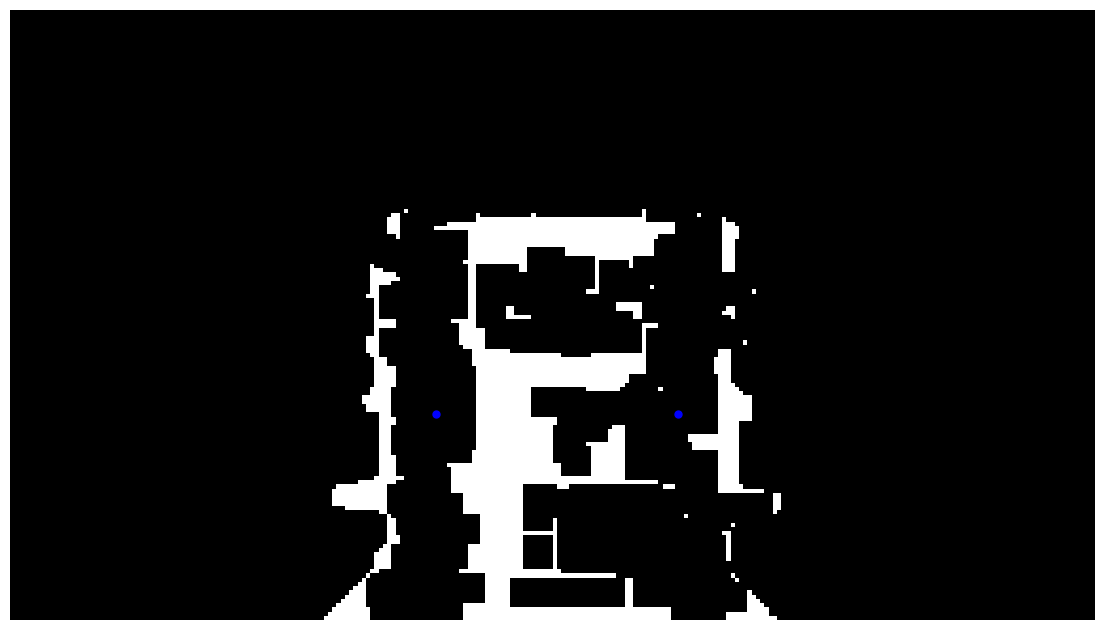

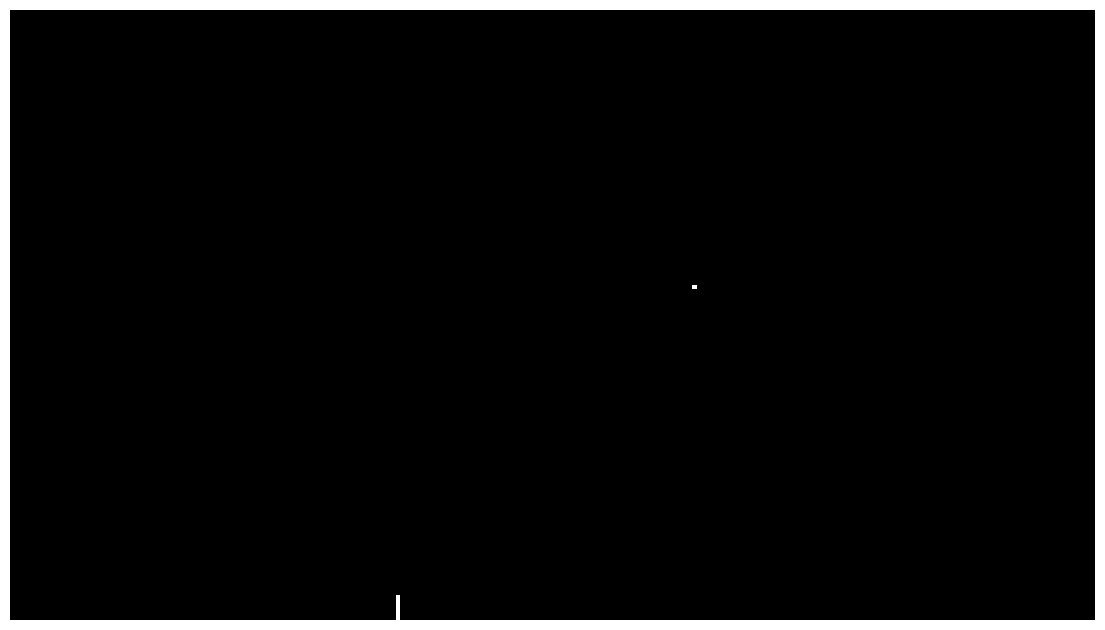

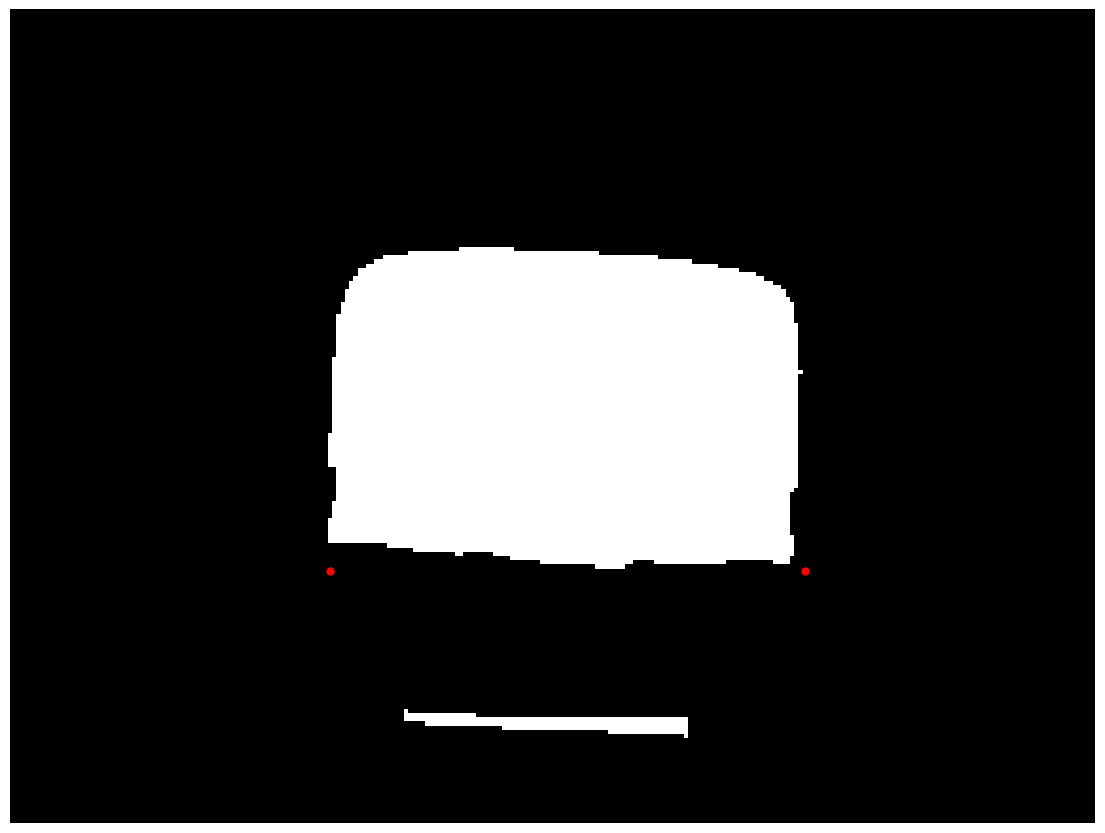

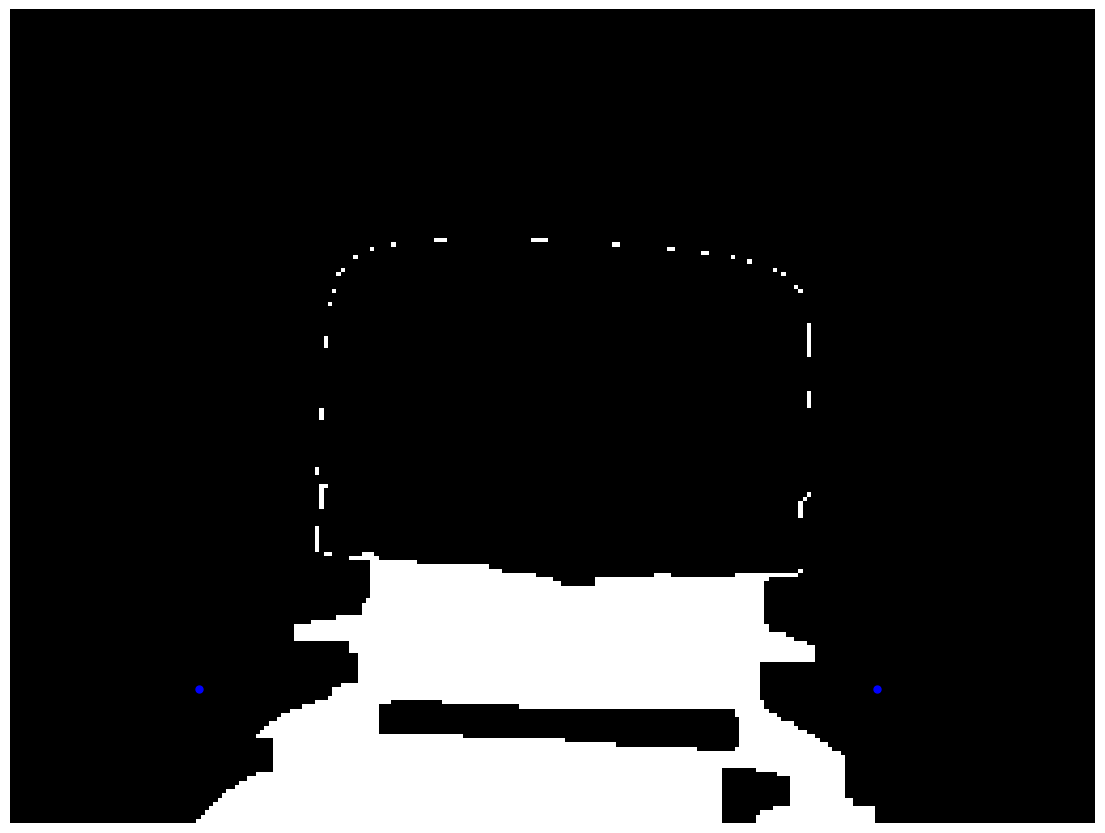

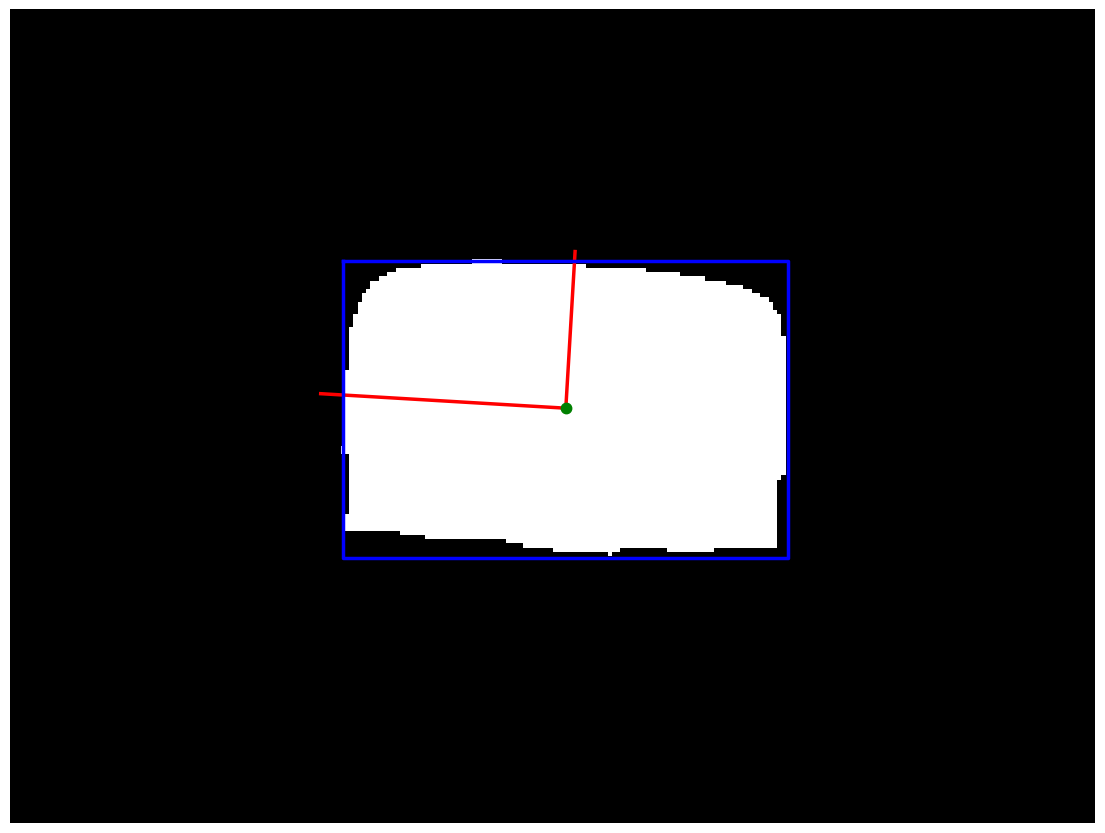

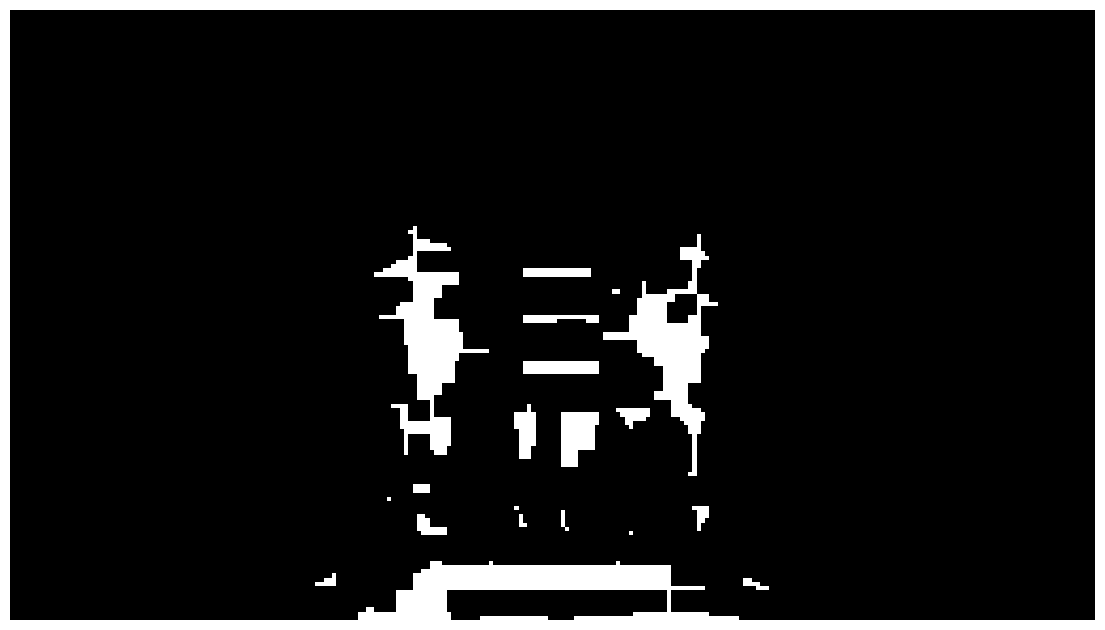

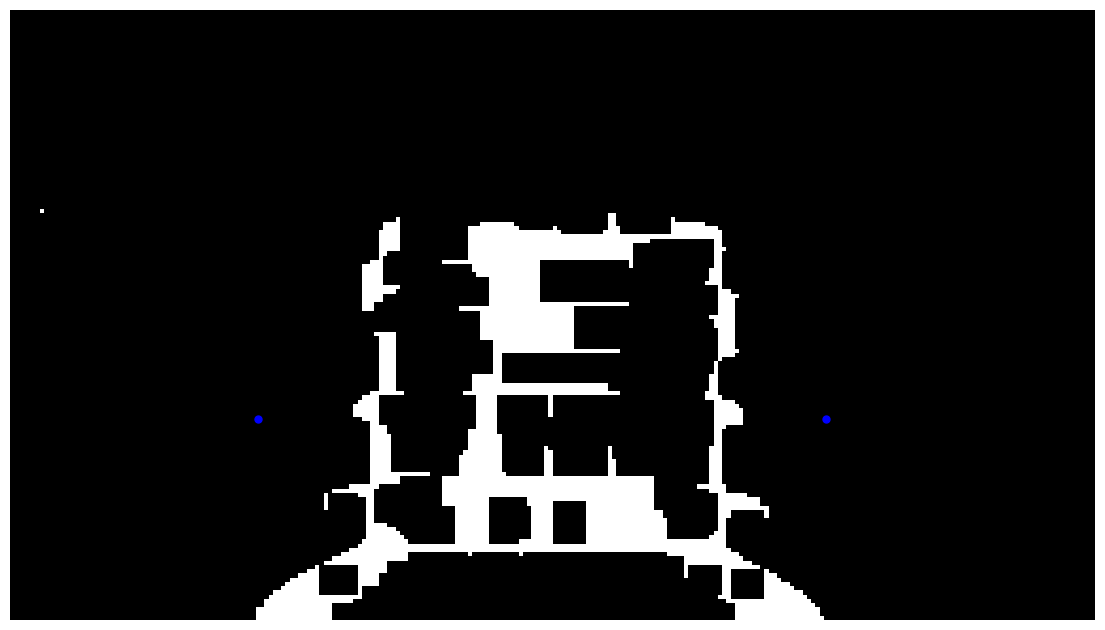

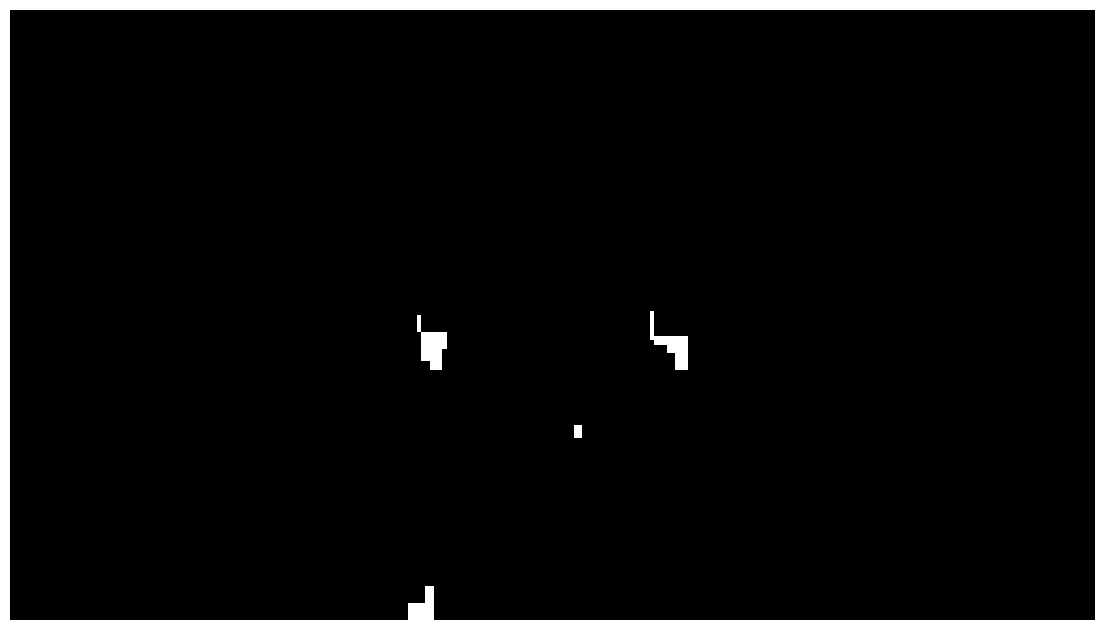

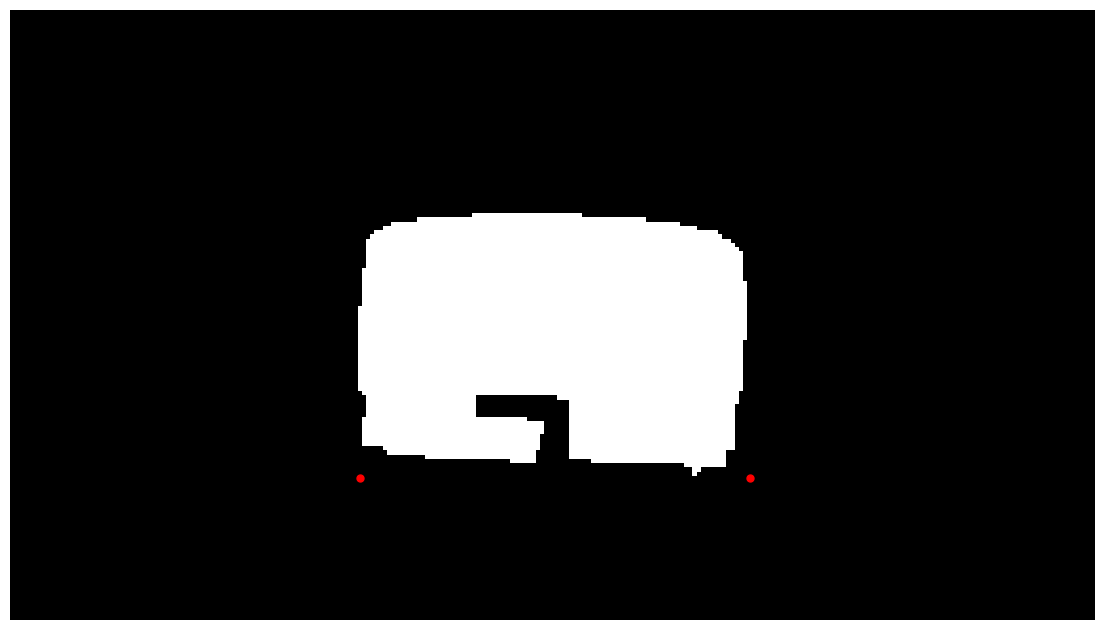

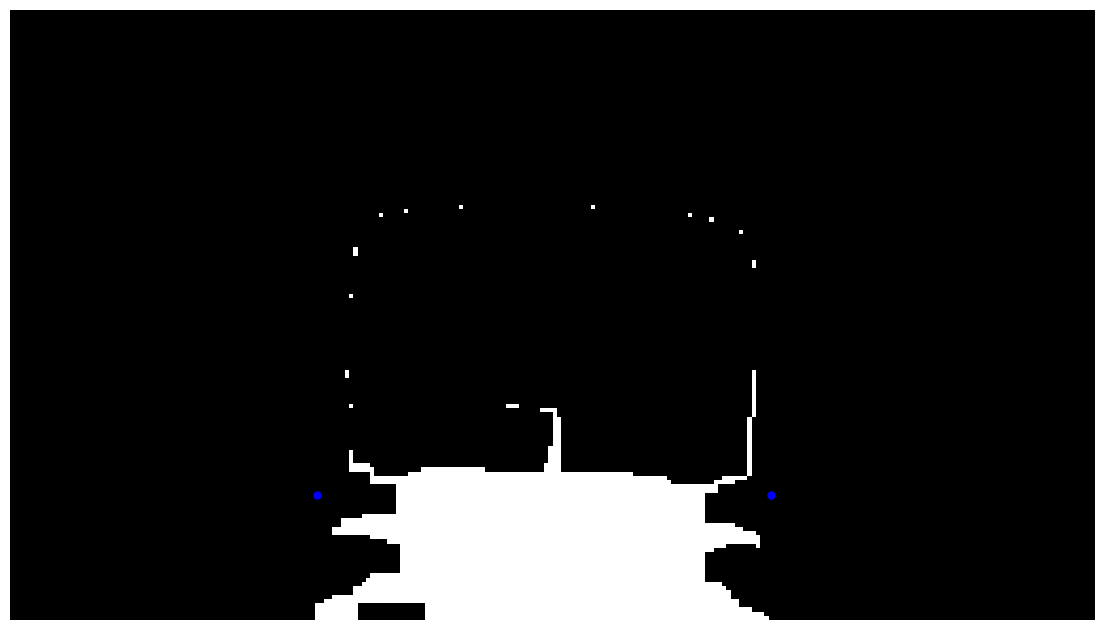

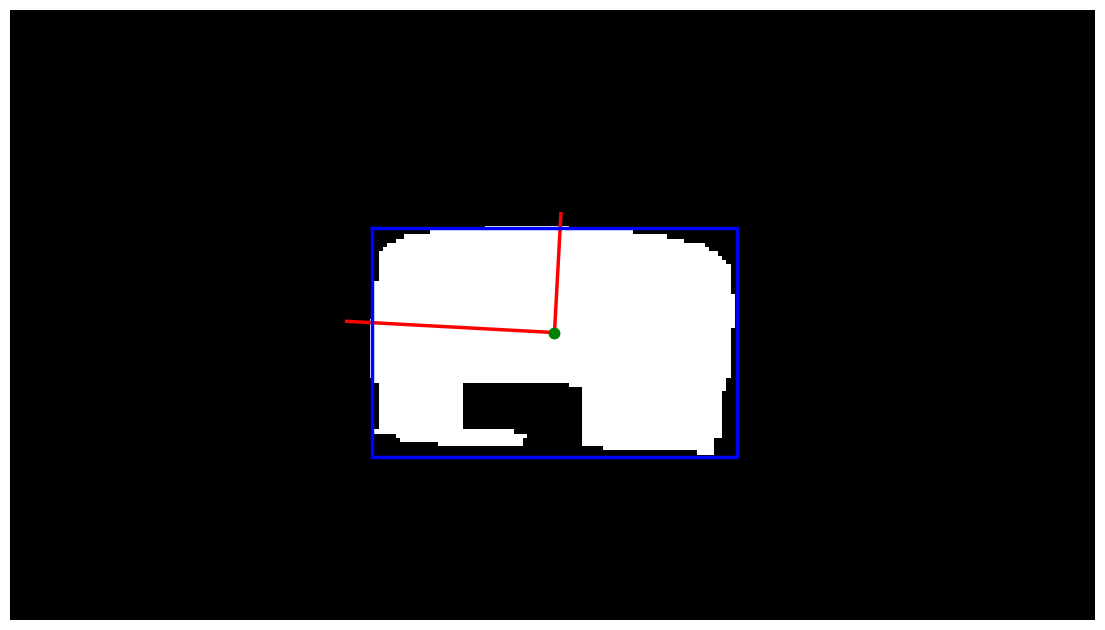

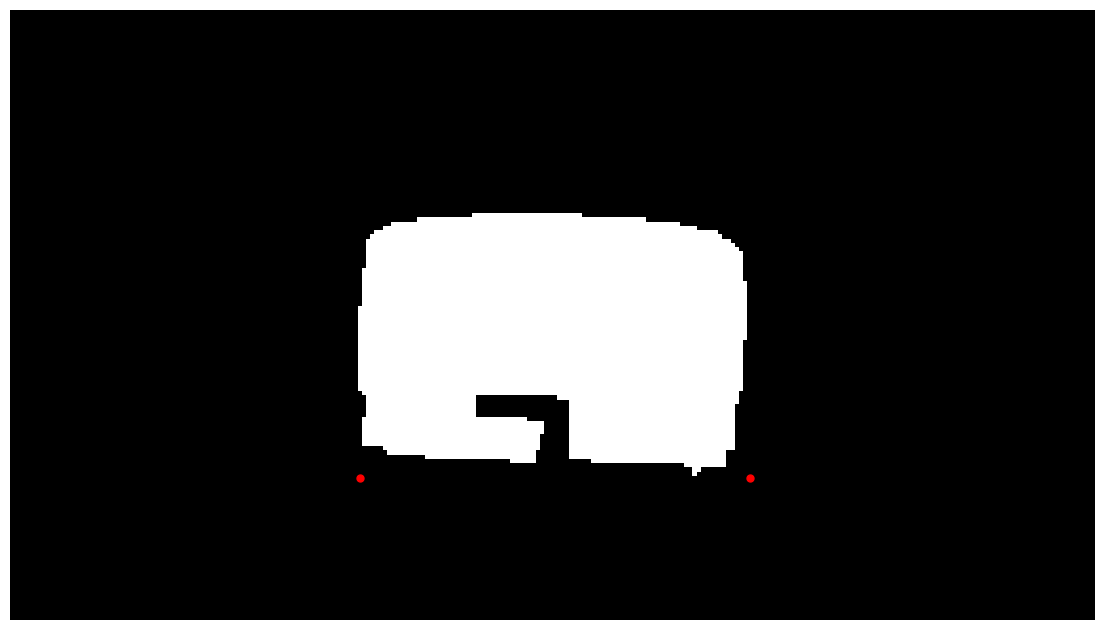

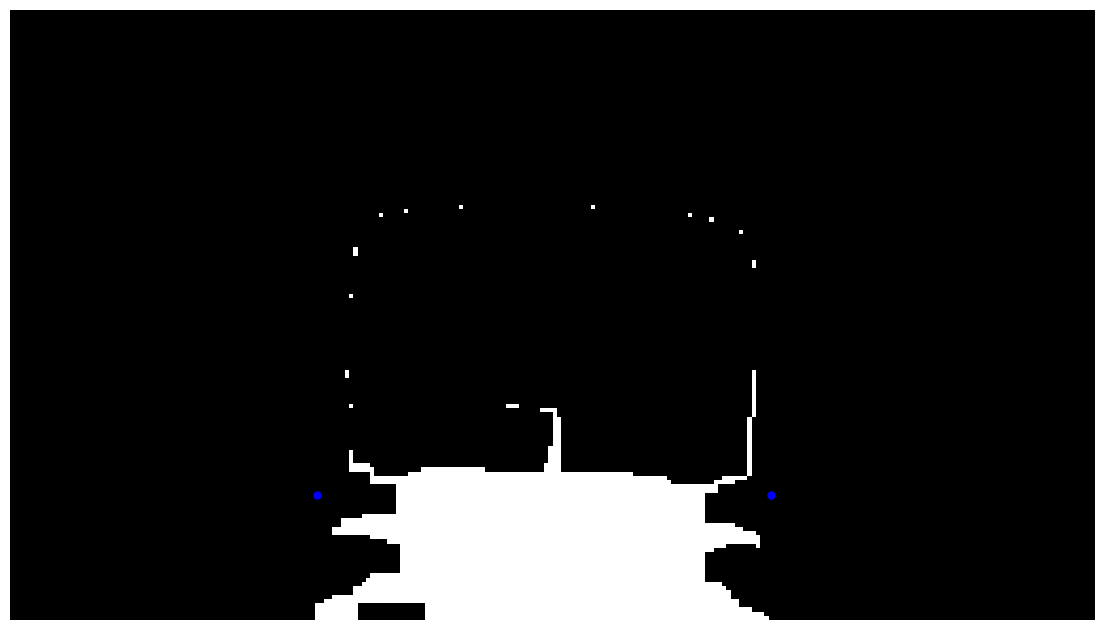

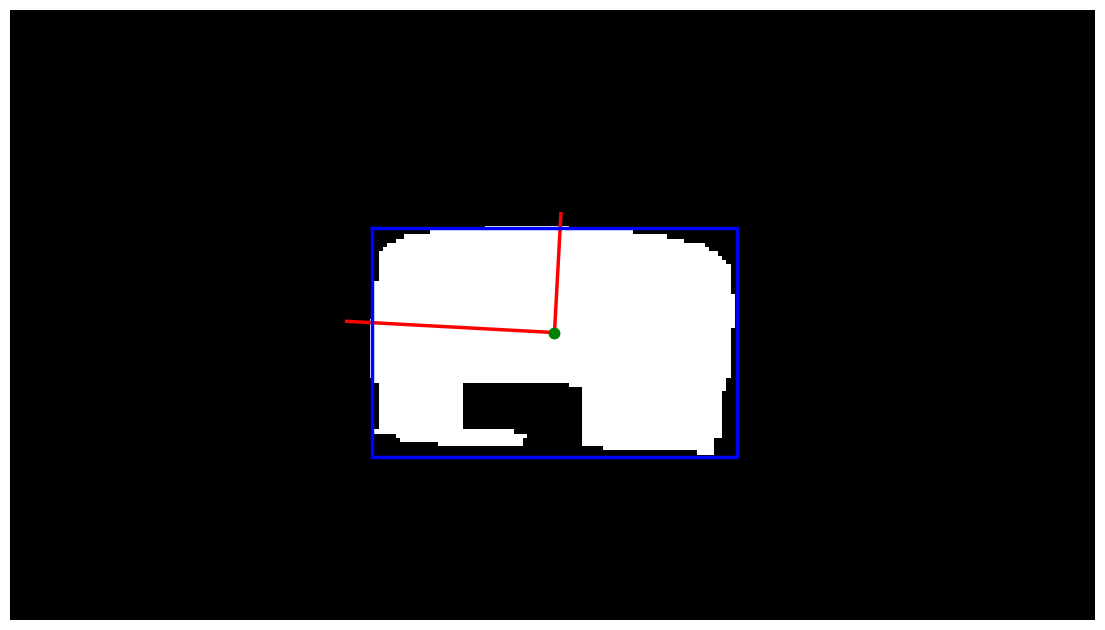

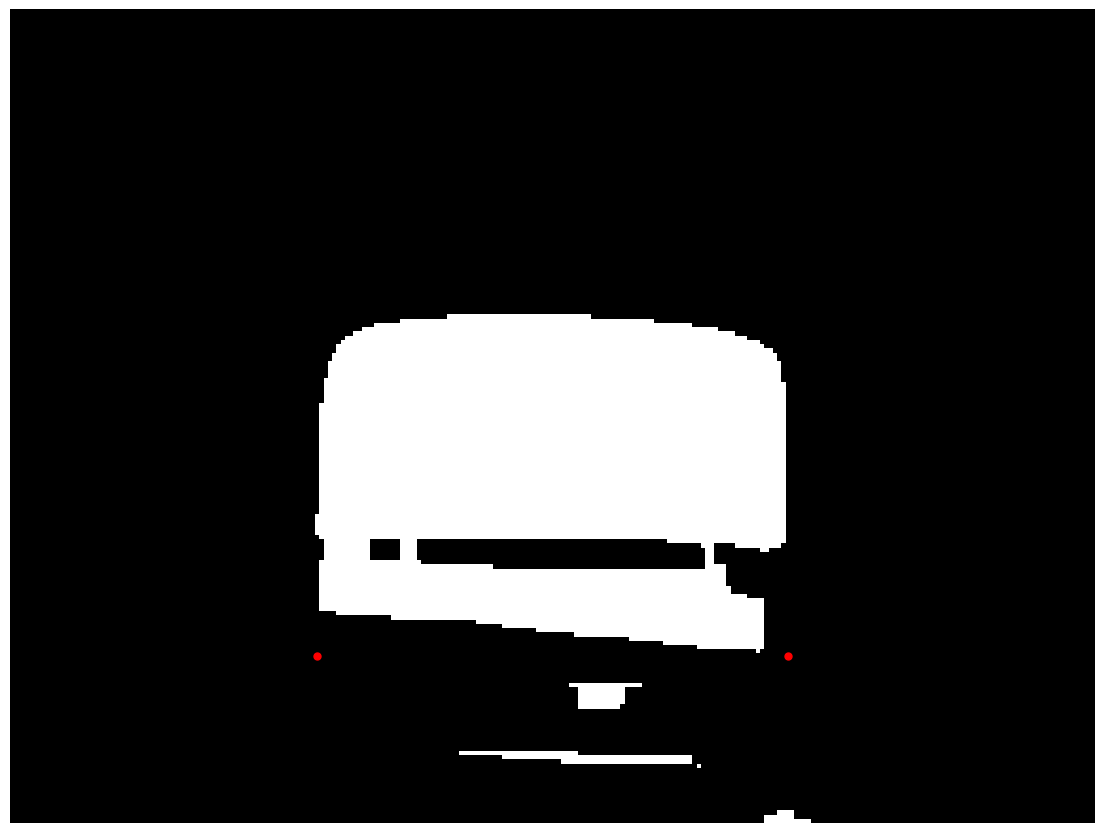

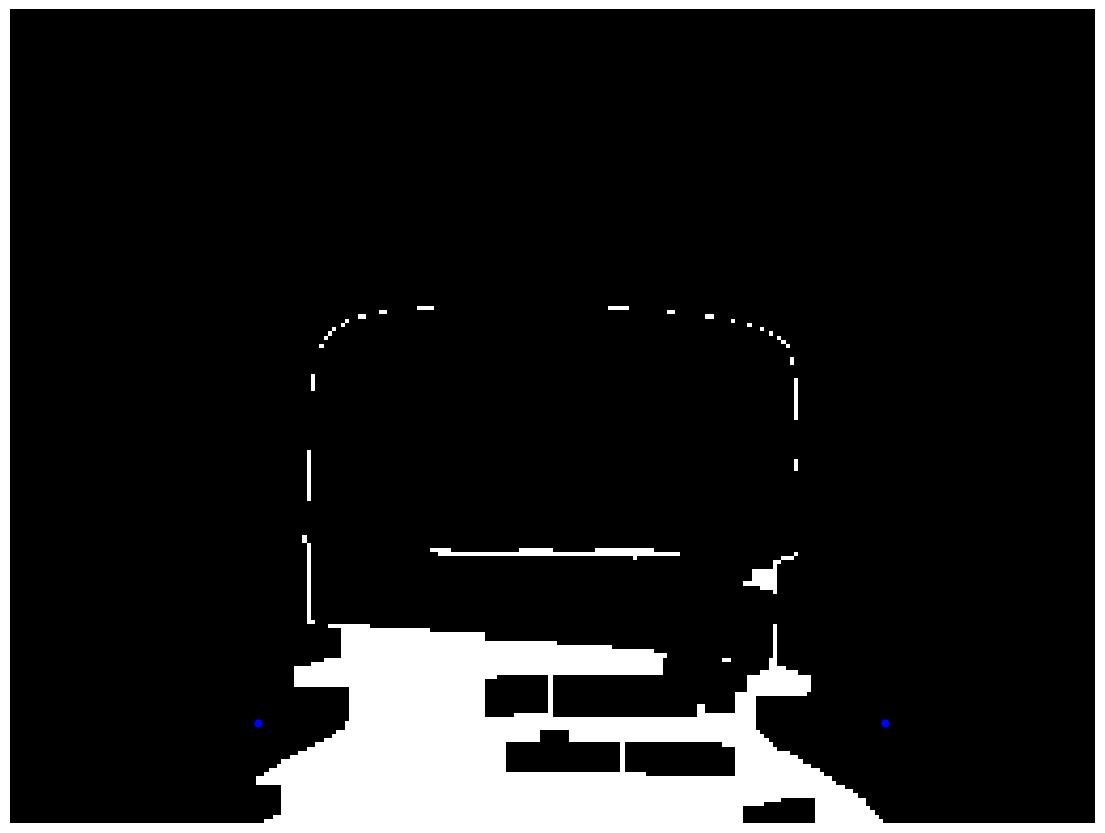

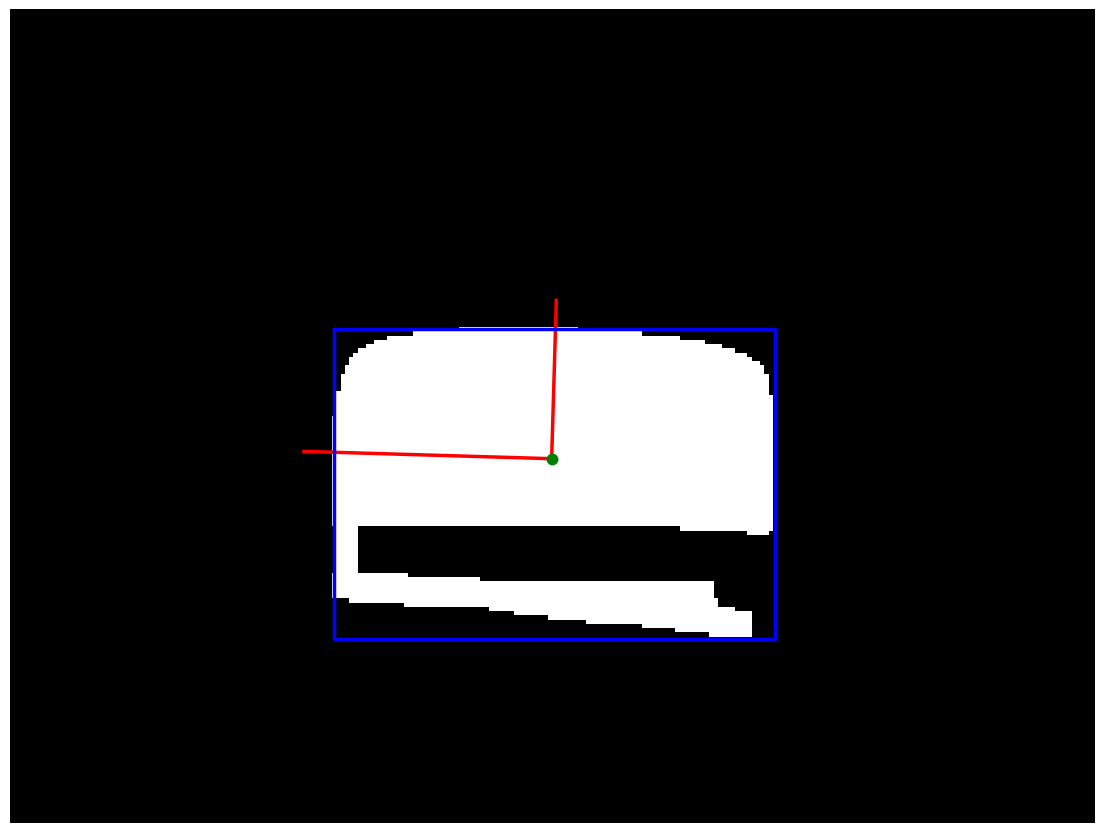

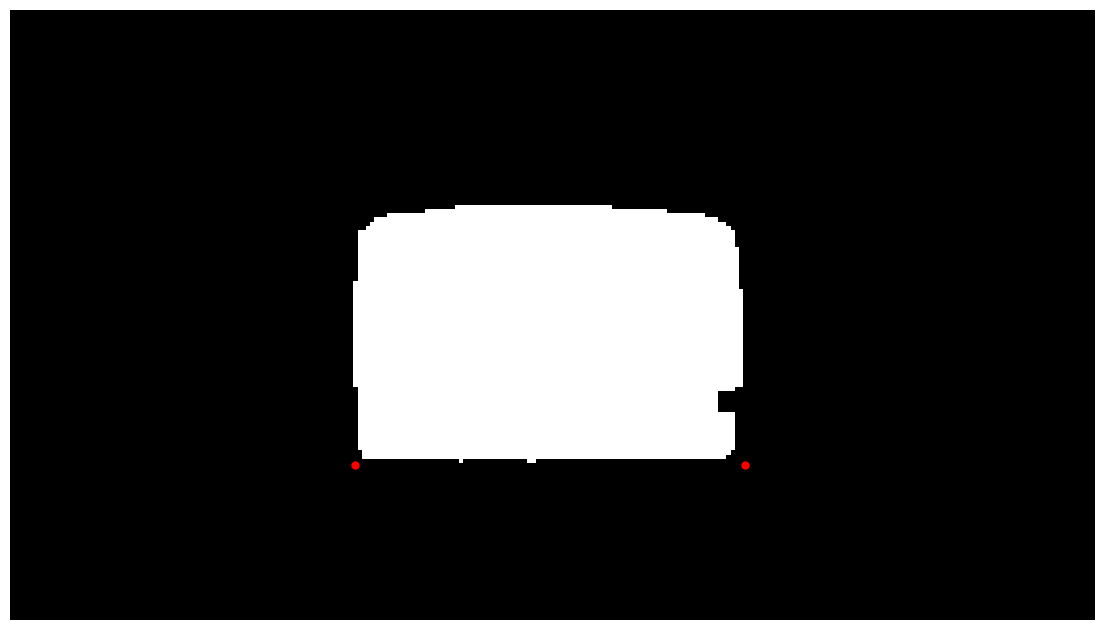

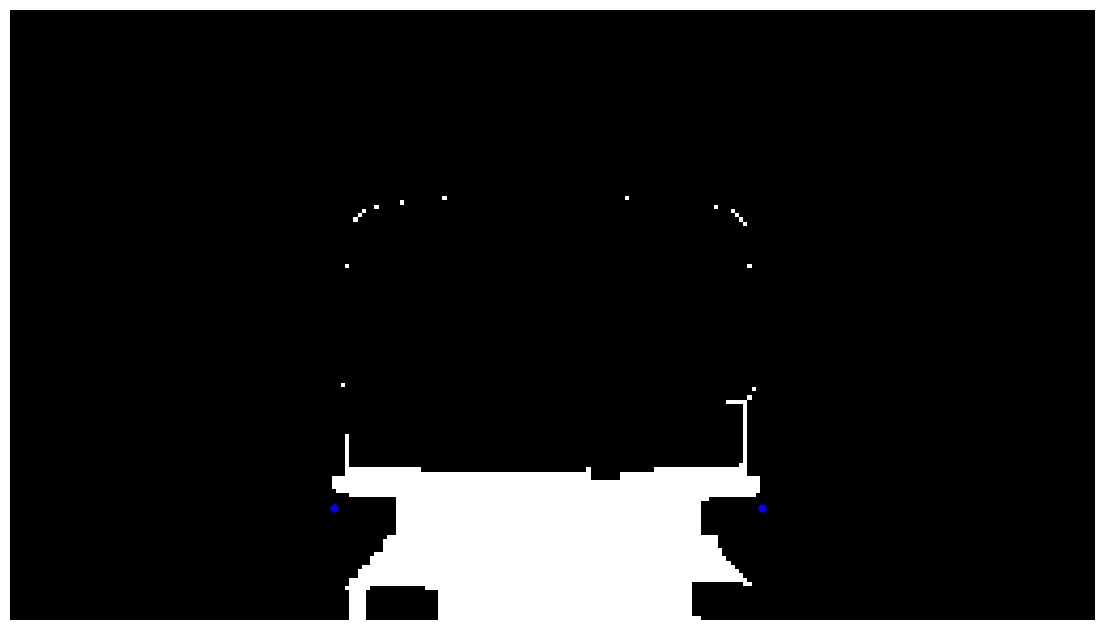

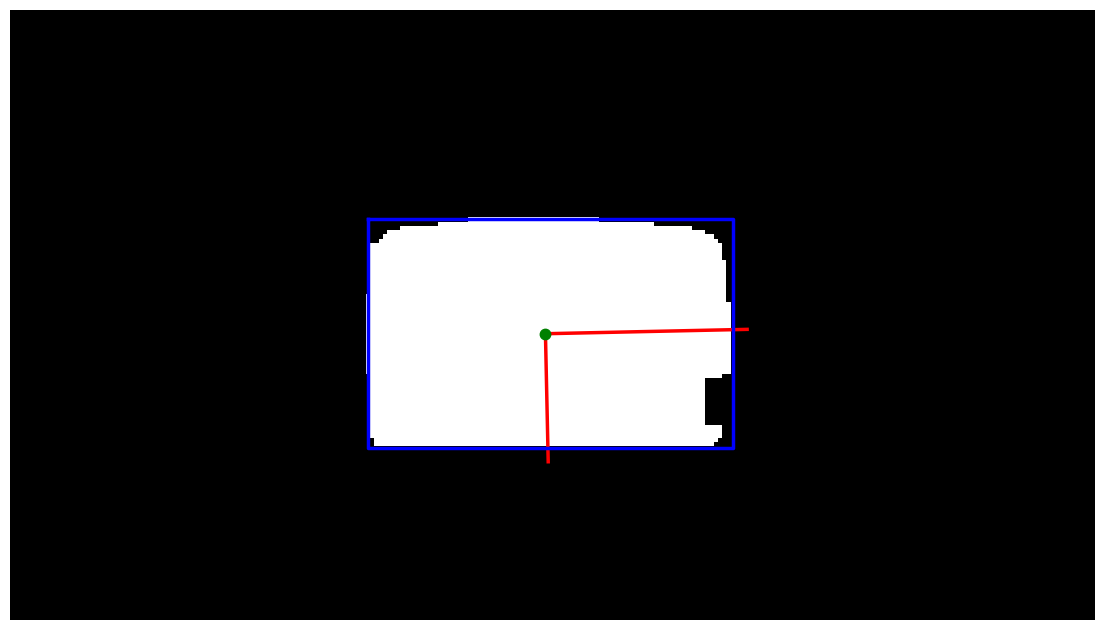

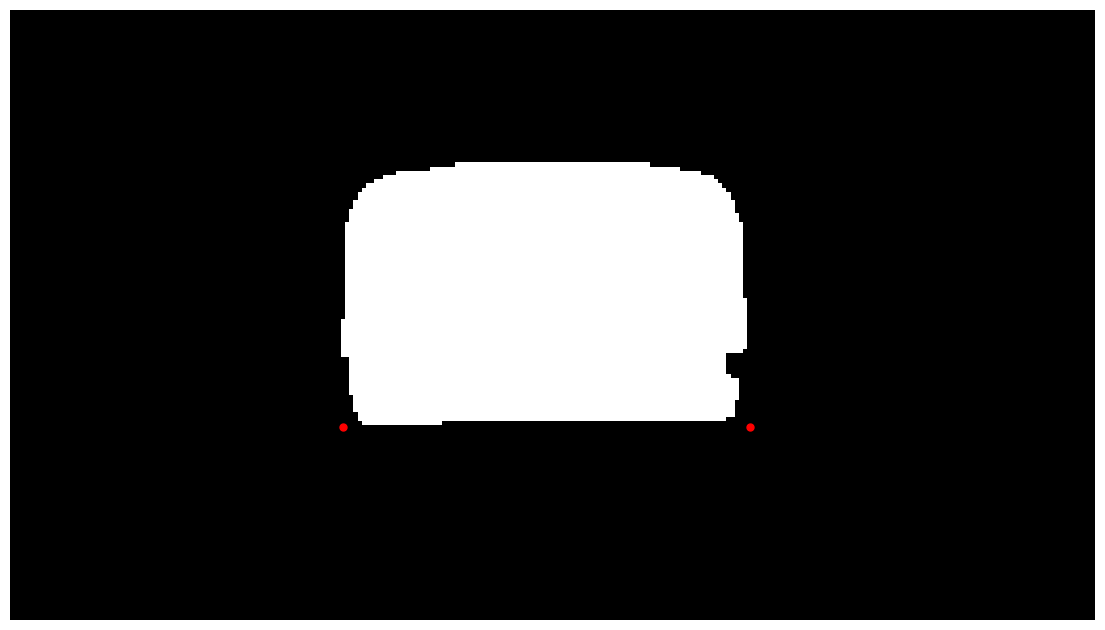

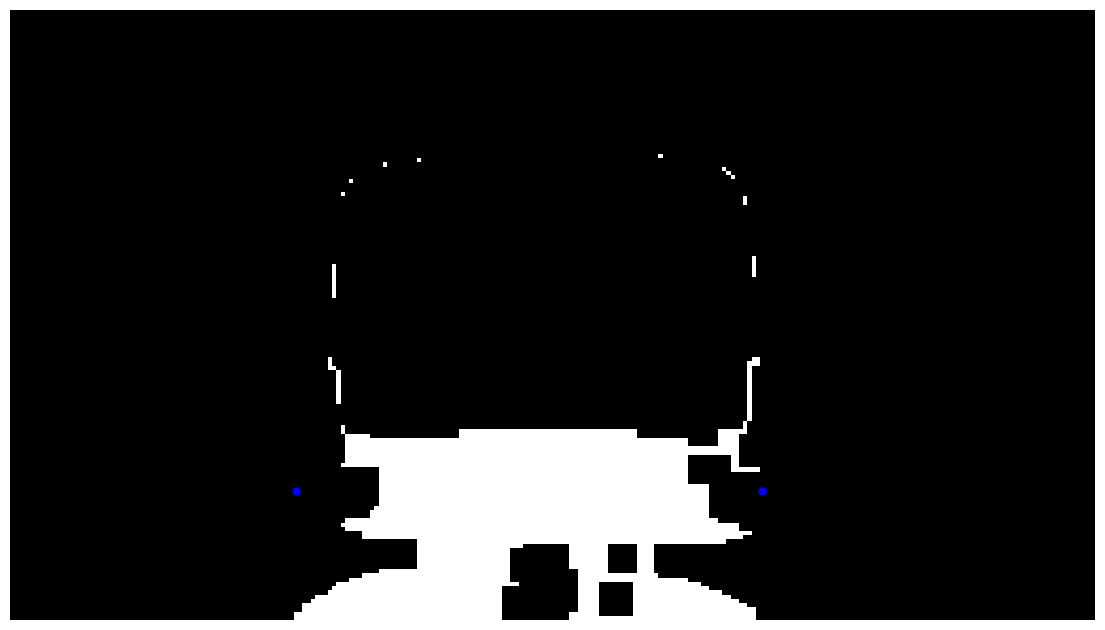

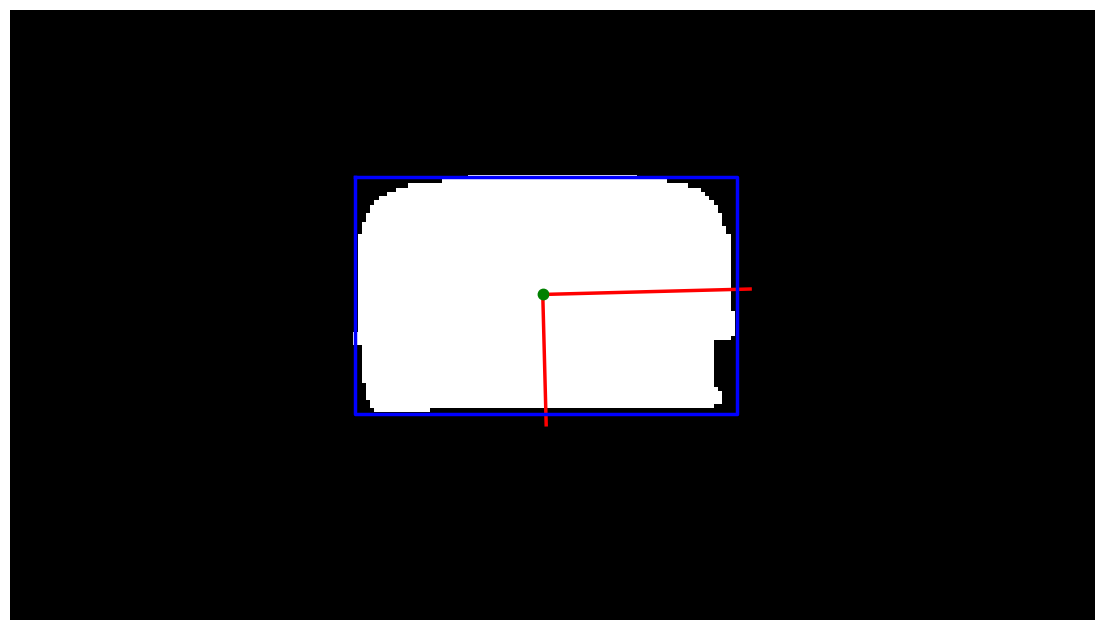

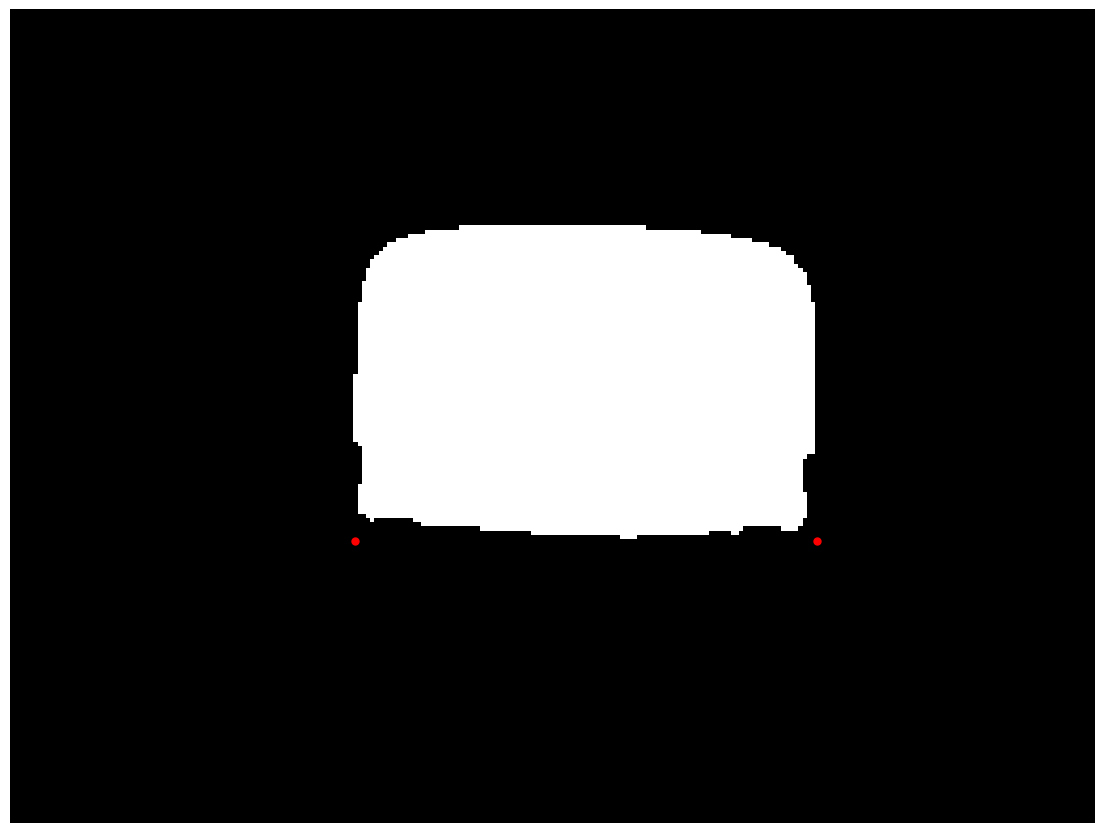

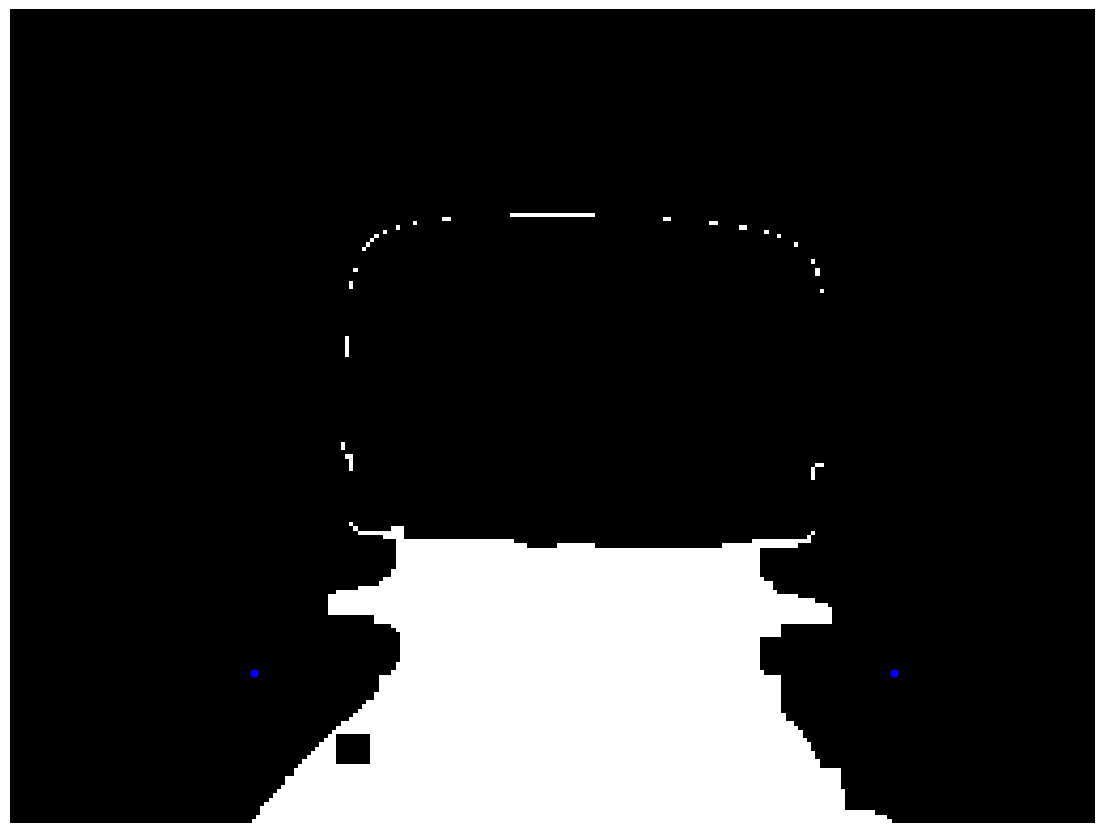

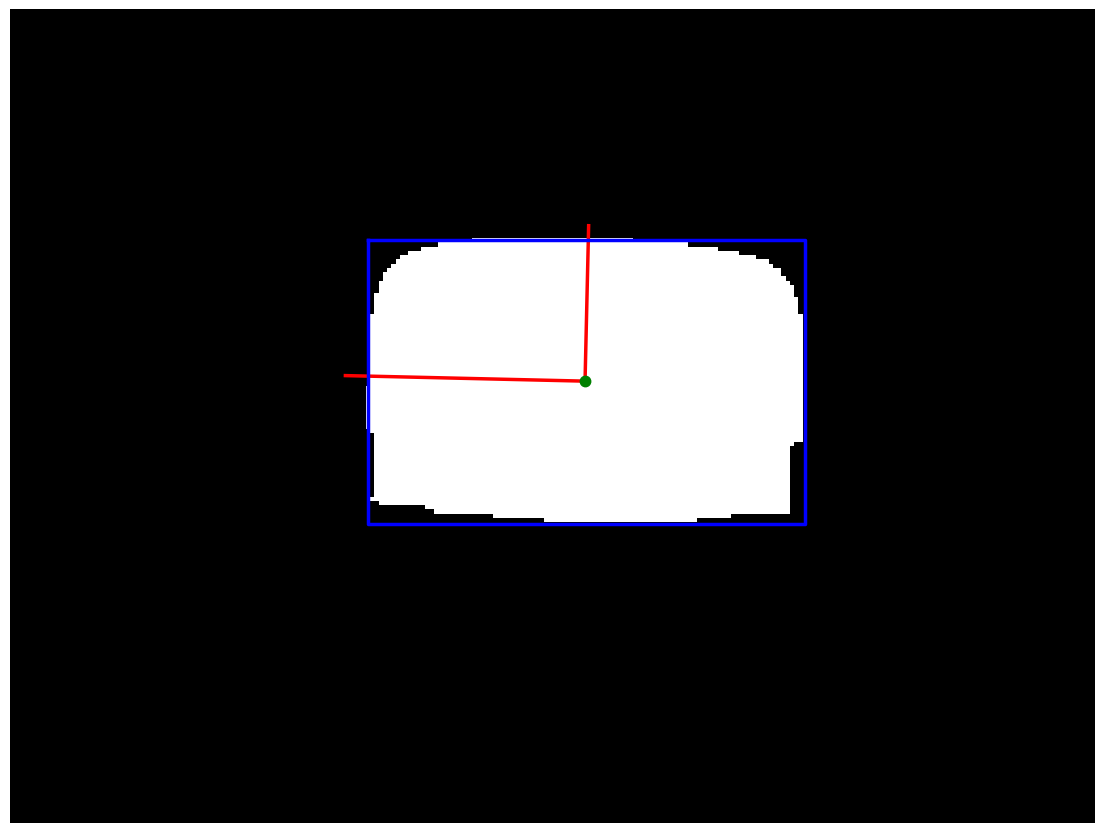

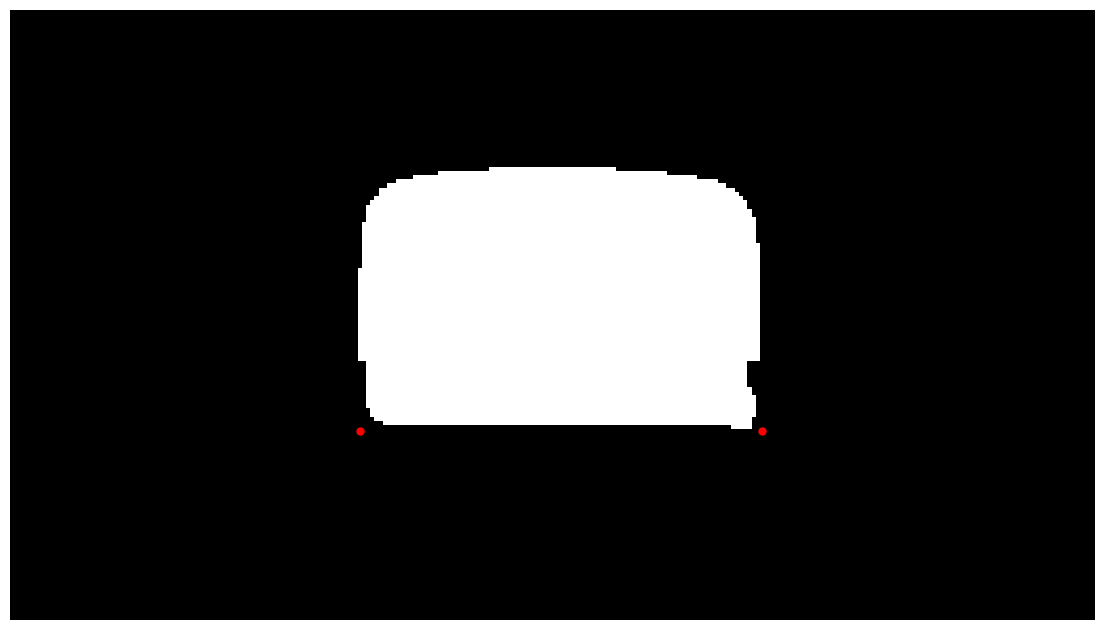

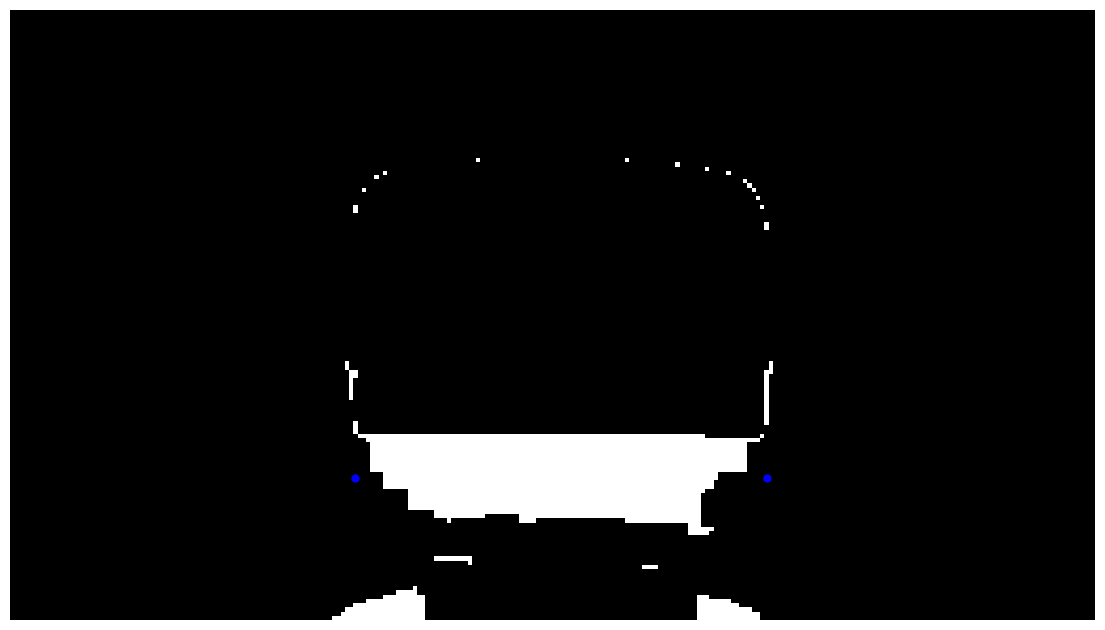

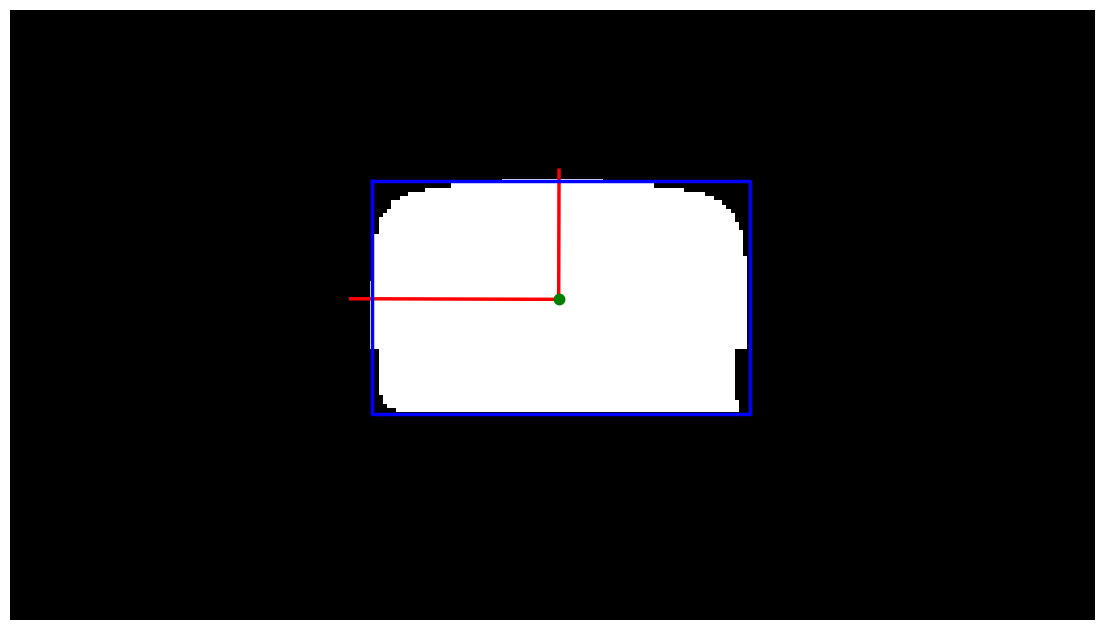

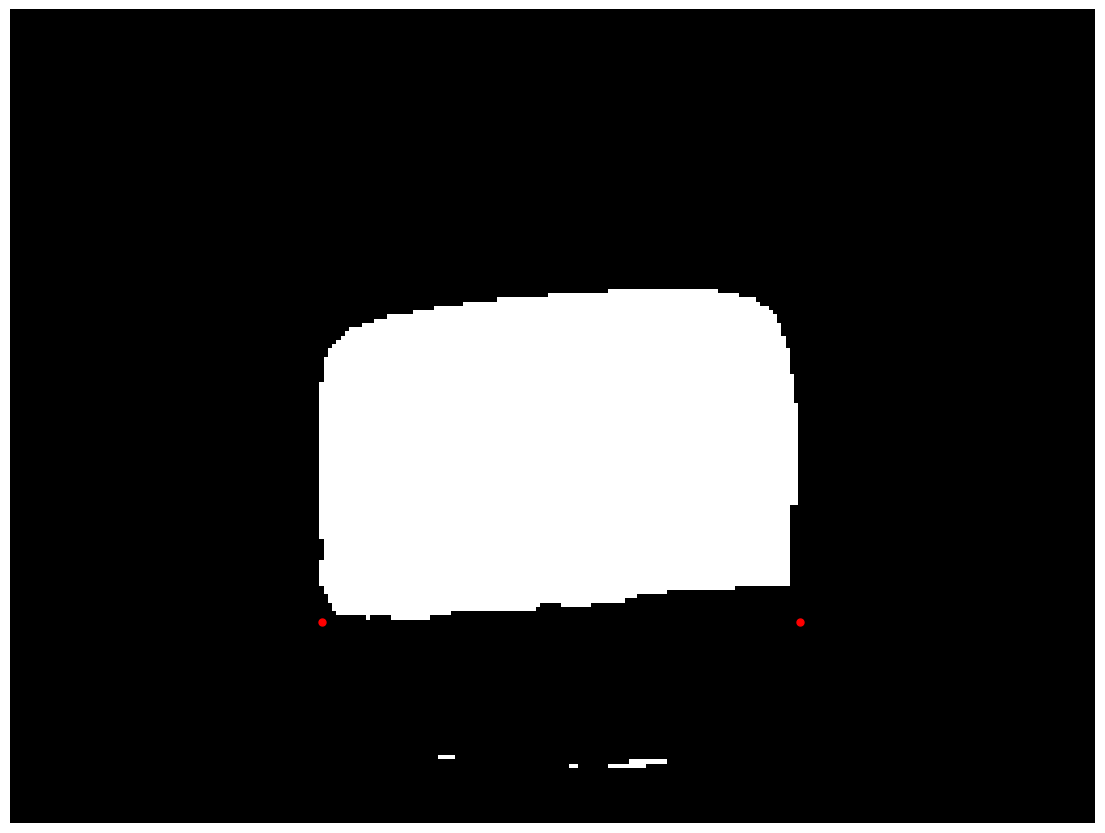

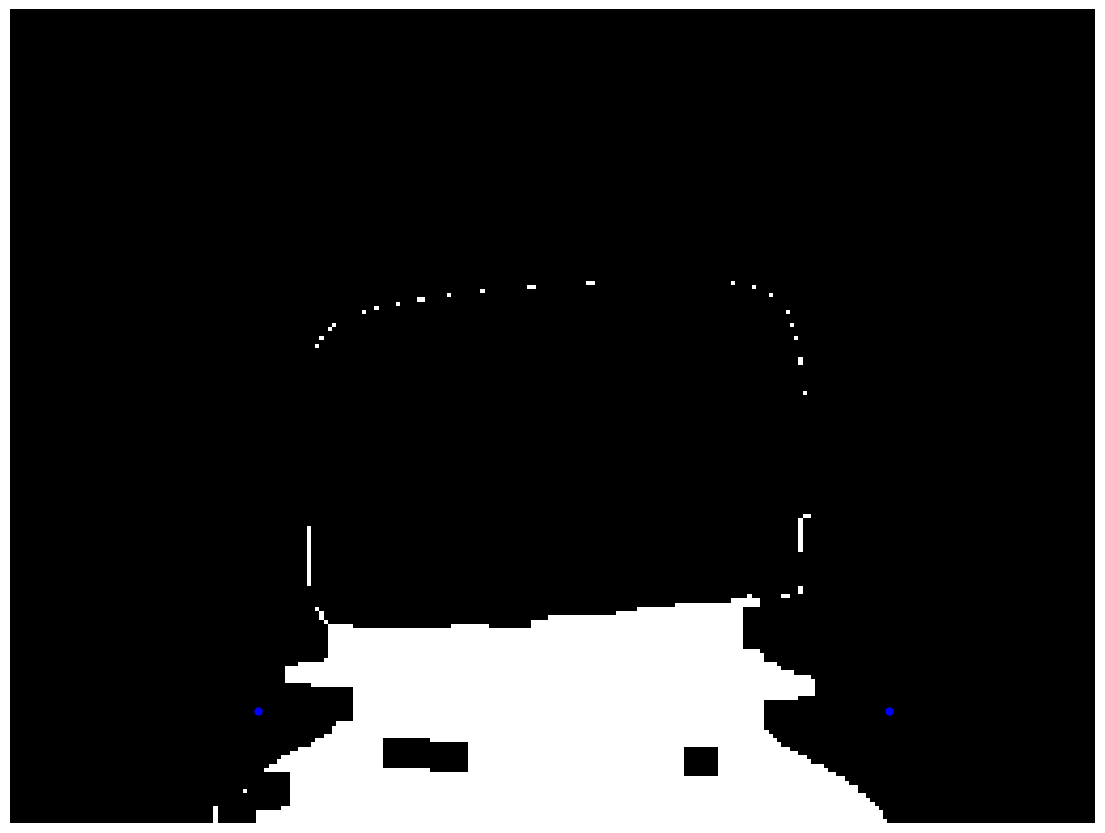

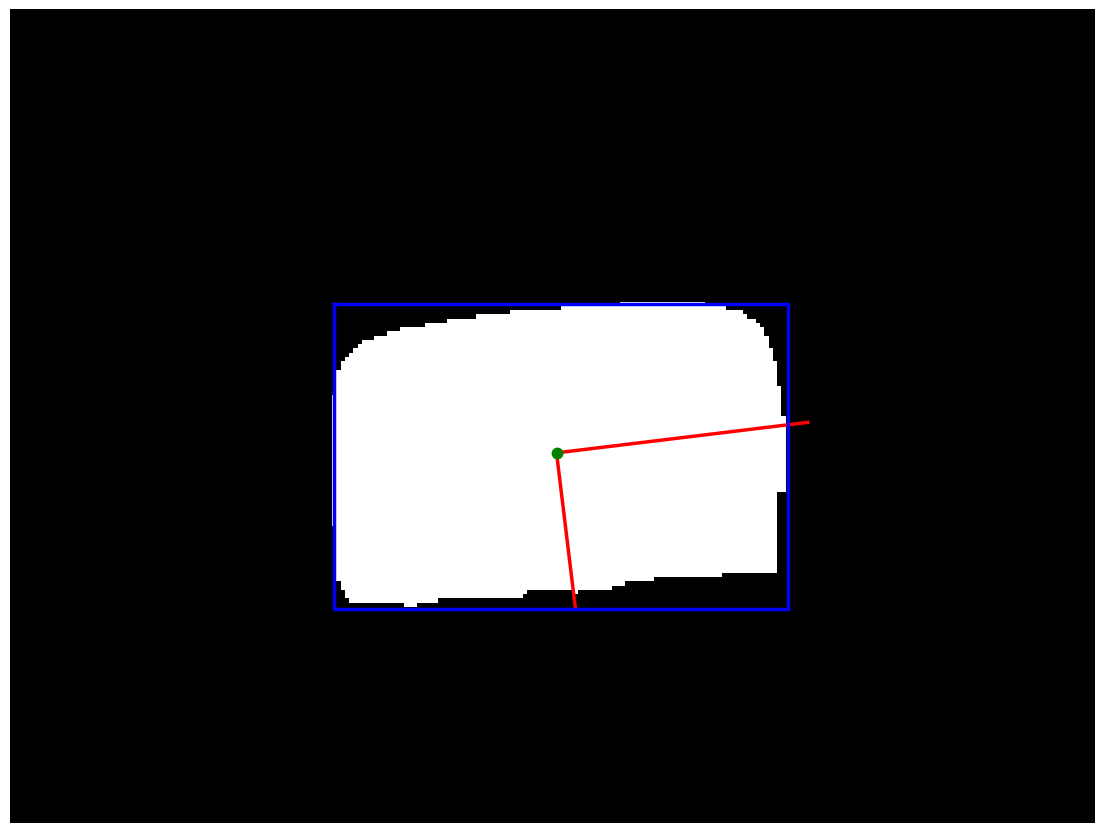

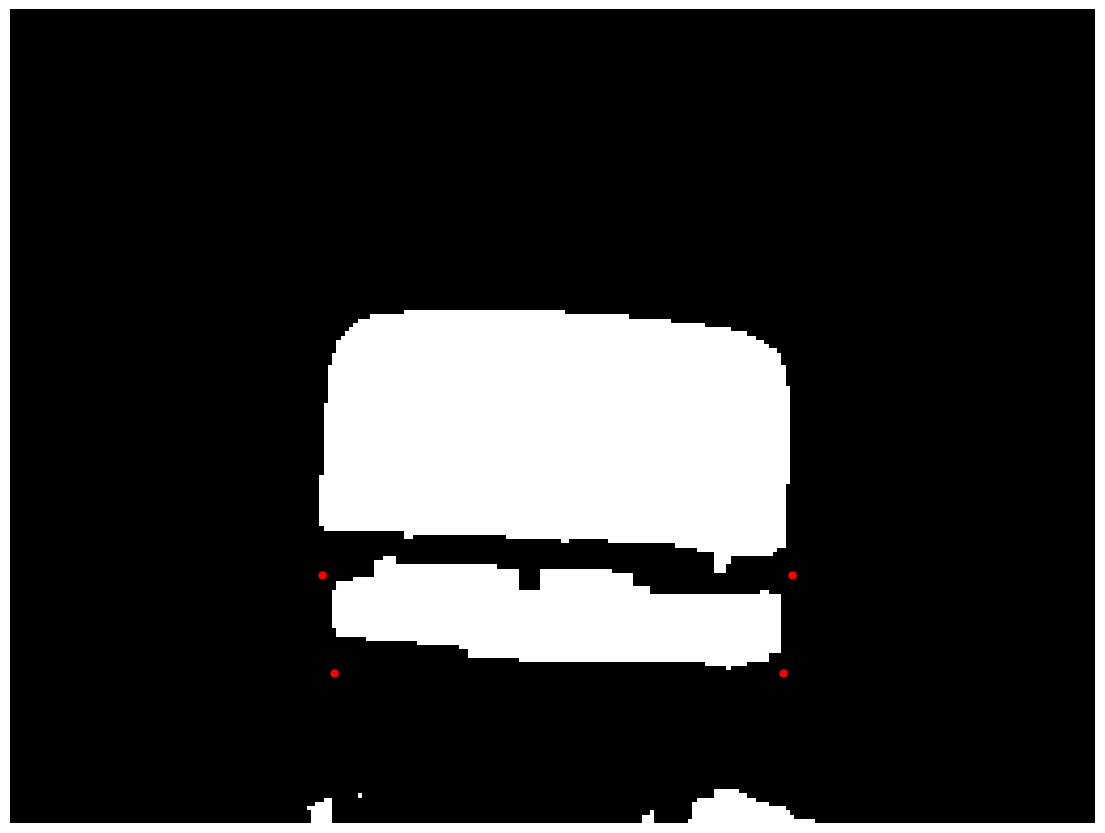

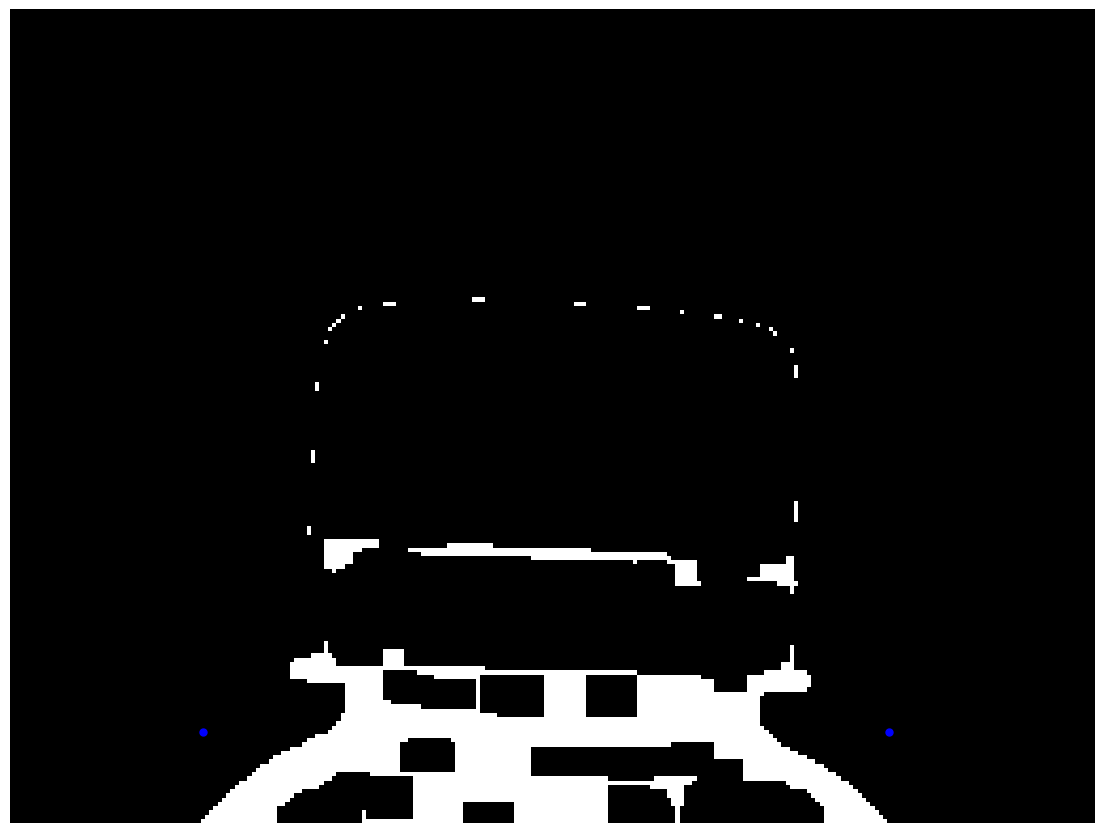

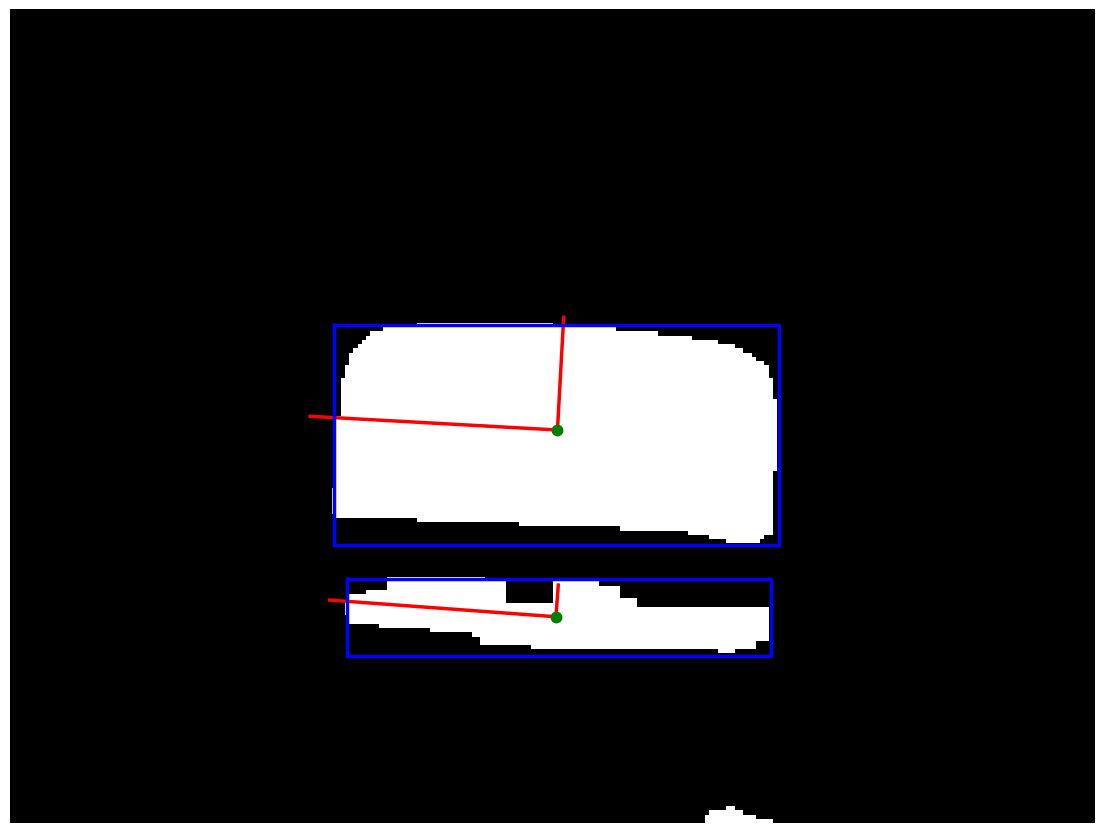

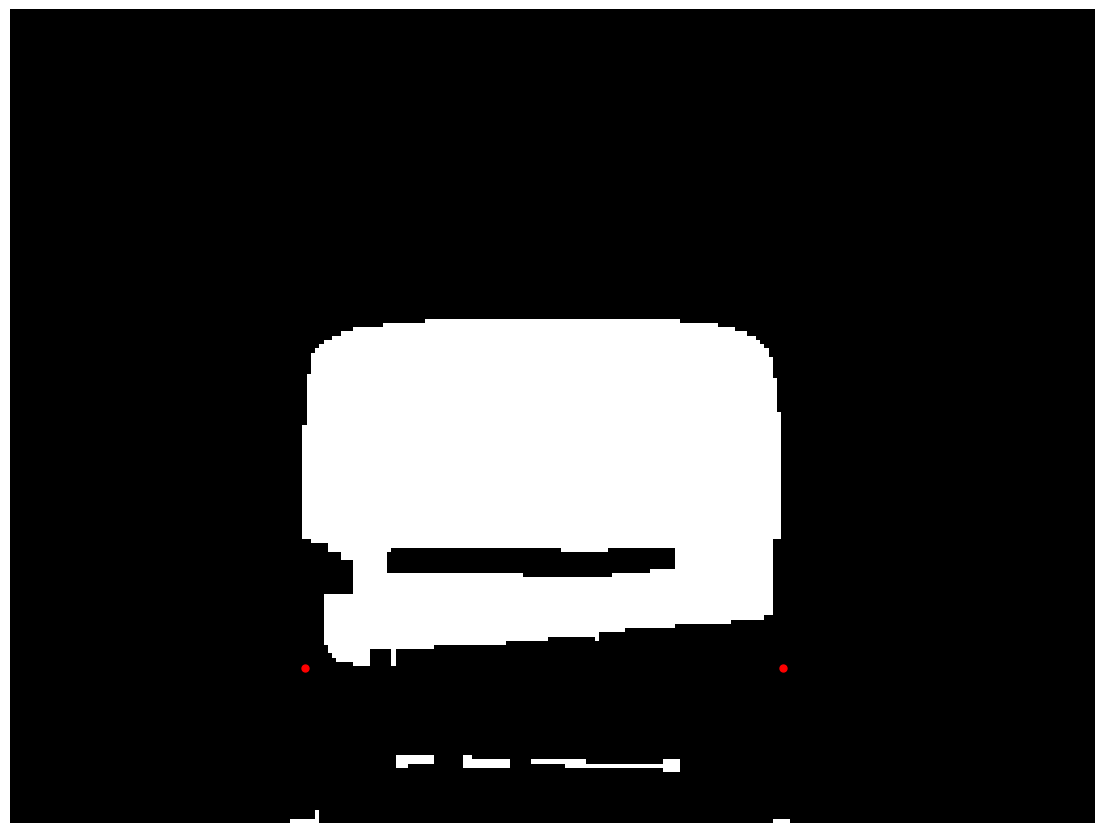

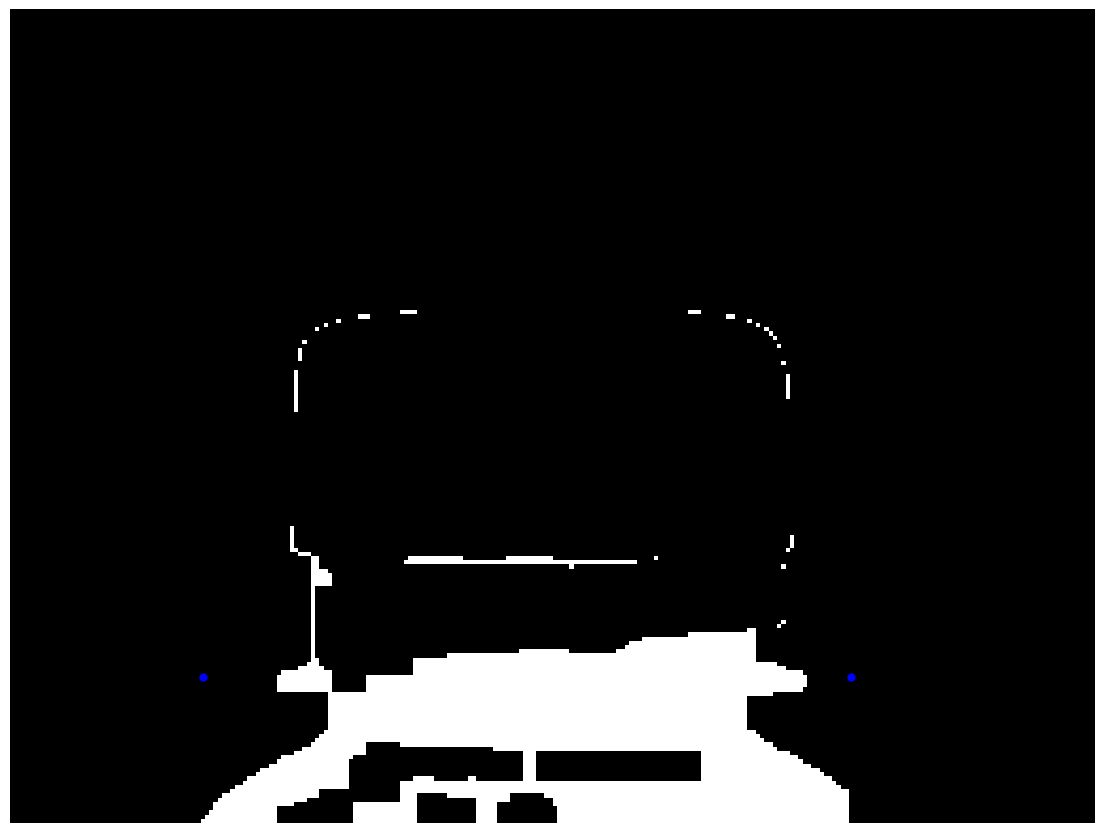

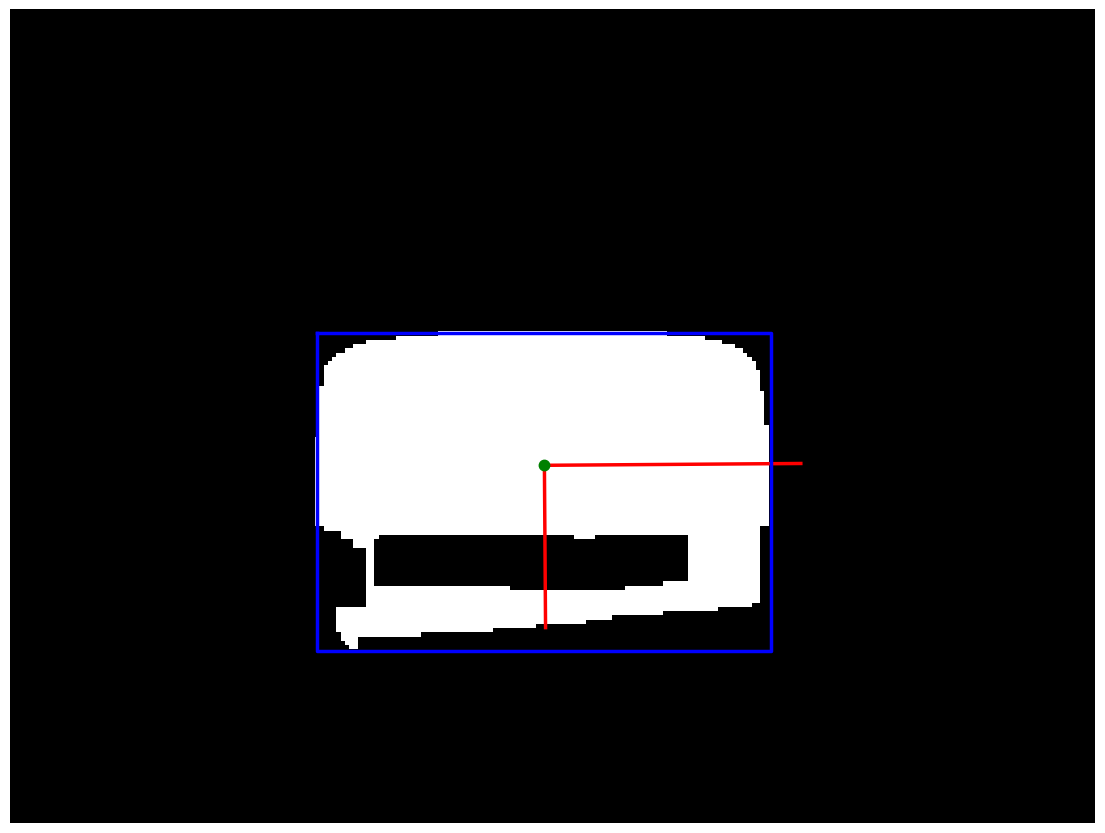

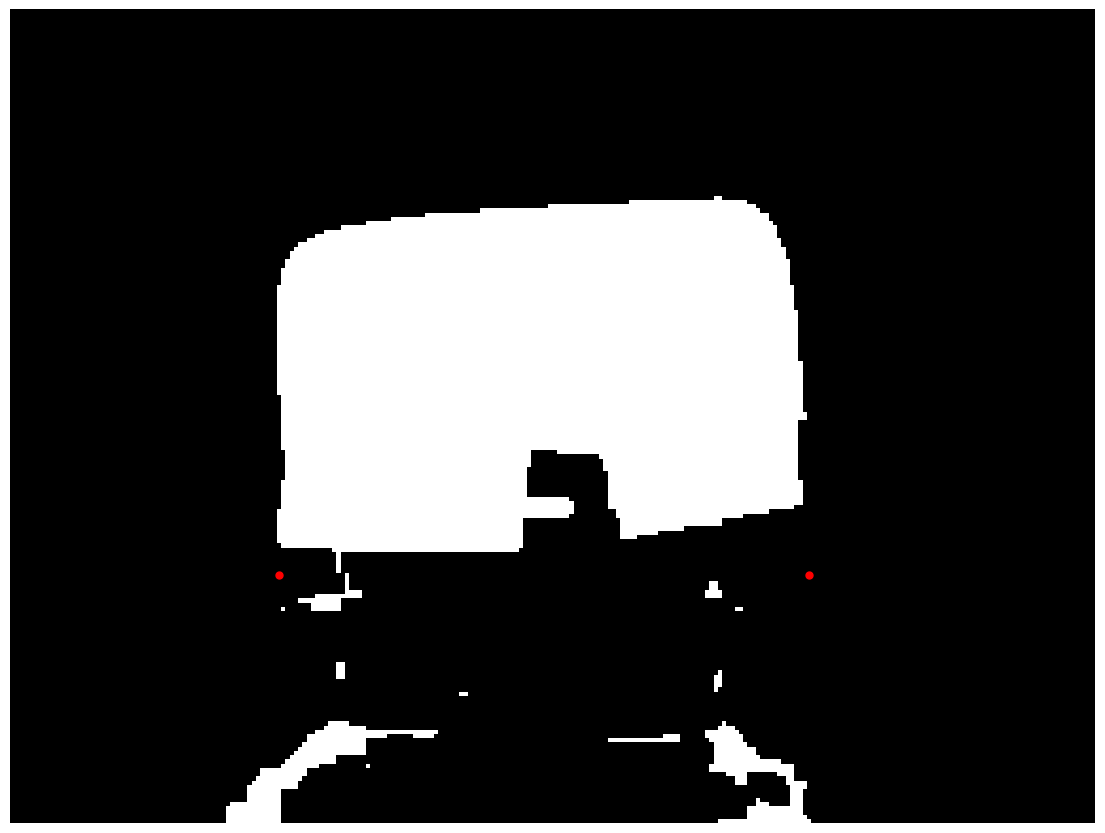

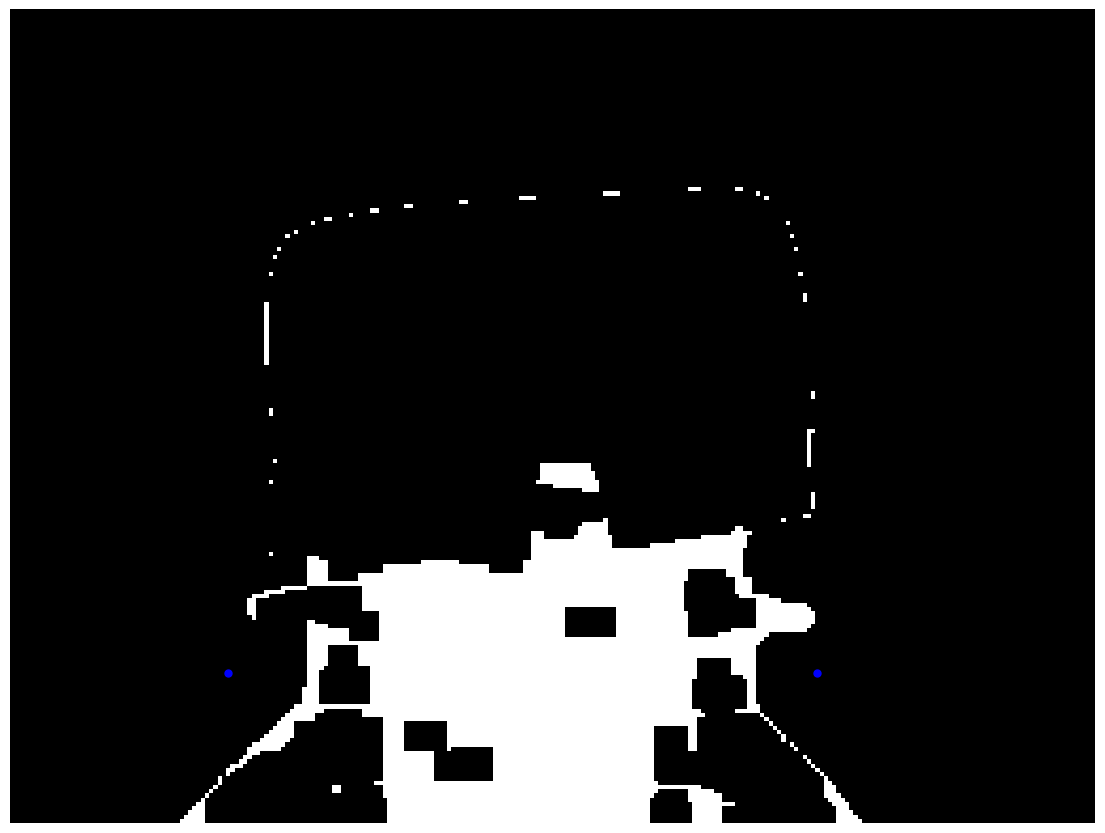

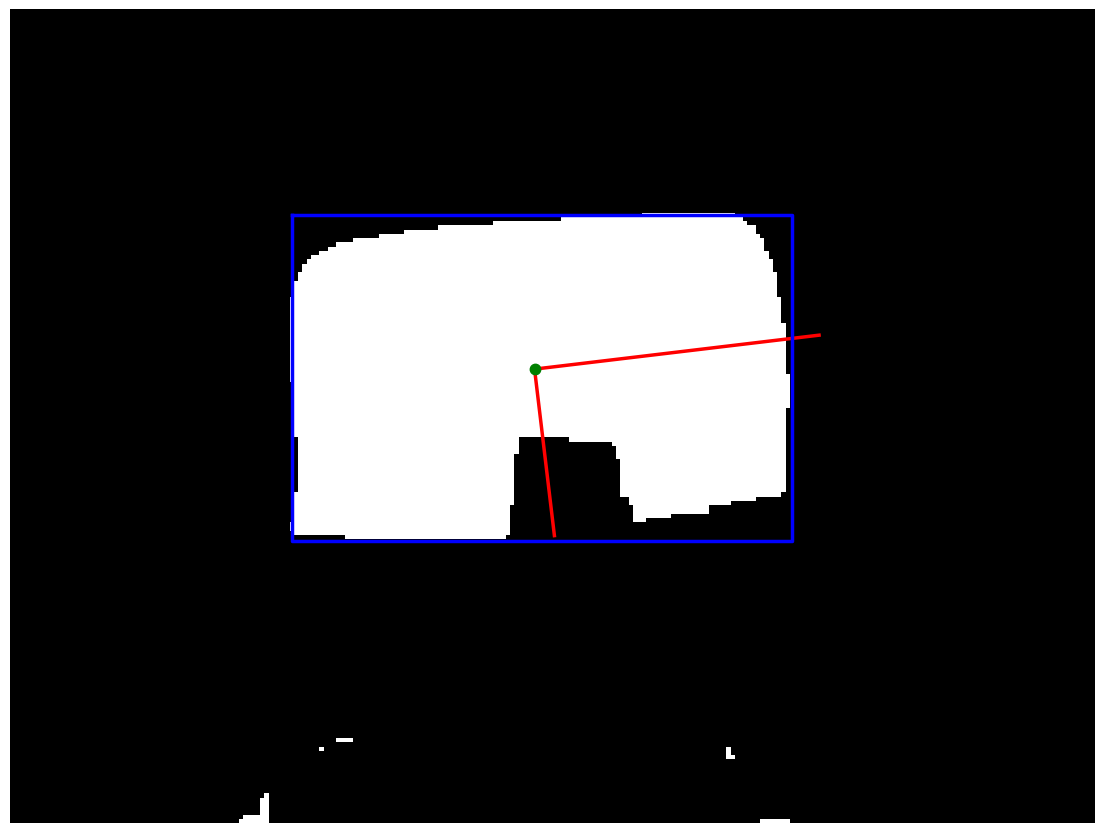

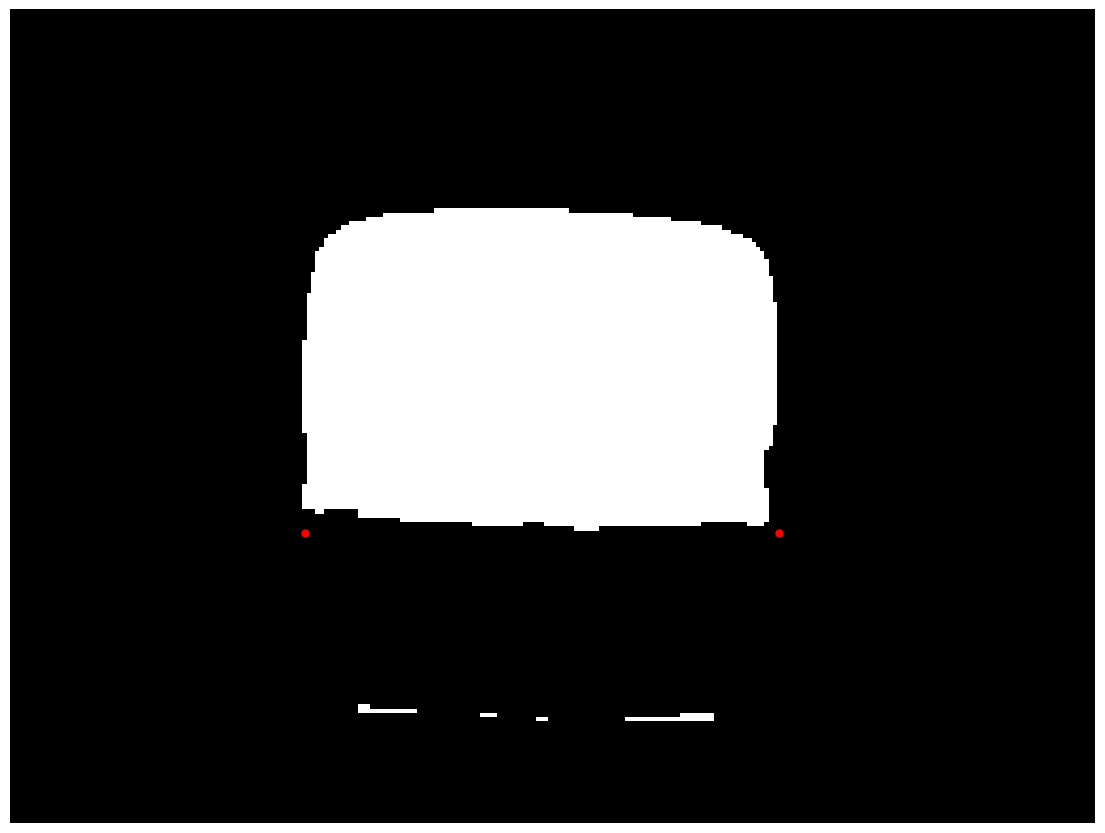

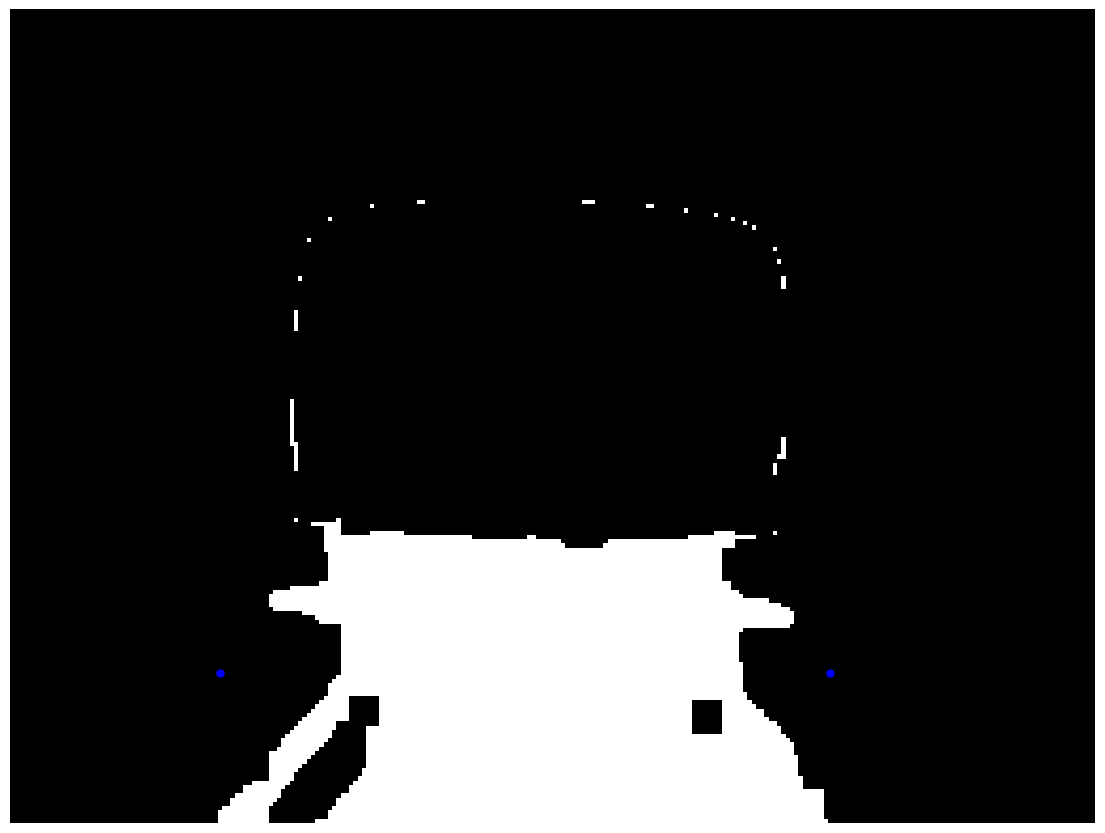

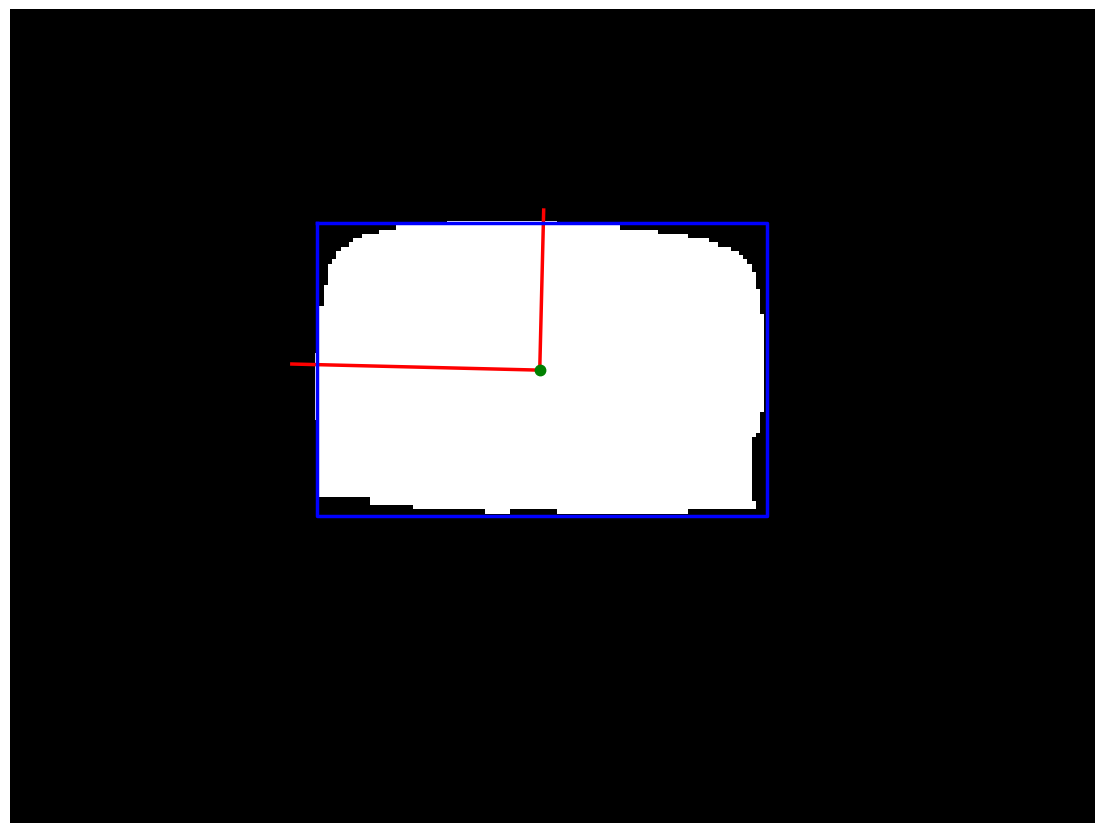

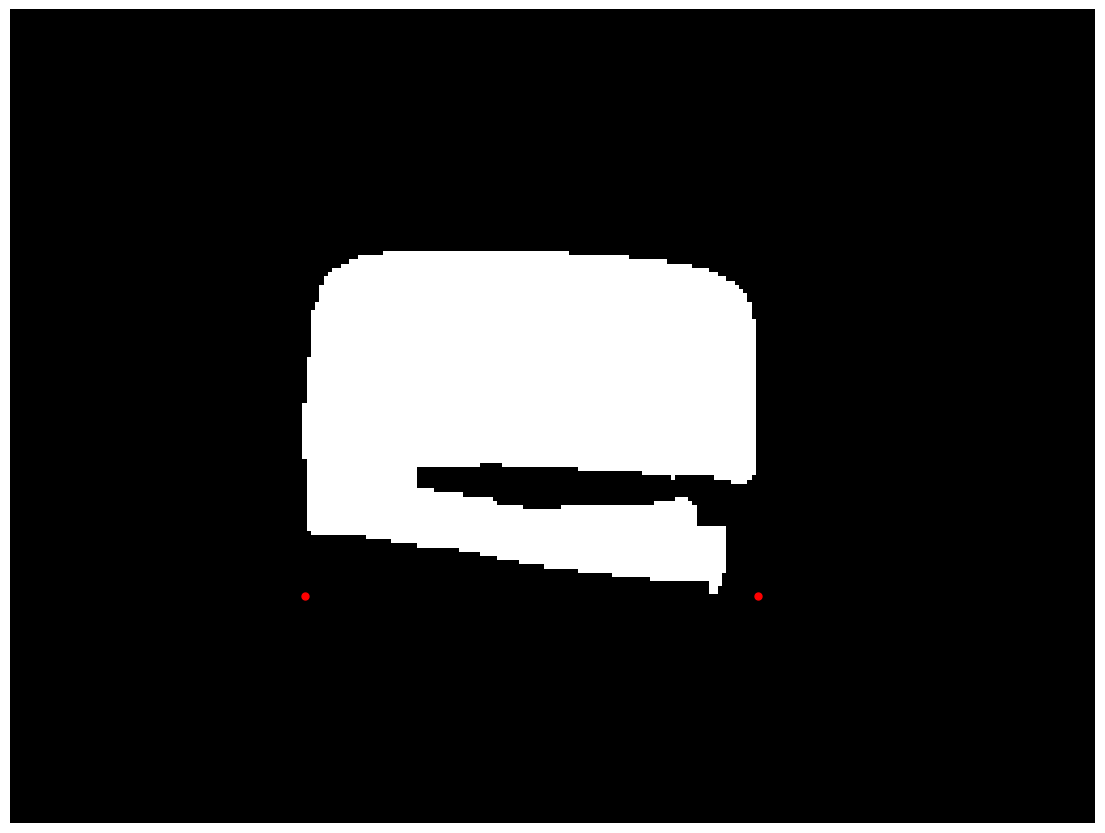

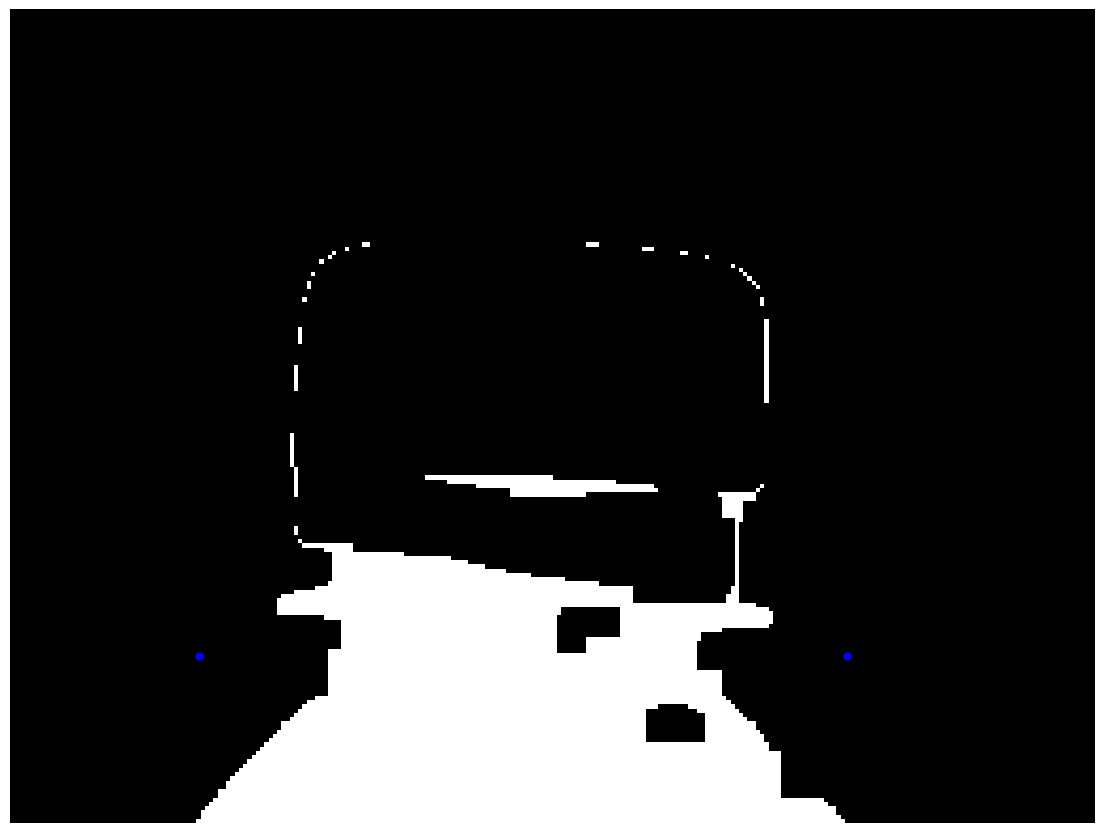

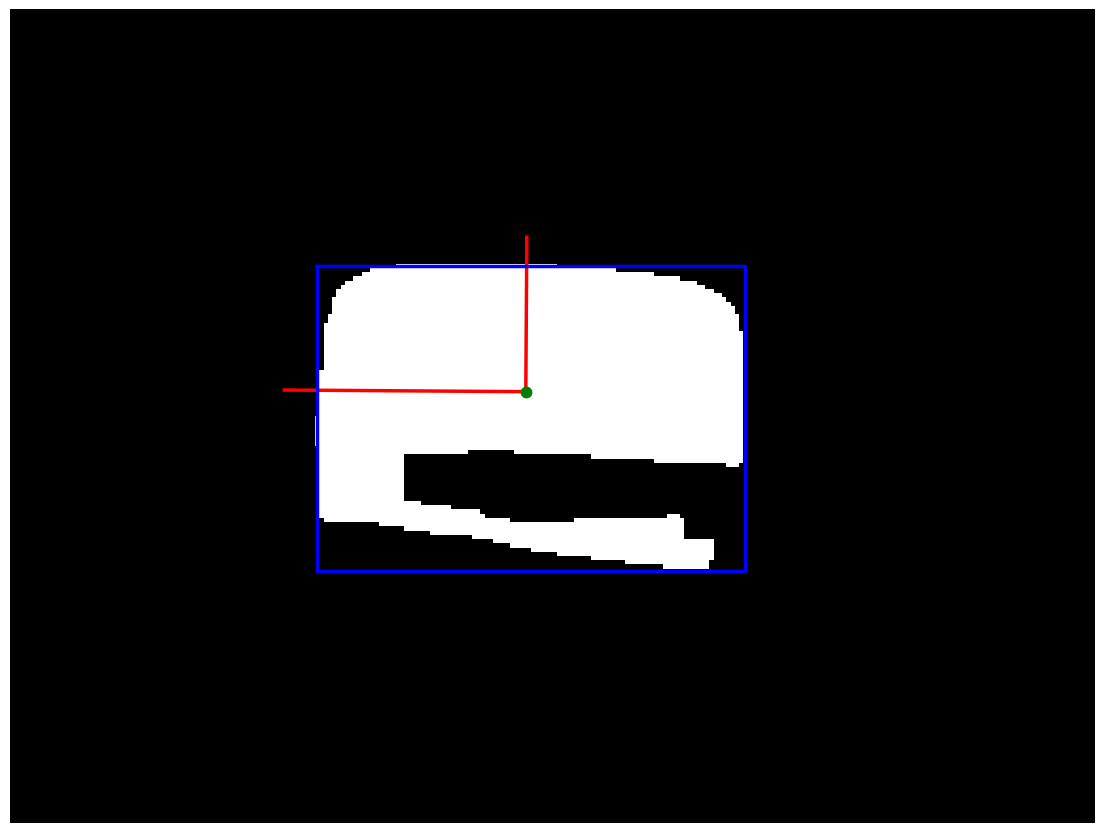

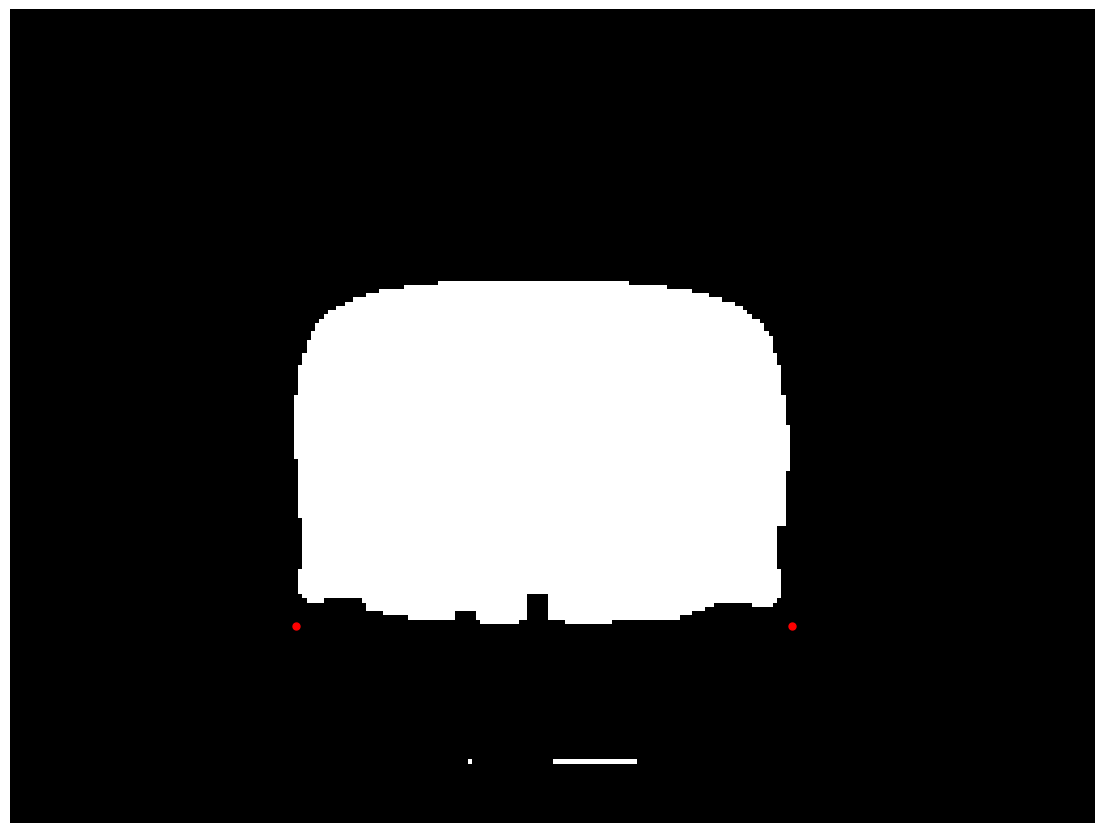

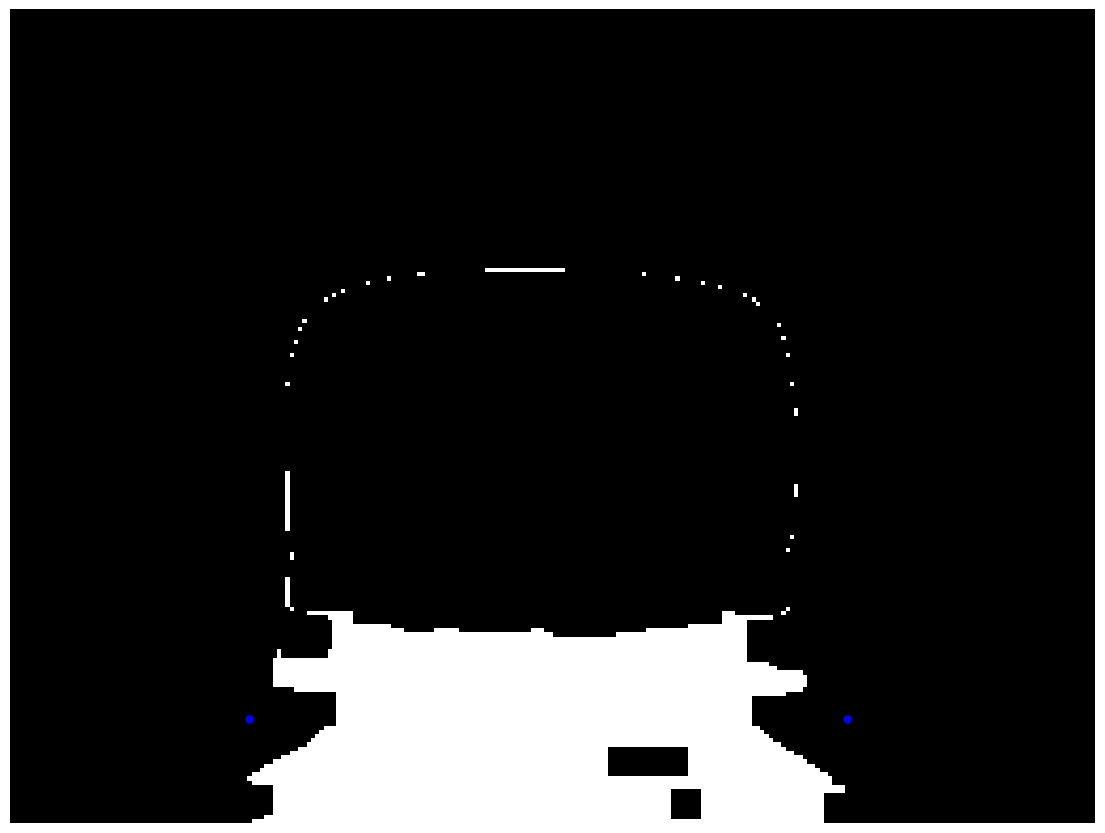

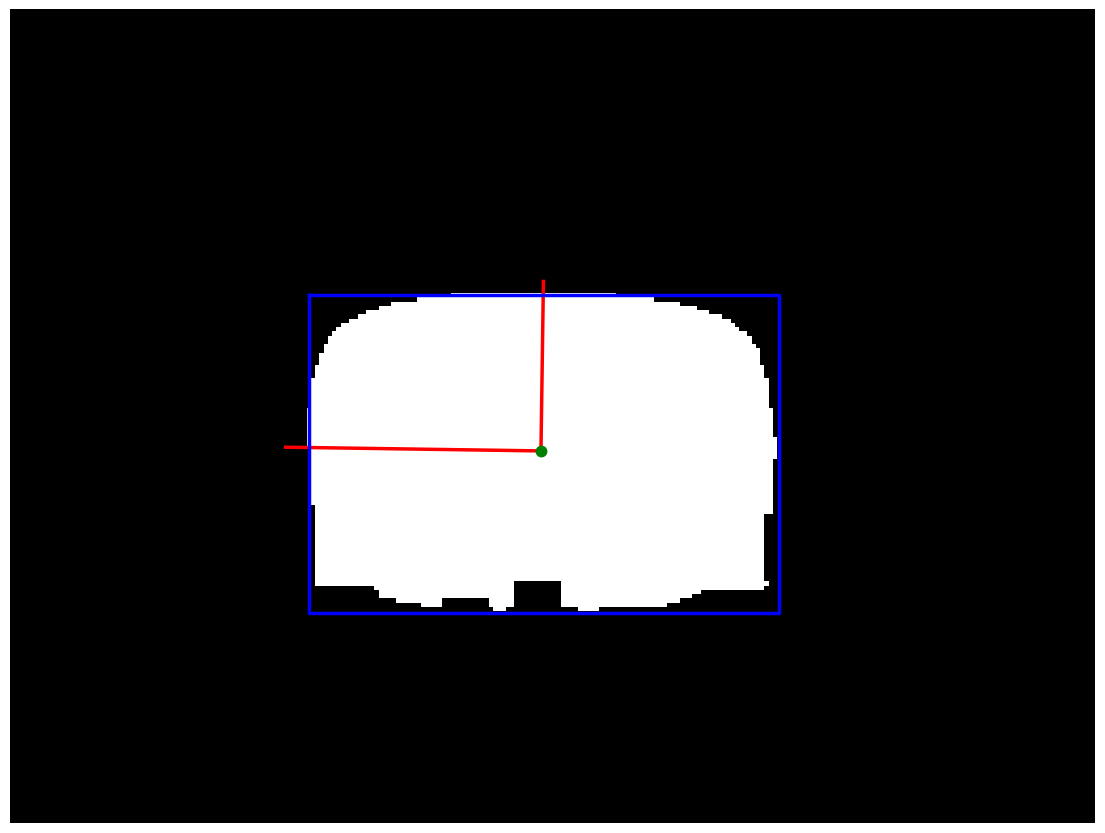

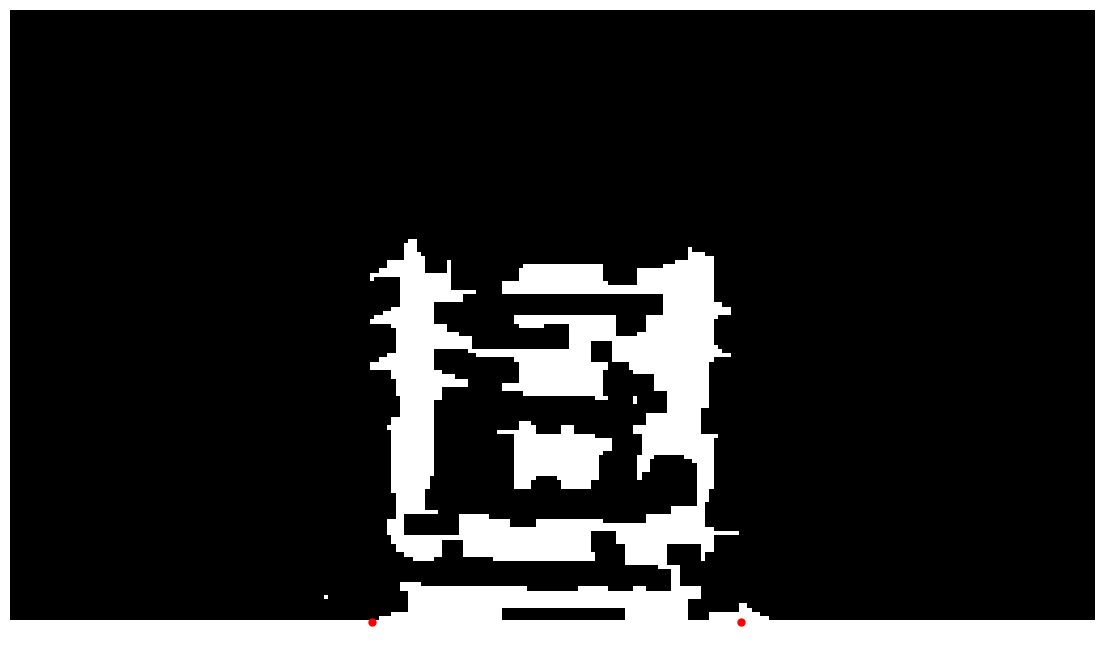

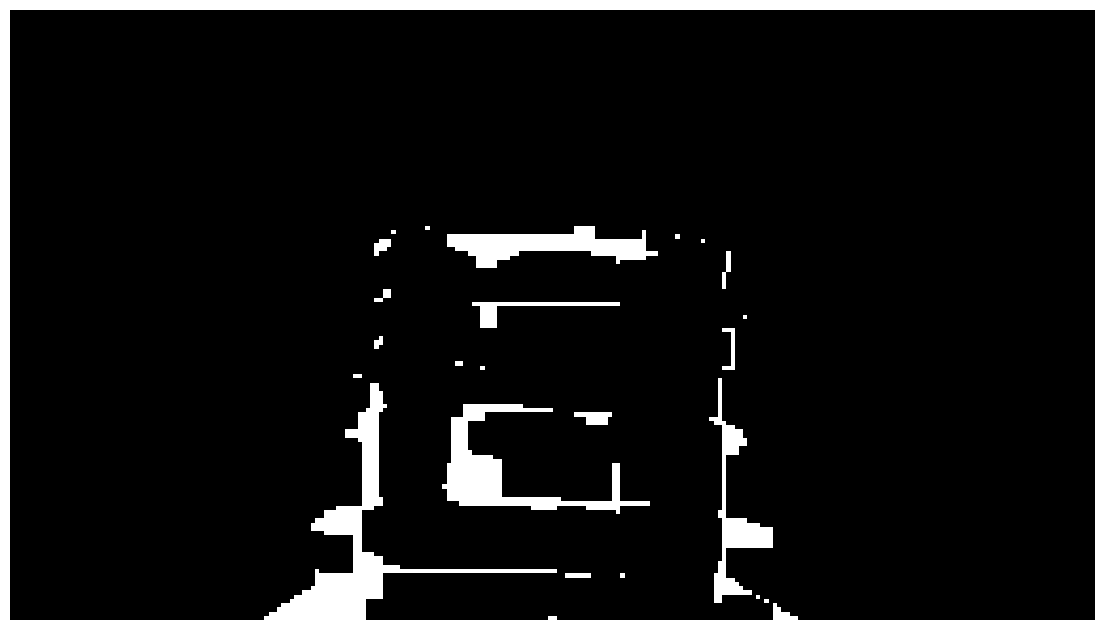

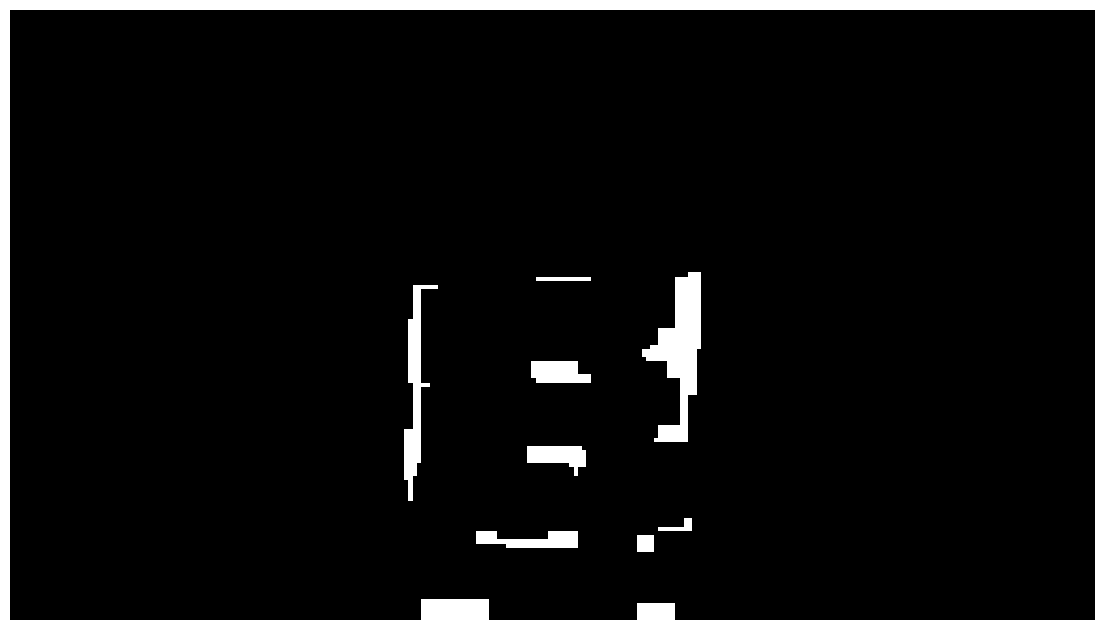

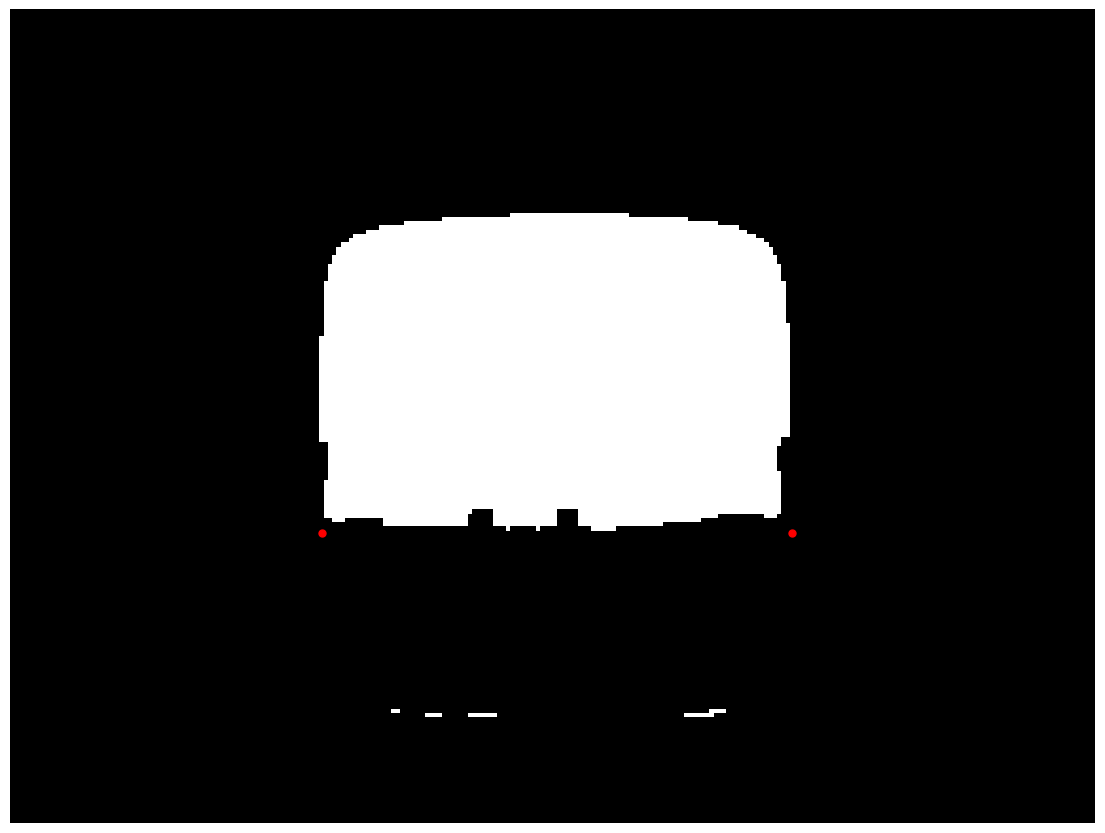

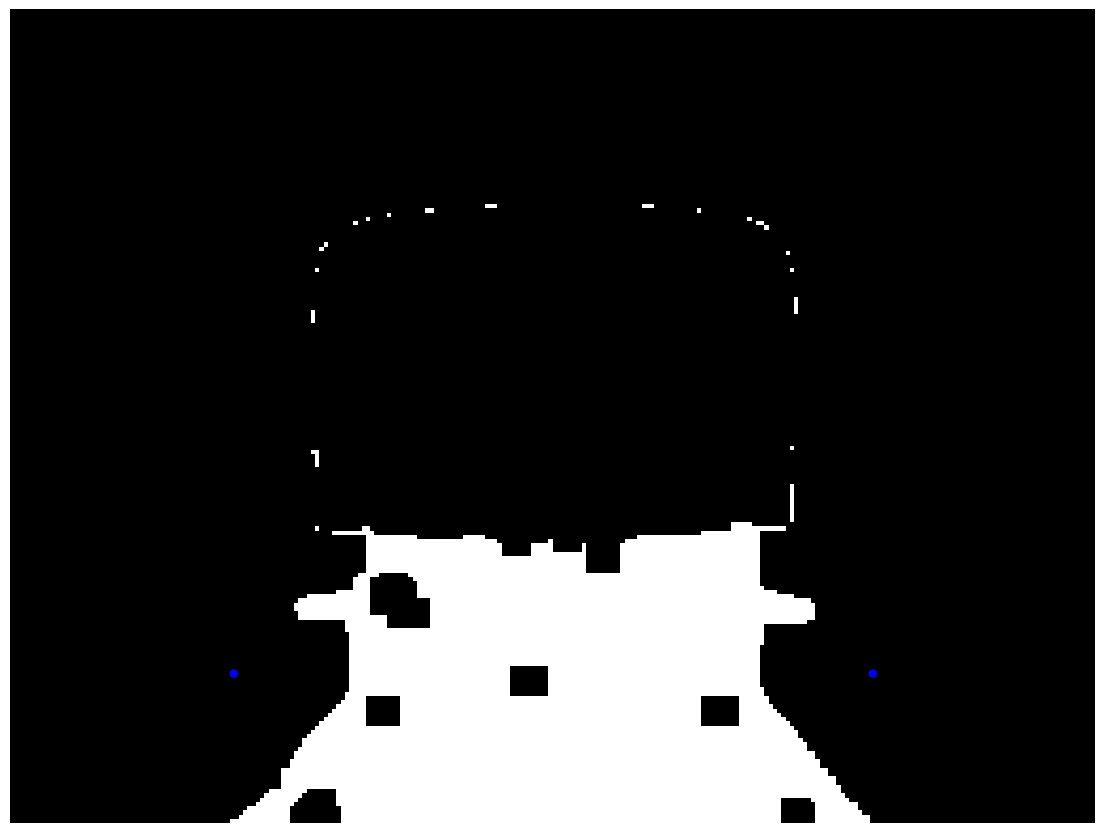

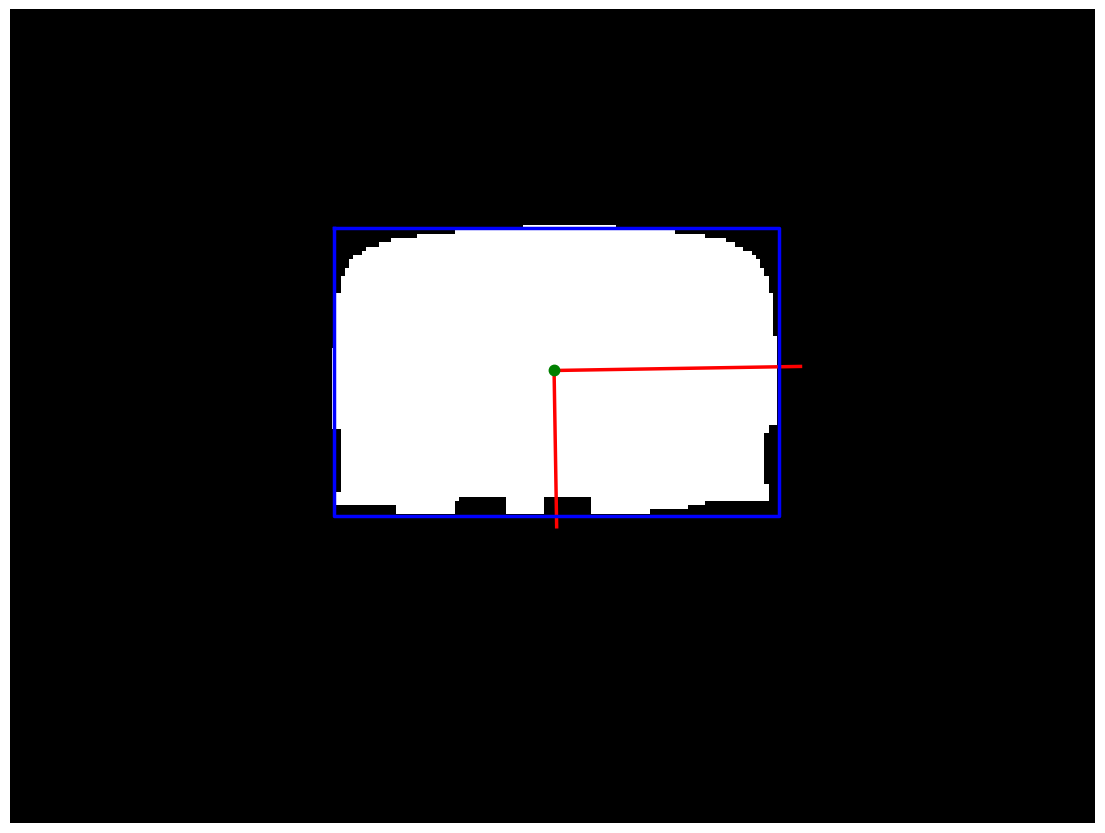

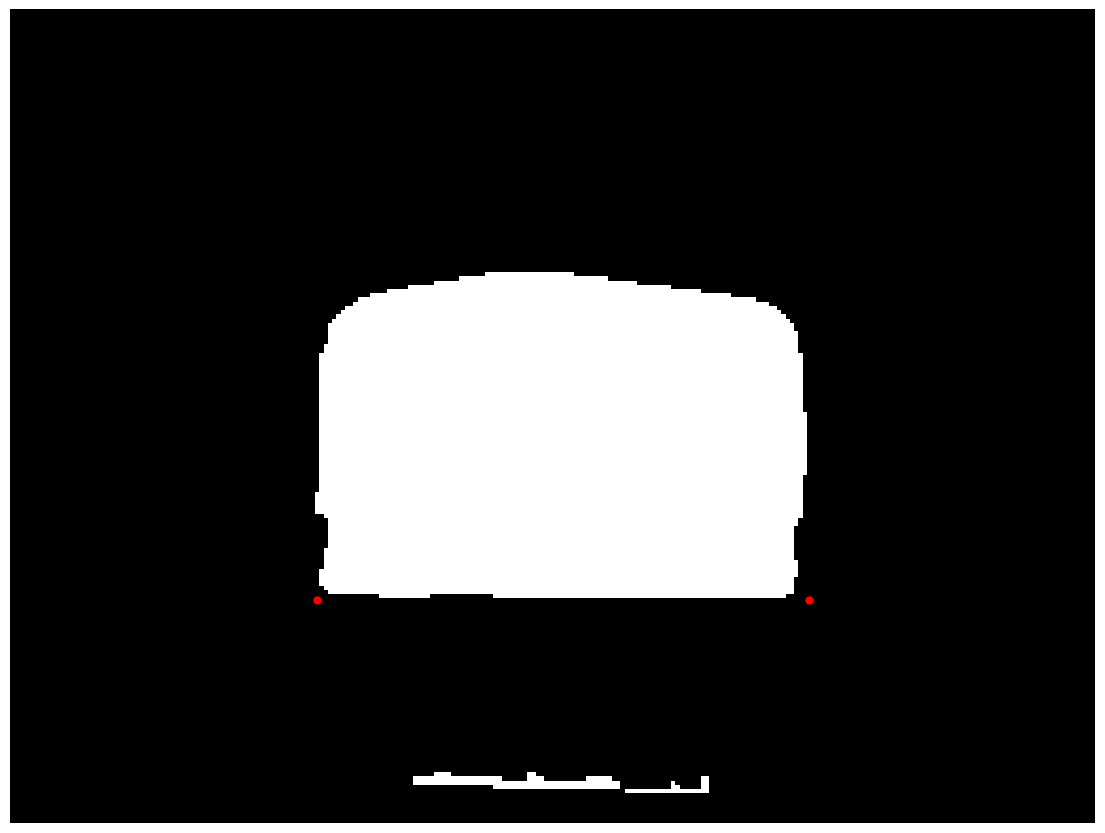

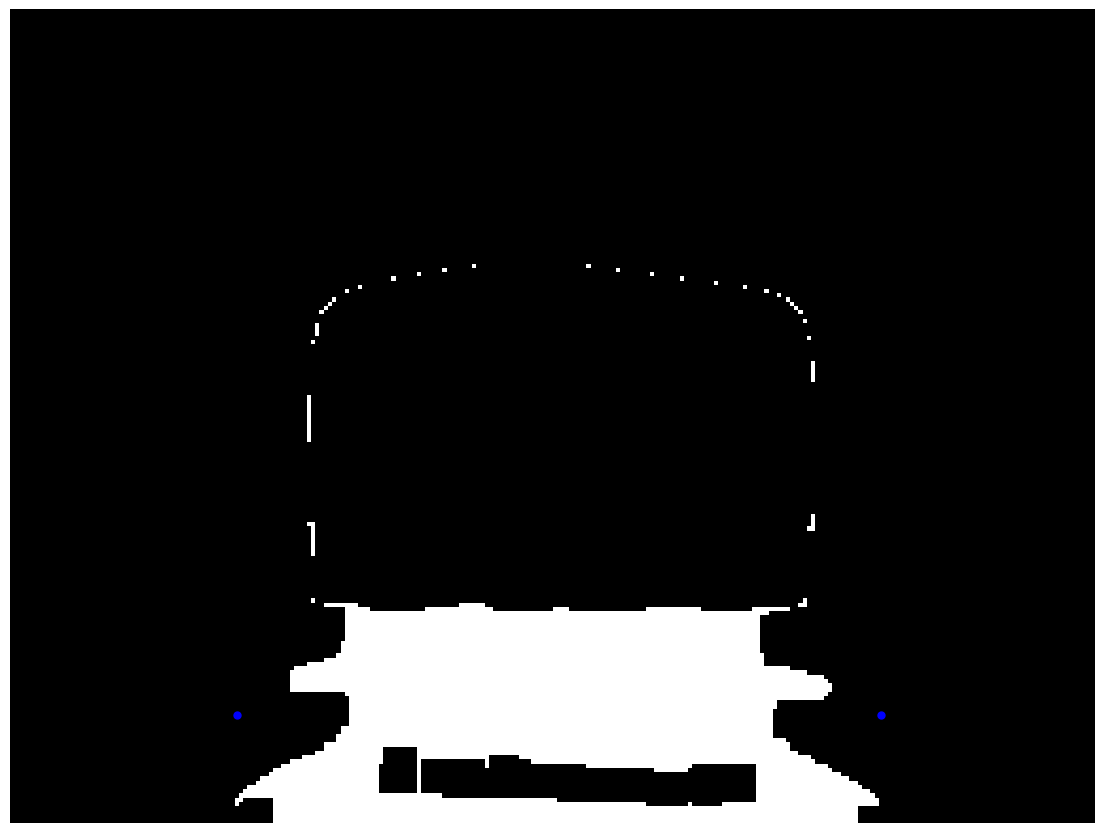

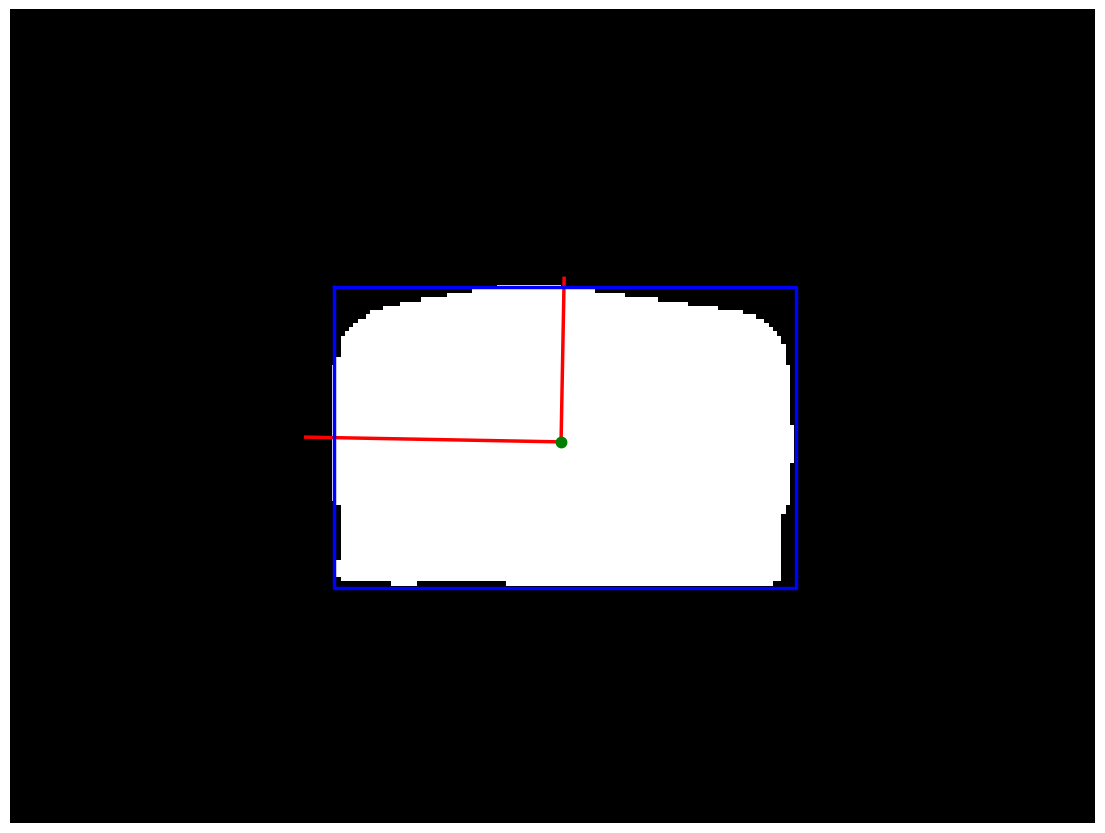

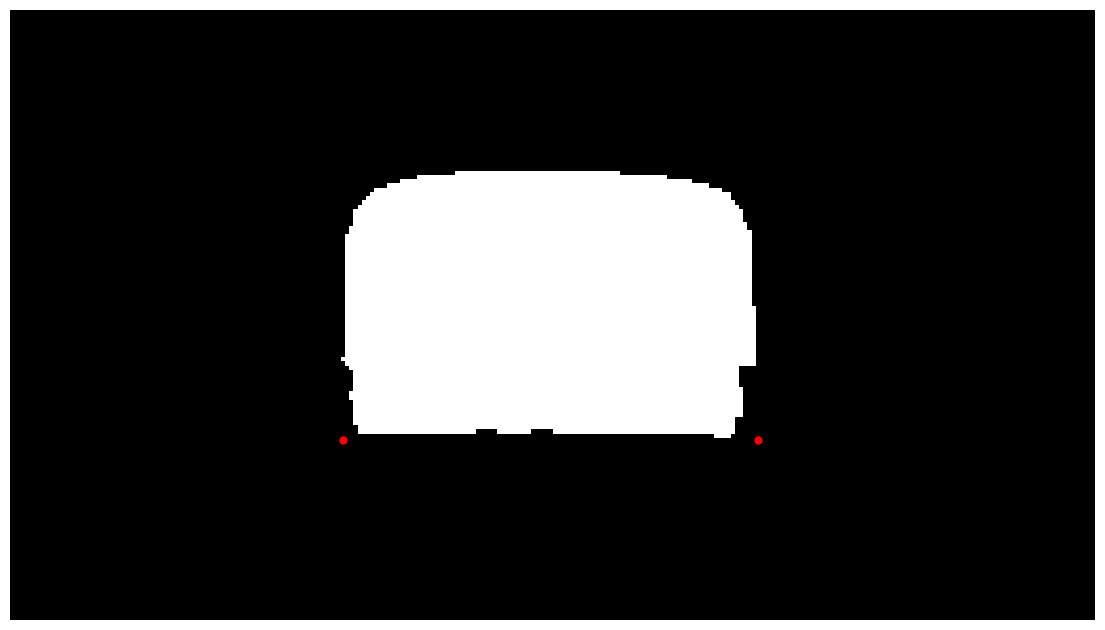

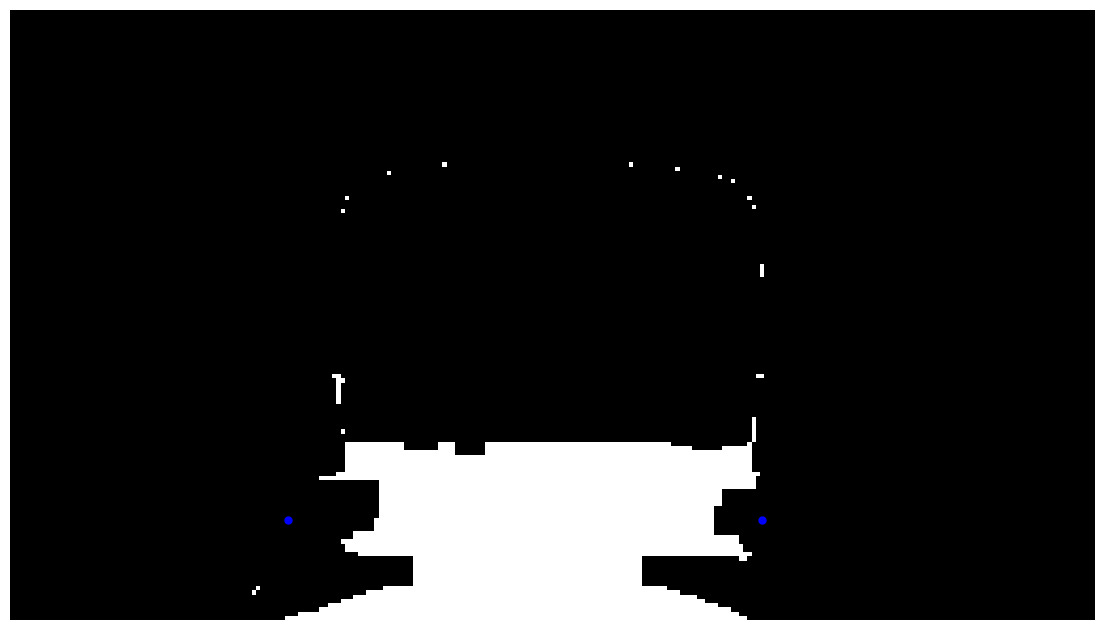

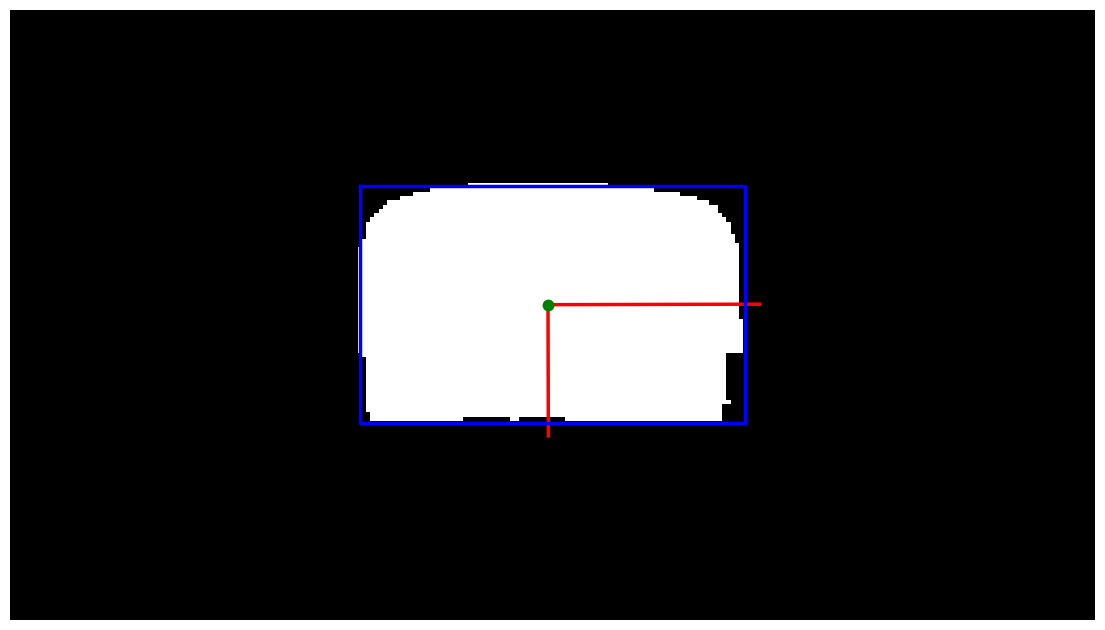

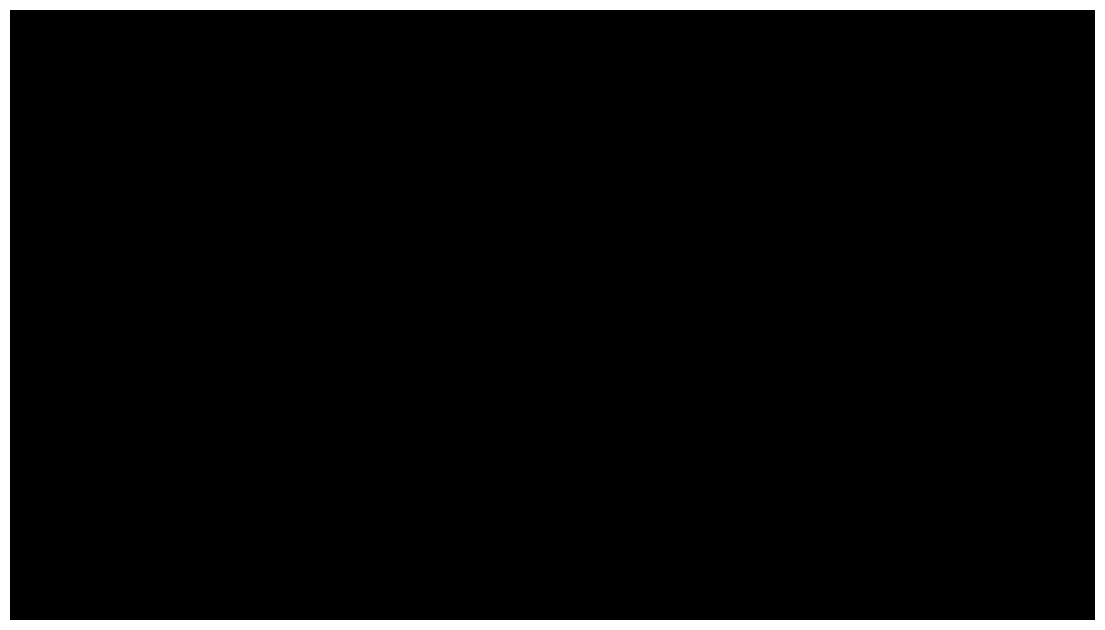

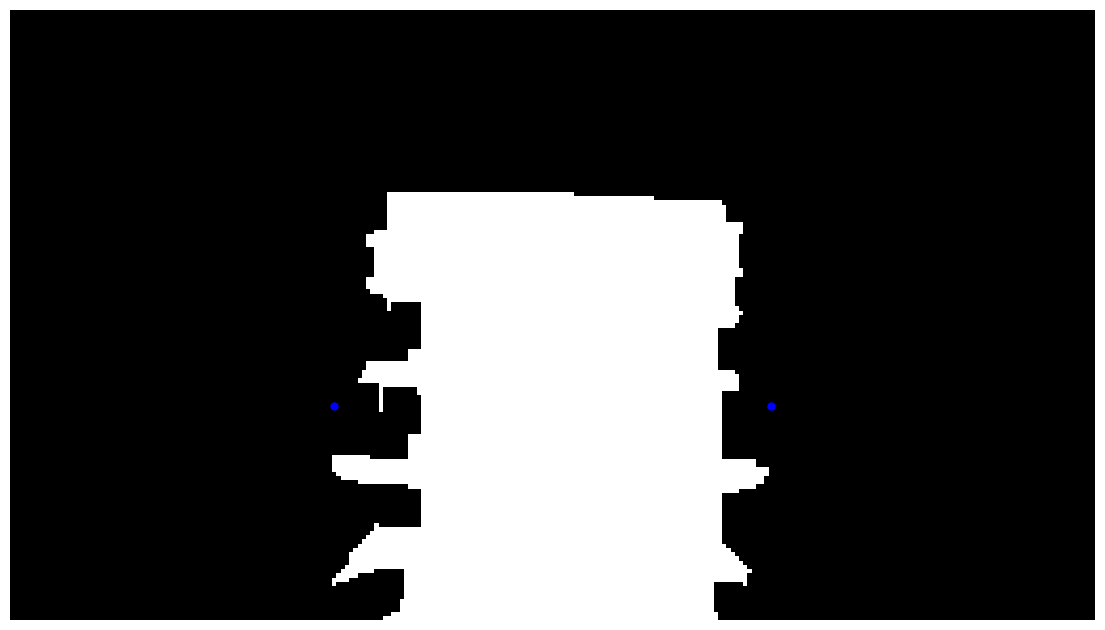

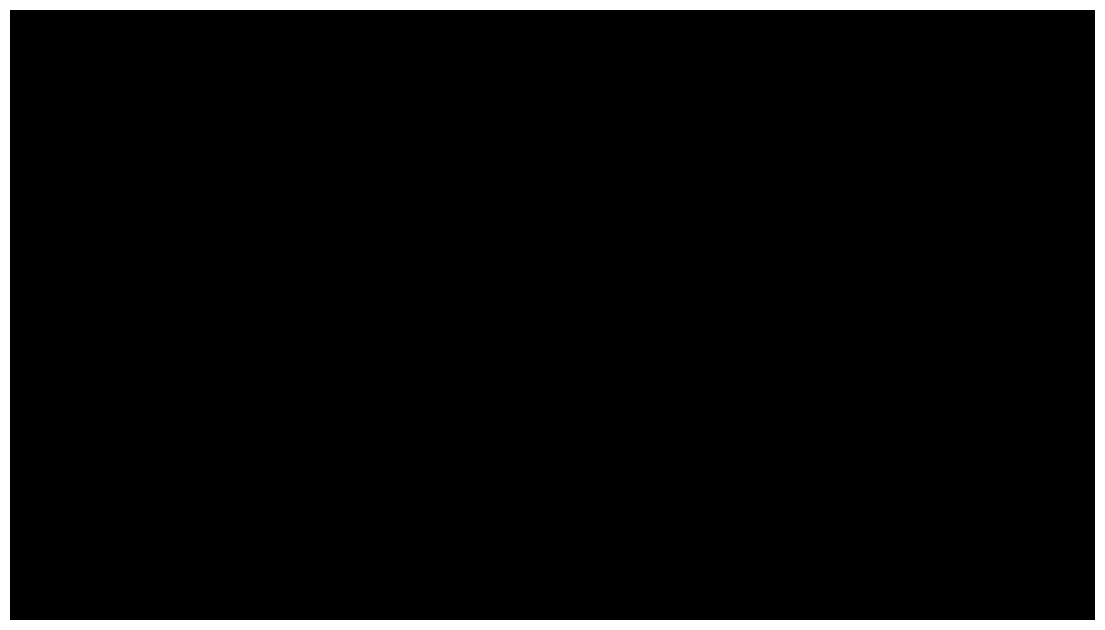

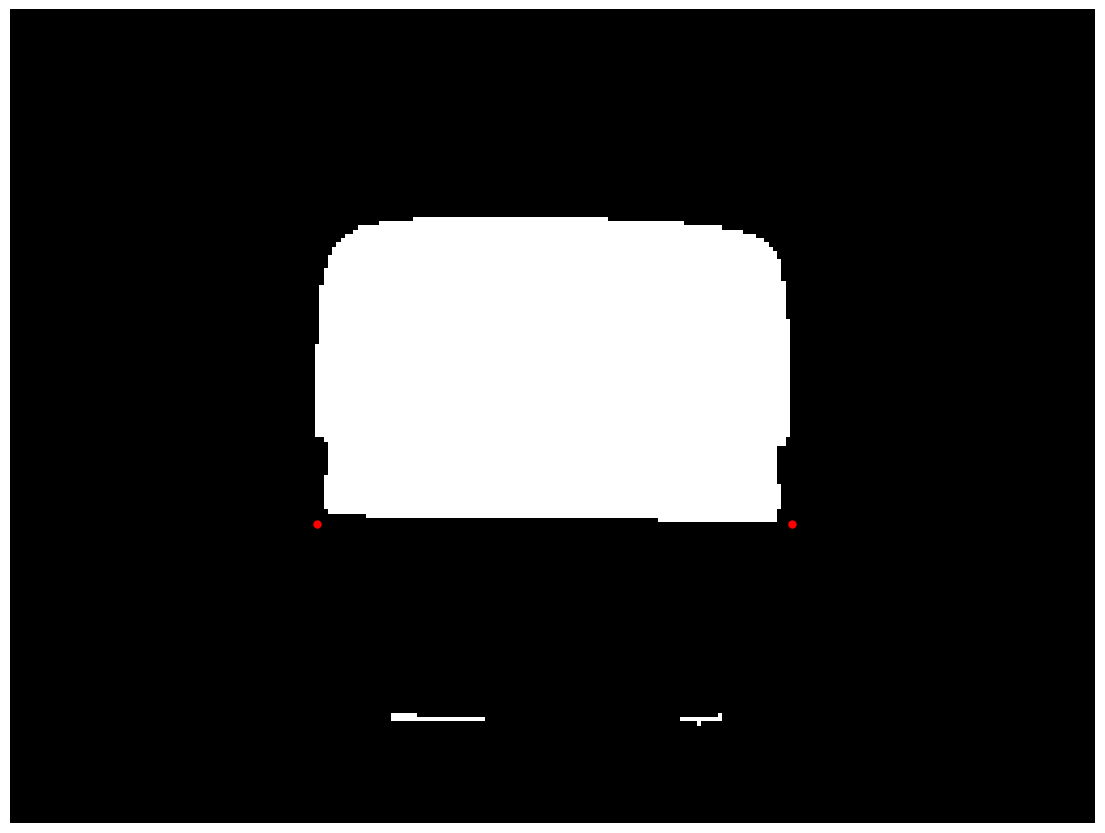

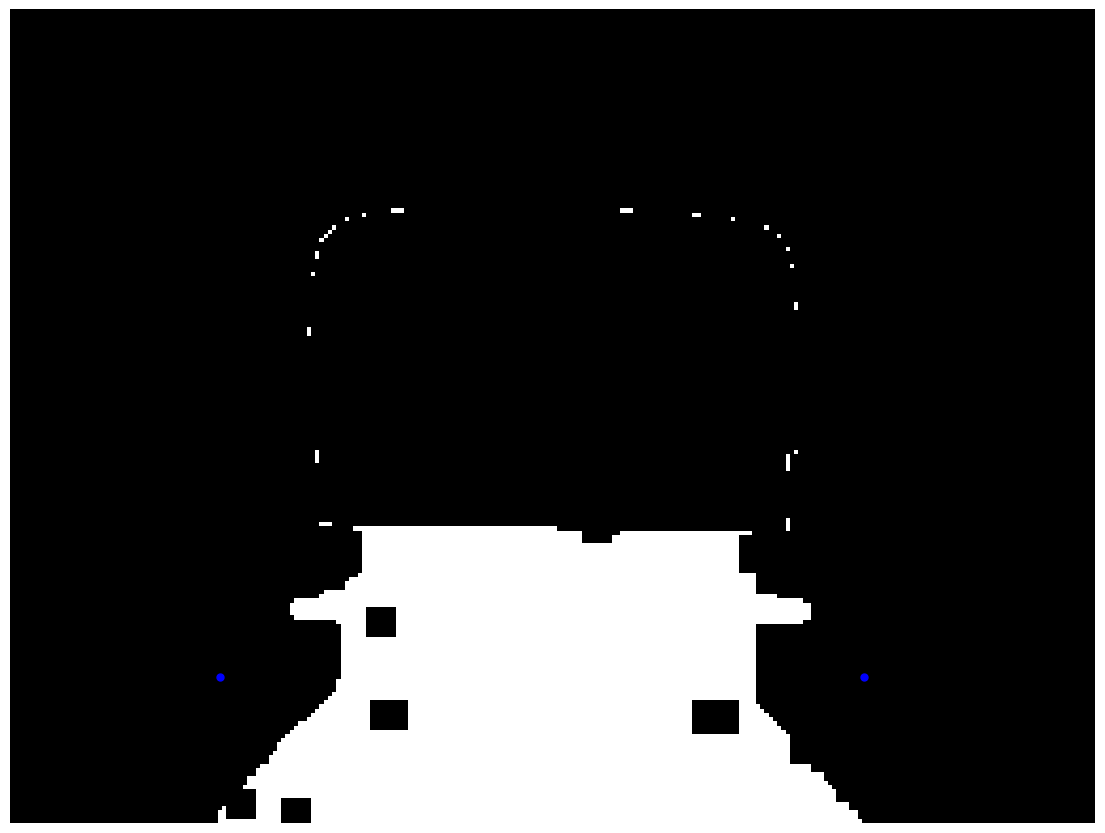

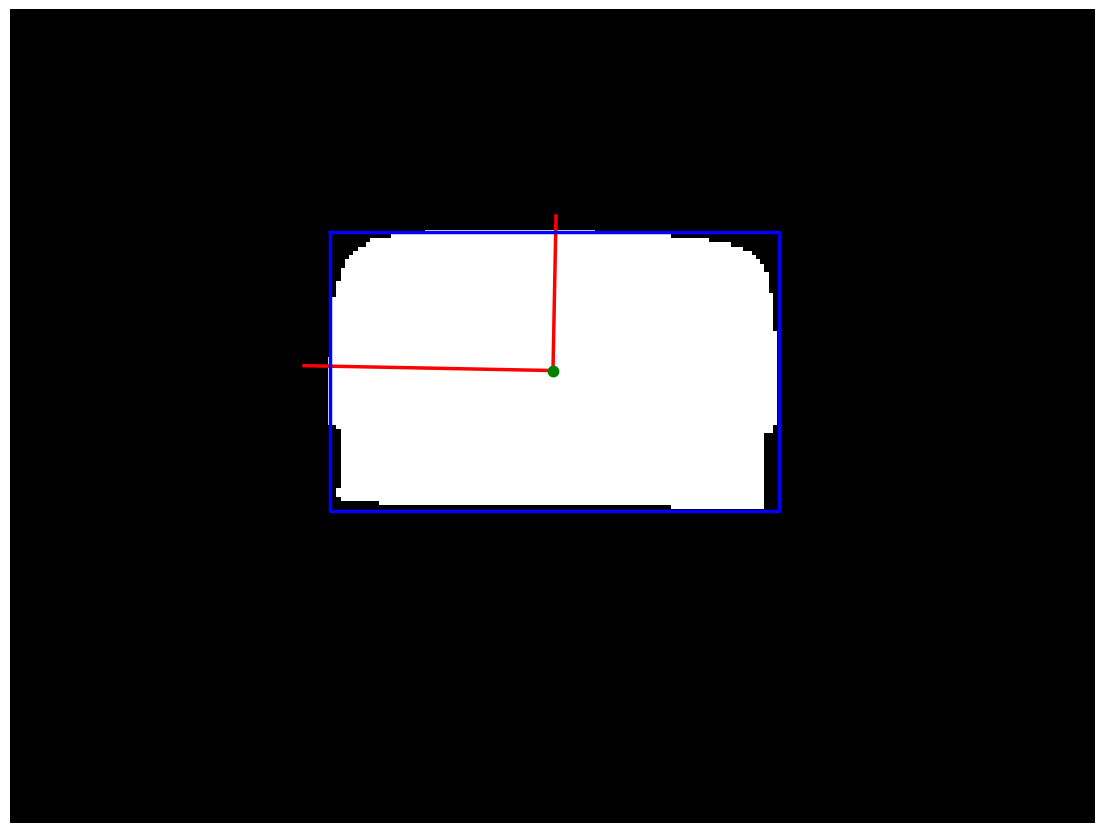

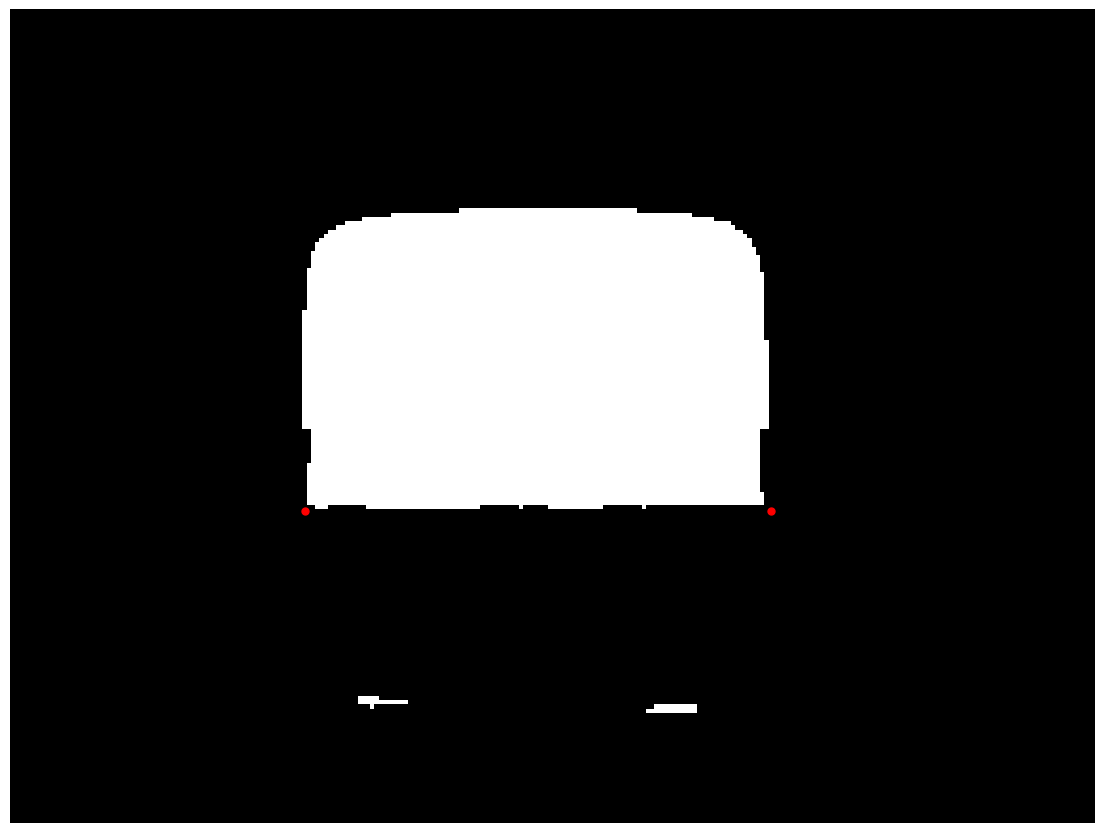

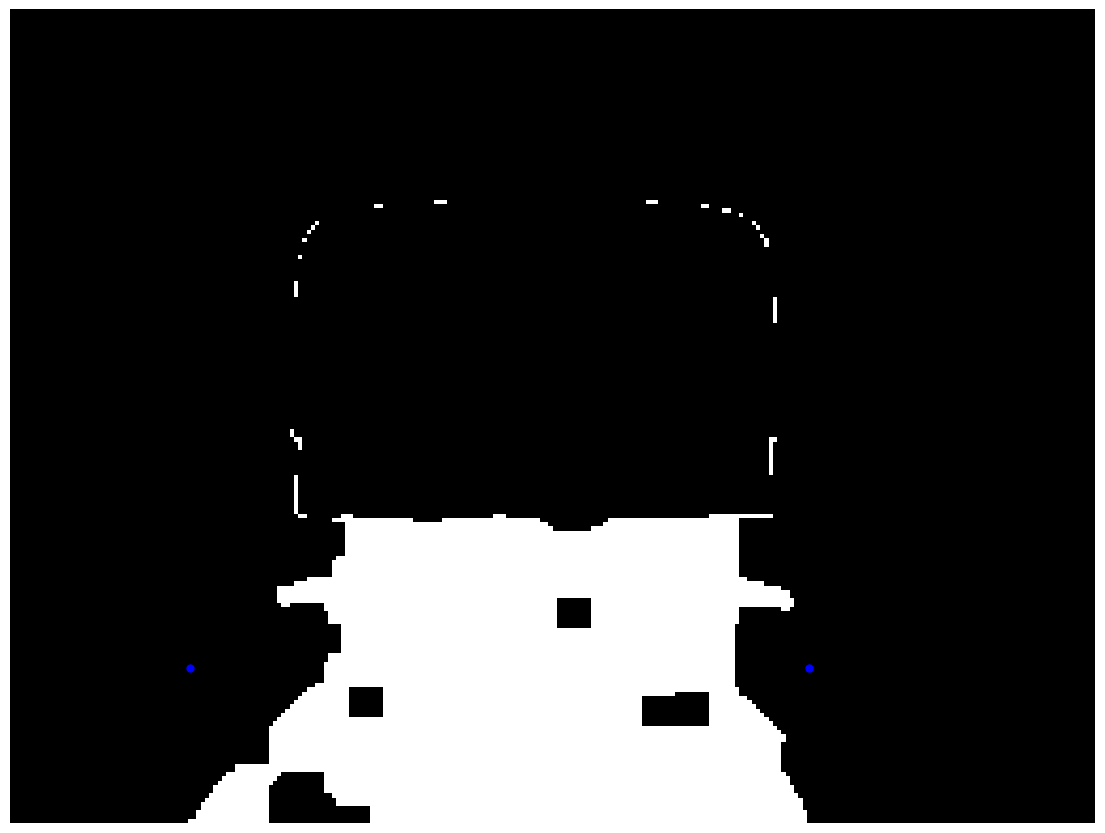

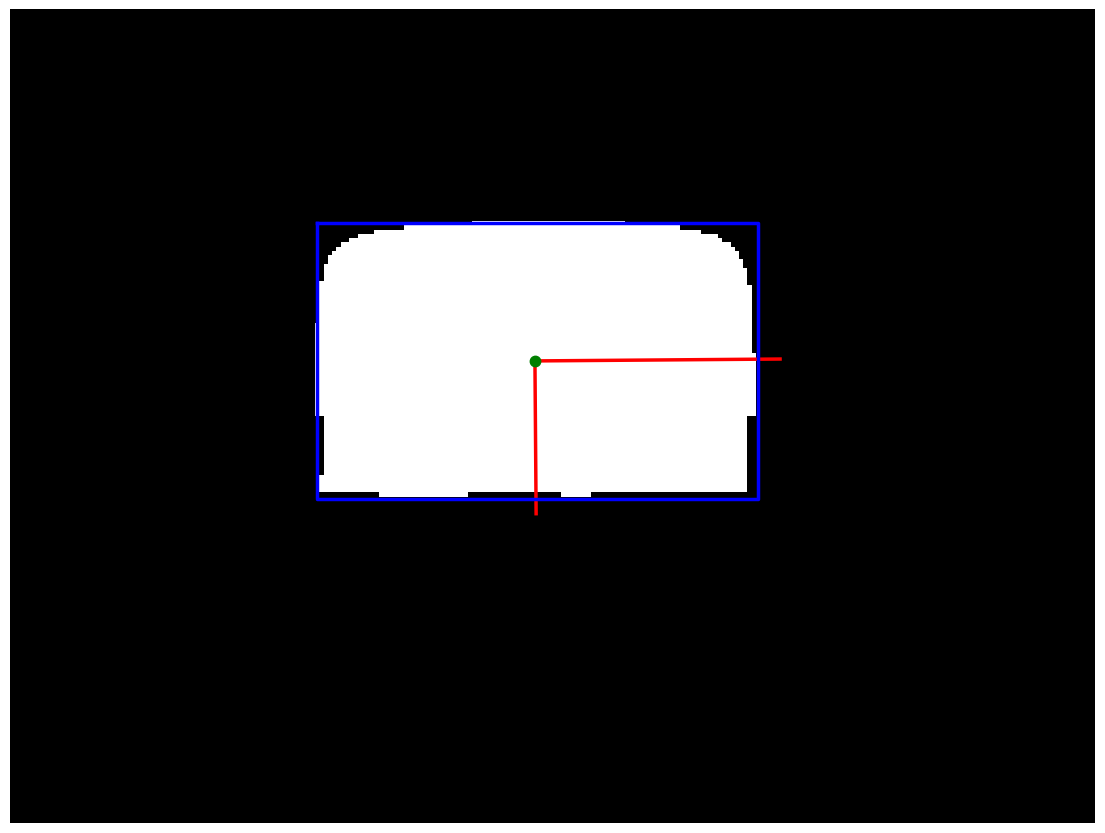

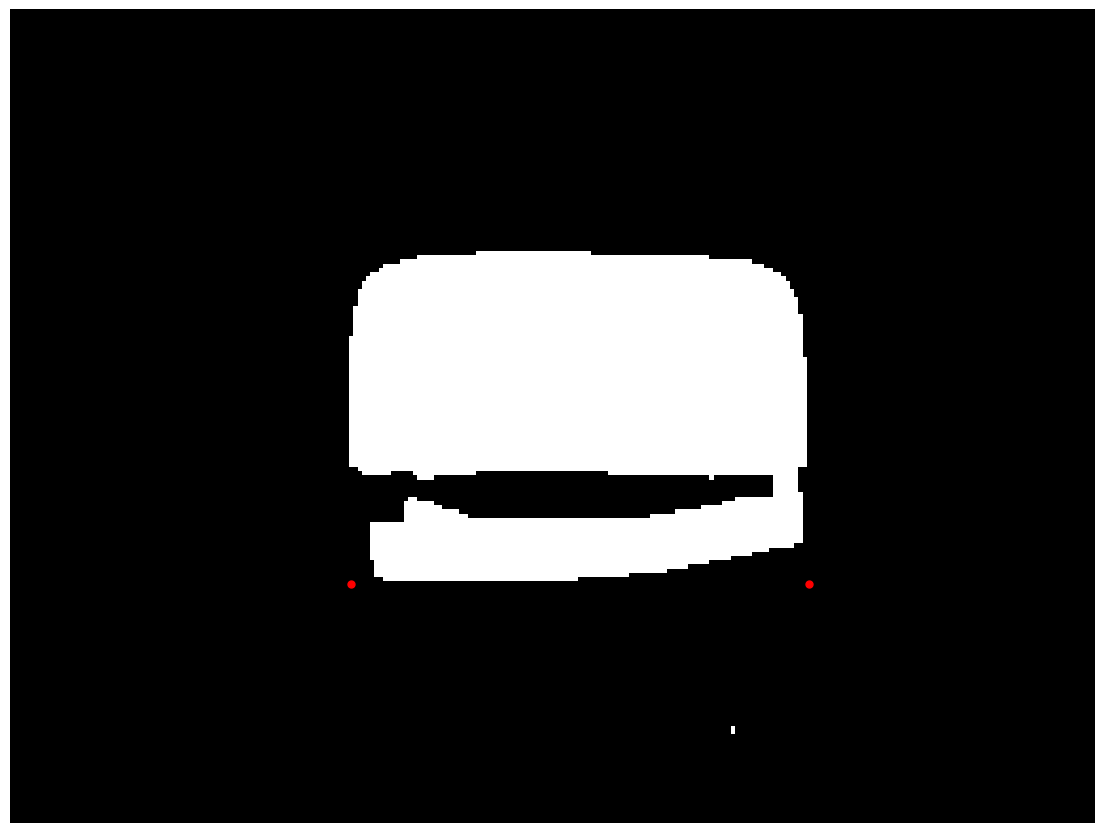

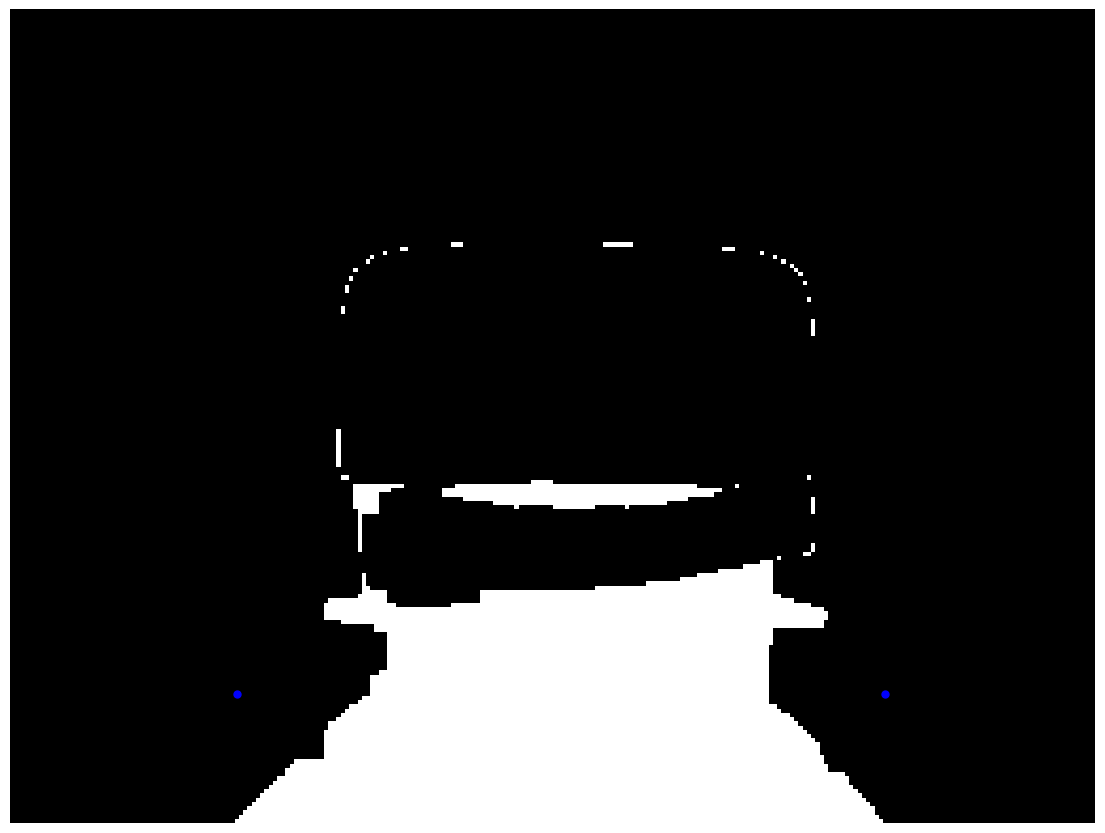

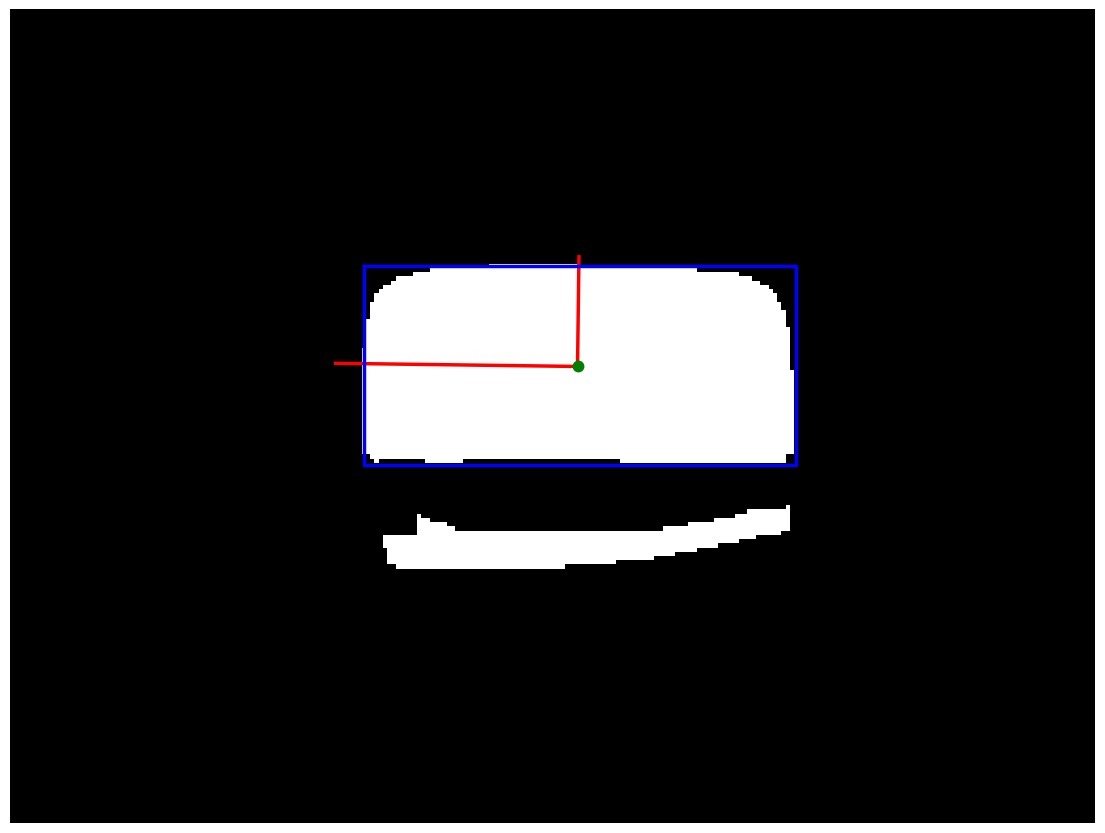

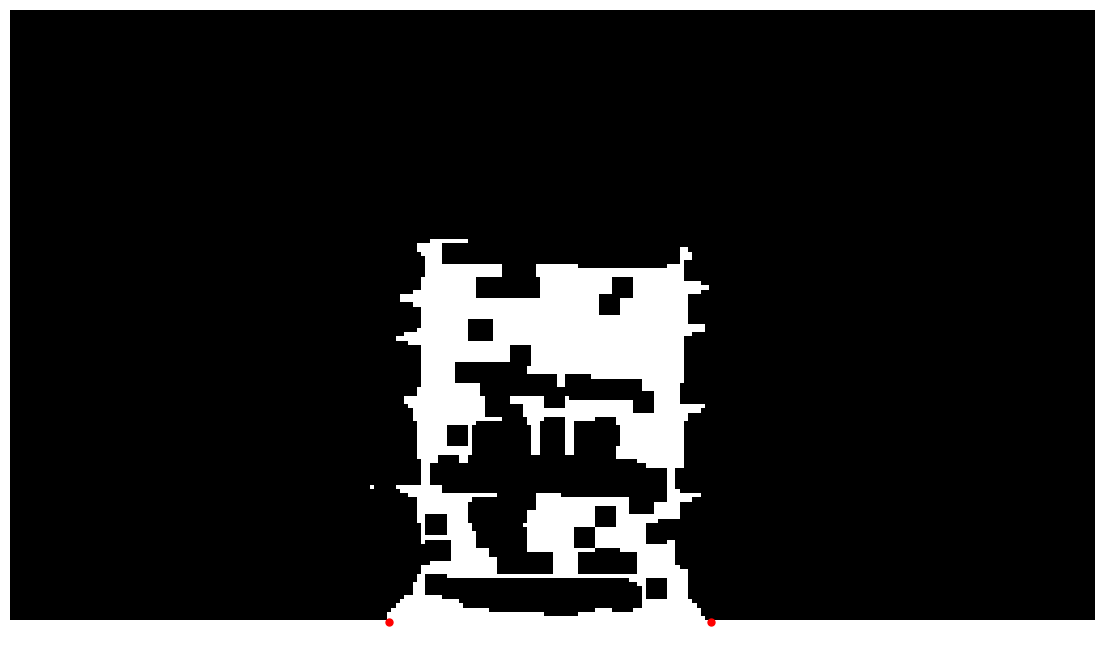

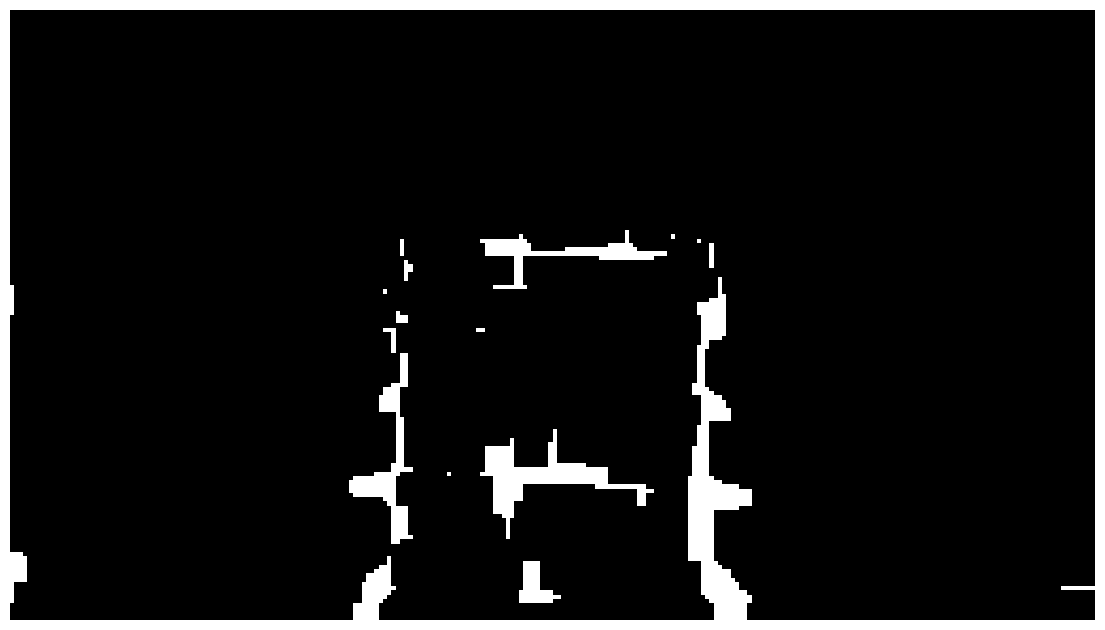

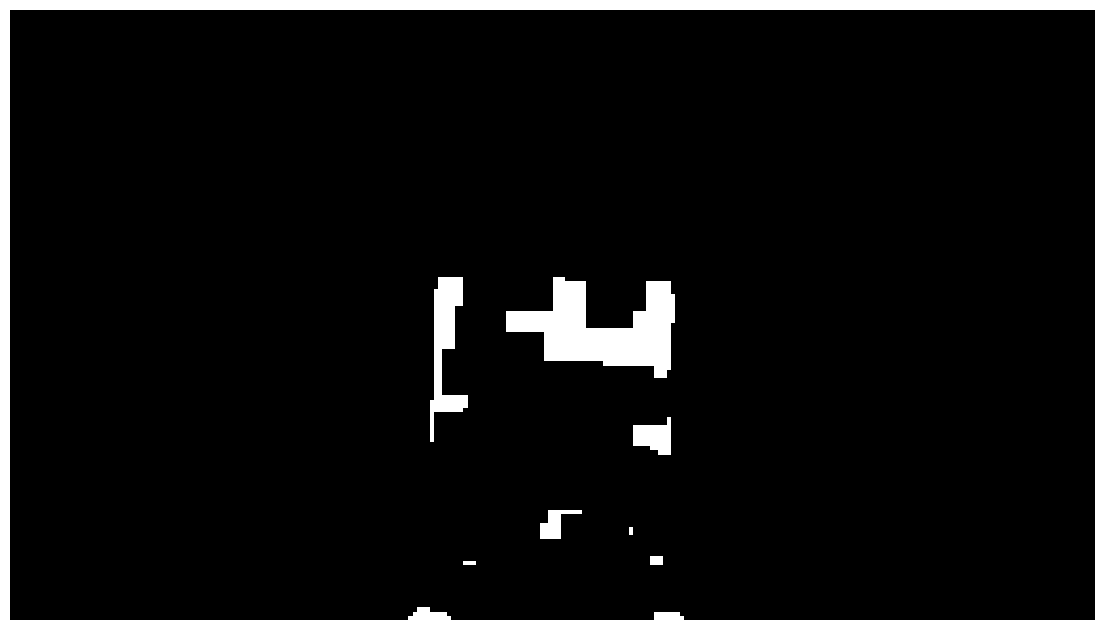

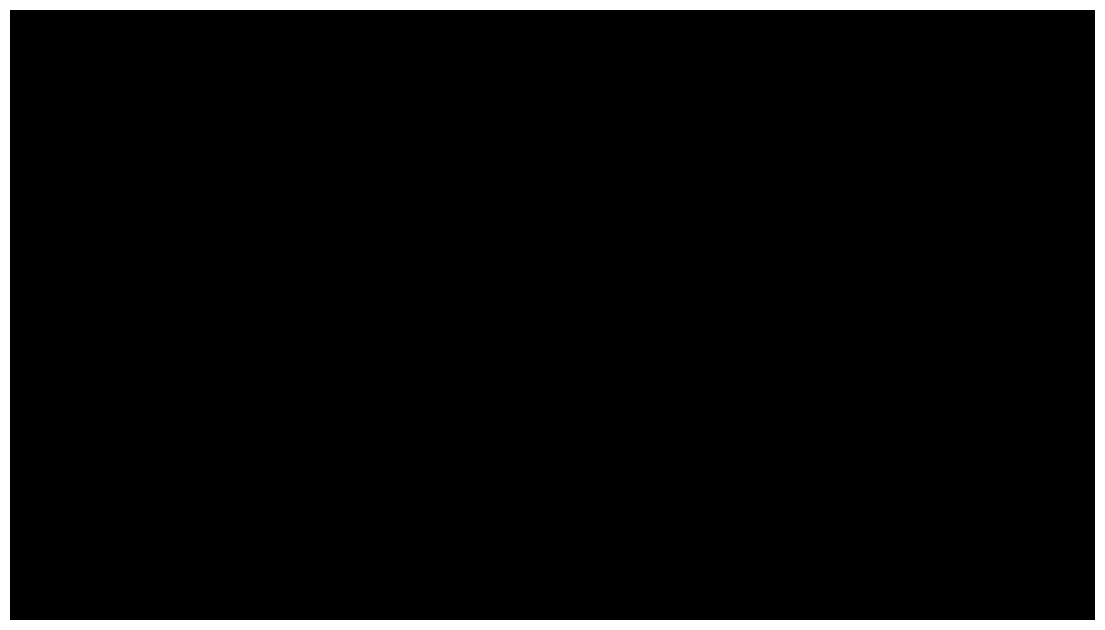

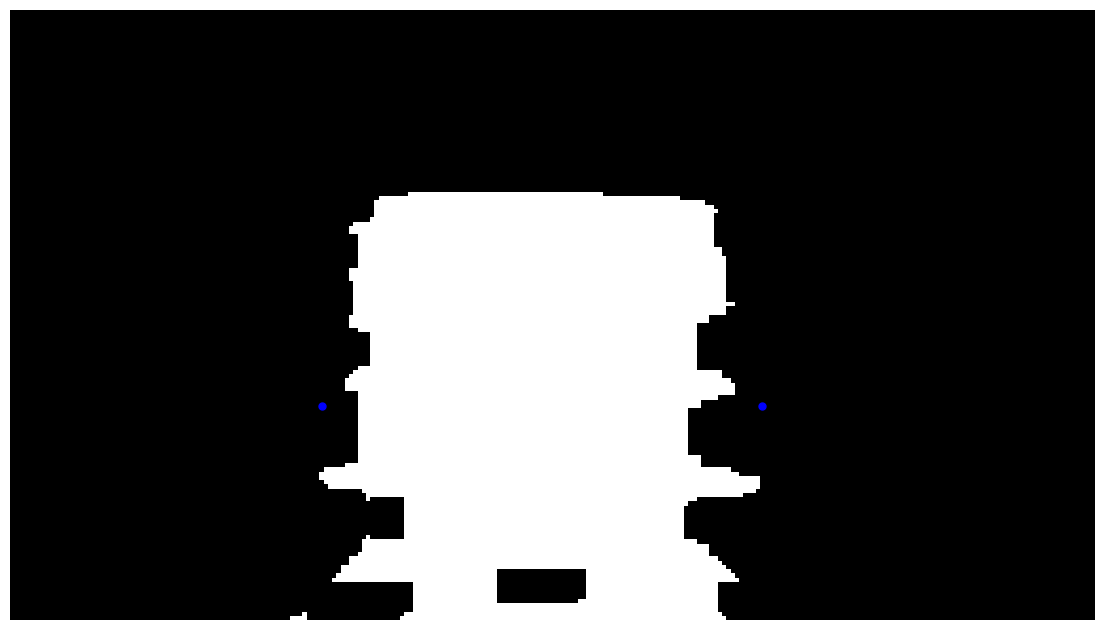

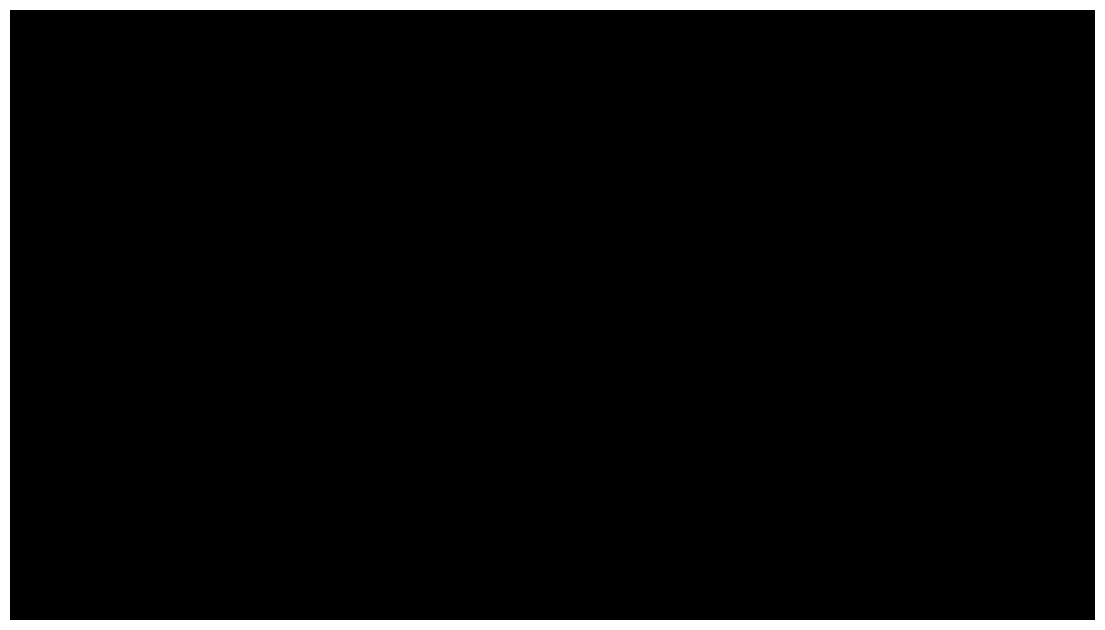

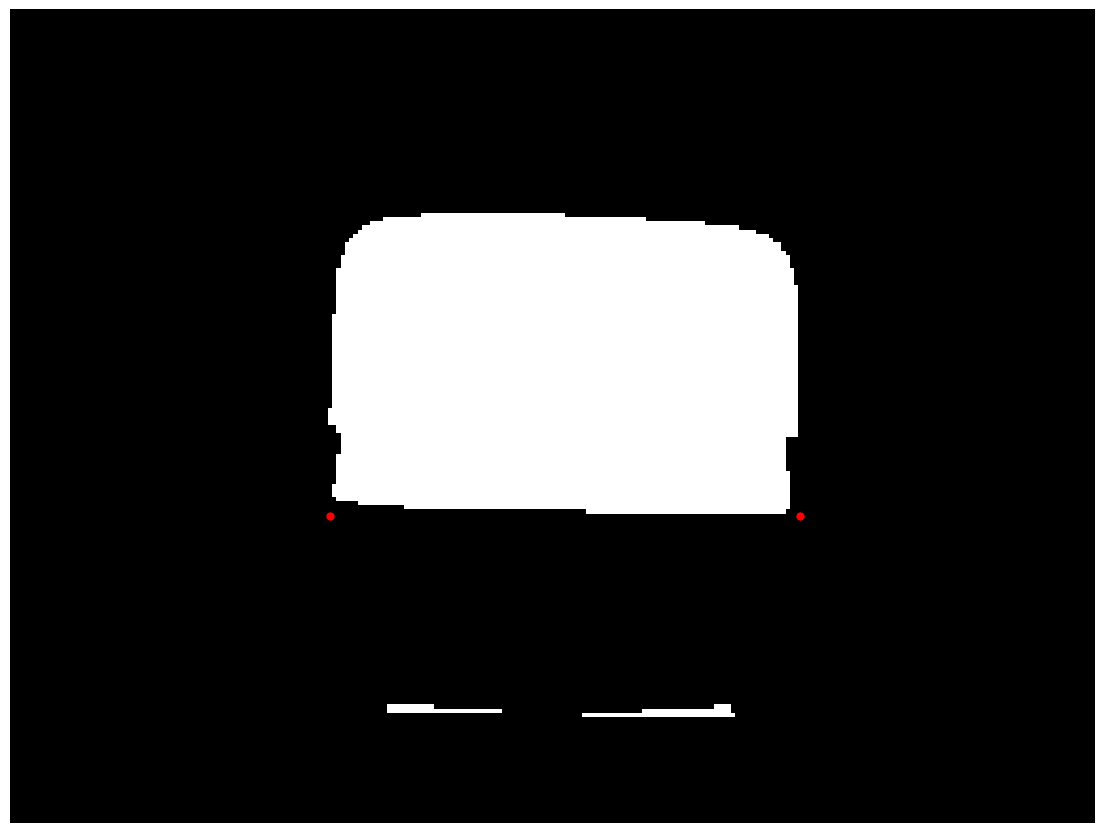

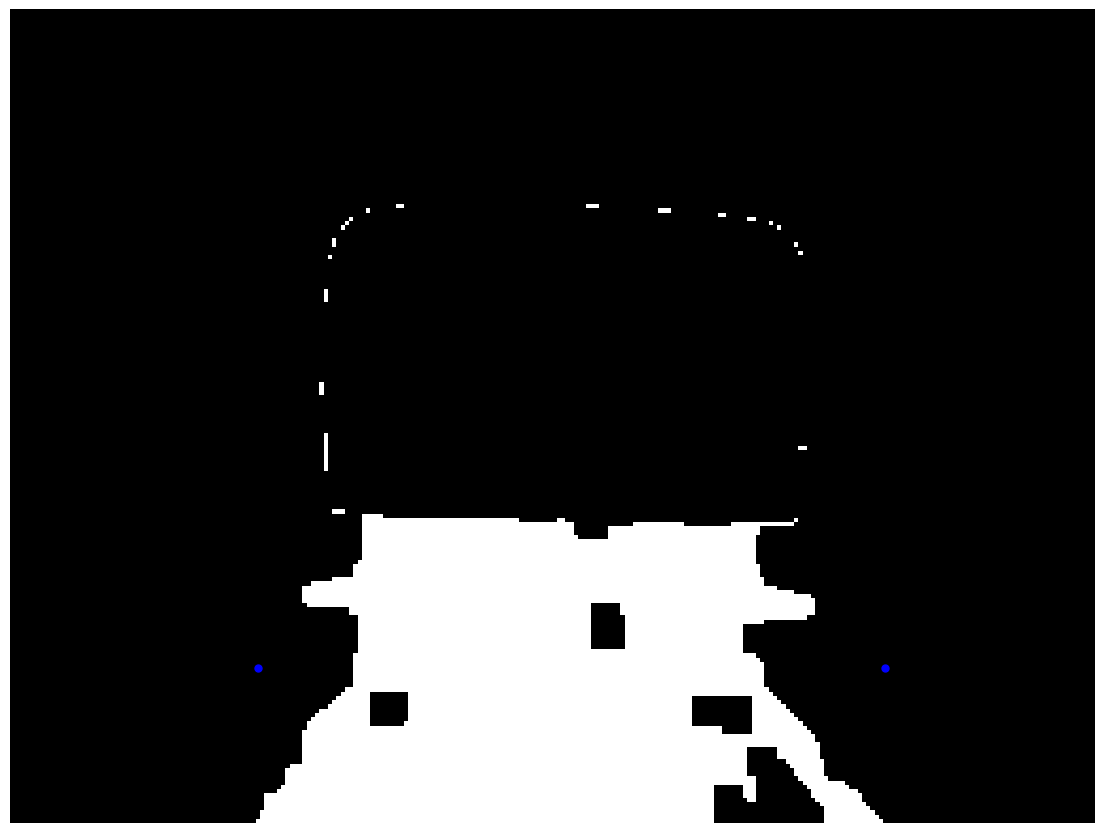

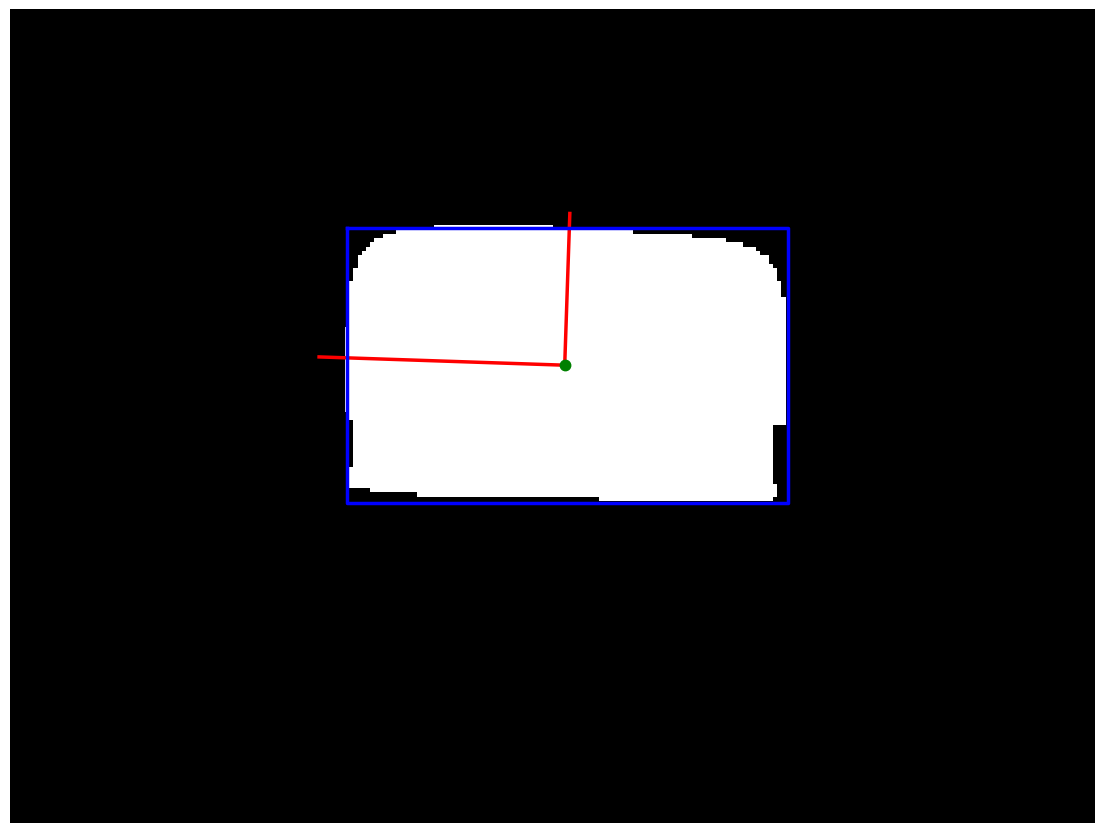

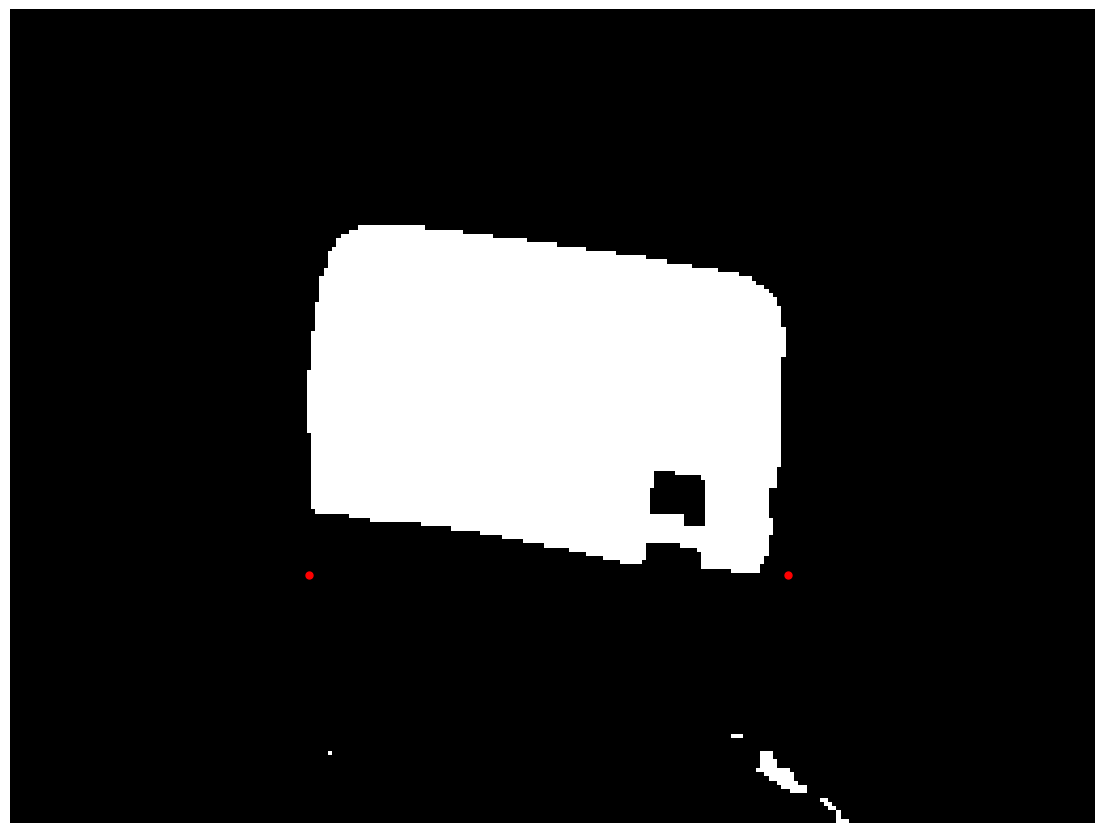

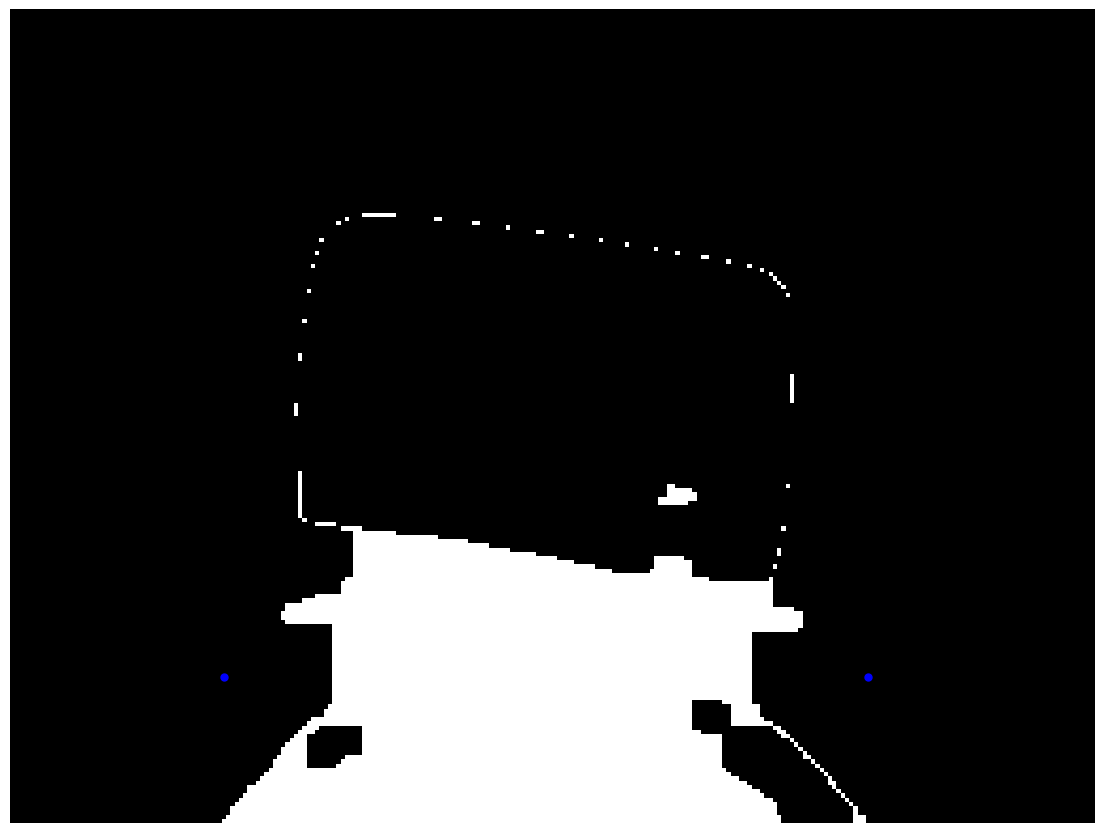

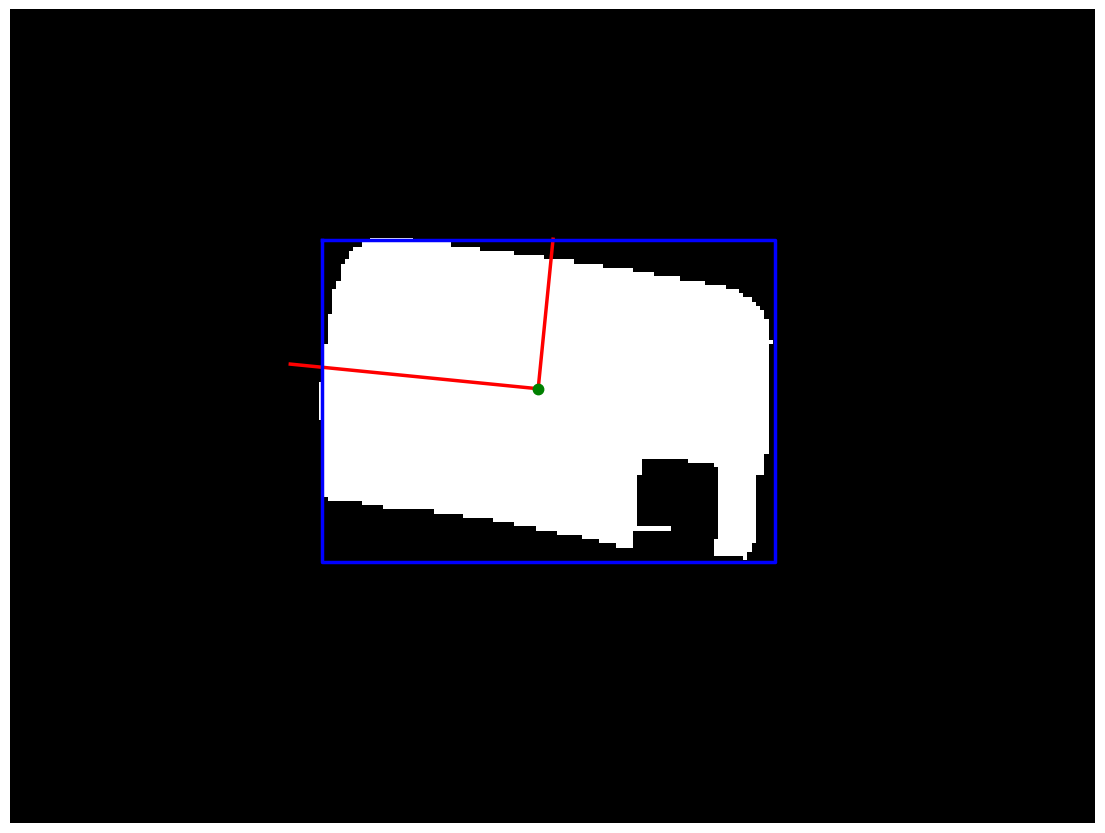

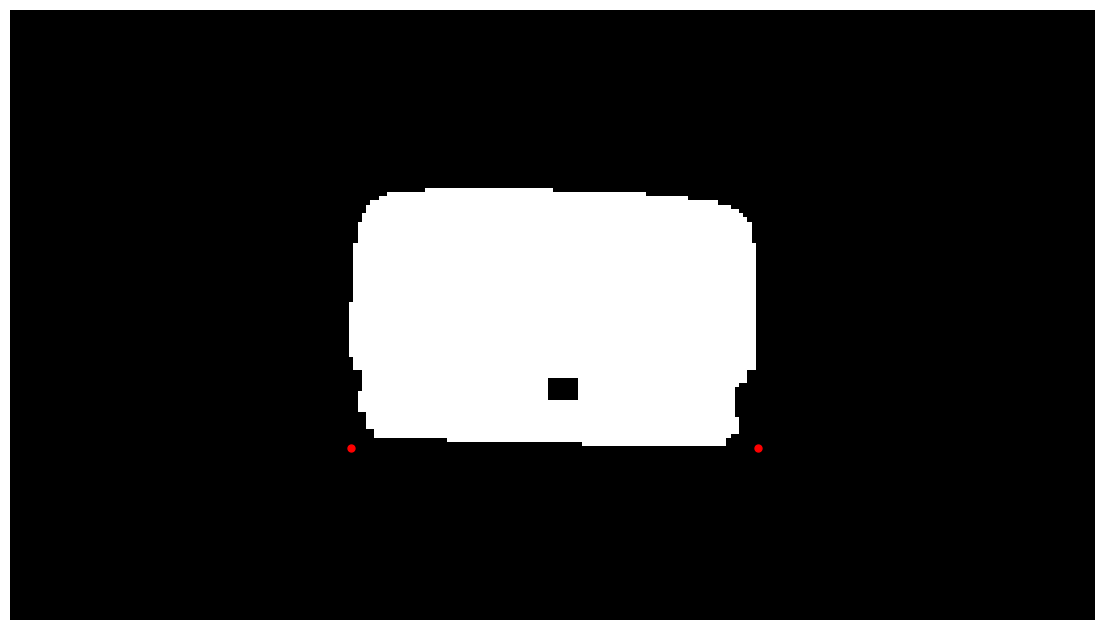

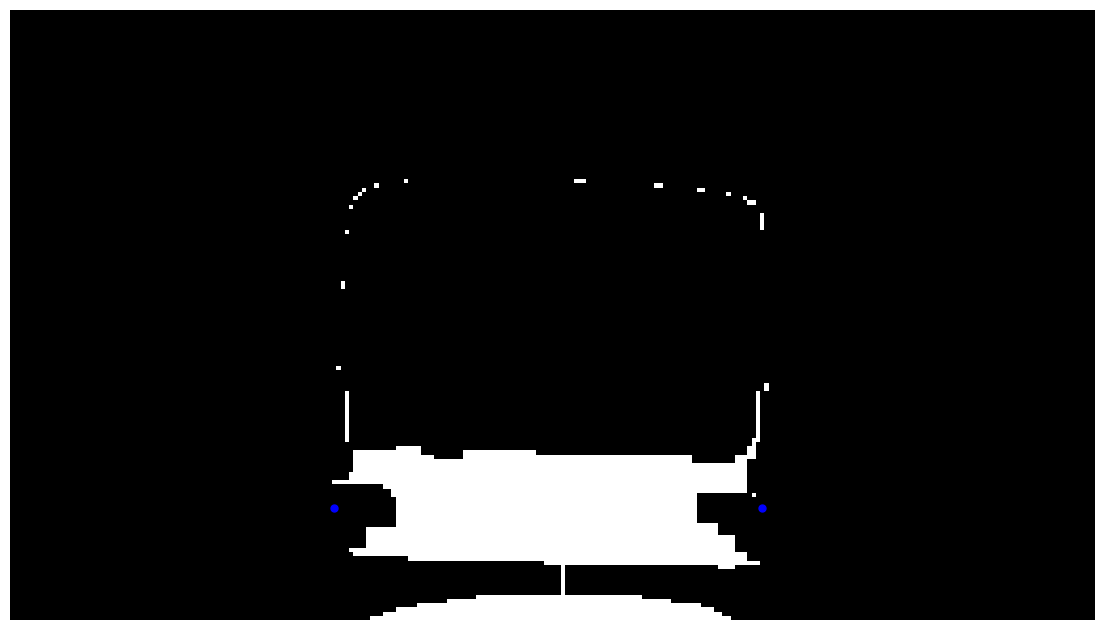

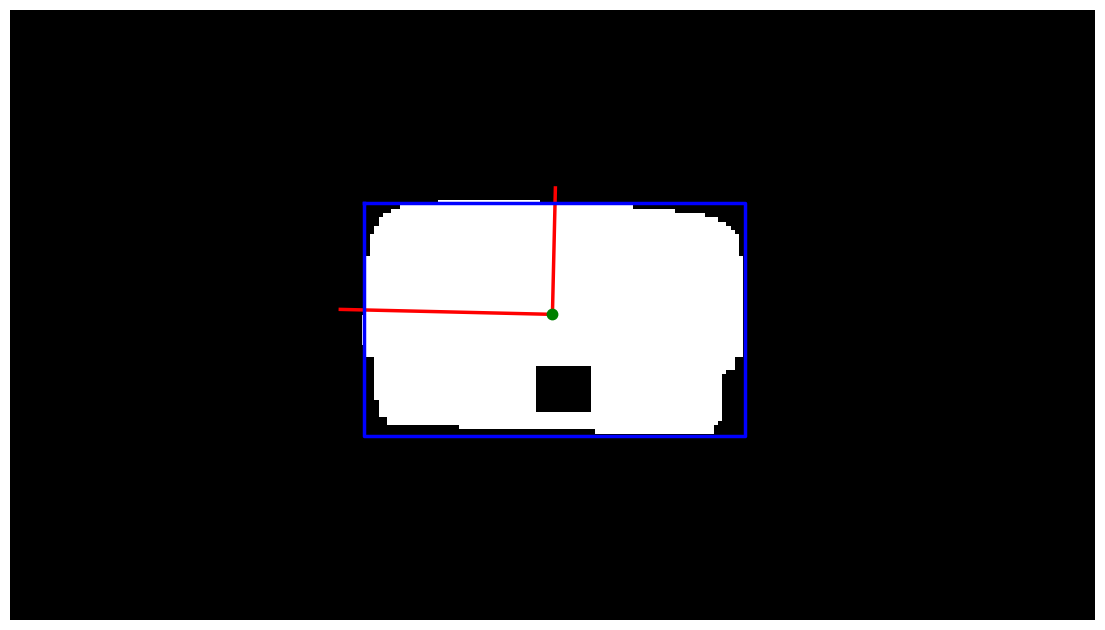

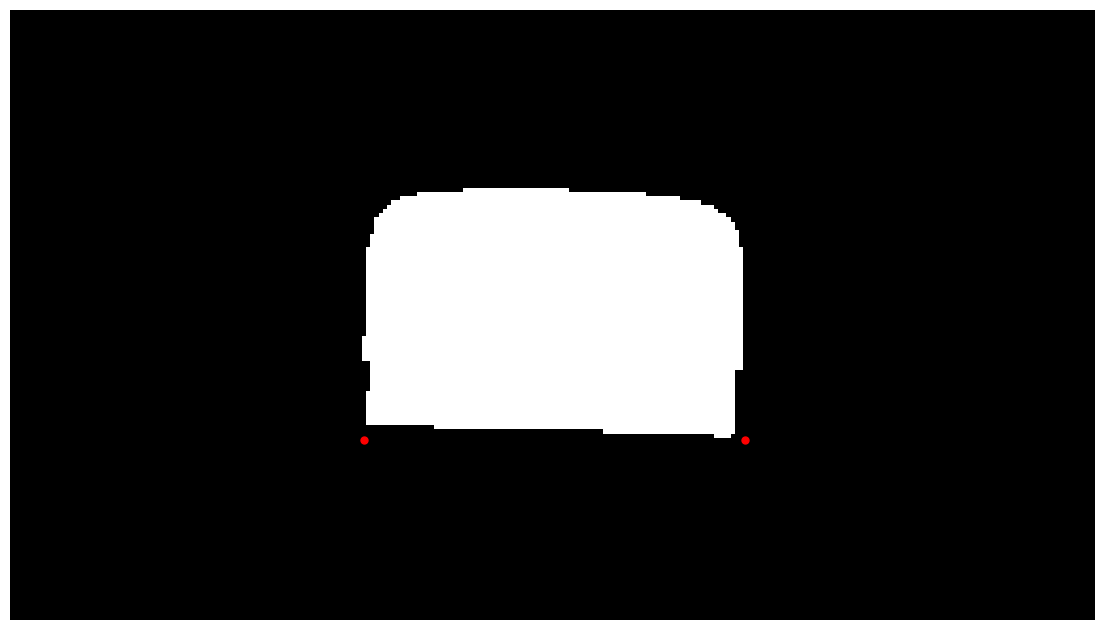

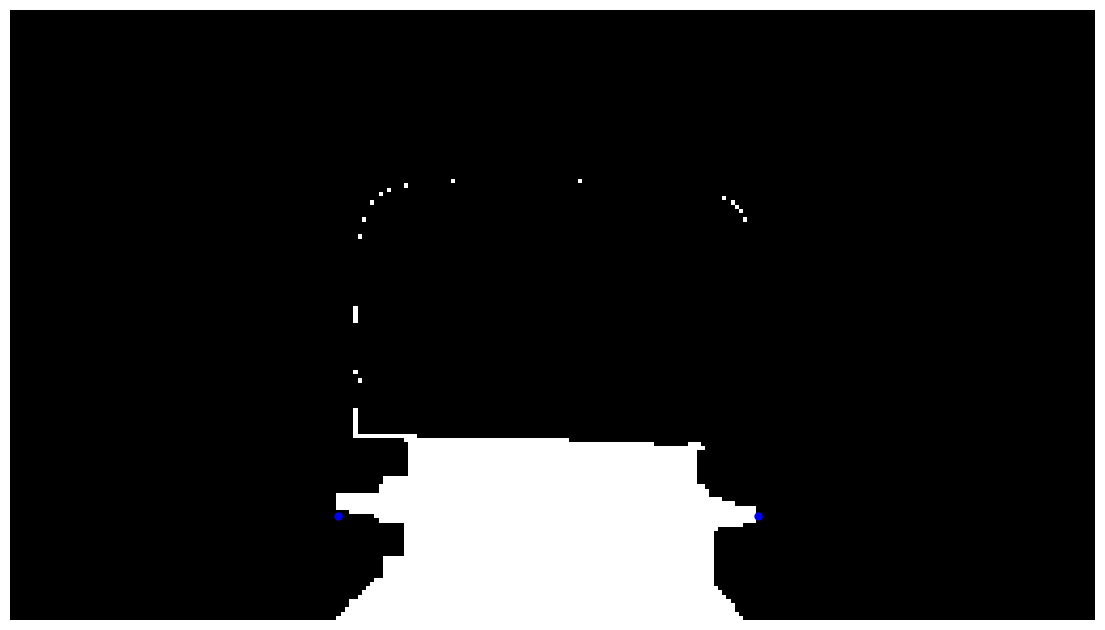

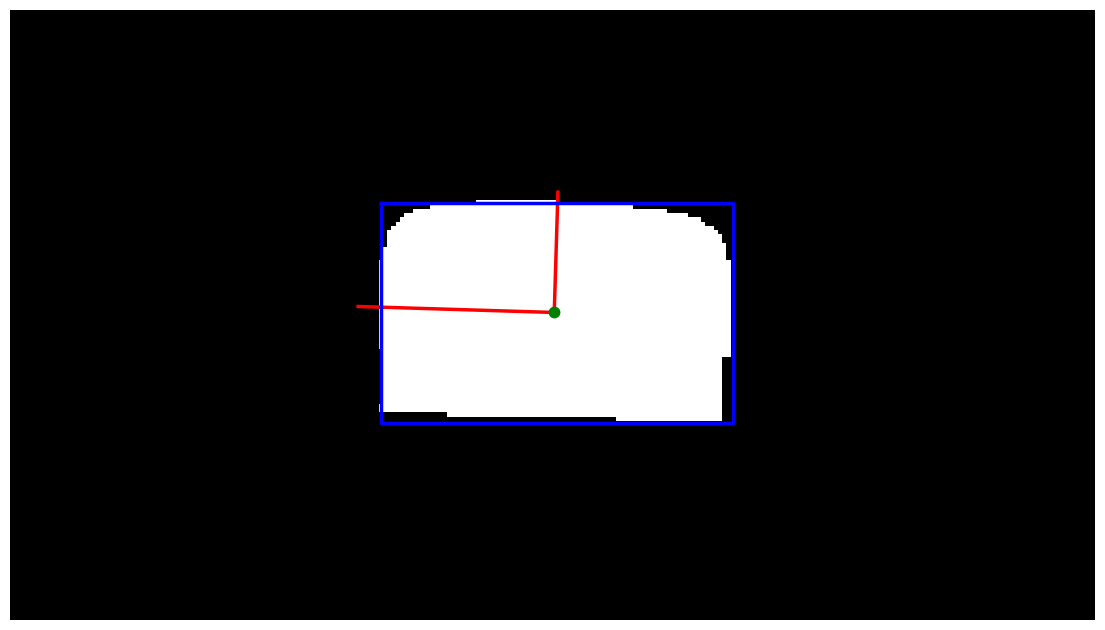

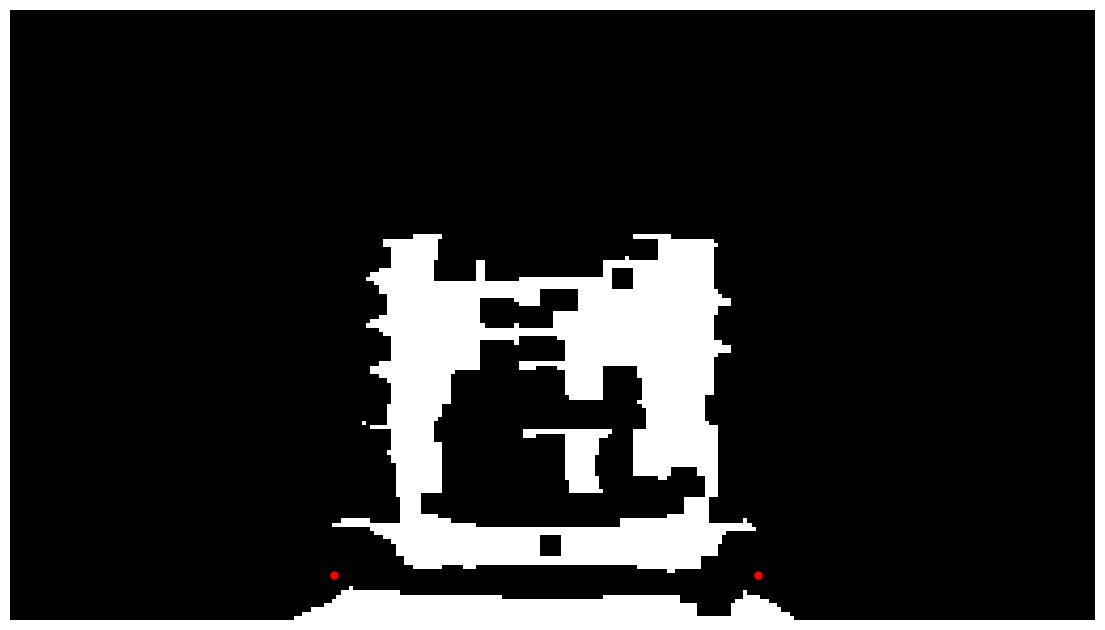

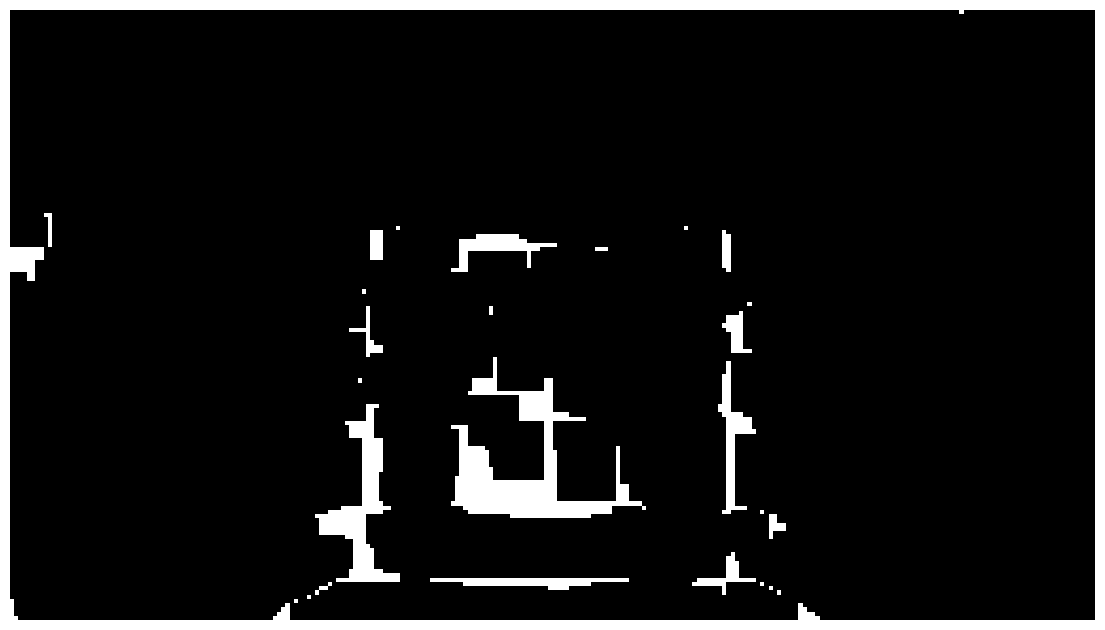

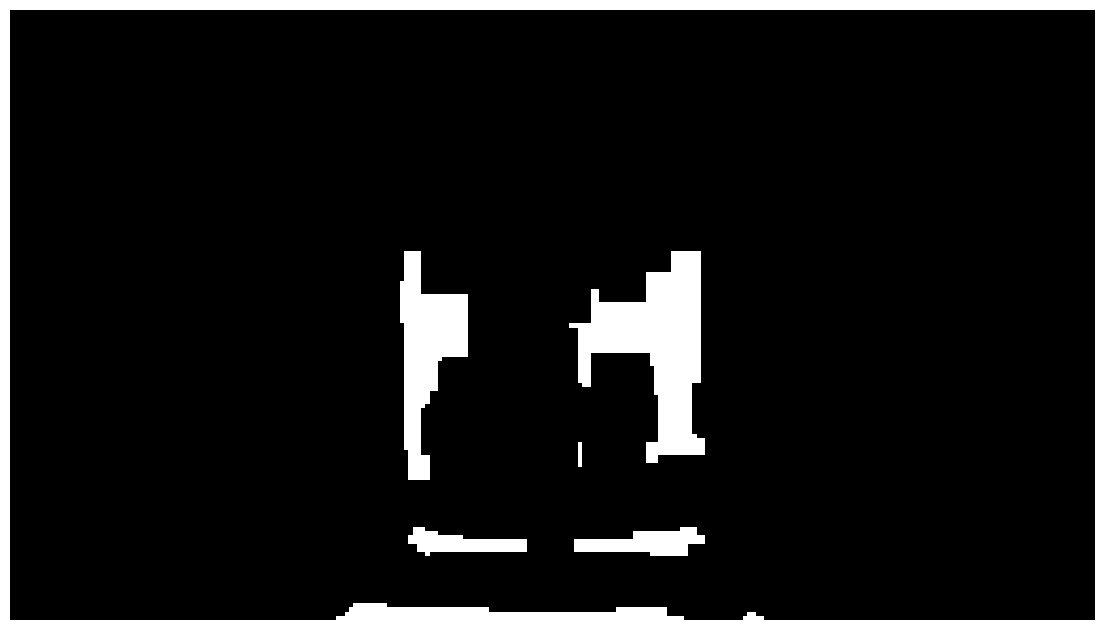

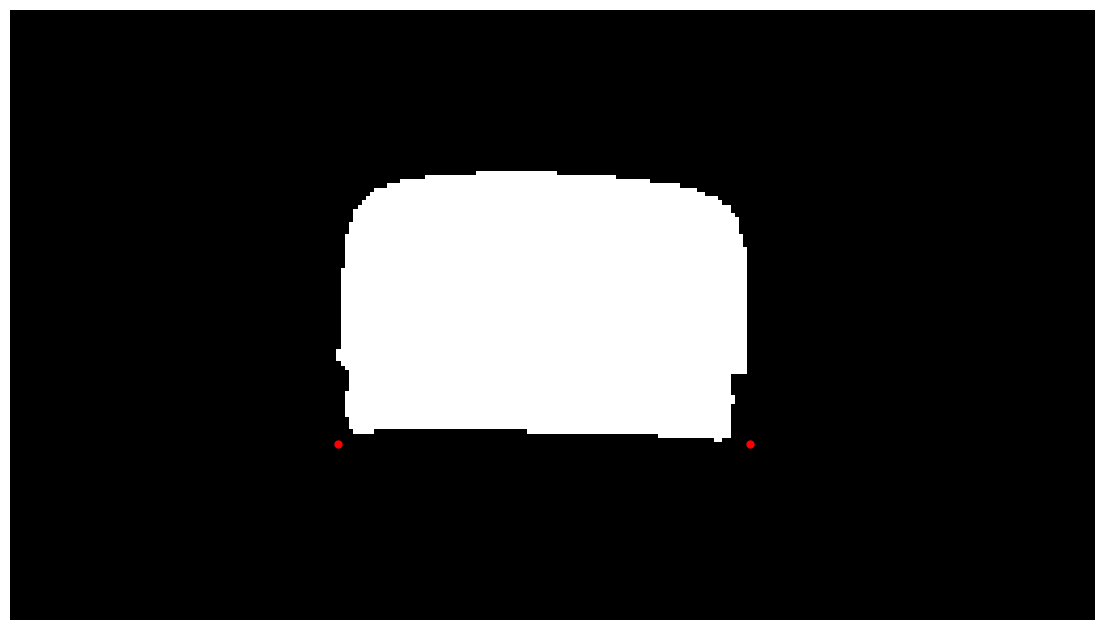

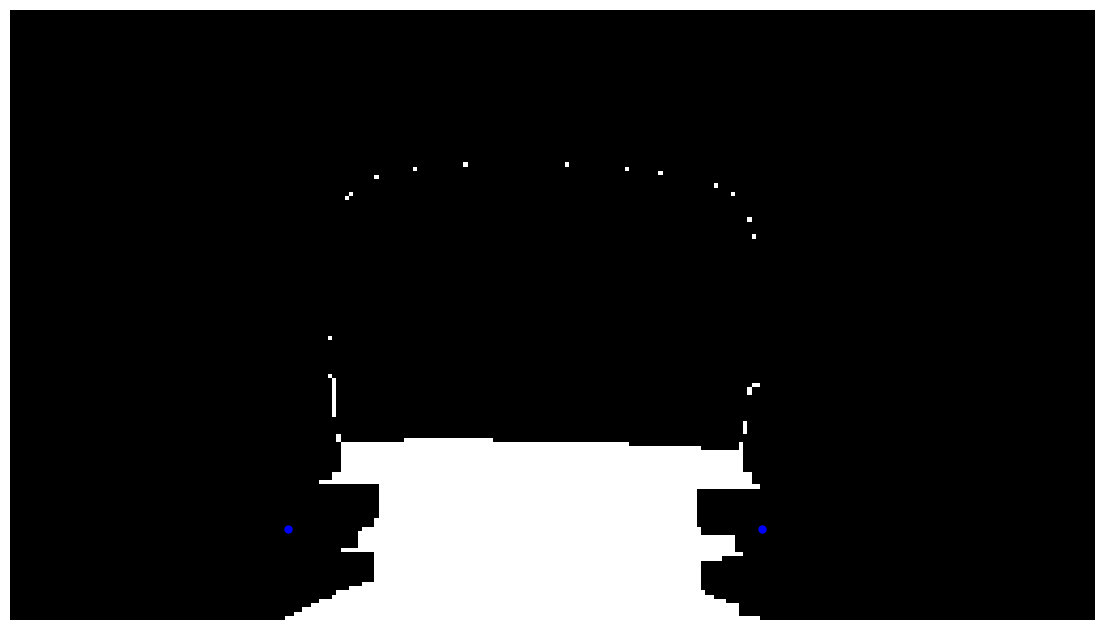

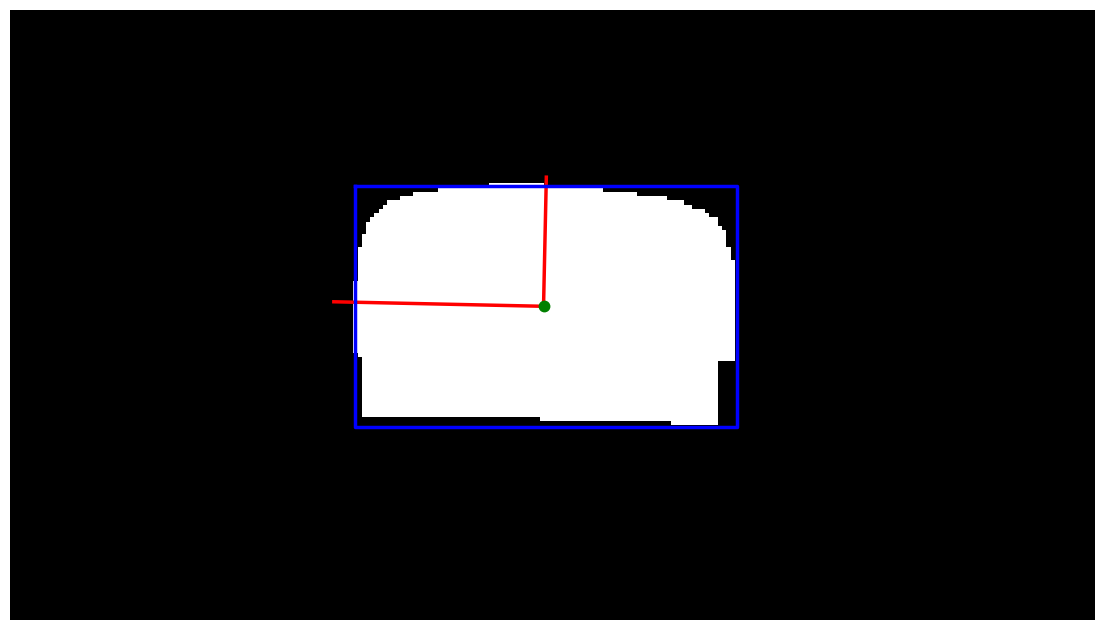

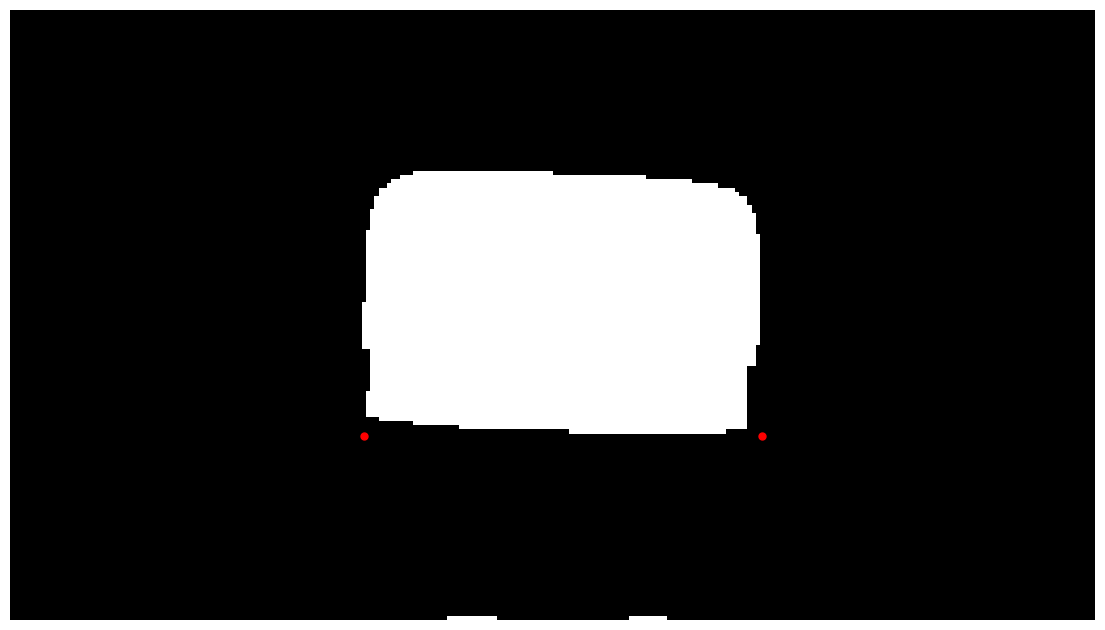

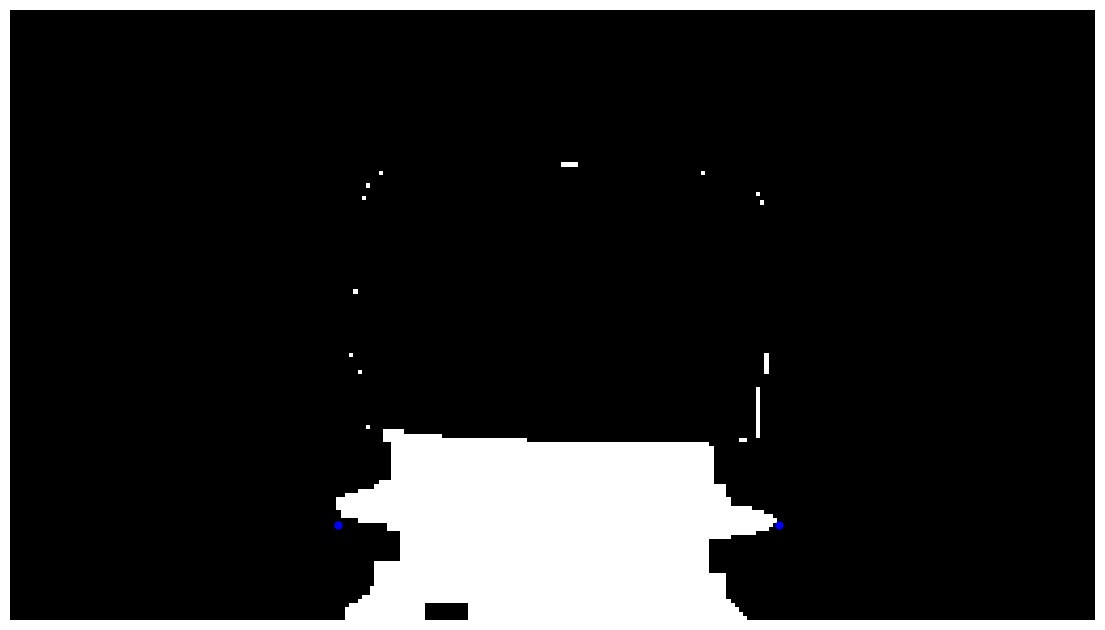

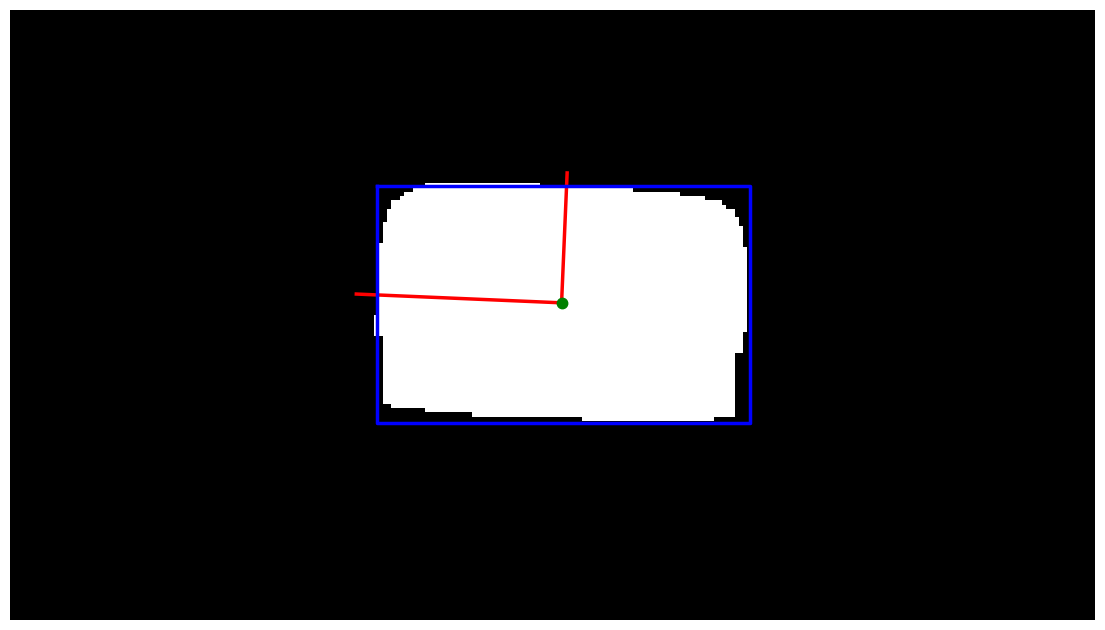

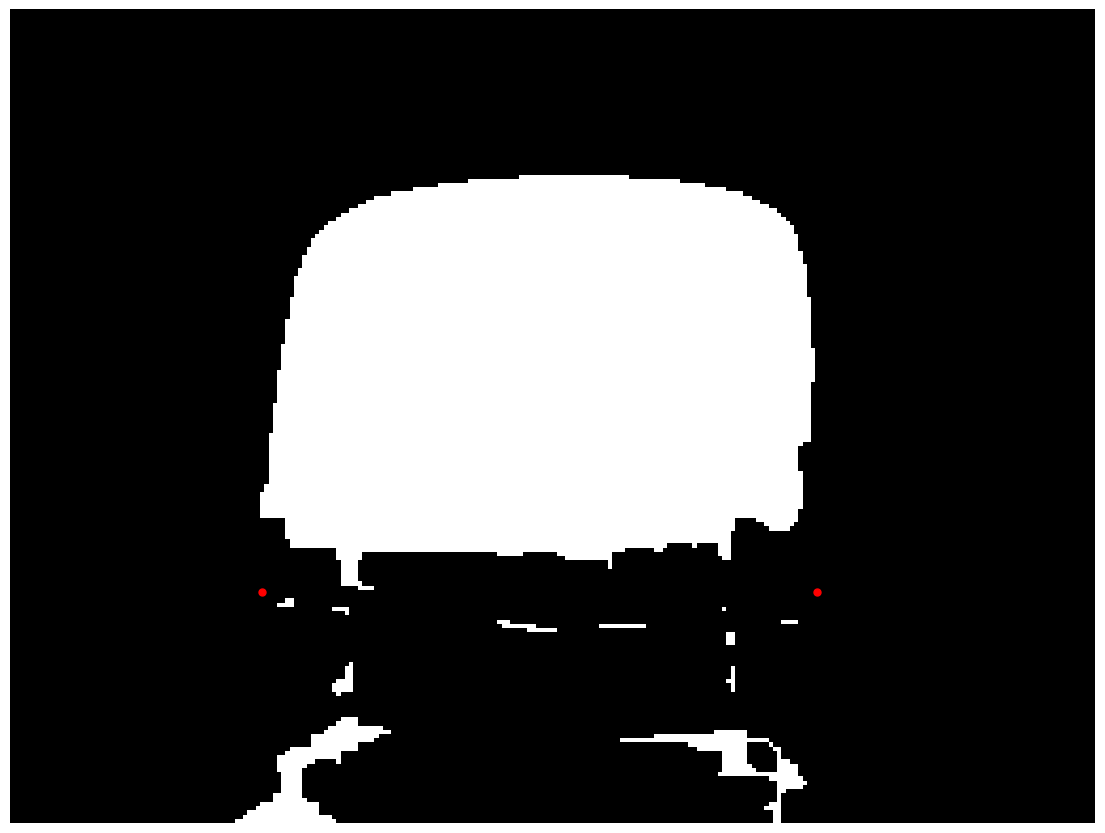

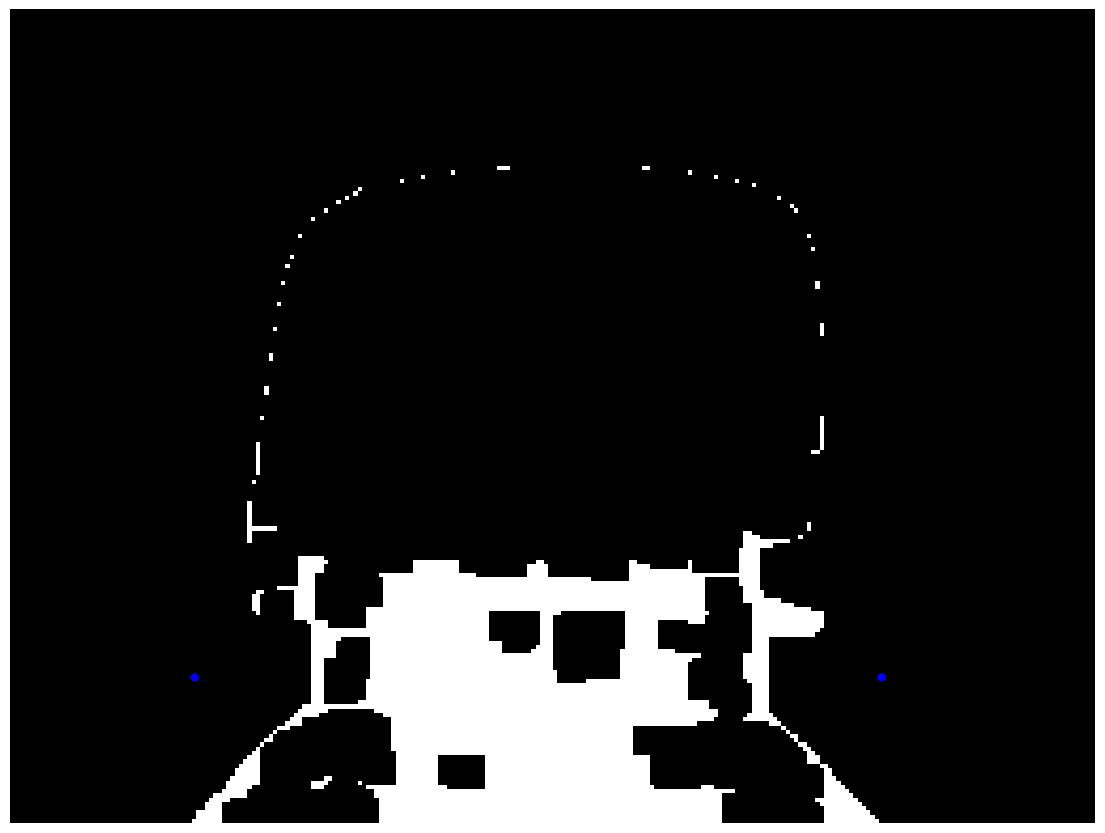

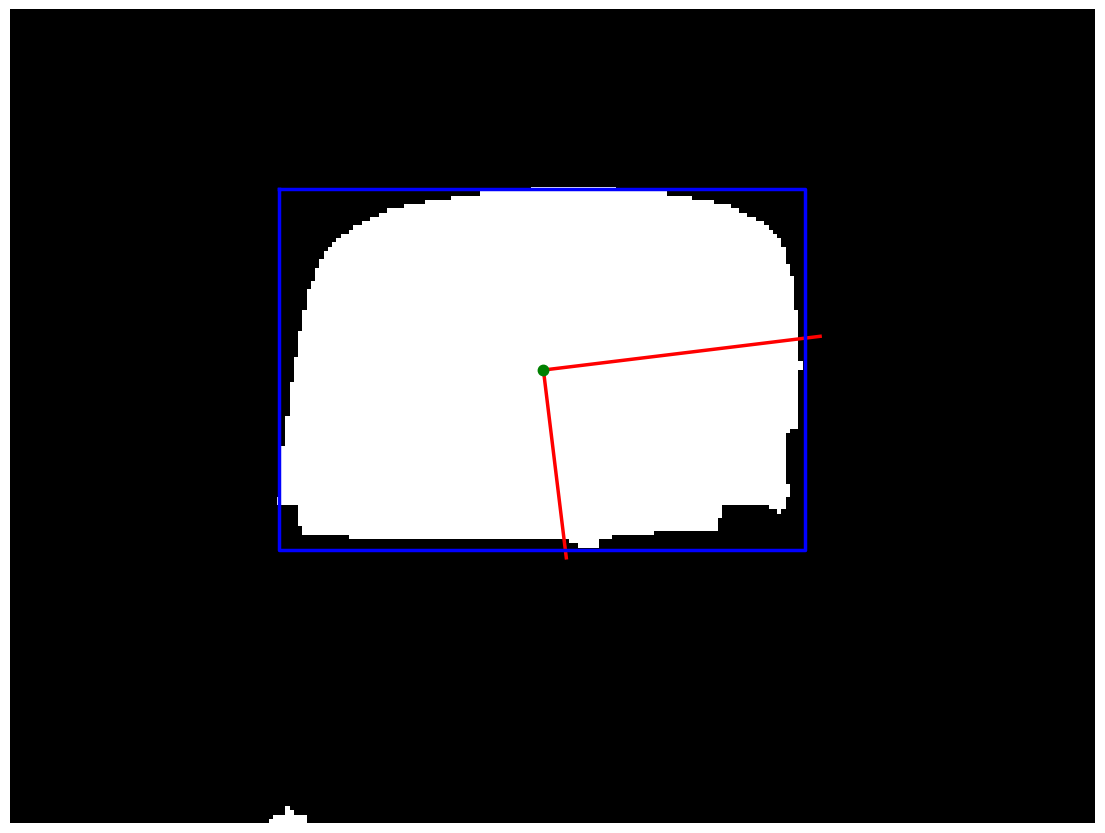

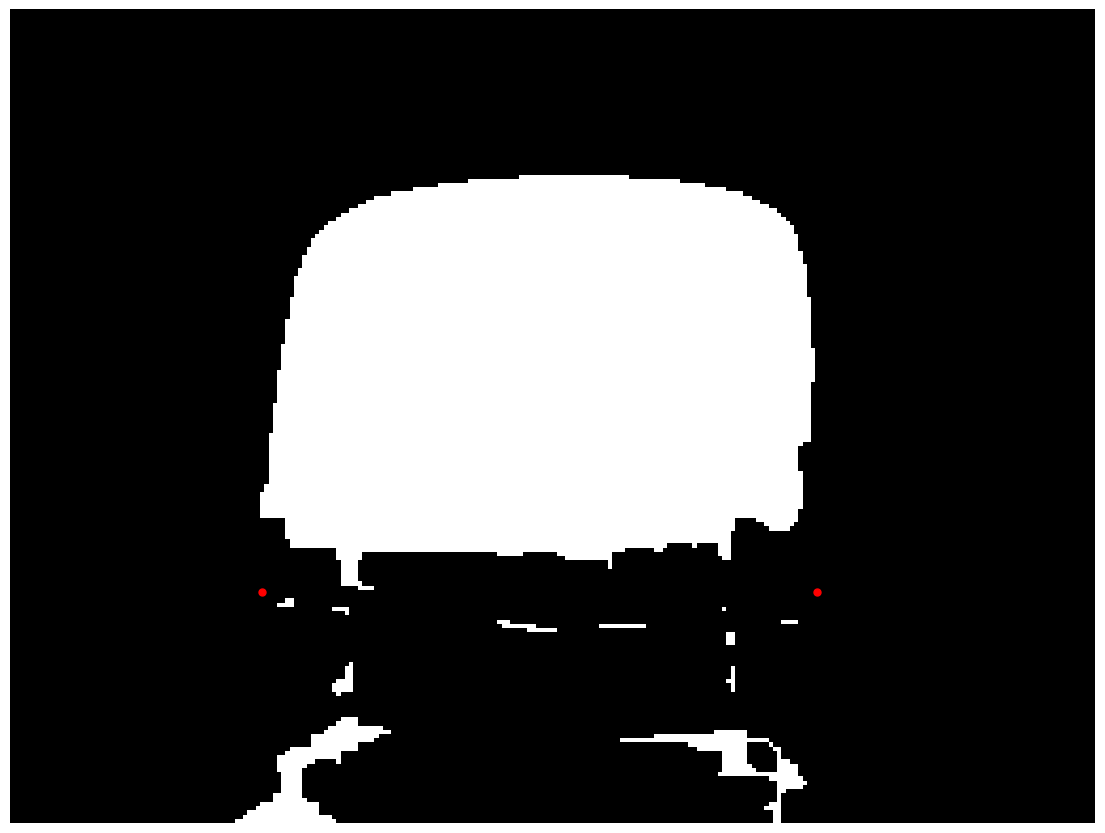

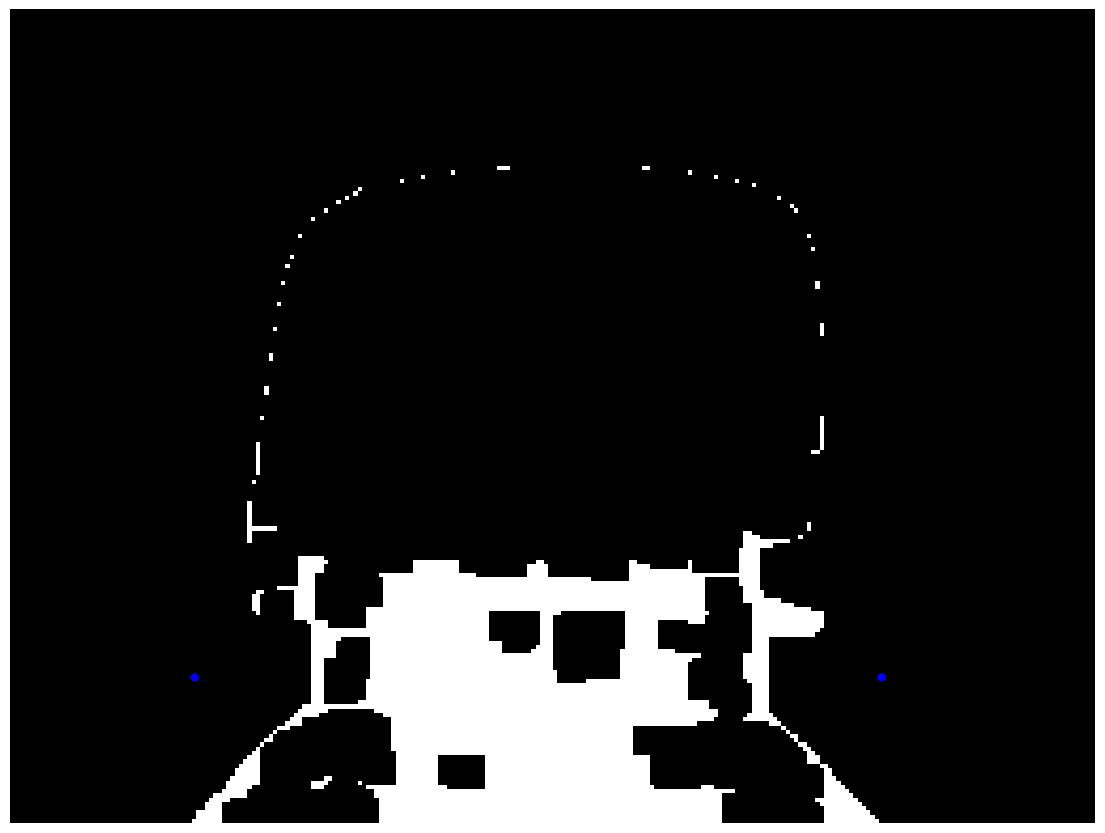

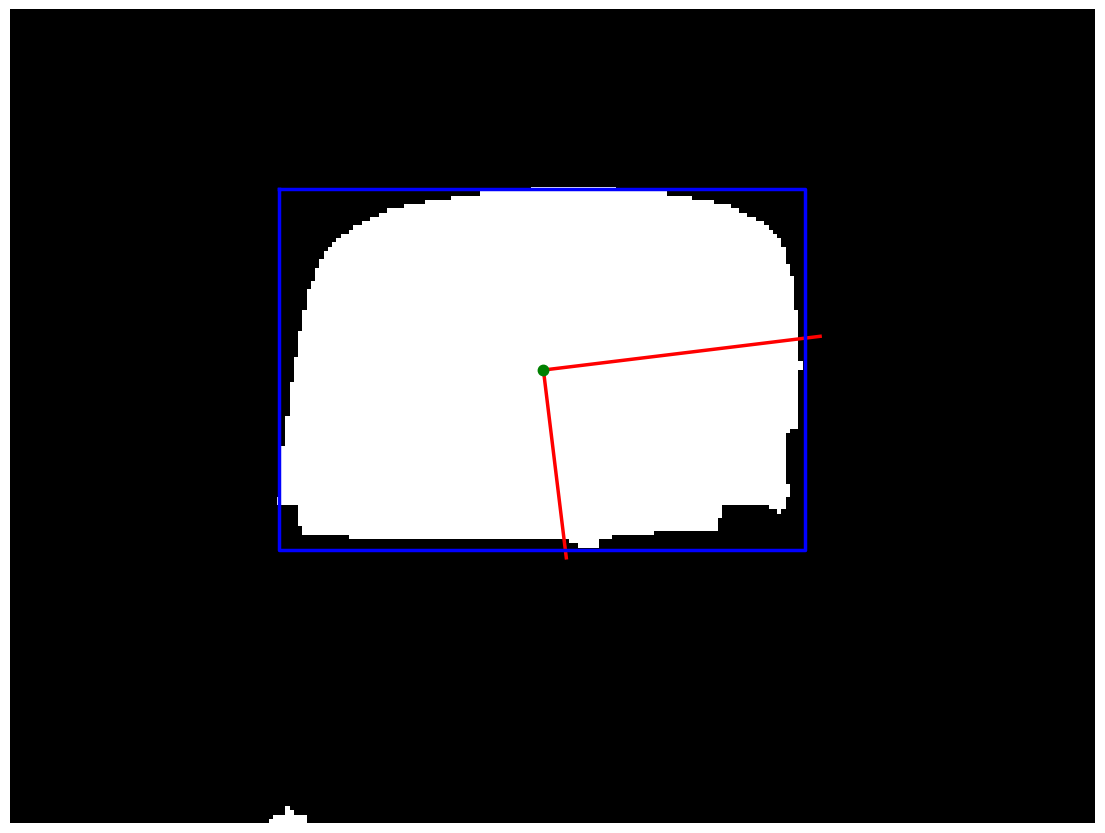

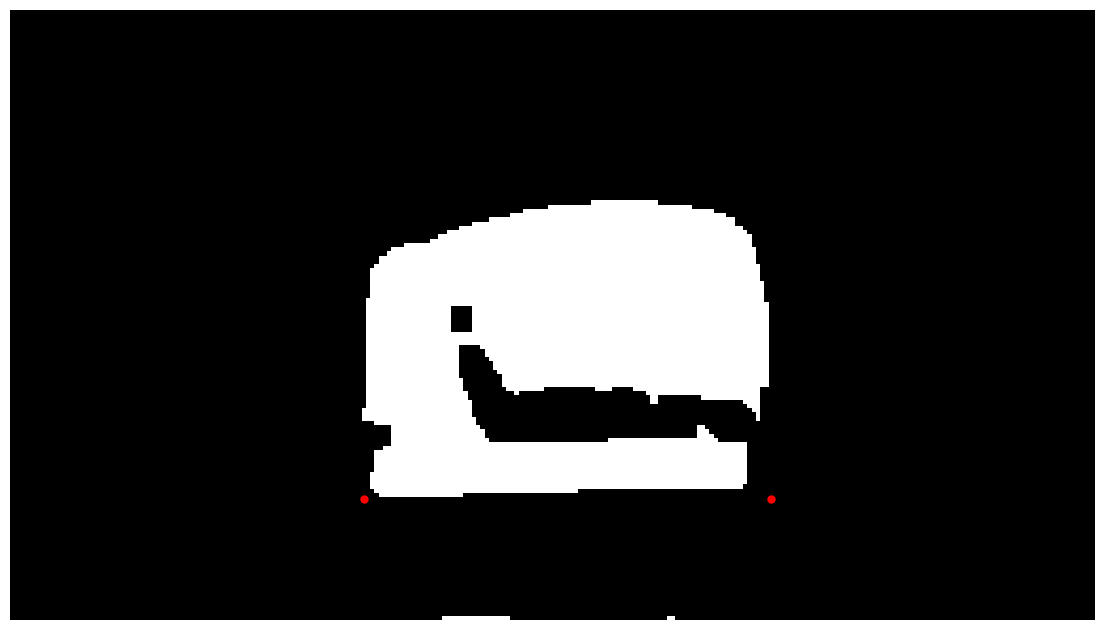

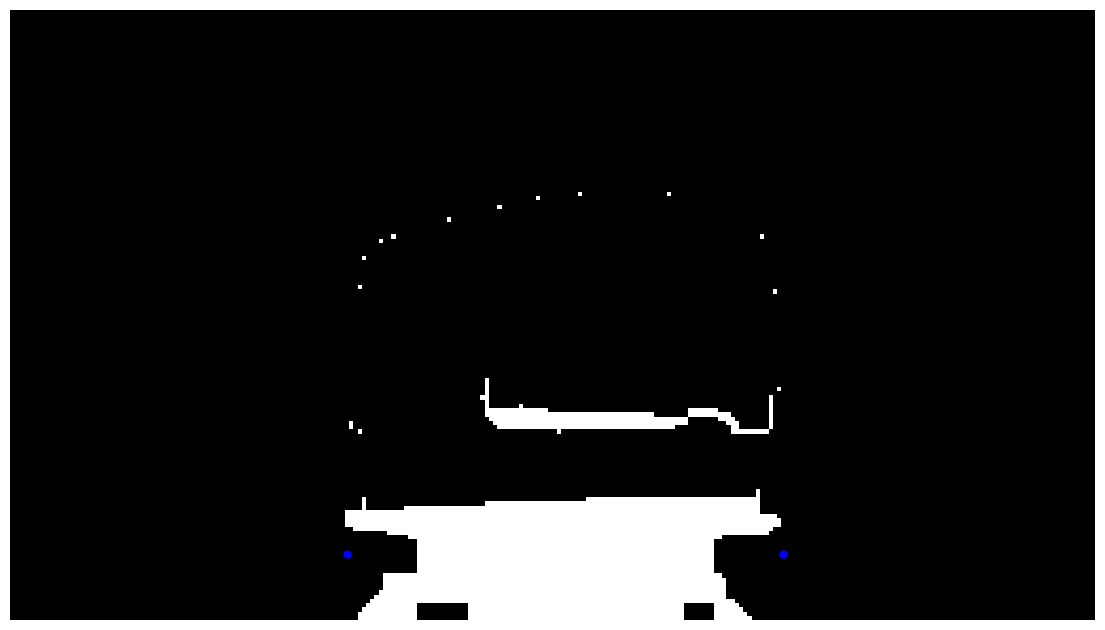

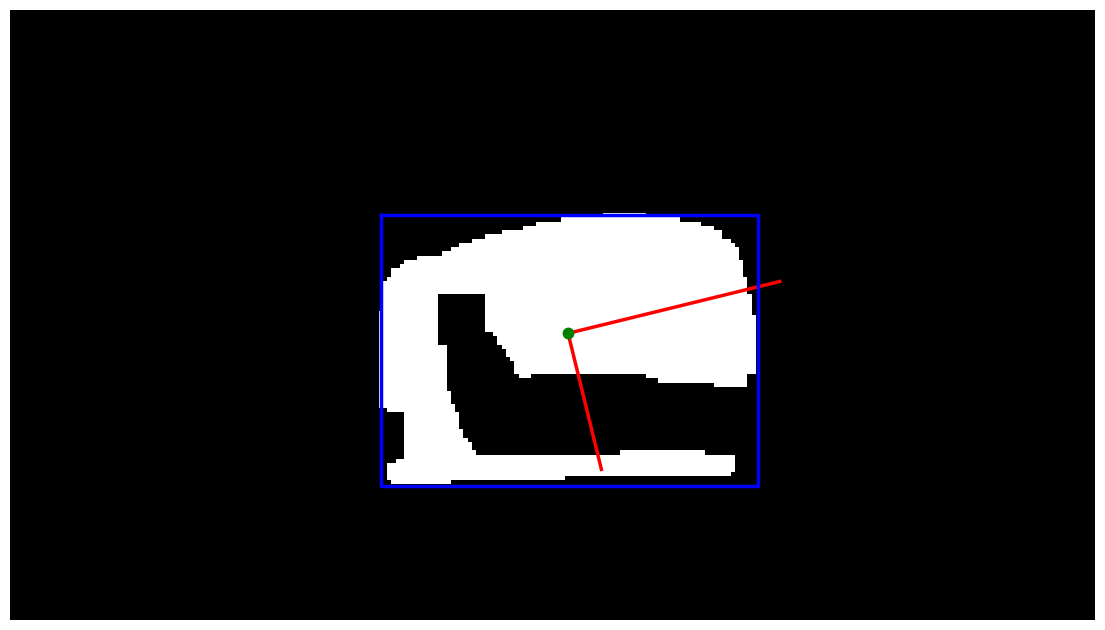

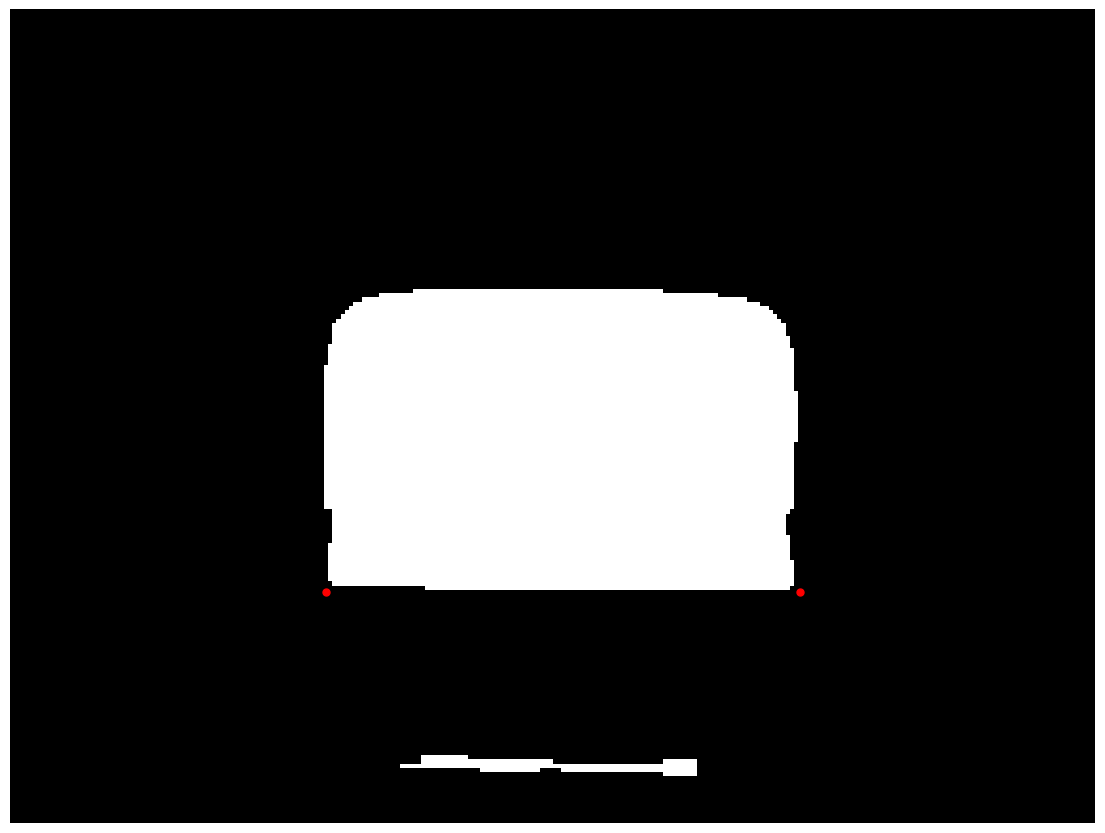

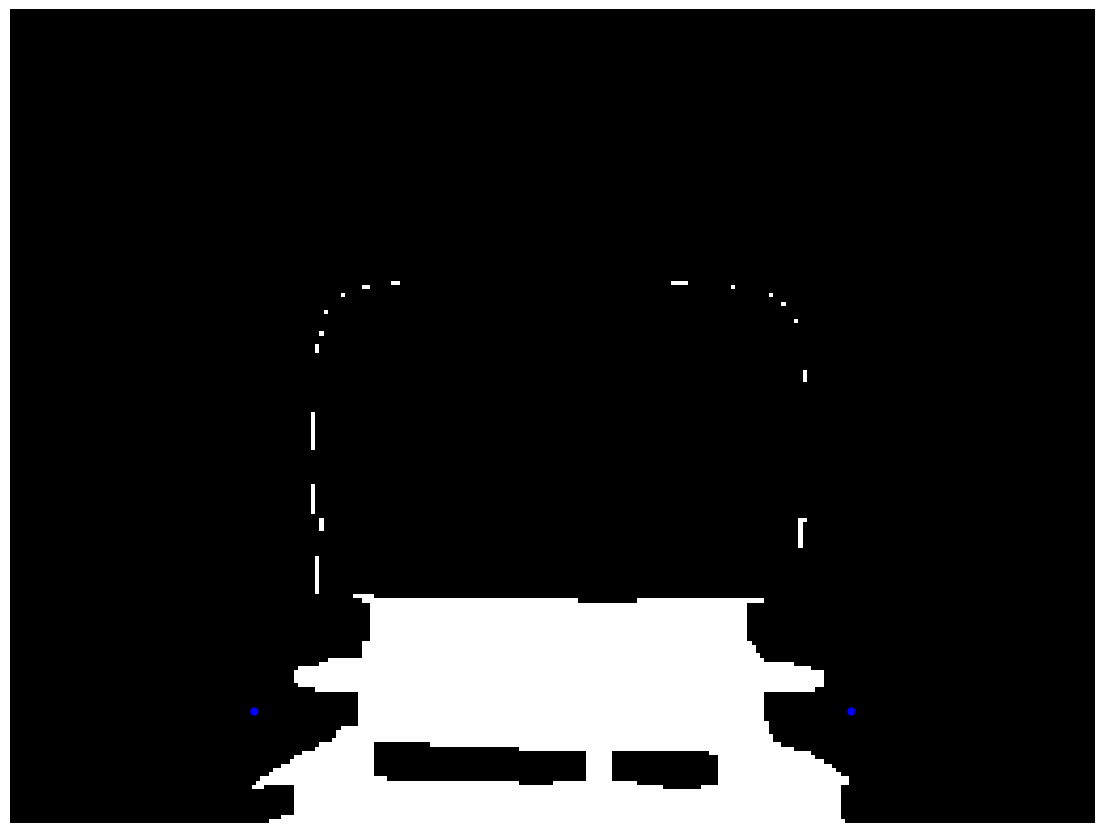

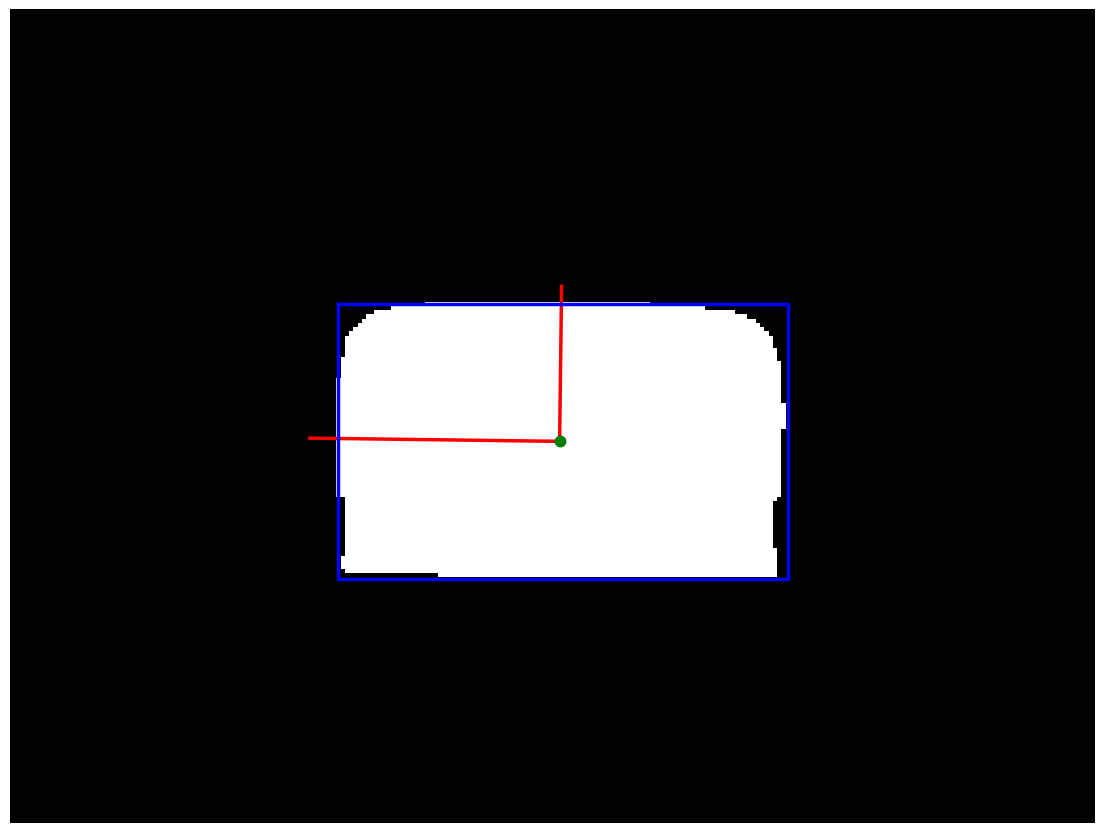

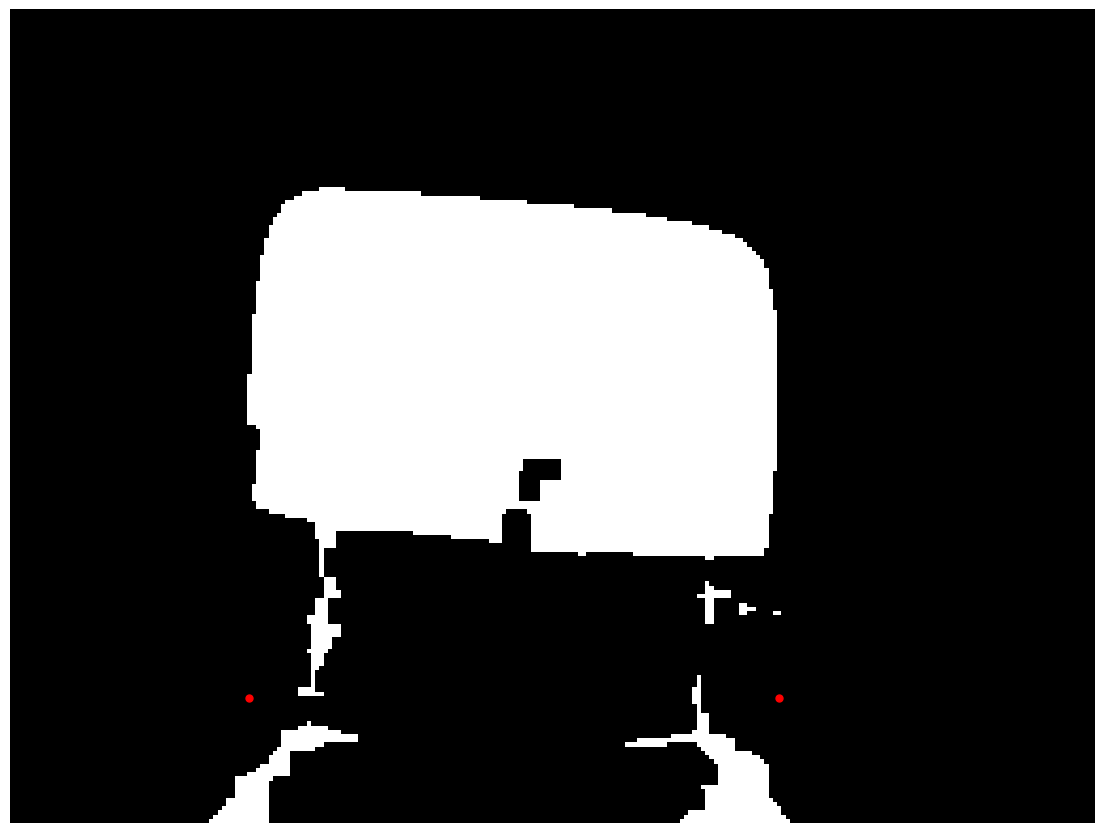

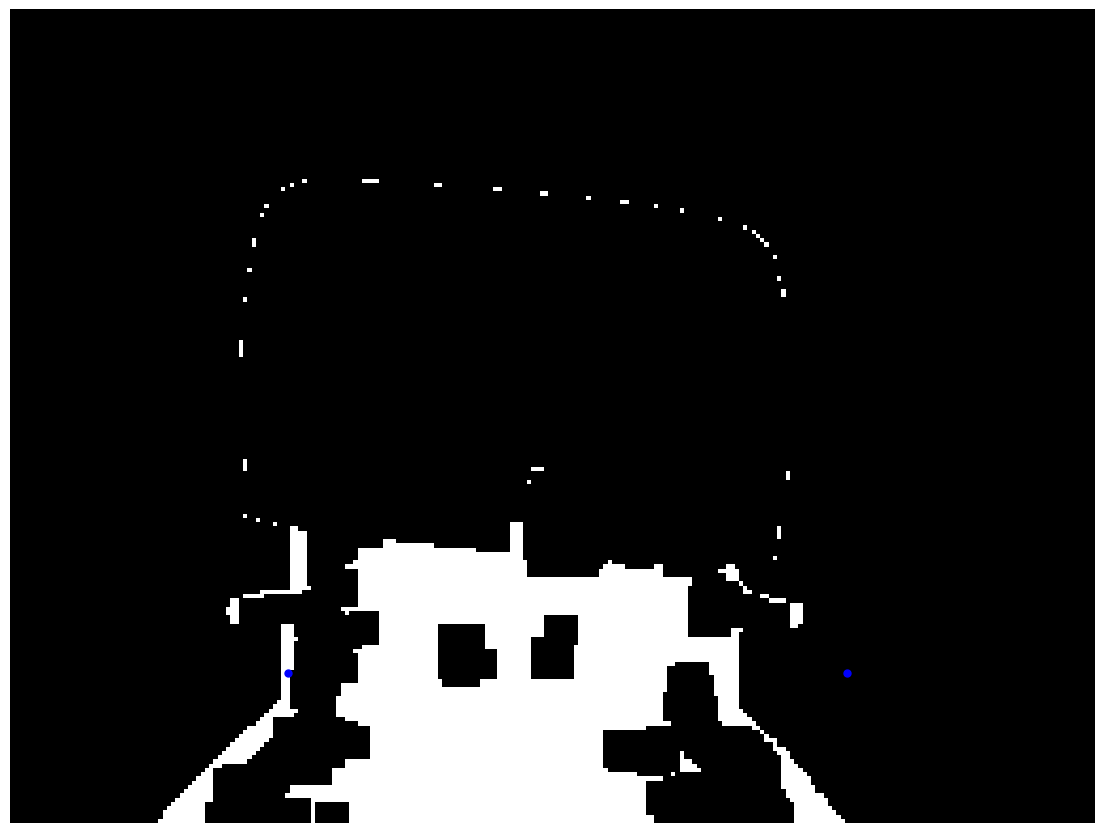

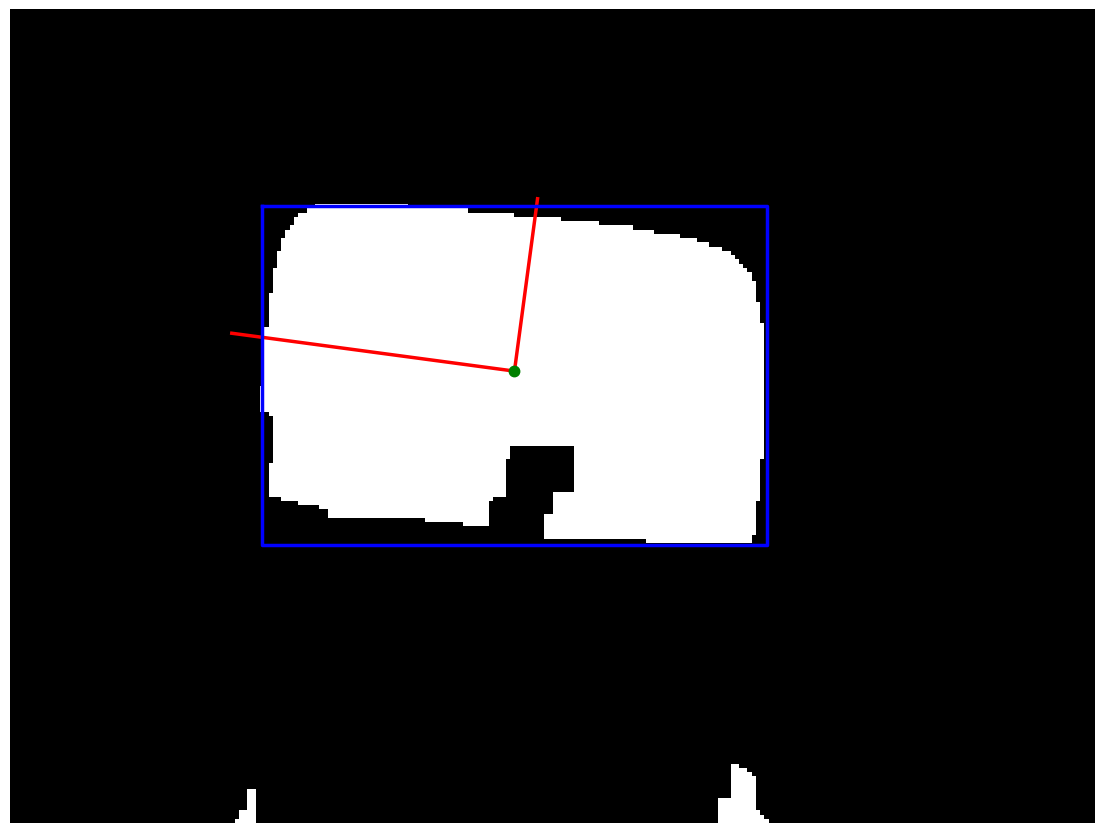

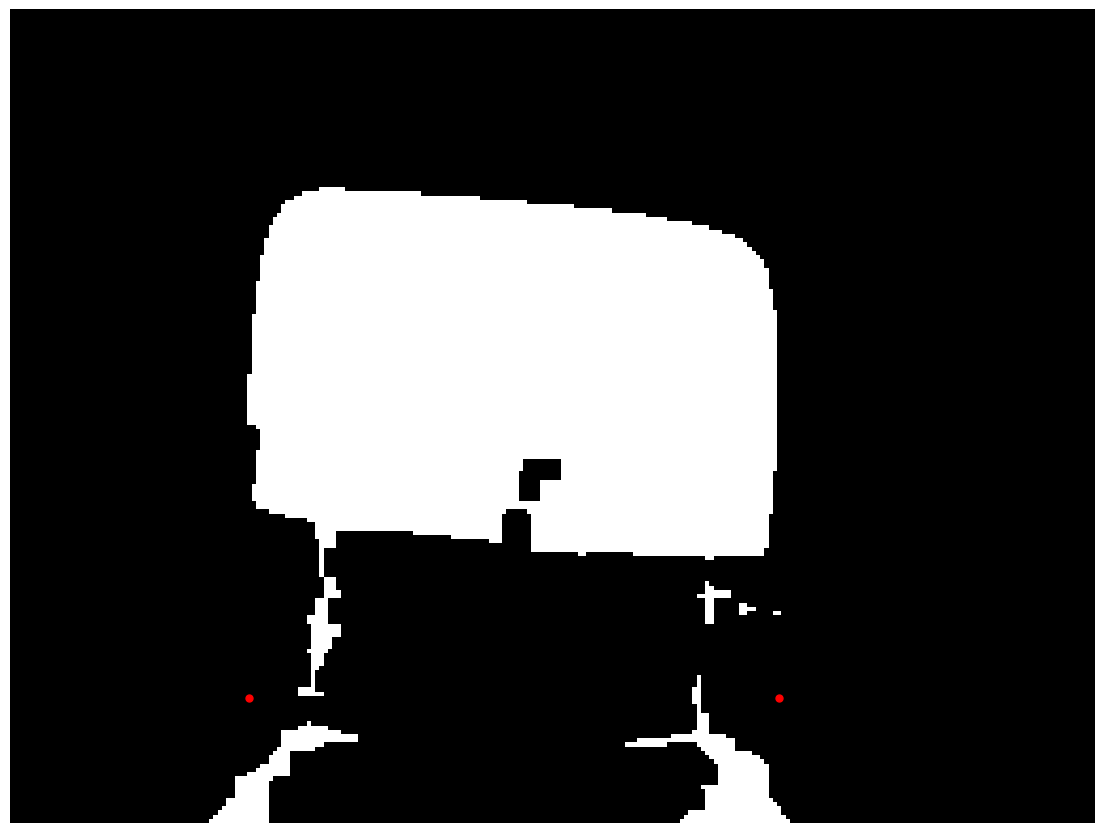

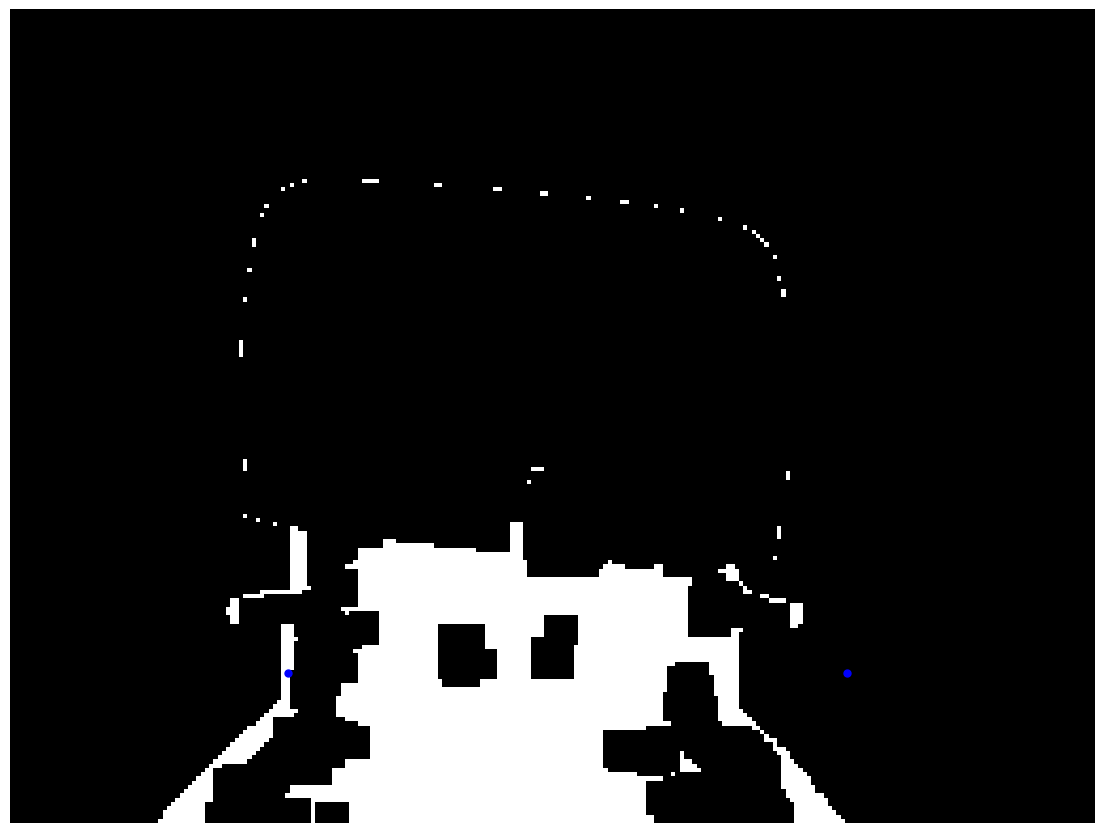

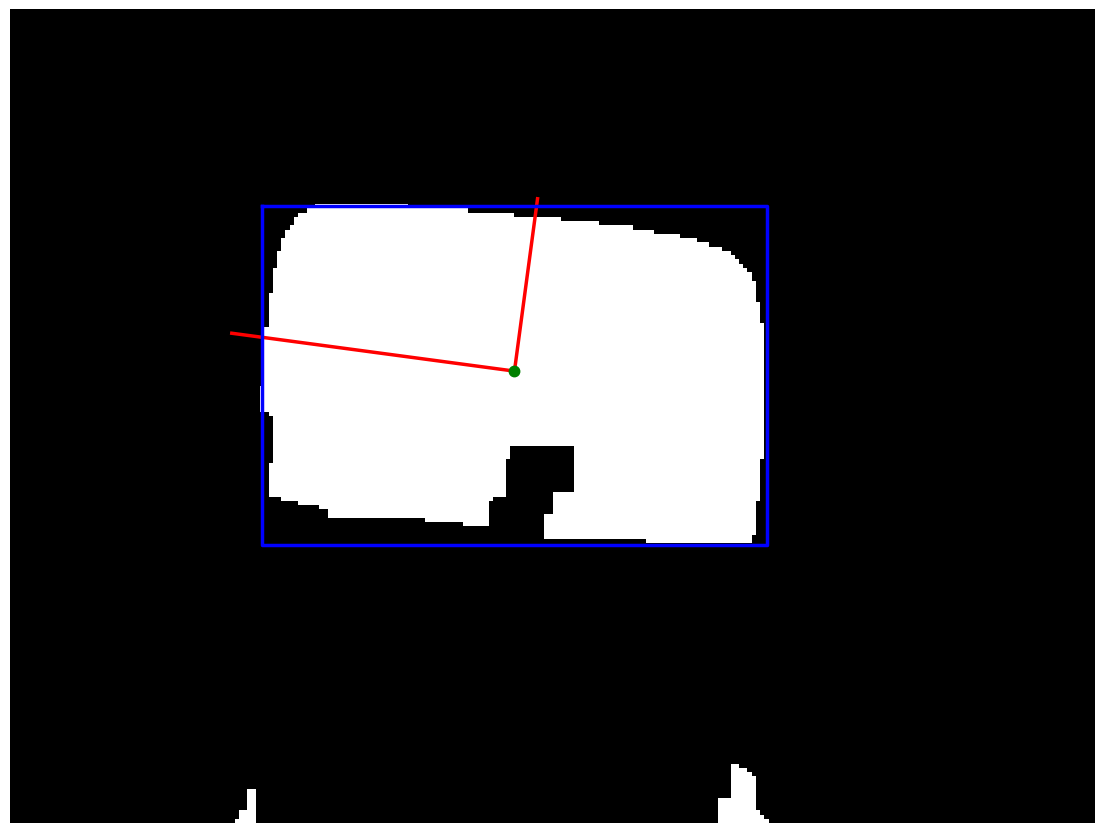

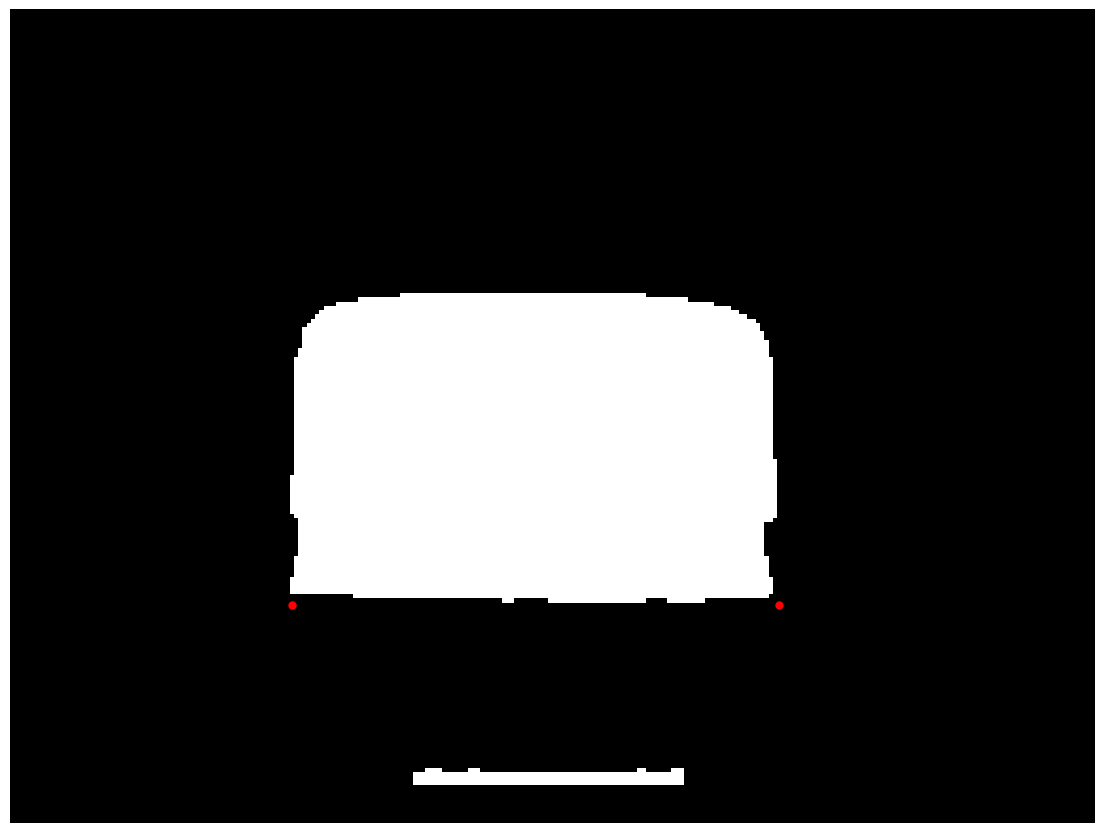

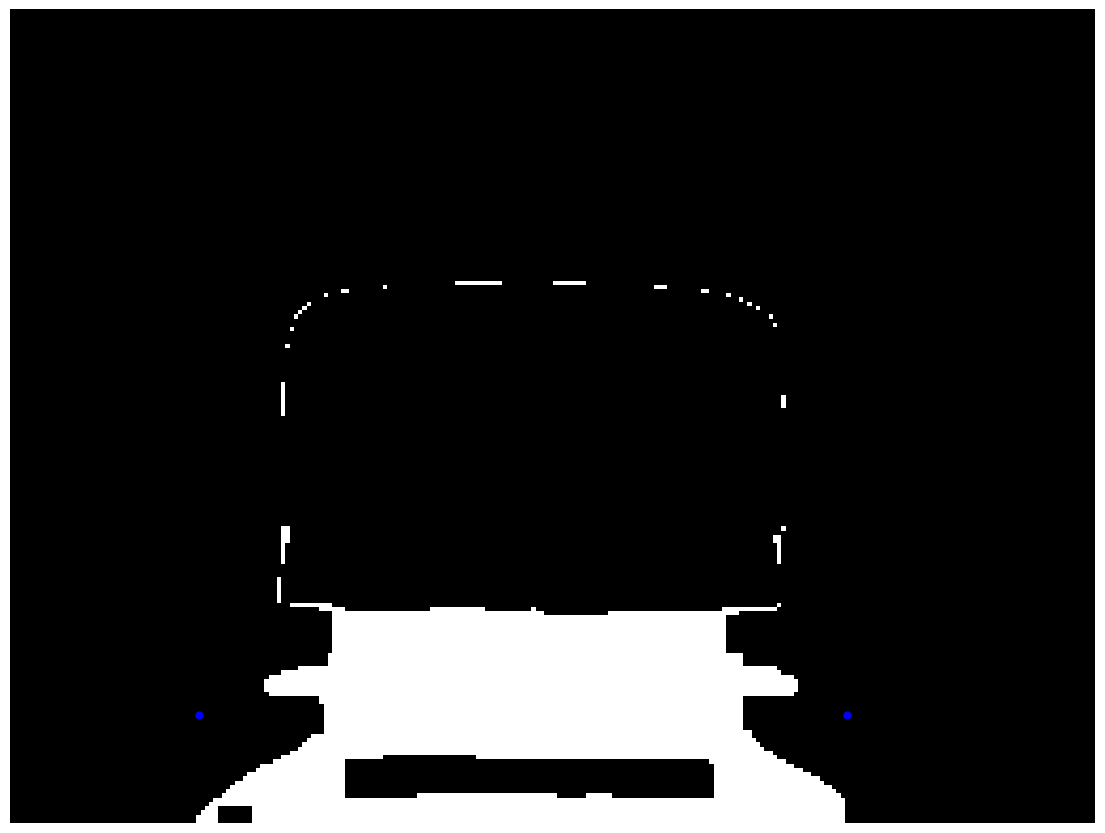

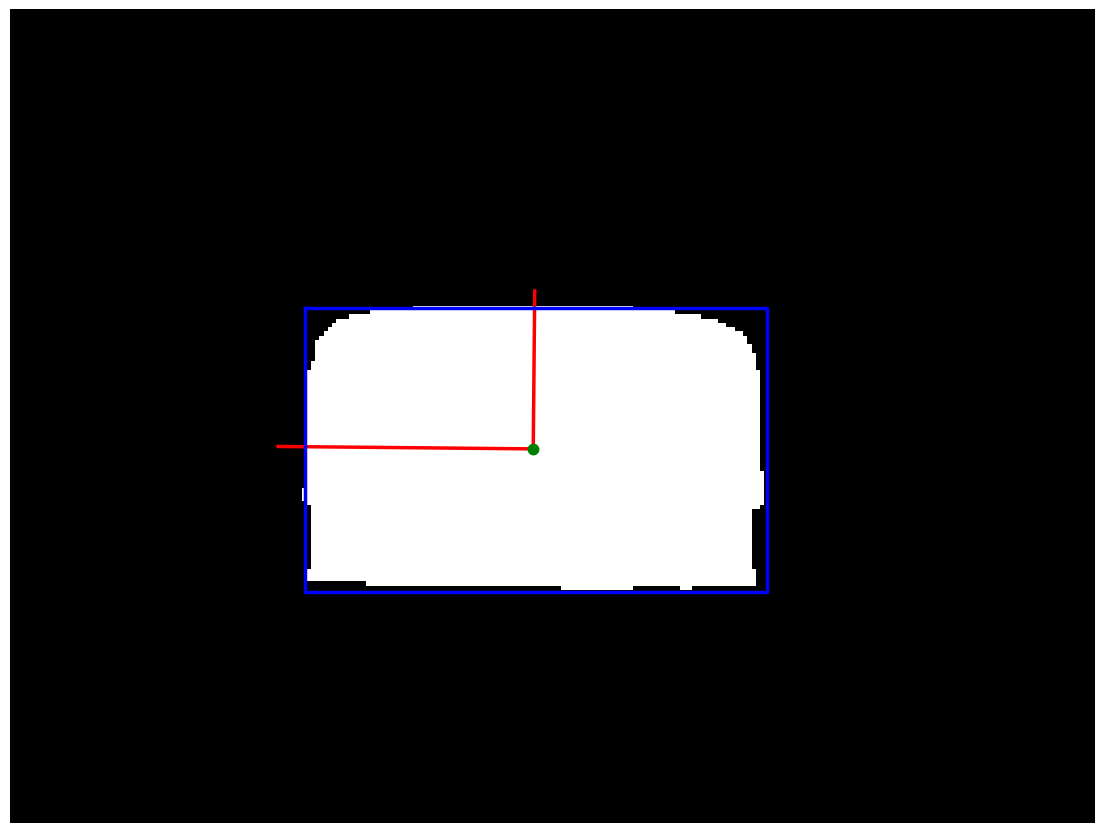

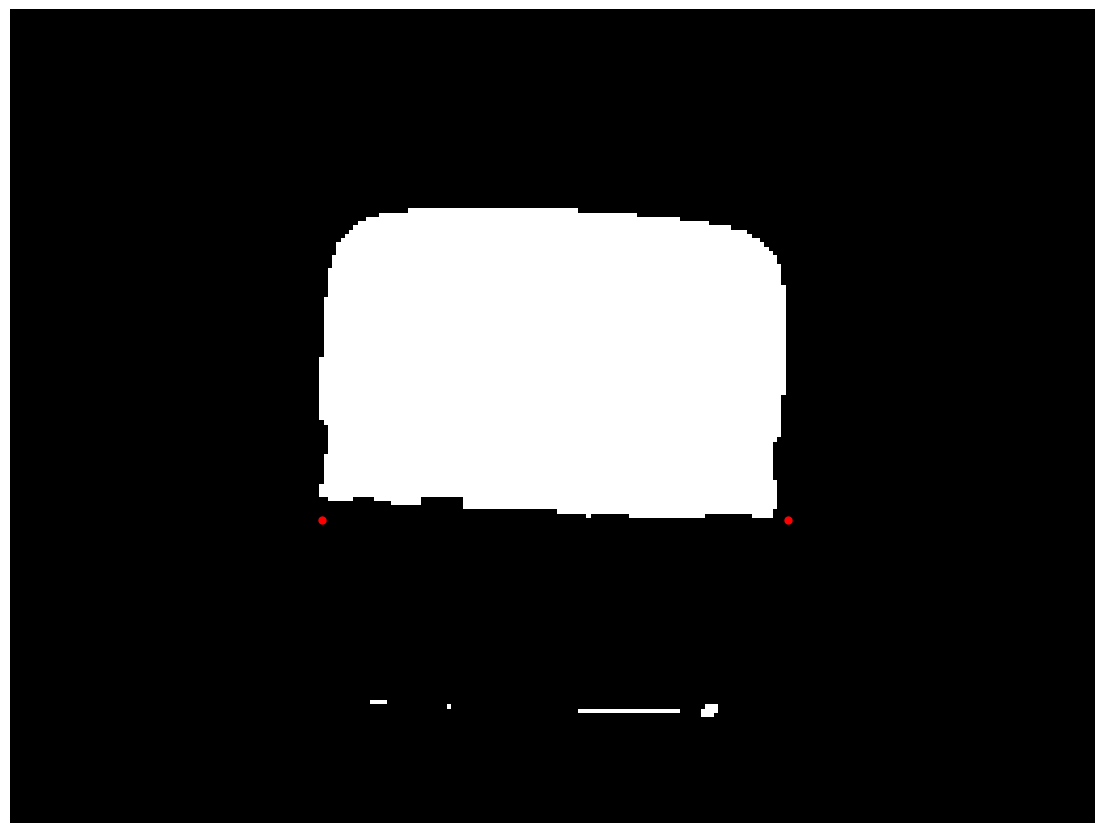

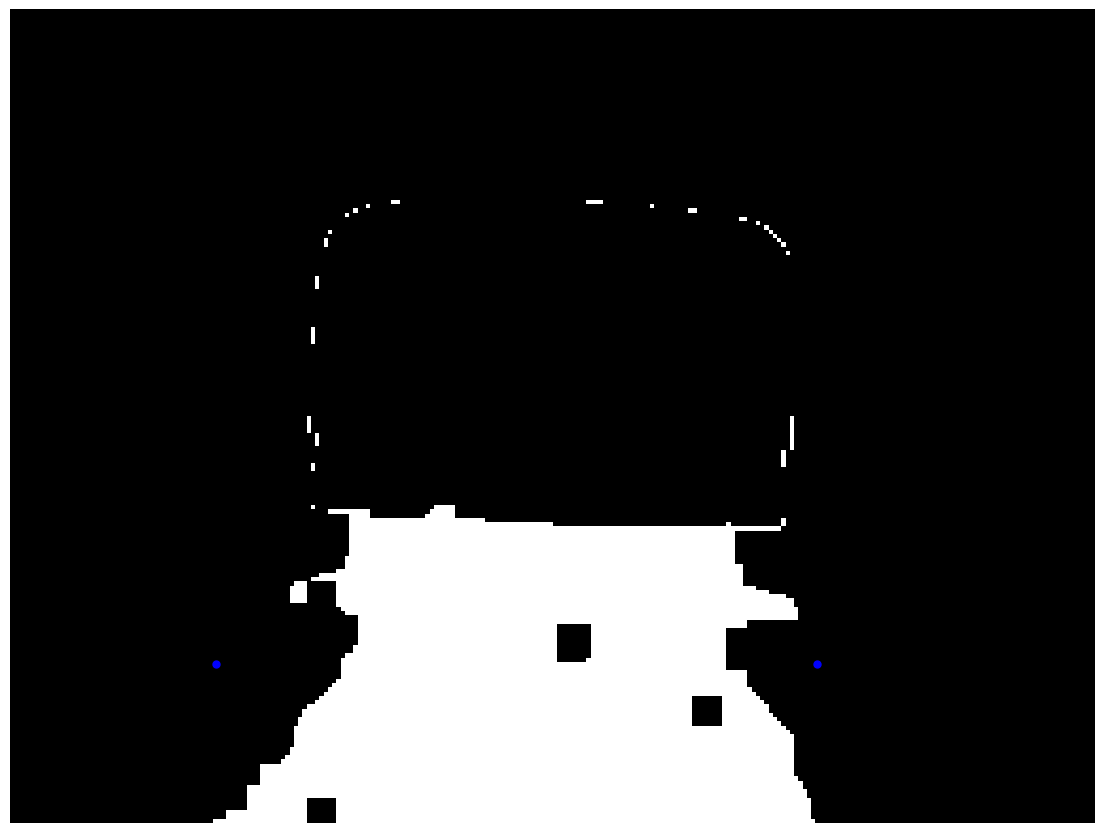

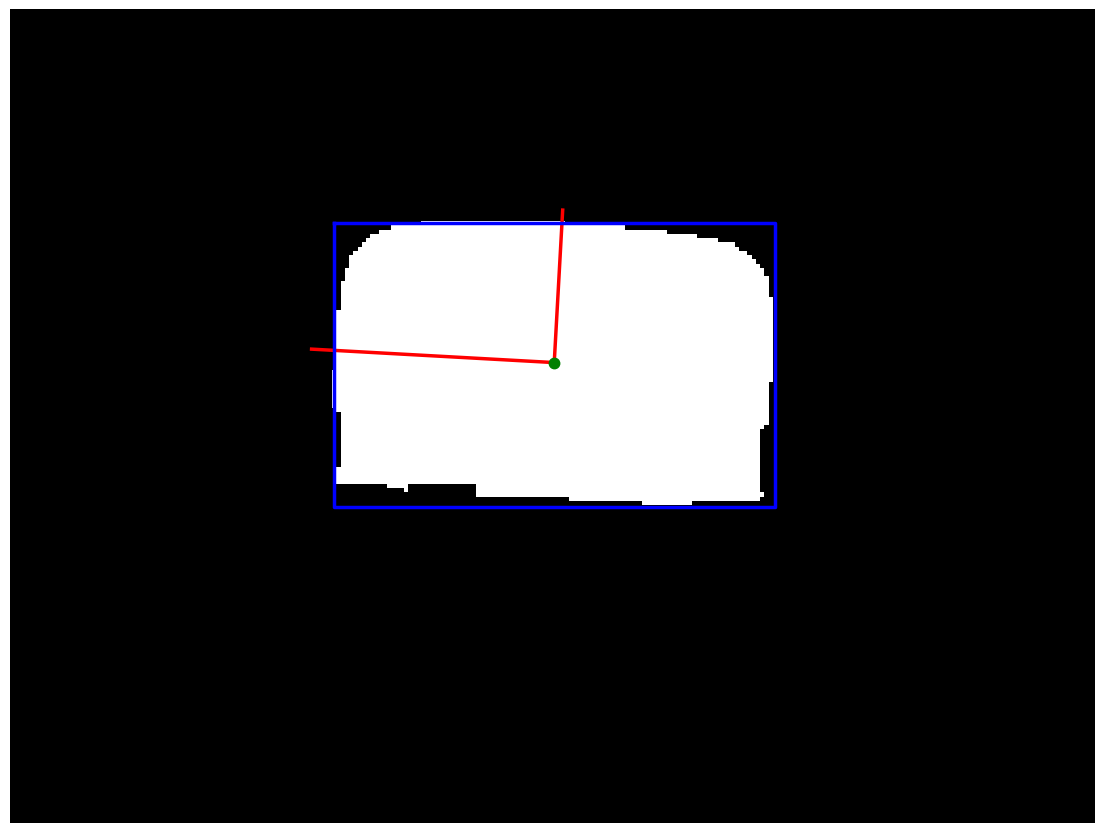

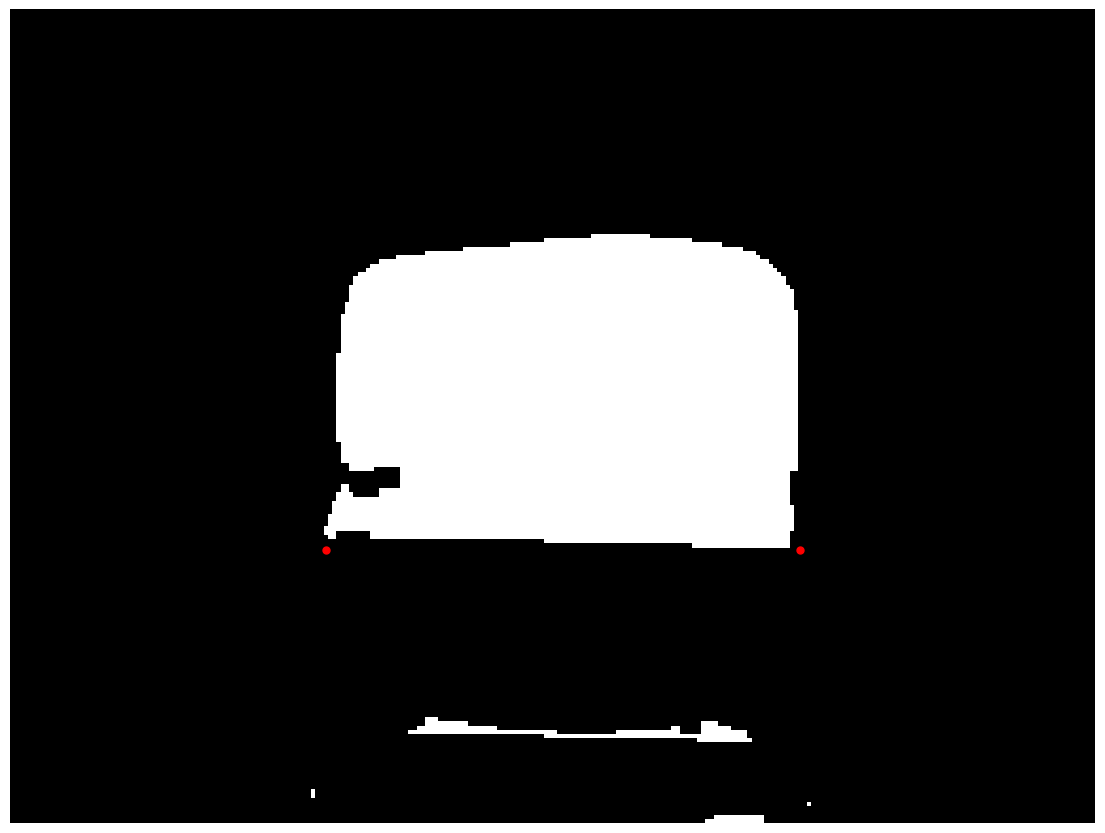

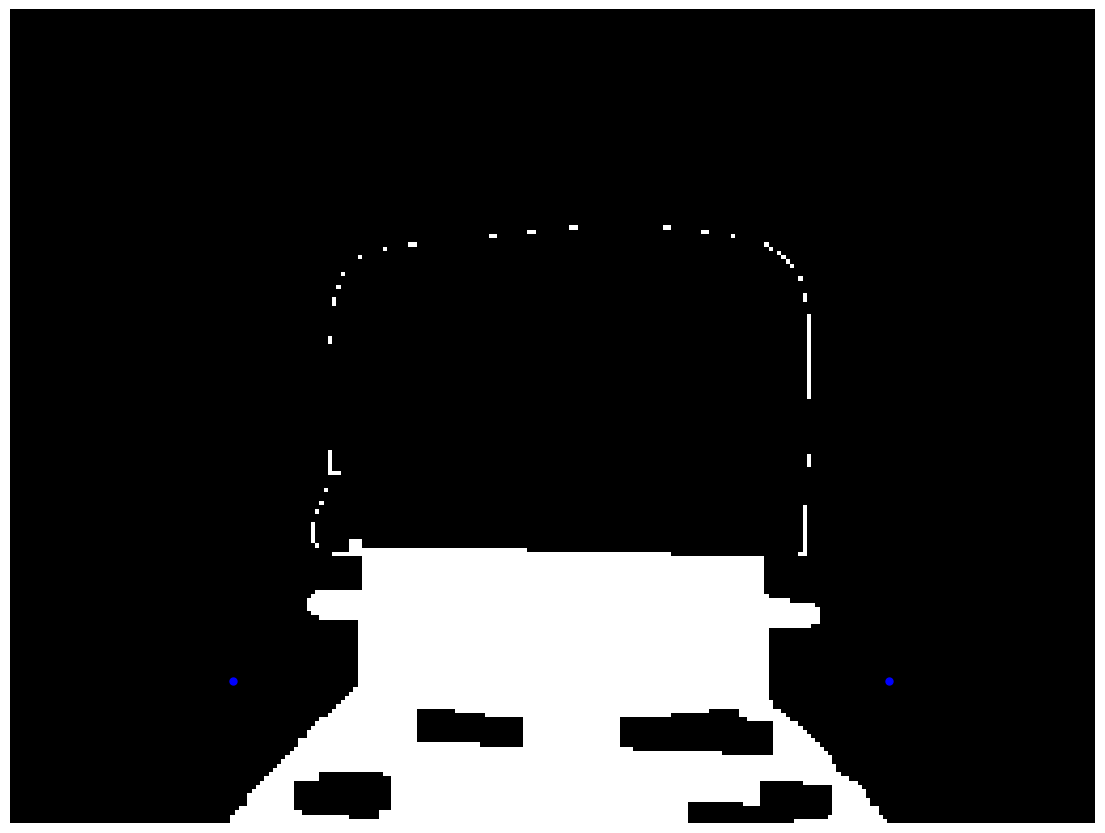

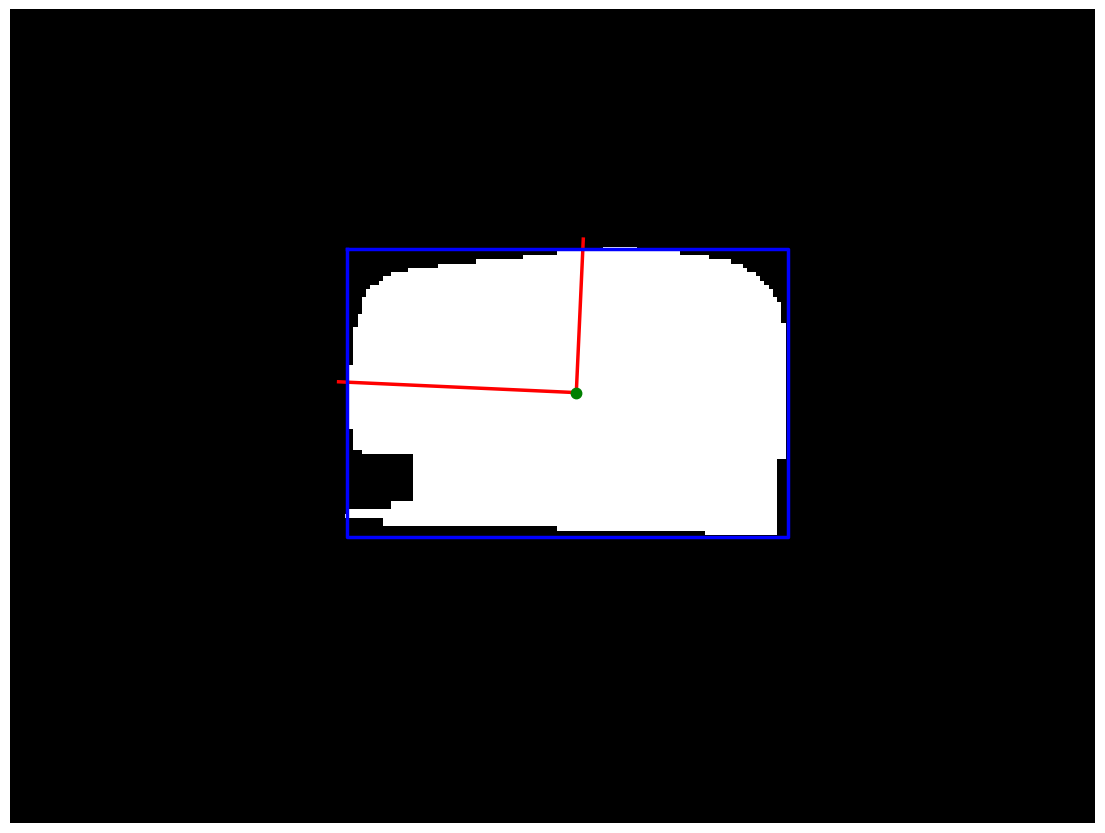

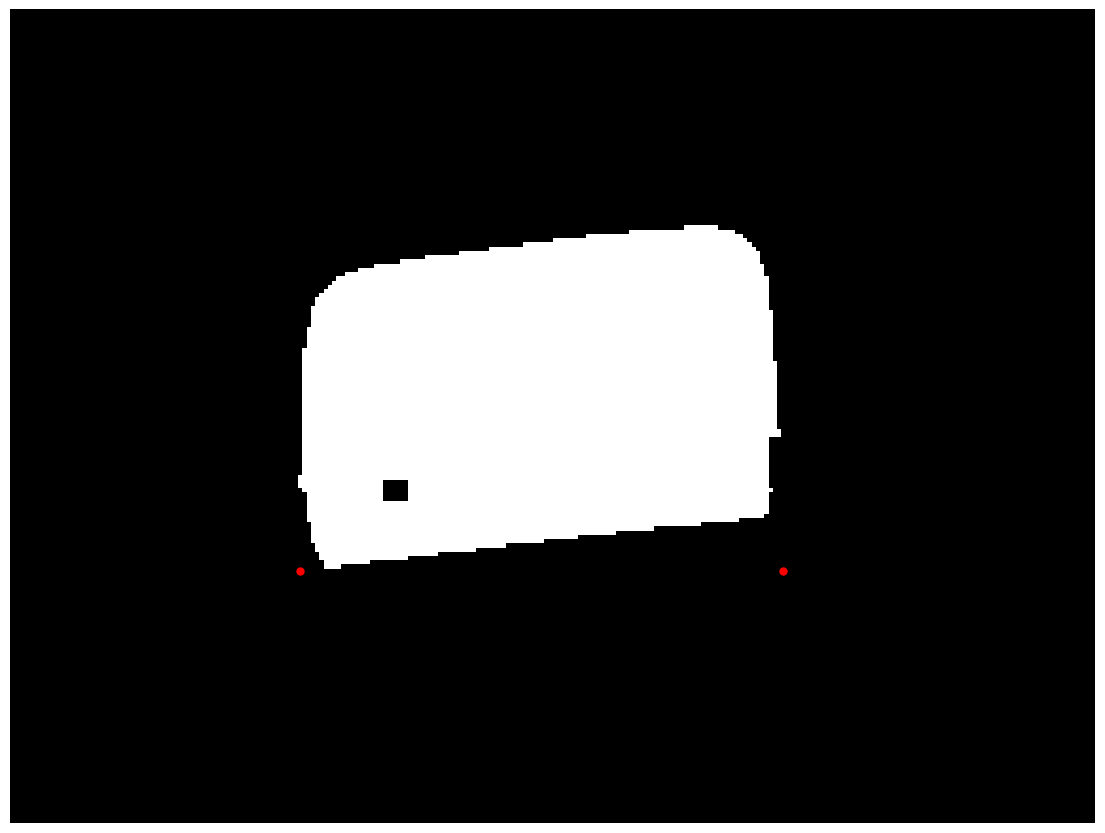

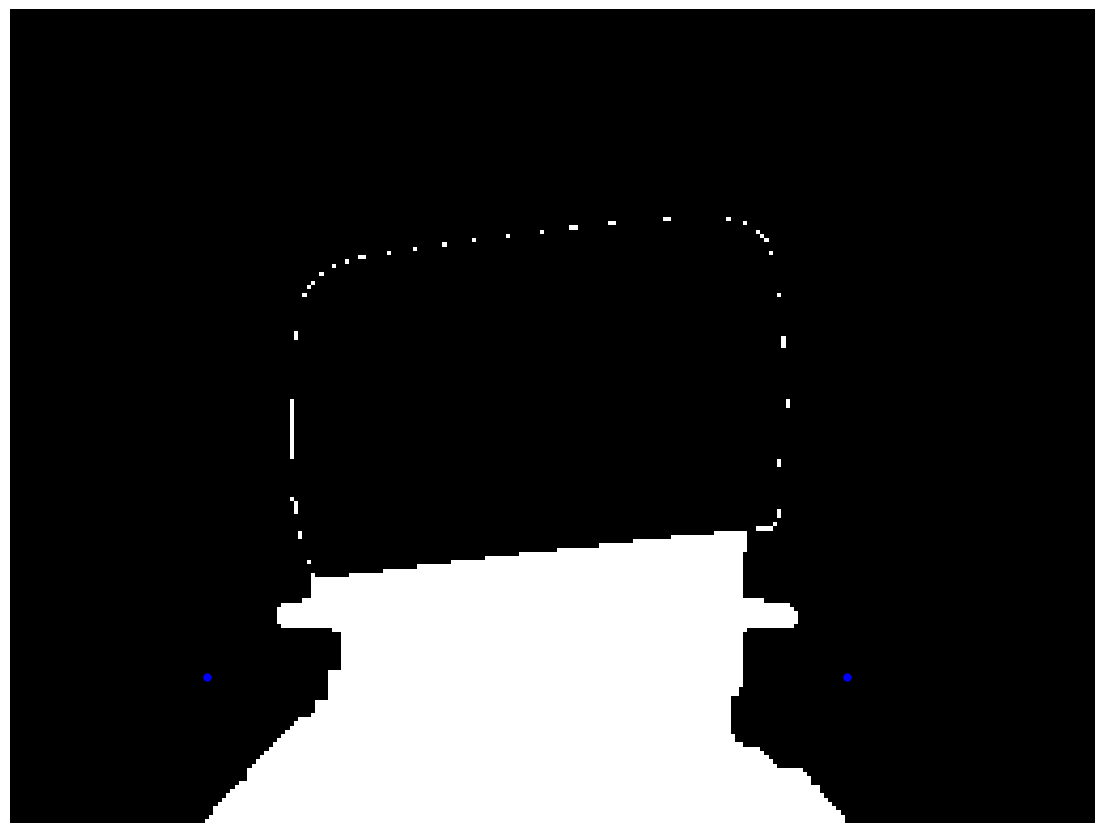

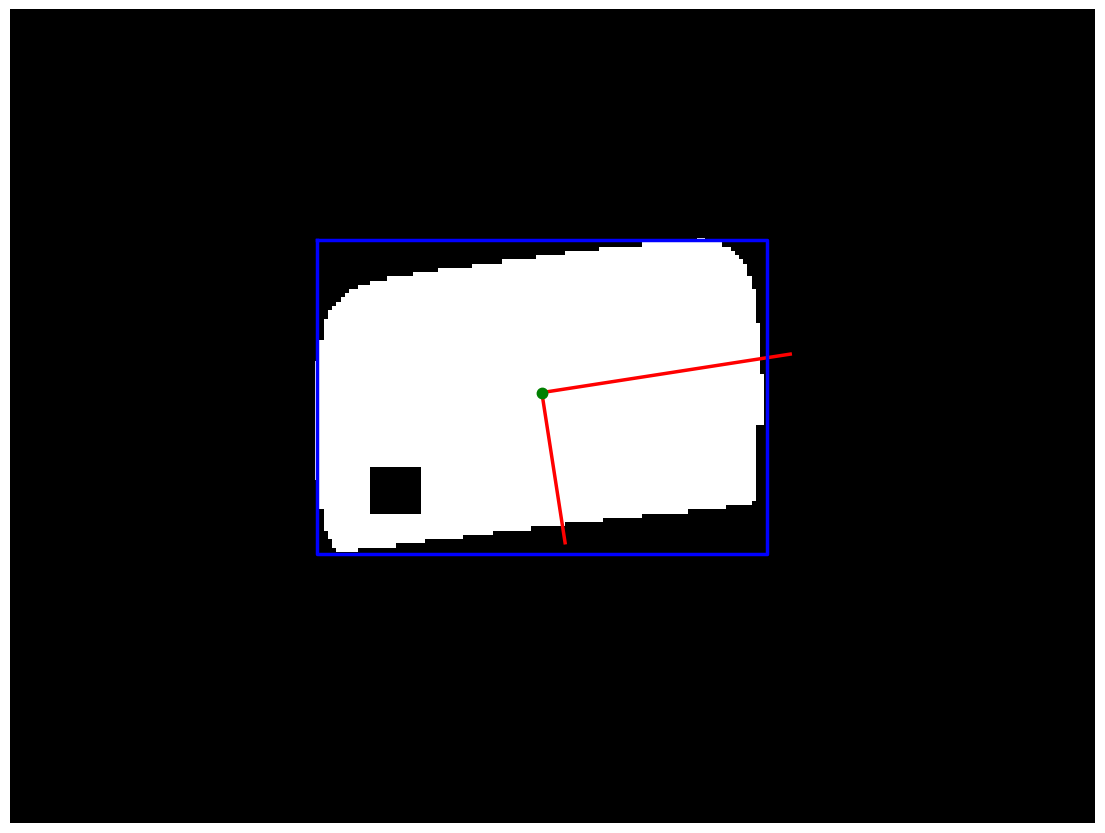

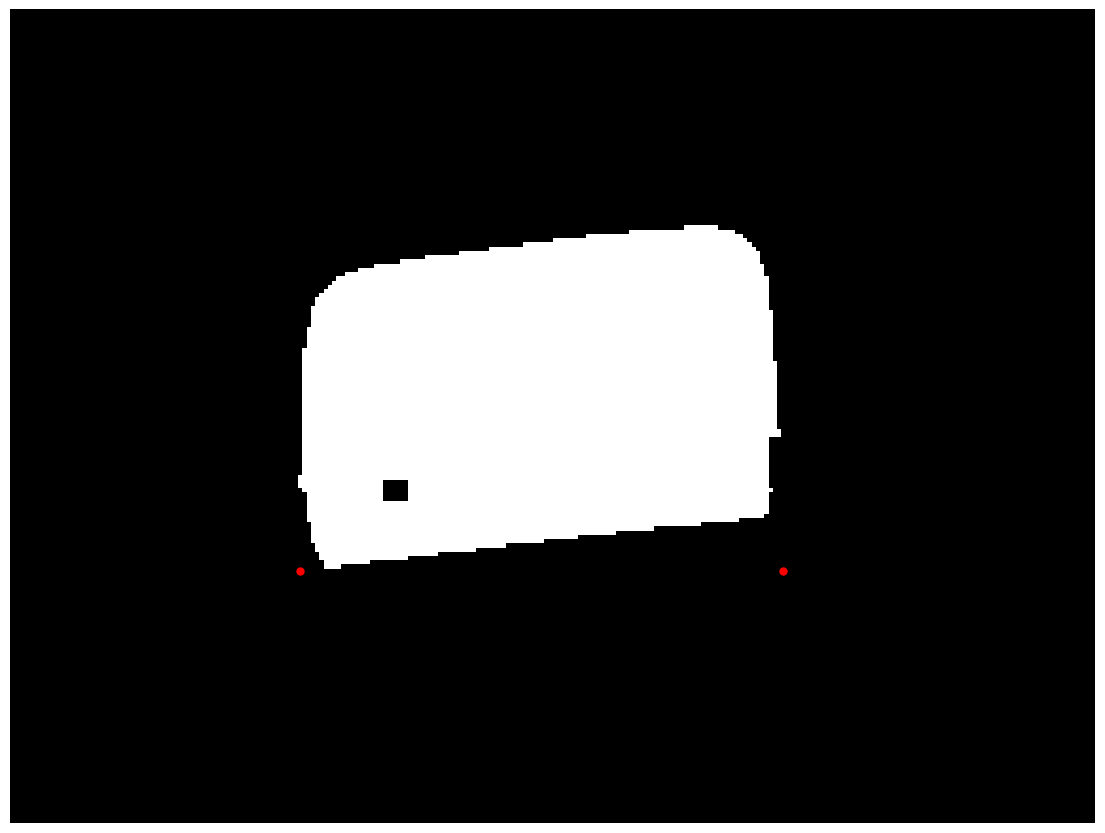

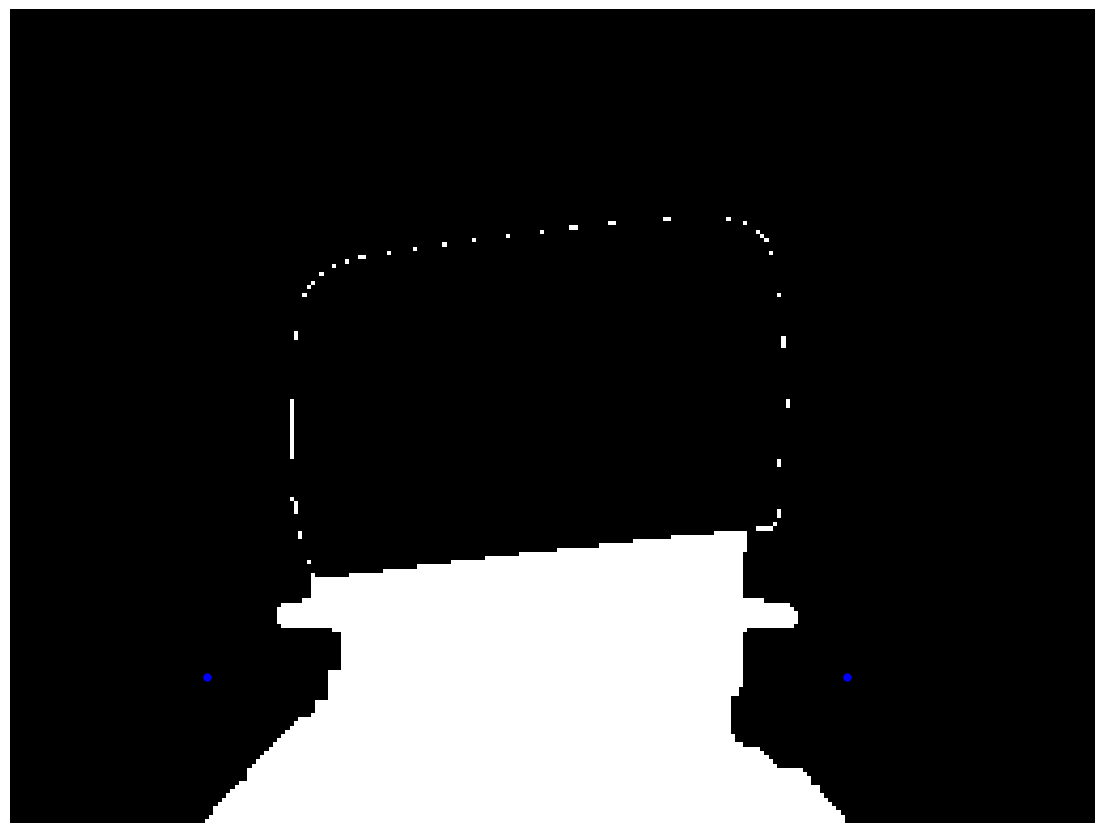

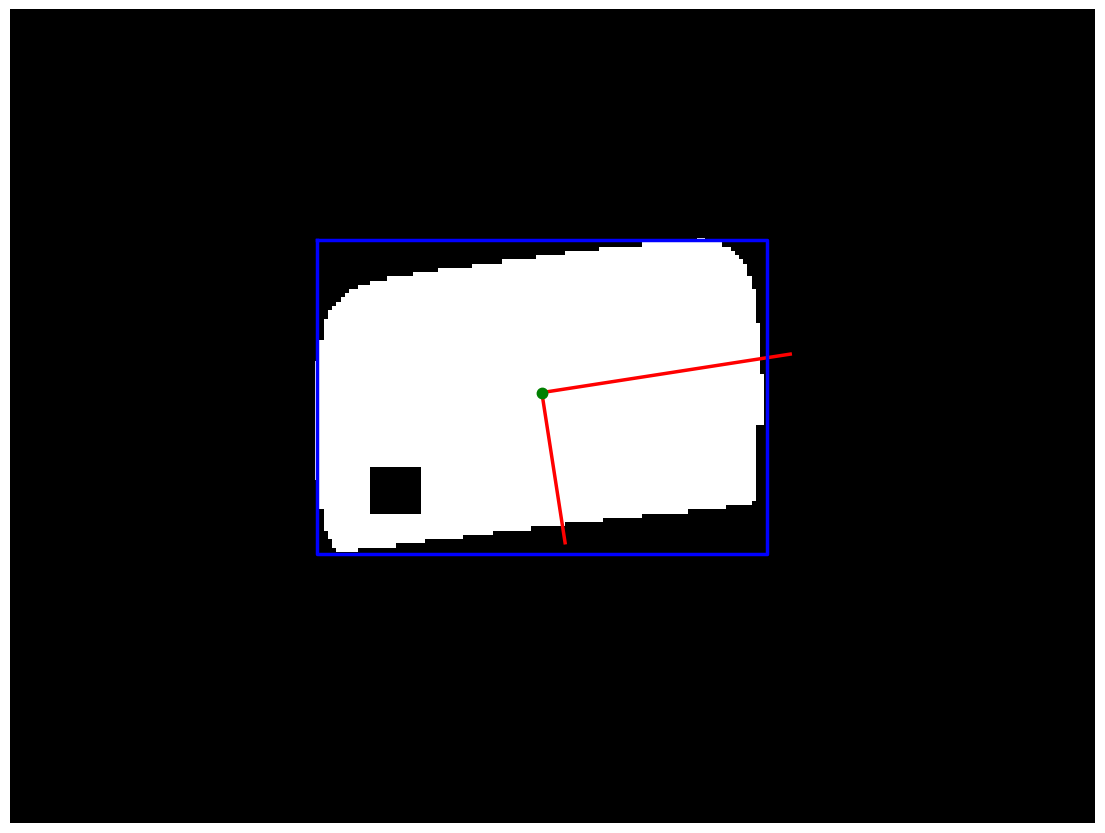

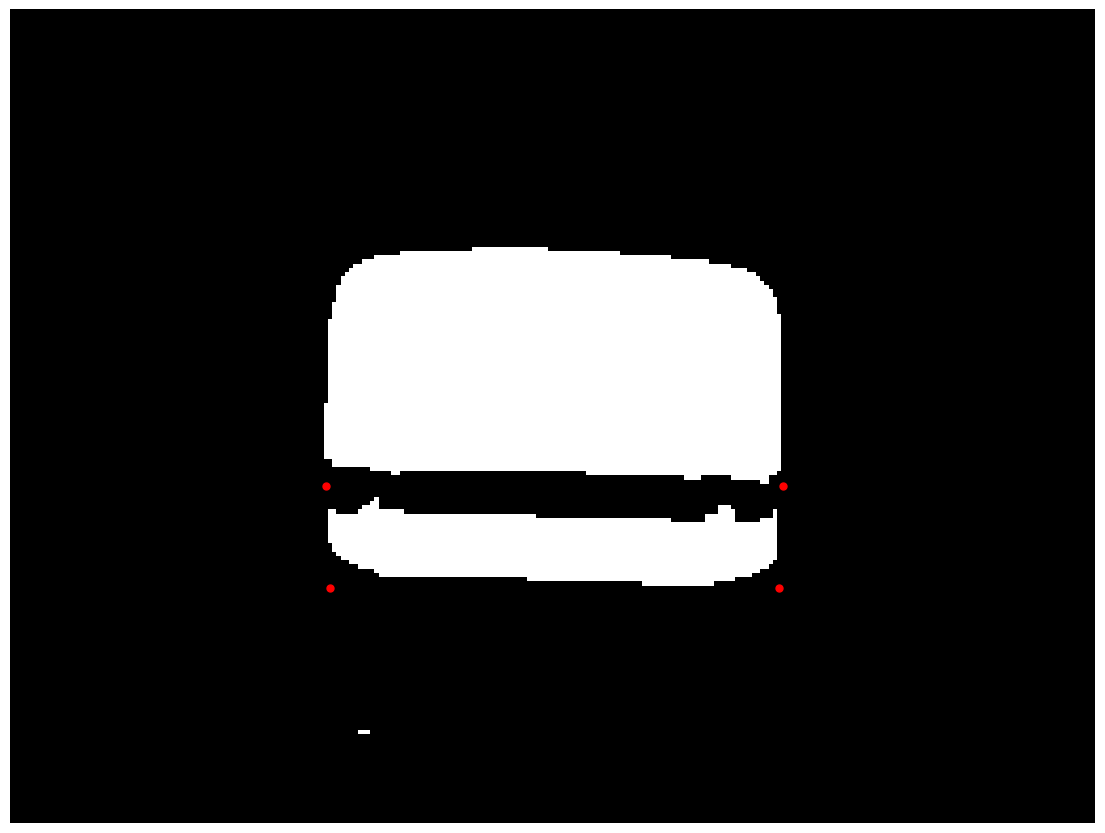

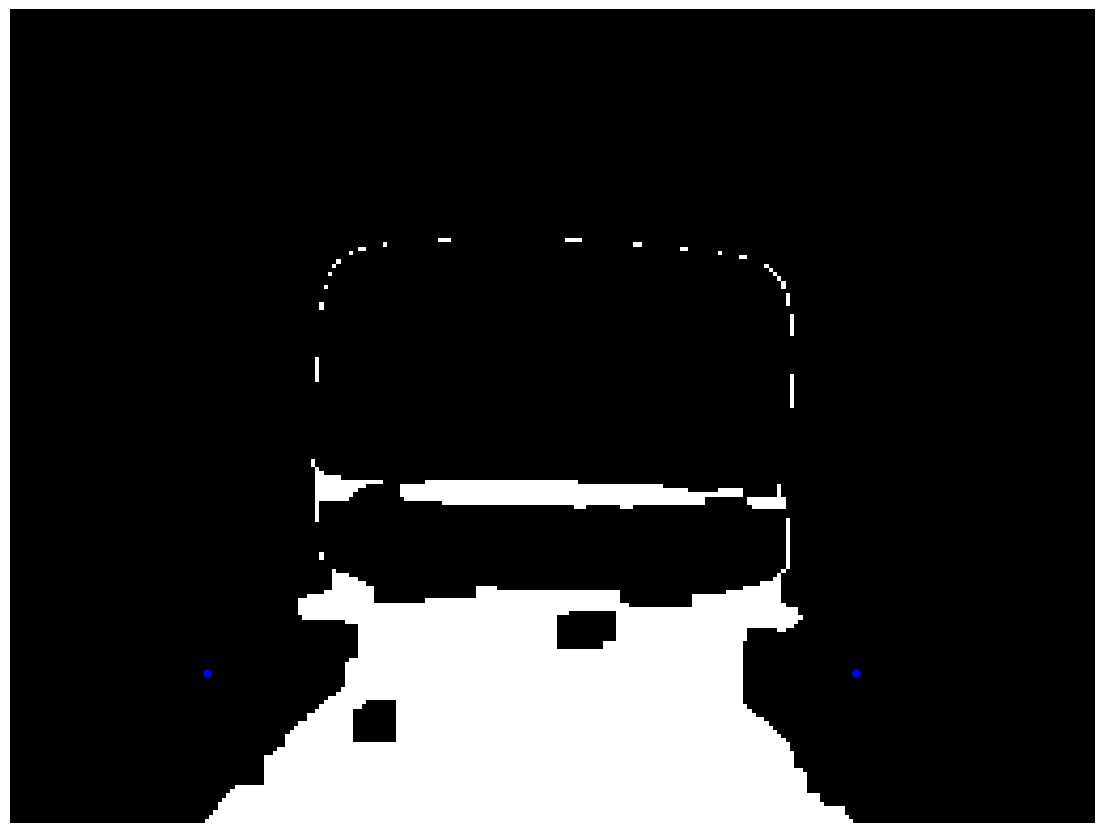

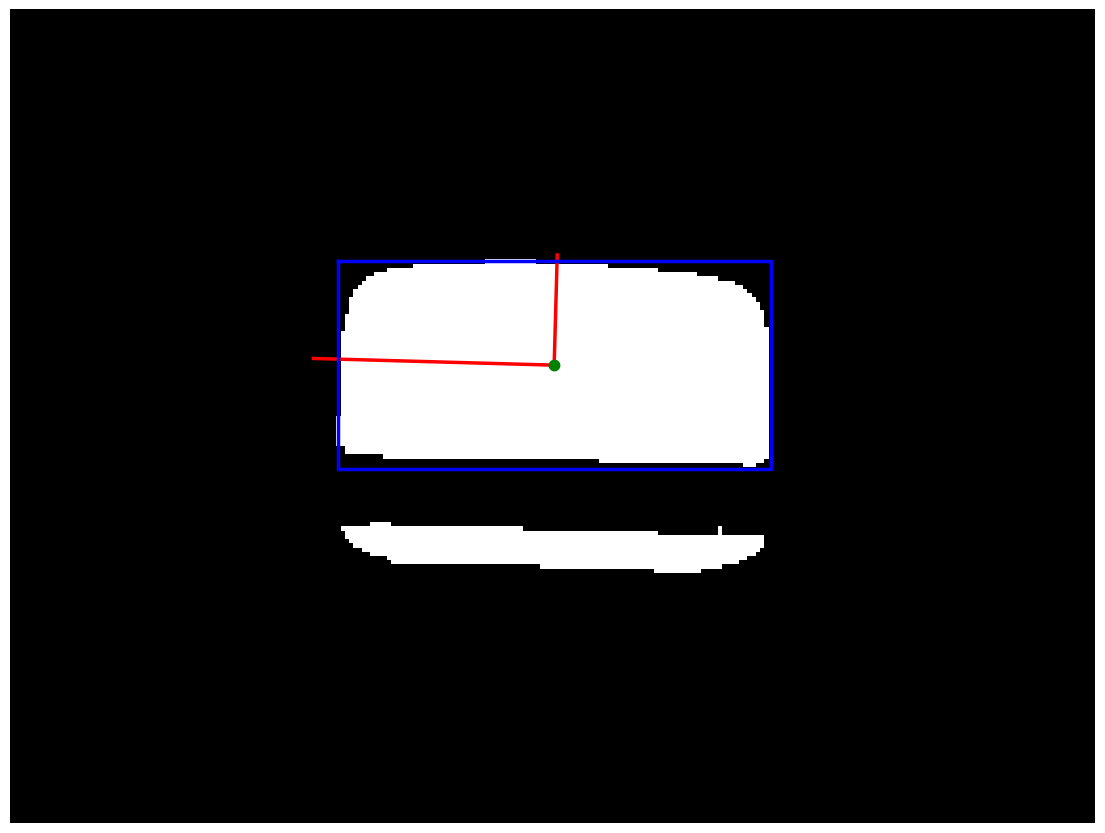

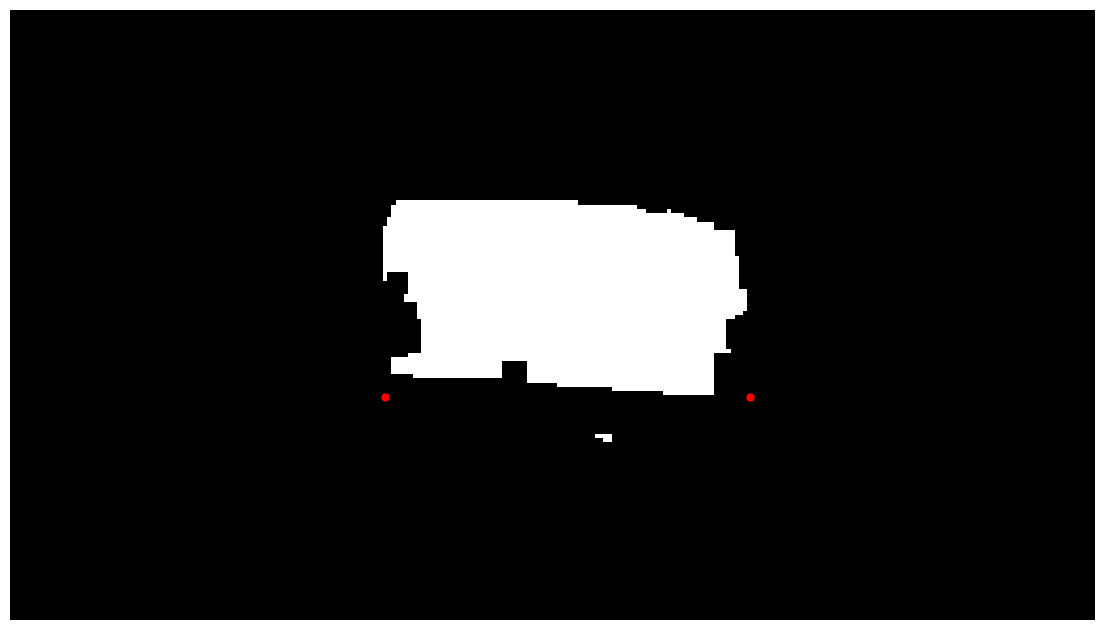

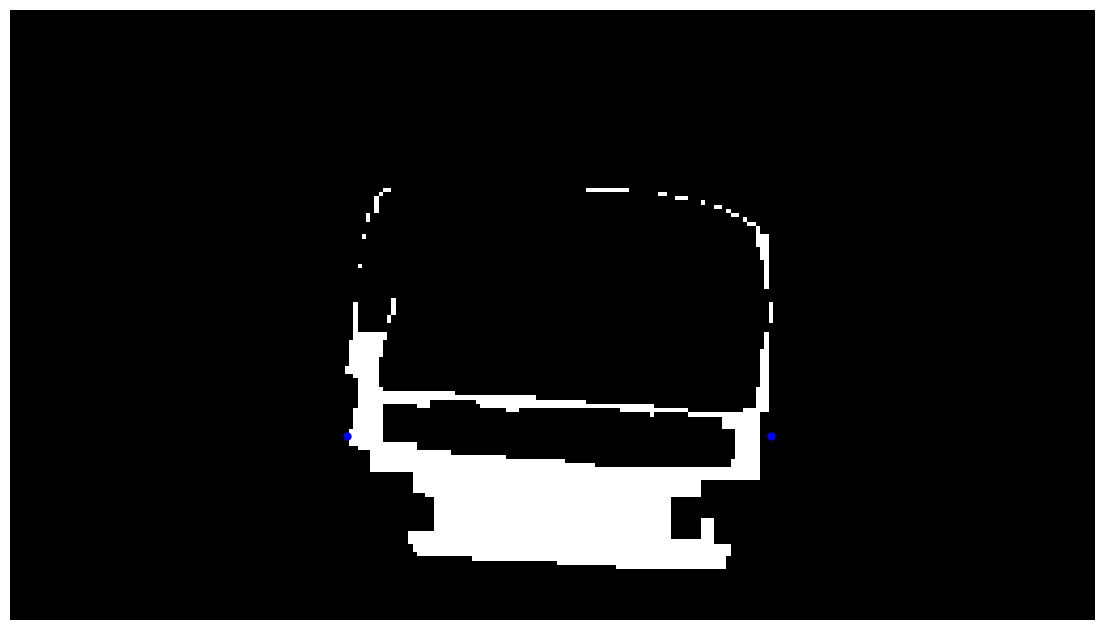

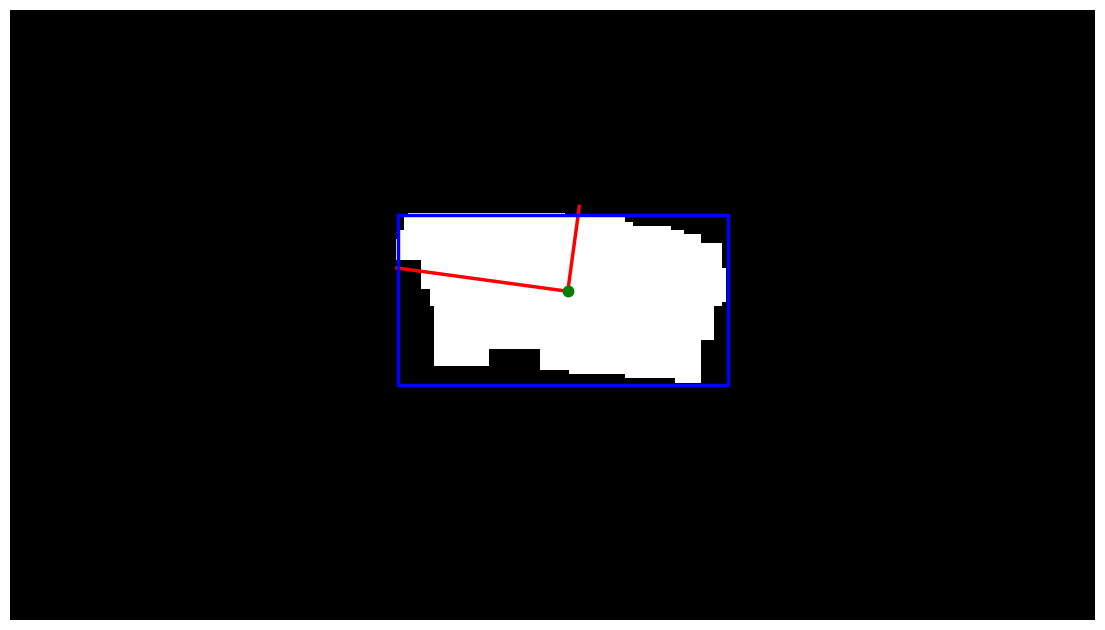

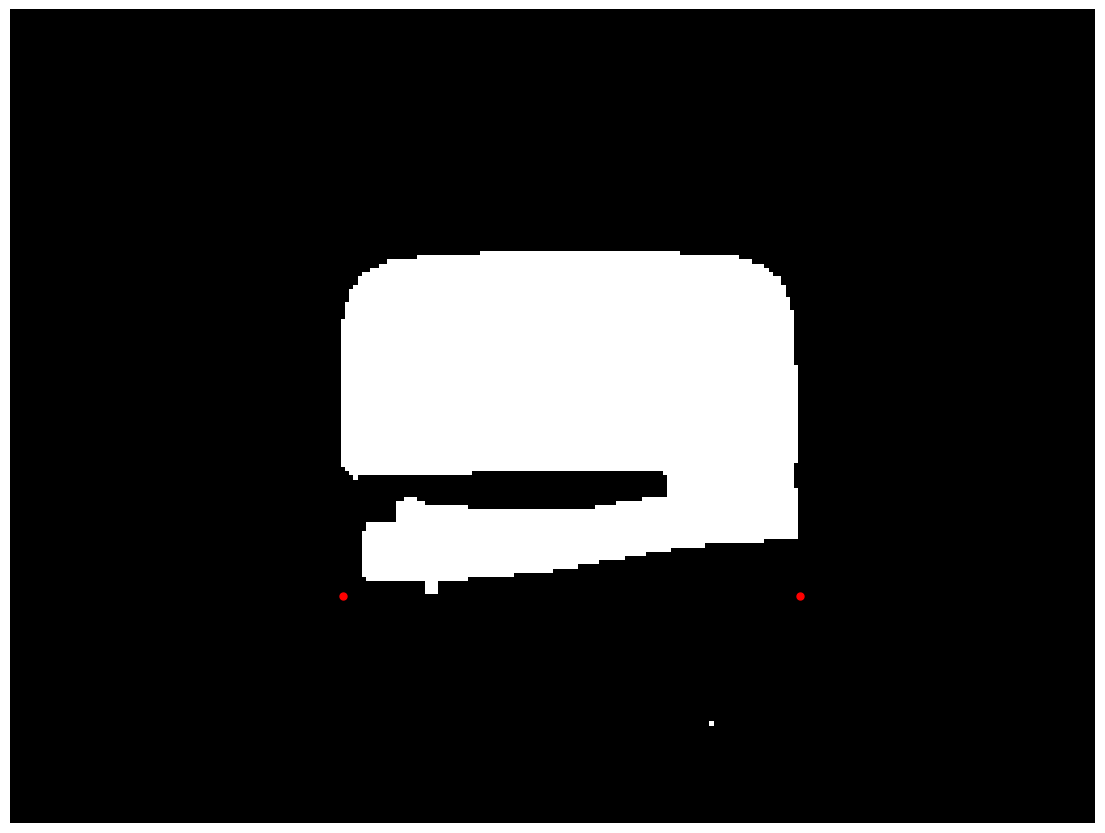

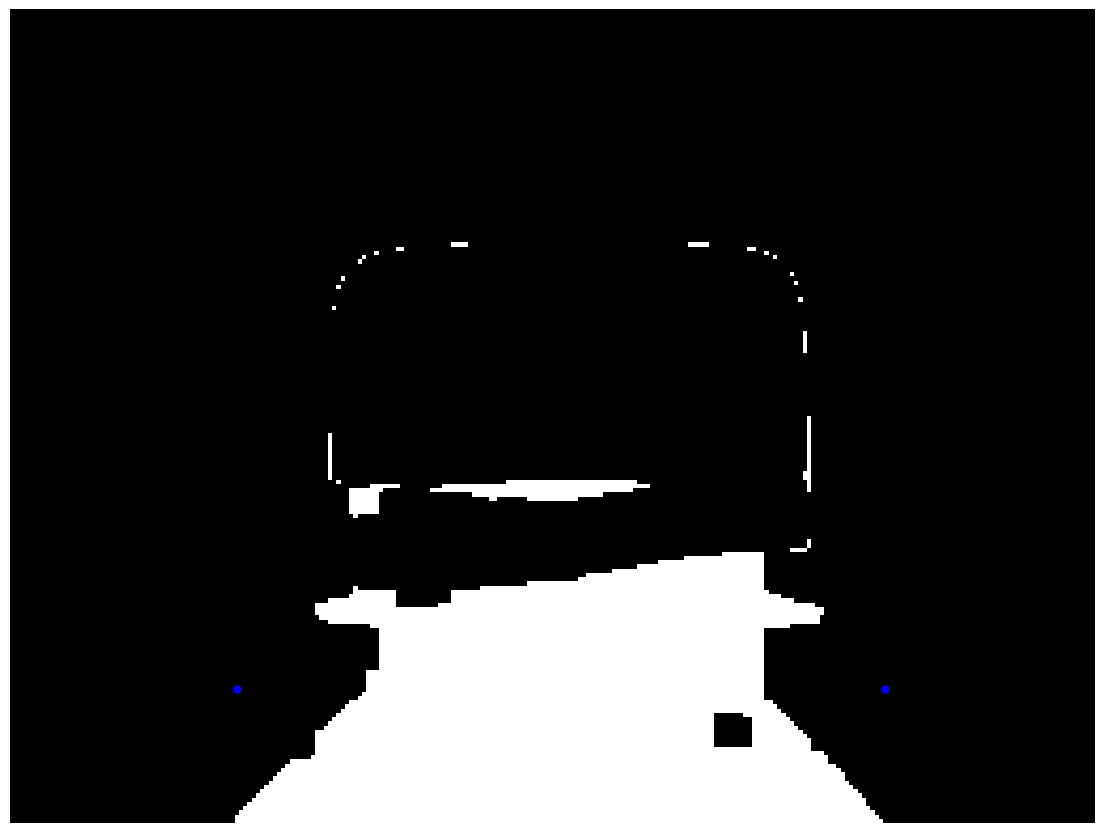

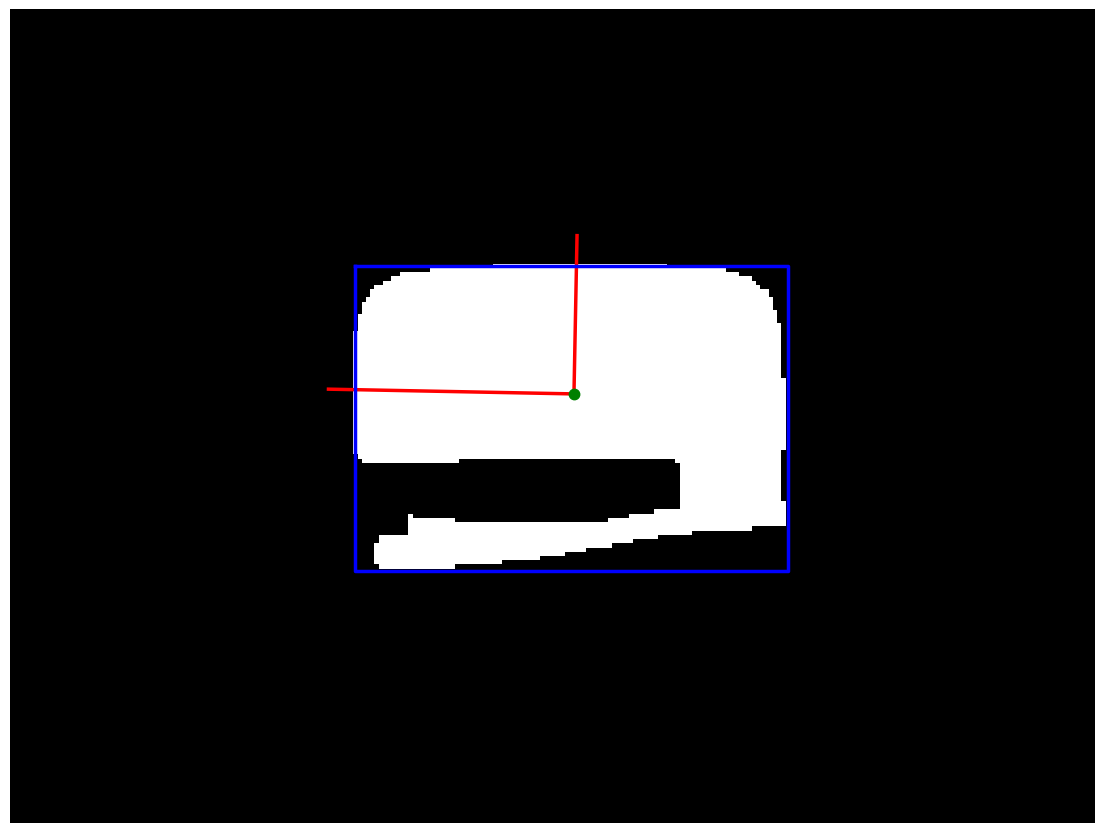

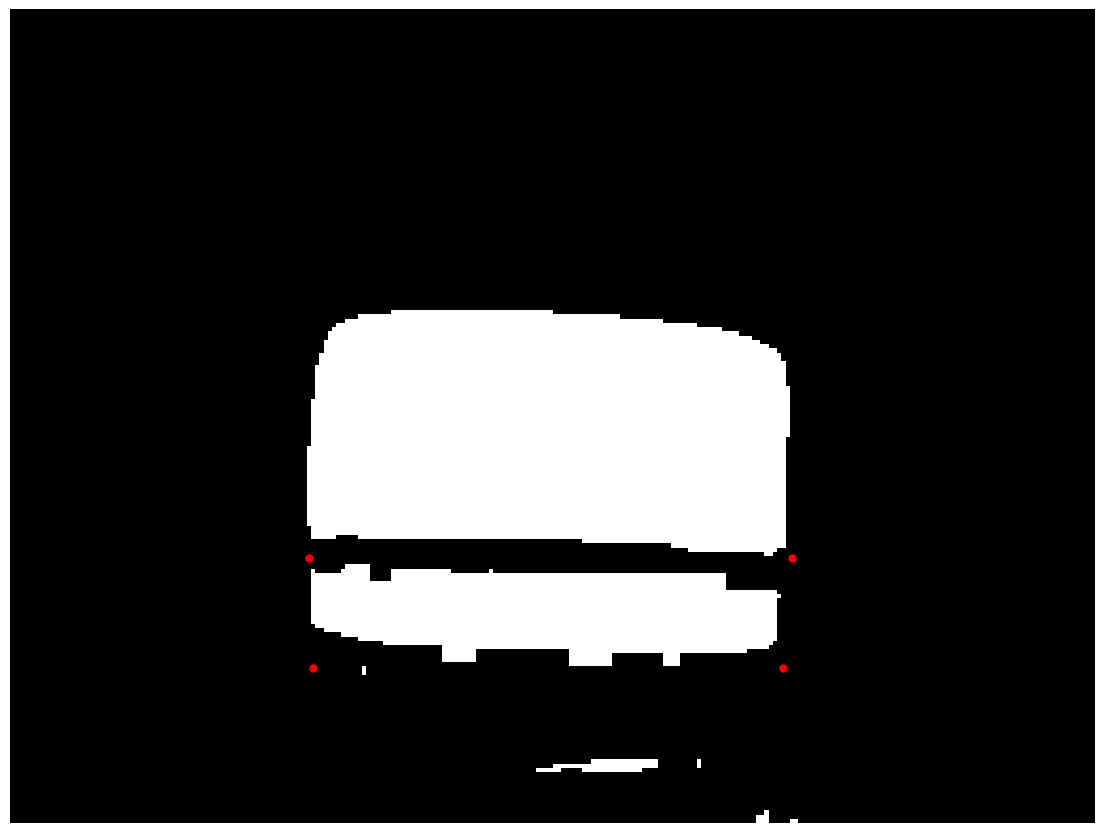

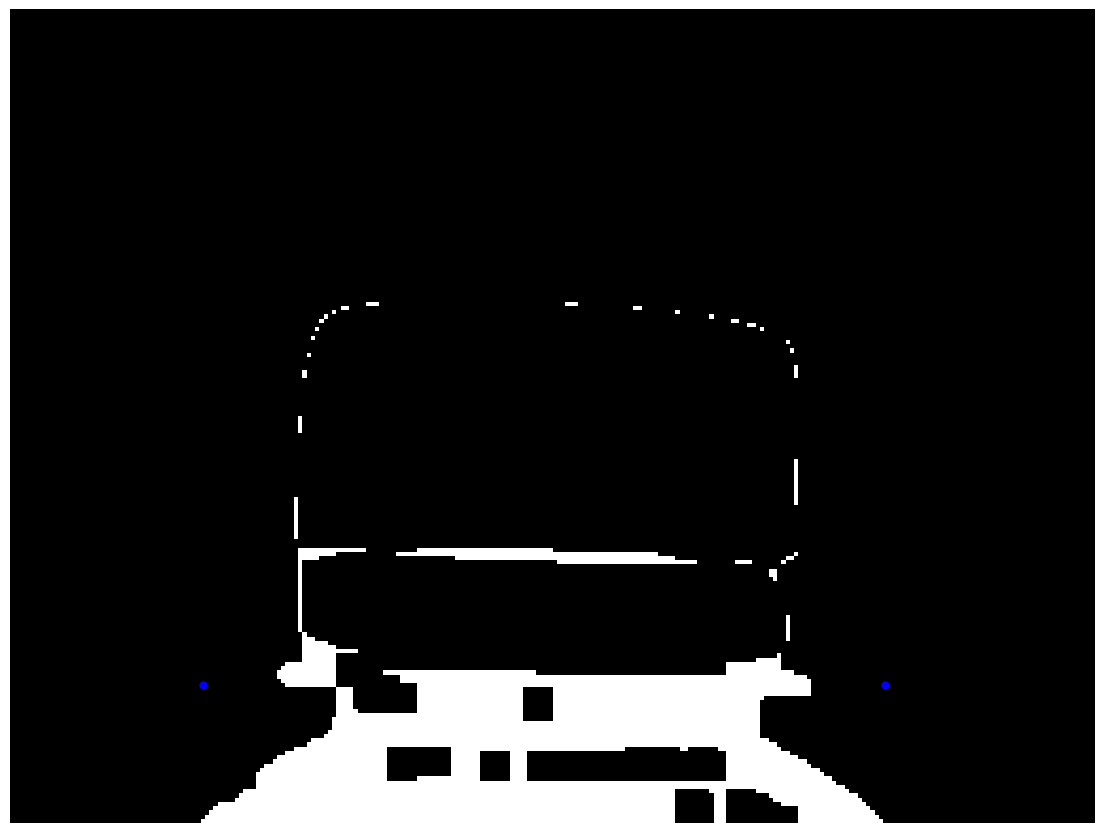

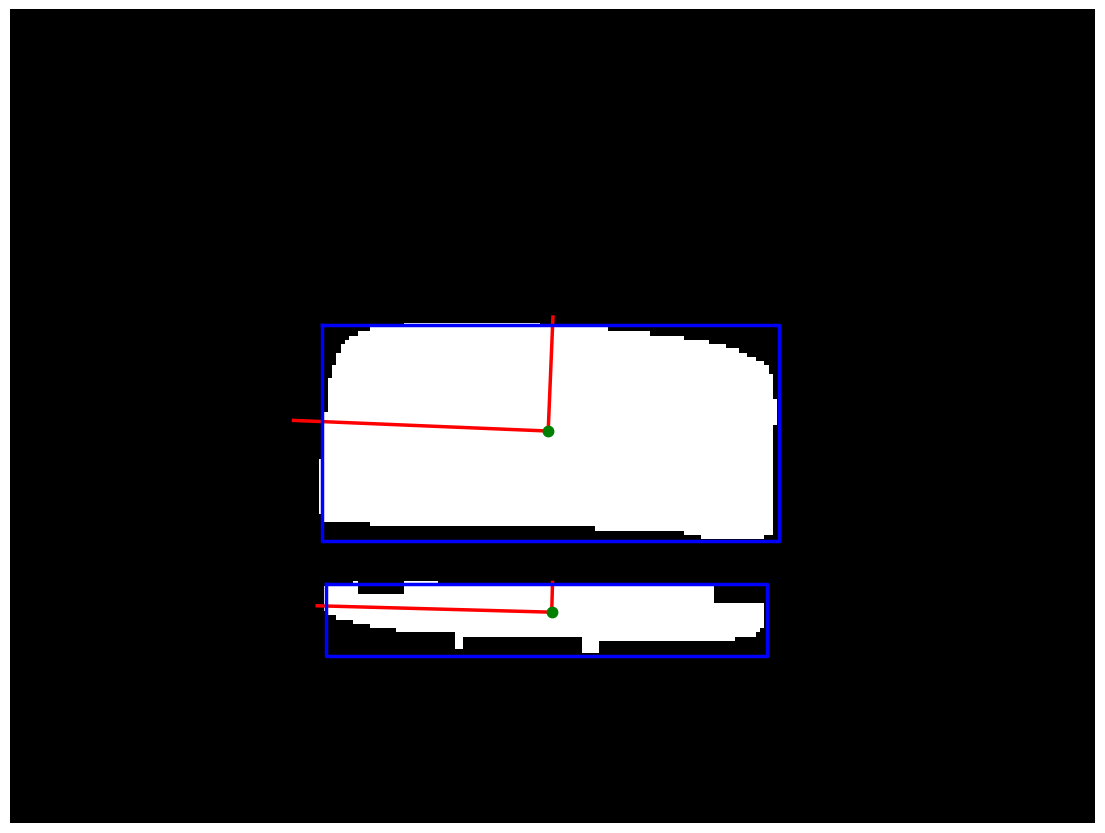

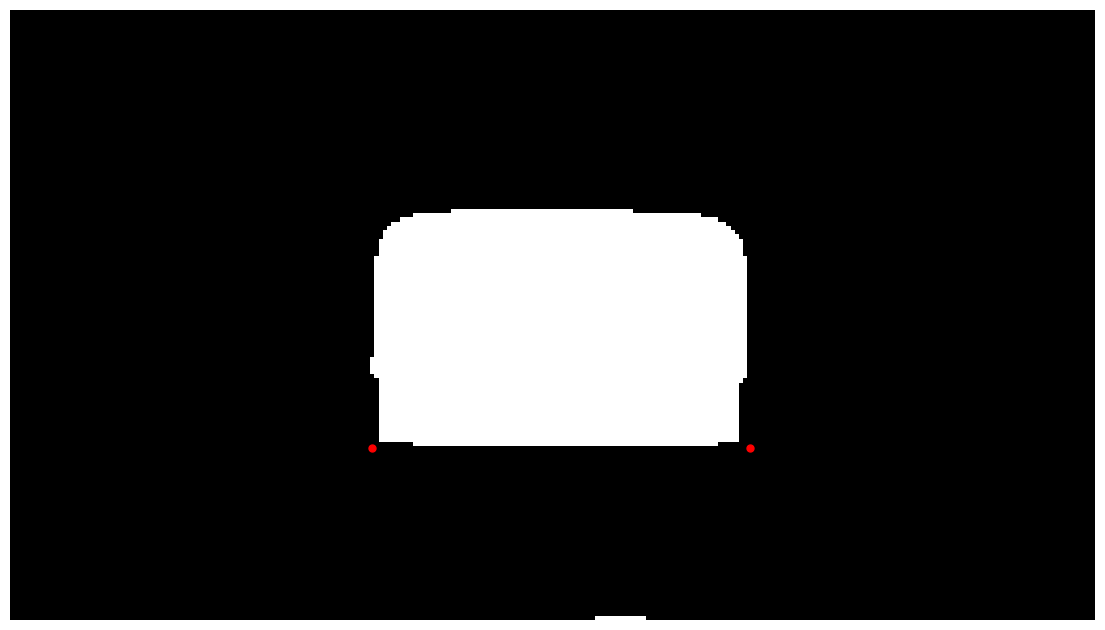

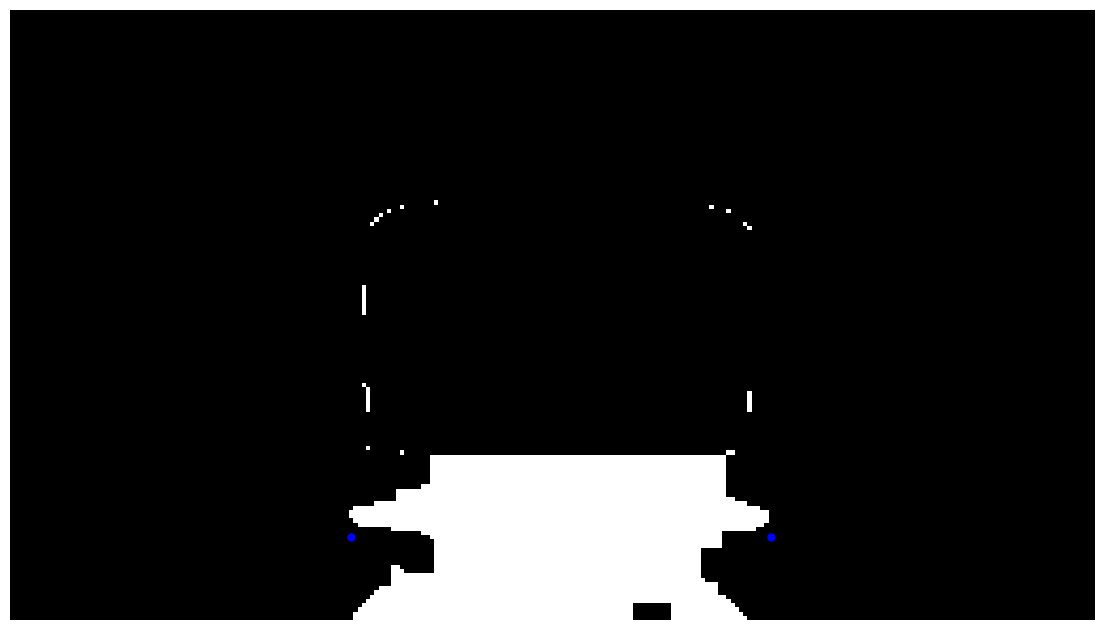

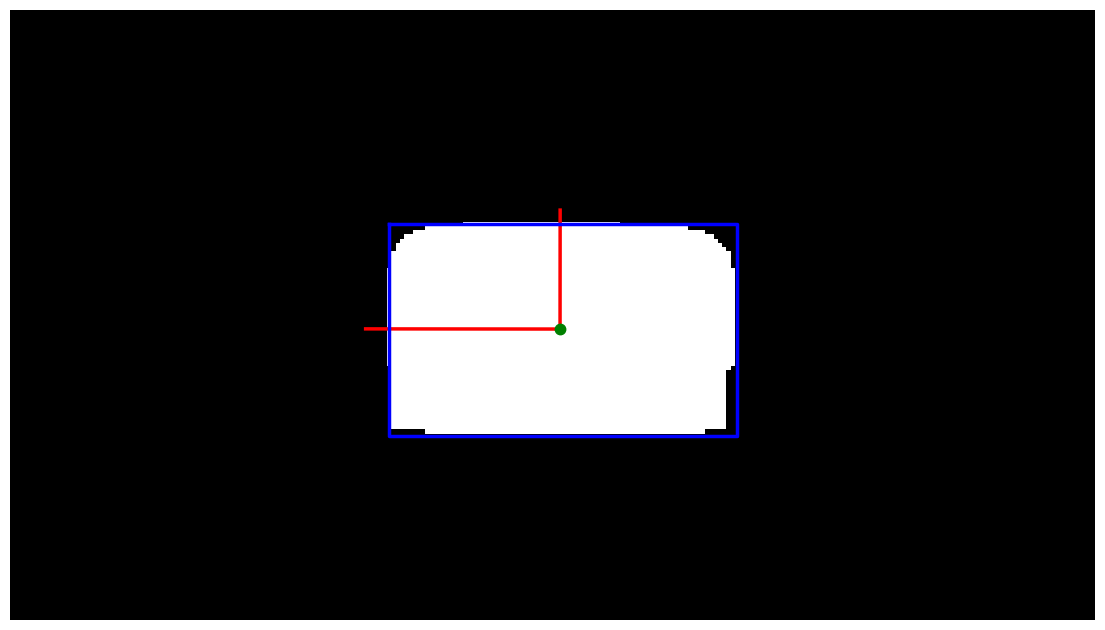

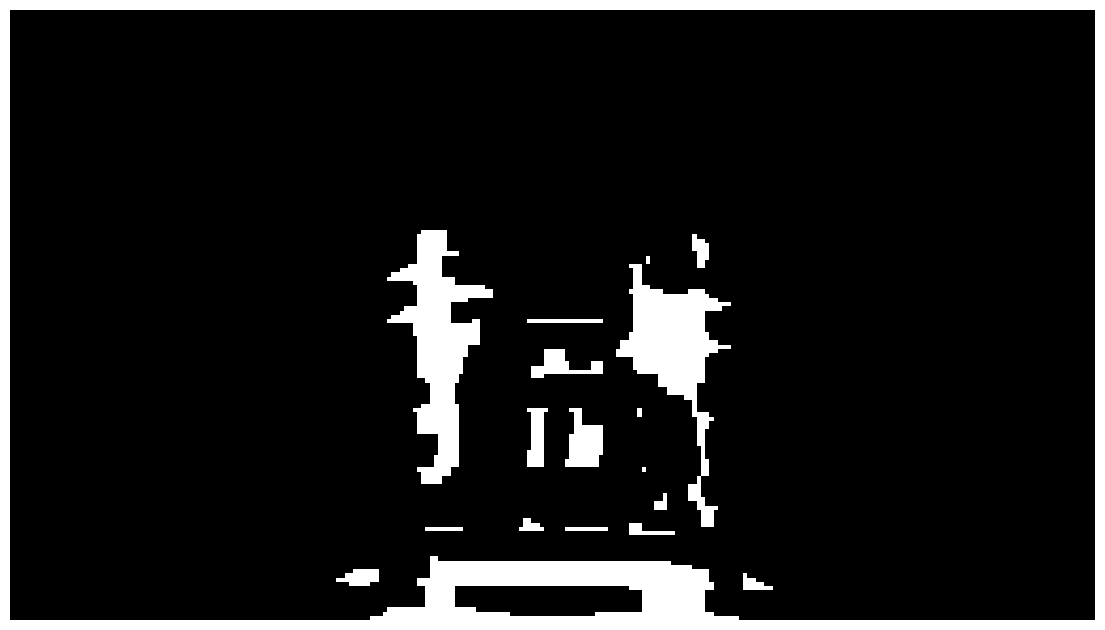

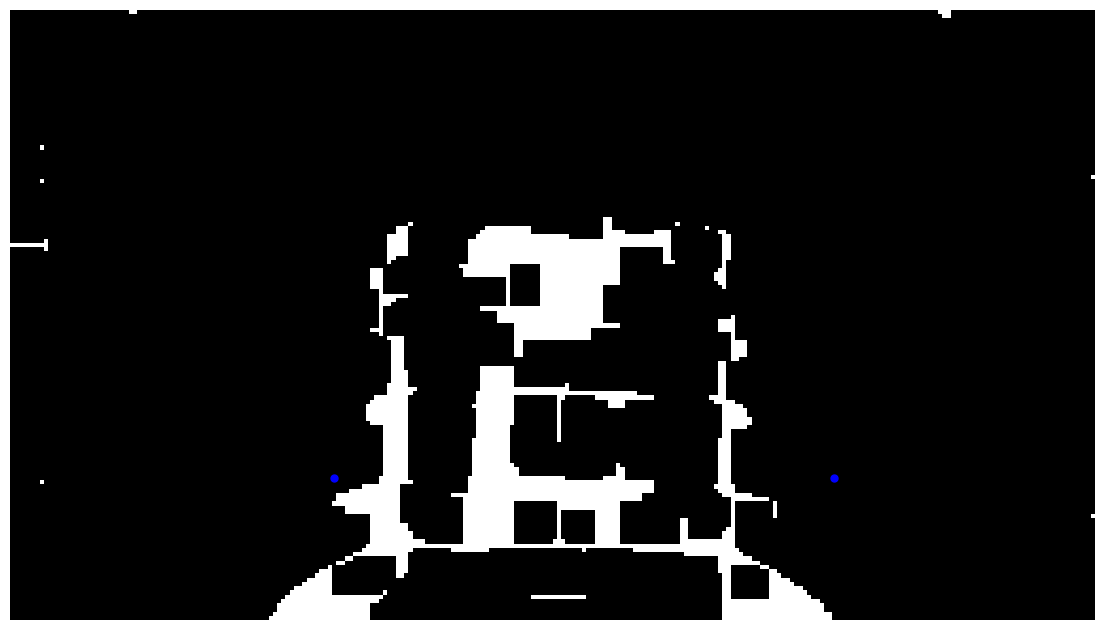

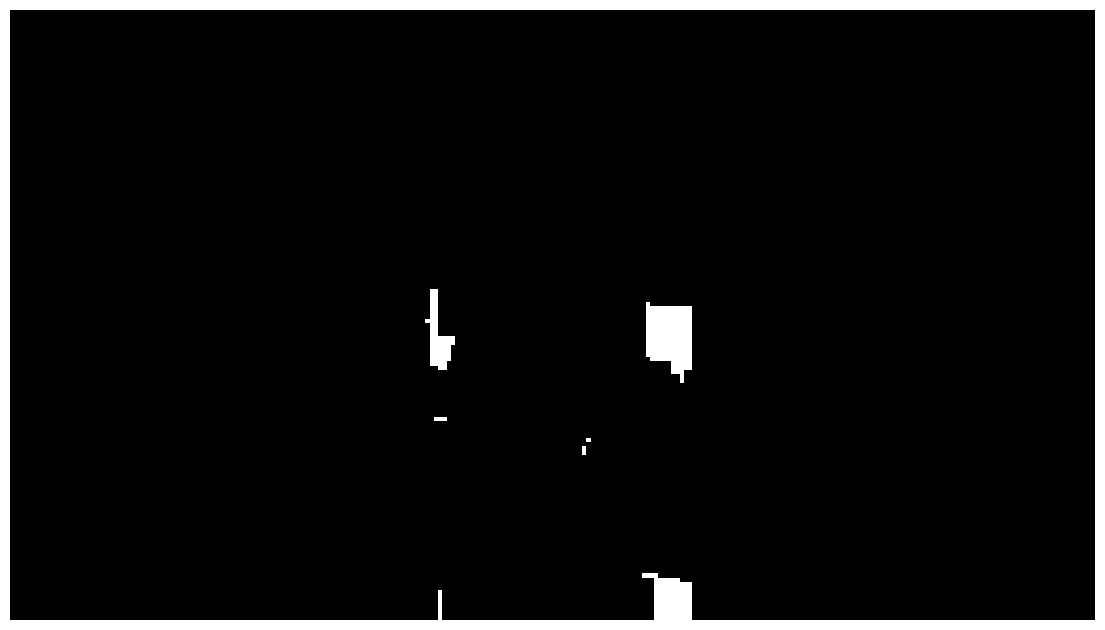

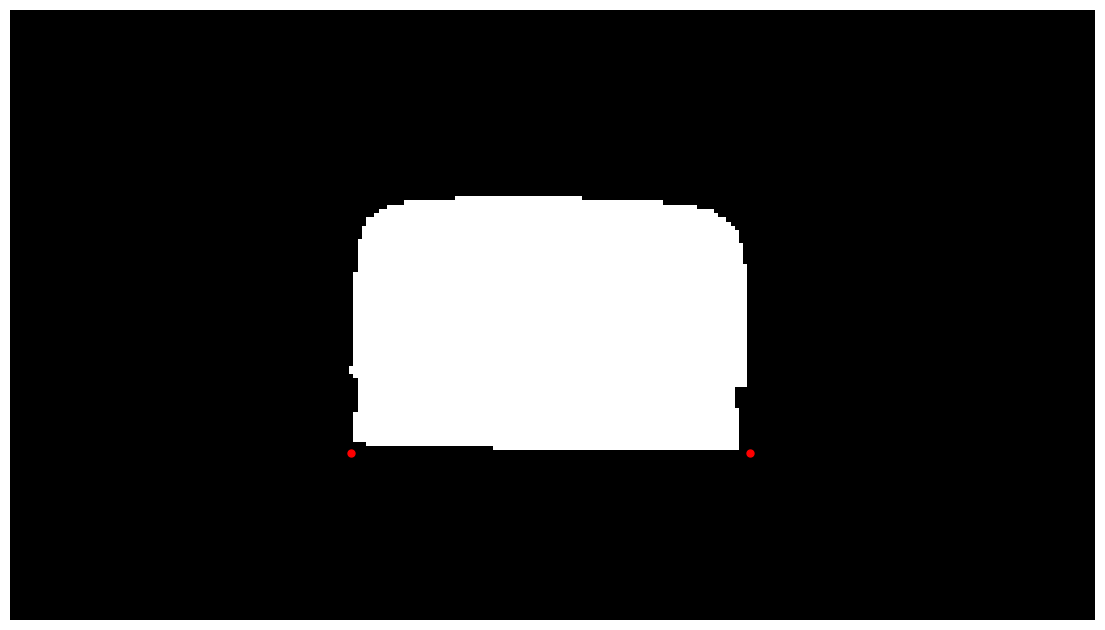

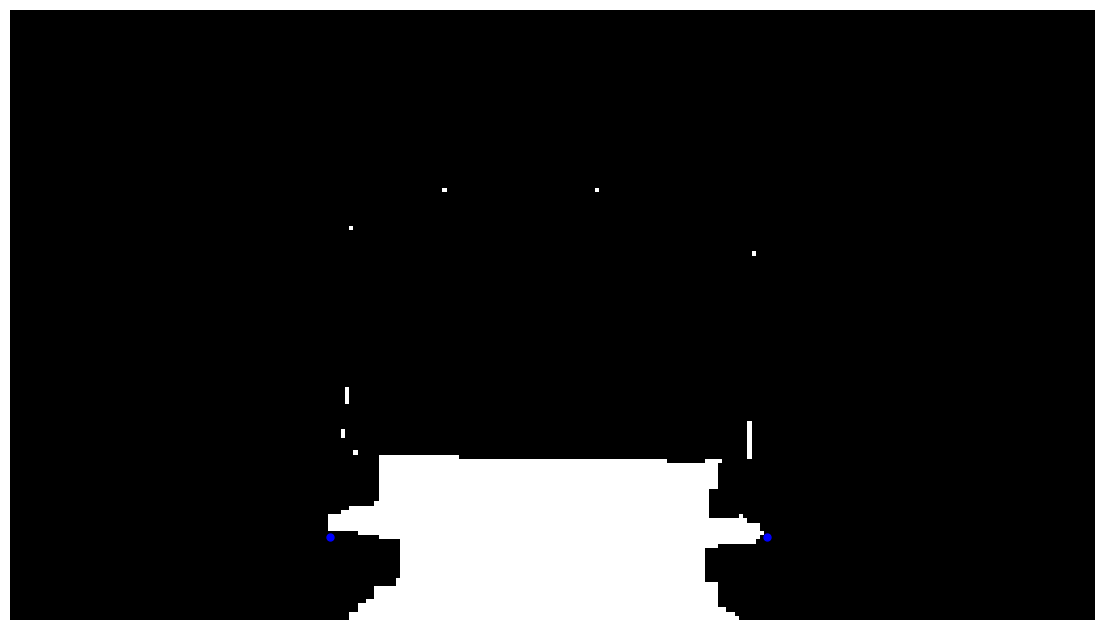

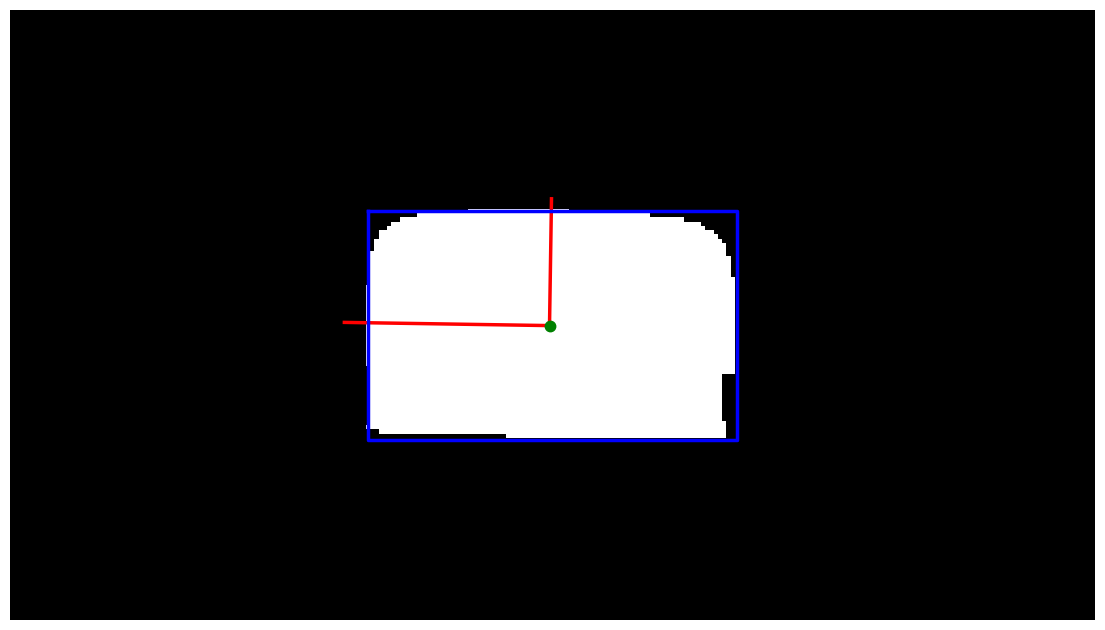

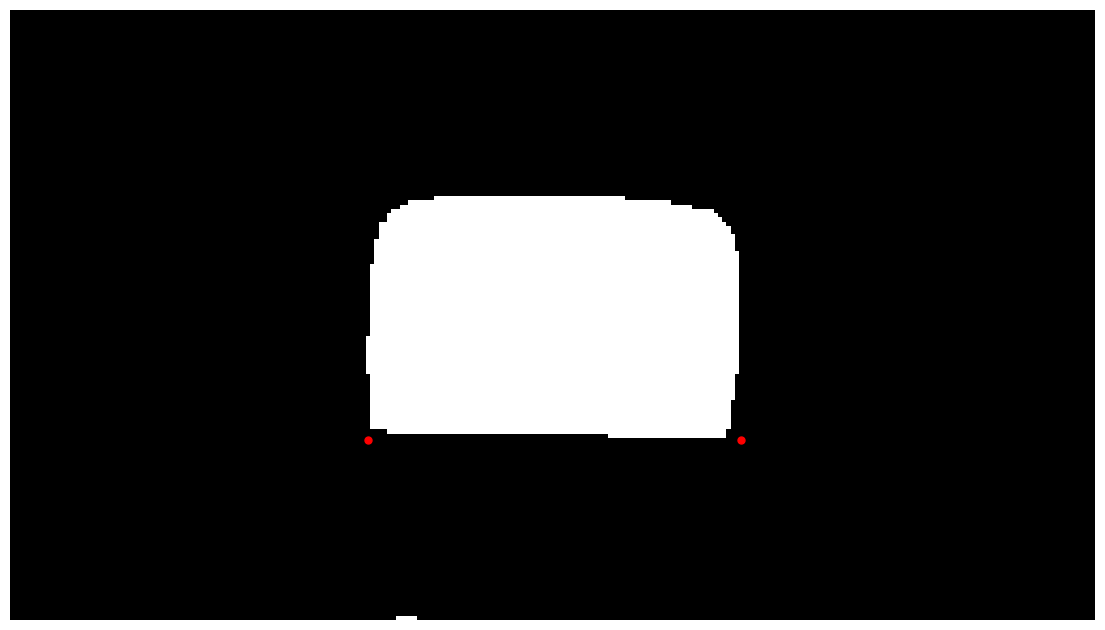

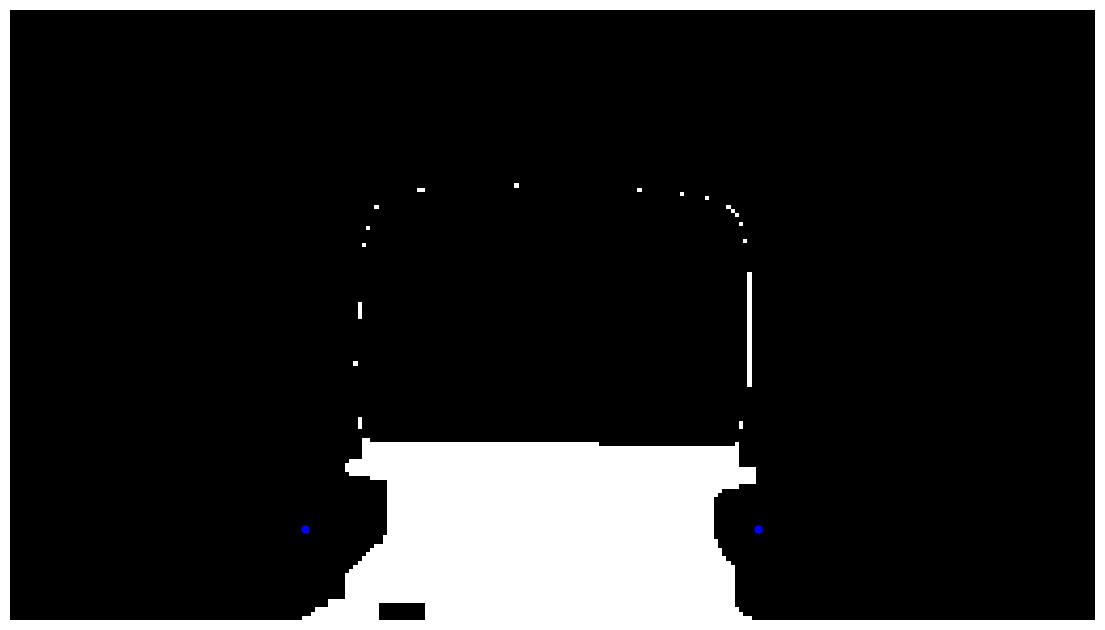

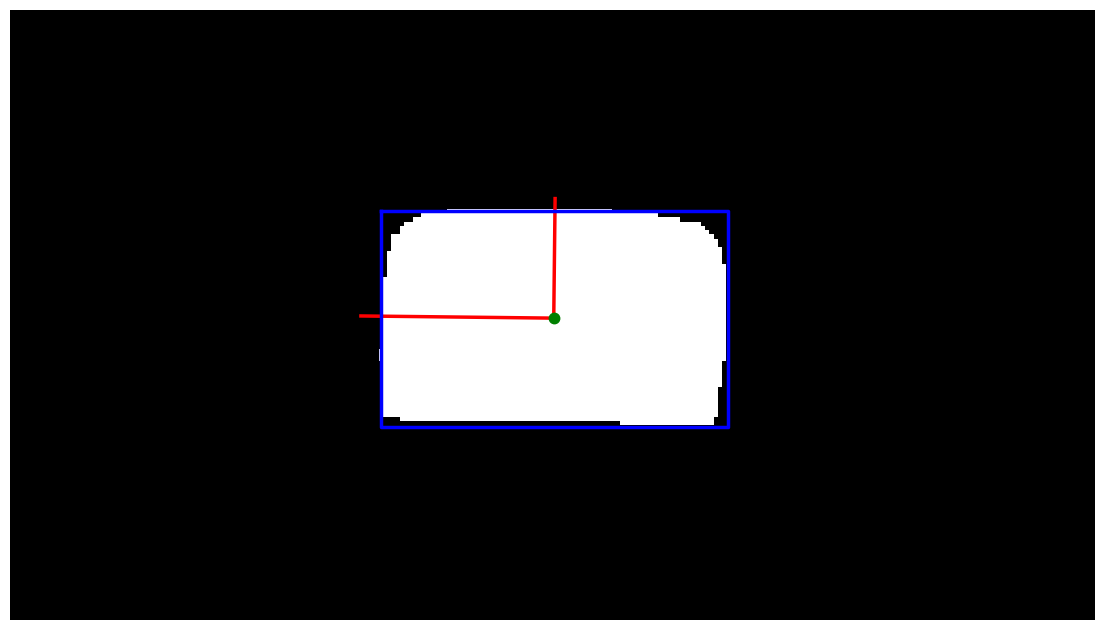

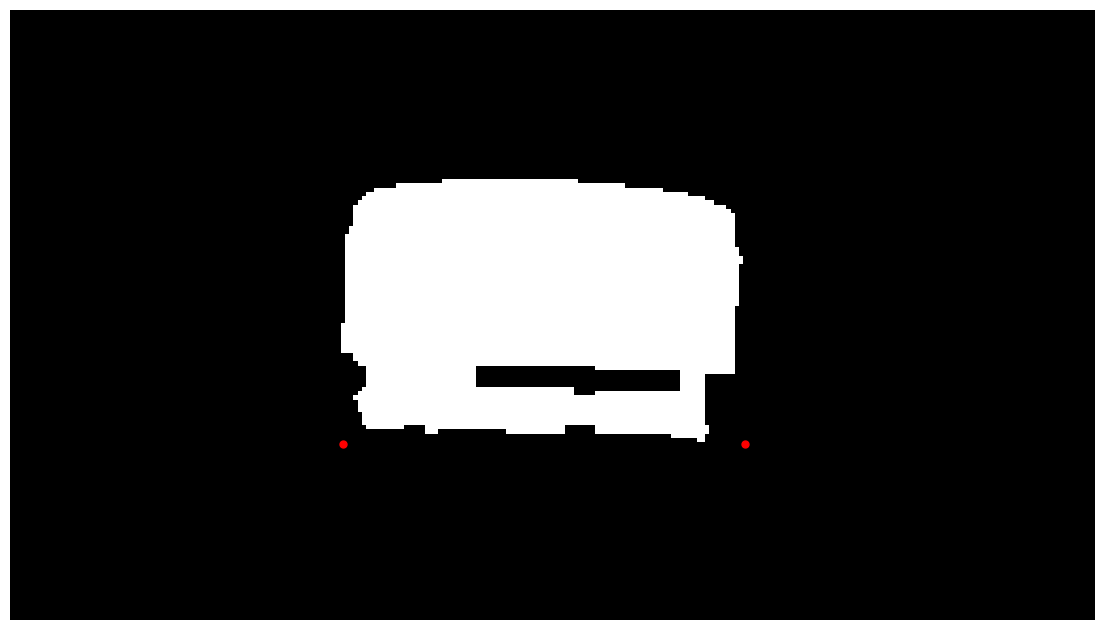

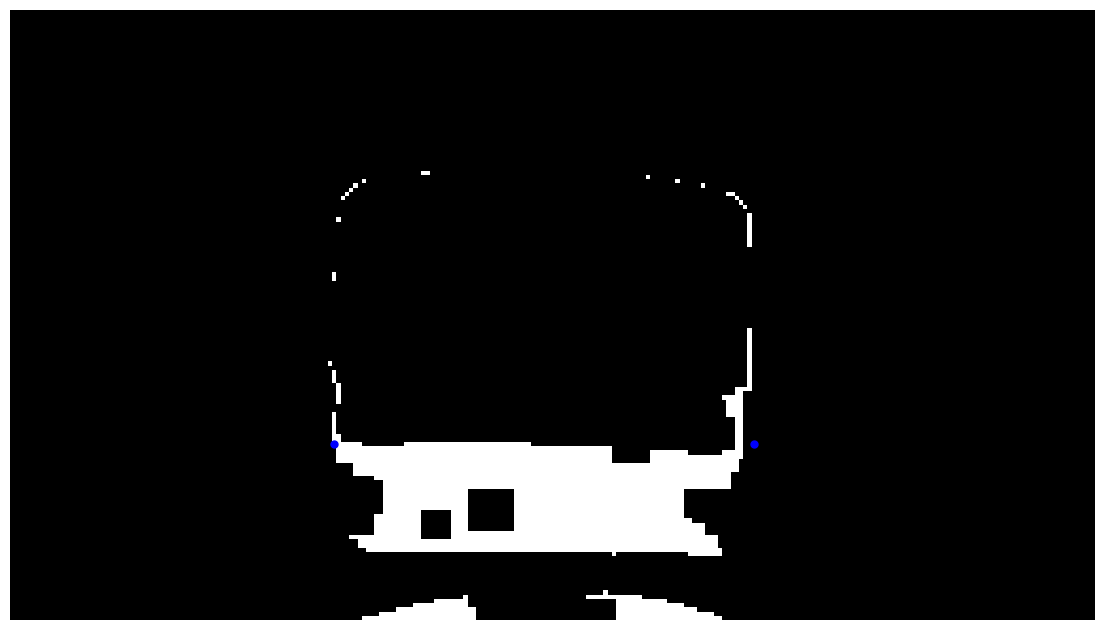

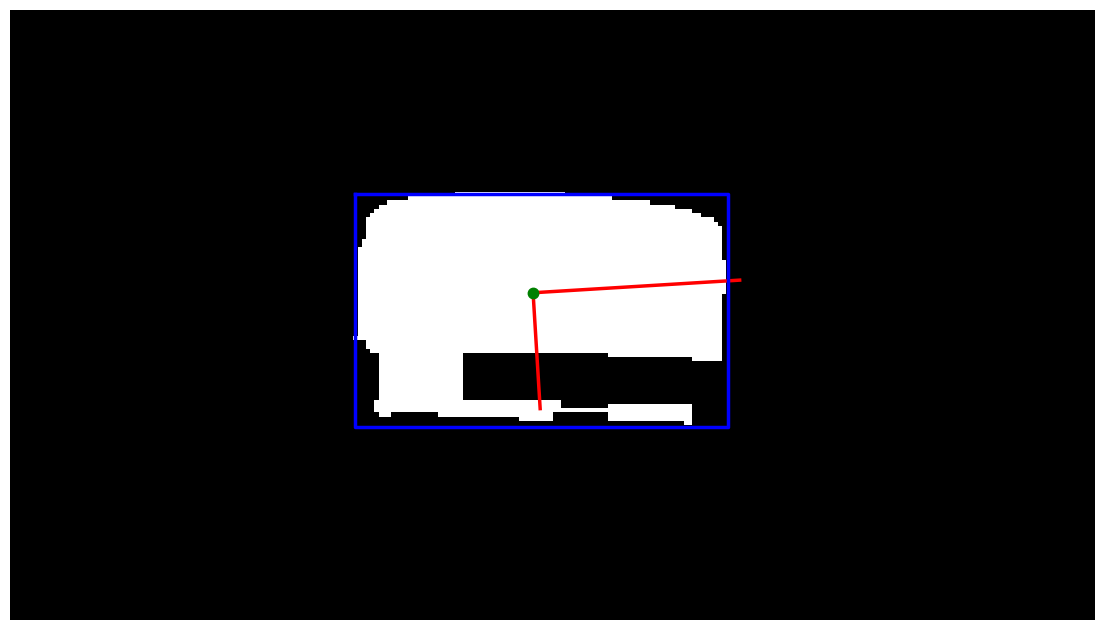

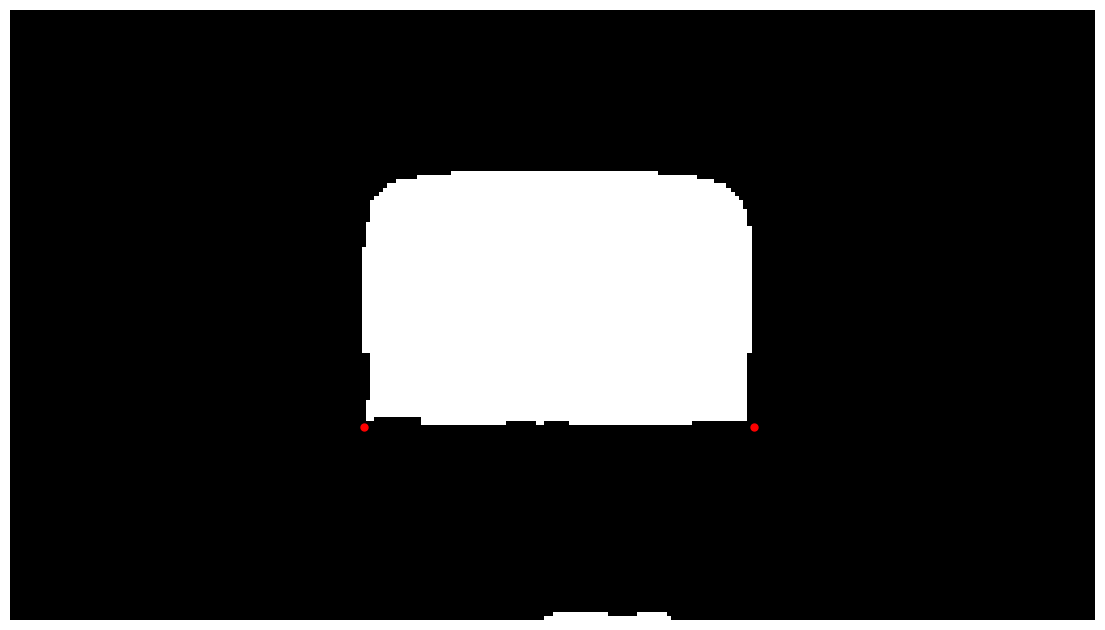

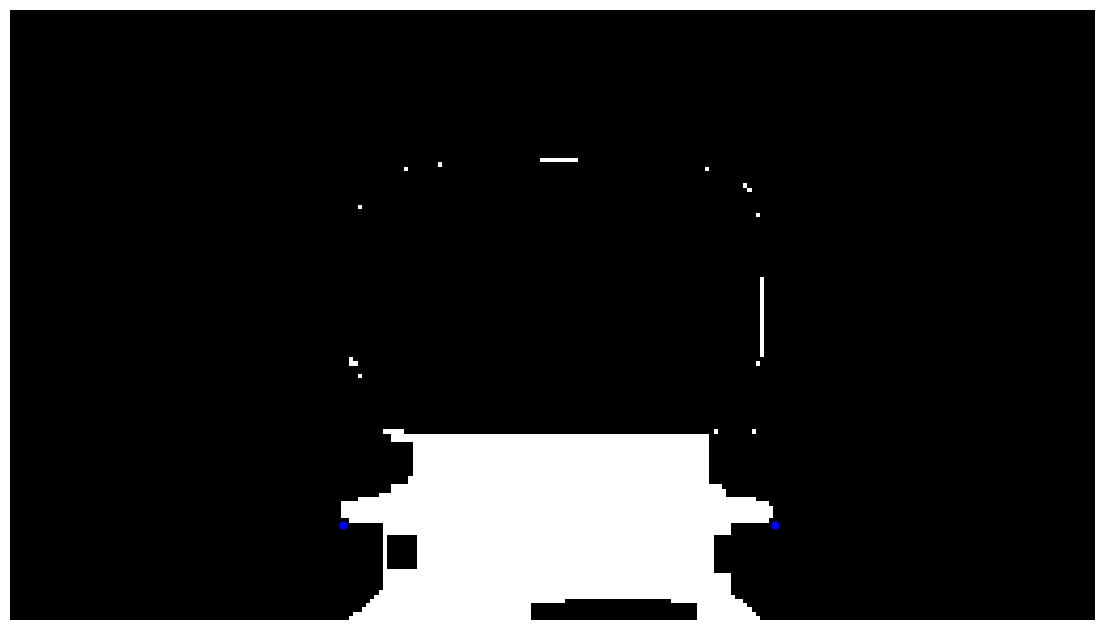

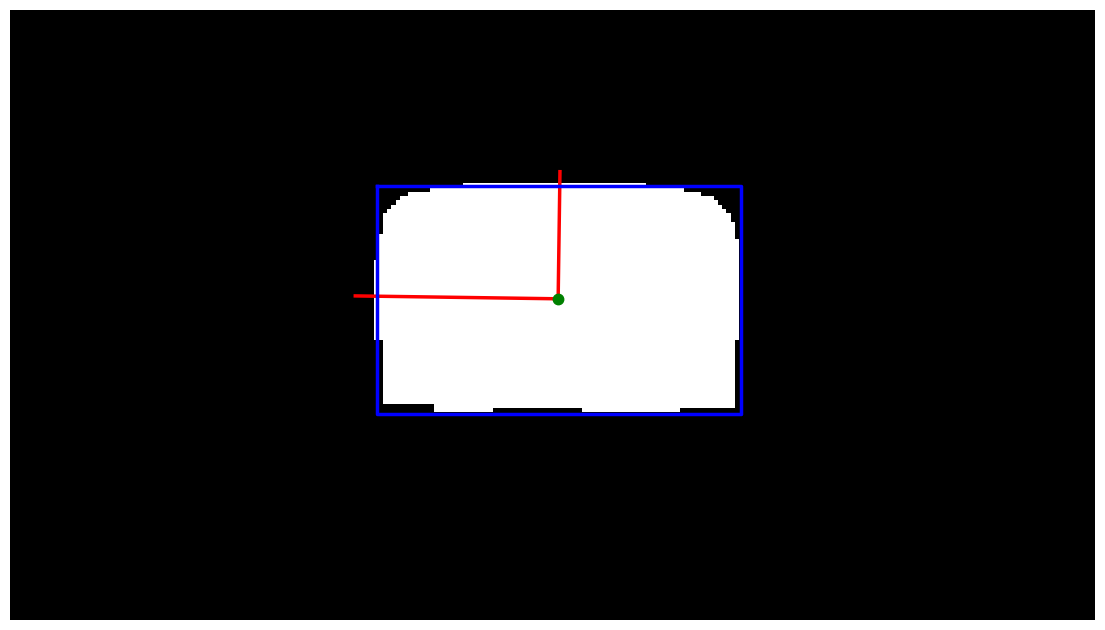

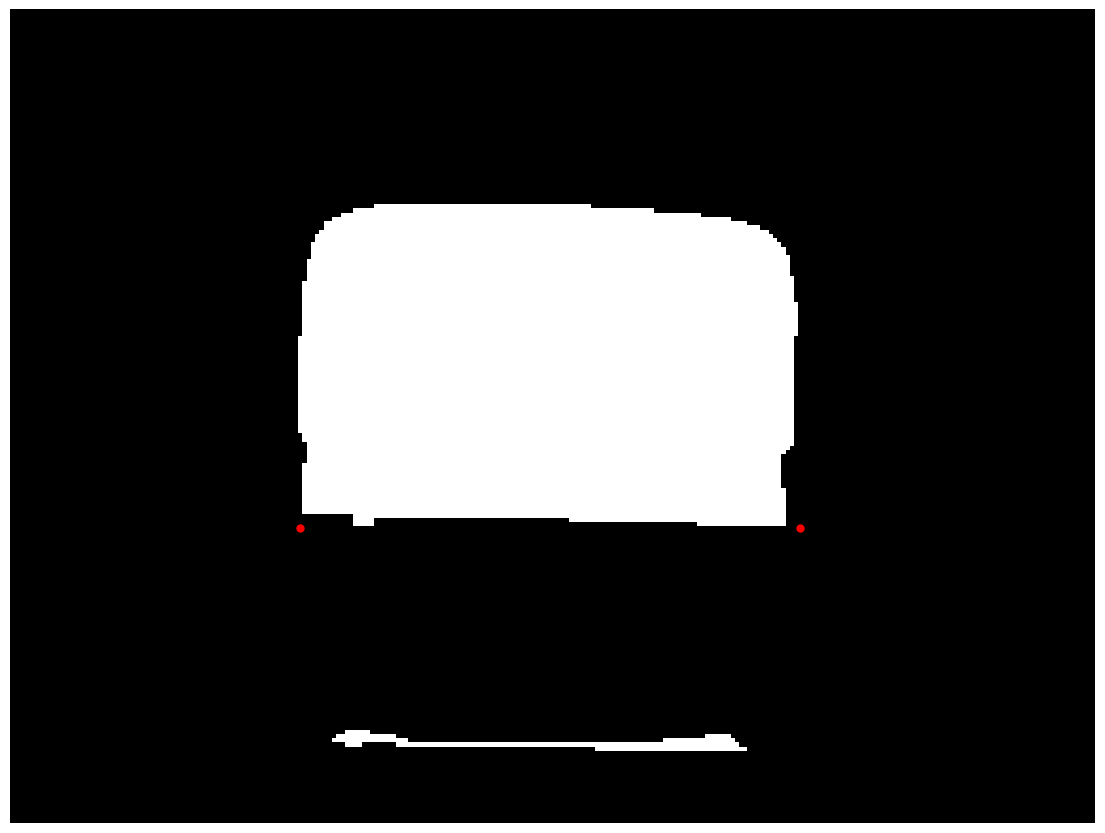

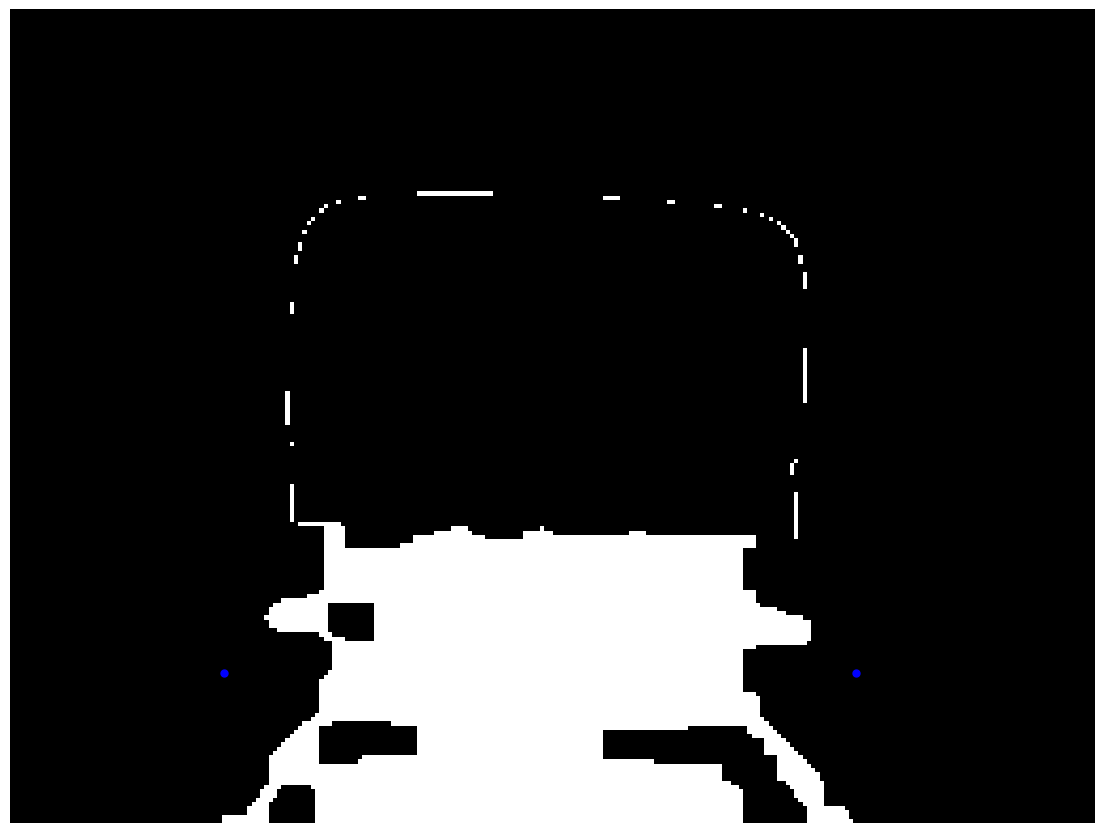

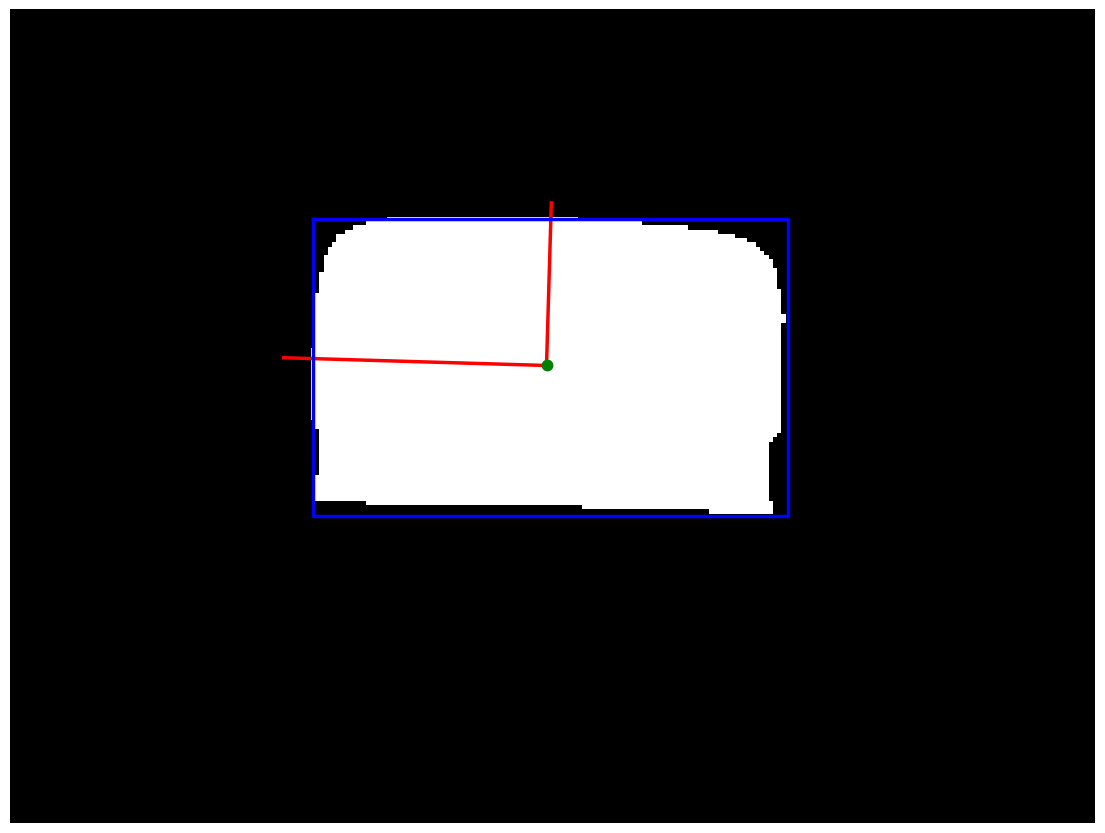

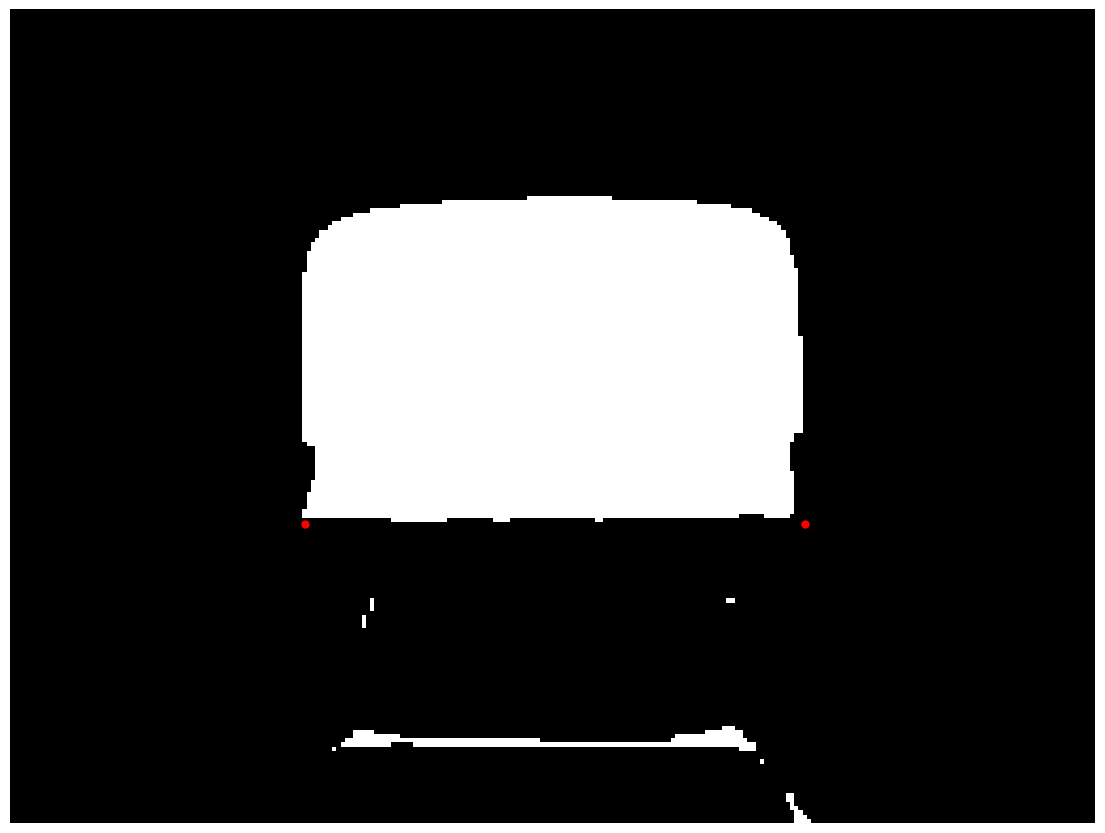

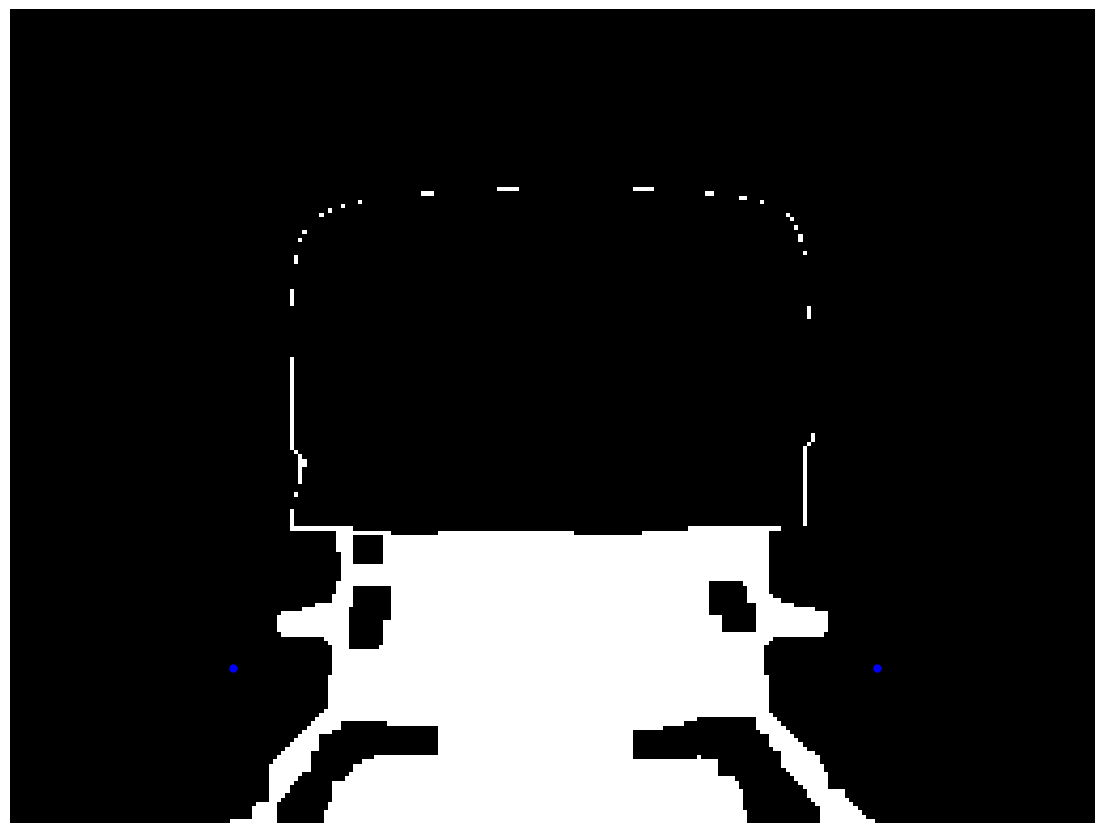

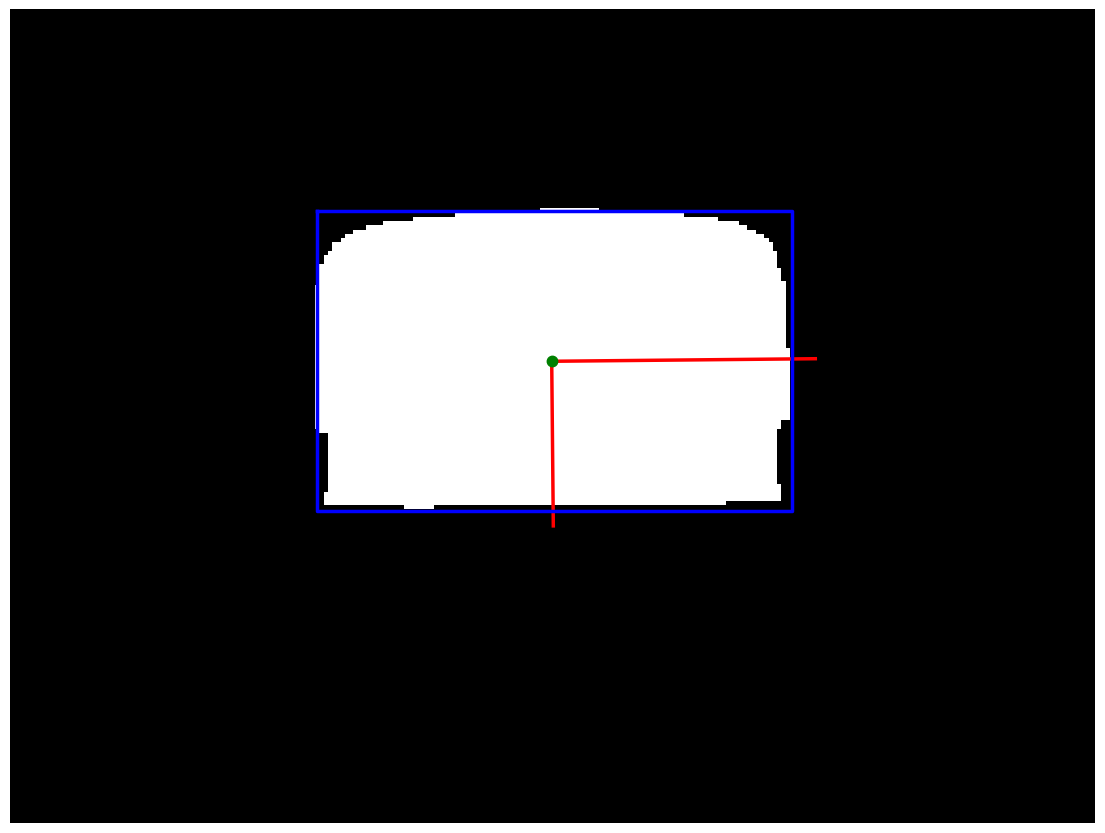

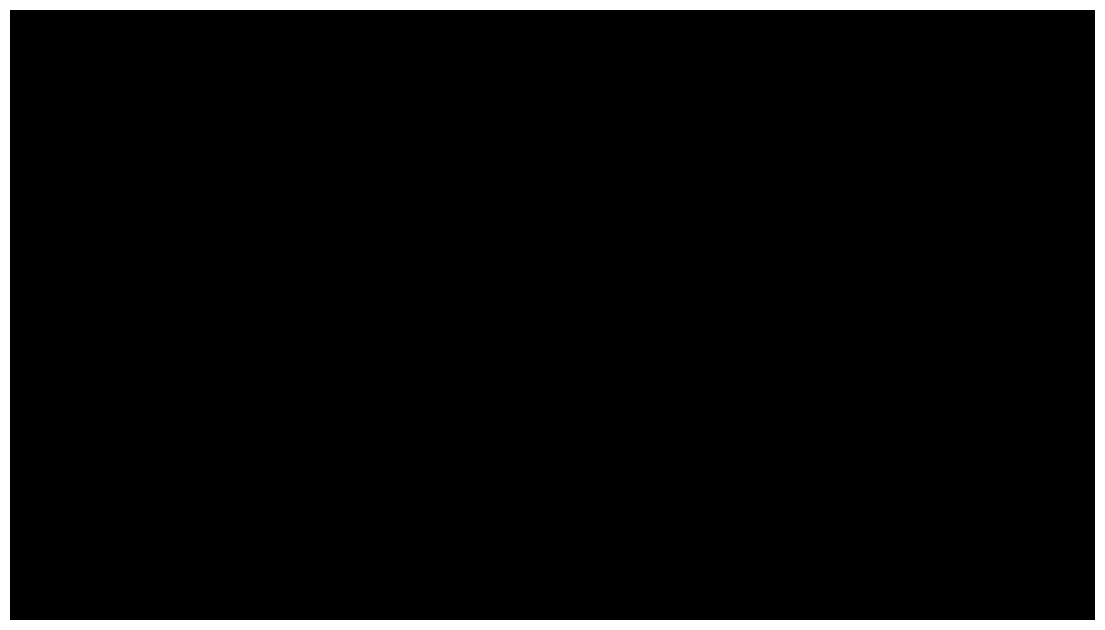

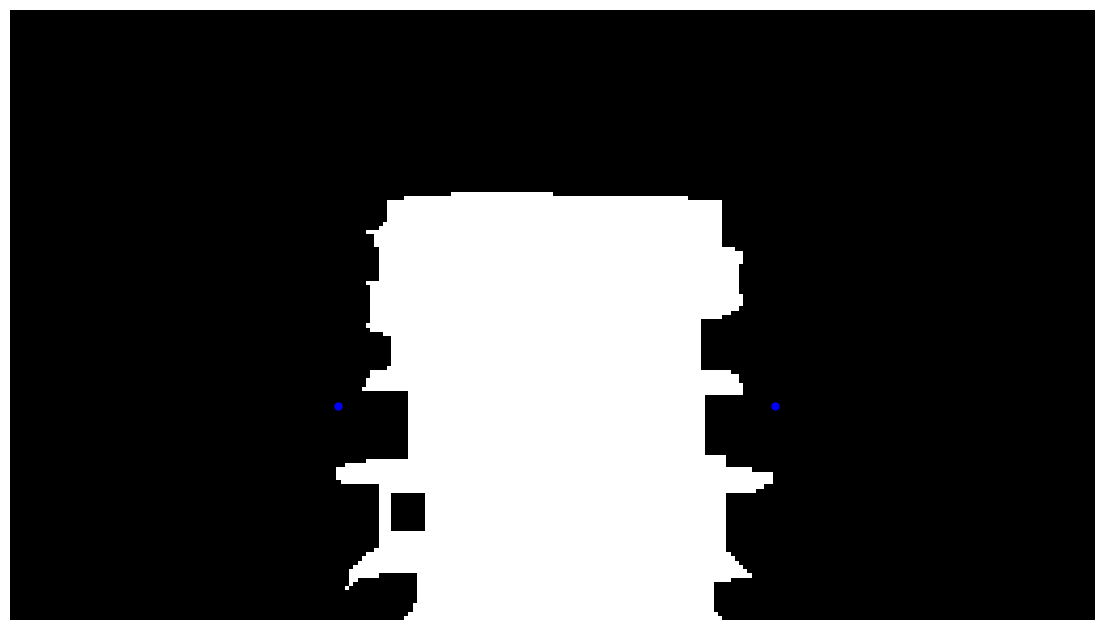

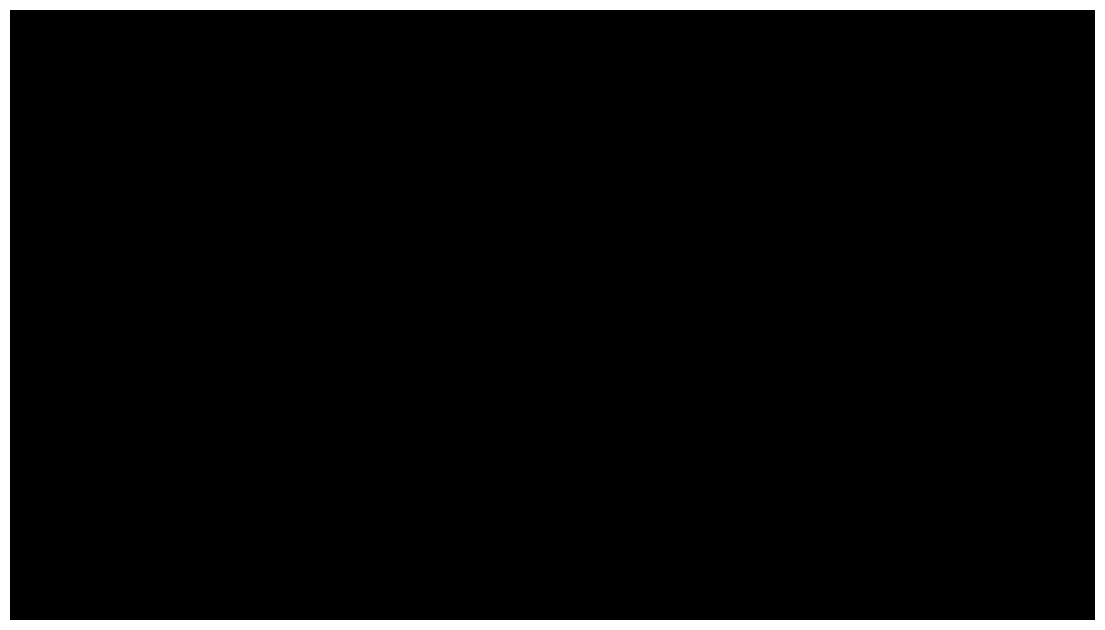

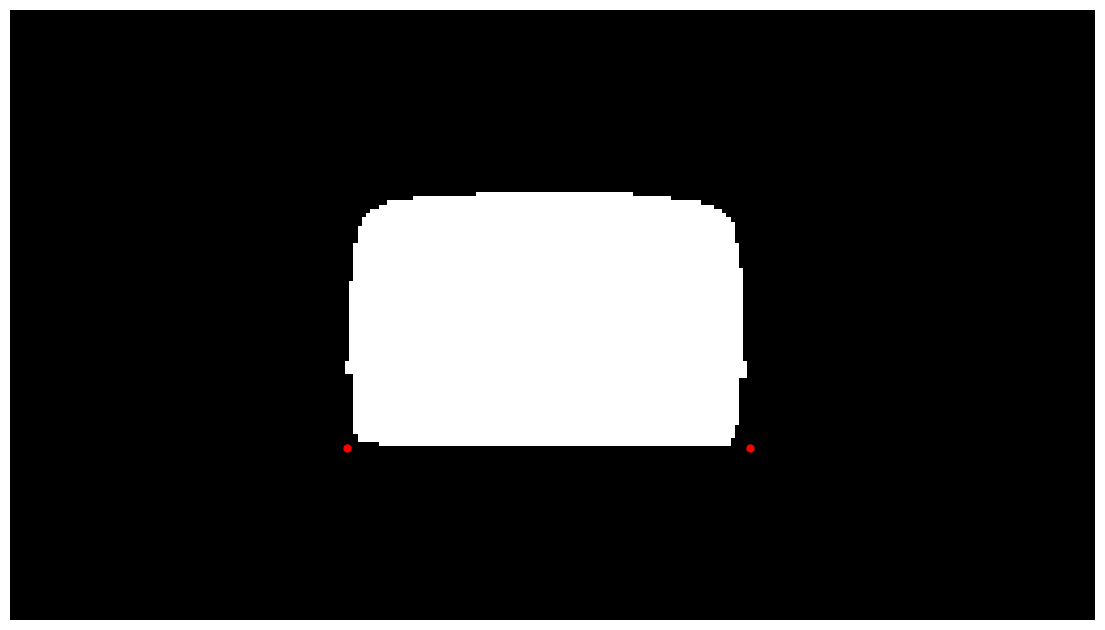

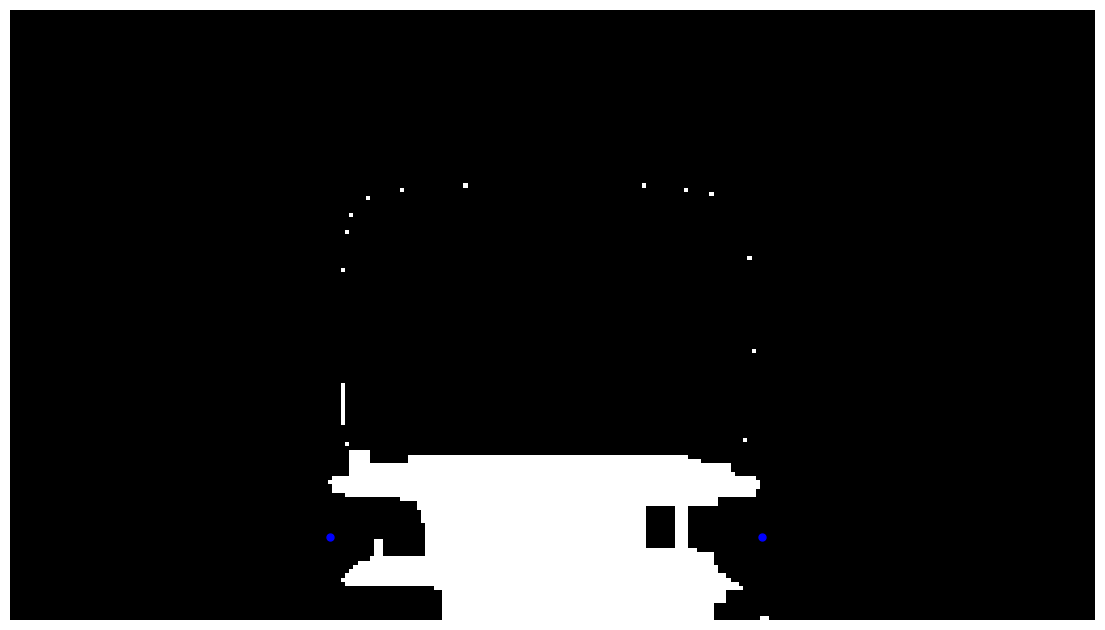

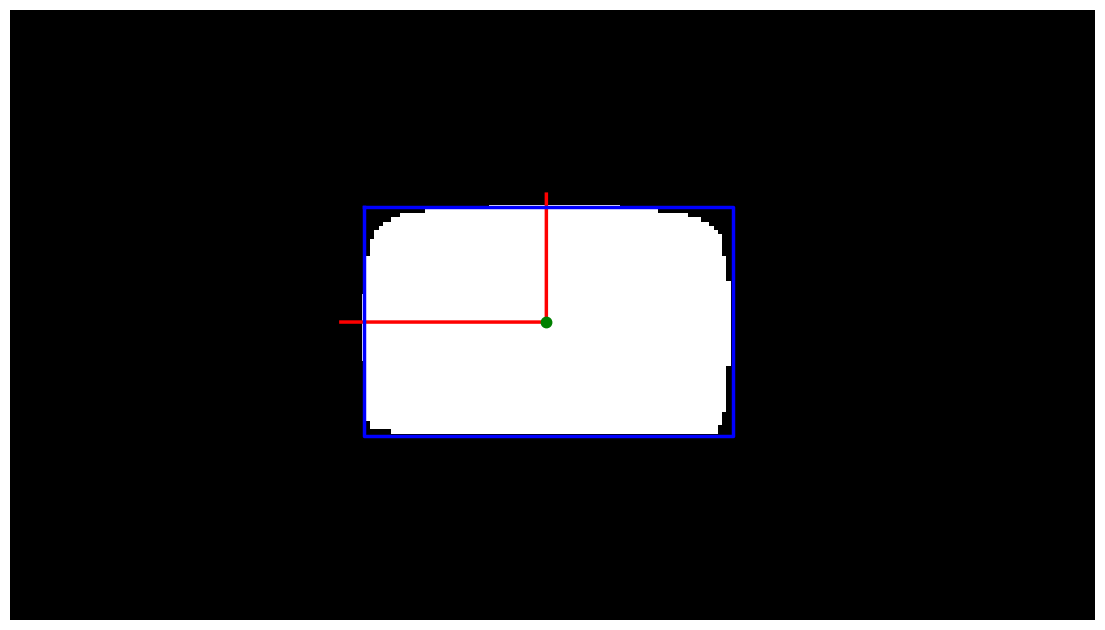

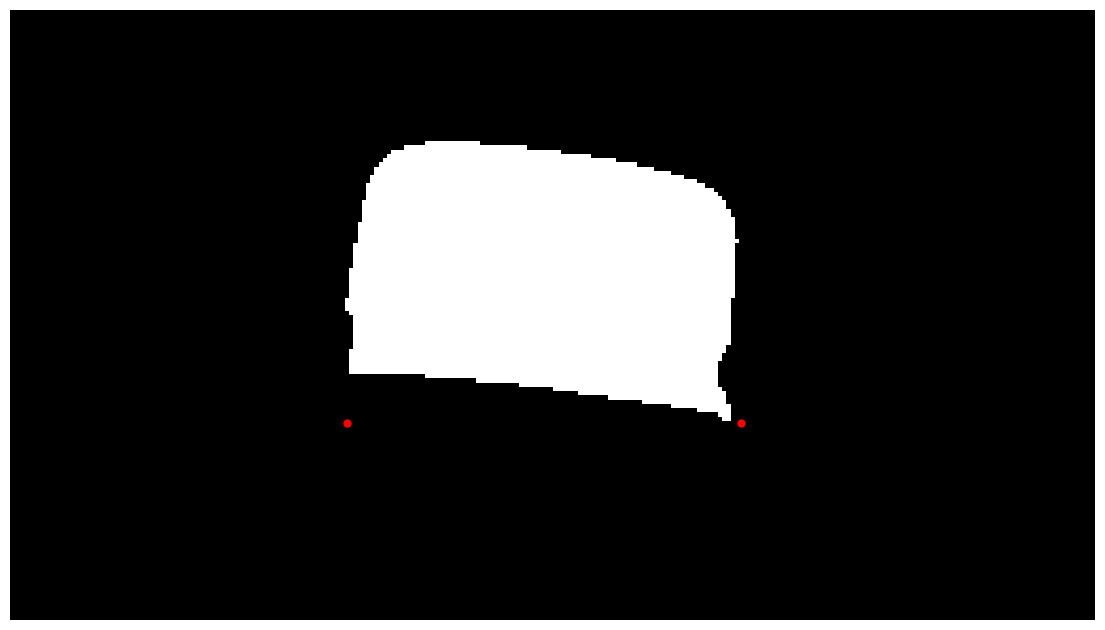

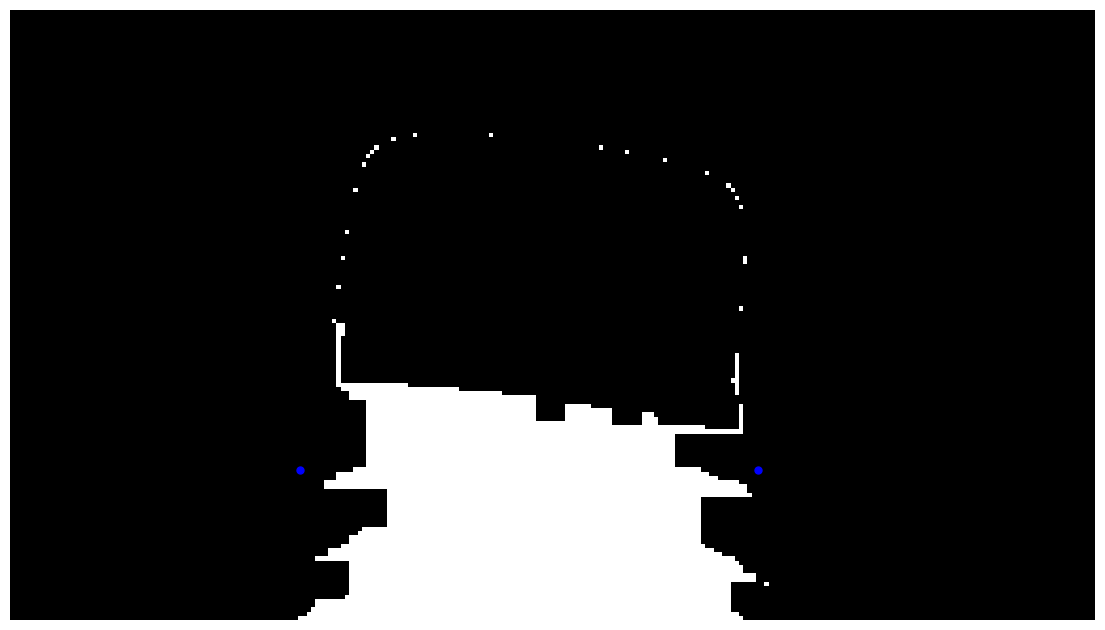

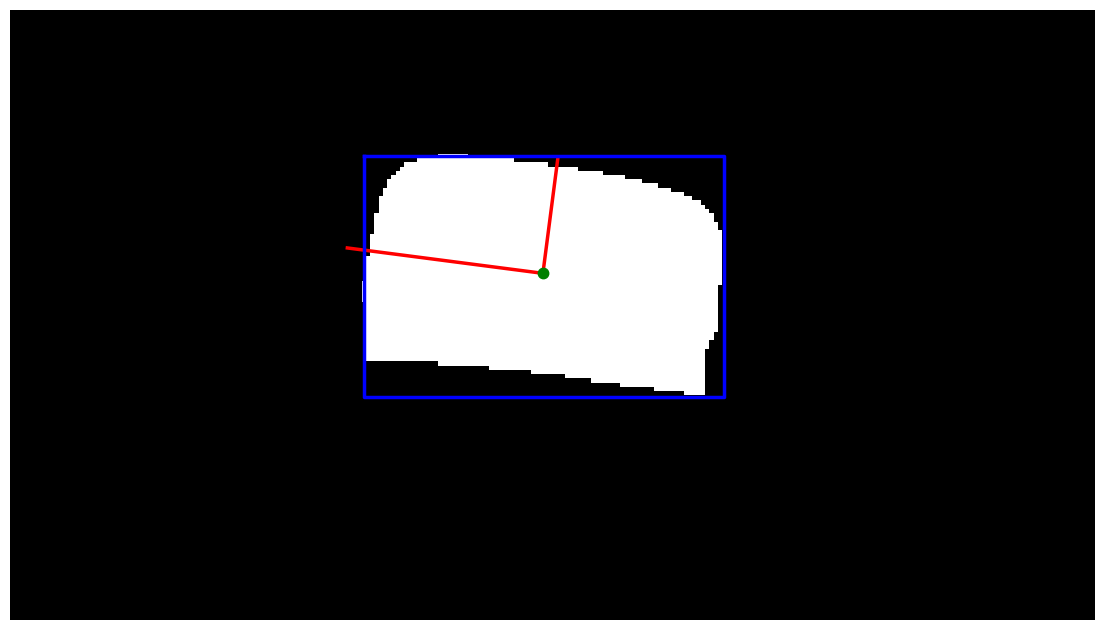

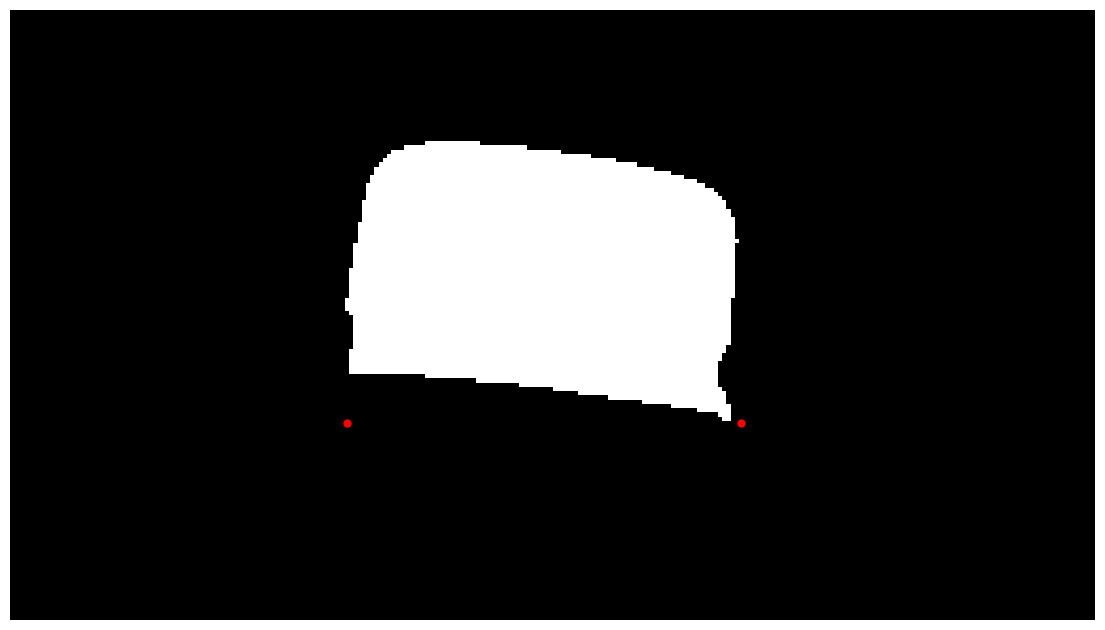

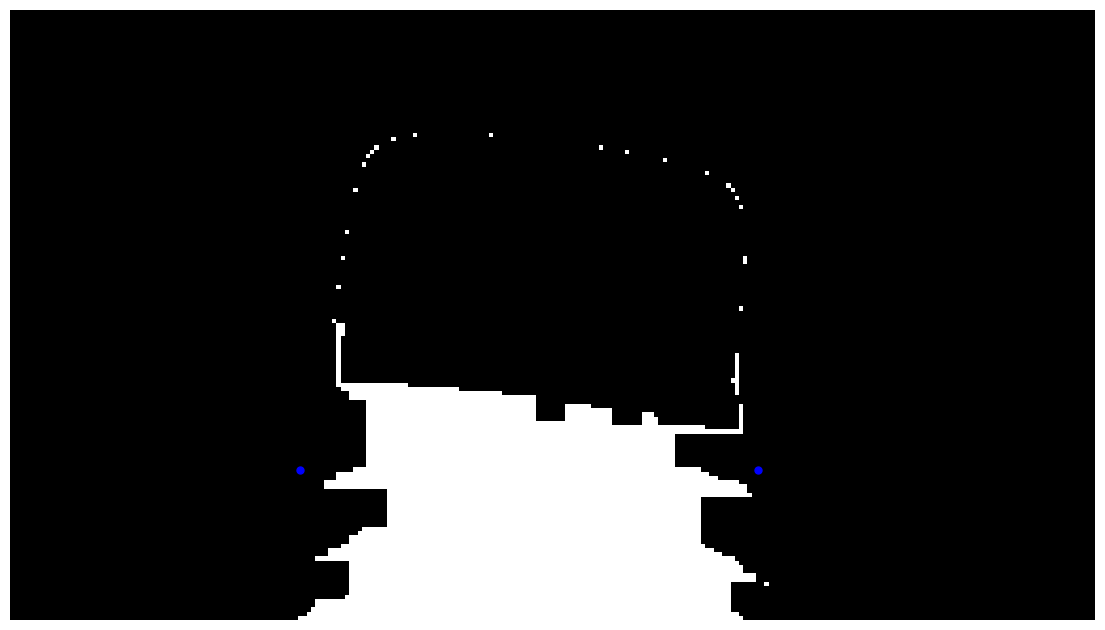

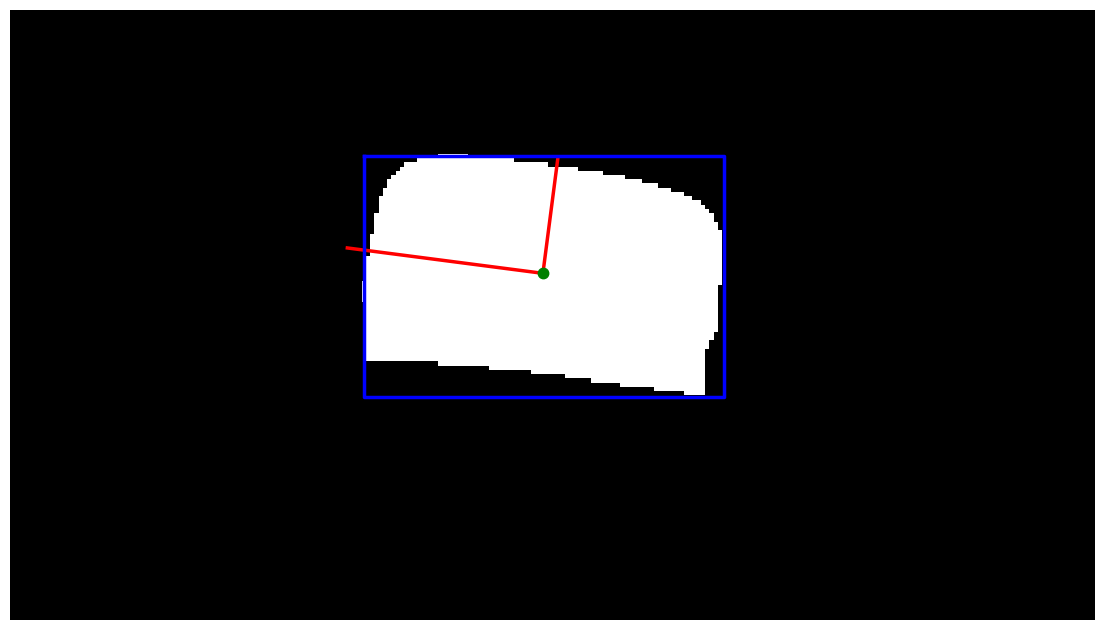

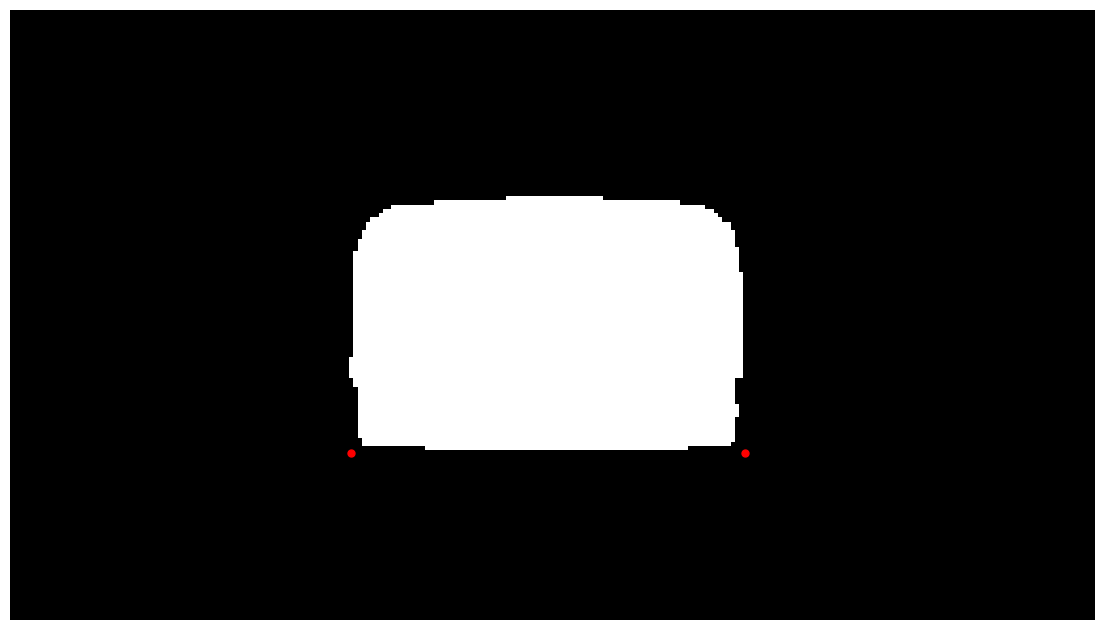

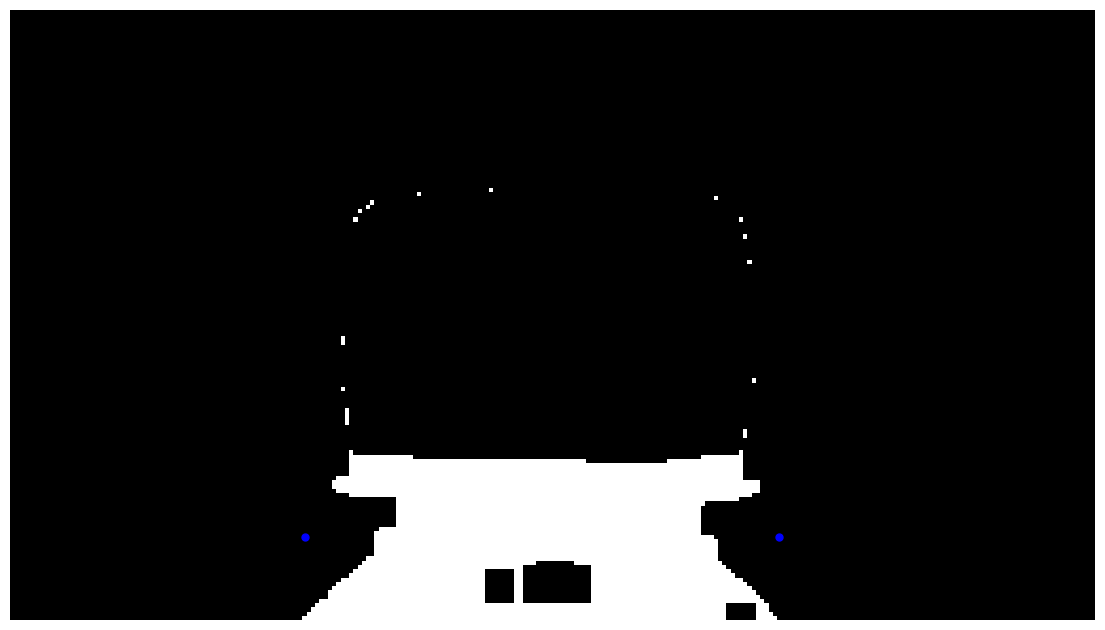

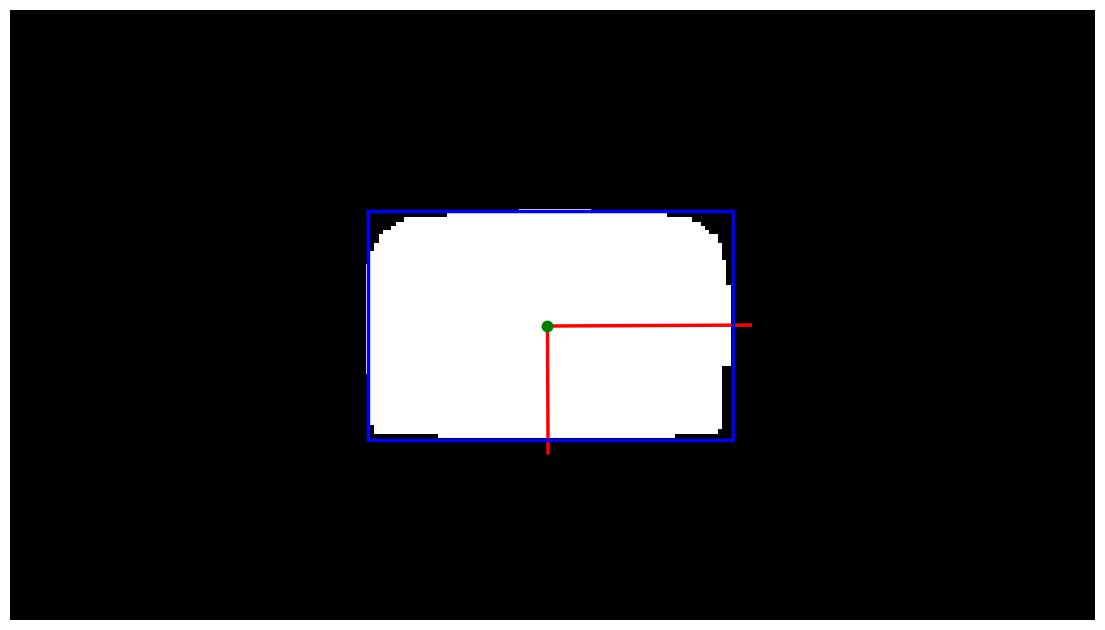

In [19]:
correct_num = 0
for i in test_df.index:
    img = cv.imread(DATA_PATH + "/test/" + test_df['filename'][i])
    detected_image, result = bottlecap_detection(img)
    actual = label_dict[test_df['class'][i]]
    prediction = label_dict[result]
    #image_show(detected_image)
    print("Row: " , i , " Actual: " , actual, " Predicted: ", prediction)
    trues[i] = actual
    predictions[i] = prediction

In [20]:
from sklearn.metrics import classification_report
trues_list = trues.tolist()
predictions_list = predictions.tolist()

labels = ['Good Cap', 'No Cap', 'Loose Cap', 'Broken Cap or Ring']

print(classification_report(trues_list, predictions_list, target_names=labels))

                    precision    recall  f1-score   support

          Good Cap       0.78      0.78      0.78        23
            No Cap       1.00      1.00      1.00        17
         Loose Cap       0.71      0.59      0.64        46
Broken Cap or Ring       0.63      0.76      0.69        38

          accuracy                           0.73       124
         macro avg       0.78      0.78      0.78       124
      weighted avg       0.74      0.73      0.73       124

